# Train Master Dataset

## Final dataset

The training master table has:

- 1,000,000 rows
- 48 columns
- 1,000,000 unique `case_id`
- 0 duplicate `case_id`
- 0 missing target values

All tables were merged using `case_id`.

Depth-0 tables were merged directly.

Depth-1 and depth-2 tables had multiple rows per `case_id`, so they were aggregated first to make one row per `case_id`.

---

## Tables used

### `static_0`

The two files:

```text
train_static_0_0.csv
train_static_0_1.csv
```

were combined with:

```python
df_train_static_0 = pd.concat(
    [df_train_static_0_0, df_train_static_0_1],
    ignore_index=True
)
```

This table already had one row per `case_id`, so it was merged directly.

`birth_259D` was converted to datetime and age was calculated from:

```python
age = (date_decision - birth_259D).dt.days / 365.25
```

---

### `static_cb_0`

This table already had at most one row per `case_id`, so it was merged directly.

A flag was added:

```text
has_cb_history = 1 if the case appeared in static_cb_0
has_cb_history = 0 otherwise
```

---

## `person_1` aggregation

`person_1` had one or two person records per loan.

It was grouped by:

```python
groupby("case_id")
```

The following columns were created:

| New column | Original column | Aggregation |
|---|---|---|
| `person_count` | `num_group1` | count |
| `person_income_sum` | `mainoccupationinc_384A` | sum |
| `person_income_mean` | `mainoccupationinc_384A` | mean |
| `person_income_max` | `mainoccupationinc_384A` | max |
| `employment_mean` | `empl_employedtotal_800L` | mean |
| `employment_max` | `empl_employedtotal_800L` | max |

Code:

```python
person_agg = (
    df_train_person_1
    .groupby("case_id")
    .agg(
        person_count=("num_group1", "count"),
        person_income_sum=("mainoccupationinc_384A", lambda x: x.sum(min_count=1)),
        person_income_mean=("mainoccupationinc_384A", "mean"),
        person_income_max=("mainoccupationinc_384A", "max"),
        employment_mean=("empl_employedtotal_800L", "mean"),
        employment_max=("empl_employedtotal_800L", "max")
    )
    .reset_index()
)
```

---

## `credit_bureau_a_1` + `credit_bureau_a_2` aggregation

The two A1 files:

```text
train_credit_bureau_a_1_0.csv
train_credit_bureau_a_1_1.csv
```

were combined first.

`credit_bureau_a_1` contains one row per historical credit contract.

`credit_bureau_a_2` contains subrecords inside those contracts.

The relationship is:

```text
case_id
  -> num_group1
      -> num_group2
```

`num_group1` identifies the historical contract in both A1 and A2.

`num_group2` identifies the subrecord inside that contract.

### Step 1: A2 subrecords to contract level

A2 was grouped by:

```python
groupby(["case_id", "num_group1"])
```

The following columns were created:

| New column | Original column | Aggregation |
|---|---|---|
| `a2_subrecord_count` | `num_group2` | count |
| `a2_payment_month_min` | `pmts_month_158T` | min |
| `a2_payment_month_max` | `pmts_month_158T` | max |
| `a2_overdue_sum` | `pmts_overdue_1140A` | sum |
| `a2_overdue_max` | `pmts_overdue_1140A` | max |
| `a2_overdue_valid_count` | `pmts_overdue_1140A` | count |

A `has_a2` flag was added to identify A1 contracts with A2 records.

The A2 contract summaries were then merged into A1 using:

```python
["case_id", "num_group1"]
```

This kept one row per historical credit contract.

### Step 2: combined contracts to case level

The combined A1 + A2 contract table was grouped by:

```python
groupby("case_id")
```

The following columns were created:

| New column | Aggregation |
|---|---|
| `bureau_contract_count` | count of historical A1 contracts |
| `bureau_credit_amount_sum` | sum of `credamount_770A` |
| `bureau_credit_amount_mean` | mean of `credamount_770A` |
| `bureau_credit_amount_max` | max of `credamount_770A` |
| `bureau_overdue_amount_max` | max of `overdueamountmax_950A` |
| `bureau_overdue_amount_mean` | mean of `overdueamountmax_950A` |
| `bureau_dpd_max` | max of `pmts_dpdvalue_108P` |
| `bureau_dpd_mean` | mean of `pmts_dpdvalue_108P` |
| `bureau_a2_contract_count` | count of A1 contracts with A2 records |
| `bureau_a2_record_count` | sum of A2 subrecord counts |
| `bureau_payment_month_min` | minimum A2 payment month |
| `bureau_payment_month_max` | maximum A2 payment month |
| `bureau_payment_overdue_sum` | sum of A2 overdue amounts |
| `bureau_payment_overdue_max` | maximum A2 overdue amount |
| `bureau_payment_overdue_mean` | total A2 overdue amount / valid overdue record count |

The final bureau table had:

```text
700,179 unique case_id
0 duplicate case_id
```

and was merged into the master once using `case_id`.

---

## `tax_registry_a_1` aggregation

This table had multiple tax records per loan.

Grouped by:

```python
groupby("case_id")
```

Created:

| New column | Original column | Aggregation |
|---|---|---|
| `tax_record_count` | `num_group1` | count |
| `tax_amount_sum` | `amount_4527230A` | sum |
| `tax_amount_mean` | `amount_4527230A` | mean |
| `tax_amount_max` | `amount_4527230A` | max |

Code:

```python
tax_registry_agg = (
    df_train_tax_registry_a_1
    .groupby("case_id")
    .agg(
        tax_record_count=("num_group1", "count"),
        tax_amount_sum=("amount_4527230A", lambda x: x.sum(min_count=1)),
        tax_amount_mean=("amount_4527230A", "mean"),
        tax_amount_max=("amount_4527230A", "max")
    )
    .reset_index()
)
```

---

## `applprev_1` aggregation

`approvaldate_319D` was converted to datetime first.

The table was grouped by:

```python
groupby("case_id")
```

Created:

| New column | Original column | Aggregation |
|---|---|---|
| `prev_application_count` | `num_group1` | count |
| `prev_credit_amount_sum` | `credamount_590A` | sum |
| `prev_credit_amount_mean` | `credamount_590A` | mean |
| `prev_credit_amount_max` | `credamount_590A` | max |
| `prev_approval_date_min` | `approvaldate_319D` | min |
| `prev_approval_date_max` | `approvaldate_319D` | max |

Code:

```python
applprev_agg = (
    df_train_applprev_1
    .groupby("case_id")
    .agg(
        prev_application_count=("num_group1", "count"),
        prev_credit_amount_sum=("credamount_590A", lambda x: x.sum(min_count=1)),
        prev_credit_amount_mean=("credamount_590A", "mean"),
        prev_credit_amount_max=("credamount_590A", "max"),
        prev_approval_date_min=("approvaldate_319D", "min"),
        prev_approval_date_max=("approvaldate_319D", "max")
    )
    .reset_index()
)
```

---

## Merging

Depth-0 tables were merged directly.

Depth-1 tables were aggregated to one row per `case_id` before merging.

For the credit bureau tables, A2 was first aggregated to the contract level and merged with A1 using:

```python
["case_id", "num_group1"]
```

The combined bureau table was then aggregated to one row per `case_id` and merged into the master once.

Final loan-level tables were merged with:

```python
df_train_master = df_train_master.merge(
    aggregated_table,
    on="case_id",
    how="left",
    validate="one_to_one"
)
```

After every final merge I checked:

```python
print(df_train_master.shape)
print(df_train_master["case_id"].nunique())
print(df_train_master["case_id"].duplicated().sum())
```

Final result:

```text
Shape: (1000000, 48)
Unique case_ids: 1000000
Duplicate case_ids: 0
```

---

# Saving the final master table

## Parquet

Save:

```python
df_train_master.to_parquet(
    "train_master.parquet",
    index=False,
    compression="zstd"
)
```

Open later:

```python
import pandas as pd

df_train_master = pd.read_parquet("train_master.parquet")
```

If needed:

```bash
pip install pyarrow
```

---

## Compressed CSV

Save:

```python
df_train_master.to_csv(
    "train_master.csv.gz",
    index=False,
    compression="gzip"
)
```

Open later:

```python
import pandas as pd

df_train_master = pd.read_csv(
    "train_master.csv.gz",
    parse_dates=[
        "date_decision",
        "birth_259D",
        "prev_approval_date_min",
        "prev_approval_date_max"
    ]
)
```

Use the Parquet file for normal analysis and modeling. Use the compressed CSV if Parquet is not supported.


In [1]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
import time
from scipy import stats

In [2]:
df_train_base = pd.read_csv("csv_files/train/train_base.csv")
df_train_base.head()

,case_id,date_decision,MONTH,WEEK_NUM,target
0,1,2020-04-28,202004,69,0
1,2,2019-08-13,201908,32,0
2,3,2019-01-01,201901,0,1
3,4,2019-08-27,201908,34,1
4,5,2019-03-26,201903,12,0


In [3]:
df_test_base = pd.read_csv("csv_files/test/test_base.csv")
df_test_base.head()

,case_id,date_decision,MONTH,WEEK_NUM
0,1000001,2020-11-03,202011,96
1,1000002,2020-10-27,202010,95
2,1000003,2020-10-06,202010,92
3,1000004,2020-12-15,202012,102
4,1000005,2020-11-17,202011,98


In [4]:
print(f"train base unique:{df_train_base["case_id"].is_unique}")
print(f"test base unique: {df_test_base["case_id"].is_unique}")

print(f"train base na: {df_train_base["case_id"].isna().sum()}")
print(f"test base na: {df_test_base["case_id"].isna().sum()}")

train base unique:True
test base unique: True
train base na: 0
test base na: 0


In [5]:
df_train_master = df_train_base.copy()
df_test_master = df_test_base.copy()

In [6]:
df_train_base.info()

df_train_base.describe(include="all").T

df_train_base.isna().sum().sort_values(ascending=False)

df_train_base.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 5 columns):
 #   Column         Non-Null Count    Dtype 
---  ------         --------------    ----- 
 0   case_id        1000000 non-null  int64 
 1   date_decision  1000000 non-null  object
 2   MONTH          1000000 non-null  int64 
 3   WEEK_NUM       1000000 non-null  int64 
 4   target         1000000 non-null  int64 
dtypes: int64(4), object(1)
memory usage: 38.1+ MB


,case_id,date_decision,MONTH,WEEK_NUM,target
0,1,2020-04-28,202004,69,0
1,2,2019-08-13,201908,32,0
2,3,2019-01-01,201901,0,1
3,4,2019-08-27,201908,34,1
4,5,2019-03-26,201903,12,0


**Turn date_decision to datetime object**

In [7]:
df_train_base["date_decision"] = pd.to_datetime(
    df_train_base["date_decision"],
    errors="coerce"
)
df_train_base.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 5 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   case_id        1000000 non-null  int64         
 1   date_decision  1000000 non-null  datetime64[ns]
 2   MONTH          1000000 non-null  int64         
 3   WEEK_NUM       1000000 non-null  int64         
 4   target         1000000 non-null  int64         
dtypes: datetime64[ns](1), int64(4)
memory usage: 38.1 MB


**Class imbalance**

In [8]:
print(df_train_base["target"].value_counts())
print(df_train_base["target"].value_counts(normalize=True))

target
0    808248
1    191752
Name: count, dtype: int64
target
0    0.808248
1    0.191752
Name: proportion, dtype: float64


In [9]:
df_train_base.isna().sum()

case_id          0
date_decision    0
MONTH            0
WEEK_NUM         0
target           0
dtype: int64

In [10]:
df_train_applprev_1 = pd.read_csv("csv_files/train/train_applprev_1.csv")
df_train_applprev_1

,case_id,num_group1,credamount_590A,approvaldate_319D,status_219L
0,1,0,9636.0,2017-11-11,a2839ee4
1,2,0,29168.0,2016-10-13,a2839ee4
2,2,1,17830.0,2014-03-19,a2839ee4
3,2,2,10069.0,NaN,fa96ae9d
4,2,3,2372.0,NaN,fa96ae9d
...,...,...,...,...,...
1997542,999999,2,6496.0,2016-02-27,dedbd039
1997543,1000000,0,9737.0,2015-07-16,a2839ee4
1997544,1000000,1,4534.0,2016-11-04,fa96ae9d
1997545,1000000,2,4034.0,2013-12-31,fa96ae9d


In [11]:
df_train_applprev_1.info()

df_train_applprev_1.describe(include="all").T

df_train_applprev_1.isna().sum().sort_values(ascending=False)

df_train_applprev_1.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1997547 entries, 0 to 1997546
Data columns (total 5 columns):
 #   Column             Dtype  
---  ------             -----  
 0   case_id            int64  
 1   num_group1         int64  
 2   credamount_590A    float64
 3   approvaldate_319D  object 
 4   status_219L        object 
dtypes: float64(1), int64(2), object(2)
memory usage: 76.2+ MB


,case_id,num_group1,credamount_590A,approvaldate_319D,status_219L
0,1,0,9636.0,2017-11-11,a2839ee4
1,2,0,29168.0,2016-10-13,a2839ee4
2,2,1,17830.0,2014-03-19,a2839ee4
3,2,2,10069.0,NaN,fa96ae9d
4,2,3,2372.0,NaN,fa96ae9d


In [12]:
df_train_credit_bureau_a_1_0 = pd.read_csv("csv_files/train/train_credit_bureau_a_1_0.csv")
df_train_credit_bureau_a_1_0

,case_id,num_group1,credamount_770A,overdueamountmax_950A,pmts_dpdvalue_108P,classificationofcontr_13M
0,2,0,23037.0,353.0,19.0,54ddc605
1,2,1,12386.0,625.0,15.7,d8bf6dd7
2,2,2,13245.0,799.0,11.6,d8bf6dd7
3,2,3,18842.0,25.0,12.9,fe64f125
4,4,0,30141.0,500.0,0.0,fe64f125
...,...,...,...,...,...,...
1578860,999998,5,12023.0,0.0,6.4,ba38dde4
1578861,1000000,0,21842.0,671.0,15.2,54ddc605
1578862,1000000,1,17363.0,0.0,14.4,54ddc605
1578863,1000000,2,27906.0,526.0,27.4,54ddc605


In [13]:
df_train_credit_bureau_a_1_1 = pd.read_csv("csv_files/train/train_credit_bureau_a_1_1.csv")
df_train_credit_bureau_a_1_1

,case_id,num_group1,credamount_770A,overdueamountmax_950A,pmts_dpdvalue_108P,classificationofcontr_13M
0,5,0,49998.0,437.0,18.2,ba38dde4
1,5,1,10922.0,210.0,18.9,ba38dde4
2,7,0,22235.0,NaN,9.8,ba38dde4
3,7,1,13882.0,NaN,4.9,01851564
4,7,2,5459.0,NaN,0.0,01851564
...,...,...,...,...,...,...
1576393,999997,4,14966.0,157.0,0.0,fe64f125
1576394,999997,5,30425.0,742.0,20.9,d8bf6dd7
1576395,999997,6,13796.0,NaN,11.2,d8bf6dd7
1576396,999997,7,14782.0,0.0,0.0,6f5666c7


In [14]:
df_train_credit_bureau_a_2 = pd.read_csv("csv_files/train/train_credit_bureau_a_2.csv")
df_train_credit_bureau_a_2

,case_id,num_group1,num_group2,pmts_month_158T,pmts_overdue_1140A
0,2,0,0,10,NaN
1,2,1,0,7,0.0
2,2,2,0,9,0.0
3,2,2,1,3,NaN
4,2,3,0,6,49.0
...,...,...,...,...,...
4729109,1000000,1,1,6,66.0
4729110,1000000,2,0,3,205.0
4729111,1000000,3,0,1,106.0
4729112,1000000,3,1,12,0.0


In [15]:
df_train_person_1 = pd.read_csv("csv_files/train/train_person_1.csv")
df_train_person_1

,case_id,num_group1,personindex_1023L,mainoccupationinc_384A,empl_employedtotal_800L,housingtype_772M
0,1,0,0,21055.0,97.9,c93f8128
1,1,1,1,12433.0,20.8,97bb64e3
2,2,0,0,22932.0,83.0,a19ac633
3,2,1,1,14960.0,73.1,2339333a
4,3,0,0,21250.0,20.3,c93f8128
...,...,...,...,...,...,...
1500217,999997,1,1,32544.0,68.6,a19ac633
1500218,999998,0,0,13845.0,NaN,39303e4a
1500219,999999,0,0,12074.0,47.4,39303e4a
1500220,1000000,0,0,24714.0,4.9,2339333a


In [16]:
df_train_static_0_0 = pd.read_csv("csv_files/train/train_static_0_0.csv")
df_train_static_0_0

,case_id,mainoccupationinc_384A,credamount_770A,annuity_780A,days_employed_700P,education_927M,maritalstatus_703M,birth_259D
0,2,25386.0,13707.0,725.0,NaN,10795bac,ea6fb4b5,1952-01-27
1,4,31763.0,44528.0,830.0,355.0,6def22f0,e78cb9c0,1962-12-24
2,6,12166.0,9069.0,1071.0,1424.0,242b264b,f62a4fc7,1981-08-12
3,8,15939.0,18323.0,NaN,NaN,6def22f0,f62a4fc7,1967-05-28
4,10,17947.0,19116.0,750.0,493.0,10795bac,ea6fb4b5,1978-09-16
...,...,...,...,...,...,...,...,...
499995,999992,39801.0,7980.0,507.0,1768.0,f937ecaa,f62a4fc7,1981-07-10
499996,999994,47350.0,11182.0,810.0,NaN,f937ecaa,e78cb9c0,1959-11-29
499997,999996,20809.0,14083.0,585.0,206.0,242b264b,b58630a7,1978-09-29
499998,999998,37608.0,10905.0,1839.0,0.0,6def22f0,ea6fb4b5,1959-01-17


In [17]:
df_train_static_0_1 = pd.read_csv("csv_files/train/train_static_0_1.csv")
df_train_static_0_1

,case_id,mainoccupationinc_384A,credamount_770A,annuity_780A,days_employed_700P,education_927M,maritalstatus_703M,birth_259D
0,1,28314.0,16373.0,600.0,1976.0,6def22f0,f62a4fc7,1969-08-15
1,3,57416.0,12676.0,619.0,762.0,242b264b,e78cb9c0,1978-06-07
2,5,11990.0,21065.0,1282.0,0.0,6def22f0,f62a4fc7,1997-03-21
3,7,NaN,16415.0,NaN,NaN,6def22f0,ea6fb4b5,1992-06-21
4,9,13755.0,11738.0,1228.0,646.0,2d4a2bc4,ea6fb4b5,1971-12-05
...,...,...,...,...,...,...,...,...
499995,999991,38771.0,12305.0,836.0,1320.0,6def22f0,b58630a7,1964-10-11
499996,999993,40436.0,9502.0,1487.0,1380.0,10795bac,e78cb9c0,1968-12-08
499997,999995,61774.0,7539.0,2277.0,686.0,242b264b,f62a4fc7,1956-01-30
499998,999997,55614.0,18717.0,1633.0,1396.0,6def22f0,ea6fb4b5,1997-12-22


In [18]:
df_train_static_cb_0 = pd.read_csv("csv_files/train/train_static_cb_0.csv")
df_train_static_cb_0

,case_id,riskassesment_940T,numberofqueries_146L,description_5085714M
0,2,0.5433,1,521190c5
1,4,0.4436,3,34bbcd2a
2,5,0.6290,4,521190c5
3,6,0.6647,4,34bbcd2a
4,7,0.6317,5,4dc79565
...,...,...,...,...
700174,999996,0.6179,6,521190c5
700175,999997,0.4219,1,3802c3d2
700176,999998,0.6298,3,3802c3d2
700177,999999,0.4443,4,4dc79565


In [19]:
df_train_tax_registry_a_1 = pd.read_csv("csv_files/train/train_tax_registry_a_1.csv")
df_train_tax_registry_a_1

,case_id,num_group1,amount_4527230A,name_4527232M
0,1,0,25002.0,5fd4af02
1,1,1,27314.0,2e8792b8
2,1,2,22433.0,43036c45
3,2,0,20724.0,43036c45
4,2,1,14080.0,22eca1b4
...,...,...,...,...
1499781,999999,1,22494.0,5fd4af02
1499782,999999,2,25873.0,2e8792b8
1499783,1000000,0,10743.0,69c767ed
1499784,1000000,1,19670.0,e4848b42


### Processing train static

checking columns if they match

In [20]:
print(df_train_static_0_0.shape)
print(df_train_static_0_1.shape)

print(
    df_train_static_0_0.columns.equals(
        df_train_static_0_1.columns
    )
)

(500000, 8)
(500000, 8)
True


In [21]:
df_train_static_0 = pd.concat(
    [df_train_static_0_0, df_train_static_0_1],
    ignore_index=True
)

print(df_train_static_0.shape)

(1000000, 8)


In [22]:
print("Rows:", len(df_train_static_0))

print(
    "Unique case IDs:",
    df_train_static_0["case_id"].nunique()
)

print(
    "Duplicate case IDs:",
    df_train_static_0["case_id"].duplicated().sum()
)

print(
    "Missing case IDs:",
    df_train_static_0["case_id"].isna().sum()
)

Rows: 1000000
Unique case IDs: 1000000
Duplicate case IDs: 0
Missing case IDs: 0


In [23]:
df_train_static_0.info()

df_train_static_0.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 8 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   case_id                 1000000 non-null  int64  
 1   mainoccupationinc_384A  950349 non-null   float64
 2   credamount_770A         980041 non-null   float64
 3   annuity_780A            900323 non-null   float64
 4   days_employed_700P      849429 non-null   float64
 5   education_927M          1000000 non-null  object 
 6   maritalstatus_703M      1000000 non-null  object 
 7   birth_259D              1000000 non-null  object 
dtypes: float64(4), int64(1), object(3)
memory usage: 61.0+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
case_id,1000000.0,NaN,NaN,NaN,500000.5,288675.278933,1.0,250000.75,500000.5,750000.25,1000000.0
mainoccupationinc_384A,950349.0,NaN,NaN,NaN,24477.415393,11911.971994,2515.0,16139.0,22021.0,30008.0,174473.0
credamount_770A,980041.0,NaN,NaN,NaN,16730.809971,8932.87458,1447.0,10527.0,14760.0,20693.0,150395.0
annuity_780A,900323.0,NaN,NaN,NaN,1242.750132,661.880406,79.0,782.0,1097.0,1538.0,12069.0
days_employed_700P,849429.0,NaN,NaN,NaN,1524.346248,902.202133,0.0,861.0,1502.0,2141.0,5852.0
education_927M,1000000,5,6def22f0,279658,NaN,NaN,NaN,NaN,NaN,NaN,NaN
maritalstatus_703M,1000000,4,e78cb9c0,250588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
birth_259D,1000000,17885,1988-07-07,89,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
(
    df_train_static_0
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

days_employed_700P        15.0571
annuity_780A               9.9677
mainoccupationinc_384A     4.9651
credamount_770A            1.9959
case_id                    0.0000
education_927M             0.0000
maritalstatus_703M         0.0000
birth_259D                 0.0000
dtype: float64

In [25]:
df_train_static_0[
    [
        "mainoccupationinc_384A",
        "credamount_770A",
        "annuity_780A",
        "days_employed_700P"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
mainoccupationinc_384A,950349.0,24477.415393,11911.971994,2515.0,16139.0,22021.0,30008.0,174473.0
credamount_770A,980041.0,16730.809971,8932.874580,1447.0,10527.0,14760.0,20693.0,150395.0
annuity_780A,900323.0,1242.750132,661.880406,79.0,782.0,1097.0,1538.0,12069.0
days_employed_700P,849429.0,1524.346248,902.202133,0.0,861.0,1502.0,2141.0,5852.0


In [26]:
df_train_static_0["birth_259D"] = pd.to_datetime(
    df_train_static_0["birth_259D"],
    errors="coerce"
)
df_train_static_0.info()
df_train_static_0["birth_259D"].describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 8 columns):
 #   Column                  Non-Null Count    Dtype         
---  ------                  --------------    -----         
 0   case_id                 1000000 non-null  int64         
 1   mainoccupationinc_384A  950349 non-null   float64       
 2   credamount_770A         980041 non-null   float64       
 3   annuity_780A            900323 non-null   float64       
 4   days_employed_700P      849429 non-null   float64       
 5   education_927M          1000000 non-null  object        
 6   maritalstatus_703M      1000000 non-null  object        
 7   birth_259D              1000000 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(4), int64(1), object(2)
memory usage: 61.0+ MB


count                          1000000
mean     1973-07-28 09:53:57.235199920
min                1949-01-19 00:00:00
25%                1961-04-30 00:00:00
50%                1973-08-07 00:00:00
75%                1985-10-24 00:00:00
max                1998-01-06 00:00:00
Name: birth_259D, dtype: object

### Merge train_static_0 to base and calculate age

In [27]:
df_train_master = df_train_base.merge(
    df_train_static_0,
    on="case_id",
    how="left",
    validate="one_to_one"
)

df_train_master["age"] = (
    (
        df_train_master["date_decision"]
        - df_train_master["birth_259D"]
    ).dt.days / 365.25
)
df_train_master["age"].describe()

count    1000000.000000
mean          46.300015
std           14.140597
min           20.991102
25%           34.058864
50%           46.280630
75%           58.543463
max           71.693361
Name: age, dtype: float64

In [28]:
df_train_master.columns


Index(['case_id', 'date_decision', 'MONTH', 'WEEK_NUM', 'target',
       'mainoccupationinc_384A', 'credamount_770A', 'annuity_780A',
       'days_employed_700P', 'education_927M', 'maritalstatus_703M',
       'birth_259D', 'age'],
      dtype='object')

In [29]:
print("Base:", df_train_base.shape)
print("Static:", df_train_static_0.shape)
print("Master:", df_train_master.shape)

Base: (1000000, 5)
Static: (1000000, 8)
Master: (1000000, 13)


### Processing static_cb

In [30]:
df_train_static_cb_0.info()

df_train_static_cb_0.head()

df_train_static_cb_0.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700179 entries, 0 to 700178
Data columns (total 4 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   case_id               700179 non-null  int64  
 1   riskassesment_940T    665035 non-null  float64
 2   numberofqueries_146L  700179 non-null  int64  
 3   description_5085714M  700179 non-null  object 
dtypes: float64(1), int64(2), object(1)
memory usage: 21.4+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
case_id,700179.0,NaN,NaN,NaN,500280.236298,288749.186706,2.0,250286.5,500281.0,750299.0,1000000.0
riskassesment_940T,665035.0,NaN,NaN,NaN,0.49977,0.208339,0.0102,0.3373,0.4996,0.6624,0.9939
numberofqueries_146L,700179.0,NaN,NaN,NaN,2.997915,1.998898,0.0,2.0,3.0,4.0,18.0
description_5085714M,700179,6,521190c5,142981,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
print("Rows:", len(df_train_static_cb_0))
print("Unique case_ids:", df_train_static_cb_0["case_id"].nunique())
print("Duplicate case_ids:", df_train_static_cb_0["case_id"].duplicated().sum())
print("Missing case_ids:", df_train_static_cb_0["case_id"].isna().sum())

Rows: 700179
Unique case_ids: 700179
Duplicate case_ids: 0
Missing case_ids: 0


#### Adding indicator having credit history

In [32]:
df_train_static_cb_0["has_cb_history"] = 1

In [33]:
# merging to base on left to keep all records
df_train_master = df_train_master.merge(
    df_train_static_cb_0,
    on="case_id",
    how="left",
    validate="one_to_one"
)

In [34]:
df_train_master["has_cb_history"] = (
    df_train_master["has_cb_history"]
    .fillna(0)
    .astype(int)
)

In [35]:
print(df_train_master.shape)

print(
    "Unique case_ids:",
    df_train_master["case_id"].nunique()
)

print(
    "Duplicate case_ids:",
    df_train_master["case_id"].duplicated().sum()
)

print(
    df_train_master["has_cb_history"].value_counts()
)

(1000000, 17)
Unique case_ids: 1000000
Duplicate case_ids: 0
has_cb_history
1    700179
0    299821
Name: count, dtype: int64


#### Processing person_1

In [36]:
df_train_person_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500222 entries, 0 to 1500221
Data columns (total 6 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   case_id                  1500222 non-null  int64  
 1   num_group1               1500222 non-null  int64  
 2   personindex_1023L        1500222 non-null  int64  
 3   mainoccupationinc_384A   1425252 non-null  float64
 4   empl_employedtotal_800L  1200496 non-null  float64
 5   housingtype_772M         1500222 non-null  object 
dtypes: float64(2), int64(3), object(1)
memory usage: 68.7+ MB


In [37]:
print("Rows:", len(df_train_person_1))
print("Unique loans:", df_train_person_1["case_id"].nunique())

print("\nPeople per loan:")
print(
    df_train_person_1
    .groupby("case_id")
    .size()
    .describe()
)

Rows: 1500222
Unique loans: 1000000

People per loan:
count    1000000.000000
mean           1.500222
std            0.500000
min            1.000000
25%            1.000000
50%            2.000000
75%            2.000000
max            2.000000
dtype: float64


In [38]:
df_train_person_1.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
case_id,1500222.0,NaN,NaN,NaN,499763.945335,288676.024603,1.0,249774.25,499571.5,749728.75,1000000.0
num_group1,1500222.0,NaN,NaN,NaN,0.333432,0.47144,0.0,0.0,0.0,1.0,1.0
personindex_1023L,1500222.0,NaN,NaN,NaN,0.333432,0.47144,0.0,0.0,0.0,1.0,1.0
mainoccupationinc_384A,1425252.0,NaN,NaN,NaN,24493.411409,11909.837703,2667.0,16130.0,22030.0,30075.25,203989.0
empl_employedtotal_800L,1200496.0,NaN,NaN,NaN,60.307721,30.340772,0.0,39.0,60.0,81.0,213.6
housingtype_772M,1500222,5,97bb64e3,300384,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [39]:
df_train_person_1["num_group1"].value_counts().sort_index()

num_group1
0    1000000
1     500222
Name: count, dtype: int64

In [40]:
people_per_loan = (
    df_train_person_1
    .groupby("case_id")
    .size()
)

people_per_loan.value_counts().sort_index()

1    499778
2    500222
Name: count, dtype: int64

In [41]:
def sum_min_count(x):
    """function only sums if there is at least 1 non null value"""
    return x.sum(min_count=1)

person_agg = (
    df_train_person_1
    .groupby("case_id")
    .agg(
        person_count=("num_group1", "count"),

        person_income_sum=("mainoccupationinc_384A", sum_min_count), #to maintain missing value
        person_income_mean=("mainoccupationinc_384A", "mean"),
        person_income_max=("mainoccupationinc_384A", "max"),

        employment_mean=("empl_employedtotal_800L", "mean"),
        employment_max=("empl_employedtotal_800L", "max")
    )
    .reset_index()
)

In [42]:
person_agg.shape

(1000000, 7)

In [43]:
person_agg["case_id"].is_unique


True

In [44]:
df_train_master = df_train_master.merge(
    person_agg,
    on="case_id",
    how="left",
    validate="one_to_one"
)

In [45]:
print("Shape:", df_train_master.shape)
print("Unique case_ids:", df_train_master["case_id"].nunique())
print("Duplicate case_ids:", df_train_master["case_id"].duplicated().sum())

Shape: (1000000, 23)
Unique case_ids: 1000000
Duplicate case_ids: 0


### Processing Credit Bureau A 1

In [46]:
# Combine Credit Bureau A1 file partitions
df_train_credit_bureau_a_1 = pd.concat(
    [
        df_train_credit_bureau_a_1_0,
        df_train_credit_bureau_a_1_1
    ],
    ignore_index=True
)

# Helper function:
# preserves NaN if every value in a group is missing
def sum_min_count(x):
    return x.sum(min_count=1)


# --------------------------------------------------
# Aggregate A2 from subrecord level to contract level
# --------------------------------------------------

a2_contract_agg = (
    df_train_credit_bureau_a_2
    .groupby(["case_id", "num_group1"])
    .agg(
        # Number of A2 subrecords inside the contract
        a2_subrecord_count=(
            "num_group2",
            "count"
        ),

        # Range of payment-month values
        a2_payment_month_min=(
            "pmts_month_158T",
            "min"
        ),
        a2_payment_month_max=(
            "pmts_month_158T",
            "max"
        ),

        # Overdue-payment summaries
        a2_overdue_sum=(
            "pmts_overdue_1140A",
            sum_min_count
        ),
        a2_overdue_max=(
            "pmts_overdue_1140A",
            "max"
        ),

        # Used later to calculate the overall mean correctly
        a2_overdue_valid_count=(
            "pmts_overdue_1140A",
            "count"
        )
    )
    .reset_index()
)

# Marks contracts that actually have A2 data
a2_contract_agg["has_a2"] = 1


# --------------------------------------------------
# Merge A2 summaries onto the matching A1 contract
# --------------------------------------------------

bureau_contracts = (
    df_train_credit_bureau_a_1
    .merge(
        a2_contract_agg,
        on=["case_id", "num_group1"],
        how="left",
        validate="one_to_one"
    )
)

# An A1 contract with no matching A2 records gets has_a2 = 0
bureau_contracts["has_a2"] = (
    bureau_contracts["has_a2"]
    .fillna(0)
    .astype(int)
)

In [47]:
print("A1 rows:", len(df_train_credit_bureau_a_1))

print(
    "Duplicate A1 contract keys:",
    df_train_credit_bureau_a_1
    .duplicated(["case_id", "num_group1"])
    .sum()
)

print(
    "\nA2 contract-level rows:",
    len(a2_contract_agg)
)

print(
    "Duplicate A2 contract keys:",
    a2_contract_agg
    .duplicated(["case_id", "num_group1"])
    .sum()
)

print(
    "\nCombined bureau contract rows:",
    len(bureau_contracts)
)

print(
    "Duplicate combined contract keys:",
    bureau_contracts
    .duplicated(["case_id", "num_group1"])
    .sum()
)

print("\nContracts with / without A2:")
print(
    bureau_contracts["has_a2"]
    .value_counts()
)

A1 rows: 3155263
Duplicate A1 contract keys: 0

A2 contract-level rows: 2365429
Duplicate A2 contract keys: 0

Combined bureau contract rows: 3155263
Duplicate combined contract keys: 0

Contracts with / without A2:
has_a2
1    2365429
0     789834
Name: count, dtype: int64


In [48]:
# --------------------------------------------------
# Aggregate combined bureau contracts to case_id
# --------------------------------------------------

bureau_case_agg = (
    bureau_contracts
    .groupby("case_id")
    .agg(
        # A1: number of historical contracts
        bureau_contract_count=(
            "num_group1",
            "count"
        ),

        # A1: historical credit amounts
        bureau_credit_amount_sum=(
            "credamount_770A",
            sum_min_count
        ),
        bureau_credit_amount_mean=(
            "credamount_770A",
            "mean"
        ),
        bureau_credit_amount_max=(
            "credamount_770A",
            "max"
        ),

        # A1: overdue history
        bureau_overdue_amount_max=(
            "overdueamountmax_950A",
            "max"
        ),
        bureau_overdue_amount_mean=(
            "overdueamountmax_950A",
            "mean"
        ),

        # A1: days-past-due history
        bureau_dpd_max=(
            "pmts_dpdvalue_108P",
            "max"
        ),
        bureau_dpd_mean=(
            "pmts_dpdvalue_108P",
            "mean"
        ),

        # A2: contracts that actually contain A2 records
        bureau_a2_contract_count=(
            "has_a2",
            "sum"
        ),

        # A2: total number of subrecords across contracts
        bureau_a2_record_count=(
            "a2_subrecord_count",
            "sum"
        ),

        # A2: payment-month range
        bureau_payment_month_min=(
            "a2_payment_month_min",
            "min"
        ),
        bureau_payment_month_max=(
            "a2_payment_month_max",
            "max"
        ),

        # A2: overdue-payment summaries
        bureau_payment_overdue_sum=(
            "a2_overdue_sum",
            sum_min_count
        ),
        bureau_payment_overdue_max=(
            "a2_overdue_max",
            "max"
        ),

        # Temporary denominator for mean
        bureau_payment_overdue_valid_count=(
            "a2_overdue_valid_count",
            "sum"
        )
    )
    .reset_index()
)


# Calculate overall mean overdue amount across valid A2 records
bureau_case_agg["bureau_payment_overdue_mean"] = (
    bureau_case_agg["bureau_payment_overdue_sum"]
    /
    bureau_case_agg[
        "bureau_payment_overdue_valid_count"
    ].where(
        bureau_case_agg[
            "bureau_payment_overdue_valid_count"
        ] > 0
    )
)

# Temporary calculation column is no longer needed
bureau_case_agg = bureau_case_agg.drop(
    columns="bureau_payment_overdue_valid_count"
)


# Structural counts should be integer values
bureau_count_cols = [
    "bureau_contract_count",
    "bureau_a2_contract_count",
    "bureau_a2_record_count"
]

bureau_case_agg[bureau_count_cols] = (
    bureau_case_agg[bureau_count_cols]
    .fillna(0)
    .astype(int)
)


# --------------------------------------------------
# Merge final bureau table into master ONCE
# --------------------------------------------------

df_train_master = df_train_master.merge(
    bureau_case_agg,
    on="case_id",
    how="left",
    validate="one_to_one"
)

In [49]:
print("Bureau case-level shape:", bureau_case_agg.shape)

print(
    "Bureau unique case_ids:",
    bureau_case_agg["case_id"].nunique()
)

print(
    "Bureau duplicate case_ids:",
    bureau_case_agg["case_id"].duplicated().sum()
)

print("\nMASTER")

print("Shape:", df_train_master.shape)

print(
    "Unique case_ids:",
    df_train_master["case_id"].nunique()
)

print(
    "Duplicate case_ids:",
    df_train_master["case_id"].duplicated().sum()
)

Bureau case-level shape: (700179, 16)
Bureau unique case_ids: 700179
Bureau duplicate case_ids: 0

MASTER
Shape: (1000000, 38)
Unique case_ids: 1000000
Duplicate case_ids: 0


#### Processing Tax Registry

In [50]:
df_train_tax_registry_a_1.info()

print("\nShape:", df_train_tax_registry_a_1.shape)

print(
    "Unique case_ids:",
    df_train_tax_registry_a_1["case_id"].nunique()
)

print("\nRecords per case:")
print(
    df_train_tax_registry_a_1
    .groupby("case_id")
    .size()
    .describe()
)

df_train_tax_registry_a_1.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1499786 entries, 0 to 1499785
Data columns (total 4 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   case_id          1499786 non-null  int64  
 1   num_group1       1499786 non-null  int64  
 2   amount_4527230A  1499786 non-null  float64
 3   name_4527232M    1499786 non-null  object 
dtypes: float64(1), int64(2), object(1)
memory usage: 45.8+ MB

Shape: (1499786, 4)
Unique case_ids: 749852

Records per case:
count    749852.000000
mean          2.000109
std           0.816285
min           1.000000
25%           1.000000
50%           2.000000
75%           3.000000
max           3.000000
dtype: float64


,case_id,num_group1,amount_4527230A,name_4527232M
0,1,0,25002.0,5fd4af02
1,1,1,27314.0,2e8792b8
2,1,2,22433.0,43036c45
3,2,0,20724.0,43036c45
4,2,1,14080.0,22eca1b4
5,4,0,25348.0,43036c45
6,4,1,15514.0,2e8792b8
7,5,0,21521.0,69c767ed
8,5,1,34499.0,5fd4af02
9,6,0,17035.0,69c767ed


In [51]:
df_train_tax_registry_a_1["num_group1"].value_counts().sort_index()

num_group1
0    749852
1    500072
2    249862
Name: count, dtype: int64

In [52]:
def sum_min_count(x):
    return x.sum(min_count=1)

tax_registry_agg = (
    df_train_tax_registry_a_1
    .groupby("case_id")
    .agg(
        tax_record_count=("num_group1", "count"),
        tax_amount_sum=("amount_4527230A", sum_min_count),
        tax_amount_mean=("amount_4527230A", "mean"),
        tax_amount_max=("amount_4527230A", "max")
    )
    .reset_index()
)

In [53]:
df_train_master = df_train_master.merge(
    tax_registry_agg,
    on="case_id",
    how="left",
    validate="one_to_one"
)
print("Shape:", df_train_master.shape)
print("Unique case_ids:", df_train_master["case_id"].nunique())
print(
    "Duplicate case_ids:",
    df_train_master["case_id"].duplicated().sum()
)

Shape: (1000000, 42)
Unique case_ids: 1000000
Duplicate case_ids: 0


#### Processing applprev_1

In [54]:
df_train_applprev_1.info()

print("\nShape:", df_train_applprev_1.shape)

print(
    "Unique case_ids:",
    df_train_applprev_1["case_id"].nunique()
)

print("\nRecords per case:")
print(
    df_train_applprev_1
    .groupby("case_id")
    .size()
    .describe()
)

df_train_applprev_1.head(10)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1997547 entries, 0 to 1997546
Data columns (total 5 columns):
 #   Column             Dtype  
---  ------             -----  
 0   case_id            int64  
 1   num_group1         int64  
 2   credamount_590A    float64
 3   approvaldate_319D  object 
 4   status_219L        object 
dtypes: float64(1), int64(2), object(2)
memory usage: 76.2+ MB

Shape: (1997547, 5)
Unique case_ids: 799901

Records per case:
count    799901.000000
mean          2.497243
std           1.118528
min           1.000000
25%           1.000000
50%           2.000000
75%           3.000000
max           4.000000
dtype: float64


,case_id,num_group1,credamount_590A,approvaldate_319D,status_219L
0,1,0,9636.0,2017-11-11,a2839ee4
1,2,0,29168.0,2016-10-13,a2839ee4
2,2,1,17830.0,2014-03-19,a2839ee4
3,2,2,10069.0,NaN,fa96ae9d
4,2,3,2372.0,NaN,fa96ae9d
5,3,0,9521.0,NaN,dedbd039
6,3,1,28168.0,2014-06-18,a2839ee4
7,4,0,6845.0,2013-07-31,fa96ae9d
8,4,1,17924.0,2017-03-15,a2839ee4
9,6,0,5421.0,NaN,fa96ae9d


In [55]:
print(
    df_train_applprev_1["num_group1"]
    .value_counts()
    .sort_index()
)

print(
    df_train_applprev_1["status_219L"]
    .value_counts(dropna=False)
)

num_group1
0    799901
1    599055
2    399042
3    199549
Name: count, dtype: int64
status_219L
fa96ae9d    666519
a2839ee4    665685
dedbd039    665343
Name: count, dtype: int64


In [56]:
print(df_train_applprev_1["approvaldate_319D"].dtype)

object


In [57]:
df_train_applprev_1["approvaldate_319D"] = pd.to_datetime(
    df_train_applprev_1["approvaldate_319D"],
    errors="coerce"
)

In [58]:
print(df_train_applprev_1["approvaldate_319D"].dtype)

datetime64[ns]


In [59]:
def sum_min_count(x):
    return x.sum(min_count=1)

applprev_agg = (
    df_train_applprev_1
    .groupby("case_id")
    .agg(
        # number of prior applications
        prev_application_count=(
            "num_group1",
            "count"
        ),

        # prior requested credit amounts
        prev_credit_amount_sum=(
            "credamount_590A",
            sum_min_count
        ),
        prev_credit_amount_mean=(
            "credamount_590A",
            "mean"
        ),
        prev_credit_amount_max=(
            "credamount_590A",
            "max"
        ),

        # approval-date range
        prev_approval_date_min=(
            "approvaldate_319D",
            "min"
        ),
        prev_approval_date_max=(
            "approvaldate_319D",
            "max"
        )
    )
    .reset_index()
)

In [60]:
print("Shape:", applprev_agg.shape)
print(
    "Unique case_ids:",
    applprev_agg["case_id"].nunique()
)
print(
    "Duplicate case_ids:",
    applprev_agg["case_id"].duplicated().sum()
)

Shape: (799901, 7)
Unique case_ids: 799901
Duplicate case_ids: 0


In [61]:
df_train_master = df_train_master.merge(
    applprev_agg,
    on="case_id",
    how="left",
    validate="one_to_one"
)

In [62]:
print("Shape:", df_train_master.shape)
print("Unique case_ids:", df_train_master["case_id"].nunique())
print(
    "Duplicate case_ids:",
    df_train_master["case_id"].duplicated().sum()
)

Shape: (1000000, 48)
Unique case_ids: 1000000
Duplicate case_ids: 0


In [63]:
print(df_train_master.shape)
print(df_train_master["case_id"].is_unique)

print("\nMissingness:")
print(
    df_train_master
    .isna()
    .mean()
    .sort_values(ascending=False)
)

(1000000, 48)
True

Missingness:
bureau_payment_overdue_mean    0.359745
bureau_payment_overdue_max     0.359745
bureau_payment_overdue_sum     0.359745
bureau_overdue_amount_max      0.337107
bureau_overdue_amount_mean     0.337107
riskassesment_940T             0.334965
bureau_payment_month_min       0.329111
bureau_payment_month_max       0.329111
numberofqueries_146L           0.299821
bureau_credit_amount_max       0.299821
bureau_dpd_max                 0.299821
bureau_dpd_mean                0.299821
bureau_a2_contract_count       0.299821
description_5085714M           0.299821
bureau_credit_amount_sum       0.299821
bureau_a2_record_count         0.299821
bureau_contract_count          0.299821
bureau_credit_amount_mean      0.299821
tax_record_count               0.250148
tax_amount_sum                 0.250148
tax_amount_mean                0.250148
tax_amount_max                 0.250148
prev_approval_date_min         0.222634
prev_approval_date_max         0.222634
prev_cr

In [64]:
print(df_train_master["target"].value_counts(dropna=False))

target
0    808248
1    191752
Name: count, dtype: int64


In [65]:
df_train_master.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 48 columns):
 #   Column                       Non-Null Count    Dtype         
---  ------                       --------------    -----         
 0   case_id                      1000000 non-null  int64         
 1   date_decision                1000000 non-null  datetime64[ns]
 2   MONTH                        1000000 non-null  int64         
 3   WEEK_NUM                     1000000 non-null  int64         
 4   target                       1000000 non-null  int64         
 5   mainoccupationinc_384A       950349 non-null   float64       
 6   credamount_770A              980041 non-null   float64       
 7   annuity_780A                 900323 non-null   float64       
 8   days_employed_700P           849429 non-null   float64       
 9   education_927M               1000000 non-null  object        
 10  maritalstatus_703M           1000000 non-null  object        
 11  birth_259D  

In [66]:
count_cols = [
    "bureau_contract_count",
    "bureau_a2_contract_count",
    "bureau_a2_record_count",
    "tax_record_count",
    "prev_application_count"
]

df_train_master[count_cols] = (
    df_train_master[count_cols]
    .fillna(0)
    .astype("int64")
)

In [67]:
# numeric sanity
df_train_master.describe().T

# categorical cardinality
for col in df_train_master.select_dtypes(include="object").columns:
    print(col, df_train_master[col].nunique(), df_train_master[col].value_counts().head())

# date ranges
df_train_master[
    ["date_decision", "birth_259D",
     "prev_approval_date_min", "prev_approval_date_max"]
].describe()

education_927M 5 education_927M
6def22f0    279658
242b264b    218669
10795bac    218145
2d4a2bc4    142013
f937ecaa    141515
Name: count, dtype: int64
maritalstatus_703M 4 maritalstatus_703M
e78cb9c0    250588
b58630a7    250546
f62a4fc7    249529
ea6fb4b5    249337
Name: count, dtype: int64
description_5085714M 6 description_5085714M
521190c5    142981
3802c3d2    142506
4dc79565    108166
6ef3de40    108117
5568a5e6     99465
Name: count, dtype: int64


,date_decision,birth_259D,prev_approval_date_min,prev_approval_date_max
count,1000000,1000000,777366,777366
mean,2019-11-15 11:49:38.870400,1973-07-28 09:53:57.235200032,2015-05-06 09:39:56.360016128,2017-02-07 06:26:53.985690368
min,2019-01-01 00:00:00,1949-01-19 00:00:00,2013-07-12 00:00:00,2013-07-12 00:00:00
25%,2019-06-11 00:00:00,1961-04-30 00:00:00,2014-03-06 00:00:00,2016-03-05 00:00:00
50%,2019-11-12 00:00:00,1973-08-07 00:00:00,2015-01-09 00:00:00,2017-06-05 00:00:00
75%,2020-04-21 00:00:00,1985-10-24 00:00:00,2016-04-09 00:00:00,2018-04-10 00:00:00
max,2020-09-29 00:00:00,1998-01-06 00:00:00,2018-12-02 00:00:00,2018-12-02 00:00:00


In [68]:
df_train_master.to_parquet(
    "train_master.parquet",
    index=False,
    compression="snappy"
)

In [69]:
assert len(df_train_master) == 1_000_000
assert df_train_master["case_id"].is_unique
assert df_train_master["target"].notna().all()

In [70]:
import os

for file in ["train_master.parquet"]:
    size_mb = os.path.getsize(file) / (1024 ** 2)
    print(f"{file}: {size_mb:.2f} MB")

train_master.parquet: 65.17 MB


In [71]:
df_train_master.to_csv(
    "train_master.csv.gz",
    index=False,
    compression="gzip"
)

In [72]:
import os

for file in ["train_master.parquet", "train_master.csv.gz"]:
    size_mb = os.path.getsize(file) / (1024 ** 2)
    print(f"{file}: {size_mb:.2f} MB")

train_master.parquet: 65.17 MB
train_master.csv.gz: 86.92 MB


In [73]:
import pandas as pd

df_train_master = pd.read_parquet("train_master.parquet")

pd.set_option("display.max_columns", None)
df_train_master.head(12)

,case_id,date_decision,MONTH,WEEK_NUM,target,mainoccupationinc_384A,credamount_770A,annuity_780A,days_employed_700P,education_927M,maritalstatus_703M,birth_259D,age,riskassesment_940T,numberofqueries_146L,description_5085714M,has_cb_history,person_count,person_income_sum,person_income_mean,person_income_max,employment_mean,employment_max,bureau_contract_count,bureau_credit_amount_sum,bureau_credit_amount_mean,bureau_credit_amount_max,bureau_overdue_amount_max,bureau_overdue_amount_mean,bureau_dpd_max,bureau_dpd_mean,bureau_a2_contract_count,bureau_a2_record_count,bureau_payment_month_min,bureau_payment_month_max,bureau_payment_overdue_sum,bureau_payment_overdue_max,bureau_payment_overdue_mean,tax_record_count,tax_amount_sum,tax_amount_mean,tax_amount_max,prev_application_count,prev_credit_amount_sum,prev_credit_amount_mean,prev_credit_amount_max,prev_approval_date_min,prev_approval_date_max
0,1,2020-04-28,202004,69,0,28314.0,16373.0,600.0,1976.0,6def22f0,f62a4fc7,1969-08-15,50.702259,NaN,NaN,None,0,2,33488.0,16744.0,21055.0,59.35,97.9,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,3,74749.0,24916.333333,27314.0,1,9636.0,9636.000000,9636.0,2017-11-11,2017-11-11
1,2,2019-08-13,201908,32,0,25386.0,13707.0,725.0,NaN,10795bac,ea6fb4b5,1952-01-27,67.542779,0.5433,1.0,521190c5,1,2,37892.0,18946.0,22932.0,78.05,83.0,4,67510.0,16877.500,23037.0,799.0,450.5,19.0,14.800000,4,5,3.0,10.0,49.0,49.0,16.333333,2,34804.0,17402.000000,20724.0,4,59439.0,14859.750000,29168.0,2014-03-19,2016-10-13
2,3,2019-01-01,201901,0,1,57416.0,12676.0,619.0,762.0,242b264b,e78cb9c0,1978-06-07,40.569473,NaN,NaN,None,0,1,21250.0,21250.0,21250.0,20.30,20.3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,2,37689.0,18844.500000,28168.0,2014-06-18,2014-06-18
3,4,2019-08-27,201908,34,1,31763.0,44528.0,830.0,355.0,6def22f0,e78cb9c0,1962-12-24,56.673511,0.4436,3.0,34bbcd2a,1,1,28899.0,28899.0,28899.0,105.00,105.0,1,30141.0,30141.000,30141.0,500.0,500.0,0.0,0.000000,1,1,12.0,12.0,NaN,NaN,NaN,2,40862.0,20431.000000,25348.0,2,24769.0,12384.500000,17924.0,2013-07-31,2017-03-15
4,5,2019-03-26,201903,12,0,11990.0,21065.0,1282.0,0.0,6def22f0,f62a4fc7,1997-03-21,22.012320,0.6290,4.0,521190c5,1,1,31960.0,31960.0,31960.0,54.30,54.3,2,60920.0,30460.000,49998.0,437.0,323.5,18.9,18.550000,2,5,1.0,11.0,140.0,140.0,70.000000,2,56020.0,28010.000000,34499.0,0,NaN,NaN,NaN,NaT,NaT
5,6,2019-12-31,201912,52,0,12166.0,9069.0,1071.0,1424.0,242b264b,f62a4fc7,1981-08-12,38.384668,0.6647,4.0,34bbcd2a,1,2,40576.0,20288.0,21292.0,30.00,38.0,8,128668.0,16083.500,23193.0,440.0,200.0,18.8,10.187500,7,18,1.0,12.0,405.0,139.0,50.625000,1,17035.0,17035.000000,17035.0,3,30063.0,10021.000000,17161.0,2017-09-13,2017-11-09
6,7,2019-10-22,201910,42,0,NaN,16415.0,NaN,NaN,6def22f0,ea6fb4b5,1992-06-21,27.334702,0.6317,5.0,4dc79565,1,2,40990.0,20495.0,25871.0,78.00,78.0,4,58929.0,14732.250,22235.0,NaN,NaN,9.8,4.725000,3,6,3.0,11.0,339.0,125.0,67.800000,2,50814.0,25407.000000,33059.0,3,17321.0,5773.666667,7782.0,2014-01-17,2017-01-12
7,8,2020-04-21,202004,68,0,15939.0,18323.0,NaN,NaN,6def22f0,f62a4fc7,1967-05-28,52.900753,0.6284,3.0,4dc79565,1,1,37570.0,37570.0,37570.0,NaN,NaN,6,89103.0,14850.500,27571.0,661.0,215.8,25.0,6.716667,3,7,1.0,10.0,225.0,106.0,45.000000,0,NaN,NaN,NaN,0,NaN,NaN,NaN,NaT,NaT
8,9,2019-11-19,201911,46,1,13755.0,11738.0,1228.0,646.0,2d4a2bc4,ea6fb4b5,1971-12-05,47.956194,0.7617,3.0,4dc79565,1,2,22099.0,22099.0,22099.0,NaN,NaN,1,26455.0,26455.000,26455.0,0.0,0.0,3.8,3.800000,1,2,5.0,8.0,47.0,47.0,47.000000,2,36037.0,18018.500000,27136.0,0,NaN,NaN,NaN,NaT,NaT
9,10,2019-04-23,201904,16,0,17947.0,19116.0,750.0,493.0,10795bac,ea6fb4b5,1978-09-16,40.599589,0.3679,3.0,5568a5e6,1,2,50210.0,25105.0,27576.0,36.55,54.0,8,107069.0,13383.625,18218.0,548.0,109.6,13.3,6.625000,6,17,1.0,12.0,1245.0,274.0,103.750000,3,57510.0,19170.000000,23172.0,0,NaN,NaN,NaN,NaT,NaT


In [74]:
df_train_master.columns

Index(['case_id', 'date_decision', 'MONTH', 'WEEK_NUM', 'target',
       'mainoccupationinc_384A', 'credamount_770A', 'annuity_780A',
       'days_employed_700P', 'education_927M', 'maritalstatus_703M',
       'birth_259D', 'age', 'riskassesment_940T', 'numberofqueries_146L',
       'description_5085714M', 'has_cb_history', 'person_count',
       'person_income_sum', 'person_income_mean', 'person_income_max',
       'employment_mean', 'employment_max', 'bureau_contract_count',
       'bureau_credit_amount_sum', 'bureau_credit_amount_mean',
       'bureau_credit_amount_max', 'bureau_overdue_amount_max',
       'bureau_overdue_amount_mean', 'bureau_dpd_max', 'bureau_dpd_mean',
       'bureau_a2_contract_count', 'bureau_a2_record_count',
       'bureau_payment_month_min', 'bureau_payment_month_max',
       'bureau_payment_overdue_sum', 'bureau_payment_overdue_max',
       'bureau_payment_overdue_mean', 'tax_record_count', 'tax_amount_sum',
       'tax_amount_mean', 'tax_amount_max', 'prev

# Chunk 1 Audit

In [75]:
# ============================================================
# CHUNK 1 — AUDIT MASTER + ADVANCED RAW-TABLE FEATURES
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# 1. START FROM THE MASTER DATASET
# ============================================================

df_model = df_train_master.copy()


# ------------------------------------------------------------
# Basic master validation
# ------------------------------------------------------------

assert len(df_model) == len(df_train_base)

assert df_model["case_id"].is_unique

assert df_model["target"].notna().all()


# ============================================================
# 2. RECORD-COUNT AUDIT
# ============================================================
#
# This confirms that the aggregation process did not
# accidentally lose or multiply records.
#
# ============================================================

record_audit = pd.DataFrame(
    {
        "master_total": [
            df_model["person_count"].sum(),
            df_model["bureau_contract_count"].sum(),
            df_model["bureau_a2_record_count"].sum(),
            df_model["tax_record_count"].sum(),
            df_model["prev_application_count"].sum()
        ],

        "raw_total": [
            len(df_train_person_1),
            len(df_train_credit_bureau_a_1),
            len(df_train_credit_bureau_a_2),
            len(df_train_tax_registry_a_1),
            len(df_train_applprev_1)
        ]
    },

    index=[
        "person records",
        "bureau A1 contracts",
        "bureau A2 records",
        "tax records",
        "previous applications"
    ]
)


record_audit["difference"] = (
    record_audit["master_total"]
    - record_audit["raw_total"]
)


display(record_audit)


assert (
    record_audit["difference"] == 0
).all()


# ============================================================
# 3. LOGICAL BUREAU CHECKS
# ============================================================

assert (
    df_model["bureau_a2_contract_count"]
    <=
    df_model["bureau_contract_count"]
).all()


assert (
    df_model["bureau_a2_record_count"]
    >=
    df_model["bureau_a2_contract_count"]
).all()


bureau_presence = (
    df_model["bureau_contract_count"] > 0
).astype("int8")


bureau_flag_mismatches = (
    bureau_presence
    !=
    df_model["has_cb_history"].astype("int8")
).sum()


print(
    "Bureau history flag mismatches:",
    bureau_flag_mismatches
)


# Previous approvals should not occur after current decision
future_prior_approvals = (

    df_model["prev_approval_date_max"].notna()

    &

    (
        df_model["prev_approval_date_max"]
        >
        df_model["date_decision"]
    )

).sum()


print(
    "Previous approvals after current decision:",
    future_prior_approvals
)


assert future_prior_approvals == 0


# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def first_mode(series):

    modes = (
        series
        .dropna()
        .mode()
    )

    if len(modes) == 0:
        return np.nan

    return modes.iloc[0]


def merge_features(
    base_df,
    feature_df
):

    assert feature_df["case_id"].is_unique

    # Avoid accidentally creating duplicate columns
    new_cols = [
        col
        for col in feature_df.columns
        if col == "case_id"
        or col not in base_df.columns
    ]

    return base_df.merge(
        feature_df[new_cols],
        on="case_id",
        how="left",
        validate="one_to_one"
    )


# ============================================================
# 5. PERSON / HOUSEHOLD FEATURES
# ============================================================
#
# Adds information about:
#
# - lowest person income
# - income variability
# - employment variability
# - housing information
#
# ============================================================

person_extra = (
    df_train_person_1
    .groupby("case_id")
    .agg(

        person_income_min=(
            "mainoccupationinc_384A",
            "min"
        ),

        person_income_std=(
            "mainoccupationinc_384A",
            "std"
        ),

        employment_min=(
            "empl_employedtotal_800L",
            "min"
        ),

        employment_std=(
            "empl_employedtotal_800L",
            "std"
        ),

        housing_unique_count=(
            "housingtype_772M",
            "nunique"
        )
    )
    .reset_index()
)


# Keep housing type for primary person
person0_housing = (
    df_train_person_1
    .loc[
        df_train_person_1["num_group1"] == 0,
        [
            "case_id",
            "housingtype_772M"
        ]
    ]
    .rename(
        columns={
            "housingtype_772M":
                "person0_housing_type"
        }
    )
)


# Keep housing type for second person if present
person1_housing = (
    df_train_person_1
    .loc[
        df_train_person_1["num_group1"] == 1,
        [
            "case_id",
            "housingtype_772M"
        ]
    ]
    .rename(
        columns={
            "housingtype_772M":
                "person1_housing_type"
        }
    )
)


# ============================================================
# 6. TAX FEATURES
# ============================================================

tax_extra = (
    df_train_tax_registry_a_1
    .groupby("case_id")
    .agg(

        tax_amount_min=(
            "amount_4527230A",
            "min"
        ),

        tax_amount_std=(
            "amount_4527230A",
            "std"
        )
    )
    .reset_index()
)


# ============================================================
# 7. PREVIOUS APPLICATION FEATURES
# ============================================================
#
# Preserve:
#
# - min / variability of previous requested amounts
# - previous application status mix
# - latest previous request
#
# ============================================================

prev = (
    df_train_applprev_1
    .copy()
)


prev["approvaldate_319D"] = (
    pd.to_datetime(
        prev["approvaldate_319D"],
        errors="coerce"
    )
)


# ------------------------------------------------------------
# Numeric previous-application features
# ------------------------------------------------------------

prev_extra = (
    prev
    .groupby("case_id")
    .agg(

        prev_credit_amount_min=(
            "credamount_590A",
            "min"
        ),

        prev_credit_amount_std=(
            "credamount_590A",
            "std"
        ),

        prev_status_unique_count=(
            "status_219L",
            "nunique"
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# Count of each previous-application status
# ------------------------------------------------------------

prev_status_counts = (
    pd.crosstab(
        prev["case_id"],
        prev["status_219L"]
    )
    .add_prefix(
        "prev_status_count_"
    )
    .reset_index()
)


# ------------------------------------------------------------
# Share of each previous-application status
# ------------------------------------------------------------

prev_status_shares = (
    pd.crosstab(
        prev["case_id"],
        prev["status_219L"],
        normalize="index"
    )
    .add_prefix(
        "prev_status_share_"
    )
    .reset_index()
)


# ------------------------------------------------------------
# Most recent previous application
# ------------------------------------------------------------

prev_last = (
    prev
    .dropna(
        subset=["approvaldate_319D"]
    )
    .sort_values(
        [
            "case_id",
            "approvaldate_319D"
        ]
    )
    .groupby("case_id")
    .tail(1)
    [
        [
            "case_id",
            "credamount_590A",
            "status_219L"
        ]
    ]
    .rename(
        columns={
            "credamount_590A":
                "prev_last_credit_amount",

            "status_219L":
                "prev_last_status"
        }
    )
)


# ============================================================
# 8. CREDIT BUREAU A1 FEATURES
# ============================================================
#
# A1 = historical contracts.
#
# We add:
#
# - contract delinquency rates
# - severe delinquency rates
# - variability
# - missing-information rates
# - contract classification distribution
#
# ============================================================

cb1 = (
    df_train_credit_bureau_a_1
    .copy()
)


cb1["credamount_770A"] = (
    pd.to_numeric(
        cb1["credamount_770A"],
        errors="coerce"
    )
)


cb1["pmts_dpdvalue_108P"] = (
    pd.to_numeric(
        cb1["pmts_dpdvalue_108P"],
        errors="coerce"
    )
)


cb1["overdueamountmax_950A"] = (
    pd.to_numeric(
        cb1["overdueamountmax_950A"],
        errors="coerce"
    )
)


# ------------------------------------------------------------
# Delinquency indicators
# ------------------------------------------------------------

cb1["contract_late"] = np.where(

    cb1["pmts_dpdvalue_108P"].notna(),

    (
        cb1["pmts_dpdvalue_108P"] > 0
    ).astype(float),

    np.nan
)


cb1["contract_7plus_dpd"] = np.where(

    cb1["pmts_dpdvalue_108P"].notna(),

    (
        cb1["pmts_dpdvalue_108P"] >= 7
    ).astype(float),

    np.nan
)


cb1["contract_30plus_dpd"] = np.where(

    cb1["pmts_dpdvalue_108P"].notna(),

    (
        cb1["pmts_dpdvalue_108P"] >= 30
    ).astype(float),

    np.nan
)


cb1["contract_overdue"] = np.where(

    cb1["overdueamountmax_950A"].notna(),

    (
        cb1["overdueamountmax_950A"] > 0
    ).astype(float),

    np.nan
)


cb1["dpd_missing"] = (
    cb1["pmts_dpdvalue_108P"]
    .isna()
    .astype(float)
)


cb1["overdue_missing"] = (
    cb1["overdueamountmax_950A"]
    .isna()
    .astype(float)
)


# ------------------------------------------------------------
# Applicant-level bureau summaries
# ------------------------------------------------------------

bureau_extra = (
    cb1
    .groupby("case_id")
    .agg(

        # Credit amount dispersion
        bureau_credit_amount_min=(
            "credamount_770A",
            "min"
        ),

        bureau_credit_amount_std=(
            "credamount_770A",
            "std"
        ),


        # Overdue dispersion
        bureau_overdue_amount_sum=(
            "overdueamountmax_950A",
            lambda x: x.sum(min_count=1)
        ),

        bureau_overdue_amount_std=(
            "overdueamountmax_950A",
            "std"
        ),


        # DPD dispersion
        bureau_dpd_std=(
            "pmts_dpdvalue_108P",
            "std"
        ),


        # Frequency of delinquency
        dpd_contract_rate=(
            "contract_late",
            "mean"
        ),

        bureau_dpd_7plus_rate=(
            "contract_7plus_dpd",
            "mean"
        ),

        bureau_dpd_30plus_rate=(
            "contract_30plus_dpd",
            "mean"
        ),

        overdue_contract_rate=(
            "contract_overdue",
            "mean"
        ),


        # Information quality / missingness
        bureau_dpd_missing_rate=(
            "dpd_missing",
            "mean"
        ),

        bureau_overdue_missing_rate=(
            "overdue_missing",
            "mean"
        ),


        # Contract category information
        bureau_class_unique_count=(
            "classificationofcontr_13M",
            "nunique"
        ),

        classificationofcontr_13M=(
            "classificationofcontr_13M",
            first_mode
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# Contract classification COUNTS
# ------------------------------------------------------------

bureau_class_counts = (
    pd.crosstab(
        cb1["case_id"],
        cb1["classificationofcontr_13M"]
    )
    .add_prefix(
        "bureau_class_count_"
    )
    .reset_index()
)


# ------------------------------------------------------------
# Contract classification SHARES
# ------------------------------------------------------------

bureau_class_shares = (
    pd.crosstab(
        cb1["case_id"],
        cb1["classificationofcontr_13M"],
        normalize="index"
    )
    .add_prefix(
        "bureau_class_share_"
    )
    .reset_index()
)


# ============================================================
# 9. CREDIT BUREAU A2 FEATURES
# ============================================================
#
# A2 = payment/subrecords inside A1 contracts.
#
# We first summarize each contract,
# then summarize those contract summaries by case_id.
#
# ============================================================

cb2 = (
    df_train_credit_bureau_a_2
    .copy()
)


cb2["pmts_overdue_1140A"] = (
    pd.to_numeric(
        cb2["pmts_overdue_1140A"],
        errors="coerce"
    )
)


cb2["payment_overdue_flag"] = np.where(

    cb2["pmts_overdue_1140A"].notna(),

    (
        cb2["pmts_overdue_1140A"] > 0
    ).astype(float),

    np.nan
)


# ------------------------------------------------------------
# A2 -> one row per historical contract
# ------------------------------------------------------------

a2_contract_extra = (
    cb2
    .groupby(
        [
            "case_id",
            "num_group1"
        ]
    )
    .agg(

        contract_a2_record_count=(
            "num_group2",
            "count"
        ),

        contract_overdue_record_count=(
            "payment_overdue_flag",
            "sum"
        ),

        contract_overdue_record_rate=(
            "payment_overdue_flag",
            "mean"
        ),

        contract_overdue_mean=(
            "pmts_overdue_1140A",
            "mean"
        ),

        contract_overdue_max=(
            "pmts_overdue_1140A",
            "max"
        )
    )
    .reset_index()
)


a2_contract_extra[
    "contract_has_overdue"
] = (

    a2_contract_extra[
        "contract_overdue_record_count"
    ] > 0

).astype(float)


# ------------------------------------------------------------
# Contract level -> applicant level
# ------------------------------------------------------------

a2_case_extra = (
    a2_contract_extra
    .groupby("case_id")
    .agg(

        a2_records_per_contract_mean=(
            "contract_a2_record_count",
            "mean"
        ),

        a2_records_per_contract_max=(
            "contract_a2_record_count",
            "max"
        ),

        a2_records_per_contract_std=(
            "contract_a2_record_count",
            "std"
        ),

        a2_contract_overdue_share=(
            "contract_has_overdue",
            "mean"
        ),

        a2_contract_overdue_rate_mean=(
            "contract_overdue_record_rate",
            "mean"
        ),

        a2_contract_overdue_mean_max=(
            "contract_overdue_mean",
            "max"
        ),

        a2_contract_overdue_max_max=(
            "contract_overdue_max",
            "max"
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# Overall payment-record overdue share
# ------------------------------------------------------------

payment_behavior_extra = (
    cb2
    .groupby("case_id")
    .agg(

        pay_overdue_share=(
            "payment_overdue_flag",
            "mean"
        )
    )
    .reset_index()
)


# ============================================================
# 10. MERGE ALL NEW FEATURES
# ============================================================

extra_feature_tables = [

    person_extra,
    person0_housing,
    person1_housing,

    tax_extra,

    prev_extra,
    prev_status_counts,
    prev_status_shares,
    prev_last,

    bureau_extra,
    bureau_class_counts,
    bureau_class_shares,

    a2_case_extra,
    payment_behavior_extra
]


for feature_table in extra_feature_tables:

    df_model = merge_features(
        df_model,
        feature_table
    )


# ============================================================
# 11. STANDARD-DEVIATION SPECIAL CASES
# ============================================================
#
# With only one observation, standard deviation is undefined.
# For modeling, 0 means "no observed variation".
#
# ============================================================

std_count_pairs = [

    (
        "person_income_std",
        "person_count"
    ),

    (
        "employment_std",
        "person_count"
    ),

    (
        "tax_amount_std",
        "tax_record_count"
    ),

    (
        "prev_credit_amount_std",
        "prev_application_count"
    ),

    (
        "bureau_credit_amount_std",
        "bureau_contract_count"
    ),

    (
        "bureau_overdue_amount_std",
        "bureau_contract_count"
    ),

    (
        "bureau_dpd_std",
        "bureau_contract_count"
    ),

    (
        "a2_records_per_contract_std",
        "bureau_a2_contract_count"
    )
]


for std_col, count_col in std_count_pairs:

    if (
        std_col in df_model.columns
        and
        count_col in df_model.columns
    ):

        df_model.loc[
            df_model[
                count_col
            ].fillna(0) < 2,

            std_col
        ] = 0


# ============================================================
# 12. FINAL CHECKS
# ============================================================

assert len(df_model) == len(df_train_master)

assert df_model["case_id"].is_unique


print(
    "Modeling dataset shape:",
    df_model.shape
)


print(
    "Features added beyond original master:",
    df_model.shape[1]
    - df_train_master.shape[1]
)


print(
    "\nCategorical columns:"
)

print(
    df_model
    .select_dtypes(
        include=[
            "object",
            "category"
        ]
    )
    .columns
    .tolist()
)


numeric_check = (
    df_model
    .select_dtypes(
        include="number"
    )
)


print(
    "\nInfinite values:",
    np.isinf(
        numeric_check.to_numpy()
    ).sum()
)

,master_total,raw_total,difference
person records,1500222,1500222,0
bureau A1 contracts,3155263,3155263,0
bureau A2 records,4729114,4729114,0
tax records,1499786,1499786,0
previous applications,1997547,1997547,0


Bureau history flag mismatches: 0
Previous approvals after current decision: 0
Modeling dataset shape: (1000000, 101)
Features added beyond original master: 53

Categorical columns:
['education_927M', 'maritalstatus_703M', 'description_5085714M', 'person0_housing_type', 'person1_housing_type', 'prev_last_status', 'classificationofcontr_13M']

Infinite values: 0


# Chunk 2 Feature Engineering

In [76]:
# ============================================================
# CHUNK 2 — DOMAIN FEATURE ENGINEERING
# ============================================================

def add_domain_features(df):

    df = df.copy()

    # --------------------------------------------------------
    # Dates
    # --------------------------------------------------------

    date_cols = [
        "date_decision",
        "birth_259D",
        "prev_approval_date_min",
        "prev_approval_date_max"
    ]

    for col in date_cols:

        df[col] = pd.to_datetime(
            df[col],
            errors="coerce"
        )


    # Your master already contains age.
    # Recompute only if it is missing.
    if "age" not in df.columns:

        df["age"] = (
            (
                df["date_decision"]
                - df["birth_259D"]
            ).dt.days
            / 365.25
        )


    # --------------------------------------------------------
    # Safe denominators
    # --------------------------------------------------------

    income = (
        df["mainoccupationinc_384A"]
        .replace(0, np.nan)
    )

    current_credit = (
        df["credamount_770A"]
        .replace(0, np.nan)
    )

    annuity = (
        df["annuity_780A"]
        .replace(0, np.nan)
    )

    bureau_credit_mean = (
        df["bureau_credit_amount_mean"]
        .replace(0, np.nan)
    )


    # ========================================================
    # APPLICANT / HOUSEHOLD
    # ========================================================

    employment_years = (
        df["days_employed_700P"]
        / 365.25
    )

    df["employment_age_ratio"] = (
        employment_years
        / df["age"].replace(0, np.nan)
    )


    df["coapplicant_income_ratio"] = np.where(

        (
            (df["person_count"] > 1)
            & (df["person_income_min"] > 0)
            & (df["person_income_max"] > 0)
        ),

        (
            df["person_income_min"]
            / df["person_income_max"]
            .replace(0, np.nan)
        ),

        np.nan
    )


    # ========================================================
    # AFFORDABILITY / LEVERAGE
    # ========================================================

    df["credit_income_ratio"] = (
        df["credamount_770A"]
        / income
    )


    df["annuity_income_ratio"] = (
        df["annuity_780A"]
        / income
    )


    # Approximate payment multiple.
    # Do not interpret as the actual contractual loan term.
    df["implied_term"] = (
        df["credamount_770A"]
        / annuity
    )


    df["tax_declared_income_ratio"] = (
        df["tax_amount_mean"]
        / income
    )


    df["bureau_exposure_ratio"] = (
        df["bureau_credit_amount_sum"]
        / income
    )


    df["credit_concentration"] = (
        df["bureau_credit_amount_max"]
        /
        df["bureau_credit_amount_sum"]
        .replace(0, np.nan)
    )


    df["prior_credit_to_current"] = (
        df["prev_credit_amount_mean"]
        / current_credit
    )


    # ========================================================
    # COVERAGE / HISTORY PRESENCE
    # ========================================================

    df["has_coapplicant"] = (
        df["person_count"] > 1
    ).astype("int8")


    df["has_prev"] = (
        df["prev_application_count"] > 0
    ).astype("int8")


    df["has_tax"] = (
        df["tax_record_count"] > 0
    ).astype("int8")


    # Useful for EDA/segmentation.
    # Do not use alongside has_cb_history in a linear model.
    df["is_thin_file"] = (
        df["has_cb_history"] == 0
    ).astype("int8")


    df["history_source_count"] = (
        df["has_cb_history"].astype("int8")
        + df["has_prev"]
        + df["has_tax"]
    )


    # ========================================================
    # CREDIT BEHAVIOR
    # ========================================================

    df["bureau_overdue_credit_ratio"] = (
        df["bureau_overdue_amount_mean"]
        / bureau_credit_mean
    )


    df["queries_per_contract"] = (
        df["numberofqueries_146L"]
        /
        df["bureau_contract_count"]
        .replace(0, np.nan)
    )


    df["max_overdue_to_income"] = (
        df["bureau_overdue_amount_max"]
        / income
    )


    # The guide says A2 rows are subrecords, e.g. months.
    # Calling this records-per-contract is therefore safer
    # than calling it months-per-contract.
    df["a2_records_per_contract"] = (
        df["bureau_a2_record_count"]
        /
        df["bureau_contract_count"]
        .replace(0, np.nan)
    )


    # ========================================================
    # PREVIOUS APPLICATION RECENCY
    # ========================================================

    df["prev_days_since_last_approval"] = (
        df["date_decision"]
        - df["prev_approval_date_max"]
    ).dt.days


    df["prev_days_since_first_approval"] = (
        df["date_decision"]
        - df["prev_approval_date_min"]
    ).dt.days


    # ========================================================
    # CURRENT REQUEST VS HISTORICAL CREDIT
    # ========================================================

    combined_credit_history = (
        df["bureau_credit_amount_sum"]
        .fillna(0)
        +
        df["prev_credit_amount_sum"]
        .fillna(0)
    )


    df["current_history_credit_ratio"] = (
        df["credamount_770A"]
        /
        combined_credit_history
        .replace(0, np.nan)
    )


    df["credit_vs_bureau_history"] = (
        df["credamount_770A"]
        / bureau_credit_mean
    )


    # ========================================================
    # BASIC MISSINGNESS INDICATORS
    # ========================================================

    df["missing_income"] = (
        df["mainoccupationinc_384A"]
        .isna()
        .astype("int8")
    )


    df["missing_annuity"] = (
        df["annuity_780A"]
        .isna()
        .astype("int8")
    )


    df["missing_days_employed"] = (
        df["days_employed_700P"]
        .isna()
        .astype("int8")
    )


    df["missing_riskassessment"] = (
        df["riskassesment_940T"]
        .isna()
        .astype("int8")
    )


    df["missing_bureau_overdue"] = (
        df["bureau_overdue_amount_mean"]
        .isna()
        .astype("int8")
    )


    return df


df_model = add_domain_features(
    df_model
)

print(
    "Shape after domain feature engineering:",
    df_model.shape
)

Shape after domain feature engineering: (1000000, 128)


# Chunk 3 Train validation split

Training shape: (869559, 127)
Validation shape: (130441, 127)
Training weeks: 0 to 79
Validation weeks: 80 to 91


,count,percent
target,,
0,700446,80.551866
1,169113,19.448134


,applicants,defaults,default_rate,default_rate_pct
has_cb_history,,,,
Thin-file,260820,69154,0.265141,26.514071
Established history,608739,99959,0.164207,16.420666


,missing_pct
coapplicant_income_ratio,50.068253
person1_housing_type,49.945202
max_overdue_to_income,37.012555
pay_overdue_share,35.978697
a2_contract_overdue_max_max,35.978697
a2_contract_overdue_mean_max,35.978697
a2_contract_overdue_rate_mean,35.978697
bureau_payment_overdue_mean,35.978697
bureau_payment_overdue_max,35.978697
bureau_payment_overdue_sum,35.978697


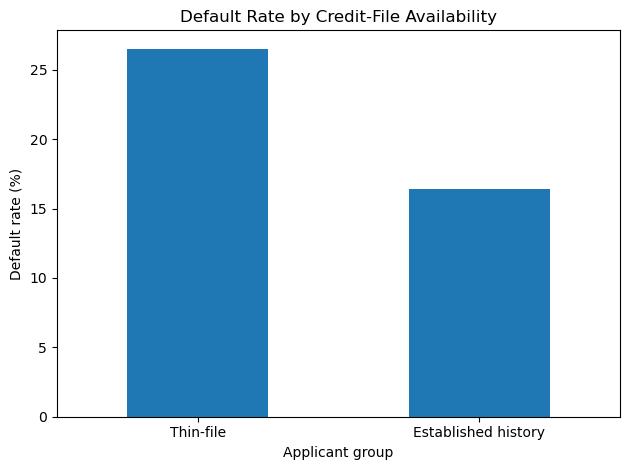

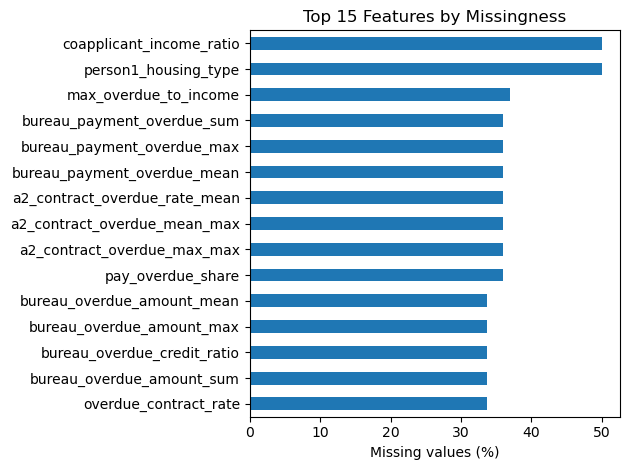

In [77]:
# ============================================================
# CHUNK 3 — TIME-BASED TRAIN / VALIDATION SPLIT + SIMPLE EDA
# ============================================================

target_col = "target"

y = df_model[target_col].copy()

X = df_model.drop(
    columns=[target_col]
).copy()


# ------------------------------------------------------------
# Time split
# ------------------------------------------------------------

split_week = 80

train_mask = (
    X["WEEK_NUM"] < split_week
)

val_mask = (
    X["WEEK_NUM"] >= split_week
)


X_train = (
    X.loc[train_mask]
    .copy()
    .reset_index(drop=True)
)

X_val = (
    X.loc[val_mask]
    .copy()
    .reset_index(drop=True)
)

y_train = (
    y.loc[train_mask]
    .copy()
    .reset_index(drop=True)
)

y_val = (
    y.loc[val_mask]
    .copy()
    .reset_index(drop=True)
)


assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)

assert X_train.index.equals(
    y_train.index
)

assert X_val.index.equals(
    y_val.index
)


print(
    "Training shape:",
    X_train.shape
)

print(
    "Validation shape:",
    X_val.shape
)

print(
    "Training weeks:",
    X_train["WEEK_NUM"].min(),
    "to",
    X_train["WEEK_NUM"].max()
)

print(
    "Validation weeks:",
    X_val["WEEK_NUM"].min(),
    "to",
    X_val["WEEK_NUM"].max()
)


# ============================================================
# TARGET DISTRIBUTION
# ============================================================

target_summary = pd.DataFrame(
    {
        "count":
            y_train
            .value_counts()
            .sort_index(),

        "percent":
            y_train
            .value_counts(
                normalize=True
            )
            .sort_index()
            * 100
    }
)

display(target_summary)


# ============================================================
# THIN-FILE VS ESTABLISHED CREDIT HISTORY
# ============================================================

thin_file_eda = pd.DataFrame(
    {
        "has_cb_history":
            X_train[
                "has_cb_history"
            ].to_numpy(),

        "target":
            y_train.to_numpy()
    }
)


thin_file_summary = (
    thin_file_eda
    .groupby(
        "has_cb_history"
    )["target"]
    .agg(
        applicants="count",
        defaults="sum",
        default_rate="mean"
    )
)


thin_file_summary.index = (
    thin_file_summary.index.map(
        {
            0: "Thin-file",
            1: "Established history"
        }
    )
)


thin_file_summary[
    "default_rate_pct"
] = (
    thin_file_summary[
        "default_rate"
    ] * 100
)

display(thin_file_summary)


# ============================================================
# MISSINGNESS SUMMARY
# ============================================================

missing_summary = (
    X_train
    .isna()
    .mean()
    .mul(100)
    .sort_values(
        ascending=False
    )
    .to_frame(
        "missing_pct"
    )
)

display(
    missing_summary.head(20)
)


# ============================================================
# SIMPLE VISUALIZATIONS
# ============================================================

import matplotlib.pyplot as plt


thin_file_summary[
    "default_rate_pct"
].plot(
    kind="bar",
    title=(
        "Default Rate by "
        "Credit-File Availability"
    ),
    ylabel="Default rate (%)",
    xlabel="Applicant group"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


missing_summary.head(15).sort_values(
    "missing_pct"
).plot(
    kind="barh",
    legend=False,
    title=(
        "Top 15 Features "
        "by Missingness"
    ),
    xlabel="Missing values (%)"
)

plt.tight_layout()
plt.show()

# Chunk 4 Optional winsorization

In [78]:
# ============================================================
# CHUNK 4 — OPTIONAL TRAIN-FITTED WINSORIZATION
# ============================================================

# Good to test for Logistic Regression / linear models.
# Usually not necessary for tree-based models.

USE_WINSORIZATION = False


amount_like_features = [

    # Application
    "mainoccupationinc_384A",
    "credamount_770A",
    "annuity_780A",

    # Person
    "person_income_sum",
    "person_income_mean",
    "person_income_max",
    "person_income_min",

    # Bureau
    "bureau_credit_amount_sum",
    "bureau_credit_amount_mean",
    "bureau_credit_amount_max",

    "bureau_overdue_amount_sum",
    "bureau_overdue_amount_mean",
    "bureau_overdue_amount_max",

    "bureau_payment_overdue_sum",
    "bureau_payment_overdue_mean",
    "bureau_payment_overdue_max",

    # Tax
    "tax_amount_sum",
    "tax_amount_mean",
    "tax_amount_max",
    "tax_amount_min",
    "tax_amount_std",

    # Previous applications
    "prev_credit_amount_sum",
    "prev_credit_amount_mean",
    "prev_credit_amount_max",
    "prev_credit_amount_min",
    "prev_credit_amount_std"
]


amount_like_features = [
    col
    for col in amount_like_features

    if col in X_train.columns
    and pd.api.types.is_numeric_dtype(
        X_train[col]
    )
]


if USE_WINSORIZATION:

    # Fit bounds using TRAIN only
    winsor_lower = (
        X_train[
            amount_like_features
        ]
        .quantile(0.01)
    )

    winsor_upper = (
        X_train[
            amount_like_features
        ]
        .quantile(0.99)
    )


    # Apply same train-fitted bounds
    # to train and validation
    for col in amount_like_features:

        X_train[col] = (
            X_train[col]
            .clip(
                lower=winsor_lower[col],
                upper=winsor_upper[col]
            )
        )

        X_val[col] = (
            X_val[col]
            .clip(
                lower=winsor_lower[col],
                upper=winsor_upper[col]
            )
        )


    print(
        "Winsorized features:",
        len(amount_like_features)
    )

else:

    print(
        "Winsorization skipped."
    )

Winsorization skipped.


# Chunk 5 Encoding and missing value handling

In [79]:
# ============================================================
# CHUNK 5 — CATEGORICAL ENCODING + MISSING-VALUE HANDLING
# ============================================================

from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer


# ============================================================
# A. ADD USEFUL EXTRA MISSINGNESS INDICATORS
# ============================================================

additional_indicator_sources = [

    "max_overdue_to_income",

    # Adapted from team's bureau_a2_overdue_sum
    "bureau_payment_overdue_sum",

    "bureau_exposure_ratio",

    "credit_vs_bureau_history",

    "tax_declared_income_ratio",

    "prev_days_since_last_approval",

    "prior_credit_to_current"
]


additional_indicator_sources = [
    col
    for col in additional_indicator_sources
    if col in X_train.columns
]


for col in additional_indicator_sources:

    indicator_name = (
        "missing_" + col
    )


    X_train[indicator_name] = (
        X_train[col]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .isna()
        .astype("int8")
    )


    X_val[indicator_name] = (
        X_val[col]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .isna()
        .astype("int8")
    )


# ============================================================
# B. CATEGORICAL FEATURES
# ============================================================

categorical_cols = (
    X_train
    .select_dtypes(
        include=[
            "object",
            "category"
        ]
    )
    .columns
    .tolist()
)


print(
    "Categorical columns:",
    categorical_cols
)


# Explicitly mark missing categories
for col in categorical_cols:

    X_train[col] = (
        X_train[col]
        .fillna("__missing__")
        .astype(str)
    )

    X_val[col] = (
        X_val[col]
        .fillna("__missing__")
        .astype(str)
    )


# Fit only on training data
ohe = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    dtype=np.float32
)


X_train_ohe = pd.DataFrame(
    ohe.fit_transform(
        X_train[categorical_cols]
    ),

    columns=(
        ohe.get_feature_names_out(
            categorical_cols
        )
    ),

    index=X_train.index
)


X_val_ohe = pd.DataFrame(
    ohe.transform(
        X_val[categorical_cols]
    ),

    columns=(
        ohe.get_feature_names_out(
            categorical_cols
        )
    ),

    index=X_val.index
)


# ============================================================
# C. REMOVE CATEGORICAL MISSING DUMMIES THAT ARE EXACTLY
#    THE SAME INFORMATION AS "NO CREDIT BUREAU HISTORY"
# ============================================================

redundant_ohe_cols = []


if "has_cb_history" in X_train.columns:

    no_cb_train = (
        1
        - X_train[
            "has_cb_history"
        ].astype("int8")
    ).to_numpy()


    no_cb_val = (
        1
        - X_val[
            "has_cb_history"
        ].astype("int8")
    ).to_numpy()


    for col in X_train_ohe.columns:

        if "__missing__" not in col:
            continue


        encoded_train = (
            X_train_ohe[col]
            .astype("int8")
            .to_numpy()
        )


        encoded_val = (
            X_val_ohe[col]
            .astype("int8")
            .to_numpy()
        )


        if (
            np.array_equal(
                encoded_train,
                no_cb_train
            )
            and
            np.array_equal(
                encoded_val,
                no_cb_val
            )
        ):

            redundant_ohe_cols.append(
                col
            )


if redundant_ohe_cols:

    X_train_ohe = (
        X_train_ohe.drop(
            columns=redundant_ohe_cols
        )
    )

    X_val_ohe = (
        X_val_ohe.drop(
            columns=redundant_ohe_cols
        )
    )


print(
    "Redundant categorical missing dummies dropped:",
    redundant_ohe_cols
)


# ============================================================
# D. SELECT NUMERICAL MODEL FEATURES
# ============================================================

# Keep these in the dataframe for EDA/splitting,
# but do not feed them directly into this baseline model.

exclude_model_cols = {

    "case_id",

    "WEEK_NUM",

    "MONTH",

    # Exact inverse of has_cb_history
    "is_thin_file",

    # Since person_count is always 1 or 2,
    # this adds no new information
    "has_coapplicant",

    # Exact sum of other presence flags
    "history_source_count"
}


numeric_cols = (
    X_train
    .select_dtypes(
        include=[
            "number",
            "bool"
        ]
    )
    .columns
    .tolist()
)


numeric_features = [

    col
    for col in numeric_cols

    if col not in exclude_model_cols

    and col in X_val.columns

    and X_train[col].nunique(
        dropna=True
    ) > 1
]


X_train_num = (
    X_train[
        numeric_features
    ]
    .copy()
)


X_val_num = (
    X_val[
        numeric_features
    ]
    .copy()
)


# Ratio calculations can create infinity
X_train_num.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)


X_val_num.replace(
    [np.inf, -np.inf],
    np.nan,
    inplace=True
)


# ============================================================
# E. STRUCTURAL ZERO FEATURES
# ============================================================

zero_fill_cols = [

    "bureau_contract_count",

    "bureau_a2_contract_count",

    "bureau_a2_record_count",

    "tax_record_count",

    "prev_application_count"
]


zero_fill_cols = [

    col
    for col in zero_fill_cols

    if col in X_train_num.columns
]


for col in zero_fill_cols:

    X_train_num[col] = (
        X_train_num[col]
        .fillna(0)
    )

    X_val_num[col] = (
        X_val_num[col]
        .fillna(0)
    )


# ============================================================
# F. COAPPLICANT INCOME RATIO
# ============================================================

ratio_col = (
    "coapplicant_income_ratio"
)


if ratio_col in X_train_num.columns:

    coapp_mask_train = (
        X_train["person_count"] > 1
    )


    # Median among people who really have coapplicants
    ratio_median = (
        X_train_num.loc[
            coapp_mask_train,
            ratio_col
        ]
        .median()
    )


    if not np.isfinite(
        ratio_median
    ):
        ratio_median = 0


    # No coapplicant -> ratio does not apply
    no_coapp_train = (
        X_train["person_count"] <= 1
    )

    no_coapp_val = (
        X_val["person_count"] <= 1
    )


    X_train_num.loc[
        no_coapp_train,
        ratio_col
    ] = 0


    X_val_num.loc[
        no_coapp_val,
        ratio_col
    ] = 0


    # Coapplicant exists but income data missing:
    # use TRAIN median
    X_train_num[ratio_col] = (
        X_train_num[ratio_col]
        .fillna(ratio_median)
    )


    X_val_num[ratio_col] = (
        X_val_num[ratio_col]
        .fillna(ratio_median)
    )


# ============================================================
# G. STANDARD-DEVIATION FEATURES
# ============================================================

std_features = [

    (
        "tax_amount_std",
        "tax_record_count"
    ),

    (
        "prev_credit_amount_std",
        "prev_application_count"
    )
]


for std_col, count_col in std_features:

    if (
        std_col not in X_train_num.columns
        or
        count_col not in X_train.columns
    ):
        continue


    # std is undefined with fewer than 2 records
    train_insufficient = (
        X_train[count_col]
        .fillna(0)
        < 2
    )

    val_insufficient = (
        X_val[count_col]
        .fillna(0)
        < 2
    )


    X_train_num.loc[
        train_insufficient,
        std_col
    ] = 0


    X_val_num.loc[
        val_insufficient,
        std_col
    ] = 0


# ============================================================
# H. MEDIAN IMPUTATION FOR EVERYTHING ELSE
# ============================================================

imputer = SimpleImputer(
    strategy="median",
    keep_empty_features=True
)


# Fit only on TRAIN
X_train_num.loc[:, :] = (
    imputer.fit_transform(
        X_train_num
    )
)


# Apply TRAIN medians to validation
X_val_num.loc[:, :] = (
    imputer.transform(
        X_val_num
    )
)


# ============================================================
# I. COMBINE NUMERIC + ENCODED CATEGORICAL FEATURES
# ============================================================

X_train_ready = pd.concat(
    [
        X_train_num,
        X_train_ohe
    ],
    axis=1
)


X_val_ready = pd.concat(
    [
        X_val_num,
        X_val_ohe
    ],
    axis=1
)


# Reduce memory usage
X_train_ready = (
    X_train_ready
    .astype(np.float32)
)


X_val_ready = (
    X_val_ready
    .astype(np.float32)
)


# ============================================================
# J. FINAL CHECKS
# ============================================================

assert (
    X_train_ready.columns
    .equals(
        X_val_ready.columns
    )
)


assert (
    len(X_train_ready)
    == len(y_train)
)


assert (
    len(X_val_ready)
    == len(y_val)
)


assert (
    X_train_ready.index
    .equals(
        y_train.index
    )
)


assert (
    X_val_ready.index
    .equals(
        y_val.index
    )
)


assert not (
    X_train_ready
    .isna()
    .any()
    .any()
)


assert not (
    X_val_ready
    .isna()
    .any()
    .any()
)


assert np.isfinite(
    X_train_ready
    .to_numpy()
).all()


assert np.isfinite(
    X_val_ready
    .to_numpy()
).all()


print(
    "Train-ready shape:",
    X_train_ready.shape
)


print(
    "Validation-ready shape:",
    X_val_ready.shape
)


print(
    "All preprocessing checks passed."
)

Categorical columns: ['education_927M', 'maritalstatus_703M', 'description_5085714M', 'person0_housing_type', 'person1_housing_type', 'prev_last_status', 'classificationofcontr_13M']
Redundant categorical missing dummies dropped: ['description_5085714M___missing__', 'classificationofcontr_13M___missing__']
Train-ready shape: (869559, 152)
Validation-ready shape: (130441, 152)
All preprocessing checks passed.


# Chunk 6 Quality Check

Constant features: []
Near-constant feature count: 0
Top 20 target correlations:


,correlation,absolute_correlation
riskassesment_940T,0.297416,0.297416
education_927M_2d4a2bc4,0.286057,0.286057
bureau_class_share_54ddc605,0.248029,0.248029
bureau_class_count_54ddc605,0.229014,0.229014
classificationofcontr_13M_54ddc605,0.220643,0.220643
bureau_dpd_mean,0.219110,0.219110
description_5085714M_34bbcd2a,0.208066,0.208066
bureau_dpd_max,0.181932,0.181932
bureau_dpd_7plus_rate,0.176567,0.176567
bureau_class_share_fe64f125,-0.175009,0.175009


Highly correlated pairs (|r| > 0.95): 7
person1_housing_type___missing__ <-> person_count: -1.0000
a2_contract_overdue_max_max <-> bureau_payment_overdue_max: 1.0000
prev_last_status___missing__ <-> missing_prev_days_since_last_approval: 1.0000
pay_overdue_share <-> a2_contract_overdue_rate_mean: 0.9770
missing_credit_vs_bureau_history <-> has_cb_history: -0.9664
bureau_a2_record_count <-> bureau_a2_contract_count: 0.9632
missing_prior_credit_to_current <-> has_prev: -0.9528


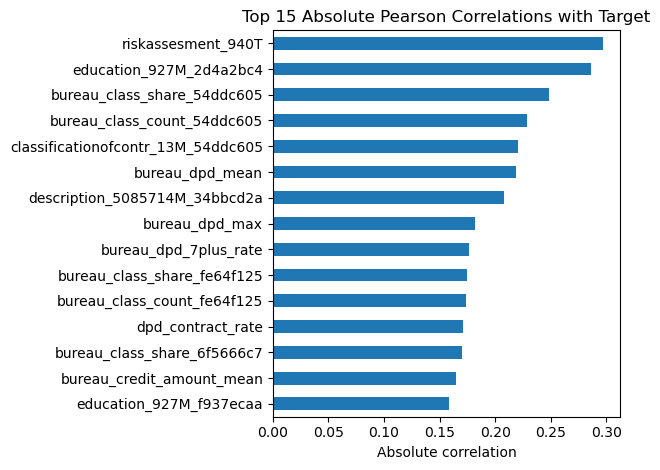

In [80]:
# ============================================================
# CHUNK 6 — FINAL EDA / QUALITY CHECKS
# ============================================================


# ============================================================
# A. CONSTANT / NEAR-CONSTANT FEATURES
# ============================================================

feature_std = (
    X_train_ready.std()
)


constant_features = (
    feature_std[
        feature_std == 0
    ]
    .index
    .tolist()
)


near_constant_features = (
    feature_std[
        (feature_std > 0)
        &
        (feature_std < 1e-4)
    ]
    .index
    .tolist()
)


print(
    "Constant features:",
    constant_features
)


print(
    "Near-constant feature count:",
    len(near_constant_features)
)


# ============================================================
# B. CORRELATION WITH TARGET
# ============================================================

# Explicitly force target onto same index
target_for_corr = pd.Series(
    y_train.to_numpy(),
    index=X_train_ready.index
)


target_corr = (
    X_train_ready
    .corrwith(
        target_for_corr
    )
)


target_corr_summary = pd.DataFrame(
    {
        "correlation":
            target_corr,

        "absolute_correlation":
            target_corr.abs()
    }
).sort_values(
    "absolute_correlation",
    ascending=False
)


print(
    "Top 20 target correlations:"
)

display(
    target_corr_summary.head(20)
)


# ============================================================
# C. HIGHLY CORRELATED FEATURE PAIRS
# ============================================================

# Sample for speed
corr_sample = (
    X_train_ready.sample(
        n=min(
            100_000,
            len(X_train_ready)
        ),
        random_state=42
    )
)


corr_matrix = (
    corr_sample.corr()
)


high_corr_pairs = []


for i in range(
    len(corr_matrix.columns)
):

    for j in range(i):

        corr_value = (
            corr_matrix.iloc[i, j]
        )


        if abs(corr_value) > 0.95:

            high_corr_pairs.append(
                (
                    corr_matrix.columns[i],
                    corr_matrix.columns[j],
                    corr_value
                )
            )


high_corr_pairs = sorted(
    high_corr_pairs,
    key=lambda x: abs(x[2]),
    reverse=True
)


print(
    "Highly correlated pairs "
    "(|r| > 0.95):",
    len(high_corr_pairs)
)


for pair in high_corr_pairs[:25]:

    print(
        f"{pair[0]} <-> "
        f"{pair[1]}: "
        f"{pair[2]:.4f}"
    )


# ============================================================
# D. VISUALIZE TOP TARGET CORRELATIONS
# ============================================================

top_corr = (
    target_corr_summary
    .head(15)
    .sort_values(
        "absolute_correlation"
    )
)


top_corr[
    "absolute_correlation"
].plot(
    kind="barh",
    legend=False,
    title=(
        "Top 15 Absolute "
        "Pearson Correlations with Target"
    ),
    xlabel="Absolute correlation"
)


plt.tight_layout()
plt.show()

In [81]:
# ============================================================
# XGBOOST + OPTUNA SETUP
# ============================================================

# Run once if needed:
#%pip install -U xgboost optuna scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import xgboost as xgb
from xgboost import XGBClassifier

import optuna

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42


print("XGBoost version:", xgb.__version__)
print("Optuna version:", optuna.__version__)

print("Train shape:", X_train_ready.shape)
print("Validation shape:", X_val_ready.shape)

print(
    "Train default rate:",
    y_train.mean()
)

print(
    "Validation default rate:",
    y_val.mean()
)

XGBoost version: 3.4.1
Optuna version: 5.0.0
Train shape: (869559, 152)
Validation shape: (130441, 152)
Train default rate: 0.19448134054158486
Validation default rate: 0.17355739376423057


In [82]:
# ============================================================
# XGBOOST + OPTUNA CREDIT-RISK MODEL — V3
# Temporal tuning + banking metrics + Altair visualizations
# ============================================================

# Run once if needed:
# %pip install -U xgboost optuna altair scikit-learn

import json
import numpy as np
import pandas as pd
import altair as alt

import xgboost as xgb
from xgboost import XGBClassifier

import optuna

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# ============================================================
# 1. CONFIGURATION
# ============================================================

RANDOM_STATE = 42

# Change to True only if XGBoost has CUDA support
USE_GPU = False

DEVICE = "cuda" if USE_GPU else "cpu"

N_JOBS = 1 if USE_GPU else -1


print("XGBoost version:", xgb.__version__)
print("Optuna version:", optuna.__version__)
print("Device:", DEVICE)

print("\nTraining shape:", X_train_ready.shape)
print("Final holdout shape:", X_val_ready.shape)

print(
    "Training default rate:",
    round(y_train.mean(), 4)
)

print(
    "Holdout default rate:",
    round(y_val.mean(), 4)
)


# ============================================================
# 2. ALIGN TRAINING DATA
# ============================================================

X_train_ready = (
    X_train_ready
    .reset_index(drop=True)
)

X_val_ready = (
    X_val_ready
    .reset_index(drop=True)
)

y_train_model = (
    y_train
    .reset_index(drop=True)
)

y_val_model = (
    y_val
    .reset_index(drop=True)
)

week_train = (
    X_train["WEEK_NUM"]
    .reset_index(drop=True)
)


assert len(X_train_ready) == len(y_train_model)
assert len(X_train_ready) == len(week_train)

assert len(X_val_ready) == len(y_val_model)

assert X_train_ready.columns.equals(
    X_val_ready.columns
)


print(
    "\nNumber of final model features:",
    X_train_ready.shape[1]
)


# ============================================================
# 3. CREDIT-RISK METRIC FUNCTION
# ============================================================

def risk_metrics(
    y_true,
    probabilities
):

    auc = roc_auc_score(
        y_true,
        probabilities
    )

    gini = (
        2 * auc
        - 1
    )

    pr_auc = (
        average_precision_score(
            y_true,
            probabilities
        )
    )

    fpr, tpr, thresholds = (
        roc_curve(
            y_true,
            probabilities
        )
    )

    ks_values = (
        tpr - fpr
    )

    ks_index = (
        np.argmax(
            ks_values
        )
    )

    return {

        "auc":
            float(auc),

        "gini":
            float(gini),

        "pr_auc":
            float(pr_auc),

        "ks":
            float(
                ks_values[
                    ks_index
                ]
            ),

        "ks_threshold":
            float(
                thresholds[
                    ks_index
                ]
            ),

        "brier":
            float(
                brier_score_loss(
                    y_true,
                    probabilities
                )
            ),

        "log_loss":
            float(
                log_loss(
                    y_true,
                    probabilities
                )
            )
    }


# ============================================================
# 4. TEMPORAL OPTUNA FOLDS
# ============================================================
#
# Fold 1:
# train weeks < 50
# validate 50-59
#
# Fold 2:
# train weeks < 60
# validate 60-69
#
# Fold 3:
# train weeks < 70
# validate 70-79
#
# Weeks 80-91 remain untouched.
#
# ============================================================

TEMPORAL_FOLDS = [

    (50, 60),

    (60, 70),

    (70, 80)
]


print("\n" + "=" * 65)
print("TEMPORAL OPTUNA FOLDS")
print("=" * 65)


for val_start, val_end in TEMPORAL_FOLDS:

    train_mask = (
        week_train
        < val_start
    )

    valid_mask = (
        (week_train >= val_start)
        &
        (week_train < val_end)
    )

    print(
        f"Train < week {val_start}: "
        f"{train_mask.sum():,} rows | "
        f"Validate {val_start}-{val_end - 1}: "
        f"{valid_mask.sum():,} rows"
    )


# ============================================================
# 5. BASELINE XGBOOST ON LATEST INNER WINDOW
# ============================================================

baseline_train_mask = (
    week_train < 70
)

baseline_valid_mask = (
    (week_train >= 70)
    &
    (week_train < 80)
)


baseline_model = XGBClassifier(

    objective="binary:logistic",

    tree_method="hist",

    device=DEVICE,

    n_estimators=3500,

    learning_rate=0.05,

    max_depth=4,

    min_child_weight=20,

    gamma=4,

    subsample=0.75,

    colsample_bytree=0.75,

    reg_alpha=0.01,

    reg_lambda=1.0,

    scale_pos_weight=1.0,

    eval_metric="auc",

    early_stopping_rounds=100,

    random_state=RANDOM_STATE,

    n_jobs=N_JOBS,

    verbosity=0
)


baseline_model.fit(

    X_train_ready.loc[
        baseline_train_mask
    ],

    y_train_model.loc[
        baseline_train_mask
    ],

    eval_set=[

        (
            X_train_ready.loc[
                baseline_valid_mask
            ],

            y_train_model.loc[
                baseline_valid_mask
            ]
        )
    ],

    verbose=False
)


baseline_prob = (
    baseline_model
    .predict_proba(

        X_train_ready.loc[
            baseline_valid_mask
        ]

    )[:, 1]
)


baseline_metrics = risk_metrics(

    y_train_model.loc[
        baseline_valid_mask
    ],

    baseline_prob
)


print("\n" + "=" * 65)
print("V3 BASELINE")
print("=" * 65)

print(
    "ROC-AUC:",
    round(
        baseline_metrics["auc"],
        6
    )
)

print(
    "Gini:",
    round(
        baseline_metrics["gini"],
        6
    )
)

print(
    "KS:",
    round(
        baseline_metrics["ks"],
        6
    )
)

print(
    "PR-AUC:",
    round(
        baseline_metrics["pr_auc"],
        6
    )
)


# ============================================================
# 6. OPTUNA OBJECTIVE
# ============================================================

def objective(trial):

    grow_policy = (
        trial.suggest_categorical(
            "grow_policy",
            [
                "depthwise",
                "lossguide"
            ]
        )
    )


    params = {

        # ----------------------------------------------------
        # Boosting speed
        # ----------------------------------------------------

        "learning_rate":
            trial.suggest_float(
                "learning_rate",
                0.02,
                0.10,
                log=True
            ),


        # ----------------------------------------------------
        # Prevent tiny / unstable leaves
        # ----------------------------------------------------

        "min_child_weight":
            trial.suggest_float(
                "min_child_weight",
                8,
                80,
                log=True
            ),


        # ----------------------------------------------------
        # Minimum split improvement
        # ----------------------------------------------------

        "gamma":
            trial.suggest_float(
                "gamma",
                1.0,
                10.0
            ),


        # ----------------------------------------------------
        # Row sampling
        # ----------------------------------------------------

        "subsample":
            trial.suggest_float(
                "subsample",
                0.65,
                0.95
            ),


        # ----------------------------------------------------
        # Feature sampling
        # ----------------------------------------------------

        "colsample_bytree":
            trial.suggest_float(
                "colsample_bytree",
                0.60,
                0.95
            ),


        # ----------------------------------------------------
        # L1 regularization
        # ----------------------------------------------------

        "reg_alpha":
            trial.suggest_float(
                "reg_alpha",
                1e-5,
                3.0,
                log=True
            ),


        # ----------------------------------------------------
        # L2 regularization
        # ----------------------------------------------------

        "reg_lambda":
            trial.suggest_float(
                "reg_lambda",
                0.10,
                15.0,
                log=True
            ),


        # ----------------------------------------------------
        # Histogram resolution
        # ----------------------------------------------------

        "max_bin":
            trial.suggest_categorical(
                "max_bin",
                [
                    128,
                    256,
                    512
                ]
            ),


        "grow_policy":
            grow_policy,


        # Keep probabilities interpretable
        "scale_pos_weight":
            1.0
    }


    # ========================================================
    # CONDITIONAL TREE COMPLEXITY
    # ========================================================

    if grow_policy == "depthwise":

        params["max_depth"] = (
            trial.suggest_int(
                "max_depth",
                3,
                6
            )
        )

        params["max_leaves"] = 0


    else:

        params["max_depth"] = 0

        params["max_leaves"] = (
            trial.suggest_int(
                "max_leaves",
                24,
                96,
                step=8
            )
        )


    fold_aucs = []

    fold_pr_aucs = []

    fold_ks = []

    fold_brier = []

    fold_logloss = []

    fold_rounds = []


    # ========================================================
    # ROLLING TEMPORAL VALIDATION
    # ========================================================

    for fold_number, (
        val_start,
        val_end
    ) in enumerate(
        TEMPORAL_FOLDS,
        start=1
    ):

        train_mask = (
            week_train
            < val_start
        )

        valid_mask = (

            (week_train >= val_start)

            &

            (week_train < val_end)
        )


        model = XGBClassifier(

            objective="binary:logistic",

            tree_method="hist",

            device=DEVICE,

            n_estimators=3500,

            eval_metric="auc",

            early_stopping_rounds=100,

            random_state=(
                RANDOM_STATE
                + fold_number
            ),

            n_jobs=N_JOBS,

            verbosity=0,

            **params
        )


        model.fit(

            X_train_ready.loc[
                train_mask
            ],

            y_train_model.loc[
                train_mask
            ],

            eval_set=[

                (
                    X_train_ready.loc[
                        valid_mask
                    ],

                    y_train_model.loc[
                        valid_mask
                    ]
                )
            ],

            verbose=False
        )


        probabilities = (
            model
            .predict_proba(

                X_train_ready.loc[
                    valid_mask
                ]

            )[:, 1]
        )


        metrics = risk_metrics(

            y_train_model.loc[
                valid_mask
            ],

            probabilities
        )


        fold_aucs.append(
            metrics["auc"]
        )

        fold_pr_aucs.append(
            metrics["pr_auc"]
        )

        fold_ks.append(
            metrics["ks"]
        )

        fold_brier.append(
            metrics["brier"]
        )

        fold_logloss.append(
            metrics["log_loss"]
        )

        fold_rounds.append(
            model.best_iteration
            + 1
        )


    mean_auc = (
        np.mean(
            fold_aucs
        )
    )


    trial.set_user_attr(
        "auc_std",
        float(
            np.std(
                fold_aucs
            )
        )
    )

    trial.set_user_attr(
        "mean_pr_auc",
        float(
            np.mean(
                fold_pr_aucs
            )
        )
    )

    trial.set_user_attr(
        "mean_ks",
        float(
            np.mean(
                fold_ks
            )
        )
    )

    trial.set_user_attr(
        "mean_brier",
        float(
            np.mean(
                fold_brier
            )
        )
    )

    trial.set_user_attr(
        "mean_logloss",
        float(
            np.mean(
                fold_logloss
            )
        )
    )

    trial.set_user_attr(
        "median_rounds",
        int(
            np.median(
                fold_rounds
            )
        )
    )


    # Primary objective:
    # maximize average temporal ROC-AUC

    return float(
        mean_auc
    )


# ============================================================
# 7. CREATE NEW OPTUNA STUDY
# ============================================================
#
# IMPORTANT:
# This is a NEW feature set.
# Do not reuse the old study.
#
# ============================================================

sampler = (
    optuna.samplers.TPESampler(

        seed=RANDOM_STATE,

        n_startup_trials=10
    )
)


study_v3 = optuna.create_study(

    study_name=(
        "amex_xgb_v3_features"
    ),

    direction="maximize",

    sampler=sampler,

    storage=(
        "sqlite:///amex_xgb_optuna_v3.db"
    ),

    load_if_exists=True
)


# Three temporal folds per trial,
# so 25-30 trials is already substantial.

N_TRIALS = 30


study_v3.optimize(

    objective,

    n_trials=N_TRIALS,

    gc_after_trial=True,

    show_progress_bar=True
)


# ============================================================
# 8. BEST OPTUNA RESULTS
# ============================================================

best_trial = (
    study_v3.best_trial
)


print("\n" + "=" * 65)
print("BEST OPTUNA V3 MODEL")
print("=" * 65)

print(
    "Mean ROC-AUC:",
    round(
        best_trial.value,
        6
    )
)

print(
    "AUC temporal std:",
    round(
        best_trial.user_attrs[
            "auc_std"
        ],
        6
    )
)

print(
    "Mean Gini:",
    round(
        2 * best_trial.value - 1,
        6
    )
)

print(
    "Mean KS:",
    round(
        best_trial.user_attrs[
            "mean_ks"
        ],
        6
    )
)

print(
    "Mean PR-AUC:",
    round(
        best_trial.user_attrs[
            "mean_pr_auc"
        ],
        6
    )
)

print(
    "Mean Brier:",
    round(
        best_trial.user_attrs[
            "mean_brier"
        ],
        6
    )
)

print(
    "Mean Log Loss:",
    round(
        best_trial.user_attrs[
            "mean_logloss"
        ],
        6
    )
)

print(
    "Median tree count:",
    best_trial.user_attrs[
        "median_rounds"
    ]
)


print("\nBest Parameters:")

for key, value in (
    study_v3.best_params.items()
):

    print(
        f"{key}: {value}"
    )


# ============================================================
# 9. ALTAIR — OPTUNA HISTORY
# ============================================================

trials_df = (
    study_v3
    .trials_dataframe()
)


completed_trials = (
    trials_df
    .loc[
        trials_df[
            "state"
        ].astype(str)
        .str.contains(
            "COMPLETE"
        )
    ]
    .copy()
)


completed_trials[
    "best_so_far"
] = (
    completed_trials[
        "value"
    ]
    .cummax()
)


optuna_points = (

    alt.Chart(
        completed_trials
    )

    .mark_circle(
        size=80,
        opacity=0.65
    )

    .encode(

        x=alt.X(
            "number:Q",
            title="Optuna Trial"
        ),

        y=alt.Y(
            "value:Q",
            title="Mean Temporal ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[
            alt.Tooltip(
                "number:Q",
                title="Trial"
            ),

            alt.Tooltip(
                "value:Q",
                title="AUC",
                format=".6f"
            )
        ]
    )
)


best_line = (

    alt.Chart(
        completed_trials
    )

    .mark_line(
        strokeWidth=3
    )

    .encode(

        x="number:Q",

        y=alt.Y(
            "best_so_far:Q",
            title="Mean Temporal ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[
            alt.Tooltip(
                "best_so_far:Q",
                format=".6f"
            )
        ]
    )
)


optuna_chart = (

    (optuna_points + best_line)

    .properties(
        width=750,
        height=400,
        title=(
            "Optuna Optimization History"
        )
    )

    .interactive()
)


optuna_chart


# ============================================================
# 10. RECONSTRUCT BEST PARAMETERS
# ============================================================

best_params = (
    study_v3.best_params.copy()
)


if (
    best_params[
        "grow_policy"
    ]
    ==
    "depthwise"
):

    best_params[
        "max_leaves"
    ] = 0


else:

    best_params[
        "max_depth"
    ] = 0


best_params[
    "scale_pos_weight"
] = 1.0


best_rounds = (
    int(
        best_trial
        .user_attrs[
            "median_rounds"
        ]
    )
)


print(
    "\nSelected number of trees:",
    best_rounds
)


# ============================================================
# 11. BUILD OUT-OF-TIME PREDICTIONS
# ============================================================
#
# Used for threshold selection.
#
# ============================================================

oof_probs = []

oof_y = []

oof_week = []


for fold_number, (
    val_start,
    val_end
) in enumerate(
    TEMPORAL_FOLDS,
    start=1
):

    train_mask = (
        week_train
        < val_start
    )

    valid_mask = (

        (week_train >= val_start)

        &

        (week_train < val_end)
    )


    model = XGBClassifier(

        objective="binary:logistic",

        tree_method="hist",

        device=DEVICE,

        n_estimators=3500,

        eval_metric="auc",

        early_stopping_rounds=100,

        random_state=(
            RANDOM_STATE
            + fold_number
        ),

        n_jobs=N_JOBS,

        verbosity=0,

        **best_params
    )


    model.fit(

        X_train_ready.loc[
            train_mask
        ],

        y_train_model.loc[
            train_mask
        ],

        eval_set=[

            (
                X_train_ready.loc[
                    valid_mask
                ],

                y_train_model.loc[
                    valid_mask
                ]
            )
        ],

        verbose=False
    )


    fold_prob = (
        model
        .predict_proba(

            X_train_ready.loc[
                valid_mask
            ]

        )[:, 1]
    )


    oof_probs.extend(
        fold_prob
    )

    oof_y.extend(
        y_train_model.loc[
            valid_mask
        ].to_numpy()
    )

    oof_week.extend(
        week_train.loc[
            valid_mask
        ].to_numpy()
    )


oof_probs = np.asarray(
    oof_probs
)

oof_y = np.asarray(
    oof_y
)

oof_week = np.asarray(
    oof_week
)


oof_metrics = risk_metrics(
    oof_y,
    oof_probs
)


print("\n" + "=" * 65)
print("OUT-OF-TIME MODEL PERFORMANCE")
print("=" * 65)

print(
    "ROC-AUC:",
    round(
        oof_metrics["auc"],
        5
    )
)

print(
    "Gini:",
    round(
        oof_metrics["gini"],
        5
    )
)

print(
    "KS:",
    round(
        oof_metrics["ks"],
        5
    )
)

print(
    "PR-AUC:",
    round(
        oof_metrics["pr_auc"],
        5
    )
)


# ============================================================
# 12. SELECT THRESHOLD USING OOF KS
# ============================================================

selected_threshold = (
    oof_metrics[
        "ks_threshold"
    ]
)


print(
    "\nSelected KS threshold:",
    round(
        selected_threshold,
        5
    )
)


# ============================================================
# 13. APPROVAL / RISK TRADE-OFF TABLE
# ============================================================

def approval_tradeoff(
    y_true,
    probabilities
):

    results = []


    for target_approval in [

        0.60,
        0.65,
        0.70,
        0.75,
        0.80,
        0.85,
        0.90
    ]:

        threshold = (
            np.quantile(
                probabilities,
                target_approval
            )
        )


        predicted_default = (
            probabilities
            >= threshold
        ).astype(int)


        tn, fp, fn, tp = (
            confusion_matrix(
                y_true,
                predicted_default
            )
            .ravel()
        )


        approved = (
            predicted_default == 0
        )


        rejected = (
            predicted_default == 1
        )


        results.append(
            {

                "approval_rate":
                    approved.mean(),

                "threshold":
                    threshold,

                "default_capture_rate":
                    tp / (tp + fn),

                "approved_default_rate":

                    (
                        y_true[
                            approved
                        ].mean()

                        if approved.sum() > 0

                        else np.nan
                    ),

                "rejected_default_rate":

                    (
                        y_true[
                            rejected
                        ].mean()

                        if rejected.sum() > 0

                        else np.nan
                    ),

                "good_customer_rejection_rate":
                    fp / (fp + tn)
            }
        )


    return pd.DataFrame(
        results
    )


approval_df = (
    approval_tradeoff(
        oof_y,
        oof_probs
    )
)


display(
    approval_df.style.format(
        {
            "approval_rate":
                "{:.1%}",

            "threshold":
                "{:.4f}",

            "default_capture_rate":
                "{:.1%}",

            "approved_default_rate":
                "{:.1%}",

            "rejected_default_rate":
                "{:.1%}",

            "good_customer_rejection_rate":
                "{:.1%}"
        }
    )
)


# ============================================================
# 14. ALTAIR — APPROVAL/RISK TRADEOFF
# ============================================================

approval_long = (
    approval_df[
        [
            "approval_rate",
            "default_capture_rate",
            "approved_default_rate",
            "good_customer_rejection_rate"
        ]
    ]

    .melt(
        id_vars="approval_rate",

        var_name="metric",

        value_name="value"
    )
)


approval_chart = (

    alt.Chart(
        approval_long
    )

    .mark_line(
        point=True,
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "approval_rate:Q",
            title="Approval Rate",
            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(
            "value:Q",
            title="Rate",
            axis=alt.Axis(
                format="%"
            )
        ),

        color=alt.Color(
            "metric:N",
            title="Metric"
        ),

        tooltip=[

            alt.Tooltip(
                "approval_rate:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "metric:N"
            ),

            alt.Tooltip(
                "value:Q",
                format=".2%"
            )
        ]
    )

    .properties(
        width=750,
        height=400,
        title=(
            "Approval Rate vs Credit-Risk Trade-Off"
        )
    )

    .interactive()
)


approval_chart


# ============================================================
# 15. TRAIN FINAL MODEL ON WEEKS 0-79
# ============================================================

final_model = XGBClassifier(

    objective="binary:logistic",

    tree_method="hist",

    device=DEVICE,

    n_estimators=best_rounds,

    eval_metric="auc",

    random_state=RANDOM_STATE,

    n_jobs=N_JOBS,

    verbosity=0,

    **best_params
)


final_model.fit(

    X_train_ready,
    y_train_model,

    verbose=False
)


# ============================================================
# 16. FINAL HOLDOUT — WEEKS 80-91
# ============================================================

final_prob = (
    final_model
    .predict_proba(
        X_val_ready
    )[:, 1]
)


final_metrics = risk_metrics(
    y_val_model,
    final_prob
)


final_pred = (
    final_prob
    >= selected_threshold
).astype(int)


# ============================================================
# 17. CLASSIFICATION / BANK METRICS
# ============================================================

accuracy = (
    accuracy_score(
        y_val_model,
        final_pred
    )
)

precision = (
    precision_score(
        y_val_model,
        final_pred,
        zero_division=0
    )
)

recall = (
    recall_score(
        y_val_model,
        final_pred,
        zero_division=0
    )
)

f1 = (
    f1_score(
        y_val_model,
        final_pred,
        zero_division=0
    )
)


tn, fp, fn, tp = (
    confusion_matrix(
        y_val_model,
        final_pred
    )
    .ravel()
)


specificity = (
    tn
    /
    (tn + fp)
)


approved_mask = (
    final_pred == 0
)

rejected_mask = (
    final_pred == 1
)


approval_rate = (
    approved_mask.mean()
)

rejection_rate = (
    rejected_mask.mean()
)


approved_default_rate = (

    y_val_model[
        approved_mask
    ].mean()

    if approved_mask.sum() > 0

    else np.nan
)


rejected_default_rate = (

    y_val_model[
        rejected_mask
    ].mean()

    if rejected_mask.sum() > 0

    else np.nan
)


good_customer_rejection_rate = (
    fp
    /
    (fp + tn)
)


# ============================================================
# 18. CONSTANT-PD PROBABILITY BASELINE
# ============================================================

constant_probability = np.repeat(

    y_train_model.mean(),

    len(
        y_val_model
    )
)


constant_brier = (
    brier_score_loss(
        y_val_model,
        constant_probability
    )
)


constant_logloss = (
    log_loss(
        y_val_model,
        constant_probability
    )
)


# ============================================================
# 19. FINAL METRIC TABLE
# ============================================================

final_results = pd.DataFrame(
    {

        "Metric": [

            "ROC-AUC",
            "Gini",
            "KS",
            "PR-AUC",

            "Brier Score",
            "Constant-PD Brier",

            "Log Loss",
            "Constant-PD Log Loss",

            "Accuracy",
            "Precision",
            "Recall / Default Capture",
            "Specificity",
            "F1",

            "Approval Rate",
            "Rejection Rate",

            "Default Rate Among Approved",
            "Default Rate Among Rejected",

            "Good Customer Rejection Rate",

            "Overall Holdout Default Rate"
        ],

        "Value": [

            final_metrics["auc"],
            final_metrics["gini"],
            final_metrics["ks"],
            final_metrics["pr_auc"],

            final_metrics["brier"],
            constant_brier,

            final_metrics["log_loss"],
            constant_logloss,

            accuracy,
            precision,
            recall,
            specificity,
            f1,

            approval_rate,
            rejection_rate,

            approved_default_rate,
            rejected_default_rate,

            good_customer_rejection_rate,

            y_val_model.mean()
        ]
    }
)


print("\n" + "=" * 65)
print("FINAL OUT-OF-TIME CREDIT-RISK PERFORMANCE")
print("=" * 65)


display(
    final_results.style.format(
        {
            "Value":
                "{:.5f}"
        }
    )
)


# ============================================================
# 20. CONFUSION MATRIX
# ============================================================

confusion_df = pd.DataFrame(

    [
        [tn, fp],
        [fn, tp]
    ],

    index=[
        "Actual Repaid",
        "Actual Default"
    ],

    columns=[
        "Predicted Repaid",
        "Predicted Default"
    ]
)


display(
    confusion_df
)


print(
    classification_report(

        y_val_model,

        final_pred,

        target_names=[
            "Repaid",
            "Default"
        ],

        digits=4,

        zero_division=0
    )
)


# ============================================================
# 21. ALTAIR — ROC CURVE
# ============================================================

fpr, tpr, roc_thresholds = (
    roc_curve(
        y_val_model,
        final_prob
    )
)


# Reduce points for a responsive chart
roc_indices = np.linspace(
    0,
    len(fpr) - 1,
    min(
        600,
        len(fpr)
    ),
    dtype=int
)


roc_df = pd.DataFrame(
    {
        "False Positive Rate":
            fpr[
                roc_indices
            ],

        "True Positive Rate":
            tpr[
                roc_indices
            ]
    }
)


roc_chart = (

    alt.Chart(
        roc_df
    )

    .mark_line(
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "False Positive Rate:Q",
            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(
            "True Positive Rate:Q",
            axis=alt.Axis(
                format="%"
            )
        ),

        tooltip=[

            alt.Tooltip(
                "False Positive Rate:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "True Positive Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(
        width=600,
        height=430,
        title=(
            f"Final ROC Curve | "
            f"AUC = {final_metrics['auc']:.4f} | "
            f"Gini = {final_metrics['gini']:.4f}"
        )
    )

    .interactive()
)


roc_chart


# ============================================================
# 22. ALTAIR — PRECISION / RECALL CURVE
# ============================================================

pr_precision, pr_recall, _ = (
    precision_recall_curve(
        y_val_model,
        final_prob
    )
)


pr_indices = np.linspace(
    0,
    len(pr_precision) - 1,
    min(
        600,
        len(pr_precision)
    ),
    dtype=int
)


pr_df = pd.DataFrame(
    {
        "Recall":
            pr_recall[
                pr_indices
            ],

        "Precision":
            pr_precision[
                pr_indices
            ]
    }
)


pr_chart = (

    alt.Chart(
        pr_df
    )

    .mark_line(
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "Recall:Q",
            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(
            "Precision:Q",
            axis=alt.Axis(
                format="%"
            )
        ),

        tooltip=[

            alt.Tooltip(
                "Recall:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Precision:Q",
                format=".2%"
            )
        ]
    )

    .properties(
        width=600,
        height=430,
        title=(
            f"Precision–Recall Curve | "
            f"PR-AUC = "
            f"{final_metrics['pr_auc']:.4f}"
        )
    )

    .interactive()
)


pr_chart


# ============================================================
# 23. FEATURE IMPORTANCE — GAIN
# ============================================================

booster = (
    final_model
    .get_booster()
)


gain_importance = (
    booster.get_score(
        importance_type="gain"
    )
)


importance_df = (
    pd.DataFrame(
        {

            "feature":
                list(
                    gain_importance.keys()
                ),

            "gain":
                list(
                    gain_importance.values()
                )
        }
    )

    .sort_values(
        "gain",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


display(
    importance_df.head(25)
)


# ============================================================
# 24. ALTAIR — FEATURE IMPORTANCE
# ============================================================

top_features = (
    importance_df
    .head(25)
)


feature_chart = (

    alt.Chart(
        top_features
    )

    .mark_bar()
    
    .encode(

        x=alt.X(
            "gain:Q",
            title="XGBoost Gain"
        ),

        y=alt.Y(
            "feature:N",
            title=None,
            sort="-x"
        ),

        tooltip=[

            alt.Tooltip(
                "feature:N",
                title="Feature"
            ),

            alt.Tooltip(
                "gain:Q",
                title="Gain",
                format=".2f"
            )
        ]
    )

    .properties(
        width=750,
        height=550,
        title=(
            "Top 25 Features by XGBoost Gain"
        )
    )

    .interactive()
)


feature_chart


# ============================================================
# 25. WEEK-BY-WEEK HOLDOUT STABILITY
# ============================================================

if "WEEK_NUM" in X_val.columns:

    holdout_week = (
        X_val[
            "WEEK_NUM"
        ]
        .reset_index(drop=True)
    )


    weekly_results = []


    for week in sorted(
        holdout_week.unique()
    ):

        mask = (
            holdout_week
            == week
        )


        week_y = (
            y_val_model.loc[
                mask
            ]
        )


        week_prob = (
            final_prob[
                mask.to_numpy()
            ]
        )


        weekly_results.append(
            {

                "week":
                    int(
                        week
                    ),

                "applications":
                    int(
                        mask.sum()
                    ),

                "default_rate":
                    float(
                        week_y.mean()
                    ),

                "roc_auc":

                    float(
                        roc_auc_score(
                            week_y,
                            week_prob
                        )
                    )

                    if week_y.nunique() == 2

                    else np.nan
            }
        )


    weekly_results = pd.DataFrame(
        weekly_results
    )


    weekly_long = (

        weekly_results[
            [
                "week",
                "default_rate",
                "roc_auc"
            ]
        ]

        .melt(
            id_vars="week",

            var_name="metric",

            value_name="value"
        )
    )


    weekly_chart = (

        alt.Chart(
            weekly_long
        )

        .mark_line(
            point=True,
            strokeWidth=3
        )

        .encode(

            x=alt.X(
                "week:O",
                title="Holdout Week"
            ),

            y=alt.Y(
                "value:Q",
                title="Rate / AUC",
                scale=alt.Scale(
                    zero=False
                )
            ),

            color=alt.Color(
                "metric:N",
                title="Metric"
            ),

            tooltip=[

                "week:O",

                "metric:N",

                alt.Tooltip(
                    "value:Q",
                    format=".4f"
                )
            ]
        )

        .properties(
            width=750,
            height=400,
            title=(
                "Out-of-Time Stability by Week"
            )
        )

        .interactive()
    )


    display(
        weekly_results
    )

    weekly_chart


# ============================================================
# 26. THIN-FILE VS ESTABLISHED PERFORMANCE
# ============================================================

if "has_cb_history" in X_val.columns:

    cb_flag = (
        X_val[
            "has_cb_history"
        ]
        .reset_index(drop=True)
    )


    segment_results = []


    for value, label in [

        (
            0,
            "Thin-file"
        ),

        (
            1,
            "Established history"
        )
    ]:

        mask = (
            cb_flag
            == value
        )


        segment_y = (
            y_val_model.loc[
                mask
            ]
        )


        segment_prob = (
            final_prob[
                mask.to_numpy()
            ]
        )


        segment_results.append(
            {

                "segment":
                    label,

                "applications":
                    int(
                        mask.sum()
                    ),

                "default_rate":
                    float(
                        segment_y.mean()
                    ),

                "roc_auc":

                    float(
                        roc_auc_score(
                            segment_y,
                            segment_prob
                        )
                    )

                    if segment_y.nunique() == 2

                    else np.nan
            }
        )


    segment_df = pd.DataFrame(
        segment_results
    )


    display(
        segment_df.style.format(
            {
                "default_rate":
                    "{:.2%}",

                "roc_auc":
                    "{:.4f}"
            }
        )
    )


    segment_chart = (

        alt.Chart(
            segment_df
        )

        .mark_bar()

        .encode(

            x=alt.X(
                "segment:N",
                title=None
            ),

            y=alt.Y(
                "roc_auc:Q",
                title="ROC-AUC",
                scale=alt.Scale(
                    zero=False
                )
            ),

            tooltip=[

                "segment:N",

                alt.Tooltip(
                    "applications:Q",
                    format=","
                ),

                alt.Tooltip(
                    "default_rate:Q",
                    format=".2%"
                ),

                alt.Tooltip(
                    "roc_auc:Q",
                    format=".4f"
                )
            ]
        )

        .properties(
            width=500,
            height=350,
            title=(
                "Model Performance by Credit-File Segment"
            )
        )
    )


    segment_chart


# ============================================================
# 27. SAVE MODEL + RESULTS
# ============================================================

final_model.save_model(
    "amex_xgb_v3.json"
)


study_v3.trials_dataframe().to_csv(
    "amex_xgb_v3_optuna_trials.csv",
    index=False
)


final_results.to_csv(
    "amex_xgb_v3_metrics.csv",
    index=False
)


importance_df.to_csv(
    "amex_xgb_v3_feature_importance.csv",
    index=False
)


saved_results = {

    "best_params":
        study_v3.best_params,

    "number_of_features":
        int(
            X_train_ready.shape[1]
        ),

    "n_estimators":
        int(
            best_rounds
        ),

    "selected_threshold":
        float(
            selected_threshold
        ),

    "final_metrics":
        {

            row["Metric"]:
                float(
                    row["Value"]
                )

            for _, row
            in final_results.iterrows()
        }
}


with open(
    "amex_xgb_v3_results.json",
    "w"
) as file:

    json.dump(
        saved_results,
        file,
        indent=4
    )


# ============================================================
# 28. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 70)
print("XGBOOST CREDIT-RISK MODEL V3 COMPLETE")
print("=" * 70)

print("\nDISCRIMINATION")

print(
    "ROC-AUC:",
    round(
        final_metrics["auc"],
        5
    )
)

print(
    "Gini:",
    round(
        final_metrics["gini"],
        5
    )
)

print(
    "KS:",
    round(
        final_metrics["ks"],
        5
    )
)

print(
    "PR-AUC:",
    round(
        final_metrics["pr_auc"],
        5
    )
)


print("\nPROBABILITY QUALITY")

print(
    "Brier Score:",
    round(
        final_metrics["brier"],
        5
    )
)

print(
    "Log Loss:",
    round(
        final_metrics["log_loss"],
        5
    )
)


print("\nCLASSIFICATION")

print(
    "Recall / Default Capture:",
    round(
        recall,
        5
    )
)

print(
    "Precision:",
    round(
        precision,
        5
    )
)

print(
    "Specificity:",
    round(
        specificity,
        5
    )
)

print(
    "F1:",
    round(
        f1,
        5
    )
)


print("\nLENDING VIEW")

print(
    "Approval Rate:",
    round(
        approval_rate,
        5
    )
)

print(
    "Rejection Rate:",
    round(
        rejection_rate,
        5
    )
)

print(
    "Approved Default Rate:",
    round(
        approved_default_rate,
        5
    )
)

print(
    "Rejected Default Rate:",
    round(
        rejected_default_rate,
        5
    )
)

print(
    "Good Customer Rejection Rate:",
    round(
        good_customer_rejection_rate,
        5
    )
)


print("\nMODEL")

print(
    "Features:",
    X_train_ready.shape[1]
)

print(
    "Trees:",
    best_rounds
)

print(
    "Threshold:",
    round(
        selected_threshold,
        5
    )
)

print("=" * 70)

XGBoost version: 3.4.1
Optuna version: 5.0.0
Device: cpu

Training shape: (869559, 152)
Final holdout shape: (130441, 152)
Training default rate: 0.1945
Holdout default rate: 0.1736

Number of final model features: 152

TEMPORAL OPTUNA FOLDS
Train < week 50: 543,708 rows | Validate 50-59: 108,425 rows
Train < week 60: 652,133 rows | Validate 60-69: 108,800 rows
Train < week 70: 760,933 rows | Validate 70-79: 108,626 rows

V3 BASELINE
ROC-AUC: 0.772255
Gini: 0.54451
KS: 0.399307
PR-AUC: 0.444222


[I 2026-11-07 14:51:35,213] A new study created in RDB with name: amex_xgb_v3_features


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-11-07 14:52:35,512] Trial 0 finished with value: 0.7727855873602526 and parameters: {'grow_policy': 'lossguide', 'learning_rate': 0.06496385739540578, 'min_child_weight': 31.75034664355495, 'gamma': 2.4041677639819286, 'subsample': 0.6967983561008608, 'colsample_bytree': 0.6203292642588698, 'reg_alpha': 0.5548195788561852, 'reg_lambda': 2.0327366744562516, 'max_bin': 512, 'max_leaves': 88}. Best is trial 0 with value: 0.7727855873602526.
[I 2026-11-07 14:54:16,192] Trial 1 finished with value: 0.7726650506762494 and parameters: {'grow_policy': 'depthwise', 'learning_rate': 0.026867313736068595, 'min_child_weight': 16.118782307326917, 'gamma': 5.72280788469014, 'subsample': 0.7795835055926348, 'colsample_bytree': 0.7019301990693146, 'reg_alpha': 0.02244876710876666, 'reg_lambda': 0.20116451331203475, 'max_bin': 512, 'max_depth': 6}. Best is trial 0 with value: 0.7727855873602526.
[I 2026-11-07 14:55:05,641] Trial 2 finished with value: 0.7728694417962095 and parameters: {'grow_p

,approval_rate,threshold,default_capture_rate,approved_default_rate,rejected_default_rate,good_customer_rejection_rate
0,60.0%,0.1957,73.0%,8.2%,33.2%,32.6%
1,65.0%,0.2249,67.6%,9.1%,35.1%,27.8%
2,70.0%,0.2496,61.8%,9.9%,37.5%,22.9%
3,75.0%,0.2786,55.4%,10.8%,40.3%,18.2%
4,80.0%,0.3308,47.8%,11.9%,43.5%,13.8%
5,85.0%,0.3758,39.1%,13.0%,47.4%,9.6%
6,90.0%,0.4319,29.2%,14.3%,53.1%,5.7%



FINAL OUT-OF-TIME CREDIT-RISK PERFORMANCE


... (3 outputs left out)

,feature,gain
0,education_927M_2d4a2bc4,6485.647949
1,education_927M_242b264b,1796.704346
2,bureau_class_count_ba38dde4,1264.742432
3,education_927M_6def22f0,836.429443
4,bureau_class_count_6f5666c7,836.238464
5,bureau_class_count_d8bf6dd7,643.001160
6,riskassesment_940T,546.643738
7,bureau_class_share_ba38dde4,481.349640
8,education_927M_f937ecaa,320.459778
9,bureau_contract_count,296.392181


,week,applications,default_rate,roc_auc
0,80,10862,0.175106,0.765838
1,81,10807,0.179513,0.769110
2,82,10911,0.177711,0.768360
3,83,10789,0.174159,0.765770
4,84,10733,0.176465,0.769649
5,85,10722,0.168345,0.773599
6,86,10943,0.173353,0.773121
7,87,10973,0.171512,0.761255
8,88,10844,0.170048,0.765950
9,89,11037,0.172058,0.772638


,segment,applications,default_rate,roc_auc
0,Thin-file,39001,19.81%,0.7067
1,Established history,91440,16.31%,0.7943




XGBOOST CREDIT-RISK MODEL V3 COMPLETE

DISCRIMINATION
ROC-AUC: 0.76798
Gini: 0.53596
KS: 0.39409
PR-AUC: 0.42755

PROBABILITY QUALITY
Brier Score: 0.12258
Log Loss: 0.39234

CLASSIFICATION
Recall / Default Capture: 0.71814
Precision: 0.31707
Specificity: 0.67517
F1: 0.43992

LENDING VIEW
Approval Rate: 0.60691
Rejection Rate: 0.39309
Approved Default Rate: 0.0806
Rejected Default Rate: 0.31707
Good Customer Rejection Rate: 0.32483

MODEL
Features: 152
Trees: 225
Threshold: 0.19513


In [85]:
# ============================================================
# CATBOOST NATIVE-CATEGORICAL MODEL — FASTER V2
# Optuna + temporal validation + banking metrics + Altair
# ============================================================
#
# USE THIS CELL IN PLACE OF THE OLD CATBOOST CELL.
#
# Starts from df_model BEFORE OHE.
#
# No StandardScaler
# No OneHotEncoder
# Native categorical variables
# Numeric NaNs handled natively by CatBoost
#
# Temporal structure:
#
# Development: weeks 0-79
# Final holdout: weeks 80-91
#
# Optuna folds:
# train < 50 -> validate 50-59
# train < 60 -> validate 60-69
# train < 70 -> validate 70-79
#
# ============================================================


# ============================================================
# 0. INSTALL IF NEEDED
# ============================================================

# Run once if needed:
# %pip install -U catboost optuna altair


# ============================================================
# 1. IMPORTS
# ============================================================

import json
import gc

import numpy as np
import pandas as pd
import altair as alt
import optuna

from catboost import (
    CatBoostClassifier,
    Pool
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    log_loss
)


# ============================================================
# 2. CONFIGURATION
# ============================================================

RANDOM_STATE = 42


# ------------------------------------------------------------
# GPU
# ------------------------------------------------------------
#
# If you have NVIDIA CUDA available:
#
# USE_GPU = True
#
# Otherwise:
#
# USE_GPU = False
#
# ============================================================

USE_GPU = False


TASK_TYPE = (
    "GPU"
    if USE_GPU
    else "CPU"
)


THREAD_COUNT = (
    1
    if USE_GPU
    else -1
)


# Faster search than previous version
N_TRIALS = 10


# Maximum trees for each Optuna fold
MAX_ITERATIONS = 2000


# Early stopping
EARLY_STOPPING = 75


print("=" * 70)
print("CATBOOST FAST V2")
print("=" * 70)

print(
    "Task type:",
    TASK_TYPE
)

print(
    "Optuna trials:",
    N_TRIALS
)

print(
    "Original df_model shape:",
    df_model.shape
)


# ============================================================
# 3. CREATE CATBOOST DATASET
# ============================================================
#
# IMPORTANT:
#
# We DO NOT use X_train_ready.
#
# X_train_ready is the OHE dataset used by XGBoost.
#
# CatBoost should receive df_model with original categories.
#
# ============================================================

df_cat = (
    df_model
    .copy()
)


# ============================================================
# 4. EXCLUDE NON-MODELING FEATURES
# ============================================================

exclude_cols = [

    # Target
    "target",

    # Identifier
    "case_id",

    # Used for temporal splitting,
    # not as predictors
    "WEEK_NUM",
    "MONTH",

    # Raw dates already represented through
    # engineered features
    "date_decision",
    "birth_259D",
    "prev_approval_date_min",
    "prev_approval_date_max",

    # Exact / highly redundant engineered flags
    "is_thin_file",
    "has_coapplicant",
    "history_source_count"
]


exclude_cols = [

    col

    for col in exclude_cols

    if col in df_cat.columns
]


feature_cols = [

    col

    for col in df_cat.columns

    if col not in exclude_cols
]


X_cat = (

    df_cat[
        feature_cols
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


y_cat = (

    df_cat[
        "target"
    ]

    .astype(int)

    .reset_index(
        drop=True
    )
)


week_cat = (

    df_cat[
        "WEEK_NUM"
    ]

    .reset_index(
        drop=True
    )
)


assert len(X_cat) == len(y_cat)
assert len(X_cat) == len(week_cat)


print(
    "\nTotal model features:",
    X_cat.shape[1]
)


# ============================================================
# 5. IDENTIFY CATEGORICAL FEATURES
# ============================================================

cat_cols = (

    X_cat

    .select_dtypes(
        include=[
            "object",
            "category",
            "string"
        ]
    )

    .columns

    .tolist()
)


numeric_cols = [

    col

    for col in X_cat.columns

    if col not in cat_cols
]


print(
    "Categorical features:",
    len(cat_cols)
)

print(
    "Numeric features:",
    len(numeric_cols)
)


print("\nCategorical columns:")

for col in cat_cols:

    print(
        f"{col}: "
        f"{X_cat[col].nunique(dropna=False)} categories"
    )


# ============================================================
# 6. CLEAN CATEGORICAL FEATURES
# ============================================================
#
# CatBoost handles categoricals directly.
#
# Missing categories get an explicit string token.
#
# ============================================================

for col in cat_cols:

    X_cat[col] = (

        X_cat[col]

        .fillna(
            "__missing__"
        )

        .astype(str)
    )


# ============================================================
# 7. CLEAN NUMERIC FEATURES
# ============================================================
#
# CatBoost can natively handle numeric NaN.
#
# Replace infinities only.
#
# ============================================================

for col in numeric_cols:

    if pd.api.types.is_bool_dtype(
        X_cat[col]
    ):

        X_cat[col] = (

            X_cat[col]

            .astype(
                "int8"
            )
        )


X_cat[
    numeric_cols
] = (

    X_cat[
        numeric_cols
    ]

    .replace(
        [
            np.inf,
            -np.inf
        ],
        np.nan
    )
)


numeric_array = (

    X_cat[
        numeric_cols
    ]

    .select_dtypes(
        include="number"
    )

    .to_numpy()
)


print(
    "\nInfinite numeric values:",
    np.isinf(
        numeric_array
    ).sum()
)


# ============================================================
# 8. DEVELOPMENT / FINAL TEMPORAL SPLIT
# ============================================================

FINAL_SPLIT_WEEK = 80


development_mask = (
    week_cat
    < FINAL_SPLIT_WEEK
)


final_mask = (
    week_cat
    >= FINAL_SPLIT_WEEK
)


X_cat_dev = (

    X_cat.loc[
        development_mask
    ]

    .reset_index(
        drop=True
    )
)


y_cat_dev = (

    y_cat.loc[
        development_mask
    ]

    .reset_index(
        drop=True
    )
)


week_cat_dev = (

    week_cat.loc[
        development_mask
    ]

    .reset_index(
        drop=True
    )
)


X_cat_final = (

    X_cat.loc[
        final_mask
    ]

    .reset_index(
        drop=True
    )
)


y_cat_final = (

    y_cat.loc[
        final_mask
    ]

    .reset_index(
        drop=True
    )
)


week_cat_final = (

    week_cat.loc[
        final_mask
    ]

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 70)
print("CATBOOST TEMPORAL DATA")
print("=" * 70)


print(
    "Development:",
    X_cat_dev.shape
)

print(
    "Final holdout:",
    X_cat_final.shape
)


print(
    "Development default rate:",
    round(
        y_cat_dev.mean(),
        4
    )
)


print(
    "Final holdout default rate:",
    round(
        y_cat_final.mean(),
        4
    )
)


# ============================================================
# 9. CREDIT-RISK METRICS
# ============================================================

def calculate_metrics(
    y_true,
    probabilities
):

    auc = (
        roc_auc_score(
            y_true,
            probabilities
        )
    )


    gini = (
        2 * auc
        - 1
    )


    pr_auc = (
        average_precision_score(
            y_true,
            probabilities
        )
    )


    fpr, tpr, thresholds = (
        roc_curve(
            y_true,
            probabilities
        )
    )


    ks_values = (
        tpr - fpr
    )


    ks_index = (
        np.argmax(
            ks_values
        )
    )


    return {

        "auc":
            float(
                auc
            ),

        "gini":
            float(
                gini
            ),

        "pr_auc":
            float(
                pr_auc
            ),

        "ks":
            float(
                ks_values[
                    ks_index
                ]
            ),

        "ks_threshold":
            float(
                thresholds[
                    ks_index
                ]
            ),

        "brier":
            float(
                brier_score_loss(
                    y_true,
                    probabilities
                )
            ),

        "log_loss":
            float(
                log_loss(
                    y_true,
                    probabilities
                )
            )
    }


# ============================================================
# 10. BASELINE MODEL
# ============================================================
#
# Train weeks < 70
# Validate weeks 70-79
#
# ============================================================

baseline_train_mask = (
    week_cat_dev
    < 70
)


baseline_valid_mask = (
    week_cat_dev
    >= 70
)


baseline_train_pool = Pool(

    X_cat_dev.loc[
        baseline_train_mask
    ],

    y_cat_dev.loc[
        baseline_train_mask
    ],

    cat_features=cat_cols
)


baseline_valid_pool = Pool(

    X_cat_dev.loc[
        baseline_valid_mask
    ],

    y_cat_dev.loc[
        baseline_valid_mask
    ],

    cat_features=cat_cols
)


baseline_model = CatBoostClassifier(

    iterations=1500,

    learning_rate=0.04,

    depth=7,

    l2_leaf_reg=8,

    random_strength=0.5,

    bagging_temperature=1,

    border_count=128,

    loss_function="Logloss",

    eval_metric="AUC",

    random_seed=RANDOM_STATE,

    task_type=TASK_TYPE,

    thread_count=THREAD_COUNT,

    allow_writing_files=False,

    verbose=False
)


baseline_model.fit(

    baseline_train_pool,

    eval_set=baseline_valid_pool,

    early_stopping_rounds=EARLY_STOPPING,

    use_best_model=True,

    verbose=False
)


baseline_prob = (

    baseline_model

    .predict_proba(
        baseline_valid_pool
    )[:, 1]
)


baseline_metrics = (

    calculate_metrics(

        y_cat_dev.loc[
            baseline_valid_mask
        ],

        baseline_prob
    )
)


print("\n" + "=" * 70)
print("CATBOOST FAST BASELINE")
print("=" * 70)


print(
    "ROC-AUC:",
    round(
        baseline_metrics[
            "auc"
        ],
        6
    )
)


print(
    "Gini:",
    round(
        baseline_metrics[
            "gini"
        ],
        6
    )
)


print(
    "KS:",
    round(
        baseline_metrics[
            "ks"
        ],
        6
    )
)


print(
    "PR-AUC:",
    round(
        baseline_metrics[
            "pr_auc"
        ],
        6
    )
)


print(
    "Best trees:",
    baseline_model.tree_count_
)


# ============================================================
# 11. TEMPORAL OPTUNA FOLDS
# ============================================================

TEMPORAL_FOLDS = [

    (50, 60),

    (60, 70),

    (70, 80)
]


print("\nTemporal folds:")


for start, end in TEMPORAL_FOLDS:

    train_count = (
        week_cat_dev
        .lt(start)
        .sum()
    )

    valid_count = (

        (
            week_cat_dev
            >= start
        )

        &

        (
            week_cat_dev
            < end
        )

    ).sum()


    print(
        f"Train < {start}: "
        f"{train_count:,} | "
        f"Validate {start}-{end - 1}: "
        f"{valid_count:,}"
    )


# ============================================================
# 12. FASTER OPTUNA OBJECTIVE
# ============================================================
#
# Important changes:
#
# depth: 6-8 instead of 5-9
#
# border_count: 64/128 instead of 64/128/254
#
# max iterations: 2000 instead of 3500
#
# early stopping: 75
#
# only 10 trials
#
# ============================================================

def objective(
    trial
):

    params = {

        "learning_rate":
            trial.suggest_float(
                "learning_rate",
                0.02,
                0.08,
                log=True
            ),

        "depth":
            trial.suggest_int(
                "depth",
                6,
                8
            ),

        "l2_leaf_reg":
            trial.suggest_float(
                "l2_leaf_reg",
                2.0,
                25.0,
                log=True
            ),

        "random_strength":
            trial.suggest_float(
                "random_strength",
                0.05,
                3.0,
                log=True
            ),

        "bagging_temperature":
            trial.suggest_float(
                "bagging_temperature",
                0.0,
                3.0
            ),

        "border_count":
            trial.suggest_categorical(
                "border_count",
                [
                    64,
                    128
                ]
            )
    }


    fold_auc = []

    fold_pr_auc = []

    fold_ks = []

    fold_brier = []

    fold_logloss = []

    fold_trees = []


    # ========================================================
    # THREE TEMPORAL FOLDS
    # ========================================================

    for fold_number, (
        val_start,
        val_end
    ) in enumerate(
        TEMPORAL_FOLDS,
        start=1
    ):

        train_mask = (
            week_cat_dev
            < val_start
        )


        valid_mask = (

            (
                week_cat_dev
                >= val_start
            )

            &

            (
                week_cat_dev
                < val_end
            )
        )


        train_pool = Pool(

            X_cat_dev.loc[
                train_mask
            ],

            y_cat_dev.loc[
                train_mask
            ],

            cat_features=cat_cols
        )


        valid_pool = Pool(

            X_cat_dev.loc[
                valid_mask
            ],

            y_cat_dev.loc[
                valid_mask
            ],

            cat_features=cat_cols
        )


        model = CatBoostClassifier(

            iterations=MAX_ITERATIONS,

            loss_function="Logloss",

            eval_metric="AUC",

            random_seed=(
                RANDOM_STATE
                + fold_number
            ),

            task_type=TASK_TYPE,

            thread_count=THREAD_COUNT,

            allow_writing_files=False,

            verbose=False,

            **params
        )


        model.fit(

            train_pool,

            eval_set=valid_pool,

            early_stopping_rounds=EARLY_STOPPING,

            use_best_model=True,

            verbose=False
        )


        probabilities = (

            model

            .predict_proba(
                valid_pool
            )[:, 1]
        )


        metrics = (

            calculate_metrics(

                y_cat_dev.loc[
                    valid_mask
                ],

                probabilities
            )
        )


        fold_auc.append(
            metrics[
                "auc"
            ]
        )


        fold_pr_auc.append(
            metrics[
                "pr_auc"
            ]
        )


        fold_ks.append(
            metrics[
                "ks"
            ]
        )


        fold_brier.append(
            metrics[
                "brier"
            ]
        )


        fold_logloss.append(
            metrics[
                "log_loss"
            ]
        )


        fold_trees.append(
            model.tree_count_
        )


        del model
        del train_pool
        del valid_pool

        gc.collect()


    mean_auc = (
        np.mean(
            fold_auc
        )
    )


    trial.set_user_attr(
        "auc_std",
        float(
            np.std(
                fold_auc
            )
        )
    )


    trial.set_user_attr(
        "mean_pr_auc",
        float(
            np.mean(
                fold_pr_auc
            )
        )
    )


    trial.set_user_attr(
        "mean_ks",
        float(
            np.mean(
                fold_ks
            )
        )
    )


    trial.set_user_attr(
        "mean_brier",
        float(
            np.mean(
                fold_brier
            )
        )
    )


    trial.set_user_attr(
        "mean_logloss",
        float(
            np.mean(
                fold_logloss
            )
        )
    )


    trial.set_user_attr(
        "median_trees",
        int(
            np.median(
                fold_trees
            )
        )
    )


    return float(
        mean_auc
    )


# ============================================================
# 13. NEW OPTUNA STUDY
# ============================================================
#
# IMPORTANT:
#
# New database + study name.
#
# This prevents it from resuming your old 20-trial search.
#
# ============================================================

sampler = (

    optuna.samplers.TPESampler(

        seed=RANDOM_STATE,

        n_startup_trials=5
    )
)


cat_study = (

    optuna.create_study(

        study_name=(
            "amex_catboost_fast_v2"
        ),

        direction="maximize",

        sampler=sampler,

        storage=(
            "sqlite:///amex_catboost_fast_v2.db"
        ),

        load_if_exists=True
    )
)


# ============================================================
# 14. RUN OPTUNA
# ============================================================

cat_study.optimize(

    objective,

    n_trials=N_TRIALS,

    gc_after_trial=True,

    show_progress_bar=True
)


# ============================================================
# 15. BEST OPTUNA RESULTS
# ============================================================

best_trial = (
    cat_study.best_trial
)


print("\n" + "=" * 70)
print("BEST CATBOOST FAST V2 MODEL")
print("=" * 70)


print(
    "Mean ROC-AUC:",
    round(
        best_trial.value,
        6
    )
)


print(
    "Temporal AUC std:",
    round(
        best_trial.user_attrs[
            "auc_std"
        ],
        6
    )
)


print(
    "Mean Gini:",
    round(
        2 * best_trial.value
        - 1,
        6
    )
)


print(
    "Mean KS:",
    round(
        best_trial.user_attrs[
            "mean_ks"
        ],
        6
    )
)


print(
    "Mean PR-AUC:",
    round(
        best_trial.user_attrs[
            "mean_pr_auc"
        ],
        6
    )
)


print(
    "Mean Brier:",
    round(
        best_trial.user_attrs[
            "mean_brier"
        ],
        6
    )
)


print(
    "Mean Log Loss:",
    round(
        best_trial.user_attrs[
            "mean_logloss"
        ],
        6
    )
)


print(
    "Median trees:",
    best_trial.user_attrs[
        "median_trees"
    ]
)


print("\nBest parameters:")


for key, value in (
    cat_study
    .best_params
    .items()
):

    print(
        f"{key}: {value}"
    )


# ============================================================
# 16. ALTAIR — OPTUNA HISTORY
# ============================================================

trials_df = (
    cat_study
    .trials_dataframe()
)


completed_trials = (

    trials_df.loc[

        trials_df[
            "state"
        ]
        .astype(str)
        .str.contains(
            "COMPLETE"
        )

    ]

    .copy()
)


completed_trials[
    "best_so_far"
] = (

    completed_trials[
        "value"
    ]

    .cummax()
)


trial_points = (

    alt.Chart(
        completed_trials
    )

    .mark_circle(
        size=100,
        opacity=0.7
    )

    .encode(

        x=alt.X(
            "number:Q",
            title="Optuna Trial"
        ),

        y=alt.Y(
            "value:Q",
            title="Mean Temporal ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            alt.Tooltip(
                "number:Q",
                title="Trial"
            ),

            alt.Tooltip(
                "value:Q",
                title="ROC-AUC",
                format=".6f"
            )
        ]
    )
)


best_line = (

    alt.Chart(
        completed_trials
    )

    .mark_line(
        strokeWidth=3
    )

    .encode(

        x="number:Q",

        y=alt.Y(
            "best_so_far:Q",
            scale=alt.Scale(
                zero=False
            )
        )
    )
)


optuna_chart = (

    trial_points
    +
    best_line

).properties(

    width=750,

    height=400,

    title=(
        "CatBoost Fast V2 — Optuna History"
    )

).interactive()


optuna_chart


# ============================================================
# 17. REBUILD BEST MODEL ACROSS TEMPORAL FOLDS
# ============================================================
#
# Generate out-of-time development predictions.
#
# These predictions are used for:
#
# - KS threshold
# - unbiased development metrics
#
# ============================================================

best_params = (
    cat_study
    .best_params
    .copy()
)


oof_probs = []

oof_targets = []

oof_weeks = []

oof_trees = []


for fold_number, (
    val_start,
    val_end
) in enumerate(
    TEMPORAL_FOLDS,
    start=1
):

    train_mask = (
        week_cat_dev
        < val_start
    )


    valid_mask = (

        (
            week_cat_dev
            >= val_start
        )

        &

        (
            week_cat_dev
            < val_end
        )
    )


    train_pool = Pool(

        X_cat_dev.loc[
            train_mask
        ],

        y_cat_dev.loc[
            train_mask
        ],

        cat_features=cat_cols
    )


    valid_pool = Pool(

        X_cat_dev.loc[
            valid_mask
        ],

        y_cat_dev.loc[
            valid_mask
        ],

        cat_features=cat_cols
    )


    fold_model = CatBoostClassifier(

        iterations=MAX_ITERATIONS,

        loss_function="Logloss",

        eval_metric="AUC",

        random_seed=(
            RANDOM_STATE
            + fold_number
        ),

        task_type=TASK_TYPE,

        thread_count=THREAD_COUNT,

        allow_writing_files=False,

        verbose=False,

        **best_params
    )


    fold_model.fit(

        train_pool,

        eval_set=valid_pool,

        early_stopping_rounds=EARLY_STOPPING,

        use_best_model=True,

        verbose=False
    )


    probabilities = (

        fold_model

        .predict_proba(
            valid_pool
        )[:, 1]
    )


    oof_probs.extend(
        probabilities
    )


    oof_targets.extend(

        y_cat_dev.loc[
            valid_mask
        ]

        .to_numpy()
    )


    oof_weeks.extend(

        week_cat_dev.loc[
            valid_mask
        ]

        .to_numpy()
    )


    oof_trees.append(
        fold_model.tree_count_
    )


    del fold_model
    del train_pool
    del valid_pool

    gc.collect()


oof_probs = (
    np.asarray(
        oof_probs
    )
)


oof_targets = (
    np.asarray(
        oof_targets
    )
)


oof_weeks = (
    np.asarray(
        oof_weeks
    )
)


# ============================================================
# 18. OUT-OF-TIME DEVELOPMENT METRICS
# ============================================================

oof_metrics = (

    calculate_metrics(

        oof_targets,

        oof_probs
    )
)


selected_threshold = (
    oof_metrics[
        "ks_threshold"
    ]
)


final_tree_count = (

    int(
        np.median(
            oof_trees
        )
    )
)


print("\n" + "=" * 70)
print("CATBOOST OUT-OF-TIME DEVELOPMENT PERFORMANCE")
print("=" * 70)


print(
    "ROC-AUC:",
    round(
        oof_metrics[
            "auc"
        ],
        5
    )
)


print(
    "Gini:",
    round(
        oof_metrics[
            "gini"
        ],
        5
    )
)


print(
    "KS:",
    round(
        oof_metrics[
            "ks"
        ],
        5
    )
)


print(
    "PR-AUC:",
    round(
        oof_metrics[
            "pr_auc"
        ],
        5
    )
)


print(
    "Brier:",
    round(
        oof_metrics[
            "brier"
        ],
        5
    )
)


print(
    "Log Loss:",
    round(
        oof_metrics[
            "log_loss"
        ],
        5
    )
)


print(
    "KS threshold:",
    round(
        selected_threshold,
        5
    )
)


print(
    "Final tree count:",
    final_tree_count
)


# ============================================================
# 19. TRAIN FINAL MODEL
# ============================================================

final_train_pool = Pool(

    X_cat_dev,

    y_cat_dev,

    cat_features=cat_cols
)


final_holdout_pool = Pool(

    X_cat_final,

    y_cat_final,

    cat_features=cat_cols
)


final_catboost = CatBoostClassifier(

    iterations=final_tree_count,

    loss_function="Logloss",

    eval_metric="AUC",

    random_seed=RANDOM_STATE,

    task_type=TASK_TYPE,

    thread_count=THREAD_COUNT,

    allow_writing_files=False,

    verbose=False,

    **best_params
)


final_catboost.fit(

    final_train_pool,

    verbose=False
)


# ============================================================
# 20. FINAL HOLDOUT PREDICTIONS
# ============================================================

final_prob = (

    final_catboost

    .predict_proba(
        final_holdout_pool
    )[:, 1]
)


final_metrics = (

    calculate_metrics(

        y_cat_final,

        final_prob
    )
)


final_pred = (

    final_prob
    >= selected_threshold

).astype(int)


# ============================================================
# 21. CLASSIFICATION METRICS
# ============================================================

accuracy = (

    accuracy_score(
        y_cat_final,
        final_pred
    )
)


precision = (

    precision_score(
        y_cat_final,
        final_pred,
        zero_division=0
    )
)


recall = (

    recall_score(
        y_cat_final,
        final_pred,
        zero_division=0
    )
)


f1 = (

    f1_score(
        y_cat_final,
        final_pred,
        zero_division=0
    )
)


tn, fp, fn, tp = (

    confusion_matrix(
        y_cat_final,
        final_pred
    )

    .ravel()
)


specificity = (
    tn
    /
    (tn + fp)
)


# ============================================================
# 22. LENDING METRICS
# ============================================================

approved = (
    final_pred == 0
)


rejected = (
    final_pred == 1
)


approval_rate = (
    approved.mean()
)


rejection_rate = (
    rejected.mean()
)


approved_default_rate = (

    y_cat_final[
        approved
    ].mean()

    if approved.sum() > 0

    else np.nan
)


rejected_default_rate = (

    y_cat_final[
        rejected
    ].mean()

    if rejected.sum() > 0

    else np.nan
)


good_customer_rejection_rate = (
    fp
    /
    (fp + tn)
)


# ============================================================
# 23. FINAL METRIC TABLE
# ============================================================

catboost_results = pd.DataFrame(

    {

        "Metric": [

            "ROC-AUC",

            "Gini",

            "KS",

            "PR-AUC",

            "Brier Score",

            "Log Loss",

            "Accuracy",

            "Precision",

            "Recall / Default Capture",

            "Specificity",

            "F1",

            "Approval Rate",

            "Rejection Rate",

            "Default Rate Among Approved",

            "Default Rate Among Rejected",

            "Good Customer Rejection Rate",

            "Overall Holdout Default Rate"
        ],

        "Value": [

            final_metrics[
                "auc"
            ],

            final_metrics[
                "gini"
            ],

            final_metrics[
                "ks"
            ],

            final_metrics[
                "pr_auc"
            ],

            final_metrics[
                "brier"
            ],

            final_metrics[
                "log_loss"
            ],

            accuracy,

            precision,

            recall,

            specificity,

            f1,

            approval_rate,

            rejection_rate,

            approved_default_rate,

            rejected_default_rate,

            good_customer_rejection_rate,

            y_cat_final.mean()
        ]
    }
)


print("\n" + "=" * 70)
print("FINAL CATBOOST FAST V2 HOLDOUT PERFORMANCE")
print("=" * 70)


display(

    catboost_results

    .style

    .format(
        {
            "Value":
                "{:.5f}"
        }
    )
)


# ============================================================
# 24. CONFUSION MATRIX
# ============================================================

confusion_df = pd.DataFrame(

    [
        [tn, fp],
        [fn, tp]
    ],

    index=[
        "Actual Repaid",
        "Actual Default"
    ],

    columns=[
        "Predicted Repaid",
        "Predicted Default"
    ]
)


display(
    confusion_df
)


print(

    classification_report(

        y_cat_final,

        final_pred,

        target_names=[
            "Repaid",
            "Default"
        ],

        digits=4,

        zero_division=0
    )
)


# ============================================================
# 25. XGBOOST V3 VS CATBOOST
# ============================================================

comparison_df = pd.DataFrame(

    {

        "Metric": [

            "ROC-AUC",

            "Gini",

            "KS",

            "PR-AUC",

            "Brier Score",

            "Log Loss"
        ],

        "XGBoost V3": [

            0.76798,

            0.53596,

            0.39409,

            0.42755,

            0.12258,

            0.39234
        ],

        "CatBoost": [

            final_metrics[
                "auc"
            ],

            final_metrics[
                "gini"
            ],

            final_metrics[
                "ks"
            ],

            final_metrics[
                "pr_auc"
            ],

            final_metrics[
                "brier"
            ],

            final_metrics[
                "log_loss"
            ]
        ]
    }
)


print("\n" + "=" * 70)
print("CATBOOST VS XGBOOST V3")
print("=" * 70)


display(

    comparison_df

    .style

    .format(
        {
            "XGBoost V3":
                "{:.5f}",

            "CatBoost":
                "{:.5f}"
        }
    )
)


# ============================================================
# 26. ALTAIR MODEL COMPARISON
# ============================================================

comparison_chart_df = (

    comparison_df

    .loc[
        comparison_df[
            "Metric"
        ]
        .isin(
            [
                "ROC-AUC",
                "Gini",
                "KS",
                "PR-AUC"
            ]
        )
    ]

    .melt(

        id_vars="Metric",

        var_name="Model",

        value_name="Score"
    )
)


model_comparison_chart = (

    alt.Chart(
        comparison_chart_df
    )

    .mark_bar()

    .encode(

        x=alt.X(
            "Metric:N",
            title=None
        ),

        xOffset=(
            "Model:N"
        ),

        y=alt.Y(
            "Score:Q",
            title="Score",
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Model:N",
            title="Model"
        ),

        tooltip=[

            "Model:N",

            "Metric:N",

            alt.Tooltip(
                "Score:Q",
                format=".5f"
            )
        ]
    )

    .properties(

        width=650,

        height=400,

        title=(
            "CatBoost vs XGBoost V3"
        )
    )
)


model_comparison_chart


# ============================================================
# 27. ROC CURVE
# ============================================================

fpr, tpr, _ = (
    roc_curve(
        y_cat_final,
        final_prob
    )
)


roc_idx = np.linspace(

    0,

    len(fpr) - 1,

    min(
        600,
        len(fpr)
    ),

    dtype=int
)


roc_df = pd.DataFrame(

    {

        "False Positive Rate":
            fpr[
                roc_idx
            ],

        "True Positive Rate":
            tpr[
                roc_idx
            ]
    }
)


roc_chart = (

    alt.Chart(
        roc_df
    )

    .mark_line(
        strokeWidth=3
    )

    .encode(

        x=alt.X(

            "False Positive Rate:Q",

            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(

            "True Positive Rate:Q",

            axis=alt.Axis(
                format="%"
            )
        ),

        tooltip=[

            alt.Tooltip(
                "False Positive Rate:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "True Positive Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=650,

        height=420,

        title=(
            f"CatBoost ROC Curve | "
            f"AUC = {final_metrics['auc']:.4f}"
        )
    )

    .interactive()
)


roc_chart


# ============================================================
# 28. PRECISION-RECALL CURVE
# ============================================================

pr_precision, pr_recall, _ = (

    precision_recall_curve(

        y_cat_final,

        final_prob
    )
)


pr_idx = np.linspace(

    0,

    len(
        pr_precision
    ) - 1,

    min(
        600,
        len(
            pr_precision
        )
    ),

    dtype=int
)


pr_df = pd.DataFrame(

    {

        "Recall":
            pr_recall[
                pr_idx
            ],

        "Precision":
            pr_precision[
                pr_idx
            ]
    }
)


pr_chart = (

    alt.Chart(
        pr_df
    )

    .mark_line(
        strokeWidth=3
    )

    .encode(

        x=alt.X(

            "Recall:Q",

            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(

            "Precision:Q",

            axis=alt.Axis(
                format="%"
            )
        ),

        tooltip=[

            alt.Tooltip(
                "Recall:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Precision:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=650,

        height=420,

        title=(
            f"CatBoost Precision–Recall | "
            f"PR-AUC = {final_metrics['pr_auc']:.4f}"
        )
    )

    .interactive()
)


pr_chart


# ============================================================
# 29. FEATURE IMPORTANCE
# ============================================================

feature_importance = (

    final_catboost

    .get_feature_importance(
        final_train_pool
    )
)


importance_df = pd.DataFrame(

    {

        "feature":
            X_cat_dev.columns,

        "importance":
            feature_importance
    }
)


importance_df = (

    importance_df

    .sort_values(
        "importance",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print("\nTop 30 CatBoost features:")


display(
    importance_df.head(30)
)


# ============================================================
# 30. ALTAIR FEATURE IMPORTANCE
# ============================================================

top_features = (
    importance_df
    .head(25)
)


feature_chart = (

    alt.Chart(
        top_features
    )

    .mark_bar()

    .encode(

        x=alt.X(
            "importance:Q",
            title="CatBoost Importance"
        ),

        y=alt.Y(
            "feature:N",
            sort="-x",
            title=None
        ),

        tooltip=[

            alt.Tooltip(
                "feature:N",
                title="Feature"
            ),

            alt.Tooltip(
                "importance:Q",
                title="Importance",
                format=".3f"
            )
        ]
    )

    .properties(

        width=750,

        height=550,

        title=(
            "Top 25 CatBoost Features"
        )
    )
)


feature_chart


# ============================================================
# 31. WEEK-BY-WEEK HOLDOUT STABILITY
# ============================================================

weekly_results = []


for week in sorted(
    week_cat_final.unique()
):

    mask = (
        week_cat_final
        == week
    )


    week_y = (
        y_cat_final.loc[
            mask
        ]
    )


    week_prob = (
        final_prob[
            mask.to_numpy()
        ]
    )


    weekly_results.append(

        {

            "week":
                int(
                    week
                ),

            "applications":
                int(
                    mask.sum()
                ),

            "default_rate":
                float(
                    week_y.mean()
                ),

            "roc_auc":

                float(
                    roc_auc_score(
                        week_y,
                        week_prob
                    )
                )

                if week_y.nunique() == 2

                else np.nan
        }
    )


weekly_df = pd.DataFrame(
    weekly_results
)


display(
    weekly_df
)


weekly_chart = (

    alt.Chart(
        weekly_df
    )

    .mark_line(
        point=True,
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "week:O",
            title="Holdout Week"
        ),

        y=alt.Y(
            "roc_auc:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            "week:O",

            alt.Tooltip(
                "applications:Q",
                format=","
            ),

            alt.Tooltip(
                "default_rate:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "roc_auc:Q",
                format=".4f"
            )
        ]
    )

    .properties(

        width=750,

        height=400,

        title=(
            "CatBoost Out-of-Time Stability"
        )
    )
)


weekly_chart


# ============================================================
# 32. THIN-FILE SEGMENT PERFORMANCE
# ============================================================

if (
    "has_cb_history"
    in X_cat_final.columns
):

    segment_results = []


    for value, label in [

        (
            0,
            "Thin-file"
        ),

        (
            1,
            "Established history"
        )
    ]:

        mask = (

            X_cat_final[
                "has_cb_history"
            ]

            == value
        )


        segment_y = (
            y_cat_final.loc[
                mask
            ]
        )


        segment_prob = (
            final_prob[
                mask.to_numpy()
            ]
        )


        segment_results.append(

            {

                "segment":
                    label,

                "applications":
                    int(
                        mask.sum()
                    ),

                "default_rate":
                    float(
                        segment_y.mean()
                    ),

                "roc_auc":

                    float(
                        roc_auc_score(
                            segment_y,
                            segment_prob
                        )
                    )

                    if segment_y.nunique() == 2

                    else np.nan
            }
        )


    segment_df = pd.DataFrame(
        segment_results
    )


    print("\nSegment performance:")


    display(

        segment_df

        .style

        .format(
            {
                "default_rate":
                    "{:.2%}",

                "roc_auc":
                    "{:.4f}"
            }
        )
    )


# ============================================================
# 33. SAVE MODEL AND RESULTS
# ============================================================

final_catboost.save_model(
    "amex_catboost_fast_v2.cbm"
)


cat_study.trials_dataframe().to_csv(

    "amex_catboost_fast_v2_trials.csv",

    index=False
)


catboost_results.to_csv(

    "amex_catboost_fast_v2_metrics.csv",

    index=False
)


importance_df.to_csv(

    "amex_catboost_fast_v2_feature_importance.csv",

    index=False
)


# ============================================================
# 34. SAVE JSON SUMMARY
# ============================================================

saved_results = {

    "best_params":
        cat_study.best_params,

    "features":
        int(
            X_cat_dev.shape[1]
        ),

    "categorical_features":
        int(
            len(
                cat_cols
            )
        ),

    "n_estimators":
        int(
            final_tree_count
        ),

    "threshold":
        float(
            selected_threshold
        ),

    "metrics":
        {

            row[
                "Metric"
            ]:
                float(
                    row[
                        "Value"
                    ]
                )

            for _, row

            in catboost_results.iterrows()
        }
}


with open(

    "amex_catboost_fast_v2_results.json",

    "w"

) as file:

    json.dump(
        saved_results,
        file,
        indent=4
    )


# ============================================================
# 35. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 72)
print("CATBOOST FAST V2 COMPLETE")
print("=" * 72)


print("\nDISCRIMINATION")


print(
    "ROC-AUC:",
    round(
        final_metrics[
            "auc"
        ],
        5
    )
)


print(
    "Gini:",
    round(
        final_metrics[
            "gini"
        ],
        5
    )
)


print(
    "KS:",
    round(
        final_metrics[
            "ks"
        ],
        5
    )
)


print(
    "PR-AUC:",
    round(
        final_metrics[
            "pr_auc"
        ],
        5
    )
)


print("\nPROBABILITY QUALITY")


print(
    "Brier:",
    round(
        final_metrics[
            "brier"
        ],
        5
    )
)


print(
    "Log Loss:",
    round(
        final_metrics[
            "log_loss"
        ],
        5
    )
)


print("\nCLASSIFICATION")


print(
    "Default Recall:",
    round(
        recall,
        5
    )
)


print(
    "Precision:",
    round(
        precision,
        5
    )
)


print(
    "Specificity:",
    round(
        specificity,
        5
    )
)


print(
    "F1:",
    round(
        f1,
        5
    )
)


print("\nLENDING VIEW")


print(
    "Approval Rate:",
    round(
        approval_rate,
        5
    )
)


print(
    "Approved Default Rate:",
    round(
        approved_default_rate,
        5
    )
)


print(
    "Rejected Default Rate:",
    round(
        rejected_default_rate,
        5
    )
)


print(
    "Good Customer Rejection Rate:",
    round(
        good_customer_rejection_rate,
        5
    )
)


print("\nMODEL")


print(
    "Features:",
    X_cat_dev.shape[1]
)


print(
    "Categorical Features:",
    len(
        cat_cols
    )
)


print(
    "Trees:",
    final_tree_count
)


print(
    "Threshold:",
    round(
        selected_threshold,
        5
    )
)


print("=" * 72)

CATBOOST FAST V2
Task type: CPU
Optuna trials: 10
Original df_model shape: (1000000, 128)

Total model features: 117
Categorical features: 7
Numeric features: 110

Categorical columns:
education_927M: 5 categories
maritalstatus_703M: 4 categories
description_5085714M: 7 categories
person0_housing_type: 5 categories
person1_housing_type: 6 categories
prev_last_status: 4 categories
classificationofcontr_13M: 7 categories

Infinite numeric values: 0

CATBOOST TEMPORAL DATA
Development: (869559, 117)
Final holdout: (130441, 117)
Development default rate: 0.1945
Final holdout default rate: 0.1736


[I 2026-11-07 16:36:23,518] A new study created in RDB with name: amex_catboost_fast_v2



CATBOOST FAST BASELINE
ROC-AUC: 0.772713
Gini: 0.545426
KS: 0.401991
PR-AUC: 0.445057
Best trees: 461

Temporal folds:
Train < 50: 543,708 | Validate 50-59: 108,425
Train < 60: 652,133 | Validate 60-69: 108,800
Train < 70: 760,933 | Validate 70-79: 108,626


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-07 16:52:54,099] Trial 0 finished with value: 0.7731319409863827 and parameters: {'learning_rate': 0.03361441955478077, 'depth': 8, 'l2_leaf_reg': 12.704614156038081, 'random_strength': 0.580063229993336, 'bagging_temperature': 0.46805592132730955, 'border_count': 64}. Best is trial 0 with value: 0.7731319409863827.
[I 2026-11-07 17:00:40,040] Trial 1 finished with value: 0.773106981843971 and parameters: {'learning_rate': 0.06645382729923412, 'depth': 7, 'l2_leaf_reg': 11.959744346084797, 'random_strength': 0.0543966742952298, 'bagging_temperature': 2.909729556485983, 'border_count': 64}. Best is trial 0 with value: 0.7731319409863827.
[I 2026-11-07 17:17:31,087] Trial 2 finished with value: 0.7732357655801118 and parameters: {'learning_rate': 0.025733540022788316, 'depth': 6, 'l2_leaf_reg': 4.3127706008471955, 'random_strength': 0.4286139574719073, 'bagging_temperature': 1.2958350559263474, 'border_count': 128}. Best is trial 2 with value: 0.7732357655801118.
[I 2026-11-07

,Metric,Value
0,ROC-AUC,0.76810
1,Gini,0.53619
2,KS,0.39575
3,PR-AUC,0.42700
4,Brier Score,0.12262
5,Log Loss,0.39251
6,Accuracy,0.68194
7,Precision,0.31701
8,Recall / Default Capture,0.72119
9,Specificity,0.67370


... (5 outputs left out)

,week,applications,default_rate,roc_auc
0,80,10862,0.175106,0.766435
1,81,10807,0.179513,0.770219
2,82,10911,0.177711,0.768950
3,83,10789,0.174159,0.765097
4,84,10733,0.176465,0.769422
5,85,10722,0.168345,0.773351
6,86,10943,0.173353,0.774005
7,87,10973,0.171512,0.761511
8,88,10844,0.170048,0.765805
9,89,11037,0.172058,0.771849



Segment performance:


,segment,applications,default_rate,roc_auc
0,Thin-file,39001,19.81%,0.7067
1,Established history,91440,16.31%,0.7939




CATBOOST FAST V2 COMPLETE

DISCRIMINATION
ROC-AUC: 0.7681
Gini: 0.53619
KS: 0.39575
PR-AUC: 0.427

PROBABILITY QUALITY
Brier: 0.12262
Log Loss: 0.39251

CLASSIFICATION
Default Recall: 0.72119
Precision: 0.31701
Specificity: 0.6737
F1: 0.44043

LENDING VIEW
Approval Rate: 0.60516
Approved Default Rate: 0.07996
Rejected Default Rate: 0.31701
Good Customer Rejection Rate: 0.3263

MODEL
Features: 117
Categorical Features: 7
Trees: 1021
Threshold: 0.1916


In [87]:
# ============================================================
# LIGHTGBM CPU + OPTUNA — CREDIT RISK MODEL
# Native categorical features + temporal validation
# Banking metrics + Altair visualizations
# ============================================================
#
# REPLACE THE PREVIOUS LIGHTGBM GPU CELL WITH THIS CELL.
#
# Uses:
#   df_model
#
# Does NOT use:
#   X_train_ready
#   X_val_ready
#
# Those are one-hot encoded for XGBoost.
#
# LightGBM preprocessing:
#
# numeric variables:
#     keep numeric
#     keep NaN
#     no StandardScaler
#
# categorical variables:
#     pandas category dtype
#     no OneHotEncoder
#
# Time strategy:
#
# Development:
#     weeks 0-79
#
# Final untouched holdout:
#     weeks 80-91
#
# Optuna temporal folds:
#
#     train < 50 -> validate 50-59
#     train < 60 -> validate 60-69
#     train < 70 -> validate 70-79
#
# ============================================================


# ============================================================
# 0. INSTALL IF NEEDED
# ============================================================

# Run only if needed:
#
# %pip install -U lightgbm optuna altair


# ============================================================
# 1. IMPORTS
# ============================================================

import gc
import json
import warnings

import numpy as np
import pandas as pd
import altair as alt
import optuna

import lightgbm as lgb

from lightgbm import (
    LGBMClassifier
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    log_loss
)


warnings.filterwarnings(
    "ignore"
)


# ============================================================
# 2. CONFIGURATION
# ============================================================

RANDOM_STATE = 42


# ------------------------------------------------------------
# CPU SETTINGS
# ------------------------------------------------------------

LGB_DEVICE = "cpu"

# Use all available CPU cores
N_JOBS = -1


# ------------------------------------------------------------
# OPTUNA SETTINGS
# ------------------------------------------------------------
#
# Start with 10.
#
# LightGBM is mainly being tested as a third model for
# our later ensemble.
#
# ------------------------------------------------------------

N_TRIALS = 10


# Maximum number of trees during tuning
MAX_ESTIMATORS = 2500


# Stop if AUC does not improve
EARLY_STOPPING = 100


print("=" * 72)
print("LIGHTGBM CPU CREDIT-RISK MODEL")
print("=" * 72)

print(
    "LightGBM version:",
    lgb.__version__
)

print(
    "Device:",
    LGB_DEVICE
)

print(
    "Optuna trials:",
    N_TRIALS
)

print(
    "Original df_model shape:",
    df_model.shape
)


# ============================================================
# 3. CREATE LIGHTGBM DATASET
# ============================================================

df_lgb = (
    df_model
    .copy()
)


# ============================================================
# 4. EXCLUDE NON-MODELING FEATURES
# ============================================================
#
# Keep WEEK_NUM separately for temporal splitting.
#
# ============================================================

exclude_cols = [

    # Target
    "target",

    # ID
    "case_id",

    # Time identifiers
    "WEEK_NUM",
    "MONTH",

    # Raw date fields already represented through
    # engineered features
    "date_decision",
    "birth_259D",
    "prev_approval_date_min",
    "prev_approval_date_max",

    # Redundant indicators
    "is_thin_file",
    "has_coapplicant",
    "history_source_count"
]


exclude_cols = [

    col

    for col in exclude_cols

    if col in df_lgb.columns
]


feature_cols = [

    col

    for col in df_lgb.columns

    if col not in exclude_cols
]


X_lgb_raw = (

    df_lgb[
        feature_cols
    ]

    .copy()

    .reset_index(
        drop=True
    )
)


y_lgb = (

    df_lgb[
        "target"
    ]

    .astype(int)

    .reset_index(
        drop=True
    )
)


week_lgb = (

    df_lgb[
        "WEEK_NUM"
    ]

    .reset_index(
        drop=True
    )
)


assert len(X_lgb_raw) == len(y_lgb)

assert len(X_lgb_raw) == len(week_lgb)


print(
    "\nTotal model features:",
    X_lgb_raw.shape[1]
)


# ============================================================
# 5. IDENTIFY CATEGORICAL FEATURES
# ============================================================

cat_cols = (

    X_lgb_raw

    .select_dtypes(
        include=[
            "object",
            "category",
            "string"
        ]
    )

    .columns

    .tolist()
)


numeric_cols = [

    col

    for col in X_lgb_raw.columns

    if col not in cat_cols
]


print(
    "Categorical features:",
    len(cat_cols)
)

print(
    "Numeric features:",
    len(numeric_cols)
)


print(
    "\nCategorical columns:"
)


for col in cat_cols:

    print(
        f"{col}: "
        f"{X_lgb_raw[col].nunique(dropna=False)} categories"
    )


# ============================================================
# 6. CLEAN NUMERIC VARIABLES
# ============================================================
#
# LightGBM handles numeric NaN natively.
#
# We only:
#
# - convert bool -> int
# - convert +/- inf -> NaN
#
# ============================================================

for col in numeric_cols:

    if pd.api.types.is_bool_dtype(
        X_lgb_raw[col]
    ):

        X_lgb_raw[col] = (

            X_lgb_raw[col]

            .astype(
                "int8"
            )
        )


X_lgb_raw[
    numeric_cols
] = (

    X_lgb_raw[
        numeric_cols
    ]

    .replace(
        [
            np.inf,
            -np.inf
        ],
        np.nan
    )
)


# ============================================================
# 7. FINAL TEMPORAL SPLIT
# ============================================================

FINAL_SPLIT_WEEK = 80


development_mask = (
    week_lgb
    < FINAL_SPLIT_WEEK
)


final_mask = (
    week_lgb
    >= FINAL_SPLIT_WEEK
)


# ------------------------------------------------------------
# Development
# ------------------------------------------------------------

X_lgb_dev = (

    X_lgb_raw.loc[
        development_mask
    ]

    .reset_index(
        drop=True
    )
)


y_lgb_dev = (

    y_lgb.loc[
        development_mask
    ]

    .reset_index(
        drop=True
    )
)


week_lgb_dev = (

    week_lgb.loc[
        development_mask
    ]

    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# Final holdout
# ------------------------------------------------------------

X_lgb_final = (

    X_lgb_raw.loc[
        final_mask
    ]

    .reset_index(
        drop=True
    )
)


y_lgb_final = (

    y_lgb.loc[
        final_mask
    ]

    .reset_index(
        drop=True
    )
)


week_lgb_final = (

    week_lgb.loc[
        final_mask
    ]

    .reset_index(
        drop=True
    )
)


# ============================================================
# 8. CONVERT CATEGORICAL VARIABLES
# ============================================================
#
# Category vocabulary is determined from development data.
#
# Holdout values not previously seen become missing.
#
# ============================================================

for col in cat_cols:

    dev_values = (

        X_lgb_dev[col]

        .astype(
            "string"
        )
    )


    final_values = (

        X_lgb_final[col]

        .astype(
            "string"
        )
    )


    categories = (

        pd.Index(

            dev_values

            .dropna()

            .unique()
        )
    )


    X_lgb_dev[col] = (

        pd.Categorical(

            dev_values,

            categories=categories,

            ordered=False
        )
    )


    X_lgb_final[col] = (

        pd.Categorical(

            final_values,

            categories=categories,

            ordered=False
        )
    )


# ============================================================
# 9. DATA AUDIT
# ============================================================

print("\n" + "=" * 72)
print("LIGHTGBM TEMPORAL DATA")
print("=" * 72)


print(
    "Development:",
    X_lgb_dev.shape
)


print(
    "Final holdout:",
    X_lgb_final.shape
)


print(
    "Development default rate:",
    round(
        y_lgb_dev.mean(),
        4
    )
)


print(
    "Final holdout default rate:",
    round(
        y_lgb_final.mean(),
        4
    )
)


print(
    "Development weeks:",
    int(
        week_lgb_dev.min()
    ),
    "-",
    int(
        week_lgb_dev.max()
    )
)


print(
    "Final holdout weeks:",
    int(
        week_lgb_final.min()
    ),
    "-",
    int(
        week_lgb_final.max()
    )
)


# ============================================================
# 10. CREDIT-RISK METRIC FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    probabilities
):

    auc = (
        roc_auc_score(
            y_true,
            probabilities
        )
    )


    gini = (
        2 * auc
        - 1
    )


    pr_auc = (
        average_precision_score(
            y_true,
            probabilities
        )
    )


    fpr, tpr, thresholds = (
        roc_curve(
            y_true,
            probabilities
        )
    )


    ks_values = (
        tpr
        - fpr
    )


    ks_index = (
        np.argmax(
            ks_values
        )
    )


    return {

        "auc":
            float(
                auc
            ),

        "gini":
            float(
                gini
            ),

        "pr_auc":
            float(
                pr_auc
            ),

        "ks":
            float(
                ks_values[
                    ks_index
                ]
            ),

        "ks_threshold":
            float(
                thresholds[
                    ks_index
                ]
            ),

        "brier":
            float(
                brier_score_loss(
                    y_true,
                    probabilities
                )
            ),

        "log_loss":
            float(
                log_loss(
                    y_true,
                    probabilities
                )
            )
    }


# ============================================================
# 11. LIGHTGBM BASE PARAMETERS
# ============================================================

def base_lgb_params():

    return {

        "objective":
            "binary",

        "boosting_type":
            "gbdt",

        "device_type":
            "cpu",

        # Normal CPU histogram resolution
        "max_bin":
            255,

        "verbosity":
            -1,

        "n_jobs":
            N_JOBS,

        "random_state":
            RANDOM_STATE,

        # Preserve probability scale
        "scale_pos_weight":
            1.0
    }


# ============================================================
# 12. BASELINE LIGHTGBM MODEL
# ============================================================
#
# Train:
#     weeks < 70
#
# Validation:
#     weeks 70-79
#
# ============================================================

baseline_train_mask = (
    week_lgb_dev
    < 70
)


baseline_valid_mask = (
    week_lgb_dev
    >= 70
)


baseline_model = LGBMClassifier(

    **base_lgb_params(),

    n_estimators=2000,

    learning_rate=0.03,

    num_leaves=48,

    max_depth=8,

    min_child_samples=150,

    min_split_gain=0.0,

    subsample=0.80,

    subsample_freq=1,

    colsample_bytree=0.85,

    reg_alpha=0.01,

    reg_lambda=1.0,

    cat_smooth=20
)


baseline_model.fit(

    X_lgb_dev.loc[
        baseline_train_mask
    ],

    y_lgb_dev.loc[
        baseline_train_mask
    ],

    eval_set=[

        (
            X_lgb_dev.loc[
                baseline_valid_mask
            ],

            y_lgb_dev.loc[
                baseline_valid_mask
            ]
        )
    ],

    eval_metric="auc",

    categorical_feature=cat_cols,

    callbacks=[

        lgb.early_stopping(

            EARLY_STOPPING,

            first_metric_only=True,

            verbose=False
        ),

        lgb.log_evaluation(
            period=0
        )
    ]
)


baseline_prob = (

    baseline_model

    .predict_proba(

        X_lgb_dev.loc[
            baseline_valid_mask
        ],

        num_iteration=(
            baseline_model.best_iteration_
        )

    )[:, 1]
)


baseline_metrics = (

    calculate_metrics(

        y_lgb_dev.loc[
            baseline_valid_mask
        ],

        baseline_prob
    )
)


print("\n" + "=" * 72)
print("LIGHTGBM CPU BASELINE")
print("=" * 72)


print(
    "ROC-AUC:",
    round(
        baseline_metrics[
            "auc"
        ],
        6
    )
)


print(
    "Gini:",
    round(
        baseline_metrics[
            "gini"
        ],
        6
    )
)


print(
    "KS:",
    round(
        baseline_metrics[
            "ks"
        ],
        6
    )
)


print(
    "PR-AUC:",
    round(
        baseline_metrics[
            "pr_auc"
        ],
        6
    )
)


print(
    "Brier:",
    round(
        baseline_metrics[
            "brier"
        ],
        6
    )
)


print(
    "Log Loss:",
    round(
        baseline_metrics[
            "log_loss"
        ],
        6
    )
)


print(
    "Best iteration:",
    baseline_model.best_iteration_
)


# ============================================================
# 13. TEMPORAL OPTUNA FOLDS
# ============================================================

TEMPORAL_FOLDS = [

    (50, 60),

    (60, 70),

    (70, 80)
]


print("\nTemporal folds:")


for start, end in TEMPORAL_FOLDS:

    train_n = (
        (
            week_lgb_dev
            < start
        )
        .sum()
    )


    valid_n = (

        (
            week_lgb_dev
            >= start
        )

        &

        (
            week_lgb_dev
            < end
        )

    ).sum()


    print(

        f"Train < {start}: "
        f"{train_n:,} | "

        f"Validate {start}-{end - 1}: "
        f"{valid_n:,}"
    )


# ============================================================
# 14. OPTUNA OBJECTIVE
# ============================================================

def objective(
    trial
):

    params = (
        base_lgb_params()
    )


    params.update({

        "n_estimators":
            MAX_ESTIMATORS,


        # ----------------------------------------------------
        # Boosting speed
        # ----------------------------------------------------

        "learning_rate":
            trial.suggest_float(
                "learning_rate",
                0.015,
                0.08,
                log=True
            ),


        # ----------------------------------------------------
        # Tree complexity
        # ----------------------------------------------------

        "num_leaves":
            trial.suggest_int(
                "num_leaves",
                24,
                96
            ),


        "max_depth":
            trial.suggest_int(
                "max_depth",
                5,
                9
            ),


        # ----------------------------------------------------
        # Leaf regularization
        # ----------------------------------------------------

        "min_child_samples":
            trial.suggest_int(
                "min_child_samples",
                75,
                400
            ),


        "min_split_gain":
            trial.suggest_float(
                "min_split_gain",
                0.0,
                1.0
            ),


        # ----------------------------------------------------
        # Row sampling
        # ----------------------------------------------------

        "subsample":
            trial.suggest_float(
                "subsample",
                0.70,
                1.0
            ),


        "subsample_freq":
            1,


        # ----------------------------------------------------
        # Feature sampling
        # ----------------------------------------------------

        "colsample_bytree":
            trial.suggest_float(
                "colsample_bytree",
                0.65,
                1.0
            ),


        # ----------------------------------------------------
        # L1
        # ----------------------------------------------------

        "reg_alpha":
            trial.suggest_float(
                "reg_alpha",
                1e-6,
                5.0,
                log=True
            ),


        # ----------------------------------------------------
        # L2
        # ----------------------------------------------------

        "reg_lambda":
            trial.suggest_float(
                "reg_lambda",
                0.05,
                20.0,
                log=True
            ),


        # ----------------------------------------------------
        # Categorical smoothing
        # ----------------------------------------------------

        "cat_smooth":
            trial.suggest_float(
                "cat_smooth",
                5.0,
                100.0,
                log=True
            ),


        "min_data_per_group":
            trial.suggest_int(
                "min_data_per_group",
                10,
                100
            )
    })


    fold_auc = []

    fold_ks = []

    fold_pr_auc = []

    fold_brier = []

    fold_logloss = []

    fold_iterations = []


    # ========================================================
    # THREE TEMPORAL VALIDATION FOLDS
    # ========================================================

    for fold_number, (
        val_start,
        val_end
    ) in enumerate(
        TEMPORAL_FOLDS,
        start=1
    ):

        train_mask = (
            week_lgb_dev
            < val_start
        )


        valid_mask = (

            (
                week_lgb_dev
                >= val_start
            )

            &

            (
                week_lgb_dev
                < val_end
            )
        )


        model = LGBMClassifier(
            **params
        )


        model.fit(

            X_lgb_dev.loc[
                train_mask
            ],

            y_lgb_dev.loc[
                train_mask
            ],

            eval_set=[

                (
                    X_lgb_dev.loc[
                        valid_mask
                    ],

                    y_lgb_dev.loc[
                        valid_mask
                    ]
                )
            ],

            eval_metric="auc",

            categorical_feature=cat_cols,

            callbacks=[

                lgb.early_stopping(

                    EARLY_STOPPING,

                    first_metric_only=True,

                    verbose=False
                ),

                lgb.log_evaluation(
                    period=0
                )
            ]
        )


        probabilities = (

            model

            .predict_proba(

                X_lgb_dev.loc[
                    valid_mask
                ],

                num_iteration=(
                    model.best_iteration_
                )

            )[:, 1]
        )


        metrics = (

            calculate_metrics(

                y_lgb_dev.loc[
                    valid_mask
                ],

                probabilities
            )
        )


        fold_auc.append(
            metrics[
                "auc"
            ]
        )


        fold_ks.append(
            metrics[
                "ks"
            ]
        )


        fold_pr_auc.append(
            metrics[
                "pr_auc"
            ]
        )


        fold_brier.append(
            metrics[
                "brier"
            ]
        )


        fold_logloss.append(
            metrics[
                "log_loss"
            ]
        )


        fold_iterations.append(
            model.best_iteration_
        )


        del model

        gc.collect()


    mean_auc = (

        float(
            np.mean(
                fold_auc
            )
        )
    )


    # --------------------------------------------------------
    # Store other useful metrics
    # --------------------------------------------------------

    trial.set_user_attr(

        "auc_std",

        float(
            np.std(
                fold_auc
            )
        )
    )


    trial.set_user_attr(

        "mean_ks",

        float(
            np.mean(
                fold_ks
            )
        )
    )


    trial.set_user_attr(

        "mean_pr_auc",

        float(
            np.mean(
                fold_pr_auc
            )
        )
    )


    trial.set_user_attr(

        "mean_brier",

        float(
            np.mean(
                fold_brier
            )
        )
    )


    trial.set_user_attr(

        "mean_logloss",

        float(
            np.mean(
                fold_logloss
            )
        )
    )


    trial.set_user_attr(

        "median_iterations",

        int(
            np.median(
                fold_iterations
            )
        )
    )


    return mean_auc


# ============================================================
# 15. CREATE OPTUNA STUDY
# ============================================================
#
# New DB so this cannot conflict with GPU attempt.
#
# ============================================================

sampler = (

    optuna.samplers.TPESampler(

        seed=RANDOM_STATE,

        n_startup_trials=5
    )
)


lgb_study = (

    optuna.create_study(

        study_name=(
            "amex_lightgbm_cpu_v1"
        ),

        direction="maximize",

        sampler=sampler,

        storage=(
            "sqlite:///amex_lightgbm_cpu_v1.db"
        ),

        load_if_exists=True
    )
)


# ============================================================
# 16. RUN OPTUNA
# ============================================================

lgb_study.optimize(

    objective,

    n_trials=N_TRIALS,

    gc_after_trial=True,

    show_progress_bar=True
)


# ============================================================
# 17. BEST OPTUNA RESULTS
# ============================================================

best_trial = (
    lgb_study.best_trial
)


print("\n" + "=" * 72)
print("BEST LIGHTGBM CPU OPTUNA MODEL")
print("=" * 72)


print(
    "Mean ROC-AUC:",
    round(
        best_trial.value,
        6
    )
)


print(
    "Temporal AUC std:",
    round(
        best_trial.user_attrs[
            "auc_std"
        ],
        6
    )
)


print(
    "Mean Gini:",
    round(
        2 * best_trial.value
        - 1,
        6
    )
)


print(
    "Mean KS:",
    round(
        best_trial.user_attrs[
            "mean_ks"
        ],
        6
    )
)


print(
    "Mean PR-AUC:",
    round(
        best_trial.user_attrs[
            "mean_pr_auc"
        ],
        6
    )
)


print(
    "Mean Brier:",
    round(
        best_trial.user_attrs[
            "mean_brier"
        ],
        6
    )
)


print(
    "Mean Log Loss:",
    round(
        best_trial.user_attrs[
            "mean_logloss"
        ],
        6
    )
)


print(
    "Median iterations:",
    best_trial.user_attrs[
        "median_iterations"
    ]
)


print(
    "\nBest parameters:"
)


for key, value in (
    lgb_study
    .best_params
    .items()
):

    print(
        f"{key}: {value}"
    )


# ============================================================
# 18. ALTAIR — OPTUNA HISTORY
# ============================================================

trials_df = (
    lgb_study
    .trials_dataframe()
)


completed_trials = (

    trials_df.loc[

        trials_df[
            "state"
        ]
        .astype(str)
        .str.contains(
            "COMPLETE"
        )

    ]

    .copy()
)


completed_trials[
    "best_so_far"
] = (

    completed_trials[
        "value"
    ]

    .cummax()
)


trial_points = (

    alt.Chart(
        completed_trials
    )

    .mark_circle(
        size=100,
        opacity=0.70
    )

    .encode(

        x=alt.X(
            "number:Q",
            title="Optuna Trial"
        ),

        y=alt.Y(
            "value:Q",
            title="Mean Temporal ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            alt.Tooltip(
                "number:Q",
                title="Trial"
            ),

            alt.Tooltip(
                "value:Q",
                title="ROC-AUC",
                format=".6f"
            )
        ]
    )
)


best_line = (

    alt.Chart(
        completed_trials
    )

    .mark_line(
        strokeWidth=3
    )

    .encode(

        x="number:Q",

        y=alt.Y(
            "best_so_far:Q",
            scale=alt.Scale(
                zero=False
            )
        )
    )
)


optuna_chart = (

    trial_points
    +
    best_line

).properties(

    width=750,

    height=400,

    title=(
        "LightGBM CPU Optuna History"
    )

).interactive()


optuna_chart


# ============================================================
# 19. REBUILD BEST MODEL ACROSS TEMPORAL FOLDS
# ============================================================
#
# This gives us OOF predictions that will later be useful
# for ensemble weighting.
#
# ============================================================

best_params = (
    base_lgb_params()
)


best_params.update(
    lgb_study.best_params
)


best_params[
    "subsample_freq"
] = 1


best_params[
    "n_estimators"
] = MAX_ESTIMATORS


lgb_oof_prob_list = []

lgb_oof_target_list = []

lgb_oof_week_list = []

oof_iterations = []


for fold_number, (
    val_start,
    val_end
) in enumerate(
    TEMPORAL_FOLDS,
    start=1
):

    train_mask = (
        week_lgb_dev
        < val_start
    )


    valid_mask = (

        (
            week_lgb_dev
            >= val_start
        )

        &

        (
            week_lgb_dev
            < val_end
        )
    )


    fold_model = LGBMClassifier(
        **best_params
    )


    fold_model.fit(

        X_lgb_dev.loc[
            train_mask
        ],

        y_lgb_dev.loc[
            train_mask
        ],

        eval_set=[

            (
                X_lgb_dev.loc[
                    valid_mask
                ],

                y_lgb_dev.loc[
                    valid_mask
                ]
            )
        ],

        eval_metric="auc",

        categorical_feature=cat_cols,

        callbacks=[

            lgb.early_stopping(

                EARLY_STOPPING,

                first_metric_only=True,

                verbose=False
            ),

            lgb.log_evaluation(
                period=0
            )
        ]
    )


    fold_prob = (

        fold_model

        .predict_proba(

            X_lgb_dev.loc[
                valid_mask
            ],

            num_iteration=(
                fold_model.best_iteration_
            )

        )[:, 1]
    )


    lgb_oof_prob_list.extend(
        fold_prob
    )


    lgb_oof_target_list.extend(

        y_lgb_dev.loc[
            valid_mask
        ]

        .to_numpy()
    )


    lgb_oof_week_list.extend(

        week_lgb_dev.loc[
            valid_mask
        ]

        .to_numpy()
    )


    oof_iterations.append(
        fold_model.best_iteration_
    )


    del fold_model

    gc.collect()


lgb_oof_prob = np.asarray(
    lgb_oof_prob_list
)


lgb_oof_y = np.asarray(
    lgb_oof_target_list
)


lgb_oof_week = np.asarray(
    lgb_oof_week_list
)


# ============================================================
# 20. OOF DEVELOPMENT PERFORMANCE
# ============================================================

oof_metrics = (

    calculate_metrics(

        lgb_oof_y,

        lgb_oof_prob
    )
)


selected_threshold = (
    oof_metrics[
        "ks_threshold"
    ]
)


final_iteration_count = (

    int(
        np.median(
            oof_iterations
        )
    )
)


print("\n" + "=" * 72)
print("LIGHTGBM OUT-OF-TIME DEVELOPMENT PERFORMANCE")
print("=" * 72)


print(
    "ROC-AUC:",
    round(
        oof_metrics[
            "auc"
        ],
        5
    )
)


print(
    "Gini:",
    round(
        oof_metrics[
            "gini"
        ],
        5
    )
)


print(
    "KS:",
    round(
        oof_metrics[
            "ks"
        ],
        5
    )
)


print(
    "PR-AUC:",
    round(
        oof_metrics[
            "pr_auc"
        ],
        5
    )
)


print(
    "Brier:",
    round(
        oof_metrics[
            "brier"
        ],
        5
    )
)


print(
    "Log Loss:",
    round(
        oof_metrics[
            "log_loss"
        ],
        5
    )
)


print(
    "KS threshold:",
    round(
        selected_threshold,
        5
    )
)


print(
    "Final number of trees:",
    final_iteration_count
)


# ============================================================
# 21. TRAIN FINAL LIGHTGBM MODEL
# ============================================================
#
# Train on all weeks 0-79.
#
# Evaluate only once on weeks 80-91.
#
# ============================================================

final_params = (
    base_lgb_params()
)


final_params.update(
    lgb_study.best_params
)


final_params[
    "subsample_freq"
] = 1


final_lgb = LGBMClassifier(

    **final_params,

    n_estimators=(
        final_iteration_count
    )
)


final_lgb.fit(

    X_lgb_dev,

    y_lgb_dev,

    categorical_feature=cat_cols,

    callbacks=[

        lgb.log_evaluation(
            period=0
        )
    ]
)


# ============================================================
# 22. FINAL HOLDOUT PREDICTIONS
# ============================================================

lgb_final_prob = (

    final_lgb

    .predict_proba(
        X_lgb_final
    )[:, 1]
)


final_metrics = (

    calculate_metrics(

        y_lgb_final,

        lgb_final_prob
    )
)


final_pred = (

    lgb_final_prob
    >= selected_threshold

).astype(int)


# ============================================================
# 23. CLASSIFICATION METRICS
# ============================================================

accuracy = (
    accuracy_score(
        y_lgb_final,
        final_pred
    )
)


precision = (
    precision_score(
        y_lgb_final,
        final_pred,
        zero_division=0
    )
)


recall = (
    recall_score(
        y_lgb_final,
        final_pred,
        zero_division=0
    )
)


f1 = (
    f1_score(
        y_lgb_final,
        final_pred,
        zero_division=0
    )
)


tn, fp, fn, tp = (

    confusion_matrix(
        y_lgb_final,
        final_pred
    )

    .ravel()
)


specificity = (
    tn
    /
    (tn + fp)
)


# ============================================================
# 24. LENDING METRICS
# ============================================================

approved = (
    final_pred
    == 0
)


rejected = (
    final_pred
    == 1
)


approval_rate = (
    approved.mean()
)


rejection_rate = (
    rejected.mean()
)


approved_default_rate = (

    y_lgb_final[
        approved
    ].mean()

    if approved.sum() > 0

    else np.nan
)


rejected_default_rate = (

    y_lgb_final[
        rejected
    ].mean()

    if rejected.sum() > 0

    else np.nan
)


good_customer_rejection_rate = (
    fp
    /
    (fp + tn)
)


# ============================================================
# 25. CONSTANT-PD BASELINE
# ============================================================

constant_probability = (

    np.repeat(

        y_lgb_dev.mean(),

        len(
            y_lgb_final
        )
    )
)


constant_brier = (

    brier_score_loss(

        y_lgb_final,

        constant_probability
    )
)


constant_logloss = (

    log_loss(

        y_lgb_final,

        constant_probability
    )
)


# ============================================================
# 26. FINAL METRIC TABLE
# ============================================================

lightgbm_results = pd.DataFrame(

    {

        "Metric": [

            "ROC-AUC",

            "Gini",

            "KS",

            "PR-AUC",

            "Brier Score",

            "Constant-PD Brier",

            "Log Loss",

            "Constant-PD Log Loss",

            "Accuracy",

            "Precision",

            "Recall / Default Capture",

            "Specificity",

            "F1",

            "Approval Rate",

            "Rejection Rate",

            "Default Rate Among Approved",

            "Default Rate Among Rejected",

            "Good Customer Rejection Rate",

            "Overall Holdout Default Rate"
        ],

        "Value": [

            final_metrics[
                "auc"
            ],

            final_metrics[
                "gini"
            ],

            final_metrics[
                "ks"
            ],

            final_metrics[
                "pr_auc"
            ],

            final_metrics[
                "brier"
            ],

            constant_brier,

            final_metrics[
                "log_loss"
            ],

            constant_logloss,

            accuracy,

            precision,

            recall,

            specificity,

            f1,

            approval_rate,

            rejection_rate,

            approved_default_rate,

            rejected_default_rate,

            good_customer_rejection_rate,

            y_lgb_final.mean()
        ]
    }
)


print("\n" + "=" * 72)
print("FINAL LIGHTGBM CPU HOLDOUT PERFORMANCE")
print("=" * 72)


display(

    lightgbm_results

    .style

    .format(
        {
            "Value":
                "{:.5f}"
        }
    )
)


# ============================================================
# 27. CONFUSION MATRIX
# ============================================================

confusion_df = pd.DataFrame(

    [
        [tn, fp],
        [fn, tp]
    ],

    index=[
        "Actual Repaid",
        "Actual Default"
    ],

    columns=[
        "Predicted Repaid",
        "Predicted Default"
    ]
)


display(
    confusion_df
)


print(

    classification_report(

        y_lgb_final,

        final_pred,

        target_names=[
            "Repaid",
            "Default"
        ],

        digits=4,

        zero_division=0
    )
)


# ============================================================
# 28. THREE MODEL COMPARISON
# ============================================================

comparison_df = pd.DataFrame(

    {

        "Metric": [

            "ROC-AUC",

            "Gini",

            "KS",

            "PR-AUC",

            "Brier Score",

            "Log Loss"
        ],

        "XGBoost V3": [

            0.76798,

            0.53596,

            0.39409,

            0.42755,

            0.12258,

            0.39234
        ],

        "CatBoost": [

            0.76810,

            0.53619,

            0.39575,

            0.42700,

            0.12262,

            0.39251
        ],

        "LightGBM": [

            final_metrics[
                "auc"
            ],

            final_metrics[
                "gini"
            ],

            final_metrics[
                "ks"
            ],

            final_metrics[
                "pr_auc"
            ],

            final_metrics[
                "brier"
            ],

            final_metrics[
                "log_loss"
            ]
        ]
    }
)


print("\n" + "=" * 72)
print("XGBOOST VS CATBOOST VS LIGHTGBM")
print("=" * 72)


display(

    comparison_df

    .style

    .format(
        {

            "XGBoost V3":
                "{:.5f}",

            "CatBoost":
                "{:.5f}",

            "LightGBM":
                "{:.5f}"
        }
    )
)


# ============================================================
# 29. ALTAIR — MODEL COMPARISON
# ============================================================

comparison_chart_df = (

    comparison_df.loc[

        comparison_df[
            "Metric"
        ].isin(
            [
                "ROC-AUC",
                "Gini",
                "KS",
                "PR-AUC"
            ]
        )
    ]

    .melt(

        id_vars="Metric",

        var_name="Model",

        value_name="Score"
    )
)


model_comparison_chart = (

    alt.Chart(
        comparison_chart_df
    )

    .mark_bar()

    .encode(

        x=alt.X(
            "Metric:N",
            title=None
        ),

        xOffset=(
            "Model:N"
        ),

        y=alt.Y(
            "Score:Q",
            title="Score",
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Model:N",
            title="Model"
        ),

        tooltip=[

            "Model:N",

            "Metric:N",

            alt.Tooltip(
                "Score:Q",
                format=".5f"
            )
        ]
    )

    .properties(

        width=700,

        height=420,

        title=(
            "Credit-Risk Model Comparison"
        )
    )
)


model_comparison_chart


# ============================================================
# 30. ROC CURVE
# ============================================================

fpr, tpr, _ = (

    roc_curve(

        y_lgb_final,

        lgb_final_prob
    )
)


roc_idx = np.linspace(

    0,

    len(fpr) - 1,

    min(
        600,
        len(fpr)
    ),

    dtype=int
)


roc_df = pd.DataFrame(

    {

        "False Positive Rate":
            fpr[
                roc_idx
            ],

        "True Positive Rate":
            tpr[
                roc_idx
            ]
    }
)


roc_chart = (

    alt.Chart(
        roc_df
    )

    .mark_line(
        strokeWidth=3
    )

    .encode(

        x=alt.X(

            "False Positive Rate:Q",

            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(

            "True Positive Rate:Q",

            axis=alt.Axis(
                format="%"
            )
        ),

        tooltip=[

            alt.Tooltip(
                "False Positive Rate:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "True Positive Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=650,

        height=420,

        title=(
            f"LightGBM ROC Curve | "
            f"AUC = "
            f"{final_metrics['auc']:.4f}"
        )
    )

    .interactive()
)


roc_chart


# ============================================================
# 31. PRECISION-RECALL CURVE
# ============================================================

pr_precision, pr_recall, _ = (

    precision_recall_curve(

        y_lgb_final,

        lgb_final_prob
    )
)


pr_idx = np.linspace(

    0,

    len(
        pr_precision
    ) - 1,

    min(
        600,
        len(
            pr_precision
        )
    ),

    dtype=int
)


pr_df = pd.DataFrame(

    {

        "Recall":
            pr_recall[
                pr_idx
            ],

        "Precision":
            pr_precision[
                pr_idx
            ]
    }
)


pr_chart = (

    alt.Chart(
        pr_df
    )

    .mark_line(
        strokeWidth=3
    )

    .encode(

        x=alt.X(

            "Recall:Q",

            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(

            "Precision:Q",

            axis=alt.Axis(
                format="%"
            )
        ),

        tooltip=[

            alt.Tooltip(
                "Recall:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Precision:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=650,

        height=420,

        title=(
            f"LightGBM Precision–Recall | "
            f"PR-AUC = "
            f"{final_metrics['pr_auc']:.4f}"
        )
    )

    .interactive()
)


pr_chart


# ============================================================
# 32. FEATURE IMPORTANCE — GAIN
# ============================================================

feature_names = (

    final_lgb

    .booster_

    .feature_name()
)


gain_importance = (

    final_lgb

    .booster_

    .feature_importance(
        importance_type="gain"
    )
)


importance_df = pd.DataFrame(

    {

        "feature":
            feature_names,

        "gain":
            gain_importance
    }
)


importance_df = (

    importance_df

    .sort_values(
        "gain",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print(
    "\nTop 30 LightGBM features:"
)


display(
    importance_df.head(30)
)


# ============================================================
# 33. ALTAIR — FEATURE IMPORTANCE
# ============================================================

feature_chart = (

    alt.Chart(
        importance_df.head(25)
    )

    .mark_bar()

    .encode(

        x=alt.X(
            "gain:Q",
            title="LightGBM Gain"
        ),

        y=alt.Y(
            "feature:N",
            title=None,
            sort="-x"
        ),

        tooltip=[

            alt.Tooltip(
                "feature:N",
                title="Feature"
            ),

            alt.Tooltip(
                "gain:Q",
                title="Gain",
                format=".2f"
            )
        ]
    )

    .properties(

        width=750,

        height=550,

        title=(
            "Top 25 LightGBM Features"
        )
    )

    .interactive()
)


feature_chart


# ============================================================
# 34. WEEK-BY-WEEK HOLDOUT STABILITY
# ============================================================

weekly_results = []


for week in sorted(
    week_lgb_final.unique()
):

    mask = (
        week_lgb_final
        == week
    )


    week_y = (
        y_lgb_final.loc[
            mask
        ]
    )


    week_prob = (
        lgb_final_prob[
            mask.to_numpy()
        ]
    )


    weekly_results.append(

        {

            "week":
                int(
                    week
                ),

            "applications":
                int(
                    mask.sum()
                ),

            "default_rate":
                float(
                    week_y.mean()
                ),

            "roc_auc":

                float(
                    roc_auc_score(
                        week_y,
                        week_prob
                    )
                )

                if week_y.nunique() == 2

                else np.nan
        }
    )


weekly_df = pd.DataFrame(
    weekly_results
)


display(
    weekly_df
)


weekly_chart = (

    alt.Chart(
        weekly_df
    )

    .mark_line(
        point=True,
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "week:O",
            title="Holdout Week"
        ),

        y=alt.Y(
            "roc_auc:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            "week:O",

            alt.Tooltip(
                "applications:Q",
                format=","
            ),

            alt.Tooltip(
                "default_rate:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "roc_auc:Q",
                format=".4f"
            )
        ]
    )

    .properties(

        width=750,

        height=400,

        title=(
            "LightGBM Out-of-Time AUC Stability"
        )
    )

    .interactive()
)


weekly_chart


# ============================================================
# 35. THIN-FILE VS ESTABLISHED-HISTORY PERFORMANCE
# ============================================================

if (
    "has_cb_history"
    in X_lgb_final.columns
):

    segment_results = []


    for value, label in [

        (
            0,
            "Thin-file"
        ),

        (
            1,
            "Established history"
        )
    ]:

        mask = (

            X_lgb_final[
                "has_cb_history"
            ]

            == value
        )


        segment_y = (

            y_lgb_final.loc[
                mask
            ]
        )


        segment_prob = (

            lgb_final_prob[
                mask.to_numpy()
            ]
        )


        segment_results.append(

            {

                "segment":
                    label,

                "applications":
                    int(
                        mask.sum()
                    ),

                "default_rate":
                    float(
                        segment_y.mean()
                    ),

                "roc_auc":

                    float(
                        roc_auc_score(
                            segment_y,
                            segment_prob
                        )
                    )

                    if segment_y.nunique() == 2

                    else np.nan
            }
        )


    segment_df = pd.DataFrame(
        segment_results
    )


    print(
        "\nSegment performance:"
    )


    display(

        segment_df

        .style

        .format(
            {

                "default_rate":
                    "{:.2%}",

                "roc_auc":
                    "{:.4f}"
            }
        )
    )


    segment_chart = (

        alt.Chart(
            segment_df
        )

        .mark_bar()

        .encode(

            x=alt.X(
                "segment:N",
                title=None
            ),

            y=alt.Y(
                "roc_auc:Q",
                title="ROC-AUC",
                scale=alt.Scale(
                    zero=False
                )
            ),

            tooltip=[

                "segment:N",

                alt.Tooltip(
                    "applications:Q",
                    format=","
                ),

                alt.Tooltip(
                    "default_rate:Q",
                    format=".2%"
                ),

                alt.Tooltip(
                    "roc_auc:Q",
                    format=".4f"
                )
            ]
        )

        .properties(

            width=500,

            height=350,

            title=(
                "LightGBM Performance by Credit-File Segment"
            )
        )
    )


    segment_chart


# ============================================================
# 36. SAVE MODEL
# ============================================================

final_lgb.booster_.save_model(

    "amex_lightgbm_cpu_v1.txt"
)


# ============================================================
# 37. SAVE PREDICTIONS
# ============================================================
#
# IMPORTANT:
#
# These will be used later to create:
#
# XGBoost
# +
# CatBoost
# +
# LightGBM
#
# ensemble.
#
# ============================================================

np.save(

    "lightgbm_holdout_prob.npy",

    lgb_final_prob
)


np.save(

    "lightgbm_oof_prob.npy",

    lgb_oof_prob
)


np.save(

    "lightgbm_oof_target.npy",

    lgb_oof_y
)


np.save(

    "lightgbm_oof_week.npy",

    lgb_oof_week
)


# ============================================================
# 38. SAVE TABLES
# ============================================================

lgb_study.trials_dataframe().to_csv(

    "amex_lightgbm_cpu_optuna_trials.csv",

    index=False
)


lightgbm_results.to_csv(

    "amex_lightgbm_cpu_metrics.csv",

    index=False
)


importance_df.to_csv(

    "amex_lightgbm_cpu_feature_importance.csv",

    index=False
)


weekly_df.to_csv(

    "amex_lightgbm_cpu_weekly_results.csv",

    index=False
)


# ============================================================
# 39. SAVE JSON SUMMARY
# ============================================================

saved_results = {

    "device":
        "cpu",

    "best_params":
        lgb_study.best_params,

    "features":
        int(
            X_lgb_dev.shape[1]
        ),

    "categorical_features":
        int(
            len(
                cat_cols
            )
        ),

    "n_estimators":
        int(
            final_iteration_count
        ),

    "threshold":
        float(
            selected_threshold
        ),

    "metrics":
        {

            row[
                "Metric"
            ]:
                float(
                    row[
                        "Value"
                    ]
                )

            for _, row

            in lightgbm_results.iterrows()
        }
}


with open(

    "amex_lightgbm_cpu_results.json",

    "w"

) as file:

    json.dump(
        saved_results,
        file,
        indent=4
    )


# ============================================================
# 40. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 72)
print("LIGHTGBM CPU MODEL COMPLETE")
print("=" * 72)


print("\nDISCRIMINATION")


print(
    "ROC-AUC:",
    round(
        final_metrics[
            "auc"
        ],
        5
    )
)


print(
    "Gini:",
    round(
        final_metrics[
            "gini"
        ],
        5
    )
)


print(
    "KS:",
    round(
        final_metrics[
            "ks"
        ],
        5
    )
)


print(
    "PR-AUC:",
    round(
        final_metrics[
            "pr_auc"
        ],
        5
    )
)


print("\nPROBABILITY QUALITY")


print(
    "Brier:",
    round(
        final_metrics[
            "brier"
        ],
        5
    )
)


print(
    "Log Loss:",
    round(
        final_metrics[
            "log_loss"
        ],
        5
    )
)


print("\nCLASSIFICATION")


print(
    "Default Recall:",
    round(
        recall,
        5
    )
)


print(
    "Precision:",
    round(
        precision,
        5
    )
)


print(
    "Specificity:",
    round(
        specificity,
        5
    )
)


print(
    "F1:",
    round(
        f1,
        5
    )
)


print("\nLENDING VIEW")


print(
    "Approval Rate:",
    round(
        approval_rate,
        5
    )
)


print(
    "Rejection Rate:",
    round(
        rejection_rate,
        5
    )
)


print(
    "Approved Default Rate:",
    round(
        approved_default_rate,
        5
    )
)


print(
    "Rejected Default Rate:",
    round(
        rejected_default_rate,
        5
    )
)


print(
    "Good Customer Rejection Rate:",
    round(
        good_customer_rejection_rate,
        5
    )
)


print("\nMODEL")


print(
    "Device:",
    LGB_DEVICE
)


print(
    "Features:",
    X_lgb_dev.shape[1]
)


print(
    "Categorical Features:",
    len(
        cat_cols
    )
)


print(
    "Trees:",
    final_iteration_count
)


print(
    "Threshold:",
    round(
        selected_threshold,
        5
    )
)


print("=" * 72)

LIGHTGBM CPU CREDIT-RISK MODEL
LightGBM version: 4.7.0
Device: cpu
Optuna trials: 10
Original df_model shape: (1000000, 128)

Total model features: 117
Categorical features: 7
Numeric features: 110

Categorical columns:
education_927M: 5 categories
maritalstatus_703M: 4 categories
description_5085714M: 7 categories
person0_housing_type: 5 categories
person1_housing_type: 6 categories
prev_last_status: 4 categories
classificationofcontr_13M: 7 categories

LIGHTGBM TEMPORAL DATA
Development: (869559, 117)
Final holdout: (130441, 117)
Development default rate: 0.1945
Final holdout default rate: 0.1736
Development weeks: 0 - 79
Final holdout weeks: 80 - 91

LIGHTGBM CPU BASELINE
ROC-AUC: 0.772829
Gini: 0.545658
KS: 0.400475
PR-AUC: 0.445588
Brier: 0.123752
Log Loss: 0.395113
Best iteration: 209

Temporal folds:
Train < 50: 543,708 | Validate 50-59: 108,425
Train < 60: 652,133 | Validate 60-69: 108,800
Train < 70: 760,933 | Validate 70-79: 108,626


[I 2026-11-08 00:15:17,927] A new study created in RDB with name: amex_lightgbm_cpu_v1


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-08 00:18:16,994] Trial 0 finished with value: 0.773156486317263 and parameters: {'learning_rate': 0.028078987855609694, 'num_leaves': 93, 'max_depth': 8, 'min_child_samples': 270, 'min_split_gain': 0.15601864044243652, 'subsample': 0.7467983561008608, 'colsample_bytree': 0.6703292642588699, 'reg_alpha': 0.6345823943685133, 'reg_lambda': 1.832767295593593, 'cat_smooth': 41.705532161810446, 'min_data_per_group': 11}. Best is trial 0 with value: 0.773156486317263.
[I 2026-11-08 00:19:49,503] Trial 1 finished with value: 0.7730913168086481 and parameters: {'learning_rate': 0.076070187687831, 'num_leaves': 84, 'max_depth': 6, 'min_child_samples': 134, 'min_split_gain': 0.18340450985343382, 'subsample': 0.7912726728878613, 'colsample_bytree': 0.8336647510712832, 'reg_alpha': 0.0007826844821785653, 'reg_lambda': 0.28626331641384434, 'cat_smooth': 31.261439582031073, 'min_data_per_group': 22}. Best is trial 0 with value: 0.773156486317263.
[I 2026-11-08 00:23:15,502] Trial 2 finishe

,Metric,Value
0,ROC-AUC,0.76806
1,Gini,0.53611
2,KS,0.39482
3,PR-AUC,0.42721
4,Brier Score,0.12266
5,Constant-PD Brier,0.14387
6,Log Loss,0.39244
7,Constant-PD Log Loss,0.46292
8,Accuracy,0.67493
9,Precision,0.31289


,Predicted Repaid,Predicted Default
Actual Repaid,71513,36289
Actual Default,6114,16525


... (4 outputs left out)

,week,applications,default_rate,roc_auc
0,80,10862,0.175106,0.765903
1,81,10807,0.179513,0.770169
2,82,10911,0.177711,0.767930
3,83,10789,0.174159,0.765736
4,84,10733,0.176465,0.769544
5,85,10722,0.168345,0.773785
6,86,10943,0.173353,0.773506
7,87,10973,0.171512,0.761961
8,88,10844,0.170048,0.766004
9,89,11037,0.172058,0.771635



Segment performance:


,segment,applications,default_rate,roc_auc
0,Thin-file,39001,19.81%,0.7066
1,Established history,91440,16.31%,0.7944




LIGHTGBM CPU MODEL COMPLETE

DISCRIMINATION
ROC-AUC: 0.76806
Gini: 0.53611
KS: 0.39482
PR-AUC: 0.42721

PROBABILITY QUALITY
Brier: 0.12266
Log Loss: 0.39244

CLASSIFICATION
Default Recall: 0.72994
Precision: 0.31289
Specificity: 0.66337
F1: 0.43802

LENDING VIEW
Approval Rate: 0.59511
Rejection Rate: 0.40489
Approved Default Rate: 0.07876
Rejected Default Rate: 0.31289
Good Customer Rejection Rate: 0.33663

MODEL
Device: cpu
Features: 117
Categorical Features: 7
Trees: 229
Threshold: 0.18928


In [88]:
# ============================================================
# THREE-MODEL CREDIT-RISK ENSEMBLE
# XGBoost + CatBoost + LightGBM
#
# Proper temporal weight selection:
#
#   Train base ensemble models: weeks 0-69
#   Select weights:             weeks 70-79
#   Final untouched evaluation: weeks 80-91
#
# IMPORTANT:
# - Does NOT rerun Optuna
# - Uses best parameters already found
# - Uses final trained models already in memory
# - Does NOT optimize ensemble weights on final holdout
#
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import gc
import numpy as np
import pandas as pd
import altair as alt

import xgboost as xgb
import lightgbm as lgb

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from catboost import (
    CatBoostClassifier,
    Pool
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss,
    log_loss
)

from sklearn.calibration import (
    calibration_curve
)


# ============================================================
# 2. VISUALIZATION SETTINGS
# ============================================================

alt.data_transformers.disable_max_rows()


MODEL_ORDER = [
    "XGBoost",
    "CatBoost",
    "LightGBM",
    "Ensemble"
]


# Consistent, restrained colors across every chart
MODEL_COLORS = [

    "#4C78A8",   # XGBoost
    "#F58518",   # CatBoost
    "#54A24B",   # LightGBM
    "#B279A2"    # Ensemble
]


MODEL_SCALE = alt.Scale(

    domain=MODEL_ORDER,

    range=MODEL_COLORS
)


# ============================================================
# 3. GENERAL METRIC FUNCTION
# ============================================================

def calculate_metrics(
    y_true,
    probabilities
):

    y_true = np.asarray(
        y_true
    )

    probabilities = np.asarray(
        probabilities
    )


    auc = roc_auc_score(
        y_true,
        probabilities
    )


    gini = (
        2 * auc
        - 1
    )


    pr_auc = average_precision_score(
        y_true,
        probabilities
    )


    fpr, tpr, thresholds = roc_curve(
        y_true,
        probabilities
    )


    ks_values = (
        tpr - fpr
    )


    ks_index = np.argmax(
        ks_values
    )


    return {

        "ROC-AUC":
            float(auc),

        "Gini":
            float(gini),

        "KS":
            float(
                ks_values[
                    ks_index
                ]
            ),

        "PR-AUC":
            float(pr_auc),

        "Brier":
            float(
                brier_score_loss(
                    y_true,
                    probabilities
                )
            ),

        "Log Loss":
            float(
                log_loss(
                    y_true,
                    probabilities
                )
            ),

        "KS Threshold":
            float(
                thresholds[
                    ks_index
                ]
            )
    }


# ============================================================
# 4. VERIFY REQUIRED MODELS / STUDIES EXIST
# ============================================================

required_objects = [

    "study_v3",

    "cat_study",

    "lgb_study",

    "final_model",

    "final_catboost",

    "final_lgb"
]


missing_objects = [

    name

    for name in required_objects

    if name not in globals()
]


if missing_objects:

    raise RuntimeError(

        "Missing required notebook objects: "
        +
        ", ".join(
            missing_objects
        )
        +
        "\n\nRun the XGBoost, CatBoost, and LightGBM "
        "sections before running the ensemble."
    )


print("=" * 75)
print("THREE-MODEL TEMPORAL ENSEMBLE")
print("=" * 75)

print(
    "All required model objects found."
)


# ============================================================
# 5. CREATE ENSEMBLE VALIDATION WINDOW
# ============================================================
#
# Train:
#     weeks < 70
#
# Ensemble weight selection:
#     weeks 70-79
#
# Final:
#     weeks 80-91
#
# ============================================================


# ------------------------------------------------------------
# XGBoost masks
# ------------------------------------------------------------

xgb_train_mask = (
    week_train
    < 70
)


xgb_blend_mask = (

    (week_train >= 70)

    &

    (week_train < 80)
)


# ------------------------------------------------------------
# CatBoost masks
# ------------------------------------------------------------

cat_train_mask = (
    week_cat_dev
    < 70
)


cat_blend_mask = (

    (week_cat_dev >= 70)

    &

    (week_cat_dev < 80)
)


# ------------------------------------------------------------
# LightGBM masks
# ------------------------------------------------------------

lgb_train_mask = (
    week_lgb_dev
    < 70
)


lgb_blend_mask = (

    (week_lgb_dev >= 70)

    &

    (week_lgb_dev < 80)
)


# ============================================================
# 6. CHECK ROW ALIGNMENT
# ============================================================

xgb_blend_y = (

    y_train_model.loc[
        xgb_blend_mask
    ]

    .to_numpy()
)


cat_blend_y = (

    y_cat_dev.loc[
        cat_blend_mask
    ]

    .to_numpy()
)


lgb_blend_y = (

    y_lgb_dev.loc[
        lgb_blend_mask
    ]

    .to_numpy()
)


xgb_blend_week = (

    week_train.loc[
        xgb_blend_mask
    ]

    .to_numpy()
)


cat_blend_week = (

    week_cat_dev.loc[
        cat_blend_mask
    ]

    .to_numpy()
)


lgb_blend_week = (

    week_lgb_dev.loc[
        lgb_blend_mask
    ]

    .to_numpy()
)


assert np.array_equal(
    xgb_blend_y,
    cat_blend_y
)


assert np.array_equal(
    xgb_blend_y,
    lgb_blend_y
)


assert np.array_equal(
    xgb_blend_week,
    cat_blend_week
)


assert np.array_equal(
    xgb_blend_week,
    lgb_blend_week
)


blend_y = (
    xgb_blend_y
)


blend_week = (
    xgb_blend_week
)


print(
    "\nEnsemble validation observations:",
    len(
        blend_y
    )
)


print(
    "Weeks:",
    blend_week.min(),
    "-",
    blend_week.max()
)


print(
    "Default rate:",
    round(
        blend_y.mean(),
        4
    )
)


# ============================================================
# 7. REBUILD PRE-HOLDOUT XGBOOST
# ============================================================
#
# Uses best Optuna parameters.
#
# Only one model is trained.
#
# ============================================================

xgb_best_params = (
    study_v3
    .best_params
    .copy()
)


if (
    xgb_best_params[
        "grow_policy"
    ]
    ==
    "depthwise"
):

    xgb_best_params[
        "max_leaves"
    ] = 0


else:

    xgb_best_params[
        "max_depth"
    ] = 0


xgb_best_params[
    "scale_pos_weight"
] = 1.0


xgb_device = (

    final_model
    .get_params()
    .get(
        "device",
        "cpu"
    )
)


xgb_blend_model = XGBClassifier(

    objective="binary:logistic",

    tree_method="hist",

    device=xgb_device,

    n_estimators=3500,

    eval_metric="auc",

    early_stopping_rounds=100,

    random_state=42,

    n_jobs=-1,

    verbosity=0,

    **xgb_best_params
)


xgb_blend_model.fit(

    X_train_ready.loc[
        xgb_train_mask
    ],

    y_train_model.loc[
        xgb_train_mask
    ],

    eval_set=[

        (
            X_train_ready.loc[
                xgb_blend_mask
            ],

            y_train_model.loc[
                xgb_blend_mask
            ]
        )
    ],

    verbose=False
)


xgb_blend_prob = (

    xgb_blend_model

    .predict_proba(

        X_train_ready.loc[
            xgb_blend_mask
        ]

    )[:, 1]
)


print(
    "\nXGBoost blend-window AUC:",
    round(
        roc_auc_score(
            blend_y,
            xgb_blend_prob
        ),
        6
    )
)


# ============================================================
# 8. REBUILD PRE-HOLDOUT CATBOOST
# ============================================================

cat_best_params = (

    cat_study
    .best_params
    .copy()
)


catboost_cat_cols = (

    X_cat_dev

    .select_dtypes(
        include=[
            "object",
            "category",
            "string"
        ]
    )

    .columns

    .tolist()
)


cat_train_pool = Pool(

    X_cat_dev.loc[
        cat_train_mask
    ],

    y_cat_dev.loc[
        cat_train_mask
    ],

    cat_features=catboost_cat_cols
)


cat_blend_pool = Pool(

    X_cat_dev.loc[
        cat_blend_mask
    ],

    y_cat_dev.loc[
        cat_blend_mask
    ],

    cat_features=catboost_cat_cols
)


cat_blend_model = CatBoostClassifier(

    iterations=2000,

    loss_function="Logloss",

    eval_metric="AUC",

    random_seed=42,

    task_type="CPU",

    thread_count=-1,

    allow_writing_files=False,

    verbose=False,

    **cat_best_params
)


cat_blend_model.fit(

    cat_train_pool,

    eval_set=cat_blend_pool,

    early_stopping_rounds=75,

    use_best_model=True,

    verbose=False
)


cat_blend_prob = (

    cat_blend_model

    .predict_proba(
        cat_blend_pool
    )[:, 1]
)


print(
    "CatBoost blend-window AUC:",
    round(
        roc_auc_score(
            blend_y,
            cat_blend_prob
        ),
        6
    )
)


# ============================================================
# 9. REBUILD PRE-HOLDOUT LIGHTGBM
# ============================================================

lgb_best_params = (

    base_lgb_params()
)


lgb_best_params.update(

    lgb_study.best_params
)


lgb_best_params[
    "subsample_freq"
] = 1


lgb_best_params[
    "n_estimators"
] = 2500


lgb_blend_model = LGBMClassifier(
    **lgb_best_params
)


lgb_blend_model.fit(

    X_lgb_dev.loc[
        lgb_train_mask
    ],

    y_lgb_dev.loc[
        lgb_train_mask
    ],

    eval_set=[

        (
            X_lgb_dev.loc[
                lgb_blend_mask
            ],

            y_lgb_dev.loc[
                lgb_blend_mask
            ]
        )
    ],

    eval_metric="auc",

    categorical_feature=cat_cols,

    callbacks=[

        lgb.early_stopping(

            100,

            first_metric_only=True,

            verbose=False
        ),

        lgb.log_evaluation(
            period=0
        )
    ]
)


lgb_blend_prob = (

    lgb_blend_model

    .predict_proba(

        X_lgb_dev.loc[
            lgb_blend_mask
        ],

        num_iteration=(
            lgb_blend_model
            .best_iteration_
        )

    )[:, 1]
)


print(
    "LightGBM blend-window AUC:",
    round(
        roc_auc_score(
            blend_y,
            lgb_blend_prob
        ),
        6
    )
)


# ============================================================
# 10. BASE MODEL METRICS — BLEND WINDOW
# ============================================================

blend_individual_metrics = []


for model_name, probabilities in [

    (
        "XGBoost",
        xgb_blend_prob
    ),

    (
        "CatBoost",
        cat_blend_prob
    ),

    (
        "LightGBM",
        lgb_blend_prob
    )
]:

    metrics = calculate_metrics(

        blend_y,

        probabilities
    )


    blend_individual_metrics.append({

        "Model":
            model_name,

        **metrics
    })


blend_individual_df = pd.DataFrame(
    blend_individual_metrics
)


display(

    blend_individual_df

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "KS Threshold":
            "{:.4f}"
    })
)


# ============================================================
# 11. OPTIMIZE CONVEX ENSEMBLE WEIGHTS
# ============================================================
#
# Weight restrictions:
#
# XGB + CatBoost + LightGBM = 1
#
# No negative weights.
#
# Grid resolution = 2.5 percentage points.
#
# Primary:
#     ROC-AUC
#
# Tie-break:
#     PR-AUC
#     then Brier
#
# ============================================================

WEIGHT_STEP = 0.025


weight_values = np.arange(

    0,

    1 + WEIGHT_STEP / 2,

    WEIGHT_STEP
)


weight_results = []


for xgb_weight in weight_values:

    for cat_weight in weight_values:

        lgb_weight = (

            1
            - xgb_weight
            - cat_weight
        )


        if (
            lgb_weight
            < -1e-10
        ):

            continue


        if (
            lgb_weight
            > 1 + 1e-10
        ):

            continue


        lgb_weight = max(
            0,
            lgb_weight
        )


        ensemble_prob = (

            xgb_weight
            * xgb_blend_prob

            +

            cat_weight
            * cat_blend_prob

            +

            lgb_weight
            * lgb_blend_prob
        )


        metrics = calculate_metrics(

            blend_y,

            ensemble_prob
        )


        weight_results.append({

            "XGBoost Weight":
                float(
                    xgb_weight
                ),

            "CatBoost Weight":
                float(
                    cat_weight
                ),

            "LightGBM Weight":
                float(
                    lgb_weight
                ),

            "ROC-AUC":
                metrics[
                    "ROC-AUC"
                ],

            "PR-AUC":
                metrics[
                    "PR-AUC"
                ],

            "KS":
                metrics[
                    "KS"
                ],

            "Brier":
                metrics[
                    "Brier"
                ],

            "Log Loss":
                metrics[
                    "Log Loss"
                ]
        })


weight_search_df = (

    pd.DataFrame(
        weight_results
    )

    .sort_values(

        by=[
            "ROC-AUC",
            "PR-AUC",
            "Brier"
        ],

        ascending=[
            False,
            False,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


display(
    weight_search_df.head(20)
)


# ============================================================
# 12. LOCK BEST WEIGHTS
# ============================================================

BEST_XGB_WEIGHT = (

    weight_search_df.loc[
        0,
        "XGBoost Weight"
    ]
)


BEST_CAT_WEIGHT = (

    weight_search_df.loc[
        0,
        "CatBoost Weight"
    ]
)


BEST_LGB_WEIGHT = (

    weight_search_df.loc[
        0,
        "LightGBM Weight"
    ]
)


print("\n" + "=" * 75)
print("LOCKED ENSEMBLE WEIGHTS")
print("=" * 75)


print(
    "XGBoost:",
    f"{BEST_XGB_WEIGHT:.1%}"
)


print(
    "CatBoost:",
    f"{BEST_CAT_WEIGHT:.1%}"
)


print(
    "LightGBM:",
    f"{BEST_LGB_WEIGHT:.1%}"
)


# ============================================================
# 13. ENSEMBLE PERFORMANCE — WEIGHT SELECTION WINDOW
# ============================================================

blend_ensemble_prob = (

    BEST_XGB_WEIGHT
    * xgb_blend_prob

    +

    BEST_CAT_WEIGHT
    * cat_blend_prob

    +

    BEST_LGB_WEIGHT
    * lgb_blend_prob
)


blend_ensemble_metrics = (

    calculate_metrics(

        blend_y,

        blend_ensemble_prob
    )
)


SELECTED_THRESHOLD = (

    blend_ensemble_metrics[
        "KS Threshold"
    ]
)


print(
    "\nLocked KS threshold:",
    round(
        SELECTED_THRESHOLD,
        5
    )
)


print(
    "Validation ensemble AUC:",
    round(
        blend_ensemble_metrics[
            "ROC-AUC"
        ],
        6
    )
)


# ============================================================
# 14. FINAL HOLDOUT PREDICTIONS
# ============================================================
#
# IMPORTANT:
#
# These use the FINAL models already trained on weeks 0-79.
#
# Nothing is tuned using weeks 80-91.
#
# ============================================================


# ------------------------------------------------------------
# XGBoost final probabilities
# ------------------------------------------------------------

xgb_final_prob_ensemble = (

    final_model

    .predict_proba(
        X_val_ready
    )[:, 1]
)


# ------------------------------------------------------------
# CatBoost final probabilities
# ------------------------------------------------------------

cat_final_pool_ensemble = Pool(

    X_cat_final,

    y_cat_final,

    cat_features=catboost_cat_cols
)


cat_final_prob_ensemble = (

    final_catboost

    .predict_proba(
        cat_final_pool_ensemble
    )[:, 1]
)


# ------------------------------------------------------------
# LightGBM final probabilities
# ------------------------------------------------------------

lgb_final_prob_ensemble = (

    final_lgb

    .predict_proba(
        X_lgb_final
    )[:, 1]
)


# ============================================================
# 15. VERIFY FINAL HOLDOUT ALIGNMENT
# ============================================================

y_final_xgb = (

    y_val_model

    .to_numpy()
)


y_final_cat = (

    y_cat_final

    .to_numpy()
)


y_final_lgb = (

    y_lgb_final

    .to_numpy()
)


assert np.array_equal(
    y_final_xgb,
    y_final_cat
)


assert np.array_equal(
    y_final_xgb,
    y_final_lgb
)


assert len(
    xgb_final_prob_ensemble
) == len(
    y_final_xgb
)


assert len(
    cat_final_prob_ensemble
) == len(
    y_final_xgb
)


assert len(
    lgb_final_prob_ensemble
) == len(
    y_final_xgb
)


y_final = (
    y_final_xgb
)


final_week = (

    week_lgb_final

    .to_numpy()
)


# ============================================================
# 16. FINAL ENSEMBLE PROBABILITY
# ============================================================

ensemble_final_prob = (

    BEST_XGB_WEIGHT
    * xgb_final_prob_ensemble

    +

    BEST_CAT_WEIGHT
    * cat_final_prob_ensemble

    +

    BEST_LGB_WEIGHT
    * lgb_final_prob_ensemble
)


# ============================================================
# 17. FINAL MODEL METRICS
# ============================================================

final_probability_dict = {

    "XGBoost":
        xgb_final_prob_ensemble,

    "CatBoost":
        cat_final_prob_ensemble,

    "LightGBM":
        lgb_final_prob_ensemble,

    "Ensemble":
        ensemble_final_prob
}


final_model_metrics = []


for model_name, probabilities in (
    final_probability_dict.items()
):

    metrics = calculate_metrics(

        y_final,

        probabilities
    )


    final_model_metrics.append({

        "Model":
            model_name,

        **metrics
    })


final_model_metrics_df = pd.DataFrame(
    final_model_metrics
)


print("\n" + "=" * 75)
print("FINAL HOLDOUT MODEL COMPARISON")
print("=" * 75)


display(

    final_model_metrics_df

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "KS Threshold":
            "{:.4f}"
    })
)


# ============================================================
# 18. IMPROVEMENT OVER BEST INDIVIDUAL MODEL
# ============================================================

individual_auc = (

    final_model_metrics_df

    .loc[
        final_model_metrics_df[
            "Model"
        ]
        !=
        "Ensemble",

        "ROC-AUC"
    ]
)


best_individual_auc = (
    individual_auc.max()
)


ensemble_auc = (

    final_model_metrics_df

    .loc[
        final_model_metrics_df[
            "Model"
        ]
        ==
        "Ensemble",

        "ROC-AUC"
    ]

    .iloc[0]
)


auc_gain = (
    ensemble_auc
    -
    best_individual_auc
)


print(
    "\nBest individual AUC:",
    round(
        best_individual_auc,
        6
    )
)


print(
    "Ensemble AUC:",
    round(
        ensemble_auc,
        6
    )
)


print(
    "Absolute AUC gain:",
    round(
        auc_gain,
        6
    )
)


# ============================================================
# 19. FINAL CLASSIFICATION AT LOCKED KS THRESHOLD
# ============================================================

ensemble_final_pred = (

    ensemble_final_prob
    >= SELECTED_THRESHOLD

).astype(int)


tn, fp, fn, tp = (

    confusion_matrix(

        y_final,

        ensemble_final_pred
    )

    .ravel()
)


accuracy = accuracy_score(

    y_final,

    ensemble_final_pred
)


precision = precision_score(

    y_final,

    ensemble_final_pred,

    zero_division=0
)


recall = recall_score(

    y_final,

    ensemble_final_pred,

    zero_division=0
)


specificity = (

    tn
    /
    (tn + fp)
)


f1 = f1_score(

    y_final,

    ensemble_final_pred,

    zero_division=0
)


approved = (
    ensemble_final_pred
    == 0
)


rejected = (
    ensemble_final_pred
    == 1
)


approval_rate = (
    approved.mean()
)


rejection_rate = (
    rejected.mean()
)


approved_default_rate = (

    y_final[
        approved
    ].mean()
)


rejected_default_rate = (

    y_final[
        rejected
    ].mean()
)


good_customer_rejection_rate = (

    fp
    /
    (fp + tn)
)


print("\n" + "=" * 75)
print("ENSEMBLE LENDING PERFORMANCE")
print("=" * 75)


print(
    "Threshold:",
    round(
        SELECTED_THRESHOLD,
        5
    )
)


print(
    "Accuracy:",
    round(
        accuracy,
        5
    )
)


print(
    "Default precision:",
    round(
        precision,
        5
    )
)


print(
    "Default recall:",
    round(
        recall,
        5
    )
)


print(
    "Specificity:",
    round(
        specificity,
        5
    )
)


print(
    "F1:",
    round(
        f1,
        5
    )
)


print(
    "\nApproval rate:",
    f"{approval_rate:.2%}"
)


print(
    "Rejection rate:",
    f"{rejection_rate:.2%}"
)


print(
    "Approved default rate:",
    f"{approved_default_rate:.2%}"
)


print(
    "Rejected default rate:",
    f"{rejected_default_rate:.2%}"
)


print(
    "Good-customer rejection rate:",
    f"{good_customer_rejection_rate:.2%}"
)


# ============================================================
# 20. CONFUSION MATRIX
# ============================================================

confusion_df = pd.DataFrame(

    [
        [tn, fp],
        [fn, tp]
    ],

    index=[
        "Actual Repaid",
        "Actual Default"
    ],

    columns=[
        "Predicted Repaid",
        "Predicted Default"
    ]
)


display(
    confusion_df
)


print(

    classification_report(

        y_final,

        ensemble_final_pred,

        target_names=[
            "Repaid",
            "Default"
        ],

        digits=4,

        zero_division=0
    )
)


# ============================================================
# VISUALIZATION 1
# ENSEMBLE WEIGHT SEARCH HEATMAP
# ============================================================
#
# Good practice:
# - directly shows the optimization surface
# - avoids a misleading 3-D chart
# - LightGBM weight remains available in tooltip
#
# ============================================================

weight_heatmap = (

    alt.Chart(
        weight_search_df
    )

    .mark_rect()

    .encode(

        x=alt.X(

            "XGBoost Weight:O",

            title="XGBoost weight",

            axis=alt.Axis(
                format=".0%"
            )
        ),

        y=alt.Y(

            "CatBoost Weight:O",

            title="CatBoost weight",

            axis=alt.Axis(
                format=".0%"
            )
        ),

        color=alt.Color(

            "ROC-AUC:Q",

            title="Validation ROC-AUC",

            scale=alt.Scale(
                scheme="viridis",
                zero=False
            )
        ),

        tooltip=[

            alt.Tooltip(
                "XGBoost Weight:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "CatBoost Weight:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "LightGBM Weight:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "PR-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Brier:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=620,

        height=500,

        title=alt.TitleParams(

            "Ensemble weight search",

            subtitle=(
                "Weights selected only on weeks 70–79; "
                "lighter/high-value regions indicate stronger discrimination."
            )
        )
    )
)


weight_heatmap


# ============================================================
# VISUALIZATION 2
# DISCRIMINATION METRIC COMPARISON
# ============================================================
#
# Rather than truncating a bar chart and exaggerating tiny
# differences, use a point comparison with independent scales.
#
# ============================================================

discrimination_long = (

    final_model_metrics_df[
        [
            "Model",
            "ROC-AUC",
            "Gini",
            "KS",
            "PR-AUC"
        ]
    ]

    .melt(

        id_vars="Model",

        var_name="Metric",

        value_name="Score"
    )
)


metric_chart = (

    alt.Chart(
        discrimination_long
    )

    .mark_circle(
        size=120
    )

    .encode(

        x=alt.X(

            "Score:Q",

            title=None,

            scale=alt.Scale(
                zero=False
            )
        ),

        y=alt.Y(

            "Model:N",

            title=None,

            sort=MODEL_ORDER
        ),

        color=alt.Color(

            "Model:N",

            scale=MODEL_SCALE,

            legend=None
        ),

        tooltip=[

            "Metric:N",

            "Model:N",

            alt.Tooltip(
                "Score:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=300,

        height=115
    )

    .facet(

        column=alt.Column(

            "Metric:N",

            title=None,

            sort=[
                "ROC-AUC",
                "Gini",
                "KS",
                "PR-AUC"
            ]
        )
    )

    .resolve_scale(
        x="independent"
    )

    .properties(

        title=alt.TitleParams(

            "Final holdout discrimination",

            subtitle=(
                "Weeks 80–91. Independent axes are used because "
                "the metrics have different natural ranges."
            )
        )
    )
)


metric_chart


# ============================================================
# VISUALIZATION 3
# ROC CURVES
# ============================================================

roc_frames = []


for model_name, probabilities in (
    final_probability_dict.items()
):

    fpr, tpr, _ = roc_curve(

        y_final,

        probabilities
    )


    idx = np.linspace(

        0,

        len(fpr) - 1,

        min(
            500,
            len(fpr)
        ),

        dtype=int
    )


    roc_frames.append(

        pd.DataFrame({

            "FPR":
                fpr[
                    idx
                ],

            "TPR":
                tpr[
                    idx
                ],

            "Model":
                model_name
        })
    )


roc_plot_df = pd.concat(

    roc_frames,

    ignore_index=True
)


roc_lines = (

    alt.Chart(
        roc_plot_df
    )

    .mark_line(
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(

            "FPR:Q",

            title="False-positive rate",

            scale=alt.Scale(
                domain=[
                    0,
                    1
                ]
            ),

            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(

            "TPR:Q",

            title="True-positive rate",

            scale=alt.Scale(
                domain=[
                    0,
                    1
                ]
            ),

            axis=alt.Axis(
                format="%"
            )
        ),

        color=alt.Color(

            "Model:N",

            scale=MODEL_SCALE,

            sort=MODEL_ORDER
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "FPR:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "TPR:Q",
                format=".2%"
            )
        ]
    )
)


chance_df = pd.DataFrame({

    "FPR": [
        0,
        1
    ],

    "TPR": [
        0,
        1
    ]
})


chance_line = (

    alt.Chart(
        chance_df
    )

    .mark_line(

        strokeDash=[
            6,
            6
        ],

        opacity=0.45
    )

    .encode(

        x="FPR:Q",

        y="TPR:Q"
    )
)


roc_chart = (

    roc_lines
    +
    chance_line

).properties(

    width=620,

    height=500,

    title=alt.TitleParams(

        "ROC curves — final out-of-time holdout",

        subtitle=(
            "Weeks 80–91. The dashed diagonal represents random ranking."
        )
    )

).interactive()


roc_chart


# ============================================================
# VISUALIZATION 4
# PRECISION–RECALL CURVES
# ============================================================

pr_frames = []


for model_name, probabilities in (
    final_probability_dict.items()
):

    precision_curve, recall_curve, _ = (

        precision_recall_curve(

            y_final,

            probabilities
        )
    )


    idx = np.linspace(

        0,

        len(
            precision_curve
        ) - 1,

        min(
            500,
            len(
                precision_curve
            )
        ),

        dtype=int
    )


    pr_frames.append(

        pd.DataFrame({

            "Recall":
                recall_curve[
                    idx
                ],

            "Precision":
                precision_curve[
                    idx
                ],

            "Model":
                model_name
        })
    )


pr_plot_df = pd.concat(

    pr_frames,

    ignore_index=True
)


pr_lines = (

    alt.Chart(
        pr_plot_df
    )

    .mark_line(
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(

            "Recall:Q",

            title="Default recall",

            scale=alt.Scale(
                domain=[
                    0,
                    1
                ]
            ),

            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(

            "Precision:Q",

            title="Default precision",

            scale=alt.Scale(
                domain=[
                    0,
                    1
                ]
            ),

            axis=alt.Axis(
                format="%"
            )
        ),

        color=alt.Color(

            "Model:N",

            scale=MODEL_SCALE,

            sort=MODEL_ORDER
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "Recall:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Precision:Q",
                format=".2%"
            )
        ]
    )
)


prevalence_df = pd.DataFrame({

    "Prevalence": [
        y_final.mean()
    ]
})


prevalence_line = (

    alt.Chart(
        prevalence_df
    )

    .mark_rule(

        strokeDash=[
            6,
            6
        ],

        opacity=0.5
    )

    .encode(

        y="Prevalence:Q"
    )
)


pr_chart = (

    pr_lines
    +
    prevalence_line

).properties(

    width=620,

    height=500,

    title=alt.TitleParams(

        "Precision–recall curves",

        subtitle=(
            "The dashed horizontal line is the holdout default prevalence."
        )
    )

).interactive()


pr_chart


# ============================================================
# VISUALIZATION 5
# CALIBRATION CURVE
# ============================================================
#
# Important for PD / credit-risk models.
#
# A well-calibrated model should stay near y = x.
#
# ============================================================

calibration_frames = []


for model_name, probabilities in (
    final_probability_dict.items()
):

    fraction_positive, mean_predicted = (

        calibration_curve(

            y_final,

            probabilities,

            n_bins=10,

            strategy="quantile"
        )
    )


    calibration_frames.append(

        pd.DataFrame({

            "Predicted PD":
                mean_predicted,

            "Observed Default Rate":
                fraction_positive,

            "Model":
                model_name
        })
    )


calibration_df = pd.concat(

    calibration_frames,

    ignore_index=True
)


calibration_lines = (

    alt.Chart(
        calibration_df
    )

    .mark_line(

        point=True,

        strokeWidth=2.5
    )

    .encode(

        x=alt.X(

            "Predicted PD:Q",

            title="Average predicted probability of default",

            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(

            "Observed Default Rate:Q",

            title="Observed default rate",

            axis=alt.Axis(
                format="%"
            )
        ),

        color=alt.Color(

            "Model:N",

            scale=MODEL_SCALE,

            sort=MODEL_ORDER
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "Predicted PD:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Observed Default Rate:Q",
                format=".2%"
            )
        ]
    )
)


calibration_reference_df = pd.DataFrame({

    "x": [
        0,
        0.7
    ],

    "y": [
        0,
        0.7
    ]
})


calibration_reference = (

    alt.Chart(
        calibration_reference_df
    )

    .mark_line(

        strokeDash=[
            6,
            6
        ],

        opacity=0.45
    )

    .encode(

        x="x:Q",

        y="y:Q"
    )
)


calibration_chart = (

    calibration_lines
    +
    calibration_reference

).properties(

    width=620,

    height=500,

    title=alt.TitleParams(

        "Probability calibration",

        subtitle=(
            "Quantile bins on weeks 80–91. "
            "Closer to the dashed 45° line indicates better-calibrated PDs."
        )
    )

).interactive()


calibration_chart


# ============================================================
# VISUALIZATION 6
# MODEL PREDICTION CORRELATION
# ============================================================
#
# Particularly important for ensemble interpretation.
#
# If correlations are almost 1.0, the ensemble cannot add much.
#
# ============================================================

prediction_df = pd.DataFrame({

    "XGBoost":
        xgb_final_prob_ensemble,

    "CatBoost":
        cat_final_prob_ensemble,

    "LightGBM":
        lgb_final_prob_ensemble,

    "Ensemble":
        ensemble_final_prob
})


correlation_matrix = (

    prediction_df

    .corr(
        method="spearman"
    )
)


correlation_long = (

    correlation_matrix

    .reset_index()

    .melt(

        id_vars="index",

        var_name="Model 2",

        value_name="Spearman Correlation"
    )

    .rename(
        columns={
            "index":
                "Model 1"
        }
    )
)


correlation_chart = (

    alt.Chart(
        correlation_long
    )

    .mark_rect()
    
    .encode(

        x=alt.X(

            "Model 1:N",

            sort=MODEL_ORDER,

            title=None
        ),

        y=alt.Y(

            "Model 2:N",

            sort=MODEL_ORDER,

            title=None
        ),

        color=alt.Color(

            "Spearman Correlation:Q",

            title="Correlation",

            scale=alt.Scale(

                scheme="blues",

                domain=[
                    correlation_long[
                        "Spearman Correlation"
                    ].min(),
                    1
                ]
            )
        ),

        tooltip=[

            "Model 1:N",

            "Model 2:N",

            alt.Tooltip(
                "Spearman Correlation:Q",
                format=".4f"
            )
        ]
    )

    .properties(

        width=450,

        height=420,

        title=alt.TitleParams(

            "Model prediction correlation",

            subtitle=(
                "Lower off-diagonal correlation means greater ensemble diversity."
            )
        )
    )
)


correlation_text = (

    alt.Chart(
        correlation_long
    )

    .mark_text(
        fontSize=13
    )

    .encode(

        x=alt.X(
            "Model 1:N",
            sort=MODEL_ORDER
        ),

        y=alt.Y(
            "Model 2:N",
            sort=MODEL_ORDER
        ),

        text=alt.Text(
            "Spearman Correlation:Q",
            format=".3f"
        )
    )
)


(
    correlation_chart
    +
    correlation_text
)


# ============================================================
# 21. APPROVAL / CREDIT-RISK FRONTIER
# ============================================================
#
# Compare models at equal approval rates.
#
# This is more useful than comparing arbitrary classification
# thresholds.
#
# ============================================================

TARGET_APPROVALS = np.arange(

    0.50,

    0.951,

    0.05
)


frontier_rows = []


for model_name, probabilities in (
    final_probability_dict.items()
):

    for target_approval in TARGET_APPROVALS:

        cutoff = np.quantile(

            probabilities,

            target_approval
        )


        approved_mask = (

            probabilities
            <
            cutoff
        )


        rejected_mask = (
            ~approved_mask
        )


        actual_approval = (
            approved_mask.mean()
        )


        approved_dr = (

            y_final[
                approved_mask
            ].mean()
        )


        rejected_dr = (

            y_final[
                rejected_mask
            ].mean()
        )


        total_defaults = (
            y_final.sum()
        )


        captured_defaults = (

            y_final[
                rejected_mask
            ].sum()
        )


        default_capture = (

            captured_defaults
            /
            total_defaults
        )


        good_mask = (
            y_final == 0
        )


        good_rejection = (

            (
                rejected_mask
                &
                good_mask
            ).sum()

            /
            good_mask.sum()
        )


        frontier_rows.append({

            "Model":
                model_name,

            "Approval Rate":
                actual_approval,

            "Approved Default Rate":
                approved_dr,

            "Rejected Default Rate":
                rejected_dr,

            "Default Capture":
                default_capture,

            "Good Customer Rejection":
                good_rejection
        })


frontier_df = pd.DataFrame(
    frontier_rows
)


# ============================================================
# VISUALIZATION 7
# APPROVAL RATE VS APPROVED DEFAULT RATE
# ============================================================

approval_risk_chart = (

    alt.Chart(
        frontier_df
    )

    .mark_line(

        point=True,

        strokeWidth=2.5
    )

    .encode(

        x=alt.X(

            "Approval Rate:Q",

            title="Approval rate",

            axis=alt.Axis(
                format="%"
            ),

            scale=alt.Scale(
                domain=[
                    0.48,
                    0.97
                ]
            )
        ),

        y=alt.Y(

            "Approved Default Rate:Q",

            title="Default rate among approved applicants",

            axis=alt.Axis(
                format="%"
            ),

            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(

            "Model:N",

            scale=MODEL_SCALE,

            sort=MODEL_ORDER
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "Approval Rate:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "Approved Default Rate:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Default Capture:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "Good Customer Rejection:Q",
                format=".1%"
            )
        ]
    )

    .properties(

        width=680,

        height=480,

        title=alt.TitleParams(

            "Approval–risk frontier",

            subtitle=(
                "Lower is better at a given approval rate. "
                "Comparing equal approval rates avoids threshold distortion."
            )
        )
    )

    .interactive()
)


approval_risk_chart


# ============================================================
# VISUALIZATION 8
# APPROVAL RATE VS DEFAULT CAPTURE
# ============================================================

capture_chart = (

    alt.Chart(
        frontier_df
    )

    .mark_line(

        point=True,

        strokeWidth=2.5
    )

    .encode(

        x=alt.X(

            "Approval Rate:Q",

            title="Approval rate",

            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(

            "Default Capture:Q",

            title="Defaults captured in rejected population",

            axis=alt.Axis(
                format="%"
            )
        ),

        color=alt.Color(

            "Model:N",

            scale=MODEL_SCALE,

            sort=MODEL_ORDER
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "Approval Rate:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "Default Capture:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "Good Customer Rejection:Q",
                format=".1%"
            )
        ]
    )

    .properties(

        width=680,

        height=480,

        title=alt.TitleParams(

            "Approval rate versus default capture",

            subtitle=(
                "Shows the core lending trade-off between customer acceptance "
                "and detecting future defaults."
            )
        )
    )

    .interactive()
)


capture_chart


# ============================================================
# 22. ENSEMBLE RISK DECILES
# ============================================================
#
# Decile 1 = lowest predicted risk
# Decile 10 = highest predicted risk
#
# ============================================================

decile_df = pd.DataFrame({

    "probability":
        ensemble_final_prob,

    "target":
        y_final
})


decile_df[
    "Risk Decile"
] = (

    pd.qcut(

        decile_df[
            "probability"
        ],

        q=10,

        labels=False,

        duplicates="drop"
    )

    + 1
)


decile_summary = (

    decile_df

    .groupby(
        "Risk Decile"
    )

    .agg(

        Applications=(
            "target",
            "size"
        ),

        Observed_Default_Rate=(
            "target",
            "mean"
        ),

        Mean_Predicted_PD=(
            "probability",
            "mean"
        )
    )

    .reset_index()
)


decile_summary[
    "Risk Decile"
] = (

    decile_summary[
        "Risk Decile"
    ]

    .astype(int)
)


# ============================================================
# VISUALIZATION 9
# RISK DECILE SEPARATION + CALIBRATION
# ============================================================

decile_long = (

    decile_summary[

        [
            "Risk Decile",
            "Observed_Default_Rate",
            "Mean_Predicted_PD"
        ]

    ]

    .melt(

        id_vars="Risk Decile",

        var_name="Measure",

        value_name="Rate"
    )
)


decile_chart = (

    alt.Chart(
        decile_long
    )

    .mark_line(

        point=True,

        strokeWidth=3
    )

    .encode(

        x=alt.X(

            "Risk Decile:O",

            title="Risk decile (1 = lowest risk, 10 = highest risk)"
        ),

        y=alt.Y(

            "Rate:Q",

            title="Default rate / predicted PD",

            axis=alt.Axis(
                format="%"
            ),

            scale=alt.Scale(
                zero=True
            )
        ),

        color=alt.Color(

            "Measure:N",

            title=None,

            scale=alt.Scale(

                domain=[
                    "Observed_Default_Rate",
                    "Mean_Predicted_PD"
                ],

                range=[
                    "#4C78A8",
                    "#F58518"
                ]
            )
        ),

        tooltip=[

            "Risk Decile:O",

            "Measure:N",

            alt.Tooltip(
                "Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=700,

        height=450,

        title=alt.TitleParams(

            "Ensemble risk deciles",

            subtitle=(
                "Strong monotonic separation indicates useful ranking; "
                "the gap between observed and predicted rates reflects calibration."
            )
        )
    )
)


decile_chart


# ============================================================
# 23. WEEKLY ENSEMBLE STABILITY
# ============================================================

weekly_rows = []


for week in sorted(
    np.unique(
        final_week
    )
):

    mask = (
        final_week
        == week
    )


    week_y = (
        y_final[
            mask
        ]
    )


    week_prob = (
        ensemble_final_prob[
            mask
        ]
    )


    weekly_rows.append({

        "Week":
            int(
                week
            ),

        "Applications":
            int(
                mask.sum()
            ),

        "Default Rate":
            float(
                week_y.mean()
            ),

        "ROC-AUC":
            float(
                roc_auc_score(

                    week_y,

                    week_prob
                )
            )
    })


ensemble_weekly_df = pd.DataFrame(
    weekly_rows
)


# ============================================================
# VISUALIZATION 10
# WEEKLY AUC STABILITY
# ============================================================

weekly_auc_chart = (

    alt.Chart(
        ensemble_weekly_df
    )

    .mark_line(

        point=True,

        strokeWidth=3
    )

    .encode(

        x=alt.X(

            "Week:O",

            title="Holdout week"
        ),

        y=alt.Y(

            "ROC-AUC:Q",

            title="ROC-AUC",

            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            "Week:O",

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".4f"
            )
        ]
    )

    .properties(

        width=700,

        height=420,

        title=alt.TitleParams(

            "Ensemble temporal stability",

            subtitle=(
                "Weekly ROC-AUC on the untouched weeks 80–91 holdout."
            )
        )
    )
)


weekly_auc_chart


# ============================================================
# 24. THIN-FILE VS ESTABLISHED-HISTORY ENSEMBLE
# ============================================================

cb_history = (

    X_lgb_final[
        "has_cb_history"
    ]

    .to_numpy()
)


segment_rows = []


for flag, label in [

    (
        0,
        "Thin-file"
    ),

    (
        1,
        "Established history"
    )
]:

    mask = (
        cb_history
        == flag
    )


    segment_metrics = (

        calculate_metrics(

            y_final[
                mask
            ],

            ensemble_final_prob[
                mask
            ]
        )
    )


    segment_rows.append({

        "Segment":
            label,

        "Applications":
            int(
                mask.sum()
            ),

        "Default Rate":
            float(
                y_final[
                    mask
                ].mean()
            ),

        "ROC-AUC":
            segment_metrics[
                "ROC-AUC"
            ],

        "KS":
            segment_metrics[
                "KS"
            ],

        "PR-AUC":
            segment_metrics[
                "PR-AUC"
            ]
    })


ensemble_segment_df = pd.DataFrame(
    segment_rows
)


display(

    ensemble_segment_df

    .style

    .format({

        "Applications":
            "{:,.0f}",

        "Default Rate":
            "{:.2%}",

        "ROC-AUC":
            "{:.4f}",

        "KS":
            "{:.4f}",

        "PR-AUC":
            "{:.4f}"
    })
)


# ============================================================
# VISUALIZATION 11
# SEGMENT PERFORMANCE
# ============================================================

segment_chart = (

    alt.Chart(
        ensemble_segment_df
    )

    .mark_bar(
        size=70
    )

    .encode(

        x=alt.X(

            "Segment:N",

            title=None,

            sort=[
                "Thin-file",
                "Established history"
            ]
        ),

        y=alt.Y(

            "ROC-AUC:Q",

            title="ROC-AUC",

            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            "Segment:N",

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".4f"
            ),

            alt.Tooltip(
                "KS:Q",
                format=".4f"
            )
        ]
    )

    .properties(

        width=500,

        height=400,

        title=alt.TitleParams(

            "Ensemble performance by credit-history segment",

            subtitle=(
                "Segment-level performance highlights whether blending "
                "improves the thin-file weakness."
            )
        )
    )
)


segment_chart


# ============================================================
# 25. FINAL ENSEMBLE SUMMARY TABLE
# ============================================================

ensemble_metrics = calculate_metrics(

    y_final,

    ensemble_final_prob
)


summary_df = pd.DataFrame({

    "Metric": [

        "ROC-AUC",
        "Gini",
        "KS",
        "PR-AUC",
        "Brier",
        "Log Loss",

        "Accuracy",
        "Precision",
        "Recall / Default Capture",
        "Specificity",
        "F1",

        "Approval Rate",
        "Rejection Rate",
        "Approved Default Rate",
        "Rejected Default Rate",
        "Good Customer Rejection Rate"
    ],

    "Value": [

        ensemble_metrics[
            "ROC-AUC"
        ],

        ensemble_metrics[
            "Gini"
        ],

        ensemble_metrics[
            "KS"
        ],

        ensemble_metrics[
            "PR-AUC"
        ],

        ensemble_metrics[
            "Brier"
        ],

        ensemble_metrics[
            "Log Loss"
        ],

        accuracy,
        precision,
        recall,
        specificity,
        f1,

        approval_rate,
        rejection_rate,
        approved_default_rate,
        rejected_default_rate,
        good_customer_rejection_rate
    ]
})


print("\n" + "=" * 75)
print("FINAL ENSEMBLE SUMMARY")
print("=" * 75)


display(

    summary_df

    .style

    .format({
        "Value":
            "{:.6f}"
    })
)


print("\nWeights")

print(
    f"XGBoost:  {BEST_XGB_WEIGHT:.1%}"
)

print(
    f"CatBoost: {BEST_CAT_WEIGHT:.1%}"
)

print(
    f"LightGBM: {BEST_LGB_WEIGHT:.1%}"
)


print(
    "\nAUC gain over best individual:",
    f"{auc_gain:+.6f}"
)


# ============================================================
# 26. SAVE RESULTS
# ============================================================

np.save(

    "ensemble_holdout_probability.npy",

    ensemble_final_prob
)


np.save(

    "ensemble_validation_probability.npy",

    blend_ensemble_prob
)


weight_search_df.to_csv(

    "ensemble_weight_search.csv",

    index=False
)


final_model_metrics_df.to_csv(

    "ensemble_model_comparison.csv",

    index=False
)


frontier_df.to_csv(

    "ensemble_approval_risk_frontier.csv",

    index=False
)


ensemble_weekly_df.to_csv(

    "ensemble_weekly_stability.csv",

    index=False
)


ensemble_segment_df.to_csv(

    "ensemble_segment_performance.csv",

    index=False
)


summary_df.to_csv(

    "ensemble_final_metrics.csv",

    index=False
)


print(
    "\nEnsemble results saved."
)

THREE-MODEL TEMPORAL ENSEMBLE
All required model objects found.

Ensemble validation observations: 108626
Weeks: 70 - 79
Default rate: 0.1784

XGBoost blend-window AUC: 0.772725
CatBoost blend-window AUC: 0.772656
LightGBM blend-window AUC: 0.772967


,Model,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,KS Threshold
0,XGBoost,0.772725,0.545449,0.399926,0.445418,0.123733,0.395098,0.1948
1,CatBoost,0.772656,0.545311,0.401686,0.445040,0.123787,0.395359,0.1818
2,LightGBM,0.772967,0.545935,0.401463,0.445649,0.123756,0.395042,0.1861


,XGBoost Weight,CatBoost Weight,LightGBM Weight,ROC-AUC,PR-AUC,KS,Brier,Log Loss
0,0.175,0.275,0.550,0.773072,0.446136,0.401100,0.123714,0.394975
1,0.200,0.250,0.550,0.773071,0.446145,0.400954,0.123713,0.394970
2,0.175,0.250,0.575,0.773071,0.446127,0.400992,0.123715,0.394972
3,0.150,0.275,0.575,0.773071,0.446121,0.400925,0.123716,0.394977
4,0.200,0.225,0.575,0.773071,0.446139,0.401056,0.123714,0.394968
5,0.200,0.275,0.525,0.773071,0.446158,0.401178,0.123712,0.394973
6,0.175,0.225,0.600,0.773071,0.446124,0.401039,0.123716,0.394971
7,0.225,0.250,0.525,0.773071,0.446160,0.400980,0.123711,0.394968
8,0.225,0.225,0.550,0.773070,0.446160,0.400962,0.123712,0.394966
9,0.150,0.300,0.550,0.773070,0.446127,0.401138,0.123715,0.394980



LOCKED ENSEMBLE WEIGHTS
XGBoost: 17.5%
CatBoost: 27.5%
LightGBM: 55.0%

Locked KS threshold: 0.19515
Validation ensemble AUC: 0.773072

FINAL HOLDOUT MODEL COMPARISON


,Model,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,KS Threshold
0,XGBoost,0.767981,0.535963,0.394087,0.427551,0.122579,0.392342,0.1815
1,CatBoost,0.768097,0.536195,0.395745,0.427002,0.122623,0.392508,0.1894
2,LightGBM,0.768055,0.536111,0.394825,0.427212,0.122658,0.392436,0.1765
3,Ensemble,0.768241,0.536482,0.394879,0.427818,0.122593,0.392297,0.1785



Best individual AUC: 0.768097
Ensemble AUC: 0.768241
Absolute AUC gain: 0.000144

ENSEMBLE LENDING PERFORMANCE
Threshold: 0.19515
Accuracy: 0.68201
Default precision: 0.3167
Default recall: 0.71894
Specificity: 0.67425
F1: 0.43971

Approval rate: 60.60%
Rejection rate: 39.40%
Approved default rate: 8.05%
Rejected default rate: 31.67%
Good-customer rejection rate: 32.57%


... (2 outputs left out)

,Segment,Applications,Default Rate,ROC-AUC,KS,PR-AUC
0,Thin-file,"39,001",19.81%,0.7068,0.3092,0.3601
1,Established history,"91,440",16.31%,0.7945,0.4406,0.4603



FINAL ENSEMBLE SUMMARY


,Metric,Value
0,ROC-AUC,0.768241
1,Gini,0.536482
2,KS,0.394879
3,PR-AUC,0.427818
4,Brier,0.122593
5,Log Loss,0.392297
6,Accuracy,0.682009
7,Precision,0.316703
8,Recall / Default Capture,0.718936
9,Specificity,0.674255



Weights
XGBoost:  17.5%
CatBoost: 27.5%
LightGBM: 55.0%

AUC gain over best individual: +0.000144

Ensemble results saved.


In [128]:
# ============================================================
# CELL 1
# FEATURE REDESIGN + FEATURE-FAMILY ABLATION
# ============================================================

import gc
import numpy as np
import pandas as pd
import altair as alt
import lightgbm as lgb

from lightgbm import LGBMClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    brier_score_loss,
    log_loss
)

alt.data_transformers.disable_max_rows()

RANDOM_STATE = 42

# A family must improve AUC by at least this amount when removed
# before we automatically classify it as noise.
NOISE_THRESHOLD = 0.00025

# Keep this False for the main performance experiment.
# We can later run a governance challenger with it True.
DROP_SENSITIVE_FEATURES = False


# ============================================================
# 1. START FROM THE FULL ENGINEERED DATA
# ============================================================

df_redesign = df_model.copy()

print("=" * 75)
print("FEATURE REDESIGN + ABLATION")
print("=" * 75)

print("Starting shape:", df_redesign.shape)


# ============================================================
# 2. SAFE FEATURE ENGINEERING HELPERS
# ============================================================

def safe_ratio(df, numerator, denominator, new_name):

    if (
        numerator not in df.columns
        or denominator not in df.columns
    ):
        return

    num = pd.to_numeric(
        df[numerator],
        errors="coerce"
    )

    den = pd.to_numeric(
        df[denominator],
        errors="coerce"
    )

    result = np.where(
        den.abs() > 1e-8,
        num / den,
        np.nan
    )

    df[new_name] = (
        pd.Series(
            result,
            index=df.index
        )
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .astype("float32")
    )


def safe_difference(
    df,
    col_a,
    col_b,
    new_name
):

    if (
        col_a not in df.columns
        or col_b not in df.columns
    ):
        return

    df[new_name] = (
        pd.to_numeric(
            df[col_a],
            errors="coerce"
        )
        -
        pd.to_numeric(
            df[col_b],
            errors="coerce"
        )
    ).astype("float32")


def missing_count(
    df,
    columns,
    new_name
):

    columns = [
        c
        for c in columns
        if c in df.columns
    ]

    if not columns:
        return

    df[new_name] = (
        df[columns]
        .isna()
        .sum(axis=1)
        .astype("int16")
    )


# ============================================================
# 3. NEW THIN-FILE / AFFORDABILITY FEATURES
# ============================================================

safe_ratio(
    df_redesign,
    "credamount_770A",
    "person_income_sum",
    "fe_credit_to_person_income"
)

safe_ratio(
    df_redesign,
    "annuity_780A",
    "person_income_sum",
    "fe_annuity_to_person_income"
)

safe_ratio(
    df_redesign,
    "person_income_sum",
    "person_count",
    "fe_income_per_person"
)

safe_ratio(
    df_redesign,
    "person_income_std",
    "person_income_mean",
    "fe_person_income_cv"
)

safe_difference(
    df_redesign,
    "employment_max",
    "employment_min",
    "fe_employment_range"
)

safe_ratio(
    df_redesign,
    "employment_std",
    "employment_mean",
    "fe_employment_cv"
)

safe_ratio(
    df_redesign,
    "tax_amount_mean",
    "person_income_mean",
    "fe_tax_to_person_income"
)

safe_ratio(
    df_redesign,
    "tax_amount_mean",
    "mainoccupationinc_384A",
    "fe_tax_to_main_income"
)

safe_ratio(
    df_redesign,
    "credamount_770A",
    "prev_credit_amount_mean",
    "fe_current_to_prev_mean"
)

safe_ratio(
    df_redesign,
    "credamount_770A",
    "prev_last_credit_amount",
    "fe_current_to_prev_last"
)

safe_ratio(
    df_redesign,
    "prev_credit_amount_std",
    "prev_credit_amount_mean",
    "fe_prev_credit_cv"
)

safe_ratio(
    df_redesign,
    "numberofqueries_146L",
    "person_count",
    "fe_queries_per_person"
)


# ============================================================
# 4. NEW ESTABLISHED-BUREAU FEATURES
# ============================================================

safe_ratio(
    df_redesign,
    "bureau_credit_amount_std",
    "bureau_credit_amount_mean",
    "fe_bureau_credit_cv"
)

safe_ratio(
    df_redesign,
    "bureau_overdue_amount_std",
    "bureau_overdue_amount_mean",
    "fe_bureau_overdue_cv"
)

safe_ratio(
    df_redesign,
    "bureau_overdue_amount_sum",
    "bureau_credit_amount_sum",
    "fe_bureau_overdue_to_credit"
)

safe_ratio(
    df_redesign,
    "bureau_credit_amount_max",
    "bureau_credit_amount_sum",
    "fe_bureau_max_credit_share"
)

safe_ratio(
    df_redesign,
    "bureau_payment_overdue_sum",
    "bureau_contract_count",
    "fe_a2_overdue_per_contract"
)

safe_ratio(
    df_redesign,
    "bureau_a2_record_count",
    "bureau_contract_count",
    "fe_bureau_records_per_contract"
)


# DPD severity load:
# average lateness × fraction of contracts with 30+ DPD

if all(
    c in df_redesign.columns
    for c in [
        "bureau_dpd_mean",
        "bureau_dpd_30plus_rate"
    ]
):

    df_redesign[
        "fe_dpd_severity_load"
    ] = (
        df_redesign[
            "bureau_dpd_mean"
        ]
        *
        df_redesign[
            "bureau_dpd_30plus_rate"
        ]
    ).astype("float32")


# ============================================================
# 5. DOMAIN-SPECIFIC MISSINGNESS COUNTS
# ============================================================

person_missing_cols = [
    "mainoccupationinc_384A",
    "days_employed_700P",
    "person_income_sum",
    "person_income_mean",
    "person_income_max",
    "person_income_min",
    "person_income_std",
    "employment_mean",
    "employment_max",
    "employment_min",
    "employment_std",
    "person0_housing_type",
    "person1_housing_type"
]

tax_missing_cols = [
    "tax_amount_sum",
    "tax_amount_mean",
    "tax_amount_max",
    "tax_amount_min",
    "tax_amount_std"
]

prev_missing_cols = [
    "prev_credit_amount_sum",
    "prev_credit_amount_mean",
    "prev_credit_amount_max",
    "prev_credit_amount_min",
    "prev_credit_amount_std",
    "prev_last_credit_amount",
    "prev_last_status"
]

bureau_missing_cols = [
    "bureau_credit_amount_sum",
    "bureau_credit_amount_mean",
    "bureau_credit_amount_max",
    "bureau_credit_amount_min",
    "bureau_credit_amount_std",
    "bureau_overdue_amount_sum",
    "bureau_overdue_amount_mean",
    "bureau_overdue_amount_max",
    "bureau_dpd_mean",
    "bureau_dpd_max"
]


missing_count(
    df_redesign,
    person_missing_cols,
    "fe_person_missing_count"
)

missing_count(
    df_redesign,
    tax_missing_cols,
    "fe_tax_missing_count"
)

missing_count(
    df_redesign,
    prev_missing_cols,
    "fe_prev_missing_count"
)

missing_count(
    df_redesign,
    bureau_missing_cols,
    "fe_bureau_missing_count"
)


# ============================================================
# 6. AUDIT NEW FEATURES
# ============================================================

new_features = [
    c
    for c in df_redesign.columns
    if c.startswith("fe_")
]

print(
    "\nNew engineered features:",
    len(new_features)
)

for c in new_features:
    print(c)


# ============================================================
# 7. CLIP EXTREME ENGINEERED RATIOS
# ============================================================
#
# Quantiles are calculated only on weeks <70.
#
# This reduces pathological ratio values without using
# information from weeks 70+.
#
# ============================================================

clip_training_mask = (
    df_redesign[
        "WEEK_NUM"
    ] < 70
)


clip_columns = [

    c
    for c in new_features

    if (
        "missing_count" not in c
        and pd.api.types.is_numeric_dtype(
            df_redesign[c]
        )
    )
]


for col in clip_columns:

    series = (
        df_redesign.loc[
            clip_training_mask,
            col
        ]
        .dropna()
    )

    if len(series) < 100:
        continue

    lower = (
        series.quantile(
            0.001
        )
    )

    upper = (
        series.quantile(
            0.999
        )
    )

    if (
        np.isfinite(lower)
        and np.isfinite(upper)
        and lower < upper
    ):

        df_redesign[col] = (
            df_redesign[col]
            .clip(
                lower,
                upper
            )
        )


# ============================================================
# 8. MODEL FEATURE SET
# ============================================================

exclude_cols = [
    "target",
    "case_id",
    "WEEK_NUM",
    "MONTH",
    "date_decision",
    "birth_259D",
    "prev_approval_date_min",
    "prev_approval_date_max",
    "is_thin_file",
    "has_coapplicant",
    "history_source_count"
]


base_features = [

    c
    for c in df_redesign.columns

    if c not in exclude_cols
]


print(
    "\nCandidate model features:",
    len(base_features)
)


# ============================================================
# 9. ASSIGN EACH FEATURE TO ONE FAMILY
# ============================================================

SENSITIVE_FEATURES = {
    "education_927M",
    "maritalstatus_703M",
    "age",
    "person0_housing_type",
    "person1_housing_type"
}


def assign_feature_family(col):

    # Missingness first
    if "missing" in col.lower():
        return "missingness"

    if col in SENSITIVE_FEATURES:
        return "demographic_sensitive"

    # New bureau interaction variables
    if col.startswith("fe_bureau_"):
        return "bureau_engineered"

    if col.startswith("fe_a2_"):
        return "bureau_engineered"

    if col == "fe_dpd_severity_load":
        return "bureau_engineered"

    # A2 / payment history
    if col.startswith(
        (
            "bureau_a2_",
            "bureau_payment_",
            "a2_"
        )
    ):
        return "bureau_payment_a2"

    # Delinquency
    delinquency_tokens = [
        "bureau_dpd",
        "bureau_overdue",
        "dpd_contract",
        "dpd_7plus",
        "dpd_30plus",
        "overdue_contract",
        "max_overdue"
    ]

    if any(
        token in col
        for token in delinquency_tokens
    ):
        return "bureau_delinquency"

    # Bureau classification
    if (
        col.startswith(
            "bureau_class_"
        )
        or
        col == "classificationofcontr_13M"
    ):
        return "bureau_classification"

    # Other bureau exposure/history
    bureau_tokens = [
        "bureau_",
        "has_cb_history",
        "credit_concentration",
        "credit_vs_bureau_history",
        "current_history_credit_ratio",
        "bureau_exposure_ratio",
        "queries_per_contract"
    ]

    if any(
        token in col
        for token in bureau_tokens
    ):
        return "bureau_exposure"

    # Previous applications
    if (
        col.startswith("prev_")
        or
        "previous" in col
    ):
        return "previous_applications"

    # Tax
    if col.startswith("tax_"):
        return "tax"

    # Person / employment / household
    person_tokens = [
        "person_",
        "person_count",
        "employment_",
        "days_employed",
        "coapplicant_",
        "household_"
    ]

    if any(
        token in col
        for token in person_tokens
    ):
        return "person_household"

    # New non-bureau engineered variables
    if col.startswith("fe_"):
        return "engineered_affordability"

    # Application affordability
    application_tokens = [
        "credamount",
        "annuity",
        "mainoccupationinc",
        "riskassesment",
        "numberofqueries",
        "credit_income",
        "annuity_income",
        "implied_term"
    ]

    if any(
        token in col
        for token in application_tokens
    ):
        return "application_affordability"

    if col == "description_5085714M":
        return "masked_application_category"

    return "other"


feature_family = {
    feature:
        assign_feature_family(
            feature
        )
    for feature in base_features
}


family_df = pd.DataFrame({

    "Feature":
        list(
            feature_family.keys()
        ),

    "Family":
        list(
            feature_family.values()
        )
})


family_summary = (

    family_df

    .groupby(
        "Family"
    )

    .size()

    .reset_index(
        name="Feature Count"
    )

    .sort_values(
        "Feature Count",
        ascending=False
    )
)


display(
    family_summary
)


# ============================================================
# 10. LIGHTGBM PARAMS
# ============================================================

if "lgb_study" not in globals():

    raise RuntimeError(
        "Run your LightGBM model first. "
        "lgb_study is missing."
    )


ABLATION_PARAMS = {

    "objective":
        "binary",

    "boosting_type":
        "gbdt",

    "device_type":
        "cpu",

    "max_bin":
        255,

    "verbosity":
        -1,

    "n_jobs":
        -1,

    "random_state":
        RANDOM_STATE,

    "scale_pos_weight":
        1.0,

    **lgb_study.best_params
}


ABLATION_PARAMS[
    "subsample_freq"
] = 1


# ============================================================
# 11. PREPARE TRAIN / VALIDATION PAIR
# ============================================================

def prepare_lgb_pair(
    train_df,
    valid_df,
    features
):

    X_train = (
        train_df[
            features
        ]
        .copy()
    )

    X_valid = (
        valid_df[
            features
        ]
        .copy()
    )


    categorical_cols = (

        X_train

        .select_dtypes(
            include=[
                "object",
                "category",
                "string"
            ]
        )

        .columns

        .tolist()
    )


    for col in categorical_cols:

        train_string = (
            X_train[col]
            .astype("string")
        )

        categories = (
            pd.Index(
                train_string
                .dropna()
                .unique()
            )
        )

        X_train[col] = (
            pd.Categorical(
                train_string,
                categories=categories
            )
        )

        X_valid[col] = (
            pd.Categorical(
                X_valid[col]
                .astype("string"),
                categories=categories
            )
        )


    numeric_cols = [
        c
        for c in features
        if c not in categorical_cols
    ]


    for col in numeric_cols:

        if pd.api.types.is_bool_dtype(
            X_train[col]
        ):

            X_train[col] = (
                X_train[col]
                .astype("int8")
            )

            X_valid[col] = (
                X_valid[col]
                .astype("int8")
            )


    X_train[
        numeric_cols
    ] = (
        X_train[
            numeric_cols
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )


    X_valid[
        numeric_cols
    ] = (
        X_valid[
            numeric_cols
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )


    return (
        X_train,
        X_valid,
        categorical_cols
    )


# ============================================================
# 12. METRICS
# ============================================================

def risk_metrics(
    y_true,
    probability
):

    auc = roc_auc_score(
        y_true,
        probability
    )

    fpr, tpr, _ = roc_curve(
        y_true,
        probability
    )

    return {

        "AUC":
            auc,

        "KS":
            np.max(
                tpr - fpr
            ),

        "PR-AUC":
            average_precision_score(
                y_true,
                probability
            ),

        "Brier":
            brier_score_loss(
                y_true,
                probability
            ),

        "LogLoss":
            log_loss(
                y_true,
                probability
            )
    }


# ============================================================
# 13. TEMPORAL ABLATION DATA
# ============================================================

ablation_train = (
    df_redesign.loc[
        df_redesign[
            "WEEK_NUM"
        ] < 70
    ]
    .reset_index(drop=True)
)


ablation_valid = (
    df_redesign.loc[

        (
            df_redesign[
                "WEEK_NUM"
            ] >= 70
        )

        &

        (
            df_redesign[
                "WEEK_NUM"
            ] < 80
        )
    ]
    .reset_index(drop=True)
)


y_ablation_train = (
    ablation_train[
        "target"
    ].astype(int)
)


y_ablation_valid = (
    ablation_valid[
        "target"
    ].astype(int)
)


thin_valid_mask = (
    ablation_valid[
        "has_cb_history"
    ].to_numpy()
    == 0
)


est_valid_mask = (
    ablation_valid[
        "has_cb_history"
    ].to_numpy()
    == 1
)


print(
    "\nAblation train:",
    ablation_train.shape
)

print(
    "Ablation validation:",
    ablation_valid.shape
)


# ============================================================
# 14. TRAIN ONE ABLATION MODEL
# ============================================================

def fit_ablation_model(
    features
):

    (
        X_train,
        X_valid,
        categorical_cols
    ) = prepare_lgb_pair(

        ablation_train,
        ablation_valid,
        features
    )


    model = LGBMClassifier(

        **ABLATION_PARAMS,

        n_estimators=1000
    )


    model.fit(

        X_train,

        y_ablation_train,

        eval_set=[

            (
                X_valid,
                y_ablation_valid
            )
        ],

        eval_metric="auc",

        categorical_feature=(
            categorical_cols
        ),

        callbacks=[

            lgb.early_stopping(
                75,
                first_metric_only=True,
                verbose=False
            ),

            lgb.log_evaluation(
                period=0
            )
        ]
    )


    probability = (

        model

        .predict_proba(

            X_valid,

            num_iteration=(
                model.best_iteration_
            )

        )[:, 1]
    )


    overall = risk_metrics(

        y_ablation_valid,

        probability
    )


    thin_auc = roc_auc_score(

        y_ablation_valid[
            thin_valid_mask
        ],

        probability[
            thin_valid_mask
        ]
    )


    established_auc = roc_auc_score(

        y_ablation_valid[
            est_valid_mask
        ],

        probability[
            est_valid_mask
        ]
    )


    return {

        "AUC":
            overall[
                "AUC"
            ],

        "KS":
            overall[
                "KS"
            ],

        "PR-AUC":
            overall[
                "PR-AUC"
            ],

        "Brier":
            overall[
                "Brier"
            ],

        "Thin AUC":
            thin_auc,

        "Established AUC":
            established_auc,

        "Best Iteration":
            model.best_iteration_
    }


# ============================================================
# 15. FULL REFERENCE MODEL
# ============================================================

print("\nTraining full-feature reference...")

full_result = fit_ablation_model(
    base_features
)


print(
    "Full AUC:",
    round(
        full_result[
            "AUC"
        ],
        6
    )
)


# ============================================================
# 16. FAMILY ABLATION LOOP
# ============================================================

ablation_results = []


families = sorted(
    family_df[
        "Family"
    ].unique()
)


for family in families:

    removed_features = (

        family_df.loc[
            family_df[
                "Family"
            ] == family,
            "Feature"
        ]
        .tolist()
    )


    remaining_features = [

        f
        for f in base_features
        if f not in removed_features
    ]


    print(
        f"\nRemoving {family}: "
        f"{len(removed_features)} features"
    )


    result = fit_ablation_model(
        remaining_features
    )


    ablation_results.append({

        "Family":
            family,

        "Features Removed":
            len(
                removed_features
            ),

        **result,

        "Δ Overall AUC":
            (
                result["AUC"]
                -
                full_result["AUC"]
            ),

        "Δ Thin AUC":
            (
                result["Thin AUC"]
                -
                full_result["Thin AUC"]
            ),

        "Δ Established AUC":
            (
                result["Established AUC"]
                -
                full_result[
                    "Established AUC"
                ]
            )
    })


    gc.collect()


ablation_df = (

    pd.DataFrame(
        ablation_results
    )

    .sort_values(
        "Δ Overall AUC",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 75)
print("FEATURE FAMILY ABLATION RESULTS")
print("=" * 75)


display(

    ablation_df

    .style

    .format({

        "AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Thin AUC":
            "{:.6f}",

        "Established AUC":
            "{:.6f}",

        "Δ Overall AUC":
            "{:+.6f}",

        "Δ Thin AUC":
            "{:+.6f}",

        "Δ Established AUC":
            "{:+.6f}"
    })
)


# ============================================================
# 17. IDENTIFY POTENTIALLY NOISY FAMILIES
# ============================================================

overall_noise_families = (

    ablation_df.loc[
        ablation_df[
            "Δ Overall AUC"
        ] >= NOISE_THRESHOLD,
        "Family"
    ]

    .tolist()
)


thin_noise_families = (

    ablation_df.loc[
        ablation_df[
            "Δ Thin AUC"
        ] >= NOISE_THRESHOLD,
        "Family"
    ]

    .tolist()
)


est_noise_families = (

    ablation_df.loc[
        ablation_df[
            "Δ Established AUC"
        ] >= NOISE_THRESHOLD,
        "Family"
    ]

    .tolist()
)


print(
    "\nPotential overall noise:",
    overall_noise_families
)

print(
    "Potential thin-file noise:",
    thin_noise_families
)

print(
    "Potential established-file noise:",
    est_noise_families
)


# ============================================================
# 18. ALTAIR — ABLATION DELTA CHART
# ============================================================
#
# Positive = model improved when family was removed.
#
# ============================================================

max_abs_delta = max(

    abs(
        ablation_df[
            "Δ Overall AUC"
        ]
    ).max(),

    0.0001
)


delta_chart = (

    alt.Chart(
        ablation_df
    )

    .mark_bar()

    .encode(

        y=alt.Y(
            "Family:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "Δ Overall AUC:Q",
            title=(
                "Change in validation ROC-AUC "
                "when feature family is removed"
            ),
            scale=alt.Scale(
                domain=[
                    -max_abs_delta * 1.10,
                    max_abs_delta * 1.10
                ]
            )
        ),

        color=alt.condition(
            "datum['Δ Overall AUC'] > 0",
            alt.value("#2E7D32"),
            alt.value("#B23A48")
        ),

        tooltip=[

            "Family:N",

            alt.Tooltip(
                "Features Removed:Q",
                format=","
            ),

            alt.Tooltip(
                "Δ Overall AUC:Q",
                format="+.6f"
            ),

            alt.Tooltip(
                "Δ Thin AUC:Q",
                format="+.6f"
            ),

            alt.Tooltip(
                "Δ Established AUC:Q",
                format="+.6f"
            )
        ]
    )

    .properties(
        width=700,
        height=420,
        title=alt.TitleParams(
            "Feature-family ablation",
            subtitle=(
                "Positive values mean validation AUC improved "
                "after removing that family."
            )
        )
    )
)


zero_rule = (

    alt.Chart(
        pd.DataFrame(
            {"x": [0]}
        )
    )

    .mark_rule(
        strokeDash=[
            5,
            5
        ]
    )

    .encode(
        x="x:Q"
    )
)


(
    delta_chart
    +
    zero_rule
)


# ============================================================
# 19. ALTAIR — SEGMENT-SPECIFIC ABLATION
# ============================================================

segment_ablation = (

    ablation_df[
        [
            "Family",
            "Δ Thin AUC",
            "Δ Established AUC"
        ]
    ]

    .melt(

        id_vars="Family",

        var_name="Segment",

        value_name="AUC Change"
    )
)


segment_ablation_chart = (

    alt.Chart(
        segment_ablation
    )

    .mark_circle(
        size=100
    )

    .encode(

        x=alt.X(
            "AUC Change:Q",
            title=(
                "AUC change when family is removed"
            )
        ),

        y=alt.Y(
            "Family:N",
            title=None
        ),

        color=alt.Color(
            "Segment:N",
            title=None
        ),

        tooltip=[

            "Family:N",
            "Segment:N",

            alt.Tooltip(
                "AUC Change:Q",
                format="+.6f"
            )
        ]
    )

    .properties(
        width=680,
        height=420,
        title=alt.TitleParams(
            "Feature-family impact by borrower segment",
            subtitle=(
                "Positive values indicate that removing the family "
                "improved that segment's ranking."
            )
        )
    )
)


(
    segment_ablation_chart
    +
    zero_rule
)


# ============================================================
# 20. FEATURE-FAMILY SIZE CHART
# ============================================================

family_size_chart = (

    alt.Chart(
        family_summary
    )

    .mark_bar()

    .encode(

        y=alt.Y(
            "Family:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "Feature Count:Q",
            title="Number of features"
        ),

        tooltip=[
            "Family:N",
            "Feature Count:Q"
        ]
    )

    .properties(
        width=650,
        height=400,
        title="Current feature representation by family"
    )
)


family_size_chart


# ============================================================
# 21. SAVE ABLATION RESULTS
# ============================================================

ablation_df.to_csv(
    "feature_family_ablation.csv",
    index=False
)

family_df.to_csv(
    "feature_family_map.csv",
    index=False
)


print("\nCell 1 complete.")

FEATURE REDESIGN + ABLATION
Starting shape: (1000000, 128)

New engineered features: 23
fe_credit_to_person_income
fe_annuity_to_person_income
fe_income_per_person
fe_person_income_cv
fe_employment_range
fe_employment_cv
fe_tax_to_person_income
fe_tax_to_main_income
fe_current_to_prev_mean
fe_current_to_prev_last
fe_prev_credit_cv
fe_queries_per_person
fe_bureau_credit_cv
fe_bureau_overdue_cv
fe_bureau_overdue_to_credit
fe_bureau_max_credit_share
fe_a2_overdue_per_contract
fe_bureau_records_per_contract
fe_dpd_severity_load
fe_person_missing_count
fe_tax_missing_count
fe_prev_missing_count
fe_bureau_missing_count

Candidate model features: 140


,Family,Feature Count
11,person_household,19
12,previous_applications,17
5,bureau_payment_a2,15
1,bureau_classification,14
2,bureau_delinquency,13
4,bureau_exposure,12
9,missingness,11
0,application_affordability,8
3,bureau_engineered,7
13,tax,7



Ablation train: (760933, 151)
Ablation validation: (108626, 151)

Training full-feature reference...
Full AUC: 0.772973

Removing application_affordability: 8 features

Removing bureau_classification: 14 features

Removing bureau_delinquency: 13 features

Removing bureau_engineered: 7 features

Removing bureau_exposure: 12 features

Removing bureau_payment_a2: 15 features

Removing demographic_sensitive: 5 features

Removing engineered_affordability: 6 features

Removing masked_application_category: 1 features

Removing missingness: 11 features

Removing other: 5 features

Removing person_household: 19 features

Removing previous_applications: 17 features

Removing tax: 7 features

FEATURE FAMILY ABLATION RESULTS


,Family,Features Removed,AUC,KS,PR-AUC,Brier,Thin AUC,Established AUC,Best Iteration,Δ Overall AUC,Δ Thin AUC,Δ Established AUC
0,missingness,11,0.773018,0.401058,0.446051,0.123734,0.714148,0.797539,435,+0.000045,+0.000190,+0.000008
1,bureau_engineered,7,0.773007,0.401179,0.445897,0.123751,0.713881,0.797675,395,+0.000034,-0.000077,+0.000144
2,bureau_payment_a2,15,0.772941,0.400867,0.445849,0.123756,0.713852,0.797607,398,-0.000032,-0.000106,+0.000076
3,engineered_affordability,6,0.772910,0.400353,0.446026,0.123753,0.714156,0.797497,332,-0.000063,+0.000198,-0.000034
4,bureau_delinquency,13,0.772894,0.400324,0.445758,0.123755,0.714043,0.797496,403,-0.000079,+0.000085,-0.000035
5,other,5,0.772889,0.400651,0.446207,0.123744,0.713784,0.797467,399,-0.000084,-0.000174,-0.000064
6,bureau_exposure,12,0.772827,0.401336,0.445567,0.123771,0.713813,0.797421,398,-0.000147,-0.000145,-0.000110
7,tax,7,0.772809,0.401504,0.445714,0.123786,0.713423,0.797643,245,-0.000164,-0.000535,+0.000112
8,masked_application_category,1,0.772657,0.401067,0.445349,0.123802,0.713942,0.797241,317,-0.000316,-0.000016,-0.000290
9,bureau_classification,14,0.772597,0.400586,0.445249,0.123823,0.714366,0.797121,316,-0.000376,+0.000408,-0.000410



Potential overall noise: []
Potential thin-file noise: ['bureau_classification', 'previous_applications']
Potential established-file noise: []

Cell 1 complete.


In [90]:
# ============================================================
# CELL 2
# SEGMENT-SPECIALIST CREDIT-RISK ARCHITECTURE
#
#               has_cb_history
#                     |
#             -----------------
#             |               |
#         Thin-file      Established
#         specialist      specialist
#             |               |
#             -------   -------
#                    |
#                Routed PD
#
# ============================================================

import gc
import numpy as np
import pandas as pd
import altair as alt
import lightgbm as lgb

from lightgbm import LGBMClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    brier_score_loss,
    log_loss
)


# ============================================================
# 1. REQUIRED OBJECT CHECK
# ============================================================

required_objects = [
    "df_redesign",
    "feature_family",
    "ablation_df",
    "lgb_study",
    "ensemble_final_prob",
    "blend_ensemble_prob"
]


missing = [
    name
    for name in required_objects
    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Missing objects: "
        +
        ", ".join(missing)
        +
        "\nRun Cell 1 and the ensemble cell first."
    )


print("=" * 75)
print("SEGMENT-SPECIALIST MODEL ARCHITECTURE")
print("=" * 75)


# ============================================================
# 2. FEATURE FAMILIES THAT MAKE NO SENSE FOR THIN-FILE
# ============================================================

THIN_BUREAU_FAMILIES = {
    "bureau_exposure",
    "bureau_delinquency",
    "bureau_classification",
    "bureau_payment_a2",
    "bureau_engineered"
}


# ============================================================
# 3. AUTOMATIC NOISE REMOVAL
# ============================================================

thin_ablation_noise = set(

    ablation_df.loc[
        ablation_df[
            "Δ Thin AUC"
        ] >= NOISE_THRESHOLD,
        "Family"
    ]
)


est_ablation_noise = set(

    ablation_df.loc[
        ablation_df[
            "Δ Established AUC"
        ] >= NOISE_THRESHOLD,
        "Family"
    ]
)


thin_drop_families = (
    THIN_BUREAU_FAMILIES
    |
    thin_ablation_noise
)


est_drop_families = set(
    est_ablation_noise
)


if DROP_SENSITIVE_FEATURES:

    thin_drop_families.add(
        "demographic_sensitive"
    )

    est_drop_families.add(
        "demographic_sensitive"
    )


print(
    "\nThin-file dropped families:"
)

for family in sorted(
    thin_drop_families
):
    print(" -", family)


print(
    "\nEstablished-history dropped families:"
)

for family in sorted(
    est_drop_families
):
    print(" -", family)


# ============================================================
# 4. BUILD SPECIALIST FEATURE SETS
# ============================================================

thin_features = [

    feature
    for feature in base_features

    if feature_family[
        feature
    ] not in thin_drop_families
]


est_features = [

    feature
    for feature in base_features

    if feature_family[
        feature
    ] not in est_drop_families
]


# has_cb_history is constant inside each specialist
thin_features = [
    f
    for f in thin_features
    if f != "has_cb_history"
]


est_features = [
    f
    for f in est_features
    if f != "has_cb_history"
]


print(
    "\nInitial thin-file features:",
    len(thin_features)
)

print(
    "Initial established features:",
    len(est_features)
)


# ============================================================
# 5. TEMPORAL DATA
# ============================================================

train_069 = (

    df_redesign.loc[
        df_redesign[
            "WEEK_NUM"
        ] < 70
    ]

    .reset_index(
        drop=True
    )
)


valid_7079 = (

    df_redesign.loc[

        (
            df_redesign[
                "WEEK_NUM"
            ] >= 70
        )

        &

        (
            df_redesign[
                "WEEK_NUM"
            ] < 80
        )
    ]

    .reset_index(
        drop=True
    )
)


dev_0079 = (

    df_redesign.loc[
        df_redesign[
            "WEEK_NUM"
        ] < 80
    ]

    .reset_index(
        drop=True
    )
)


holdout_8091 = (

    df_redesign.loc[
        df_redesign[
            "WEEK_NUM"
        ] >= 80
    ]

    .reset_index(
        drop=True
    )
)


# ============================================================
# 6. REMOVE CONSTANT FEATURES WITHIN EACH SEGMENT
# ============================================================

def remove_constant_features(
    df,
    features,
    segment_value
):

    subset = df.loc[
        df[
            "has_cb_history"
        ] == segment_value
    ]


    useful = []


    for col in features:

        if (
            subset[col]
            .nunique(
                dropna=False
            )
            > 1
        ):

            useful.append(
                col
            )


    return useful


thin_features = remove_constant_features(

    train_069,
    thin_features,
    0
)


est_features = remove_constant_features(

    train_069,
    est_features,
    1
)


print(
    "\nThin-file features after removing constants:",
    len(thin_features)
)

print(
    "Established features after removing constants:",
    len(est_features)
)


# ============================================================
# 7. SPECIALIST LIGHTGBM PARAMETERS
# ============================================================

SPECIALIST_PARAMS = {

    "objective":
        "binary",

    "boosting_type":
        "gbdt",

    "device_type":
        "cpu",

    "max_bin":
        255,

    "verbosity":
        -1,

    "n_jobs":
        -1,

    "random_state":
        RANDOM_STATE,

    "scale_pos_weight":
        1.0,

    **lgb_study.best_params
}


SPECIALIST_PARAMS[
    "subsample_freq"
] = 1


# ============================================================
# 8. TRAIN / VALID PREPARATION
# ============================================================

def prepare_segment_pair(
    train_df,
    valid_df,
    features
):

    X_train = (
        train_df[
            features
        ]
        .copy()
    )

    X_valid = (
        valid_df[
            features
        ]
        .copy()
    )


    categorical_cols = (

        X_train

        .select_dtypes(
            include=[
                "object",
                "category",
                "string"
            ]
        )

        .columns

        .tolist()
    )


    for col in categorical_cols:

        train_string = (
            X_train[col]
            .astype("string")
        )


        categories = (
            pd.Index(
                train_string
                .dropna()
                .unique()
            )
        )


        X_train[col] = (
            pd.Categorical(
                train_string,
                categories=categories
            )
        )


        X_valid[col] = (
            pd.Categorical(
                X_valid[col]
                .astype("string"),
                categories=categories
            )
        )


    numeric_cols = [
        c
        for c in features
        if c not in categorical_cols
    ]


    X_train[
        numeric_cols
    ] = (
        X_train[
            numeric_cols
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )


    X_valid[
        numeric_cols
    ] = (
        X_valid[
            numeric_cols
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )


    return (
        X_train,
        X_valid,
        categorical_cols
    )


# ============================================================
# 9. TRAIN SPECIALIST
# ============================================================

def train_specialist(
    train_df,
    valid_df,
    segment_value,
    features,
    label
):

    segment_train = (

        train_df.loc[
            train_df[
                "has_cb_history"
            ] == segment_value
        ]

        .reset_index(
            drop=True
        )
    )


    segment_valid = (

        valid_df.loc[
            valid_df[
                "has_cb_history"
            ] == segment_value
        ]

        .reset_index(
            drop=True
        )
    )


    (
        X_train,
        X_valid,
        categorical_cols
    ) = prepare_segment_pair(

        segment_train,
        segment_valid,
        features
    )


    y_train = (
        segment_train[
            "target"
        ]
        .astype(int)
    )


    y_valid = (
        segment_valid[
            "target"
        ]
        .astype(int)
    )


    model = LGBMClassifier(

        **SPECIALIST_PARAMS,

        n_estimators=1200
    )


    model.fit(

        X_train,

        y_train,

        eval_set=[

            (
                X_valid,
                y_valid
            )
        ],

        eval_metric="auc",

        categorical_feature=(
            categorical_cols
        ),

        callbacks=[

            lgb.early_stopping(
                100,
                first_metric_only=True,
                verbose=False
            ),

            lgb.log_evaluation(
                period=0
            )
        ]
    )


    probability = (

        model

        .predict_proba(

            X_valid,

            num_iteration=(
                model.best_iteration_
            )

        )[:, 1]
    )


    metrics = risk_metrics(

        y_valid,

        probability
    )


    print(
        f"\n{label}"
    )

    print(
        "Training rows:",
        len(
            segment_train
        )
    )

    print(
        "Validation rows:",
        len(
            segment_valid
        )
    )

    print(
        "Features:",
        len(
            features
        )
    )

    print(
        "Best trees:",
        model.best_iteration_
    )

    print(
        "AUC:",
        round(
            metrics["AUC"],
            6
        )
    )

    print(
        "KS:",
        round(
            metrics["KS"],
            6
        )
    )


    return {

        "model":
            model,

        "prob":
            probability,

        "metrics":
            metrics,

        "best_iteration":
            model.best_iteration_,

        "features":
            features,

        "categorical":
            categorical_cols
    }


# ============================================================
# 10. TRAIN THIN-FILE SPECIALIST
# ============================================================

thin_result = train_specialist(

    train_069,
    valid_7079,
    segment_value=0,
    features=thin_features,
    label="THIN-FILE SPECIALIST"
)


# ============================================================
# 11. TRAIN ESTABLISHED-HISTORY SPECIALIST
# ============================================================

est_result = train_specialist(

    train_069,
    valid_7079,
    segment_value=1,
    features=est_features,
    label="ESTABLISHED-HISTORY SPECIALIST"
)


# ============================================================
# 12. REASSEMBLE VALIDATION PREDICTIONS
# ============================================================

router_valid_prob = np.full(

    len(
        valid_7079
    ),

    np.nan,
    dtype=float
)


thin_valid_mask = (

    valid_7079[
        "has_cb_history"
    ].to_numpy()
    == 0
)


est_valid_mask = (

    valid_7079[
        "has_cb_history"
    ].to_numpy()
    == 1
)


router_valid_prob[
    thin_valid_mask
] = thin_result[
    "prob"
]


router_valid_prob[
    est_valid_mask
] = est_result[
    "prob"
]


assert not np.isnan(
    router_valid_prob
).any()


y_router_valid = (

    valid_7079[
        "target"
    ]

    .to_numpy()
)


router_valid_metrics = (

    risk_metrics(

        y_router_valid,

        router_valid_prob
    )
)


print("\n" + "=" * 75)
print("ROUTED VALIDATION PERFORMANCE")
print("=" * 75)


for key, value in (
    router_valid_metrics
    .items()
):

    print(
        key,
        round(
            value,
            6
        )
    )


# ============================================================
# 13. RETRAIN SPECIALISTS ON WEEKS 0-79
# ============================================================

def train_final_specialist(
    dev_df,
    final_df,
    segment_value,
    features,
    n_estimators
):

    segment_dev = (

        dev_df.loc[
            dev_df[
                "has_cb_history"
            ] == segment_value
        ]

        .reset_index(
            drop=True
        )
    )


    segment_final = (

        final_df.loc[
            final_df[
                "has_cb_history"
            ] == segment_value
        ]

        .reset_index(
            drop=True
        )
    )


    (
        X_dev,
        X_final,
        categorical_cols
    ) = prepare_segment_pair(

        segment_dev,
        segment_final,
        features
    )


    model = LGBMClassifier(

        **SPECIALIST_PARAMS,

        n_estimators=max(
            20,
            int(
                n_estimators
            )
        )
    )


    model.fit(

        X_dev,

        segment_dev[
            "target"
        ].astype(int),

        categorical_feature=(
            categorical_cols
        ),

        callbacks=[

            lgb.log_evaluation(
                period=0
            )
        ]
    )


    probability = (

        model

        .predict_proba(
            X_final
        )[:, 1]
    )


    return (
        model,
        probability,
        X_dev
    )


thin_final_model, thin_final_prob, thin_X_dev = (

    train_final_specialist(

        dev_0079,
        holdout_8091,

        segment_value=0,

        features=thin_features,

        n_estimators=(
            thin_result[
                "best_iteration"
            ]
        )
    )
)


est_final_model, est_final_prob, est_X_dev = (

    train_final_specialist(

        dev_0079,
        holdout_8091,

        segment_value=1,

        features=est_features,

        n_estimators=(
            est_result[
                "best_iteration"
            ]
        )
    )
)


# ============================================================
# 14. ROUTE FINAL HOLDOUT
# ============================================================

router_final_prob = np.full(

    len(
        holdout_8091
    ),

    np.nan,
    dtype=float
)


thin_final_mask = (

    holdout_8091[
        "has_cb_history"
    ].to_numpy()
    == 0
)


est_final_mask = (

    holdout_8091[
        "has_cb_history"
    ].to_numpy()
    == 1
)


router_final_prob[
    thin_final_mask
] = thin_final_prob


router_final_prob[
    est_final_mask
] = est_final_prob


assert not np.isnan(
    router_final_prob
).any()


y_router_final = (

    holdout_8091[
        "target"
    ]

    .to_numpy()
)


# ============================================================
# 15. FINAL ROUTER METRICS
# ============================================================

router_final_metrics = risk_metrics(

    y_router_final,

    router_final_prob
)


ensemble_metrics_now = risk_metrics(

    y_router_final,

    ensemble_final_prob
)


print("\n" + "=" * 75)
print("FINAL HOLDOUT — ARCHITECTURE COMPARISON")
print("=" * 75)


architecture_comparison = pd.DataFrame({

    "Model": [
        "Current Ensemble",
        "Segment Specialists"
    ],

    "ROC-AUC": [
        ensemble_metrics_now["AUC"],
        router_final_metrics["AUC"]
    ],

    "KS": [
        ensemble_metrics_now["KS"],
        router_final_metrics["KS"]
    ],

    "PR-AUC": [
        ensemble_metrics_now["PR-AUC"],
        router_final_metrics["PR-AUC"]
    ],

    "Brier": [
        ensemble_metrics_now["Brier"],
        router_final_metrics["Brier"]
    ],

    "Log Loss": [
        ensemble_metrics_now["LogLoss"],
        router_final_metrics["LogLoss"]
    ]
})


display(

    architecture_comparison

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}"
    })
)


print(
    "\nAUC change vs ensemble:",
    f"{router_final_metrics['AUC'] - ensemble_metrics_now['AUC']:+.6f}"
)


# ============================================================
# 16. SEGMENT-LEVEL FINAL PERFORMANCE
# ============================================================

segment_comparison_rows = []


for name, mask in [

    (
        "Thin-file",
        thin_final_mask
    ),

    (
        "Established history",
        est_final_mask
    )
]:

    ensemble_segment = risk_metrics(

        y_router_final[
            mask
        ],

        ensemble_final_prob[
            mask
        ]
    )


    router_segment = risk_metrics(

        y_router_final[
            mask
        ],

        router_final_prob[
            mask
        ]
    )


    segment_comparison_rows.extend([

        {
            "Segment":
                name,

            "Model":
                "Current Ensemble",

            "ROC-AUC":
                ensemble_segment[
                    "AUC"
                ],

            "KS":
                ensemble_segment[
                    "KS"
                ],

            "PR-AUC":
                ensemble_segment[
                    "PR-AUC"
                ]
        },

        {
            "Segment":
                name,

            "Model":
                "Segment Specialists",

            "ROC-AUC":
                router_segment[
                    "AUC"
                ],

            "KS":
                router_segment[
                    "KS"
                ],

            "PR-AUC":
                router_segment[
                    "PR-AUC"
                ]
        }
    ])


segment_comparison_df = pd.DataFrame(
    segment_comparison_rows
)


display(

    segment_comparison_df

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}"
    })
)


# ============================================================
# VISUALIZATION 1
# OVERALL MODEL COMPARISON
# ============================================================
#
# Point charts are preferable here because tiny differences
# can look exaggerated in truncated bar charts.
#
# ============================================================

architecture_long = (

    architecture_comparison

    .melt(

        id_vars="Model",

        value_vars=[
            "ROC-AUC",
            "KS",
            "PR-AUC"
        ],

        var_name="Metric",

        value_name="Score"
    )
)


overall_chart = (

    alt.Chart(
        architecture_long
    )

    .mark_circle(
        size=150
    )

    .encode(

        x=alt.X(
            "Score:Q",
            title=None,
            scale=alt.Scale(
                zero=False
            )
        ),

        y=alt.Y(
            "Model:N",
            title=None
        ),

        color=alt.Color(
            "Model:N",
            title=None
        ),

        tooltip=[

            "Metric:N",

            "Model:N",

            alt.Tooltip(
                "Score:Q",
                format=".6f"
            )
        ]
    )

    .properties(
        width=260,
        height=100
    )

    .facet(

        column=alt.Column(
            "Metric:N",
            title=None
        )
    )

    .resolve_scale(
        x="independent"
    )

    .properties(
        title=alt.TitleParams(
            "Global ensemble vs segment-specialist architecture",
            subtitle=(
                "Untouched weeks 80–91 holdout."
            )
        )
    )
)


overall_chart


# ============================================================
# VISUALIZATION 2
# SEGMENT PERFORMANCE COMPARISON
# ============================================================

segment_chart = (

    alt.Chart(
        segment_comparison_df
    )

    .mark_circle(
        size=180
    )

    .encode(

        x=alt.X(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        y=alt.Y(
            "Segment:N",
            title=None
        ),

        color=alt.Color(
            "Model:N",
            title=None
        ),

        shape=alt.Shape(
            "Model:N",
            title=None
        ),

        tooltip=[

            "Segment:N",

            "Model:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "KS:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "PR-AUC:Q",
                format=".6f"
            )
        ]
    )

    .properties(
        width=650,
        height=220,
        title=alt.TitleParams(
            "Does specialization solve the segment gap?",
            subtitle=(
                "The thin-file result is the most important diagnostic."
            )
        )
    )
)


segment_chart


# ============================================================
# 17. WEEKLY STABILITY
# ============================================================

weekly_rows = []


final_weeks = (

    holdout_8091[
        "WEEK_NUM"
    ]

    .to_numpy()
)


for week in sorted(
    np.unique(
        final_weeks
    )
):

    week_mask = (
        final_weeks
        == week
    )


    for model_name, probability in [

        (
            "Current Ensemble",
            ensemble_final_prob
        ),

        (
            "Segment Specialists",
            router_final_prob
        )
    ]:

        weekly_rows.append({

            "Week":
                int(
                    week
                ),

            "Model":
                model_name,

            "ROC-AUC":
                roc_auc_score(

                    y_router_final[
                        week_mask
                    ],

                    probability[
                        week_mask
                    ]
                ),

            "Applications":
                int(
                    week_mask.sum()
                )
        })


weekly_architecture_df = pd.DataFrame(
    weekly_rows
)


# ============================================================
# VISUALIZATION 3
# WEEKLY OUT-OF-TIME STABILITY
# ============================================================

weekly_chart = (

    alt.Chart(
        weekly_architecture_df
    )

    .mark_line(
        point=True,
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "Week:O",
            title="Holdout week"
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Model:N",
            title=None
        ),

        tooltip=[

            "Week:O",

            "Model:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".4f"
            ),

            alt.Tooltip(
                "Applications:Q",
                format=","
            )
        ]
    )

    .properties(
        width=720,
        height=420,
        title=alt.TitleParams(
            "Out-of-time stability",
            subtitle=(
                "A better architecture should improve performance "
                "without introducing erratic week-to-week behavior."
            )
        )
    )
)


weekly_chart


# ============================================================
# 18. SPECIALIST FEATURE IMPORTANCE
# ============================================================

thin_importance = pd.DataFrame({

    "Feature":
        thin_final_model
        .booster_
        .feature_name(),

    "Gain":
        thin_final_model
        .booster_
        .feature_importance(
            importance_type="gain"
        ),

    "Model":
        "Thin-file"
})


est_importance = pd.DataFrame({

    "Feature":
        est_final_model
        .booster_
        .feature_name(),

    "Gain":
        est_final_model
        .booster_
        .feature_importance(
            importance_type="gain"
        ),

    "Model":
        "Established"
})


# Normalize gain inside each model so comparisons are easier.
for importance_frame in [

    thin_importance,
    est_importance
]:

    importance_frame[
        "Gain Share"
    ] = (

        importance_frame[
            "Gain"
        ]

        /

        importance_frame[
            "Gain"
        ].sum()
    )


thin_top = (

    thin_importance

    .nlargest(
        20,
        "Gain Share"
    )
)


est_top = (

    est_importance

    .nlargest(
        20,
        "Gain Share"
    )
)


# ============================================================
# VISUALIZATION 4
# THIN-FILE IMPORTANCE
# ============================================================

thin_importance_chart = (

    alt.Chart(
        thin_top
    )

    .mark_bar()

    .encode(

        x=alt.X(
            "Gain Share:Q",
            title="Share of total model gain",
            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(
            "Feature:N",
            sort="-x",
            title=None
        ),

        tooltip=[

            "Feature:N",

            alt.Tooltip(
                "Gain Share:Q",
                format=".2%"
            )
        ]
    )

    .properties(
        width=650,
        height=480,
        title=(
            "Thin-file specialist — top features"
        )
    )
)


thin_importance_chart


# ============================================================
# VISUALIZATION 5
# ESTABLISHED-HISTORY IMPORTANCE
# ============================================================

est_importance_chart = (

    alt.Chart(
        est_top
    )

    .mark_bar()

    .encode(

        x=alt.X(
            "Gain Share:Q",
            title="Share of total model gain",
            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(
            "Feature:N",
            sort="-x",
            title=None
        ),

        tooltip=[

            "Feature:N",

            alt.Tooltip(
                "Gain Share:Q",
                format=".2%"
            )
        ]
    )

    .properties(
        width=650,
        height=480,
        title=(
            "Established-history specialist — top features"
        )
    )
)


est_importance_chart


# ============================================================
# 19. RISK DECILES — SPECIALIST ROUTER
# ============================================================

decile_df = pd.DataFrame({

    "PD":
        router_final_prob,

    "Target":
        y_router_final
})


decile_df[
    "Risk Decile"
] = (

    pd.qcut(

        decile_df[
            "PD"
        ],

        q=10,

        labels=False,

        duplicates="drop"
    )

    + 1
)


decile_summary = (

    decile_df

    .groupby(
        "Risk Decile"
    )

    .agg(

        Applications=(
            "Target",
            "size"
        ),

        Observed_Default_Rate=(
            "Target",
            "mean"
        ),

        Mean_Predicted_PD=(
            "PD",
            "mean"
        )
    )

    .reset_index()
)


decile_long = (

    decile_summary[
        [
            "Risk Decile",
            "Observed_Default_Rate",
            "Mean_Predicted_PD"
        ]
    ]

    .melt(

        id_vars="Risk Decile",

        var_name="Measure",

        value_name="Rate"
    )
)


decile_chart = (

    alt.Chart(
        decile_long
    )

    .mark_line(
        point=True,
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "Risk Decile:O",
            title=(
                "Risk decile "
                "(1 = lowest risk, 10 = highest risk)"
            )
        ),

        y=alt.Y(
            "Rate:Q",
            title="Default rate / predicted PD",
            axis=alt.Axis(
                format="%"
            )
        ),

        color=alt.Color(
            "Measure:N",
            title=None
        ),

        tooltip=[

            "Risk Decile:O",

            "Measure:N",

            alt.Tooltip(
                "Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(
        width=700,
        height=430,
        title=alt.TitleParams(
            "Segment-specialist risk separation",
            subtitle=(
                "Observed defaults should increase monotonically "
                "from the lowest- to highest-risk decile."
            )
        )
    )
)


decile_chart


# ============================================================
# 20. SAVE SPECIALIST RESULTS
# ============================================================

np.save(
    "segment_specialist_holdout_probability.npy",
    router_final_prob
)


architecture_comparison.to_csv(
    "segment_specialist_model_comparison.csv",
    index=False
)


segment_comparison_df.to_csv(
    "segment_specialist_segment_performance.csv",
    index=False
)


weekly_architecture_df.to_csv(
    "segment_specialist_weekly_performance.csv",
    index=False
)


thin_importance.to_csv(
    "thin_file_feature_importance.csv",
    index=False
)


est_importance.to_csv(
    "established_feature_importance.csv",
    index=False
)


thin_final_model.booster_.save_model(
    "thin_file_specialist.txt"
)


est_final_model.booster_.save_model(
    "established_history_specialist.txt"
)


print("\n" + "=" * 75)
print("SPECIALIST ARCHITECTURE COMPLETE")
print("=" * 75)


print(
    "Current ensemble AUC:",
    round(
        ensemble_metrics_now[
            "AUC"
        ],
        6
    )
)


print(
    "Specialist architecture AUC:",
    round(
        router_final_metrics[
            "AUC"
        ],
        6
    )
)


print(
    "Change:",
    f"{router_final_metrics['AUC'] - ensemble_metrics_now['AUC']:+.6f}"
)


print(
    "\nThin-file specialist holdout AUC:",
    round(
        roc_auc_score(
            y_router_final[
                thin_final_mask
            ],
            router_final_prob[
                thin_final_mask
            ]
        ),
        6
    )
)


print(
    "Established specialist holdout AUC:",
    round(
        roc_auc_score(
            y_router_final[
                est_final_mask
            ],
            router_final_prob[
                est_final_mask
            ]
        ),
        6
    )
)


print("=" * 75)

SEGMENT-SPECIALIST MODEL ARCHITECTURE

Thin-file dropped families:
 - bureau_classification
 - bureau_delinquency
 - bureau_engineered
 - bureau_exposure
 - bureau_payment_a2
 - previous_applications

Established-history dropped families:

Initial thin-file features: 62
Initial established features: 139

Thin-file features after removing constants: 52
Established features after removing constants: 138

THIN-FILE SPECIALIST
Training rows: 228139
Validation rows: 32681
Features: 52
Best trees: 22
AUC: 0.714557
KS: 0.317698

ESTABLISHED-HISTORY SPECIALIST
Training rows: 532794
Validation rows: 75945
Features: 138
Best trees: 149
AUC: 0.797581
KS: 0.444646

ROUTED VALIDATION PERFORMANCE
AUC 0.764104
KS 0.386164
PR-AUC 0.441435
Brier 0.125475
LogLoss 0.401455

FINAL HOLDOUT — ARCHITECTURE COMPARISON


,Model,ROC-AUC,KS,PR-AUC,Brier,Log Loss
0,Current Ensemble,0.768241,0.394879,0.427818,0.122593,0.392297
1,Segment Specialists,0.759074,0.378545,0.425012,0.123952,0.398045



AUC change vs ensemble: -0.009167


,Segment,Model,ROC-AUC,KS,PR-AUC
0,Thin-file,Current Ensemble,0.706760,0.309160,0.360135
1,Thin-file,Segment Specialists,0.707255,0.310378,0.361342
2,Established history,Current Ensemble,0.794480,0.440593,0.460339
3,Established history,Segment Specialists,0.794395,0.441391,0.459857



SPECIALIST ARCHITECTURE COMPLETE
Current ensemble AUC: 0.768241
Specialist architecture AUC: 0.759074
Change: -0.009167

Thin-file specialist holdout AUC: 0.707255
Established specialist holdout AUC: 0.794395


In [91]:
# ============================================================
# HYBRID CREDIT-RISK ARCHITECTURE
#
# Global ensemble
#       +
# calibrated segment-specialist correction
#
# Weight selection:
#   weeks 70-79 only
#
# Final evaluation:
#   untouched weeks 80-91
#
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    brier_score_loss,
    log_loss
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 2. REQUIRED OBJECTS
# ============================================================

required_objects = [

    "blend_ensemble_prob",
    "ensemble_final_prob",

    "router_valid_prob",
    "router_final_prob",

    "valid_7079",
    "holdout_8091",

    "y_router_valid",
    "y_router_final"
]


missing = [

    x
    for x in required_objects

    if x not in globals()
]


if missing:

    raise RuntimeError(

        "Missing objects: "
        +
        ", ".join(
            missing
        )
        +
        "\nRun the ensemble and specialist cells first."
    )


print("=" * 78)
print("GLOBAL + SPECIALIST HYBRID MODEL")
print("=" * 78)


# ============================================================
# 3. ALIGN DATA
# ============================================================

y_valid = np.asarray(
    y_router_valid
)


y_final = np.asarray(
    y_router_final
)


global_valid_prob = np.asarray(
    blend_ensemble_prob
)


global_final_prob = np.asarray(
    ensemble_final_prob
)


specialist_valid_prob = np.asarray(
    router_valid_prob
)


specialist_final_prob = np.asarray(
    router_final_prob
)


valid_segment = (

    valid_7079[
        "has_cb_history"
    ]

    .to_numpy()
)


final_segment = (

    holdout_8091[
        "has_cb_history"
    ]

    .to_numpy()
)


assert len(
    y_valid
) == len(
    global_valid_prob
)


assert len(
    y_valid
) == len(
    specialist_valid_prob
)


assert len(
    y_final
) == len(
    global_final_prob
)


assert len(
    y_final
) == len(
    specialist_final_prob
)


# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def probability_logit(
    probability,
    eps=1e-6
):

    p = np.clip(
        probability,
        eps,
        1 - eps
    )

    return np.log(
        p / (1 - p)
    )


def calculate_metrics(
    y_true,
    probability
):

    auc = roc_auc_score(
        y_true,
        probability
    )


    fpr, tpr, thresholds = roc_curve(
        y_true,
        probability
    )


    ks_values = (
        tpr - fpr
    )


    ks_index = (
        np.argmax(
            ks_values
        )
    )


    return {

        "ROC-AUC":
            auc,

        "Gini":
            2 * auc - 1,

        "KS":
            ks_values[
                ks_index
            ],

        "PR-AUC":
            average_precision_score(
                y_true,
                probability
            ),

        "Brier":
            brier_score_loss(
                y_true,
                probability
            ),

        "Log Loss":
            log_loss(
                y_true,
                probability
            ),

        "KS Threshold":
            thresholds[
                ks_index
            ]
    }


# ============================================================
# 5. DIAGNOSE SCORE-SCALE PROBLEM
# ============================================================
#
# If specialist mean PDs are poorly aligned with observed
# segment default rates, direct routing destroys cross-segment
# ordering.
#
# ============================================================

diagnostic_rows = []


for dataset_name, y, segment, global_prob, specialist_prob in [

    (
        "Validation 70-79",
        y_valid,
        valid_segment,
        global_valid_prob,
        specialist_valid_prob
    ),

    (
        "Holdout 80-91",
        y_final,
        final_segment,
        global_final_prob,
        specialist_final_prob
    )
]:

    for segment_value, segment_name in [

        (
            0,
            "Thin-file"
        ),

        (
            1,
            "Established"
        )
    ]:

        mask = (
            segment
            == segment_value
        )


        diagnostic_rows.append({

            "Dataset":
                dataset_name,

            "Segment":
                segment_name,

            "Applications":
                int(
                    mask.sum()
                ),

            "Observed Default Rate":
                y[
                    mask
                ].mean(),

            "Global Mean PD":
                global_prob[
                    mask
                ].mean(),

            "Specialist Mean PD":
                specialist_prob[
                    mask
                ].mean()
        })


score_diagnostic_df = pd.DataFrame(
    diagnostic_rows
)


print(
    "\nSCORE SCALE DIAGNOSTIC"
)


display(

    score_diagnostic_df

    .style

    .format({

        "Applications":
            "{:,.0f}",

        "Observed Default Rate":
            "{:.2%}",

        "Global Mean PD":
            "{:.2%}",

        "Specialist Mean PD":
            "{:.2%}"
    })
)


# ============================================================
# 6. PLATT CALIBRATION — ONE MODEL PER SEGMENT
# ============================================================
#
# This preserves within-segment ordering while aligning the
# probability scales between the two specialist models.
#
# ============================================================

platt_models = {}


calibrated_specialist_valid = np.full(

    len(
        specialist_valid_prob
    ),

    np.nan
)


calibrated_specialist_final = np.full(

    len(
        specialist_final_prob
    ),

    np.nan
)


for segment_value, segment_name in [

    (
        0,
        "Thin-file"
    ),

    (
        1,
        "Established"
    )
]:

    valid_mask = (
        valid_segment
        == segment_value
    )


    final_mask = (
        final_segment
        == segment_value
    )


    X_platt_valid = (

        probability_logit(

            specialist_valid_prob[
                valid_mask
            ]

        )

        .reshape(
            -1,
            1
        )
    )


    X_platt_final = (

        probability_logit(

            specialist_final_prob[
                final_mask
            ]

        )

        .reshape(
            -1,
            1
        )
    )


    platt_model = LogisticRegression(

        C=1e6,

        solver="lbfgs",

        max_iter=2000
    )


    platt_model.fit(

        X_platt_valid,

        y_valid[
            valid_mask
        ]
    )


    calibrated_specialist_valid[
        valid_mask
    ] = (

        platt_model

        .predict_proba(
            X_platt_valid
        )[:, 1]
    )


    calibrated_specialist_final[
        final_mask
    ] = (

        platt_model

        .predict_proba(
            X_platt_final
        )[:, 1]
    )


    platt_models[
        segment_name
    ] = platt_model


    print(
        f"\n{segment_name} calibration:"
    )

    print(
        "Intercept:",
        round(
            platt_model.intercept_[0],
            6
        )
    )

    print(
        "Slope:",
        round(
            platt_model.coef_[0][0],
            6
        )
    )


assert not np.isnan(
    calibrated_specialist_valid
).any()


assert not np.isnan(
    calibrated_specialist_final
).any()


# ============================================================
# 7. CALIBRATED ROUTER PERFORMANCE
# ============================================================

raw_router_valid_metrics = (

    calculate_metrics(

        y_valid,

        specialist_valid_prob
    )
)


cal_router_valid_metrics = (

    calculate_metrics(

        y_valid,

        calibrated_specialist_valid
    )
)


raw_router_final_metrics = (

    calculate_metrics(

        y_final,

        specialist_final_prob
    )
)


cal_router_final_metrics = (

    calculate_metrics(

        y_final,

        calibrated_specialist_final
    )
)


print("\n" + "=" * 78)
print("DOES CALIBRATION FIX DIRECT ROUTING?")
print("=" * 78)


router_comparison = pd.DataFrame({

    "Model": [

        "Raw Specialists",

        "Calibrated Specialists"
    ],

    "Validation AUC": [

        raw_router_valid_metrics[
            "ROC-AUC"
        ],

        cal_router_valid_metrics[
            "ROC-AUC"
        ]
    ],

    "Holdout AUC": [

        raw_router_final_metrics[
            "ROC-AUC"
        ],

        cal_router_final_metrics[
            "ROC-AUC"
        ]
    ],

    "Holdout KS": [

        raw_router_final_metrics[
            "KS"
        ],

        cal_router_final_metrics[
            "KS"
        ]
    ],

    "Holdout PR-AUC": [

        raw_router_final_metrics[
            "PR-AUC"
        ],

        cal_router_final_metrics[
            "PR-AUC"
        ]
    ]
})


display(

    router_comparison

    .style

    .format({

        "Validation AUC":
            "{:.6f}",

        "Holdout AUC":
            "{:.6f}",

        "Holdout KS":
            "{:.6f}",

        "Holdout PR-AUC":
            "{:.6f}"
    })
)


# ============================================================
# 8. SEGMENT-SPECIFIC HYBRID WEIGHT SEARCH
# ============================================================
#
# Final probability:
#
# global +
# alpha_segment * (specialist - global)
#
#
# alpha = 0:
#     pure global ensemble
#
# alpha = 1:
#     pure calibrated specialist
#
#
# Search validation weeks 70-79 only.
#
# ============================================================

ALPHA_VALUES = np.arange(

    0.0,

    1.0001,

    0.025
)


hybrid_search_rows = []


for thin_alpha in ALPHA_VALUES:

    for established_alpha in ALPHA_VALUES:

        hybrid_valid_prob = (

            global_valid_prob
            .copy()
        )


        thin_mask = (
            valid_segment
            == 0
        )


        established_mask = (
            valid_segment
            == 1
        )


        hybrid_valid_prob[
            thin_mask
        ] = (

            global_valid_prob[
                thin_mask
            ]

            +

            thin_alpha

            *

            (
                calibrated_specialist_valid[
                    thin_mask
                ]

                -

                global_valid_prob[
                    thin_mask
                ]
            )
        )


        hybrid_valid_prob[
            established_mask
        ] = (

            global_valid_prob[
                established_mask
            ]

            +

            established_alpha

            *

            (
                calibrated_specialist_valid[
                    established_mask
                ]

                -

                global_valid_prob[
                    established_mask
                ]
            )
        )


        metrics = calculate_metrics(

            y_valid,

            hybrid_valid_prob
        )


        hybrid_search_rows.append({

            "Thin Alpha":
                thin_alpha,

            "Established Alpha":
                established_alpha,

            "ROC-AUC":
                metrics[
                    "ROC-AUC"
                ],

            "KS":
                metrics[
                    "KS"
                ],

            "PR-AUC":
                metrics[
                    "PR-AUC"
                ],

            "Brier":
                metrics[
                    "Brier"
                ],

            "Log Loss":
                metrics[
                    "Log Loss"
                ]
        })


hybrid_search_df = (

    pd.DataFrame(
        hybrid_search_rows
    )

    .sort_values(

        [
            "ROC-AUC",
            "PR-AUC",
            "Brier"
        ],

        ascending=[
            False,
            False,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


print(
    "\nTop hybrid configurations:"
)


display(

    hybrid_search_df
    .head(20)

    .style

    .format({

        "Thin Alpha":
            "{:.1%}",

        "Established Alpha":
            "{:.1%}",

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}"
    })
)


# ============================================================
# 9. LOCK HYBRID WEIGHTS
# ============================================================

BEST_THIN_ALPHA = (

    hybrid_search_df.loc[
        0,
        "Thin Alpha"
    ]
)


BEST_EST_ALPHA = (

    hybrid_search_df.loc[
        0,
        "Established Alpha"
    ]
)


print("\n" + "=" * 78)
print("LOCKED SPECIALIST CORRECTION WEIGHTS")
print("=" * 78)


print(
    "Thin-file specialist contribution:",
    f"{BEST_THIN_ALPHA:.1%}"
)


print(
    "Established specialist contribution:",
    f"{BEST_EST_ALPHA:.1%}"
)


# ============================================================
# 10. BUILD FINAL HYBRID HOLDOUT SCORE
# ============================================================

hybrid_final_prob = (

    global_final_prob
    .copy()
)


thin_final_mask = (
    final_segment
    == 0
)


est_final_mask = (
    final_segment
    == 1
)


hybrid_final_prob[
    thin_final_mask
] = (

    global_final_prob[
        thin_final_mask
    ]

    +

    BEST_THIN_ALPHA

    *

    (
        calibrated_specialist_final[
            thin_final_mask
        ]

        -

        global_final_prob[
            thin_final_mask
        ]
    )
)


hybrid_final_prob[
    est_final_mask
] = (

    global_final_prob[
        est_final_mask
    ]

    +

    BEST_EST_ALPHA

    *

    (
        calibrated_specialist_final[
            est_final_mask
        ]

        -

        global_final_prob[
            est_final_mask
        ]
    )
)


# ============================================================
# 11. FINAL METRIC COMPARISON
# ============================================================

final_models = {

    "Global Ensemble":
        global_final_prob,

    "Raw Specialists":
        specialist_final_prob,

    "Calibrated Specialists":
        calibrated_specialist_final,

    "Hybrid":
        hybrid_final_prob
}


comparison_rows = []


for model_name, probability in (
    final_models.items()
):

    metrics = calculate_metrics(

        y_final,

        probability
    )


    comparison_rows.append({

        "Model":
            model_name,

        **metrics
    })


hybrid_comparison_df = pd.DataFrame(
    comparison_rows
)


print("\n" + "=" * 78)
print("FINAL HYBRID HOLDOUT COMPARISON")
print("=" * 78)


display(

    hybrid_comparison_df

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "KS Threshold":
            "{:.4f}"
    })
)


# ============================================================
# 12. SEGMENT PERFORMANCE
# ============================================================

segment_rows = []


for segment_value, segment_name in [

    (
        0,
        "Thin-file"
    ),

    (
        1,
        "Established history"
    )
]:

    mask = (
        final_segment
        == segment_value
    )


    for model_name in [

        "Global Ensemble",

        "Hybrid"
    ]:

        probability = (
            final_models[
                model_name
            ]
        )


        metrics = calculate_metrics(

            y_final[
                mask
            ],

            probability[
                mask
            ]
        )


        segment_rows.append({

            "Segment":
                segment_name,

            "Model":
                model_name,

            "Applications":
                int(
                    mask.sum()
                ),

            "ROC-AUC":
                metrics[
                    "ROC-AUC"
                ],

            "KS":
                metrics[
                    "KS"
                ],

            "PR-AUC":
                metrics[
                    "PR-AUC"
                ],

            "Brier":
                metrics[
                    "Brier"
                ]
        })


hybrid_segment_df = pd.DataFrame(
    segment_rows
)


print(
    "\nSegment results:"
)


display(

    hybrid_segment_df

    .style

    .format({

        "Applications":
            "{:,.0f}",

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}"
    })
)


# ============================================================
# 13. VISUALIZATION — HYBRID WEIGHT SURFACE
# ============================================================

weight_heatmap = (

    alt.Chart(
        hybrid_search_df
    )

    .mark_rect()

    .encode(

        x=alt.X(

            "Thin Alpha:O",

            title="Thin-file specialist contribution",

            axis=alt.Axis(
                format=".0%"
            )
        ),

        y=alt.Y(

            "Established Alpha:O",

            title="Established specialist contribution",

            axis=alt.Axis(
                format=".0%"
            )
        ),

        color=alt.Color(

            "ROC-AUC:Q",

            title="Validation AUC",

            scale=alt.Scale(

                scheme="viridis",

                zero=False
            )
        ),

        tooltip=[

            alt.Tooltip(
                "Thin Alpha:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "Established Alpha:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "PR-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Brier:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=620,

        height=500,

        title=alt.TitleParams(

            "Specialist correction weight search",

            subtitle=(
                "0% means use the global ensemble only; "
                "100% means replace it with the calibrated specialist."
            )
        )
    )
)


weight_heatmap


# ============================================================
# 14. VISUALIZATION — FINAL MODEL COMPARISON
# ============================================================

metrics_long = (

    hybrid_comparison_df[

        [
            "Model",
            "ROC-AUC",
            "KS",
            "PR-AUC"
        ]

    ]

    .melt(

        id_vars="Model",

        var_name="Metric",

        value_name="Score"
    )
)


comparison_chart = (

    alt.Chart(
        metrics_long
    )

    .mark_circle(
        size=150
    )

    .encode(

        x=alt.X(

            "Score:Q",

            title=None,

            scale=alt.Scale(
                zero=False
            )
        ),

        y=alt.Y(

            "Model:N",

            title=None,

            sort=[
                "Global Ensemble",
                "Raw Specialists",
                "Calibrated Specialists",
                "Hybrid"
            ]
        ),

        color=alt.Color(

            "Model:N",

            title=None
        ),

        tooltip=[

            "Model:N",

            "Metric:N",

            alt.Tooltip(
                "Score:Q",
                format=".6f"
            )
        ]
    )

    .properties(
        width=280,
        height=150
    )

    .facet(

        column=alt.Column(
            "Metric:N",
            title=None
        )
    )

    .resolve_scale(
        x="independent"
    )

    .properties(

        title=alt.TitleParams(

            "Final architecture comparison",

            subtitle=(
                "Untouched weeks 80–91. "
                "Point charts avoid exaggerating small differences."
            )
        )
    )
)


comparison_chart


# ============================================================
# 15. VISUALIZATION — SEGMENT PERFORMANCE
# ============================================================

segment_chart = (

    alt.Chart(
        hybrid_segment_df
    )

    .mark_circle(
        size=180
    )

    .encode(

        x=alt.X(

            "ROC-AUC:Q",

            title="ROC-AUC",

            scale=alt.Scale(
                zero=False
            )
        ),

        y=alt.Y(

            "Segment:N",

            title=None,

            sort=[
                "Thin-file",
                "Established history"
            ]
        ),

        color=alt.Color(
            "Model:N",
            title=None
        ),

        shape=alt.Shape(
            "Model:N",
            title=None
        ),

        tooltip=[

            "Segment:N",

            "Model:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "KS:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "PR-AUC:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=650,

        height=220,

        title=(
            "Global versus hybrid performance by borrower segment"
        )
    )
)


segment_chart


# ============================================================
# 16. VISUALIZATION — CALIBRATION DIAGNOSTIC BY SEGMENT
# ============================================================

diagnostic_long = (

    score_diagnostic_df

    .melt(

        id_vars=[
            "Dataset",
            "Segment"
        ],

        value_vars=[
            "Observed Default Rate",
            "Global Mean PD",
            "Specialist Mean PD"
        ],

        var_name="Measure",

        value_name="Rate"
    )
)


calibration_bar = (

    alt.Chart(
        diagnostic_long
    )

    .mark_bar()

    .encode(

        x=alt.X(
            "Segment:N",
            title=None
        ),

        xOffset="Measure:N",

        y=alt.Y(

            "Rate:Q",

            title="Rate",

            axis=alt.Axis(
                format="%"
            )
        ),

        color=alt.Color(
            "Measure:N",
            title=None
        ),

        column=alt.Column(
            "Dataset:N",
            title=None
        ),

        tooltip=[

            "Dataset:N",

            "Segment:N",

            "Measure:N",

            alt.Tooltip(
                "Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=300,

        height=350,

        title=alt.TitleParams(

            "Segment score-scale diagnostic",

            subtitle=(
                "Large differences between observed rates and specialist "
                "mean PDs explain why direct routing can damage global ranking."
            )
        )
    )
)


calibration_bar


# ============================================================
# 17. SAVE
# ============================================================

np.save(

    "hybrid_holdout_probability.npy",

    hybrid_final_prob
)


hybrid_search_df.to_csv(

    "hybrid_weight_search.csv",

    index=False
)


hybrid_comparison_df.to_csv(

    "hybrid_model_comparison.csv",

    index=False
)


hybrid_segment_df.to_csv(

    "hybrid_segment_performance.csv",

    index=False
)


score_diagnostic_df.to_csv(

    "specialist_score_scale_diagnostic.csv",

    index=False
)


# ============================================================
# 18. FINAL SUMMARY
# ============================================================

global_auc = (

    hybrid_comparison_df.loc[

        hybrid_comparison_df[
            "Model"
        ] == "Global Ensemble",

        "ROC-AUC"
    ]

    .iloc[0]
)


hybrid_auc = (

    hybrid_comparison_df.loc[

        hybrid_comparison_df[
            "Model"
        ] == "Hybrid",

        "ROC-AUC"
    ]

    .iloc[0]
)


print("\n" + "=" * 78)
print("HYBRID EXPERIMENT COMPLETE")
print("=" * 78)


print(
    "Global ensemble AUC:",
    round(
        global_auc,
        6
    )
)


print(
    "Hybrid AUC:",
    round(
        hybrid_auc,
        6
    )
)


print(
    "AUC change:",
    f"{hybrid_auc - global_auc:+.6f}"
)


print(
    "Thin specialist contribution:",
    f"{BEST_THIN_ALPHA:.1%}"
)


print(
    "Established specialist contribution:",
    f"{BEST_EST_ALPHA:.1%}"
)


print("=" * 78)

GLOBAL + SPECIALIST HYBRID MODEL

SCORE SCALE DIAGNOSTIC


,Dataset,Segment,Applications,Observed Default Rate,Global Mean PD,Specialist Mean PD
0,Validation 70-79,Thin-file,"32,681",21.12%,26.51%,27.32%
1,Validation 70-79,Established,"75,945",16.42%,16.40%,16.44%
2,Holdout 80-91,Thin-file,"39,001",19.81%,25.46%,26.52%
3,Holdout 80-91,Established,"91,440",16.31%,16.40%,16.43%



Thin-file calibration:
Intercept: 1.218113
Slope: 2.71103

Established calibration:
Intercept: 0.064953
Slope: 1.051314

DOES CALIBRATION FIX DIRECT ROUTING?


,Model,Validation AUC,Holdout AUC,Holdout KS,Holdout PR-AUC
0,Raw Specialists,0.764104,0.759074,0.378545,0.425012
1,Calibrated Specialists,0.775366,0.770597,0.400003,0.432533



Top hybrid configurations:


,Thin Alpha,Established Alpha,ROC-AUC,KS,PR-AUC,Brier,Log Loss
0,87.5%,35.0%,0.775567,0.406161,0.450131,0.122715,0.392351
1,87.5%,32.5%,0.775567,0.406193,0.450137,0.122715,0.392352
2,87.5%,37.5%,0.775567,0.406195,0.450137,0.122715,0.392351
3,87.5%,40.0%,0.775566,0.406228,0.450128,0.122715,0.392351
4,90.0%,35.0%,0.775566,0.406072,0.450128,0.122712,0.392345
5,87.5%,30.0%,0.775566,0.406170,0.450147,0.122715,0.392353
6,90.0%,37.5%,0.775566,0.406072,0.450133,0.122713,0.392345
7,90.0%,32.5%,0.775566,0.406092,0.450133,0.122712,0.392346
8,87.5%,42.5%,0.775565,0.406004,0.450127,0.122716,0.392351
9,90.0%,40.0%,0.775565,0.406009,0.450124,0.122713,0.392344



LOCKED SPECIALIST CORRECTION WEIGHTS
Thin-file specialist contribution: 87.5%
Established specialist contribution: 35.0%

FINAL HYBRID HOLDOUT COMPARISON


,Model,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,KS Threshold
0,Global Ensemble,0.768241,0.536482,0.394879,0.427818,0.122593,0.392297,0.1785
1,Raw Specialists,0.759074,0.518147,0.378545,0.425012,0.123952,0.398045,0.2293
2,Calibrated Specialists,0.770597,0.541195,0.400003,0.432533,0.121542,0.389603,0.1743
3,Hybrid,0.770877,0.541753,0.400594,0.433005,0.121487,0.389427,0.1810



Segment results:


,Segment,Model,Applications,ROC-AUC,KS,PR-AUC,Brier
0,Thin-file,Global Ensemble,"39,001",0.706760,0.309160,0.360135,0.148521
1,Thin-file,Hybrid,"39,001",0.707405,0.310493,0.361448,0.144839
2,Established history,Global Ensemble,"91,440",0.794480,0.440593,0.460339,0.111535
3,Established history,Hybrid,"91,440",0.794557,0.441202,0.460408,0.111527



HYBRID EXPERIMENT COMPLETE
Global ensemble AUC: 0.768241
Hybrid AUC: 0.770877
AUC change: +0.002635
Thin specialist contribution: 87.5%
Established specialist contribution: 35.0%


In [93]:
# ============================================================
# CONTINUE TEMPORAL FEATURE ENGINEERING
# FIXED VERSION — STARTS AT SECTION 16
#
# Run this AFTER the failed cell.
# You do NOT need to rerun Sections 1-15.
# ============================================================


# ============================================================
# 16. APPROVED-AMOUNT CALENDAR TREND
# ============================================================
#
# Linear slope of requested amount against actual calendar day.
# Converted to amount change per year.
#
# ============================================================

trend = (

    prev_valid_date.loc[

        prev_valid_date[
            "credamount_590A"
        ].notna(),

        [
            "case_id",
            "approvaldate_319D",
            "credamount_590A"
        ]

    ]

    .copy()
)


trend[
    "_x"
] = (

    trend[
        "approvaldate_319D"
    ]

    .astype(
        "int64"
    )

    /

    86_400_000_000_000
)


trend[
    "_y"
] = (

    trend[
        "credamount_590A"
    ]

    .astype(
        "float64"
    )
)


trend[
    "_x2"
] = (

    trend[
        "_x"
    ]

    *

    trend[
        "_x"
    ]
)


trend[
    "_xy"
] = (

    trend[
        "_x"
    ]

    *

    trend[
        "_y"
    ]
)


trend_stats = (

    trend

    .groupby(
        "case_id"
    )

    .agg(

        _n=(
            "_x",
            "size"
        ),

        _sx=(
            "_x",
            "sum"
        ),

        _sy=(
            "_y",
            "sum"
        ),

        _sx2=(
            "_x2",
            "sum"
        ),

        _sxy=(
            "_xy",
            "sum"
        )
    )

    .reset_index()
)


trend_denominator = (

    trend_stats[
        "_n"
    ]

    *

    trend_stats[
        "_sx2"
    ]

    -

    trend_stats[
        "_sx"
    ] ** 2
)


trend_stats[
    "temp_prev_amount_trend_per_year"
] = np.where(

    (
        trend_stats[
            "_n"
        ]
        >= 2
    )

    &

    (
        trend_denominator.abs()
        > 1e-12
    ),

    (
        (
            trend_stats[
                "_n"
            ]

            *

            trend_stats[
                "_sxy"
            ]

            -

            trend_stats[
                "_sx"
            ]

            *

            trend_stats[
                "_sy"
            ]
        )

        /

        trend_denominator
    )

    *

    365.25,

    np.nan
)


prev_temporal = prev_temporal.merge(

    trend_stats[
        [
            "case_id",
            "temp_prev_amount_trend_per_year"
        ]
    ],

    on="case_id",

    how="left",

    validate="one_to_one"
)


# ============================================================
# 17. APPROVAL FREQUENCY
# ============================================================

prev_temporal[
    "temp_prev_approvals_per_year_span"
] = safe_divide(

    prev_temporal[
        "temp_prev_dated_records"
    ],

    (
        prev_temporal[
            "temp_prev_approval_span_days"
        ]

        /

        365.25
    )

    .clip(
        lower=1
    )
)


# ============================================================
# 18. RECENT STATUS COUNTS
# ============================================================
#
# Masked statuses keep their anonymous codes.
# We make NO assumption about which code means approval,
# rejection, etc.
#
# ============================================================

for window_days in [
    90,
    365
]:

    recent = (

        prev_valid_date.loc[

            prev_valid_date[
                "days_before_decision"
            ]
            <= window_days,

            [
                "case_id",
                "status_219L"
            ]

        ]

        .copy()
    )


    recent[
        "status_219L"
    ] = (

        recent[
            "status_219L"
        ]

        .fillna(
            "__missing__"
        )

        .astype(
            str
        )
    )


    status_counts = (

        pd.crosstab(

            recent[
                "case_id"
            ],

            recent[
                "status_219L"
            ]
        )

        .reset_index()
    )


    rename_map = {}


    for col in status_counts.columns:

        if col == "case_id":
            continue


        rename_map[
            col
        ] = (

            f"temp_prev_{window_days}d_status_"
            f"{sanitize_category(col)}_count"
        )


    status_counts = (

        status_counts

        .rename(
            columns=rename_map
        )
    )


    prev_temporal = prev_temporal.merge(

        status_counts,

        on="case_id",

        how="left",

        validate="one_to_one"
    )


# ============================================================
# 19. MERGE PREVIOUS-APPLICATION TEMPORAL FEATURES
# ============================================================

prev_feature_cols = [

    c
    for c in prev_temporal.columns

    if c != "case_id"
]


df_temporal = merge_case_features(

    df_temporal,

    prev_temporal,

    "Previous-application temporal"
)


print(
    "\nPrevious temporal features:",
    len(
        prev_feature_cols
    )
)


# ============================================================
# 20. MEMORY CLEANUP BEFORE A2
# ============================================================

for object_name in [

    "prev",
    "prev_sorted",
    "dated_amount",
    "trend"

]:

    if object_name in globals():

        del globals()[
            object_name
        ]


gc.collect()


# ============================================================
# 21. A2 SEQUENCE FEATURES
# ============================================================

print("\n" + "=" * 76)
print("BUREAU A2 WITHIN-CONTRACT SEQUENCE FEATURES")
print("=" * 76)


a2 = (

    df_train_credit_bureau_a_2[
        [
            "case_id",
            "num_group1",
            "num_group2",
            "pmts_month_158T",
            "pmts_overdue_1140A"
        ]
    ]

    .copy()
)


a2[
    "pmts_overdue_1140A"
] = (

    pd.to_numeric(

        a2[
            "pmts_overdue_1140A"
        ],

        errors="coerce"
    )

    .astype(
        "float32"
    )
)


a2[
    "num_group2"
] = pd.to_numeric(

    a2[
        "num_group2"
    ],

    errors="coerce"
)


a2[
    "pmts_month_158T"
] = pd.to_numeric(

    a2[
        "pmts_month_158T"
    ],

    errors="coerce"
)


a2[
    "temp_a2_positive_overdue"
] = np.where(

    a2[
        "pmts_overdue_1140A"
    ].notna(),

    (
        a2[
            "pmts_overdue_1140A"
        ]
        >
        0
    )
    .astype(
        "float32"
    ),

    np.nan
)


print(
    "A2 rows:",
    f"{len(a2):,}"
)


print(
    "A2 contracts:",
    f"{a2[['case_id', 'num_group1']].drop_duplicates().shape[0]:,}"
)


# ============================================================
# 22. BASIC CONTRACT SEQUENCE SUMMARY
# ============================================================

contract_seq = (

    a2

    .groupby(
        [
            "case_id",
            "num_group1"
        ]
    )

    .agg(

        temp_a2_seq_record_count=(
            "num_group2",
            "size"
        ),

        temp_a2_seq_index_min=(
            "num_group2",
            "min"
        ),

        temp_a2_seq_index_max=(
            "num_group2",
            "max"
        ),

        temp_a2_seq_month_min=(
            "pmts_month_158T",
            "min"
        ),

        temp_a2_seq_month_max=(
            "pmts_month_158T",
            "max"
        ),

        temp_a2_seq_month_unique=(
            "pmts_month_158T",
            "nunique"
        ),

        temp_a2_seq_overdue_valid_count=(
            "pmts_overdue_1140A",
            "count"
        ),

        temp_a2_seq_overdue_sum=(
            "pmts_overdue_1140A",
            sum_min_count
        ),

        temp_a2_seq_overdue_mean=(
            "pmts_overdue_1140A",
            "mean"
        ),

        temp_a2_seq_overdue_max=(
            "pmts_overdue_1140A",
            "max"
        ),

        temp_a2_seq_overdue_std=(
            "pmts_overdue_1140A",
            "std"
        ),

        temp_a2_seq_positive_rate=(
            "temp_a2_positive_overdue",
            "mean"
        )
    )

    .reset_index()
)


contract_seq[
    "temp_a2_seq_index_span"
] = (

    contract_seq[
        "temp_a2_seq_index_max"
    ]

    -

    contract_seq[
        "temp_a2_seq_index_min"
    ]
)


contract_seq[
    "temp_a2_seq_month_span"
] = (

    contract_seq[
        "temp_a2_seq_month_max"
    ]

    -

    contract_seq[
        "temp_a2_seq_month_min"
    ]
)


# ============================================================
# 23. SORT BY WITHIN-CONTRACT INDEX
# ============================================================

a2_sorted = (

    a2

    .sort_values(
        [
            "case_id",
            "num_group1",
            "num_group2"
        ]
    )

    .copy()
)


group_keys = [
    "case_id",
    "num_group1"
]


# ============================================================
# 24. LOW-INDEX / HIGH-INDEX RECORD FEATURES
# ============================================================
#
# IMPORTANT:
# num_group2 is a sequence index.
#
# We do NOT call these "recent" or "old" because we have not
# established the calendar direction of num_group2.
#
# ============================================================

low3 = (

    a2_sorted

    .groupby(
        group_keys,
        sort=False
    )

    .head(3)
)


high3 = (

    a2_sorted

    .groupby(
        group_keys,
        sort=False
    )

    .tail(3)
)


low3_agg = (

    low3

    .groupby(
        group_keys
    )

    .agg(

        temp_a2_low3_overdue_mean=(
            "pmts_overdue_1140A",
            "mean"
        ),

        temp_a2_low3_overdue_max=(
            "pmts_overdue_1140A",
            "max"
        ),

        temp_a2_low3_positive_rate=(
            "temp_a2_positive_overdue",
            "mean"
        ),

        temp_a2_low3_month_mean=(
            "pmts_month_158T",
            "mean"
        )
    )

    .reset_index()
)


high3_agg = (

    high3

    .groupby(
        group_keys
    )

    .agg(

        temp_a2_high3_overdue_mean=(
            "pmts_overdue_1140A",
            "mean"
        ),

        temp_a2_high3_overdue_max=(
            "pmts_overdue_1140A",
            "max"
        ),

        temp_a2_high3_positive_rate=(
            "temp_a2_positive_overdue",
            "mean"
        ),

        temp_a2_high3_month_mean=(
            "pmts_month_158T",
            "mean"
        )
    )

    .reset_index()
)


contract_seq = contract_seq.merge(

    low3_agg,

    on=group_keys,

    how="left",

    validate="one_to_one"
)


contract_seq = contract_seq.merge(

    high3_agg,

    on=group_keys,

    how="left",

    validate="one_to_one"
)


contract_seq[
    "temp_a2_high_minus_low_overdue"
] = (

    contract_seq[
        "temp_a2_high3_overdue_mean"
    ]

    -

    contract_seq[
        "temp_a2_low3_overdue_mean"
    ]
)


contract_seq[
    "temp_a2_high_minus_low_positive_rate"
] = (

    contract_seq[
        "temp_a2_high3_positive_rate"
    ]

    -

    contract_seq[
        "temp_a2_low3_positive_rate"
    ]
)


contract_seq[
    "temp_a2_high_minus_low_month"
] = (

    contract_seq[
        "temp_a2_high3_month_mean"
    ]

    -

    contract_seq[
        "temp_a2_low3_month_mean"
    ]
)


# ============================================================
# 25. OVERDUE SLOPE ACROSS num_group2
# ============================================================
#
# FIXED:
# Correct pandas multi-column selection syntax.
#
# ============================================================

slope_data = (

    a2_sorted.loc[

        (
            a2_sorted[
                "pmts_overdue_1140A"
            ].notna()
        )

        &

        (
            a2_sorted[
                "num_group2"
            ].notna()
        ),

        [
            "case_id",
            "num_group1",
            "num_group2",
            "pmts_overdue_1140A"
        ]

    ]

    .copy()
)


slope_data[
    "_x"
] = (

    slope_data[
        "num_group2"
    ]

    .astype(
        "float64"
    )
)


slope_data[
    "_y"
] = (

    slope_data[
        "pmts_overdue_1140A"
    ]

    .astype(
        "float64"
    )
)


slope_data[
    "_x2"
] = (

    slope_data[
        "_x"
    ]

    *

    slope_data[
        "_x"
    ]
)


slope_data[
    "_xy"
] = (

    slope_data[
        "_x"
    ]

    *

    slope_data[
        "_y"
    ]
)


slope_stats = (

    slope_data

    .groupby(
        group_keys
    )

    .agg(

        _n=(
            "_x",
            "size"
        ),

        _sx=(
            "_x",
            "sum"
        ),

        _sy=(
            "_y",
            "sum"
        ),

        _sx2=(
            "_x2",
            "sum"
        ),

        _sxy=(
            "_xy",
            "sum"
        )
    )

    .reset_index()
)


slope_denominator = (

    slope_stats[
        "_n"
    ]

    *

    slope_stats[
        "_sx2"
    ]

    -

    slope_stats[
        "_sx"
    ] ** 2
)


slope_stats[
    "temp_a2_overdue_slope_by_index"
] = np.where(

    (
        slope_stats[
            "_n"
        ]
        >= 2
    )

    &

    (
        slope_denominator.abs()
        > 1e-12
    ),

    (
        (
            slope_stats[
                "_n"
            ]

            *

            slope_stats[
                "_sxy"
            ]

            -

            slope_stats[
                "_sx"
            ]

            *

            slope_stats[
                "_sy"
            ]
        )

        /

        slope_denominator
    ),

    np.nan
)


contract_seq = contract_seq.merge(

    slope_stats[
        group_keys
        +
        [
            "temp_a2_overdue_slope_by_index"
        ]
    ],

    on=group_keys,

    how="left",

    validate="one_to_one"
)


contract_seq[
    "temp_a2_abs_overdue_slope"
] = (

    contract_seq[
        "temp_a2_overdue_slope_by_index"
    ]

    .abs()
)


contract_seq[
    "temp_a2_positive_slope_flag"
] = np.where(

    contract_seq[
        "temp_a2_overdue_slope_by_index"
    ].notna(),

    (
        contract_seq[
            "temp_a2_overdue_slope_by_index"
        ]
        >
        0
    )
    .astype(
        "float32"
    ),

    np.nan
)


# ============================================================
# 26. JOIN A1 CONTRACT RISK TO A2 SEQUENCE
# ============================================================

a1_contract = (

    df_train_credit_bureau_a_1[
        [
            "case_id",
            "num_group1",
            "credamount_770A",
            "overdueamountmax_950A",
            "pmts_dpdvalue_108P"
        ]
    ]

    .copy()
)


contract_seq = a1_contract.merge(

    contract_seq,

    on=[
        "case_id",
        "num_group1"
    ],

    how="left",

    validate="one_to_one"
)


# ============================================================
# 27. CONTRACT INTERACTION FEATURES
# ============================================================

contract_seq[
    "temp_a2_dpd_x_high3_positive_rate"
] = (

    contract_seq[
        "pmts_dpdvalue_108P"
    ]

    *

    contract_seq[
        "temp_a2_high3_positive_rate"
    ]
)


contract_seq[
    "temp_a2_dpd_x_high3_overdue_mean"
] = (

    contract_seq[
        "pmts_dpdvalue_108P"
    ]

    *

    contract_seq[
        "temp_a2_high3_overdue_mean"
    ]
)


contract_seq[
    "temp_a2_a1_overdue_x_seq_positive_rate"
] = (

    contract_seq[
        "overdueamountmax_950A"
    ]

    *

    contract_seq[
        "temp_a2_seq_positive_rate"
    ]
)


# ============================================================
# 28. AGGREGATE SEQUENCE FEATURES TO CASE LEVEL
# ============================================================

case_seq = (

    contract_seq

    .groupby(
        "case_id"
    )

    .agg(

        temp_a2_multi_record_contract_count=(
            "temp_a2_seq_record_count",
            lambda x:
                (x >= 2).sum()
        ),

        temp_a2_seq_record_count_mean=(
            "temp_a2_seq_record_count",
            "mean"
        ),

        temp_a2_seq_record_count_max=(
            "temp_a2_seq_record_count",
            "max"
        ),

        temp_a2_seq_index_span_mean=(
            "temp_a2_seq_index_span",
            "mean"
        ),

        temp_a2_seq_index_span_max=(
            "temp_a2_seq_index_span",
            "max"
        ),

        temp_a2_seq_month_span_mean=(
            "temp_a2_seq_month_span",
            "mean"
        ),

        temp_a2_seq_month_unique_mean=(
            "temp_a2_seq_month_unique",
            "mean"
        ),

        temp_a2_seq_overdue_std_mean=(
            "temp_a2_seq_overdue_std",
            "mean"
        ),

        temp_a2_seq_overdue_std_max=(
            "temp_a2_seq_overdue_std",
            "max"
        ),

        temp_a2_low3_overdue_mean_case=(
            "temp_a2_low3_overdue_mean",
            "mean"
        ),

        temp_a2_high3_overdue_mean_case=(
            "temp_a2_high3_overdue_mean",
            "mean"
        ),

        temp_a2_high3_overdue_mean_max=(
            "temp_a2_high3_overdue_mean",
            "max"
        ),

        temp_a2_low3_positive_rate_mean=(
            "temp_a2_low3_positive_rate",
            "mean"
        ),

        temp_a2_high3_positive_rate_mean=(
            "temp_a2_high3_positive_rate",
            "mean"
        ),

        temp_a2_high_minus_low_overdue_mean=(
            "temp_a2_high_minus_low_overdue",
            "mean"
        ),

        temp_a2_high_minus_low_overdue_max=(
            "temp_a2_high_minus_low_overdue",
            "max"
        ),

        temp_a2_high_minus_low_positive_rate_mean=(
            "temp_a2_high_minus_low_positive_rate",
            "mean"
        ),

        temp_a2_high_minus_low_month_mean=(
            "temp_a2_high_minus_low_month",
            "mean"
        ),

        temp_a2_overdue_slope_mean=(
            "temp_a2_overdue_slope_by_index",
            "mean"
        ),

        temp_a2_overdue_slope_max=(
            "temp_a2_overdue_slope_by_index",
            "max"
        ),

        temp_a2_overdue_slope_min=(
            "temp_a2_overdue_slope_by_index",
            "min"
        ),

        temp_a2_overdue_slope_std=(
            "temp_a2_overdue_slope_by_index",
            "std"
        ),

        temp_a2_abs_overdue_slope_mean=(
            "temp_a2_abs_overdue_slope",
            "mean"
        ),

        temp_a2_positive_slope_contract_share=(
            "temp_a2_positive_slope_flag",
            "mean"
        ),

        temp_a2_dpd_x_high3_positive_mean=(
            "temp_a2_dpd_x_high3_positive_rate",
            "mean"
        ),

        temp_a2_dpd_x_high3_positive_max=(
            "temp_a2_dpd_x_high3_positive_rate",
            "max"
        ),

        temp_a2_dpd_x_high3_overdue_mean_case=(
            "temp_a2_dpd_x_high3_overdue_mean",
            "mean"
        ),

        temp_a2_a1_overdue_x_seq_positive_mean=(
            "temp_a2_a1_overdue_x_seq_positive_rate",
            "mean"
        )
    )

    .reset_index()
)


# ============================================================
# 29. MULTI-RECORD CONTRACT SHARE
# ============================================================

if (
    "bureau_contract_count"
    in df_temporal.columns
):

    bureau_counts = (

        df_temporal[
            [
                "case_id",
                "bureau_contract_count"
            ]
        ]

        .copy()
    )


    case_seq = case_seq.merge(

        bureau_counts,

        on="case_id",

        how="left",

        validate="one_to_one"
    )


    case_seq[
        "temp_a2_multi_record_contract_share"
    ] = safe_divide(

        case_seq[
            "temp_a2_multi_record_contract_count"
        ],

        case_seq[
            "bureau_contract_count"
        ]
    )


    case_seq = case_seq.drop(

        columns=[
            "bureau_contract_count"
        ]
    )


# ============================================================
# 30. MERGE A2 FEATURES INTO MASTER
# ============================================================

df_temporal = merge_case_features(

    df_temporal,

    case_seq,

    "A2 sequence"
)


# ============================================================
# 31. CLEAN TEMPORAL NUMERICS
# ============================================================

temp_features = [

    c
    for c in df_temporal.columns

    if c.startswith(
        "temp_"
    )
]


for col in temp_features:

    if pd.api.types.is_numeric_dtype(
        df_temporal[col]
    ):

        df_temporal[col] = (

            df_temporal[col]

            .replace(
                [
                    np.inf,
                    -np.inf
                ],
                np.nan
            )
        )


# ============================================================
# 32. ZERO-FILL STRUCTURAL WINDOW COUNTS
# ============================================================
#
# These are structural counts:
# if a borrower had previous applications but none inside a
# specified calendar window, count = 0.
#
# We do NOT zero-fill means/max/trends because missing there
# has a different meaning.
#
# ============================================================

window_count_cols = [

    c
    for c in temp_features

    if (
        c.startswith(
            "temp_prev_approved_"
        )

        and

        c.endswith(
            "_count"
        )
    )
]


status_count_cols = [

    c
    for c in temp_features

    if (
        "temp_prev_"
        in c

        and

        "_status_"
        in c

        and

        c.endswith(
            "_count"
        )
    )
]


for col in (
    window_count_cols
    +
    status_count_cols
):

    df_temporal[col] = (

        df_temporal[col]

        .fillna(
            0
        )
    )


# ============================================================
# 33. FINAL SHAPE / UNIQUENESS AUDIT
# ============================================================

assert (
    len(
        df_temporal
    )
    ==
    original_rows
)


assert (
    df_temporal[
        "case_id"
    ]
    .is_unique
)


print("\n" + "=" * 76)
print("TEMPORAL FEATURE ENGINEERING COMPLETE")
print("=" * 76)


print(
    "Final shape:",
    df_temporal.shape
)


print(
    "New temp_* features:",
    len(
        temp_features
    )
)


print(
    "Unique case_id:",
    df_temporal[
        "case_id"
    ]
    .nunique()
)


print(
    "Duplicate case_id:",
    df_temporal[
        "case_id"
    ]
    .duplicated()
    .sum()
)


# ============================================================
# 34. FEATURE LIST
# ============================================================

print(
    "\nTemporal features:"
)


for feature in temp_features:

    print(
        feature
    )


# ============================================================
# 35. MISSINGNESS AUDIT
# ============================================================

temporal_missingness = (

    df_temporal[
        temp_features
    ]

    .isna()

    .mean()

    .sort_values()
)


display(

    temporal_missingness

    .rename(
        "missing_rate"
    )

    .to_frame()

    .style

    .format(
        "{:.2%}"
    )
)


# ============================================================
# 36. QUICK VALUE AUDIT
# ============================================================

audit_cols = [

    c
    for c in [

        "temp_prev_days_since_latest",
        "temp_prev_approved_90d_count",
        "temp_prev_approved_365d_count",
        "temp_prev_gap_days_mean",
        "temp_prev_amount_trend_per_year",

        "temp_a2_seq_record_count_mean",
        "temp_a2_high_minus_low_overdue_mean",
        "temp_a2_overdue_slope_mean",
        "temp_a2_positive_slope_contract_share"

    ]

    if c in df_temporal.columns
]


print(
    "\nSelected temporal feature distributions:"
)


display(

    df_temporal[
        audit_cols
    ]

    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )

    .T
)


# ============================================================
# 37. MEMORY CLEANUP
# ============================================================

cleanup_names = [

    "a2",
    "a2_sorted",
    "low3",
    "high3",
    "low3_agg",
    "high3_agg",
    "slope_data",
    "slope_stats",
    "contract_seq",
    "a1_contract",
    "case_seq"

]


for object_name in cleanup_names:

    if object_name in globals():

        del globals()[
            object_name
        ]


gc.collect()


print(
    "\ndf_temporal is ready for the "
    "Temporal LightGBM Challenger cell."
)

Previous-application temporal: added 62 features

Previous temporal features: 62

BUREAU A2 WITHIN-CONTRACT SEQUENCE FEATURES
A2 rows: 4,729,114
A2 contracts: 2,365,429
A2 sequence: added 29 features

TEMPORAL FEATURE ENGINEERING COMPLETE
Final shape: (1000000, 242)
New temp_* features: 91
Unique case_id: 1000000
Duplicate case_id: 0

Temporal features:
temp_prev_total_records
temp_prev_dated_records
temp_prev_amount_valid_count
temp_prev_dated_share
temp_prev_missing_date_share
temp_prev_days_since_latest
temp_prev_days_since_oldest
temp_prev_approval_span_days
temp_prev_dated_amount_mean
temp_prev_dated_amount_max
temp_prev_dated_amount_min
temp_prev_dated_amount_std
temp_prev_approved_30d_count
temp_prev_approved_30d_amount_sum
temp_prev_approved_30d_amount_mean
temp_prev_approved_30d_amount_max
temp_prev_approved_30d_status_nunique
temp_prev_approved_90d_count
temp_prev_approved_90d_amount_sum
temp_prev_approved_90d_amount_mean
temp_prev_approved_90d_amount_max
temp_prev_approved_9

,missing_rate
temp_prev_365d_status_fa96ae9d_count,0.00%
temp_prev_approved_180d_count,0.00%
temp_prev_90d_status_a2839ee4_count,0.00%
temp_prev_90d_status_dedbd039_count,0.00%
temp_prev_approved_90d_count,0.00%
temp_prev_90d_status_fa96ae9d_count,0.00%
temp_prev_365d_status_a2839ee4_count,0.00%
temp_prev_365d_status_dedbd039_count,0.00%
temp_prev_approved_730d_count,0.00%
temp_prev_approved_30d_count,0.00%



Selected temporal feature distributions:


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
temp_prev_days_since_latest,777366.0,1011.251184,542.156604,30.00,132.000000,268.000000,596.000000,911.000000,1370.000000,2045.000000,2358.000000,2636.0
temp_prev_approved_90d_count,1000000.0,0.002937,0.055411,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0
temp_prev_approved_365d_count,1000000.0,0.082208,0.303928,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,4.0
temp_prev_gap_days_mean,554611.0,533.821227,344.175679,0.00,23.000000,95.500000,298.000000,471.000000,684.500000,1269.000000,1659.000000,1968.0
temp_prev_amount_trend_per_year,554513.0,-86.736673,83269.174338,-12679653.75,-49704.911851,-10922.443049,-2002.183998,-0.528033,2004.234727,10811.124251,48929.311442,12614274.0
temp_a2_seq_record_count_mean,670889.0,1.998837,0.525441,1.00,1.000000,1.000000,1.666667,2.000000,2.333333,3.000000,3.000000,3.0
temp_a2_high_minus_low_overdue_mean,640255.0,0.000000,0.000000,0.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
temp_a2_overdue_slope_mean,465419.0,0.030501,89.251726,-555.00,-240.000000,-147.250000,-48.000000,0.000000,48.250000,147.000000,241.000000,552.0
temp_a2_positive_slope_contract_share,465419.0,0.441830,0.424069,0.00,0.000000,0.000000,0.000000,0.500000,1.000000,1.000000,1.000000,1.0



df_temporal is ready for the Temporal LightGBM Challenger cell.


In [94]:
# ============================================================
# CELL 2
# TEMPORAL FEATURE LIGHTGBM CHALLENGER
#
# Goal:
# Test whether the newly engineered temporal / sequence
# information produces REAL out-of-time improvement before
# spending compute retraining every model.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import gc

import numpy as np
import pandas as pd
import altair as alt
import lightgbm as lgb

from lightgbm import LGBMClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    brier_score_loss,
    log_loss
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 2. CONFIGURATION
# ============================================================

RANDOM_STATE = 42


OLD_LIGHTGBM_HOLDOUT = {
    "ROC-AUC": 0.768055,
    "KS": 0.394825,
    "PR-AUC": 0.427212,
    "Brier": 0.122658,
    "Log Loss": 0.392436
}


CURRENT_HYBRID_HOLDOUT = {
    "ROC-AUC": 0.770877,
    "KS": 0.400594,
    "PR-AUC": 0.433005,
    "Brier": 0.121487,
    "Log Loss": 0.389427
}


# ============================================================
# 3. MODEL FEATURES
# ============================================================

exclude_cols = [
    "target",
    "case_id",
    "WEEK_NUM",
    "MONTH",

    # Do not directly model raw dates
    "date_decision",
    "birth_259D",
    "prev_approval_date_min",
    "prev_approval_date_max",

    "is_thin_file",
    "has_coapplicant",
    "history_source_count"
]


feature_cols = [

    c
    for c in df_temporal.columns

    if c not in exclude_cols
]


temporal_feature_cols = [

    c
    for c in feature_cols

    if c.startswith(
        "temp_"
    )
]


print("=" * 76)
print("TEMPORAL FEATURE LIGHTGBM CHALLENGER")
print("=" * 76)


print(
    "Total features:",
    len(
        feature_cols
    )
)


print(
    "New temporal features:",
    len(
        temporal_feature_cols
    )
)


# ============================================================
# 4. DATA SPLITS
# ============================================================

train_df = (

    df_temporal.loc[
        df_temporal[
            "WEEK_NUM"
        ] < 70
    ]

    .reset_index(
        drop=True
    )
)


valid_df = (

    df_temporal.loc[

        (
            df_temporal[
                "WEEK_NUM"
            ]
            >= 70
        )

        &

        (
            df_temporal[
                "WEEK_NUM"
            ]
            < 80
        )
    ]

    .reset_index(
        drop=True
    )
)


development_df = (

    df_temporal.loc[
        df_temporal[
            "WEEK_NUM"
        ] < 80
    ]

    .reset_index(
        drop=True
    )
)


holdout_df = (

    df_temporal.loc[
        df_temporal[
            "WEEK_NUM"
        ] >= 80
    ]

    .reset_index(
        drop=True
    )
)


print(
    "\nTrain:",
    train_df.shape
)


print(
    "Validation:",
    valid_df.shape
)


print(
    "Development:",
    development_df.shape
)


print(
    "Final holdout:",
    holdout_df.shape
)


# ============================================================
# 5. PREPARE LIGHTGBM PAIRS
# ============================================================

def prepare_lgb_pair(
    train_data,
    other_data,
    features
):

    X_train = (
        train_data[
            features
        ]
        .copy()
    )


    X_other = (
        other_data[
            features
        ]
        .copy()
    )


    categorical_cols = (

        X_train

        .select_dtypes(
            include=[
                "object",
                "category",
                "string"
            ]
        )

        .columns

        .tolist()
    )


    for col in categorical_cols:

        train_string = (

            X_train[col]

            .astype(
                "string"
            )
        )


        categories = (

            pd.Index(

                train_string

                .dropna()

                .unique()
            )
        )


        X_train[col] = (

            pd.Categorical(

                train_string,

                categories=categories,

                ordered=False
            )
        )


        X_other[col] = (

            pd.Categorical(

                X_other[col]

                .astype(
                    "string"
                ),

                categories=categories,

                ordered=False
            )
        )


    numeric_cols = [

        c
        for c in features

        if c not in categorical_cols
    ]


    for col in numeric_cols:

        if pd.api.types.is_bool_dtype(
            X_train[col]
        ):

            X_train[col] = (
                X_train[col]
                .astype(
                    "int8"
                )
            )

            X_other[col] = (
                X_other[col]
                .astype(
                    "int8"
                )
            )


    X_train[
        numeric_cols
    ] = (

        X_train[
            numeric_cols
        ]

        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
    )


    X_other[
        numeric_cols
    ] = (

        X_other[
            numeric_cols
        ]

        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
    )


    return (
        X_train,
        X_other,
        categorical_cols
    )


# ============================================================
# 6. METRICS
# ============================================================

def temporal_metrics(
    y_true,
    probability
):

    auc = roc_auc_score(
        y_true,
        probability
    )


    fpr, tpr, thresholds = roc_curve(
        y_true,
        probability
    )


    ks_values = (
        tpr
        -
        fpr
    )


    ks_idx = (
        np.argmax(
            ks_values
        )
    )


    return {

        "ROC-AUC":
            auc,

        "Gini":
            2 * auc - 1,

        "KS":
            ks_values[
                ks_idx
            ],

        "PR-AUC":
            average_precision_score(
                y_true,
                probability
            ),

        "Brier":
            brier_score_loss(
                y_true,
                probability
            ),

        "Log Loss":
            log_loss(
                y_true,
                probability
            ),

        "KS Threshold":
            thresholds[
                ks_idx
            ]
    }


# ============================================================
# 7. USE PREVIOUSLY OPTIMIZED LIGHTGBM HYPERPARAMETERS
# ============================================================

if "lgb_study" not in globals():

    raise RuntimeError(
        "lgb_study is missing."
        " Run your previous LightGBM section first."
    )


TEMPORAL_LGB_PARAMS = {

    "objective":
        "binary",

    "boosting_type":
        "gbdt",

    "device_type":
        "cpu",

    "max_bin":
        255,

    "verbosity":
        -1,

    "n_jobs":
        -1,

    "random_state":
        RANDOM_STATE,

    "scale_pos_weight":
        1.0,

    **lgb_study.best_params
}


TEMPORAL_LGB_PARAMS[
    "subsample_freq"
] = 1


# ============================================================
# 8. TRAIN TEMPORAL CHALLENGER
# ============================================================

(
    X_train,
    X_valid,
    categorical_cols
) = prepare_lgb_pair(

    train_df,
    valid_df,
    feature_cols
)


y_train = (
    train_df[
        "target"
    ]
    .astype(int)
)


y_valid = (
    valid_df[
        "target"
    ]
    .astype(int)
)


temporal_lgb_validation = LGBMClassifier(

    **TEMPORAL_LGB_PARAMS,

    n_estimators=1500
)


temporal_lgb_validation.fit(

    X_train,

    y_train,

    eval_set=[

        (
            X_valid,
            y_valid
        )
    ],

    eval_metric="auc",

    categorical_feature=(
        categorical_cols
    ),

    callbacks=[

        lgb.early_stopping(
            100,
            first_metric_only=True,
            verbose=False
        ),

        lgb.log_evaluation(
            period=0
        )
    ]
)


validation_probability = (

    temporal_lgb_validation

    .predict_proba(

        X_valid,

        num_iteration=(
            temporal_lgb_validation
            .best_iteration_
        )

    )[:, 1]
)


validation_metrics = (

    temporal_metrics(

        y_valid,

        validation_probability
    )
)


print("\n" + "=" * 76)
print("WEEKS 70–79 VALIDATION")
print("=" * 76)


for metric, value in (
    validation_metrics.items()
):

    print(
        f"{metric}: "
        f"{value:.6f}"
    )


print(
    "Best trees:",
    temporal_lgb_validation
    .best_iteration_
)


# ============================================================
# 9. VALIDATION SEGMENT PERFORMANCE
# ============================================================

valid_thin = (

    valid_df[
        "has_cb_history"
    ]
    .to_numpy()
    == 0
)


valid_est = (
    ~valid_thin
)


valid_thin_auc = roc_auc_score(

    y_valid.to_numpy()[
        valid_thin
    ],

    validation_probability[
        valid_thin
    ]
)


valid_est_auc = roc_auc_score(

    y_valid.to_numpy()[
        valid_est
    ],

    validation_probability[
        valid_est
    ]
)


print(
    "\nValidation thin-file AUC:",
    round(
        valid_thin_auc,
        6
    )
)


print(
    "Validation established AUC:",
    round(
        valid_est_auc,
        6
    )
)


# ============================================================
# 10. FINAL MODEL — TRAIN WEEKS 0–79
# ============================================================

FINAL_TREE_COUNT = (

    int(
        temporal_lgb_validation
        .best_iteration_
    )
)


(
    X_dev,
    X_holdout,
    final_categorical_cols
) = prepare_lgb_pair(

    development_df,
    holdout_df,
    feature_cols
)


y_dev = (
    development_df[
        "target"
    ]
    .astype(int)
)


y_holdout = (
    holdout_df[
        "target"
    ]
    .astype(int)
)


temporal_lgb_final = LGBMClassifier(

    **TEMPORAL_LGB_PARAMS,

    n_estimators=(
        FINAL_TREE_COUNT
    )
)


temporal_lgb_final.fit(

    X_dev,

    y_dev,

    categorical_feature=(
        final_categorical_cols
    ),

    callbacks=[

        lgb.log_evaluation(
            period=0
        )
    ]
)


temporal_holdout_probability = (

    temporal_lgb_final

    .predict_proba(
        X_holdout
    )[:, 1]
)


holdout_metrics = (

    temporal_metrics(

        y_holdout,

        temporal_holdout_probability
    )
)


# ============================================================
# 11. FINAL HOLDOUT SEGMENTS
# ============================================================

holdout_thin = (

    holdout_df[
        "has_cb_history"
    ]
    .to_numpy()
    == 0
)


holdout_est = (
    ~holdout_thin
)


thin_auc = roc_auc_score(

    y_holdout.to_numpy()[
        holdout_thin
    ],

    temporal_holdout_probability[
        holdout_thin
    ]
)


est_auc = roc_auc_score(

    y_holdout.to_numpy()[
        holdout_est
    ],

    temporal_holdout_probability[
        holdout_est
    ]
)


# ============================================================
# 12. FINAL COMPARISON TABLE
# ============================================================

comparison_df = pd.DataFrame({

    "Model": [
        "Old LightGBM",
        "Temporal LightGBM",
        "Current Hybrid"
    ],

    "ROC-AUC": [
        OLD_LIGHTGBM_HOLDOUT[
            "ROC-AUC"
        ],
        holdout_metrics[
            "ROC-AUC"
        ],
        CURRENT_HYBRID_HOLDOUT[
            "ROC-AUC"
        ]
    ],

    "KS": [
        OLD_LIGHTGBM_HOLDOUT[
            "KS"
        ],
        holdout_metrics[
            "KS"
        ],
        CURRENT_HYBRID_HOLDOUT[
            "KS"
        ]
    ],

    "PR-AUC": [
        OLD_LIGHTGBM_HOLDOUT[
            "PR-AUC"
        ],
        holdout_metrics[
            "PR-AUC"
        ],
        CURRENT_HYBRID_HOLDOUT[
            "PR-AUC"
        ]
    ],

    "Brier": [
        OLD_LIGHTGBM_HOLDOUT[
            "Brier"
        ],
        holdout_metrics[
            "Brier"
        ],
        CURRENT_HYBRID_HOLDOUT[
            "Brier"
        ]
    ],

    "Log Loss": [
        OLD_LIGHTGBM_HOLDOUT[
            "Log Loss"
        ],
        holdout_metrics[
            "Log Loss"
        ],
        CURRENT_HYBRID_HOLDOUT[
            "Log Loss"
        ]
    ]
})


print("\n" + "=" * 76)
print("FINAL TEMPORAL-FEATURE HOLDOUT PERFORMANCE")
print("=" * 76)


display(

    comparison_df

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}"
    })
)


print(
    "\nTemporal LightGBM thin-file AUC:",
    round(
        thin_auc,
        6
    )
)


print(
    "Temporal LightGBM established AUC:",
    round(
        est_auc,
        6
    )
)


print(
    "\nAUC improvement vs old LightGBM:",
    f"{holdout_metrics['ROC-AUC'] - OLD_LIGHTGBM_HOLDOUT['ROC-AUC']:+.6f}"
)


print(
    "Gap to current hybrid:",
    f"{holdout_metrics['ROC-AUC'] - CURRENT_HYBRID_HOLDOUT['ROC-AUC']:+.6f}"
)


# ============================================================
# 13. FEATURE IMPORTANCE
# ============================================================

importance_df = pd.DataFrame({

    "Feature":
        temporal_lgb_final
        .booster_
        .feature_name(),

    "Gain":
        temporal_lgb_final
        .booster_
        .feature_importance(
            importance_type="gain"
        )
})


importance_df[
    "Gain Share"
] = (

    importance_df[
        "Gain"
    ]

    /

    importance_df[
        "Gain"
    ].sum()
)


importance_df[
    "Is New Temporal"
] = (

    importance_df[
        "Feature"
    ]

    .str.startswith(
        "temp_"
    )
)


importance_df = (

    importance_df

    .sort_values(
        "Gain",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print(
    "\nTop 40 features:"
)


display(

    importance_df
    .head(40)

    .style

    .format({

        "Gain":
            "{:,.1f}",

        "Gain Share":
            "{:.2%}"
    })
)


# ============================================================
# 14. NEW TEMPORAL FEATURE IMPORTANCE ONLY
# ============================================================

temporal_importance = (

    importance_df.loc[
        importance_df[
            "Is New Temporal"
        ]
    ]

    .copy()

    .sort_values(
        "Gain",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print(
    "\nMost useful new temporal / sequence features:"
)


display(

    temporal_importance
    .head(30)

    .style

    .format({

        "Gain":
            "{:,.1f}",

        "Gain Share":
            "{:.3%}"
    })
)


# ============================================================
# 15. ALTAIR — MODEL PERFORMANCE
# ============================================================
#
# Point plot avoids visually exaggerating small score
# differences with truncated bars.
#
# ============================================================

metric_long = (

    comparison_df[
        [
            "Model",
            "ROC-AUC",
            "KS",
            "PR-AUC"
        ]
    ]

    .melt(

        id_vars="Model",

        var_name="Metric",

        value_name="Score"
    )
)


metric_chart = (

    alt.Chart(
        metric_long
    )

    .mark_circle(
        size=160
    )

    .encode(

        x=alt.X(
            "Score:Q",
            title=None,
            scale=alt.Scale(
                zero=False
            )
        ),

        y=alt.Y(
            "Model:N",
            title=None,
            sort=[
                "Old LightGBM",
                "Temporal LightGBM",
                "Current Hybrid"
            ]
        ),

        color=alt.Color(
            "Model:N",
            title=None
        ),

        tooltip=[

            "Metric:N",

            "Model:N",

            alt.Tooltip(
                "Score:Q",
                format=".6f"
            )
        ]
    )

    .properties(
        width=280,
        height=125
    )

    .facet(

        column=alt.Column(
            "Metric:N",
            title=None
        )
    )

    .resolve_scale(
        x="independent"
    )

    .properties(

        title=alt.TitleParams(

            "Do temporal features add new predictive information?",

            subtitle=(
                "Final comparison on untouched weeks 80–91."
            )
        )
    )
)


metric_chart


# ============================================================
# 16. ALTAIR — TOP NEW TEMPORAL FEATURES
# ============================================================

top_temporal = (

    temporal_importance
    .head(20)
)


temporal_feature_chart = (

    alt.Chart(
        top_temporal
    )

    .mark_bar()

    .encode(

        x=alt.X(
            "Gain Share:Q",
            title="Share of total LightGBM gain",
            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(
            "Feature:N",
            sort="-x",
            title=None
        ),

        tooltip=[

            "Feature:N",

            alt.Tooltip(
                "Gain Share:Q",
                format=".3%"
            ),

            alt.Tooltip(
                "Gain:Q",
                format=",.1f"
            )
        ]
    )

    .properties(

        width=720,

        height=500,

        title=alt.TitleParams(

            "Most useful newly engineered temporal features",

            subtitle=(
                "Only temp_* features are shown."
            )
        )
    )
)


temporal_feature_chart


# ============================================================
# 17. ALTAIR — SEGMENT COMPARISON
# ============================================================

segment_compare = pd.DataFrame({

    "Segment": [
        "Thin-file",
        "Thin-file",
        "Established history",
        "Established history"
    ],

    "Model": [
        "Current Hybrid",
        "Temporal LightGBM",
        "Current Hybrid",
        "Temporal LightGBM"
    ],

    "ROC-AUC": [
        0.707405,
        thin_auc,
        0.794557,
        est_auc
    ]
})


segment_chart = (

    alt.Chart(
        segment_compare
    )

    .mark_circle(
        size=180
    )

    .encode(

        x=alt.X(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        y=alt.Y(
            "Segment:N",
            title=None
        ),

        color=alt.Color(
            "Model:N",
            title=None
        ),

        shape=alt.Shape(
            "Model:N",
            title=None
        ),

        tooltip=[

            "Segment:N",

            "Model:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=650,

        height=220,

        title=alt.TitleParams(

            "Segment performance after temporal engineering",

            subtitle=(
                "The key question is whether behavioral history "
                "improves within-segment ranking."
            )
        )
    )
)


segment_chart


# ============================================================
# 18. WEEKLY HOLDOUT STABILITY
# ============================================================

weekly_rows = []


holdout_week = (

    holdout_df[
        "WEEK_NUM"
    ]

    .to_numpy()
)


y_holdout_np = (
    y_holdout
    .to_numpy()
)


for week in sorted(
    np.unique(
        holdout_week
    )
):

    mask = (
        holdout_week
        == week
    )


    weekly_rows.append({

        "Week":
            int(
                week
            ),

        "Applications":
            int(
                mask.sum()
            ),

        "Default Rate":
            float(
                y_holdout_np[
                    mask
                ].mean()
            ),

        "ROC-AUC":
            roc_auc_score(

                y_holdout_np[
                    mask
                ],

                temporal_holdout_probability[
                    mask
                ]
            )
    })


weekly_df = pd.DataFrame(
    weekly_rows
)


weekly_chart = (

    alt.Chart(
        weekly_df
    )

    .mark_line(
        point=True,
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "Week:O",
            title="Holdout week"
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            "Week:O",

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".4f"
            )
        ]
    )

    .properties(

        width=720,

        height=400,

        title=alt.TitleParams(

            "Temporal-feature model stability",

            subtitle=(
                "Weekly ROC-AUC across untouched weeks 80–91."
            )
        )
    )
)


weekly_chart


# ============================================================
# 19. SAVE RESULTS
# ============================================================

np.save(
    "temporal_lightgbm_holdout_probability.npy",
    temporal_holdout_probability
)


comparison_df.to_csv(
    "temporal_lightgbm_comparison.csv",
    index=False
)


importance_df.to_csv(
    "temporal_lightgbm_feature_importance.csv",
    index=False
)


weekly_df.to_csv(
    "temporal_lightgbm_weekly.csv",
    index=False
)


temporal_lgb_final.booster_.save_model(
    "temporal_lightgbm.txt"
)


print("\n" + "=" * 76)
print("TEMPORAL FEATURE TEST COMPLETE")
print("=" * 76)


print(
    "Old LightGBM AUC:",
    f"{OLD_LIGHTGBM_HOLDOUT['ROC-AUC']:.6f}"
)


print(
    "Temporal LightGBM AUC:",
    f"{holdout_metrics['ROC-AUC']:.6f}"
)


print(
    "Current hybrid AUC:",
    f"{CURRENT_HYBRID_HOLDOUT['ROC-AUC']:.6f}"
)


print(
    "Temporal gain vs old LightGBM:",
    f"{holdout_metrics['ROC-AUC'] - OLD_LIGHTGBM_HOLDOUT['ROC-AUC']:+.6f}"
)


print(
    "Thin-file AUC:",
    f"{thin_auc:.6f}"
)


print(
    "Established AUC:",
    f"{est_auc:.6f}"
)


print("=" * 76)

TEMPORAL FEATURE LIGHTGBM CHALLENGER
Total features: 231
New temporal features: 91

Train: (760933, 242)
Validation: (108626, 242)
Development: (869559, 242)
Final holdout: (130441, 242)

WEEKS 70–79 VALIDATION
ROC-AUC: 0.772861
Gini: 0.545722
KS: 0.400253
PR-AUC: 0.445855
Brier: 0.123768
Log Loss: 0.395109
KS Threshold: 0.191100
Best trees: 330

Validation thin-file AUC: 0.713972
Validation established AUC: 0.797593

FINAL TEMPORAL-FEATURE HOLDOUT PERFORMANCE


,Model,ROC-AUC,KS,PR-AUC,Brier,Log Loss
0,Old LightGBM,0.768055,0.394825,0.427212,0.122658,0.392436
1,Temporal LightGBM,0.768230,0.395334,0.427014,0.122638,0.392357
2,Current Hybrid,0.770877,0.400594,0.433005,0.121487,0.389427



Temporal LightGBM thin-file AUC: 0.70659
Temporal LightGBM established AUC: 0.794542

AUC improvement vs old LightGBM: +0.000175
Gap to current hybrid: -0.002647

Top 40 features:


,Feature,Gain,Gain Share,Is New Temporal
0,riskassesment_940T,"1,215,530.8",44.58%,False
1,education_927M,"1,160,854.1",42.57%,False
2,bureau_class_share_54ddc605,"50,637.9",1.86%,False
3,classificationofcontr_13M,"49,044.0",1.80%,False
4,bureau_class_count_54ddc605,"23,348.0",0.86%,False
5,description_5085714M,"12,026.9",0.44%,False
6,bureau_class_share_6f5666c7,"9,514.0",0.35%,False
7,tax_amount_mean,"9,385.6",0.34%,False
8,days_employed_700P,"8,702.2",0.32%,False
9,employment_mean,"6,947.6",0.25%,False



Most useful new temporal / sequence features:


,Feature,Gain,Gain Share,Is New Temporal
0,temp_prev_dated_amount_mean,"1,414.7",0.052%,True
1,temp_prev_first_approved_amount,"1,274.2",0.047%,True
2,temp_a2_a1_overdue_x_seq_positive_mean,"1,210.9",0.044%,True
3,temp_prev_dated_amount_min,"1,172.5",0.043%,True
4,temp_a2_overdue_slope_mean,"1,149.3",0.042%,True
5,temp_prev_dated_amount_std,"1,132.3",0.042%,True
6,temp_prev_gap_days_std,"1,109.2",0.041%,True
7,temp_prev_365d_amount_vs_lifetime,"1,051.5",0.039%,True
8,temp_prev_amount_trend_per_year,"1,051.1",0.039%,True
9,temp_prev_gap_days_min,"1,039.9",0.038%,True



TEMPORAL FEATURE TEST COMPLETE
Old LightGBM AUC: 0.768055
Temporal LightGBM AUC: 0.768230
Current hybrid AUC: 0.770877
Temporal gain vs old LightGBM: +0.000175
Thin-file AUC: 0.706590
Established AUC: 0.794542


In [95]:
# ============================================================
# TEMPORAL V2 FEATURE ENGINEERING
#
# Starts from df_redesign, NOT df_temporal.
# This prevents the weak / redundant V1 temp_* features from
# remaining in the model.
# ============================================================

import gc
import re
import numpy as np
import pandas as pd


# ============================================================
# 1. START CLEAN
# ============================================================

df_temporal_v2 = (
    df_redesign
    .copy()
)

assert df_temporal_v2["case_id"].is_unique

ORIGINAL_ROWS = len(df_temporal_v2)


print("=" * 76)
print("TEMPORAL V2 FEATURE ENGINEERING")
print("=" * 76)

print(
    "Starting shape:",
    df_temporal_v2.shape
)


# ============================================================
# 2. HELPERS
# ============================================================

def sum_min_count(x):
    return x.sum(min_count=1)


def safe_divide(a, b):

    result = (
        a
        /
        b.replace(
            0,
            np.nan
        )
    )

    return result.replace(
        [np.inf, -np.inf],
        np.nan
    )


def safe_category(x):

    return re.sub(
        r"[^A-Za-z0-9_]+",
        "_",
        str(x)
    )


def merge_features(
    base,
    features,
    label
):

    assert features["case_id"].is_unique

    new_cols = [
        c
        for c in features.columns
        if (
            c == "case_id"
            or
            c not in base.columns
        )
    ]

    result = base.merge(
        features[new_cols],
        on="case_id",
        how="left",
        validate="one_to_one"
    )

    assert len(result) == len(base)

    print(
        f"{label}: "
        f"{len(new_cols)-1} features added"
    )

    return result


# ============================================================
# 3. DECISION DATES
# ============================================================

decision_dates = (

    df_temporal_v2[
        [
            "case_id",
            "date_decision"
        ]
    ]

    .copy()
)


decision_dates[
    "date_decision"
] = pd.to_datetime(
    decision_dates["date_decision"],
    errors="coerce"
)


# ============================================================
# 4. PREVIOUS APPLICATION DATA
# ============================================================

prev = (

    df_train_applprev_1[
        [
            "case_id",
            "num_group1",
            "credamount_590A",
            "approvaldate_319D",
            "status_219L"
        ]
    ]

    .copy()
)


prev[
    "approvaldate_319D"
] = pd.to_datetime(
    prev["approvaldate_319D"],
    errors="coerce"
)


prev[
    "credamount_590A"
] = pd.to_numeric(
    prev["credamount_590A"],
    errors="coerce"
)


prev = prev.merge(
    decision_dates,
    on="case_id",
    how="left",
    validate="many_to_one"
)


prev[
    "days_before_decision"
] = (

    prev["date_decision"]
    -
    prev["approvaldate_319D"]

).dt.days


# Keep only actual historical dated records
dated_prev = (

    prev.loc[
        prev["days_before_decision"].ge(0)
        &
        prev["approvaldate_319D"].notna()
    ]

    .copy()
)


print(
    "\nUsable dated previous applications:",
    f"{len(dated_prev):,}"
)


# ============================================================
# 5. CORE RECENCY FEATURES
# ============================================================

prev_v2 = (

    dated_prev

    .groupby("case_id")

    .agg(

        tv2_prev_dated_count=(
            "num_group1",
            "size"
        ),

        tv2_prev_days_since_latest=(
            "days_before_decision",
            "min"
        ),

        tv2_prev_days_since_oldest=(
            "days_before_decision",
            "max"
        ),

        tv2_prev_amount_mean=(
            "credamount_590A",
            "mean"
        ),

        tv2_prev_amount_std=(
            "credamount_590A",
            "std"
        ),

        tv2_prev_amount_min=(
            "credamount_590A",
            "min"
        ),

        tv2_prev_amount_max=(
            "credamount_590A",
            "max"
        )
    )

    .reset_index()
)


prev_v2[
    "tv2_prev_history_years"
] = (

    prev_v2[
        "tv2_prev_days_since_oldest"
    ]

    /
    365.25
)


prev_v2[
    "tv2_prev_recency_years"
] = (

    prev_v2[
        "tv2_prev_days_since_latest"
    ]

    /
    365.25
)


# ============================================================
# 6. BROADER CALENDAR WINDOWS
# ============================================================

WINDOWS = [
    730,
    1095,
    1460,
    1825
]


for days in WINDOWS:

    subset = (

        dated_prev.loc[
            dated_prev[
                "days_before_decision"
            ]
            <= days
        ]

        .copy()
    )


    window_agg = (

        subset

        .groupby("case_id")

        .agg(

            **{
                f"tv2_prev_{days}d_count":
                    (
                        "num_group1",
                        "size"
                    ),

                f"tv2_prev_{days}d_amount_mean":
                    (
                        "credamount_590A",
                        "mean"
                    ),

                f"tv2_prev_{days}d_amount_max":
                    (
                        "credamount_590A",
                        "max"
                    ),

                f"tv2_prev_{days}d_status_nunique":
                    (
                        "status_219L",
                        "nunique"
                    )
            }
        )

        .reset_index()
    )


    prev_v2 = prev_v2.merge(

        window_agg,

        on="case_id",

        how="left",

        validate="one_to_one"
    )


    count_col = (
        f"tv2_prev_{days}d_count"
    )


    prev_v2[
        count_col
    ] = (

        prev_v2[
            count_col
        ]

        .fillna(0)
    )


    prev_v2[
        f"tv2_prev_{days}d_share"
    ] = safe_divide(

        prev_v2[
            count_col
        ],

        prev_v2[
            "tv2_prev_dated_count"
        ]
    )


# ============================================================
# 7. EXPONENTIALLY DECAYED HISTORY
# ============================================================
#
# Unlike hard windows, every historical application can
# contribute, but older applications receive lower weight.
#
# ============================================================

HALF_LIVES = [
    365,
    730,
    1095
]


for half_life in HALF_LIVES:

    weight_col = (
        f"_weight_{half_life}"
    )


    dated_prev[
        weight_col
    ] = np.exp(

        -np.log(2)

        *

        dated_prev[
            "days_before_decision"
        ]

        /

        half_life
    )


    dated_prev[
        f"_weighted_amount_{half_life}"
    ] = (

        dated_prev[
            "credamount_590A"
        ]

        *

        dated_prev[
            weight_col
        ]
    )


    weighted = (

        dated_prev

        .groupby("case_id")

        .agg(

            **{
                f"tv2_prev_decay_{half_life}d_count":
                    (
                        weight_col,
                        "sum"
                    ),

                f"_weighted_amount_sum_{half_life}":
                    (
                        f"_weighted_amount_{half_life}",
                        "sum"
                    )
            }
        )

        .reset_index()
    )


    weighted[
        f"tv2_prev_decay_{half_life}d_amount_mean"
    ] = safe_divide(

        weighted[
            f"_weighted_amount_sum_{half_life}"
        ],

        weighted[
            f"tv2_prev_decay_{half_life}d_count"
        ]
    )


    weighted = weighted.drop(

        columns=[
            f"_weighted_amount_sum_{half_life}"
        ]
    )


    prev_v2 = prev_v2.merge(

        weighted,

        on="case_id",

        how="left",

        validate="one_to_one"
    )


# ============================================================
# 8. APPLICATION GAPS
# ============================================================

prev_ordered = (

    dated_prev

    .sort_values(
        [
            "case_id",
            "approvaldate_319D"
        ]
    )

    .copy()
)


prev_ordered[
    "_gap"
] = (

    prev_ordered

    .groupby(
        "case_id"
    )[
        "approvaldate_319D"
    ]

    .diff()

    .dt.days
)


gap_stats = (

    prev_ordered

    .groupby("case_id")

    .agg(

        tv2_prev_gap_mean=(
            "_gap",
            "mean"
        ),

        tv2_prev_gap_min=(
            "_gap",
            "min"
        ),

        tv2_prev_gap_max=(
            "_gap",
            "max"
        ),

        tv2_prev_gap_std=(
            "_gap",
            "std"
        )
    )

    .reset_index()
)


prev_v2 = prev_v2.merge(

    gap_stats,

    on="case_id",

    how="left",

    validate="one_to_one"
)


# ============================================================
# 9. FIRST / LAST AMOUNTS
# ============================================================

amount_rows = (

    prev_ordered.loc[
        prev_ordered[
            "credamount_590A"
        ].notna()
    ]

    .copy()
)


first_amount = (

    amount_rows

    .groupby("case_id")

    .first()[
        "credamount_590A"
    ]

    .rename(
        "tv2_prev_first_amount"
    )
)


last_amount = (

    amount_rows

    .groupby("case_id")

    .last()[
        "credamount_590A"
    ]

    .rename(
        "tv2_prev_last_amount"
    )
)


first_last = (

    pd.concat(
        [
            first_amount,
            last_amount
        ],
        axis=1
    )

    .reset_index()
)


first_last[
    "tv2_prev_last_minus_first"
] = (

    first_last[
        "tv2_prev_last_amount"
    ]

    -

    first_last[
        "tv2_prev_first_amount"
    ]
)


first_last[
    "tv2_prev_last_to_first_ratio"
] = safe_divide(

    first_last[
        "tv2_prev_last_amount"
    ],

    first_last[
        "tv2_prev_first_amount"
    ]
)


prev_v2 = prev_v2.merge(

    first_last,

    on="case_id",

    how="left",

    validate="one_to_one"
)


# ============================================================
# 10. STATUS-SPECIFIC DECAYED COUNTS
# ============================================================

for half_life in [
    730,
    1460
]:

    weight = np.exp(

        -np.log(2)

        *

        dated_prev[
            "days_before_decision"
        ]

        /

        half_life
    )


    temp = pd.DataFrame({

        "case_id":
            dated_prev[
                "case_id"
            ].values,

        "status":
            dated_prev[
                "status_219L"
            ]
            .fillna(
                "__missing__"
            )
            .astype(str)
            .values,

        "weight":
            weight.values
    })


    status_weight = (

        temp

        .pivot_table(

            index="case_id",

            columns="status",

            values="weight",

            aggfunc="sum",

            fill_value=0
        )

        .reset_index()
    )


    rename_map = {}


    for col in status_weight.columns:

        if col == "case_id":
            continue

        rename_map[col] = (
            f"tv2_prev_decay_{half_life}d_"
            f"status_{safe_category(col)}"
        )


    status_weight = (
        status_weight
        .rename(
            columns=rename_map
        )
    )


    prev_v2 = prev_v2.merge(

        status_weight,

        on="case_id",

        how="left",

        validate="one_to_one"
    )


# ============================================================
# 11. MERGE PREVIOUS APPLICATION V2
# ============================================================

df_temporal_v2 = merge_features(

    df_temporal_v2,

    prev_v2,

    "Previous-application V2"
)


# ============================================================
# 12. A2 POSITIONAL FEATURES
# ============================================================

print("\n" + "=" * 76)
print("A2 POSITIONAL SEQUENCE FEATURES")
print("=" * 76)


a2 = (

    df_train_credit_bureau_a_2[
        [
            "case_id",
            "num_group1",
            "num_group2",
            "pmts_month_158T",
            "pmts_overdue_1140A"
        ]
    ]

    .copy()
)


a2[
    "num_group2"
] = pd.to_numeric(
    a2["num_group2"],
    errors="coerce"
)


a2[
    "pmts_overdue_1140A"
] = pd.to_numeric(
    a2["pmts_overdue_1140A"],
    errors="coerce"
)


a2[
    "pmts_month_158T"
] = pd.to_numeric(
    a2["pmts_month_158T"],
    errors="coerce"
)


print(
    "num_group2 distribution:"
)


display(
    a2[
        "num_group2"
    ]
    .value_counts(
        dropna=False
    )
    .sort_index()
)


# Keep explicit positions 0, 1, 2.
a2_pos = (

    a2.loc[
        a2[
            "num_group2"
        ].isin(
            [
                0,
                1,
                2
            ]
        )
    ]

    .copy()
)


# ============================================================
# 13. PIVOT OVERDUE VALUES
# ============================================================

overdue_wide = (

    a2_pos

    .pivot_table(

        index=[
            "case_id",
            "num_group1"
        ],

        columns="num_group2",

        values="pmts_overdue_1140A",

        aggfunc="first"
    )

    .rename(
        columns={
            0: "tv2_a2_overdue_pos0",
            1: "tv2_a2_overdue_pos1",
            2: "tv2_a2_overdue_pos2"
        }
    )

    .reset_index()
)


month_wide = (

    a2_pos

    .pivot_table(

        index=[
            "case_id",
            "num_group1"
        ],

        columns="num_group2",

        values="pmts_month_158T",

        aggfunc="first"
    )

    .rename(
        columns={
            0: "tv2_a2_month_pos0",
            1: "tv2_a2_month_pos1",
            2: "tv2_a2_month_pos2"
        }
    )

    .reset_index()
)


contract_v2 = overdue_wide.merge(

    month_wide,

    on=[
        "case_id",
        "num_group1"
    ],

    how="outer",

    validate="one_to_one"
)


# Ensure expected columns exist.
for col in [

    "tv2_a2_overdue_pos0",
    "tv2_a2_overdue_pos1",
    "tv2_a2_overdue_pos2",

    "tv2_a2_month_pos0",
    "tv2_a2_month_pos1",
    "tv2_a2_month_pos2"

]:

    if col not in contract_v2.columns:

        contract_v2[col] = np.nan


# ============================================================
# 14. POSITION AVAILABILITY
# ============================================================

for pos in [
    0,
    1,
    2
]:

    col = (
        f"tv2_a2_overdue_pos{pos}"
    )


    contract_v2[
        f"tv2_a2_has_pos{pos}"
    ] = (

        contract_v2[col]
        .notna()
        .astype("int8")
    )


    contract_v2[
        f"tv2_a2_positive_pos{pos}"
    ] = np.where(

        contract_v2[
            col
        ].notna(),

        (
            contract_v2[
                col
            ]
            >
            0
        ).astype(
            "float32"
        ),

        np.nan
    )


# ============================================================
# 15. TRUE POSITION-TO-POSITION DELTAS
# ============================================================

contract_v2[
    "tv2_a2_delta_1_0"
] = (

    contract_v2[
        "tv2_a2_overdue_pos1"
    ]

    -

    contract_v2[
        "tv2_a2_overdue_pos0"
    ]
)


contract_v2[
    "tv2_a2_delta_2_1"
] = (

    contract_v2[
        "tv2_a2_overdue_pos2"
    ]

    -

    contract_v2[
        "tv2_a2_overdue_pos1"
    ]
)


contract_v2[
    "tv2_a2_delta_2_0"
] = (

    contract_v2[
        "tv2_a2_overdue_pos2"
    ]

    -

    contract_v2[
        "tv2_a2_overdue_pos0"
    ]
)


contract_v2[
    "tv2_a2_abs_delta_1_0"
] = (

    contract_v2[
        "tv2_a2_delta_1_0"
    ]
    .abs()
)


contract_v2[
    "tv2_a2_abs_delta_2_1"
] = (

    contract_v2[
        "tv2_a2_delta_2_1"
    ]
    .abs()
)


# ============================================================
# 16. WORSENING / RECOVERY PATTERNS
# ============================================================

contract_v2[
    "tv2_a2_worsening_1_0"
] = np.where(

    contract_v2[
        "tv2_a2_delta_1_0"
    ].notna(),

    (
        contract_v2[
            "tv2_a2_delta_1_0"
        ]
        >
        0
    ).astype(
        "float32"
    ),

    np.nan
)


contract_v2[
    "tv2_a2_worsening_2_1"
] = np.where(

    contract_v2[
        "tv2_a2_delta_2_1"
    ].notna(),

    (
        contract_v2[
            "tv2_a2_delta_2_1"
        ]
        >
        0
    ).astype(
        "float32"
    ),

    np.nan
)


contract_v2[
    "tv2_a2_improving_1_0"
] = np.where(

    contract_v2[
        "tv2_a2_delta_1_0"
    ].notna(),

    (
        contract_v2[
            "tv2_a2_delta_1_0"
        ]
        <
        0
    ).astype(
        "float32"
    ),

    np.nan
)


contract_v2[
    "tv2_a2_improving_2_1"
] = np.where(

    contract_v2[
        "tv2_a2_delta_2_1"
    ].notna(),

    (
        contract_v2[
            "tv2_a2_delta_2_1"
        ]
        <
        0
    ).astype(
        "float32"
    ),

    np.nan
)


# ============================================================
# 17. POSITIVE -> ZERO / ZERO -> POSITIVE
# ============================================================

contract_v2[
    "tv2_a2_zero_to_positive_1_0"
] = np.where(

    contract_v2[
        "tv2_a2_overdue_pos0"
    ].notna()

    &

    contract_v2[
        "tv2_a2_overdue_pos1"
    ].notna(),

    (
        (
            contract_v2[
                "tv2_a2_overdue_pos0"
            ]
            <= 0
        )

        &

        (
            contract_v2[
                "tv2_a2_overdue_pos1"
            ]
            > 0
        )
    ).astype(
        "float32"
    ),

    np.nan
)


contract_v2[
    "tv2_a2_positive_to_zero_1_0"
] = np.where(

    contract_v2[
        "tv2_a2_overdue_pos0"
    ].notna()

    &

    contract_v2[
        "tv2_a2_overdue_pos1"
    ].notna(),

    (
        (
            contract_v2[
                "tv2_a2_overdue_pos0"
            ]
            > 0
        )

        &

        (
            contract_v2[
                "tv2_a2_overdue_pos1"
            ]
            <= 0
        )
    ).astype(
        "float32"
    ),

    np.nan
)


# ============================================================
# 18. MONTH POSITION DIFFERENCES
# ============================================================

contract_v2[
    "tv2_a2_month_delta_1_0"
] = (

    contract_v2[
        "tv2_a2_month_pos1"
    ]

    -

    contract_v2[
        "tv2_a2_month_pos0"
    ]
)


contract_v2[
    "tv2_a2_month_delta_2_1"
] = (

    contract_v2[
        "tv2_a2_month_pos2"
    ]

    -

    contract_v2[
        "tv2_a2_month_pos1"
    ]
)


# ============================================================
# 19. JOIN A1 CONTRACT RISK
# ============================================================

a1 = (

    df_train_credit_bureau_a_1[
        [
            "case_id",
            "num_group1",
            "credamount_770A",
            "overdueamountmax_950A",
            "pmts_dpdvalue_108P"
        ]
    ]

    .copy()
)


contract_v2 = a1.merge(

    contract_v2,

    on=[
        "case_id",
        "num_group1"
    ],

    how="left",

    validate="one_to_one"
)


# ============================================================
# 20. A1 × SEQUENCE INTERACTIONS
# ============================================================

contract_v2[
    "tv2_a2_dpd_x_delta_1_0"
] = (

    contract_v2[
        "pmts_dpdvalue_108P"
    ]

    *

    contract_v2[
        "tv2_a2_delta_1_0"
    ]
)


contract_v2[
    "tv2_a2_dpd_x_delta_2_1"
] = (

    contract_v2[
        "pmts_dpdvalue_108P"
    ]

    *

    contract_v2[
        "tv2_a2_delta_2_1"
    ]
)


# ============================================================
# 21. CASE-LEVEL AGGREGATION
# ============================================================

case_v2 = (

    contract_v2

    .groupby(
        "case_id"
    )

    .agg(

        # Position availability
        tv2_a2_pos1_contract_share=(
            "tv2_a2_has_pos1",
            "mean"
        ),

        tv2_a2_pos2_contract_share=(
            "tv2_a2_has_pos2",
            "mean"
        ),

        # Overdue by exact position
        tv2_a2_pos0_overdue_mean=(
            "tv2_a2_overdue_pos0",
            "mean"
        ),

        tv2_a2_pos0_overdue_max=(
            "tv2_a2_overdue_pos0",
            "max"
        ),

        tv2_a2_pos1_overdue_mean=(
            "tv2_a2_overdue_pos1",
            "mean"
        ),

        tv2_a2_pos1_overdue_max=(
            "tv2_a2_overdue_pos1",
            "max"
        ),

        tv2_a2_pos2_overdue_mean=(
            "tv2_a2_overdue_pos2",
            "mean"
        ),

        tv2_a2_pos2_overdue_max=(
            "tv2_a2_overdue_pos2",
            "max"
        ),

        # Positive overdue rate by position
        tv2_a2_pos0_positive_rate=(
            "tv2_a2_positive_pos0",
            "mean"
        ),

        tv2_a2_pos1_positive_rate=(
            "tv2_a2_positive_pos1",
            "mean"
        ),

        tv2_a2_pos2_positive_rate=(
            "tv2_a2_positive_pos2",
            "mean"
        ),

        # Delta
        tv2_a2_delta_1_0_mean=(
            "tv2_a2_delta_1_0",
            "mean"
        ),

        tv2_a2_delta_1_0_max=(
            "tv2_a2_delta_1_0",
            "max"
        ),

        tv2_a2_delta_1_0_min=(
            "tv2_a2_delta_1_0",
            "min"
        ),

        tv2_a2_delta_2_1_mean=(
            "tv2_a2_delta_2_1",
            "mean"
        ),

        tv2_a2_delta_2_1_max=(
            "tv2_a2_delta_2_1",
            "max"
        ),

        tv2_a2_delta_2_1_min=(
            "tv2_a2_delta_2_1",
            "min"
        ),

        tv2_a2_delta_2_0_mean=(
            "tv2_a2_delta_2_0",
            "mean"
        ),

        # Direction patterns
        tv2_a2_worsening_1_0_share=(
            "tv2_a2_worsening_1_0",
            "mean"
        ),

        tv2_a2_worsening_2_1_share=(
            "tv2_a2_worsening_2_1",
            "mean"
        ),

        tv2_a2_improving_1_0_share=(
            "tv2_a2_improving_1_0",
            "mean"
        ),

        tv2_a2_improving_2_1_share=(
            "tv2_a2_improving_2_1",
            "mean"
        ),

        tv2_a2_zero_to_positive_share=(
            "tv2_a2_zero_to_positive_1_0",
            "mean"
        ),

        tv2_a2_positive_to_zero_share=(
            "tv2_a2_positive_to_zero_1_0",
            "mean"
        ),

        # Month / sequence characteristics
        tv2_a2_month_delta_1_0_mean=(
            "tv2_a2_month_delta_1_0",
            "mean"
        ),

        tv2_a2_month_delta_2_1_mean=(
            "tv2_a2_month_delta_2_1",
            "mean"
        ),

        # Interaction with A1 risk
        tv2_a2_dpd_x_delta_1_0_mean=(
            "tv2_a2_dpd_x_delta_1_0",
            "mean"
        ),

        tv2_a2_dpd_x_delta_2_1_mean=(
            "tv2_a2_dpd_x_delta_2_1",
            "mean"
        )
    )

    .reset_index()
)


# ============================================================
# 22. MERGE A2 V2
# ============================================================

df_temporal_v2 = merge_features(

    df_temporal_v2,

    case_v2,

    "A2 positional V2"
)


# ============================================================
# 23. CLEAN NUMERIC INF
# ============================================================

v2_features = [

    c
    for c in df_temporal_v2.columns

    if c.startswith(
        "tv2_"
    )
]


for col in v2_features:

    if pd.api.types.is_numeric_dtype(
        df_temporal_v2[col]
    ):

        df_temporal_v2[col] = (

            df_temporal_v2[col]

            .replace(
                [np.inf, -np.inf],
                np.nan
            )
        )


# ============================================================
# 24. TRAIN-ONLY OUTLIER CLIPPING
# ============================================================
#
# Especially useful for amount-change features.
#
# ============================================================

train_clip_mask = (
    df_temporal_v2[
        "WEEK_NUM"
    ] < 50
)


clip_candidates = [

    c
    for c in v2_features

    if pd.api.types.is_numeric_dtype(
        df_temporal_v2[c]
    )
]


for col in clip_candidates:

    s = (

        df_temporal_v2.loc[
            train_clip_mask,
            col
        ]

        .dropna()
    )


    if len(s) < 500:
        continue


    lower = s.quantile(
        0.001
    )

    upper = s.quantile(
        0.999
    )


    if (
        np.isfinite(lower)
        and
        np.isfinite(upper)
        and
        lower < upper
    ):

        df_temporal_v2[col] = (

            df_temporal_v2[col]

            .clip(
                lower,
                upper
            )
        )


# ============================================================
# 25. FINAL CHECK
# ============================================================

assert (
    len(df_temporal_v2)
    ==
    ORIGINAL_ROWS
)


assert (
    df_temporal_v2[
        "case_id"
    ]
    .is_unique
)


print("\n" + "=" * 76)
print("TEMPORAL V2 COMPLETE")
print("=" * 76)


print(
    "Shape:",
    df_temporal_v2.shape
)


print(
    "V2 features:",
    len(
        v2_features
    )
)


print(
    "\nMissingness:"
)


display(

    df_temporal_v2[
        v2_features
    ]

    .isna()
    .mean()
    .sort_values()

    .rename(
        "missing_rate"
    )

    .to_frame()

    .style

    .format(
        "{:.2%}"
    )
)


# ============================================================
# 26. REMOVE LARGE TEMP OBJECTS
# ============================================================

for name in [

    "prev",
    "dated_prev",
    "prev_ordered",
    "amount_rows",
    "a2",
    "a2_pos",
    "overdue_wide",
    "month_wide",
    "contract_v2",
    "a1",
    "case_v2"

]:

    if name in globals():

        del globals()[name]


gc.collect()


print(
    "\ndf_temporal_v2 ready."
)

TEMPORAL V2 FEATURE ENGINEERING
Starting shape: (1000000, 151)

Usable dated previous applications: 1,797,817
Previous-application V2: 49 features added

A2 POSITIONAL SEQUENCE FEATURES
num_group2 distribution:


num_group2
0    2365429
1    1575761
2     787924
Name: count, dtype: int64

A2 positional V2: 28 features added

TEMPORAL V2 COMPLETE
Shape: (1000000, 228)
V2 features: 77

Missingness:


,missing_rate
tv2_prev_dated_count,22.26%
tv2_prev_1825d_share,22.26%
tv2_prev_decay_365d_count,22.26%
tv2_prev_decay_365d_amount_mean,22.26%
tv2_prev_decay_730d_count,22.26%
tv2_prev_decay_1095d_count,22.26%
tv2_prev_decay_1095d_amount_mean,22.26%
tv2_prev_first_amount,22.26%
tv2_prev_1825d_count,22.26%
tv2_prev_last_amount,22.26%



df_temporal_v2 ready.


In [96]:
# ============================================================
# TEMPORAL V2 — ROLLING TIME VALIDATION
# ============================================================

import gc
import numpy as np
import pandas as pd
import altair as alt
import lightgbm as lgb

from lightgbm import LGBMClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    brier_score_loss,
    log_loss
)


# ============================================================
# 1. FEATURES
# ============================================================

exclude_cols = [
    "target",
    "case_id",
    "WEEK_NUM",
    "MONTH",
    "date_decision",
    "birth_259D",
    "prev_approval_date_min",
    "prev_approval_date_max",
    "is_thin_file",
    "has_coapplicant",
    "history_source_count"
]


v2_model_features = [

    c
    for c in df_temporal_v2.columns

    if c not in exclude_cols
]


new_v2_features = [

    c
    for c in v2_model_features

    if c.startswith(
        "tv2_"
    )
]


print("=" * 76)
print("TEMPORAL V2 ROLLING VALIDATION")
print("=" * 76)

print(
    "Model features:",
    len(
        v2_model_features
    )
)

print(
    "V2 features:",
    len(
        new_v2_features
    )
)


# ============================================================
# 2. TEMPORAL FOLDS
# ============================================================

FOLDS = [
    (50, 60),
    (60, 70),
    (70, 80)
]


# ============================================================
# 3. PARAMS
# ============================================================

params = {

    "objective":
        "binary",

    "boosting_type":
        "gbdt",

    "device_type":
        "cpu",

    "max_bin":
        255,

    "verbosity":
        -1,

    "n_jobs":
        -1,

    "random_state":
        42,

    "scale_pos_weight":
        1.0,

    **lgb_study.best_params
}


params[
    "subsample_freq"
] = 1


# ============================================================
# 4. PREPARATION
# ============================================================

def prepare_fold(
    train,
    valid,
    features
):

    X_train = (
        train[
            features
        ]
        .copy()
    )

    X_valid = (
        valid[
            features
        ]
        .copy()
    )


    cat_cols = (

        X_train

        .select_dtypes(
            include=[
                "object",
                "category",
                "string"
            ]
        )

        .columns

        .tolist()
    )


    for col in cat_cols:

        values = (

            X_train[col]

            .astype(
                "string"
            )
        )


        categories = (

            pd.Index(

                values

                .dropna()

                .unique()
            )
        )


        X_train[col] = pd.Categorical(

            values,

            categories=categories
        )


        X_valid[col] = pd.Categorical(

            X_valid[col]
            .astype(
                "string"
            ),

            categories=categories
        )


    numeric_cols = [

        c
        for c in features

        if c not in cat_cols
    ]


    X_train[
        numeric_cols
    ] = (

        X_train[
            numeric_cols
        ]

        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )


    X_valid[
        numeric_cols
    ] = (

        X_valid[
            numeric_cols
        ]

        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )


    return (
        X_train,
        X_valid,
        cat_cols
    )


# ============================================================
# 5. RUN ALL FOLDS
# ============================================================

fold_rows = []

feature_gain_frames = []


for fold_number, (
    val_start,
    val_end
) in enumerate(
    FOLDS,
    start=1
):

    train = (

        df_temporal_v2.loc[
            df_temporal_v2[
                "WEEK_NUM"
            ] < val_start
        ]

        .reset_index(
            drop=True
        )
    )


    valid = (

        df_temporal_v2.loc[

            (
                df_temporal_v2[
                    "WEEK_NUM"
                ] >= val_start
            )

            &

            (
                df_temporal_v2[
                    "WEEK_NUM"
                ] < val_end
            )
        ]

        .reset_index(
            drop=True
        )
    )


    (
        X_train,
        X_valid,
        cat_cols
    ) = prepare_fold(

        train,
        valid,
        v2_model_features
    )


    y_train = (
        train[
            "target"
        ]
        .astype(int)
    )


    y_valid = (
        valid[
            "target"
        ]
        .astype(int)
    )


    model = LGBMClassifier(

        **params,

        n_estimators=1200
    )


    model.fit(

        X_train,

        y_train,

        eval_set=[

            (
                X_valid,
                y_valid
            )
        ],

        eval_metric="auc",

        categorical_feature=cat_cols,

        callbacks=[

            lgb.early_stopping(
                100,
                first_metric_only=True,
                verbose=False
            ),

            lgb.log_evaluation(
                period=0
            )
        ]
    )


    prob = (

        model

        .predict_proba(

            X_valid,

            num_iteration=(
                model.best_iteration_
            )

        )[:, 1]
    )


    auc = roc_auc_score(
        y_valid,
        prob
    )


    fpr, tpr, _ = roc_curve(
        y_valid,
        prob
    )


    ks = np.max(
        tpr - fpr
    )


    thin = (

        valid[
            "has_cb_history"
        ]
        .to_numpy()
        == 0
    )


    established = (
        ~thin
    )


    row = {

        "Fold":
            fold_number,

        "Train Through":
            val_start - 1,

        "Validation Weeks":
            f"{val_start}-{val_end-1}",

        "ROC-AUC":
            auc,

        "KS":
            ks,

        "PR-AUC":
            average_precision_score(
                y_valid,
                prob
            ),

        "Brier":
            brier_score_loss(
                y_valid,
                prob
            ),

        "Thin AUC":
            roc_auc_score(
                y_valid.to_numpy()[
                    thin
                ],
                prob[
                    thin
                ]
            ),

        "Established AUC":
            roc_auc_score(
                y_valid.to_numpy()[
                    established
                ],
                prob[
                    established
                ]
            ),

        "Trees":
            model.best_iteration_
    }


    fold_rows.append(
        row
    )


    gain = pd.DataFrame({

        "Feature":
            model
            .booster_
            .feature_name(),

        "Gain":
            model
            .booster_
            .feature_importance(
                importance_type="gain"
            ),

        "Fold":
            fold_number
    })


    feature_gain_frames.append(
        gain
    )


    print(
        f"Fold {fold_number} "
        f"{val_start}-{val_end-1}: "
        f"AUC={auc:.6f}"
    )


    del model
    del X_train
    del X_valid

    gc.collect()


cv_results = pd.DataFrame(
    fold_rows
)


# ============================================================
# 6. SUMMARY
# ============================================================

print("\n" + "=" * 76)
print("TEMPORAL V2 CV RESULTS")
print("=" * 76)


display(

    cv_results

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Thin AUC":
            "{:.6f}",

        "Established AUC":
            "{:.6f}"
    })
)


print(
    "\nMean ROC-AUC:",
    f"{cv_results['ROC-AUC'].mean():.6f}"
)


print(
    "AUC std:",
    f"{cv_results['ROC-AUC'].std():.6f}"
)


print(
    "Mean thin-file AUC:",
    f"{cv_results['Thin AUC'].mean():.6f}"
)


print(
    "Mean established AUC:",
    f"{cv_results['Established AUC'].mean():.6f}"
)


# ============================================================
# 7. IMPORTANCE OF V2 FEATURES ACROSS FOLDS
# ============================================================

all_gain = pd.concat(

    feature_gain_frames,

    ignore_index=True
)


mean_gain = (

    all_gain

    .groupby(
        "Feature",
        as_index=False
    )

    .agg(

        Mean_Gain=(
            "Gain",
            "mean"
        ),

        Gain_Std=(
            "Gain",
            "std"
        )
    )
)


mean_gain[
    "Is V2"
] = (

    mean_gain[
        "Feature"
    ]

    .str.startswith(
        "tv2_"
    )
)


v2_importance = (

    mean_gain.loc[
        mean_gain[
            "Is V2"
        ]
    ]

    .sort_values(
        "Mean_Gain",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print(
    "\nTop V2 features:"
)


display(
    v2_importance.head(30)
)


# ============================================================
# 8. ALTAIR — TEMPORAL FOLD PERFORMANCE
# ============================================================

fold_chart = (

    alt.Chart(
        cv_results
    )

    .mark_line(
        point=True,
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "Validation Weeks:N",
            title="Validation window"
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            "Validation Weeks:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Thin AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Established AUC:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=650,

        height=380,

        title=alt.TitleParams(

            "Temporal V2 rolling validation",

            subtitle=(
                "Improvement should persist across multiple "
                "future validation windows, not only one period."
            )
        )
    )
)


fold_chart


# ============================================================
# 9. ALTAIR — V2 FEATURE IMPORTANCE
# ============================================================

v2_chart = (

    alt.Chart(
        v2_importance.head(25)
    )

    .mark_bar()

    .encode(

        x=alt.X(
            "Mean_Gain:Q",
            title="Mean LightGBM gain across folds"
        ),

        y=alt.Y(
            "Feature:N",
            sort="-x",
            title=None
        ),

        tooltip=[

            "Feature:N",

            alt.Tooltip(
                "Mean_Gain:Q",
                format=",.1f"
            ),

            alt.Tooltip(
                "Gain_Std:Q",
                format=",.1f"
            )
        ]
    )

    .properties(

        width=700,

        height=520,

        title=(
            "Temporal V2 features with repeatable predictive value"
        )
    )
)


v2_chart


# ============================================================
# 10. SAVE
# ============================================================

cv_results.to_csv(
    "temporal_v2_cv_results.csv",
    index=False
)


v2_importance.to_csv(
    "temporal_v2_feature_importance.csv",
    index=False
)


print("\nTemporal V2 evaluation complete.")

TEMPORAL V2 ROLLING VALIDATION
Model features: 217
V2 features: 77
Fold 1 50-59: AUC=0.775486
Fold 2 60-69: AUC=0.771867
Fold 3 70-79: AUC=0.772834

TEMPORAL V2 CV RESULTS


,Fold,Train Through,Validation Weeks,ROC-AUC,KS,PR-AUC,Brier,Thin AUC,Established AUC,Trees
0,1,49,50-59,0.775486,0.409468,0.450595,0.127131,0.716699,0.795714,177
1,2,59,60-69,0.771867,0.403284,0.444729,0.125953,0.716463,0.794424,214
2,3,69,70-79,0.772834,0.400727,0.445478,0.123786,0.713612,0.797569,391



Mean ROC-AUC: 0.773396
AUC std: 0.001873
Mean thin-file AUC: 0.715591
Mean established AUC: 0.795902

Top V2 features:


,Feature,Mean_Gain,Gain_Std,Is V2
0,tv2_a2_month_delta_1_0_mean,966.925288,294.755207,True
1,tv2_prev_decay_365d_count,964.502371,438.311287,True
2,tv2_prev_days_since_oldest,911.059550,881.374556,True
3,tv2_prev_amount_min,905.852216,369.248810,True
4,tv2_a2_month_delta_2_1_mean,832.909481,441.179953,True
5,tv2_prev_1460d_amount_mean,828.171926,478.272600,True
6,tv2_prev_amount_std,779.306841,631.028762,True
7,tv2_prev_first_amount,771.467953,414.929752,True
8,tv2_prev_1825d_amount_mean,765.720918,379.407624,True
9,tv2_a2_pos0_overdue_mean,735.747215,363.363576,True



Temporal V2 evaluation complete.


In [97]:
# ============================================================
# OOF META-STACKING MODEL
#
# Level 1:
#   XGBoost
#   CatBoost
#   LightGBM
#   Segment specialist
#
# Level 2:
#   Regularized logistic regression
#   + segment interactions
#   + model disagreement
#
# Base OOF folds:
#   train <50 -> predict 50-59
#   train <60 -> predict 60-69
#   train <70 -> predict 70-79
#
# Meta model selection:
#   meta train: weeks 50-69
#   meta validation: weeks 70-79
#
# Then:
#   refit meta model on all OOF weeks 50-79
#   score reused benchmark weeks 80-91
#
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import gc
import numpy as np
import pandas as pd
import altair as alt

import lightgbm as lgb

from xgboost import XGBClassifier

from catboost import (
    CatBoostClassifier,
    Pool
)

from lightgbm import LGBMClassifier

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler
)

from sklearn.linear_model import (
    LogisticRegression
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)


alt.data_transformers.disable_max_rows()

RANDOM_STATE = 42


# ============================================================
# 2. REQUIRED OBJECT CHECK
# ============================================================

required = [

    # Studies
    "study_v3",
    "cat_study",
    "lgb_study",

    # XGB development data
    "X_train_ready",
    "y_train_model",
    "week_train",

    # CatBoost development data
    "X_cat_dev",
    "y_cat_dev",
    "week_cat_dev",

    # LightGBM development data
    "X_lgb_dev",
    "y_lgb_dev",
    "week_lgb_dev",

    # Final trained models
    "final_model",
    "final_catboost",
    "final_lgb",

    # Final probabilities
    "xgb_final_prob_ensemble",
    "cat_final_prob_ensemble",
    "lgb_final_prob_ensemble",

    # Specialist data
    "df_redesign",
    "thin_features",
    "est_features",
    "router_final_prob",

    # Current best benchmark
    "ensemble_final_prob",
    "hybrid_final_prob"
]


missing = [

    name
    for name in required

    if name not in globals()
]


if missing:

    raise RuntimeError(

        "Missing required objects:\n"
        +
        "\n".join(
            missing
        )
    )


print("=" * 78)
print("OOF CREDIT-RISK STACKING")
print("=" * 78)


# ============================================================
# 3. VERIFY DEVELOPMENT ALIGNMENT
# ============================================================

assert np.array_equal(

    np.asarray(
        y_train_model
    ),

    np.asarray(
        y_cat_dev
    )
)


assert np.array_equal(

    np.asarray(
        y_train_model
    ),

    np.asarray(
        y_lgb_dev
    )
)


assert np.array_equal(

    np.asarray(
        week_train
    ),

    np.asarray(
        week_cat_dev
    )
)


assert np.array_equal(

    np.asarray(
        week_train
    ),

    np.asarray(
        week_lgb_dev
    )
)


DEV_N = len(
    y_lgb_dev
)


dev_y = np.asarray(
    y_lgb_dev
)


dev_week = np.asarray(
    week_lgb_dev
)


print(
    "Development rows:",
    f"{DEV_N:,}"
)


# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def logit_probability(
    probability,
    eps=1e-6
):

    p = np.clip(

        np.asarray(
            probability
        ),

        eps,
        1 - eps
    )


    return np.log(

        p
        /
        (1 - p)
    )


def model_metrics(
    y_true,
    probability
):

    probability = np.asarray(
        probability
    )


    auc = roc_auc_score(
        y_true,
        probability
    )


    fpr, tpr, threshold = roc_curve(
        y_true,
        probability
    )


    ks_array = (
        tpr - fpr
    )


    idx = np.argmax(
        ks_array
    )


    return {

        "ROC-AUC":
            float(
                auc
            ),

        "Gini":
            float(
                2 * auc - 1
            ),

        "KS":
            float(
                ks_array[idx]
            ),

        "KS Threshold":
            float(
                threshold[idx]
            ),

        "PR-AUC":
            float(
                average_precision_score(
                    y_true,
                    probability
                )
            ),

        "Brier":
            float(
                brier_score_loss(
                    y_true,
                    probability
                )
            ),

        "Log Loss":
            float(
                log_loss(
                    y_true,
                    probability
                )
            )
    }


# ============================================================
# 5. FIXED TREE COUNTS FROM FINAL MODELS
# ============================================================
#
# We do NOT rerun hyperparameter search.
#
# ============================================================

XGB_TREES = int(

    final_model

    .get_params()

    .get(
        "n_estimators",
        225
    )
)


CAT_TREES = int(

    final_catboost

    .get_params()

    .get(
        "iterations",
        1021
    )
)


LGB_TREES = int(

    final_lgb

    .get_params()

    .get(
        "n_estimators",
        400
    )
)


# Specialist counts from previous validation experiment
THIN_TREES = int(

    thin_result[
        "best_iteration"
    ]

    if "thin_result" in globals()

    else 30
)


EST_TREES = int(

    est_result[
        "best_iteration"
    ]

    if "est_result" in globals()

    else 150
)


print(
    "\nFixed tree counts:"
)

print(
    "XGBoost:",
    XGB_TREES
)

print(
    "CatBoost:",
    CAT_TREES
)

print(
    "LightGBM:",
    LGB_TREES
)

print(
    "Thin specialist:",
    THIN_TREES
)

print(
    "Established specialist:",
    EST_TREES
)


# ============================================================
# 6. XGBOOST PARAMETERS
# ============================================================

xgb_params = (

    study_v3
    .best_params
    .copy()
)


if (
    xgb_params[
        "grow_policy"
    ]
    ==
    "depthwise"
):

    xgb_params[
        "max_leaves"
    ] = 0


else:

    xgb_params[
        "max_depth"
    ] = 0


xgb_params[
    "scale_pos_weight"
] = 1.0


XGB_DEVICE = (

    final_model

    .get_params()

    .get(
        "device",
        "cpu"
    )
)


# ============================================================
# 7. CATBOOST PARAMETERS
# ============================================================

cat_params = (

    cat_study
    .best_params
    .copy()
)


catboost_cat_cols = (

    X_cat_dev

    .select_dtypes(
        include=[
            "object",
            "category",
            "string"
        ]
    )

    .columns

    .tolist()
)


# ============================================================
# 8. LIGHTGBM PARAMETERS
# ============================================================

lgb_params = {

    "objective":
        "binary",

    "boosting_type":
        "gbdt",

    "device_type":
        "cpu",

    "max_bin":
        255,

    "verbosity":
        -1,

    "n_jobs":
        -1,

    "random_state":
        RANDOM_STATE,

    "scale_pos_weight":
        1.0,

    **lgb_study.best_params
}


lgb_params[
    "subsample_freq"
] = 1


lgb_cat_cols = (

    X_lgb_dev

    .select_dtypes(
        include=[
            "object",
            "category",
            "string"
        ]
    )

    .columns

    .tolist()
)


# ============================================================
# 9. SPECIALIST PREPROCESSOR
# ============================================================

def prepare_specialist_pair(
    train_frame,
    valid_frame,
    features
):

    X_train = (

        train_frame[
            features
        ]

        .copy()
    )


    X_valid = (

        valid_frame[
            features
        ]

        .copy()
    )


    categorical = (

        X_train

        .select_dtypes(
            include=[
                "object",
                "category",
                "string"
            ]
        )

        .columns

        .tolist()
    )


    for col in categorical:

        train_values = (

            X_train[col]

            .astype(
                "string"
            )
        )


        categories = (

            pd.Index(

                train_values

                .dropna()

                .unique()
            )
        )


        X_train[col] = (

            pd.Categorical(

                train_values,

                categories=categories
            )
        )


        X_valid[col] = (

            pd.Categorical(

                X_valid[col]
                .astype(
                    "string"
                ),

                categories=categories
            )
        )


    numerical = [

        col
        for col in features

        if col not in categorical
    ]


    X_train[
        numerical
    ] = (

        X_train[
            numerical
        ]

        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )


    X_valid[
        numerical
    ] = (

        X_valid[
            numerical
        ]

        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )


    return (
        X_train,
        X_valid,
        categorical
    )


# ============================================================
# 10. OOF ARRAYS
# ============================================================

xgb_oof_stack = np.full(
    DEV_N,
    np.nan
)


cat_oof_stack = np.full(
    DEV_N,
    np.nan
)


lgb_oof_stack = np.full(
    DEV_N,
    np.nan
)


specialist_oof_stack = np.full(
    DEV_N,
    np.nan
)


# ============================================================
# 11. TEMPORAL OOF FOLDS
# ============================================================

FOLDS = [
    (50, 60),
    (60, 70),
    (70, 80)
]


# ============================================================
# 12. TRAIN LEVEL-1 MODELS
# ============================================================

for fold_number, (
    val_start,
    val_end
) in enumerate(
    FOLDS,
    start=1
):

    print("\n" + "=" * 78)

    print(
        f"STACKING FOLD {fold_number}: "
        f"train < {val_start}, "
        f"validate {val_start}-{val_end-1}"
    )

    print("=" * 78)


    # --------------------------------------------------------
    # Masks
    # --------------------------------------------------------

    train_mask = (
        dev_week
        < val_start
    )


    valid_mask = (

        (
            dev_week
            >= val_start
        )

        &

        (
            dev_week
            < val_end
        )
    )


    valid_index = np.where(
        valid_mask
    )[0]


    # ========================================================
    # XGBOOST
    # ========================================================

    xgb_fold = XGBClassifier(

        objective="binary:logistic",

        tree_method="hist",

        device=XGB_DEVICE,

        n_estimators=XGB_TREES,

        eval_metric="auc",

        random_state=RANDOM_STATE,

        n_jobs=-1,

        verbosity=0,

        **xgb_params
    )


    xgb_fold.fit(

        X_train_ready.loc[
            train_mask
        ],

        y_train_model.loc[
            train_mask
        ],

        verbose=False
    )


    xgb_prob = (

        xgb_fold

        .predict_proba(

            X_train_ready.loc[
                valid_mask
            ]

        )[:, 1]
    )


    xgb_oof_stack[
        valid_index
    ] = xgb_prob


    # ========================================================
    # CATBOOST
    # ========================================================

    cat_train_pool = Pool(

        X_cat_dev.loc[
            train_mask
        ],

        y_cat_dev.loc[
            train_mask
        ],

        cat_features=(
            catboost_cat_cols
        )
    )


    cat_valid_pool = Pool(

        X_cat_dev.loc[
            valid_mask
        ],

        y_cat_dev.loc[
            valid_mask
        ],

        cat_features=(
            catboost_cat_cols
        )
    )


    cat_fold = CatBoostClassifier(

        iterations=CAT_TREES,

        loss_function="Logloss",

        eval_metric="AUC",

        random_seed=RANDOM_STATE,

        task_type="CPU",

        thread_count=-1,

        allow_writing_files=False,

        verbose=False,

        **cat_params
    )


    cat_fold.fit(

        cat_train_pool,

        verbose=False
    )


    cat_prob = (

        cat_fold

        .predict_proba(
            cat_valid_pool
        )[:, 1]
    )


    cat_oof_stack[
        valid_index
    ] = cat_prob


    # ========================================================
    # LIGHTGBM
    # ========================================================

    lgb_fold = LGBMClassifier(

        **lgb_params,

        n_estimators=LGB_TREES
    )


    lgb_fold.fit(

        X_lgb_dev.loc[
            train_mask
        ],

        y_lgb_dev.loc[
            train_mask
        ],

        categorical_feature=(
            lgb_cat_cols
        ),

        callbacks=[

            lgb.log_evaluation(
                period=0
            )
        ]
    )


    lgb_prob = (

        lgb_fold

        .predict_proba(

            X_lgb_dev.loc[
                valid_mask
            ]

        )[:, 1]
    )


    lgb_oof_stack[
        valid_index
    ] = lgb_prob


    # ========================================================
    # SPECIALIST MODEL
    # ========================================================

    specialist_train = (

        df_redesign.loc[
            df_redesign[
                "WEEK_NUM"
            ] < val_start
        ]

        .reset_index()
    )


    specialist_valid = (

        df_redesign.loc[

            (
                df_redesign[
                    "WEEK_NUM"
                ] >= val_start
            )

            &

            (
                df_redesign[
                    "WEEK_NUM"
                ] < val_end
            )
        ]

        .reset_index()
    )


    specialist_fold_prob = np.full(

        len(
            specialist_valid
        ),

        np.nan
    )


    # --------------------------------------------------------
    # THIN FILE
    # --------------------------------------------------------

    thin_train_df = (

        specialist_train.loc[
            specialist_train[
                "has_cb_history"
            ] == 0
        ]

        .reset_index(
            drop=True
        )
    )


    thin_valid_df = (

        specialist_valid.loc[
            specialist_valid[
                "has_cb_history"
            ] == 0
        ]

        .copy()
    )


    thin_valid_positions = (

        np.where(

            specialist_valid[
                "has_cb_history"
            ].to_numpy()

            == 0
        )[0]
    )


    (
        thin_X_train,
        thin_X_valid,
        thin_cats
    ) = prepare_specialist_pair(

        thin_train_df,
        thin_valid_df,
        thin_features
    )


    thin_model = LGBMClassifier(

        **lgb_params,

        n_estimators=max(
            20,
            THIN_TREES
        )
    )


    thin_model.fit(

        thin_X_train,

        thin_train_df[
            "target"
        ]
        .astype(int),

        categorical_feature=(
            thin_cats
        ),

        callbacks=[

            lgb.log_evaluation(
                period=0
            )
        ]
    )


    specialist_fold_prob[
        thin_valid_positions
    ] = (

        thin_model

        .predict_proba(
            thin_X_valid
        )[:, 1]
    )


    # --------------------------------------------------------
    # ESTABLISHED FILE
    # --------------------------------------------------------

    est_train_df = (

        specialist_train.loc[
            specialist_train[
                "has_cb_history"
            ] == 1
        ]

        .reset_index(
            drop=True
        )
    )


    est_valid_df = (

        specialist_valid.loc[
            specialist_valid[
                "has_cb_history"
            ] == 1
        ]

        .copy()
    )


    est_valid_positions = (

        np.where(

            specialist_valid[
                "has_cb_history"
            ].to_numpy()

            == 1
        )[0]
    )


    (
        est_X_train,
        est_X_valid,
        est_cats
    ) = prepare_specialist_pair(

        est_train_df,
        est_valid_df,
        est_features
    )


    est_model = LGBMClassifier(

        **lgb_params,

        n_estimators=max(
            20,
            EST_TREES
        )
    )


    est_model.fit(

        est_X_train,

        est_train_df[
            "target"
        ]
        .astype(int),

        categorical_feature=(
            est_cats
        ),

        callbacks=[

            lgb.log_evaluation(
                period=0
            )
        ]
    )


    specialist_fold_prob[
        est_valid_positions
    ] = (

        est_model

        .predict_proba(
            est_X_valid
        )[:, 1]
    )


    assert not np.isnan(
        specialist_fold_prob
    ).any()


    # Rows are still in original chronological master order.
    specialist_oof_stack[
        valid_index
    ] = (
        specialist_fold_prob
    )


    # ========================================================
    # FOLD RESULTS
    # ========================================================

    print(
        "XGB AUC:",
        round(
            roc_auc_score(
                dev_y[
                    valid_mask
                ],
                xgb_prob
            ),
            6
        )
    )


    print(
        "CAT AUC:",
        round(
            roc_auc_score(
                dev_y[
                    valid_mask
                ],
                cat_prob
            ),
            6
        )
    )


    print(
        "LGB AUC:",
        round(
            roc_auc_score(
                dev_y[
                    valid_mask
                ],
                lgb_prob
            ),
            6
        )
    )


    print(
        "Specialist AUC:",
        round(
            roc_auc_score(
                dev_y[
                    valid_mask
                ],
                specialist_fold_prob
            ),
            6
        )
    )


    # ========================================================
    # CLEANUP
    # ========================================================

    del xgb_fold
    del cat_fold
    del lgb_fold

    del thin_model
    del est_model

    del cat_train_pool
    del cat_valid_pool

    del thin_X_train
    del thin_X_valid
    del est_X_train
    del est_X_valid

    del specialist_train
    del specialist_valid

    gc.collect()


# ============================================================
# 13. VERIFY OOF COVERAGE
# ============================================================

meta_mask = (

    (
        dev_week >= 50
    )

    &

    (
        dev_week < 80
    )
)


for name, values in [

    (
        "XGBoost",
        xgb_oof_stack
    ),

    (
        "CatBoost",
        cat_oof_stack
    ),

    (
        "LightGBM",
        lgb_oof_stack
    ),

    (
        "Specialist",
        specialist_oof_stack
    )
]:

    missing_count = np.isnan(

        values[
            meta_mask
        ]

    ).sum()


    print(
        name,
        "missing OOF:",
        missing_count
    )


    assert missing_count == 0


# ============================================================
# 14. SEGMENT INDICATOR
# ============================================================

dev_segment = (

    df_redesign.loc[
        df_redesign[
            "WEEK_NUM"
        ] < 80,
        "has_cb_history"
    ]

    .to_numpy()
)


assert len(
    dev_segment
) == DEV_N


is_thin_dev = (
    1
    -
    dev_segment
)


# ============================================================
# 15. CREATE META FEATURES
# ============================================================

def create_meta_features(
    xgb_prob,
    cat_prob,
    lgb_prob,
    specialist_prob,
    is_thin
):

    xgb_logit = logit_probability(
        xgb_prob
    )


    cat_logit = logit_probability(
        cat_prob
    )


    lgb_logit = logit_probability(
        lgb_prob
    )


    specialist_logit = logit_probability(
        specialist_prob
    )


    global_mean = (

        (
            xgb_logit
            +
            cat_logit
            +
            lgb_logit
        )

        /
        3
    )


    global_std = np.std(

        np.column_stack(
            [
                xgb_logit,
                cat_logit,
                lgb_logit
            ]
        ),

        axis=1
    )


    df = pd.DataFrame({

        "xgb_logit":
            xgb_logit,

        "cat_logit":
            cat_logit,

        "lgb_logit":
            lgb_logit,

        "specialist_logit":
            specialist_logit,

        "global_mean_logit":
            global_mean,

        "global_disagreement":
            global_std,

        "xgb_minus_cat":
            xgb_logit
            -
            cat_logit,

        "xgb_minus_lgb":
            xgb_logit
            -
            lgb_logit,

        "cat_minus_lgb":
            cat_logit
            -
            lgb_logit,

        "specialist_minus_global":
            specialist_logit
            -
            global_mean,

        "is_thin":
            np.asarray(
                is_thin
            )
    })


    # Segment interactions
    for col in [

        "xgb_logit",
        "cat_logit",
        "lgb_logit",
        "specialist_logit",
        "global_mean_logit",
        "global_disagreement",
        "specialist_minus_global"

    ]:

        df[
            f"{col}_x_thin"
        ] = (

            df[col]
            *
            df[
                "is_thin"
            ]
        )


    return df


meta_features_all = create_meta_features(

    xgb_oof_stack[
        meta_mask
    ],

    cat_oof_stack[
        meta_mask
    ],

    lgb_oof_stack[
        meta_mask
    ],

    specialist_oof_stack[
        meta_mask
    ],

    is_thin_dev[
        meta_mask
    ]
)


meta_y = (
    dev_y[
        meta_mask
    ]
)


meta_week = (
    dev_week[
        meta_mask
    ]
)


# ============================================================
# 16. META FEATURE SETS
# ============================================================

FEATURE_SETS = {

    "Base scores": [

        "xgb_logit",
        "cat_logit",
        "lgb_logit"
    ],


    "Base + segment": [

        "xgb_logit",
        "cat_logit",
        "lgb_logit",

        "is_thin",

        "xgb_logit_x_thin",
        "cat_logit_x_thin",
        "lgb_logit_x_thin"
    ],


    "Base + specialist": [

        "xgb_logit",
        "cat_logit",
        "lgb_logit",

        "specialist_logit",

        "is_thin"
    ],


    "Full stack": (

        meta_features_all
        .columns
        .tolist()
    )
}


# ============================================================
# 17. META TRAIN / VALIDATION
# ============================================================

meta_train_mask = (
    meta_week < 70
)


meta_valid_mask = (
    meta_week >= 70
)


print(
    "\nMeta training rows:",
    meta_train_mask.sum()
)


print(
    "Meta validation rows:",
    meta_valid_mask.sum()
)


# ============================================================
# 18. REGULARIZATION SEARCH
# ============================================================

C_VALUES = [

    0.003,
    0.01,
    0.03,
    0.1,
    0.3,
    1.0,
    3.0,
    10.0,
    30.0
]


meta_search_rows = []

meta_models = {}


for feature_set_name, columns in (
    FEATURE_SETS.items()
):

    for C in C_VALUES:

        model = Pipeline([

            (
                "scale",

                StandardScaler()
            ),

            (
                "logistic",

                LogisticRegression(

                    C=C,

                    penalty="l2",

                    solver="lbfgs",

                    max_iter=3000,

                    random_state=(
                        RANDOM_STATE
                    )
                )
            )
        ])


        model.fit(

            meta_features_all.loc[
                meta_train_mask,
                columns
            ],

            meta_y[
                meta_train_mask
            ]
        )


        probability = (

            model

            .predict_proba(

                meta_features_all.loc[
                    meta_valid_mask,
                    columns
                ]

            )[:, 1]
        )


        metrics = model_metrics(

            meta_y[
                meta_valid_mask
            ],

            probability
        )


        meta_search_rows.append({

            "Feature Set":
                feature_set_name,

            "C":
                C,

            **metrics
        })


        meta_models[
            (
                feature_set_name,
                C
            )
        ] = model


meta_search_df = (

    pd.DataFrame(
        meta_search_rows
    )

    .sort_values(

        by=[
            "ROC-AUC",
            "PR-AUC",
            "Brier"
        ],

        ascending=[
            False,
            False,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 78)
print("META MODEL SEARCH")
print("=" * 78)


display(

    meta_search_df
    .head(20)

    .style

    .format({

        "C":
            "{:.3f}",

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "KS Threshold":
            "{:.4f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}"
    })
)


# ============================================================
# 19. LOCK META DESIGN
# ============================================================

BEST_FEATURE_SET = (

    meta_search_df.loc[
        0,
        "Feature Set"
    ]
)


BEST_C = (

    meta_search_df.loc[
        0,
        "C"
    ]
)


BEST_COLUMNS = (

    FEATURE_SETS[
        BEST_FEATURE_SET
    ]
)


print("\n" + "=" * 78)
print("LOCKED STACKER")
print("=" * 78)


print(
    "Feature set:",
    BEST_FEATURE_SET
)


print(
    "C:",
    BEST_C
)


print(
    "Meta features:",
    len(
        BEST_COLUMNS
    )
)


# ============================================================
# 20. LOCK CLASSIFICATION THRESHOLD
# ============================================================

best_validation_model = (

    meta_models[
        (
            BEST_FEATURE_SET,
            BEST_C
        )
    ]
)


meta_validation_probability = (

    best_validation_model

    .predict_proba(

        meta_features_all.loc[
            meta_valid_mask,
            BEST_COLUMNS
        ]

    )[:, 1]
)


meta_validation_metrics = model_metrics(

    meta_y[
        meta_valid_mask
    ],

    meta_validation_probability
)


STACK_THRESHOLD = (

    meta_validation_metrics[
        "KS Threshold"
    ]
)


print(
    "Locked threshold:",
    round(
        STACK_THRESHOLD,
        5
    )
)


# ============================================================
# 21. REFIT META MODEL ON ALL OOF ROWS 50-79
# ============================================================

final_stacker = Pipeline([

    (
        "scale",

        StandardScaler()
    ),

    (
        "logistic",

        LogisticRegression(

            C=BEST_C,

            penalty="l2",

            solver="lbfgs",

            max_iter=3000,

            random_state=RANDOM_STATE
        )
    )
])


final_stacker.fit(

    meta_features_all[
        BEST_COLUMNS
    ],

    meta_y
)


# ============================================================
# 22. FINAL HOLDOUT META FEATURES
# ============================================================

final_segment = (

    X_lgb_final[
        "has_cb_history"
    ]

    .to_numpy()
)


final_is_thin = (
    1
    -
    final_segment
)


final_meta_features = create_meta_features(

    xgb_final_prob_ensemble,

    cat_final_prob_ensemble,

    lgb_final_prob_ensemble,

    router_final_prob,

    final_is_thin
)


stacked_final_prob = (

    final_stacker

    .predict_proba(

        final_meta_features[
            BEST_COLUMNS
        ]

    )[:, 1]
)


# ============================================================
# 23. FINAL TARGET
# ============================================================

final_y = (

    y_lgb_final

    .to_numpy()
)


# ============================================================
# 24. MODEL COMPARISON
# ============================================================

comparison_probabilities = {

    "Global Ensemble":
        ensemble_final_prob,

    "Current Hybrid":
        hybrid_final_prob,

    "OOF Stacker":
        stacked_final_prob
}


comparison_rows = []


for name, probability in (
    comparison_probabilities.items()
):

    metrics = model_metrics(

        final_y,

        probability
    )


    comparison_rows.append({

        "Model":
            name,

        **metrics
    })


stack_comparison_df = pd.DataFrame(
    comparison_rows
)


print("\n" + "=" * 78)
print("REUSED HOLDOUT BENCHMARK")
print("=" * 78)


display(

    stack_comparison_df

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "KS Threshold":
            "{:.4f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}"
    })
)


# ============================================================
# 25. SEGMENT PERFORMANCE
# ============================================================

segment_rows = []


for segment_value, segment_name in [

    (
        0,
        "Thin-file"
    ),

    (
        1,
        "Established history"
    )
]:

    mask = (
        final_segment
        == segment_value
    )


    for model_name, probability in (

        comparison_probabilities.items()
    ):

        metric = model_metrics(

            final_y[
                mask
            ],

            probability[
                mask
            ]
        )


        segment_rows.append({

            "Segment":
                segment_name,

            "Model":
                model_name,

            "Applications":
                int(
                    mask.sum()
                ),

            "ROC-AUC":
                metric[
                    "ROC-AUC"
                ],

            "KS":
                metric[
                    "KS"
                ],

            "PR-AUC":
                metric[
                    "PR-AUC"
                ],

            "Brier":
                metric[
                    "Brier"
                ]
        })


stack_segment_df = pd.DataFrame(
    segment_rows
)


print(
    "\nSegment comparison:"
)


display(

    stack_segment_df

    .style

    .format({

        "Applications":
            "{:,.0f}",

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}"
    })
)


# ============================================================
# 26. CLASSIFICATION PERFORMANCE
# ============================================================

stacked_pred = (

    stacked_final_prob
    >= STACK_THRESHOLD

).astype(int)


tn, fp, fn, tp = (

    confusion_matrix(

        final_y,

        stacked_pred
    )

    .ravel()
)


stack_classification = pd.DataFrame({

    "Metric": [

        "Accuracy",
        "Precision",
        "Recall / Default Capture",
        "Specificity",
        "F1",
        "Approval Rate",
        "Approved Default Rate",
        "Rejected Default Rate"
    ],

    "Value": [

        accuracy_score(
            final_y,
            stacked_pred
        ),

        precision_score(
            final_y,
            stacked_pred
        ),

        recall_score(
            final_y,
            stacked_pred
        ),

        tn / (tn + fp),

        f1_score(
            final_y,
            stacked_pred
        ),

        (
            stacked_pred == 0
        ).mean(),

        final_y[
            stacked_pred == 0
        ].mean(),

        final_y[
            stacked_pred == 1
        ].mean()
    ]
})


display(

    stack_classification

    .style

    .format({
        "Value":
            "{:.5f}"
    })
)


# ============================================================
# 27. META COEFFICIENTS
# ============================================================

logistic = (

    final_stacker

    .named_steps[
        "logistic"
    ]
)


coef_df = (

    pd.DataFrame({

        "Feature":
            BEST_COLUMNS,

        "Coefficient":
            logistic.coef_[0]
    })

    .assign(

        Absolute=lambda x:
            x[
                "Coefficient"
            ].abs()
    )

    .sort_values(
        "Absolute",
        ascending=False
    )
)


print(
    "\nMeta-model coefficients:"
)


display(
    coef_df
)


# ============================================================
# 28. CHART — META MODEL SEARCH
# ============================================================

search_chart = (

    alt.Chart(
        meta_search_df
    )

    .mark_line(
        point=True,
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "C:Q",
            title="Logistic regularization C",
            scale=alt.Scale(
                type="log"
            )
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="Weeks 70–79 ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Feature Set:N",
            title="Meta feature design"
        ),

        tooltip=[

            "Feature Set:N",

            alt.Tooltip(
                "C:Q",
                format=".3f"
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "PR-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Brier:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=700,

        height=420,

        title=alt.TitleParams(

            "OOF stacker model selection",

            subtitle=(
                "Meta-model selection uses development weeks only."
            )
        )
    )
)


search_chart


# ============================================================
# 29. CHART — FINAL MODEL COMPARISON
# ============================================================

comparison_long = (

    stack_comparison_df[
        [
            "Model",
            "ROC-AUC",
            "KS",
            "PR-AUC"
        ]
    ]

    .melt(

        id_vars="Model",

        var_name="Metric",

        value_name="Score"
    )
)


comparison_chart = (

    alt.Chart(
        comparison_long
    )

    .mark_circle(
        size=170
    )

    .encode(

        x=alt.X(
            "Score:Q",
            scale=alt.Scale(
                zero=False
            ),
            title=None
        ),

        y=alt.Y(
            "Model:N",
            title=None,
            sort=[
                "Global Ensemble",
                "Current Hybrid",
                "OOF Stacker"
            ]
        ),

        color=alt.Color(
            "Model:N",
            title=None
        ),

        tooltip=[

            "Model:N",
            "Metric:N",

            alt.Tooltip(
                "Score:Q",
                format=".6f"
            )
        ]
    )

    .properties(
        width=280,
        height=130
    )

    .facet(

        column=alt.Column(
            "Metric:N",
            title=None
        )
    )

    .resolve_scale(
        x="independent"
    )

    .properties(

        title=alt.TitleParams(

            "Architecture comparison",

            subtitle=(
                "Weeks 80–91 are now a reused benchmark, "
                "not a pristine holdout."
            )
        )
    )
)


comparison_chart


# ============================================================
# 30. CHART — SEGMENT RESULTS
# ============================================================

segment_chart = (

    alt.Chart(
        stack_segment_df
    )

    .mark_circle(
        size=170
    )

    .encode(

        x=alt.X(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        y=alt.Y(
            "Segment:N",
            title=None
        ),

        color=alt.Color(
            "Model:N",
            title=None
        ),

        shape=alt.Shape(
            "Model:N",
            title=None
        ),

        tooltip=[

            "Segment:N",
            "Model:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "KS:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "PR-AUC:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=680,

        height=240,

        title=(
            "Stacker performance by credit-history segment"
        )
    )
)


segment_chart


# ============================================================
# 31. SAVE
# ============================================================

np.save(

    "stacked_oof_holdout_probability.npy",

    stacked_final_prob
)


meta_search_df.to_csv(

    "stacker_meta_search.csv",

    index=False
)


stack_comparison_df.to_csv(

    "stacker_model_comparison.csv",

    index=False
)


stack_segment_df.to_csv(

    "stacker_segment_comparison.csv",

    index=False
)


coef_df.to_csv(

    "stacker_coefficients.csv",

    index=False
)


print("\n" + "=" * 78)
print("OOF STACKING COMPLETE")
print("=" * 78)


stack_auc = (

    stack_comparison_df.loc[
        stack_comparison_df[
            "Model"
        ] == "OOF Stacker",
        "ROC-AUC"
    ]
    .iloc[0]
)


hybrid_auc = (

    stack_comparison_df.loc[
        stack_comparison_df[
            "Model"
        ] == "Current Hybrid",
        "ROC-AUC"
    ]
    .iloc[0]
)


print(
    "Current hybrid AUC:",
    f"{hybrid_auc:.6f}"
)


print(
    "OOF stacker AUC:",
    f"{stack_auc:.6f}"
)


print(
    "Difference:",
    f"{stack_auc - hybrid_auc:+.6f}"
)


print(
    "Locked feature set:",
    BEST_FEATURE_SET
)


print(
    "Locked C:",
    BEST_C
)


print("=" * 78)

OOF CREDIT-RISK STACKING
Development rows: 869,559

Fixed tree counts:
XGBoost: 225
CatBoost: 1021
LightGBM: 229
Thin specialist: 22
Established specialist: 149

STACKING FOLD 1: train < 50, validate 50-59
XGB AUC: 0.775188
CAT AUC: 0.775083
LGB AUC: 0.775493
Specialist AUC: 0.766548

STACKING FOLD 2: train < 60, validate 60-69
XGB AUC: 0.771786
CAT AUC: 0.771761
LGB AUC: 0.77183
Specialist AUC: 0.762748

STACKING FOLD 3: train < 70, validate 70-79
XGB AUC: 0.77268
CAT AUC: 0.772696
LGB AUC: 0.772912
Specialist AUC: 0.764104
XGBoost missing OOF: 0
CatBoost missing OOF: 0
LightGBM missing OOF: 0
Specialist missing OOF: 0

Meta training rows: 217225
Meta validation rows: 108626

META MODEL SEARCH


,Feature Set,C,ROC-AUC,Gini,KS,KS Threshold,PR-AUC,Brier,Log Loss
0,Full stack,30.000,0.775521,0.551043,0.405545,0.1743,0.449968,0.122715,0.392317
1,Full stack,10.000,0.775521,0.551043,0.405545,0.1743,0.449968,0.122715,0.392317
2,Full stack,3.000,0.775521,0.551043,0.405545,0.1743,0.449968,0.122715,0.392317
3,Full stack,1.000,0.775521,0.551043,0.405545,0.1743,0.449968,0.122715,0.392317
4,Full stack,0.300,0.775521,0.551042,0.405556,0.1744,0.449967,0.122715,0.392317
5,Full stack,0.100,0.775521,0.551042,0.405556,0.1744,0.449967,0.122716,0.392317
6,Full stack,0.030,0.775521,0.551041,0.405624,0.1744,0.449968,0.122716,0.392318
7,Full stack,0.010,0.775519,0.551038,0.405547,0.1745,0.449969,0.122716,0.392320
8,Full stack,0.003,0.775513,0.551027,0.405541,0.1745,0.449969,0.122719,0.392330
9,Base + segment,1.000,0.775460,0.550921,0.405057,0.1746,0.449966,0.122726,0.392370



LOCKED STACKER
Feature set: Full stack
C: 30.0
Meta features: 18
Locked threshold: 0.17429

REUSED HOLDOUT BENCHMARK


,Model,ROC-AUC,Gini,KS,KS Threshold,PR-AUC,Brier,Log Loss
0,Global Ensemble,0.768241,0.536482,0.394879,0.1785,0.427818,0.122593,0.392297
1,Current Hybrid,0.770877,0.541753,0.400594,0.1810,0.433005,0.121487,0.389427
2,OOF Stacker,0.771009,0.542018,0.399185,0.1728,0.432934,0.121474,0.389330



Segment comparison:


,Segment,Model,Applications,ROC-AUC,KS,PR-AUC,Brier
0,Thin-file,Global Ensemble,"39,001",0.706760,0.309160,0.360135,0.148521
1,Thin-file,Current Hybrid,"39,001",0.707405,0.310493,0.361448,0.144839
2,Thin-file,OOF Stacker,"39,001",0.707057,0.309831,0.360815,0.144788
3,Established history,Global Ensemble,"91,440",0.794480,0.440593,0.460339,0.111535
4,Established history,Current Hybrid,"91,440",0.794557,0.441202,0.460408,0.111527
5,Established history,OOF Stacker,"91,440",0.794563,0.441208,0.460356,0.111530


,Metric,Value
0,Accuracy,0.69565
1,Precision,0.32583
2,Recall / Default Capture,0.70493
3,Specificity,0.69370
4,F1,0.44567
5,Approval Rate,0.62451
6,Approved Default Rate,0.08200
7,Rejected Default Rate,0.32583



Meta-model coefficients:


,Feature,Coefficient,Absolute
3,specialist_logit,0.269188,0.269188
0,xgb_logit,0.241189,0.241189
4,global_mean_logit,0.240035,0.240035
1,cat_logit,0.239733,0.239733
2,lgb_logit,0.237963,0.237963
11,xgb_logit_x_thin,0.070801,0.070801
14,specialist_logit_x_thin,0.056627,0.056627
13,lgb_logit_x_thin,0.039266,0.039266
15,global_mean_logit_x_thin,0.034976,0.034976
9,specialist_minus_global,0.034646,0.034646



OOF STACKING COMPLETE
Current hybrid AUC: 0.770877
OOF stacker AUC: 0.771009
Difference: +0.000132
Locked feature set: Full stack
Locked C: 30.0


In [98]:
# ============================================================
# DOMINANT-FEATURE AUDIT
#
# Audit:
#   riskassesment_940T
#   education_927M
#
# Models:
#   1. Full model
#   2. Full - risk assessment
#   3. Full - education
#   4. Full - both
#   5. Risk only
#   6. Education only
#   7. Risk + education only
#
# Validation:
#   train <50 -> validate 50-59
#   train <60 -> validate 60-69
#   train <70 -> validate 70-79
#
# Holdout weeks 80-91:
#   REUSED BENCHMARK ONLY
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

import gc
import numpy as np
import pandas as pd
import altair as alt
import lightgbm as lgb

from lightgbm import LGBMClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    brier_score_loss,
    log_loss
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 2. CONFIG
# ============================================================

RANDOM_STATE = 42

RISK_FEATURE = "riskassesment_940T"
EDUCATION_FEATURE = "education_927M"


required_objects = [
    "df_redesign",
    "lgb_study"
]


missing = [
    x
    for x in required_objects
    if x not in globals()
]


if missing:

    raise RuntimeError(
        "Missing objects: "
        +
        ", ".join(missing)
    )


for feature in [
    RISK_FEATURE,
    EDUCATION_FEATURE
]:

    if feature not in df_redesign.columns:

        raise RuntimeError(
            f"{feature} not found in df_redesign."
        )


print("=" * 80)
print("DOMINANT FEATURE AUDIT")
print("=" * 80)

print(
    "Dataset:",
    df_redesign.shape
)


# ============================================================
# 3. BASE FEATURE SET
# ============================================================

exclude_cols = [
    "target",
    "case_id",
    "WEEK_NUM",
    "MONTH",
    "date_decision",
    "birth_259D",
    "prev_approval_date_min",
    "prev_approval_date_max",
    "is_thin_file",
    "has_coapplicant",
    "history_source_count"
]


FULL_FEATURES = [
    c
    for c in df_redesign.columns
    if c not in exclude_cols
]


# ============================================================
# 4. FEATURE VARIANTS
# ============================================================

FEATURE_SETS = {

    "Full model":
        FULL_FEATURES,


    "No risk assessment": [
        c
        for c in FULL_FEATURES
        if c != RISK_FEATURE
    ],


    "No education": [
        c
        for c in FULL_FEATURES
        if c != EDUCATION_FEATURE
    ],


    "No risk + no education": [
        c
        for c in FULL_FEATURES
        if c not in {
            RISK_FEATURE,
            EDUCATION_FEATURE
        }
    ],


    "Risk only": [
        RISK_FEATURE
    ],


    "Education only": [
        EDUCATION_FEATURE
    ],


    "Risk + education only": [
        RISK_FEATURE,
        EDUCATION_FEATURE
    ]
}


print("\nFeature-set sizes:")

for name, features in FEATURE_SETS.items():

    print(
        f"{name:28s}: {len(features)}"
    )


# ============================================================
# 5. LIGHTGBM PARAMS
# ============================================================

LGB_PARAMS = {

    "objective":
        "binary",

    "boosting_type":
        "gbdt",

    "device_type":
        "cpu",

    "max_bin":
        255,

    "verbosity":
        -1,

    "n_jobs":
        -1,

    "random_state":
        RANDOM_STATE,

    "scale_pos_weight":
        1.0,

    **lgb_study.best_params
}


LGB_PARAMS[
    "subsample_freq"
] = 1


# ============================================================
# 6. METRICS
# ============================================================

def calculate_metrics(
    y_true,
    probability
):

    y_true = np.asarray(
        y_true
    )

    probability = np.asarray(
        probability
    )


    auc = roc_auc_score(
        y_true,
        probability
    )


    fpr, tpr, thresholds = roc_curve(
        y_true,
        probability
    )


    ks_values = (
        tpr - fpr
    )


    best_idx = np.argmax(
        ks_values
    )


    return {

        "ROC-AUC":
            float(auc),

        "Gini":
            float(
                2 * auc - 1
            ),

        "KS":
            float(
                ks_values[
                    best_idx
                ]
            ),

        "PR-AUC":
            float(
                average_precision_score(
                    y_true,
                    probability
                )
            ),

        "Brier":
            float(
                brier_score_loss(
                    y_true,
                    probability
                )
            ),

        "Log Loss":
            float(
                log_loss(
                    y_true,
                    probability
                )
            ),

        "KS Threshold":
            float(
                thresholds[
                    best_idx
                ]
            )
    }


# ============================================================
# 7. DATA PREPARATION
# ============================================================

def prepare_lgb_pair(
    train_df,
    valid_df,
    features
):

    X_train = (
        train_df[
            features
        ]
        .copy()
    )


    X_valid = (
        valid_df[
            features
        ]
        .copy()
    )


    categorical_cols = (

        X_train

        .select_dtypes(
            include=[
                "object",
                "category",
                "string"
            ]
        )

        .columns

        .tolist()
    )


    for col in categorical_cols:

        train_string = (
            X_train[col]
            .astype("string")
        )


        categories = pd.Index(

            train_string
            .dropna()
            .unique()
        )


        X_train[col] = pd.Categorical(

            train_string,

            categories=categories
        )


        X_valid[col] = pd.Categorical(

            X_valid[col]
            .astype("string"),

            categories=categories
        )


    numeric_cols = [
        c
        for c in features
        if c not in categorical_cols
    ]


    X_train[
        numeric_cols
    ] = (

        X_train[
            numeric_cols
        ]

        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )


    X_valid[
        numeric_cols
    ] = (

        X_valid[
            numeric_cols
        ]

        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )


    return (
        X_train,
        X_valid,
        categorical_cols
    )


# ============================================================
# 8. TEMPORAL FOLDS
# ============================================================

FOLDS = [
    (50, 60),
    (60, 70),
    (70, 80)
]


cv_rows = []

oof_frames = []

tree_counts = {
    name: []
    for name in FEATURE_SETS
}


# ============================================================
# 9. RUN ROLLING CV
# ============================================================

for feature_set_name, features in (
    FEATURE_SETS.items()
):

    print("\n" + "=" * 80)
    print(feature_set_name.upper())
    print("=" * 80)


    for fold_number, (
        val_start,
        val_end
    ) in enumerate(
        FOLDS,
        start=1
    ):

        train_df = (

            df_redesign.loc[
                df_redesign[
                    "WEEK_NUM"
                ] < val_start
            ]

            .reset_index(
                drop=True
            )
        )


        valid_df = (

            df_redesign.loc[

                (
                    df_redesign[
                        "WEEK_NUM"
                    ] >= val_start
                )

                &

                (
                    df_redesign[
                        "WEEK_NUM"
                    ] < val_end
                )
            ]

            .reset_index(
                drop=True
            )
        )


        (
            X_train,
            X_valid,
            categorical_cols
        ) = prepare_lgb_pair(

            train_df,
            valid_df,
            features
        )


        y_train = (
            train_df[
                "target"
            ]
            .astype(int)
        )


        y_valid = (
            valid_df[
                "target"
            ]
            .astype(int)
        )


        model = LGBMClassifier(

            **LGB_PARAMS,

            n_estimators=1200
        )


        model.fit(

            X_train,

            y_train,

            eval_set=[

                (
                    X_valid,
                    y_valid
                )
            ],

            eval_metric="auc",

            categorical_feature=(
                categorical_cols
            ),

            callbacks=[

                lgb.early_stopping(
                    100,
                    first_metric_only=True,
                    verbose=False
                ),

                lgb.log_evaluation(
                    period=0
                )
            ]
        )


        probability = (

            model

            .predict_proba(

                X_valid,

                num_iteration=(
                    model.best_iteration_
                )

            )[:, 1]
        )


        overall = calculate_metrics(

            y_valid,

            probability
        )


        thin_mask = (

            valid_df[
                "has_cb_history"
            ]
            .to_numpy()
            == 0
        )


        established_mask = (
            ~thin_mask
        )


        thin_metrics = calculate_metrics(

            y_valid.to_numpy()[
                thin_mask
            ],

            probability[
                thin_mask
            ]
        )


        est_metrics = calculate_metrics(

            y_valid.to_numpy()[
                established_mask
            ],

            probability[
                established_mask
            ]
        )


        tree_counts[
            feature_set_name
        ].append(
            model.best_iteration_
        )


        cv_rows.append({

            "Feature Set":
                feature_set_name,

            "Fold":
                fold_number,

            "Validation Weeks":
                f"{val_start}-{val_end-1}",

            "ROC-AUC":
                overall[
                    "ROC-AUC"
                ],

            "KS":
                overall[
                    "KS"
                ],

            "PR-AUC":
                overall[
                    "PR-AUC"
                ],

            "Brier":
                overall[
                    "Brier"
                ],

            "Log Loss":
                overall[
                    "Log Loss"
                ],

            "Thin AUC":
                thin_metrics[
                    "ROC-AUC"
                ],

            "Established AUC":
                est_metrics[
                    "ROC-AUC"
                ],

            "Trees":
                model.best_iteration_
        })


        # -----------------------------------------------
        # Save OOF predictions for weekly diagnostics
        # -----------------------------------------------

        fold_oof = pd.DataFrame({

            "Feature Set":
                feature_set_name,

            "WEEK_NUM":
                valid_df[
                    "WEEK_NUM"
                ].to_numpy(),

            "target":
                y_valid.to_numpy(),

            "probability":
                probability,

            "has_cb_history":
                valid_df[
                    "has_cb_history"
                ].to_numpy()
        })


        oof_frames.append(
            fold_oof
        )


        print(
            f"Fold {fold_number} "
            f"{val_start}-{val_end-1}: "
            f"AUC={overall['ROC-AUC']:.6f} | "
            f"Thin={thin_metrics['ROC-AUC']:.6f} | "
            f"Established={est_metrics['ROC-AUC']:.6f}"
        )


        del model
        del X_train
        del X_valid
        del train_df
        del valid_df

        gc.collect()


# ============================================================
# 10. CV RESULTS
# ============================================================

cv_df = pd.DataFrame(
    cv_rows
)


cv_summary = (

    cv_df

    .groupby(
        "Feature Set",
        as_index=False
    )

    .agg(

        Mean_AUC=(
            "ROC-AUC",
            "mean"
        ),

        AUC_Std=(
            "ROC-AUC",
            "std"
        ),

        Mean_KS=(
            "KS",
            "mean"
        ),

        Mean_PR_AUC=(
            "PR-AUC",
            "mean"
        ),

        Mean_Brier=(
            "Brier",
            "mean"
        ),

        Mean_LogLoss=(
            "Log Loss",
            "mean"
        ),

        Mean_Thin_AUC=(
            "Thin AUC",
            "mean"
        ),

        Mean_Established_AUC=(
            "Established AUC",
            "mean"
        )
    )
)


full_cv_auc = (

    cv_summary.loc[

        cv_summary[
            "Feature Set"
        ] == "Full model",

        "Mean_AUC"
    ]

    .iloc[0]
)


full_thin_auc = (

    cv_summary.loc[

        cv_summary[
            "Feature Set"
        ] == "Full model",

        "Mean_Thin_AUC"
    ]

    .iloc[0]
)


full_est_auc = (

    cv_summary.loc[

        cv_summary[
            "Feature Set"
        ] == "Full model",

        "Mean_Established_AUC"
    ]

    .iloc[0]
)


cv_summary[
    "Δ AUC vs Full"
] = (

    cv_summary[
        "Mean_AUC"
    ]

    -

    full_cv_auc
)


cv_summary[
    "Δ Thin AUC vs Full"
] = (

    cv_summary[
        "Mean_Thin_AUC"
    ]

    -

    full_thin_auc
)


cv_summary[
    "Δ Established AUC vs Full"
] = (

    cv_summary[
        "Mean_Established_AUC"
    ]

    -

    full_est_auc
)


cv_summary = (

    cv_summary

    .sort_values(
        "Mean_AUC",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 80)
print("ROLLING TEMPORAL AUDIT")
print("=" * 80)


display(

    cv_summary

    .style

    .format({

        "Mean_AUC":
            "{:.6f}",

        "AUC_Std":
            "{:.6f}",

        "Mean_KS":
            "{:.6f}",

        "Mean_PR_AUC":
            "{:.6f}",

        "Mean_Brier":
            "{:.6f}",

        "Mean_LogLoss":
            "{:.6f}",

        "Mean_Thin_AUC":
            "{:.6f}",

        "Mean_Established_AUC":
            "{:.6f}",

        "Δ AUC vs Full":
            "{:+.6f}",

        "Δ Thin AUC vs Full":
            "{:+.6f}",

        "Δ Established AUC vs Full":
            "{:+.6f}"
    })
)


# ============================================================
# 11. FINAL REUSED HOLDOUT MODELS
# ============================================================
#
# IMPORTANT:
# Tree counts come ONLY from the rolling development folds.
#
# Weeks 80-91 are NOT used for early stopping or feature-set
# selection.
#
# ============================================================

development_df = (

    df_redesign.loc[
        df_redesign[
            "WEEK_NUM"
        ] < 80
    ]

    .reset_index(
        drop=True
    )
)


holdout_df = (

    df_redesign.loc[
        df_redesign[
            "WEEK_NUM"
        ] >= 80
    ]

    .reset_index(
        drop=True
    )
)


holdout_y = (

    holdout_df[
        "target"
    ]

    .to_numpy()
)


holdout_rows = []

holdout_probabilities = {}


for feature_set_name, features in (
    FEATURE_SETS.items()
):

    final_trees = int(

        np.median(

            tree_counts[
                feature_set_name
            ]
        )
    )


    (
        X_dev,
        X_holdout,
        categorical_cols
    ) = prepare_lgb_pair(

        development_df,
        holdout_df,
        features
    )


    final_model_audit = LGBMClassifier(

        **LGB_PARAMS,

        n_estimators=max(
            5,
            final_trees
        )
    )


    final_model_audit.fit(

        X_dev,

        development_df[
            "target"
        ]
        .astype(int),

        categorical_feature=(
            categorical_cols
        ),

        callbacks=[

            lgb.log_evaluation(
                period=0
            )
        ]
    )


    probability = (

        final_model_audit

        .predict_proba(
            X_holdout
        )[:, 1]
    )


    metrics = calculate_metrics(

        holdout_y,

        probability
    )


    thin_mask = (

        holdout_df[
            "has_cb_history"
        ]
        .to_numpy()
        == 0
    )


    est_mask = (
        ~thin_mask
    )


    thin_auc = roc_auc_score(

        holdout_y[
            thin_mask
        ],

        probability[
            thin_mask
        ]
    )


    est_auc = roc_auc_score(

        holdout_y[
            est_mask
        ],

        probability[
            est_mask
        ]
    )


    holdout_rows.append({

        "Feature Set":
            feature_set_name,

        **metrics,

        "Thin AUC":
            thin_auc,

        "Established AUC":
            est_auc,

        "Trees":
            final_trees
    })


    holdout_probabilities[
        feature_set_name
    ] = probability


    del final_model_audit
    del X_dev
    del X_holdout

    gc.collect()


holdout_audit_df = pd.DataFrame(
    holdout_rows
)


full_holdout_auc = (

    holdout_audit_df.loc[

        holdout_audit_df[
            "Feature Set"
        ] == "Full model",

        "ROC-AUC"
    ]

    .iloc[0]
)


holdout_audit_df[
    "Δ AUC vs Full"
] = (

    holdout_audit_df[
        "ROC-AUC"
    ]

    -

    full_holdout_auc
)


print("\n" + "=" * 80)
print("REUSED WEEKS 80-91 BENCHMARK")
print("=" * 80)


display(

    holdout_audit_df

    .sort_values(
        "ROC-AUC",
        ascending=False
    )

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "KS Threshold":
            "{:.4f}",

        "Thin AUC":
            "{:.6f}",

        "Established AUC":
            "{:.6f}",

        "Δ AUC vs Full":
            "{:+.6f}"
    })
)


# ============================================================
# 12. ADD CURRENT HYBRID FOR CONTEXT
# ============================================================

if "hybrid_final_prob" in globals():

    hybrid_metrics = calculate_metrics(

        holdout_y,

        hybrid_final_prob
    )


    print(
        "\nCurrent hybrid benchmark AUC:",
        f"{hybrid_metrics['ROC-AUC']:.6f}"
    )


# ============================================================
# 13. WEEKLY STABILITY
# ============================================================

all_oof = pd.concat(

    oof_frames,

    ignore_index=True
)


weekly_rows = []


for (
    feature_set,
    week
), group in (

    all_oof

    .groupby(
        [
            "Feature Set",
            "WEEK_NUM"
        ]
    )
):

    if (
        group[
            "target"
        ].nunique()
        < 2
    ):

        continue


    weekly_rows.append({

        "Feature Set":
            feature_set,

        "Week":
            int(
                week
            ),

        "ROC-AUC":
            roc_auc_score(

                group[
                    "target"
                ],

                group[
                    "probability"
                ]
            ),

        "Applications":
            len(
                group
            )
    })


weekly_audit_df = pd.DataFrame(
    weekly_rows
)


# ============================================================
# 14. VISUALIZATION — MEAN AUC + TEMPORAL UNCERTAINTY
# ============================================================

focus_order = [
    "Full model",
    "No risk assessment",
    "No education",
    "No risk + no education",
    "Risk + education only",
    "Risk only",
    "Education only"
]


point_chart = (

    alt.Chart(
        cv_summary
    )

    .mark_circle(
        size=150
    )

    .encode(

        x=alt.X(
            "Mean_AUC:Q",
            title="Mean rolling ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        y=alt.Y(
            "Feature Set:N",
            title=None,
            sort=focus_order
        ),

        color=alt.Color(
            "Feature Set:N",
            legend=None
        ),

        tooltip=[

            "Feature Set:N",

            alt.Tooltip(
                "Mean_AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "AUC_Std:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Mean_Thin_AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Mean_Established_AUC:Q",
                format=".6f"
            )
        ]
    )
)


error_chart = (

    alt.Chart(
        cv_summary
    )

    .transform_calculate(

        lower="datum.Mean_AUC - datum.AUC_Std",

        upper="datum.Mean_AUC + datum.AUC_Std"
    )

    .mark_rule()

    .encode(

        x=alt.X(
            "lower:Q"
        ),

        x2="upper:Q",

        y=alt.Y(
            "Feature Set:N",
            sort=focus_order
        )
    )
)


audit_auc_chart = (

    error_chart
    +
    point_chart

).properties(

    width=700,

    height=320,

    title=alt.TitleParams(

        "Dominant-feature ablation",

        subtitle=(
            "Point = mean AUC across rolling folds; "
            "line = ±1 fold standard deviation."
        )
    )
)


audit_auc_chart


# ============================================================
# 15. VISUALIZATION — SEGMENT IMPACT HEATMAP
# ============================================================

segment_delta = (

    cv_summary[
        [
            "Feature Set",
            "Δ Thin AUC vs Full",
            "Δ Established AUC vs Full"
        ]
    ]

    .melt(

        id_vars="Feature Set",

        var_name="Segment",

        value_name="AUC Change"
    )
)


segment_delta[
    "Segment"
] = (

    segment_delta[
        "Segment"
    ]

    .replace({

        "Δ Thin AUC vs Full":
            "Thin-file",

        "Δ Established AUC vs Full":
            "Established history"
    })
)


max_delta = max(

    abs(
        segment_delta[
            "AUC Change"
        ]
    ).max(),

    0.001
)


segment_heatmap = (

    alt.Chart(
        segment_delta
    )

    .mark_rect()

    .encode(

        x=alt.X(
            "Segment:N",
            title=None
        ),

        y=alt.Y(
            "Feature Set:N",
            title=None,
            sort=focus_order
        ),

        color=alt.Color(

            "AUC Change:Q",

            title="Δ AUC",

            scale=alt.Scale(

                scheme="redblue",

                domain=[
                    -max_delta,
                    max_delta
                ],

                domainMid=0
            )
        ),

        tooltip=[

            "Feature Set:N",

            "Segment:N",

            alt.Tooltip(
                "AUC Change:Q",
                format="+.6f"
            )
        ]
    )

    .properties(

        width=450,

        height=320,

        title=alt.TitleParams(

            "Who depends on the dominant features?",

            subtitle=(
                "Change relative to the full model. "
                "Large negative values indicate dependence."
            )
        )
    )
)


segment_heatmap


# ============================================================
# 16. VISUALIZATION — WEEKLY STABILITY
# ============================================================

weekly_focus = weekly_audit_df.loc[

    weekly_audit_df[
        "Feature Set"
    ].isin(
        [
            "Full model",
            "No risk assessment",
            "No education",
            "No risk + no education"
        ]
    )
]


weekly_chart = (

    alt.Chart(
        weekly_focus
    )

    .mark_line(
        point=True,
        strokeWidth=2.4
    )

    .encode(

        x=alt.X(
            "Week:O",
            title="Development validation week"
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Feature Set:N",
            title=None
        ),

        tooltip=[

            "Feature Set:N",

            "Week:O",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".4f"
            ),

            alt.Tooltip(
                "Applications:Q",
                format=","
            )
        ]
    )

    .properties(

        width=750,

        height=420,

        title=alt.TitleParams(

            "Weekly stability after dominant-feature removal",

            subtitle=(
                "A legitimate feature should generally add signal "
                "consistently rather than only in isolated weeks."
            )
        )
    )
)


weekly_chart


# ============================================================
# 17. VISUALIZATION — STANDALONE VS FULL
# ============================================================

standalone_models = [

    "Full model",
    "Risk + education only",
    "Risk only",
    "Education only"
]


standalone_df = (

    cv_summary.loc[
        cv_summary[
            "Feature Set"
        ].isin(
            standalone_models
        )
    ]

    .copy()
)


standalone_chart = (

    alt.Chart(
        standalone_df
    )

    .mark_bar()

    .encode(

        x=alt.X(
            "Mean_AUC:Q",
            title="Mean rolling ROC-AUC",
            scale=alt.Scale(
                domain=[
                    min(
                        0.5,
                        standalone_df[
                            "Mean_AUC"
                        ].min()
                        - 0.02
                    ),
                    standalone_df[
                        "Mean_AUC"
                    ].max()
                    + 0.005
                ]
            )
        ),

        y=alt.Y(
            "Feature Set:N",
            title=None,
            sort="-x"
        ),

        tooltip=[

            "Feature Set:N",

            alt.Tooltip(
                "Mean_AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Mean_Thin_AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Mean_Established_AUC:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=650,

        height=260,

        title=alt.TitleParams(

            "How much predictive power is concentrated in two variables?",

            subtitle=(
                "Standalone models reveal whether most of the ranking "
                "can be reproduced without the rest of the dataset."
            )
        )
    )
)


standalone_chart


# ============================================================
# 18. AUTOMATED INTERPRETATION
# ============================================================

def get_cv_row(name):

    return (

        cv_summary.loc[
            cv_summary[
                "Feature Set"
            ] == name
        ]

        .iloc[0]
    )


full = get_cv_row(
    "Full model"
)


no_risk = get_cv_row(
    "No risk assessment"
)


no_education = get_cv_row(
    "No education"
)


no_both = get_cv_row(
    "No risk + no education"
)


risk_only = get_cv_row(
    "Risk only"
)


education_only = get_cv_row(
    "Education only"
)


two_only = get_cv_row(
    "Risk + education only"
)


print("\n" + "=" * 80)
print("AUDIT INTERPRETATION")
print("=" * 80)


print(
    "\nFull rolling AUC:",
    f"{full['Mean_AUC']:.6f}"
)


print(
    "\nRemoving risk assessment:"
)

print(
    "Overall:",
    f"{no_risk['Δ AUC vs Full']:+.6f}"
)

print(
    "Thin-file:",
    f"{no_risk['Δ Thin AUC vs Full']:+.6f}"
)

print(
    "Established:",
    f"{no_risk['Δ Established AUC vs Full']:+.6f}"
)


print(
    "\nRemoving education:"
)

print(
    "Overall:",
    f"{no_education['Δ AUC vs Full']:+.6f}"
)

print(
    "Thin-file:",
    f"{no_education['Δ Thin AUC vs Full']:+.6f}"
)

print(
    "Established:",
    f"{no_education['Δ Established AUC vs Full']:+.6f}"
)


print(
    "\nRemoving BOTH:"
)

print(
    "Overall:",
    f"{no_both['Δ AUC vs Full']:+.6f}"
)


print(
    "\nStandalone AUCs:"
)

print(
    "Risk only:",
    f"{risk_only['Mean_AUC']:.6f}"
)

print(
    "Education only:",
    f"{education_only['Mean_AUC']:.6f}"
)

print(
    "Risk + education:",
    f"{two_only['Mean_AUC']:.6f}"
)


signal_capture = (

    (
        two_only[
            "Mean_AUC"
        ]
        -
        0.5
    )

    /

    (
        full[
            "Mean_AUC"
        ]
        -
        0.5
    )
)


print(
    "\nApproximate discrimination captured "
    "by only risk + education:",
    f"{signal_capture:.1%}"
)


# ============================================================
# 19. SAVE
# ============================================================

cv_df.to_csv(
    "dominant_feature_audit_folds.csv",
    index=False
)


cv_summary.to_csv(
    "dominant_feature_audit_summary.csv",
    index=False
)


weekly_audit_df.to_csv(
    "dominant_feature_audit_weekly.csv",
    index=False
)


holdout_audit_df.to_csv(
    "dominant_feature_audit_reused_holdout.csv",
    index=False
)


print(
    "\nDominant-feature audit complete."
)

DOMINANT FEATURE AUDIT
Dataset: (1000000, 151)

Feature-set sizes:
Full model                  : 140
No risk assessment          : 139
No education                : 139
No risk + no education      : 138
Risk only                   : 1
Education only              : 1
Risk + education only       : 2

FULL MODEL
Fold 1 50-59: AUC=0.775569 | Thin=0.716566 | Established=0.795876
Fold 2 60-69: AUC=0.771962 | Thin=0.716125 | Established=0.794564
Fold 3 70-79: AUC=0.772973 | Thin=0.713958 | Established=0.797531

NO RISK ASSESSMENT
Fold 1 50-59: AUC=0.770831 | Thin=0.716517 | Established=0.789087
Fold 2 60-69: AUC=0.767621 | Thin=0.716209 | Established=0.788691
Fold 3 70-79: AUC=0.768323 | Thin=0.714234 | Established=0.791338

NO EDUCATION
Fold 1 50-59: AUC=0.755646 | Thin=0.634670 | Established=0.795193
Fold 2 60-69: AUC=0.751940 | Thin=0.632938 | Established=0.793923
Fold 3 70-79: AUC=0.753819 | Thin=0.630785 | Established=0.797679

NO RISK + NO EDUCATION
Fold 1 50-59: AUC=0.750039 | Thin=0.6

,Feature Set,Mean_AUC,AUC_Std,Mean_KS,Mean_PR_AUC,Mean_Brier,Mean_LogLoss,Mean_Thin_AUC,Mean_Established_AUC,Δ AUC vs Full,Δ Thin AUC vs Full,Δ Established AUC vs Full
0,Full model,0.773502,0.001861,0.404480,0.446882,0.125611,0.399433,0.715549,0.795990,+0.000000,+0.000000,+0.000000
1,Risk + education only,0.770303,0.001533,0.399710,0.429277,0.126328,0.404024,0.708055,0.791793,-0.003199,-0.007494,-0.004197
2,No risk assessment,0.768925,0.001688,0.398289,0.433958,0.126751,0.402752,0.715653,0.789705,-0.004576,+0.000104,-0.006285
3,No education,0.753801,0.001853,0.364814,0.421738,0.129029,0.409243,0.632798,0.795598,-0.019700,-0.082752,-0.000392
4,No risk + no education,0.748378,0.001538,0.359067,0.407258,0.130331,0.412990,0.632851,0.788385,-0.025123,-0.082699,-0.007605
5,Education only,0.735430,0.001372,0.361823,0.341473,0.148286,0.472597,0.708055,0.752099,-0.038072,-0.007494,-0.043892
6,Risk only,0.724746,0.000785,0.324982,0.371997,0.139006,0.444241,0.500000,0.785999,-0.048756,-0.215549,-0.009992



REUSED WEEKS 80-91 BENCHMARK


,Feature Set,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,KS Threshold,Thin AUC,Established AUC,Trees,Δ AUC vs Full
0,Full model,0.768251,0.536503,0.394701,0.427374,0.122631,0.392336,0.1766,0.706707,0.794526,295,+0.000000
6,Risk + education only,0.765779,0.531559,0.389892,0.411025,0.123004,0.395909,0.1774,0.701602,0.791345,71,-0.002472
1,No risk assessment,0.762505,0.525009,0.385425,0.412563,0.123938,0.396175,0.1832,0.707024,0.786955,249,-0.005747
2,No education,0.749417,0.498835,0.357535,0.408030,0.125229,0.400556,0.2036,0.624225,0.794323,407,-0.018834
3,No risk + no education,0.742914,0.485828,0.348814,0.391680,0.126678,0.404771,0.1981,0.624319,0.785868,421,-0.025338
5,Education only,0.732058,0.464117,0.359095,0.324327,0.140140,0.451234,0.2033,0.701602,0.747807,1,-0.036193
4,Risk only,0.722516,0.445032,0.311791,0.365959,0.131183,0.423865,0.1859,0.500000,0.785526,27,-0.045735



Current hybrid benchmark AUC: 0.770877

AUDIT INTERPRETATION

Full rolling AUC: 0.773502

Removing risk assessment:
Overall: -0.004576
Thin-file: +0.000104
Established: -0.006285

Removing education:
Overall: -0.019700
Thin-file: -0.082752
Established: -0.000392

Removing BOTH:
Overall: -0.025123

Standalone AUCs:
Risk only: 0.724746
Education only: 0.735430
Risk + education: 0.770303

Approximate discrimination captured by only risk + education: 98.8%

Dominant-feature audit complete.


In [99]:
# ============================================================
# NEURAL NETWORK CHALLENGER
#
# Architecture:
#   categorical embeddings
#   +
#   standardized numeric features
#   +
#   explicit numeric missingness masks
#   +
#   wide linear shortcut
#   +
#   residual MLP
#
# Train: weeks 0-69
# Validation: weeks 70-79
#
# NO class weighting:
# preserve probability quality / PD interpretation.
# ============================================================

import os
import copy
import random
import numpy as np
import pandas as pd
import altair as alt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    brier_score_loss,
    log_loss
)

import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 1. REPRODUCIBILITY
# ============================================================

SEED = 42


def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            seed
        )


set_seed(
    SEED
)


try:

    torch.set_float32_matmul_precision(
        "high"
    )

except Exception:

    pass


DEVICE = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else "cpu"
)


print("=" * 80)
print("EMBEDDING + RESIDUAL MLP")
print("=" * 80)

print(
    "PyTorch:",
    torch.__version__
)

print(
    "Device:",
    DEVICE
)


# ============================================================
# 2. DATA
# ============================================================

df_nn = (
    df_redesign
    .copy()
)


exclude_cols = [
    "target",
    "case_id",
    "WEEK_NUM",
    "MONTH",
    "date_decision",
    "birth_259D",
    "prev_approval_date_min",
    "prev_approval_date_max",
    "is_thin_file",
    "has_coapplicant",
    "history_source_count"
]


NN_FEATURES = [

    c
    for c in df_nn.columns

    if c not in exclude_cols
]


CATEGORICAL_FEATURES = (

    df_nn[
        NN_FEATURES
    ]

    .select_dtypes(
        include=[
            "object",
            "category",
            "string"
        ]
    )

    .columns

    .tolist()
)


NUMERIC_FEATURES = [

    c
    for c in NN_FEATURES

    if c not in CATEGORICAL_FEATURES
]


print(
    "\nTotal features:",
    len(
        NN_FEATURES
    )
)

print(
    "Numeric:",
    len(
        NUMERIC_FEATURES
    )
)

print(
    "Categorical:",
    len(
        CATEGORICAL_FEATURES
    )
)

print(
    "\nCategorical features:"
)

for c in CATEGORICAL_FEATURES:

    print(
        " -",
        c
    )


# ============================================================
# 3. TEMPORAL SPLIT
# ============================================================

nn_train_df = (

    df_nn.loc[
        df_nn[
            "WEEK_NUM"
        ] < 70
    ]

    .reset_index(
        drop=True
    )
)


nn_valid_df = (

    df_nn.loc[

        (
            df_nn[
                "WEEK_NUM"
            ] >= 70
        )

        &

        (
            df_nn[
                "WEEK_NUM"
            ] < 80
        )
    ]

    .reset_index(
        drop=True
    )
)


print(
    "\nTrain:",
    nn_train_df.shape
)

print(
    "Validation:",
    nn_valid_df.shape
)

print(
    "Train default rate:",
    f"{nn_train_df['target'].mean():.2%}"
)

print(
    "Validation default rate:",
    f"{nn_valid_df['target'].mean():.2%}"
)


# ============================================================
# 4. PREPROCESSOR
# ============================================================
#
# Numeric:
#   mean / std learned on TRAIN ONLY
#
# Missing numeric values:
#   kept as NaN during preprocessing
#   converted to zero INSIDE model
#   while a separate missing-mask feature is supplied
#
# Categorical:
#   0 = missing / unknown
#   1..N = train categories
#
# ============================================================

class NNPreprocessor:

    def __init__(
        self,
        numeric_cols,
        categorical_cols,
        clip=10.0
    ):

        self.numeric_cols = list(
            numeric_cols
        )

        self.categorical_cols = list(
            categorical_cols
        )

        self.clip = clip

        self.mean_ = None
        self.std_ = None

        self.category_maps_ = {}
        self.cardinalities_ = []


    def fit(
        self,
        df
    ):

        numeric = (

            df[
                self.numeric_cols
            ]

            .replace(
                [np.inf, -np.inf],
                np.nan
            )

            .to_numpy(
                dtype=np.float32,
                na_value=np.nan
            )
        )


        self.mean_ = np.nanmean(
            numeric,
            axis=0
        ).astype(
            np.float32
        )


        self.std_ = np.nanstd(
            numeric,
            axis=0
        ).astype(
            np.float32
        )


        self.mean_ = np.where(

            np.isfinite(
                self.mean_
            ),

            self.mean_,

            0.0
        ).astype(
            np.float32
        )


        self.std_ = np.where(

            (
                np.isfinite(
                    self.std_
                )
            )

            &

            (
                self.std_
                > 1e-6
            ),

            self.std_,

            1.0
        ).astype(
            np.float32
        )


        self.category_maps_ = {}
        self.cardinalities_ = []


        for col in self.categorical_cols:

            values = (

                df[col]

                .astype(
                    "string"
                )

                .dropna()

                .unique()
            )


            mapping = {

                value:
                    i + 1

                for i, value in enumerate(
                    values
                )
            }


            self.category_maps_[
                col
            ] = mapping


            # +1 for unknown/missing category = 0
            self.cardinalities_.append(

                len(mapping)
                +
                1
            )


        return self


    def transform(
        self,
        df
    ):

        numeric = (

            df[
                self.numeric_cols
            ]

            .replace(
                [np.inf, -np.inf],
                np.nan
            )

            .to_numpy(
                dtype=np.float32,
                na_value=np.nan
            )
        )


        numeric = (

            numeric
            -
            self.mean_
        ) / self.std_


        # Preserve NaNs, clip only observed values.
        numeric = np.where(

            np.isnan(
                numeric
            ),

            np.nan,

            np.clip(
                numeric,
                -self.clip,
                self.clip
            )
        ).astype(
            np.float32
        )


        if len(
            self.categorical_cols
        ) == 0:

            categorical = np.empty(

                (
                    len(df),
                    0
                ),

                dtype=np.int64
            )


        else:

            categorical_arrays = []


            for col in self.categorical_cols:

                mapping = (

                    self.category_maps_[
                        col
                    ]
                )


                codes = (

                    df[col]

                    .astype(
                        "string"
                    )

                    .map(
                        mapping
                    )

                    .fillna(
                        0
                    )

                    .astype(
                        np.int64
                    )

                    .to_numpy()
                )


                categorical_arrays.append(
                    codes
                )


            categorical = np.column_stack(

                categorical_arrays

            ).astype(
                np.int64
            )


        return (
            numeric,
            categorical
        )


# ============================================================
# 5. FIT TRAIN-ONLY PREPROCESSOR
# ============================================================

nn_preprocessor = NNPreprocessor(

    numeric_cols=NUMERIC_FEATURES,

    categorical_cols=CATEGORICAL_FEATURES,

    clip=10.0
)


nn_preprocessor.fit(
    nn_train_df
)


X_num_train, X_cat_train = (

    nn_preprocessor.transform(
        nn_train_df
    )
)


X_num_valid, X_cat_valid = (

    nn_preprocessor.transform(
        nn_valid_df
    )
)


y_nn_train = (

    nn_train_df[
        "target"
    ]

    .to_numpy(
        dtype=np.float32
    )
)


y_nn_valid = (

    nn_valid_df[
        "target"
    ]

    .to_numpy(
        dtype=np.float32
    )
)


print(
    "\nNumeric matrix:",
    X_num_train.shape
)

print(
    "Categorical matrix:",
    X_cat_train.shape
)


print(
    "\nCategory cardinalities:"
)


for col, cardinality in zip(

    CATEGORICAL_FEATURES,

    nn_preprocessor.cardinalities_
):

    print(
        f"{col:35s}",
        cardinality
    )


# ============================================================
# 6. DATASET
# ============================================================

class TabularDataset(
    Dataset
):

    def __init__(
        self,
        numeric,
        categorical,
        target=None
    ):

        self.numeric = numeric
        self.categorical = categorical
        self.target = target


    def __len__(
        self
    ):

        return len(
            self.numeric
        )


    def __getitem__(
        self,
        index
    ):

        numeric = torch.from_numpy(

            self.numeric[
                index
            ]
        )


        categorical = torch.from_numpy(

            self.categorical[
                index
            ]
        )


        if self.target is None:

            return (
                numeric,
                categorical
            )


        target = torch.tensor(

            self.target[
                index
            ],

            dtype=torch.float32
        )


        return (
            numeric,
            categorical,
            target
        )


# ============================================================
# 7. DATALOADERS
# ============================================================

BATCH_SIZE = (

    4096

    if DEVICE.type == "cuda"

    else 2048
)


train_dataset = TabularDataset(

    X_num_train,
    X_cat_train,
    y_nn_train
)


valid_dataset = TabularDataset(

    X_num_valid,
    X_cat_valid,
    y_nn_valid
)


train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=0,

    pin_memory=(
        DEVICE.type
        ==
        "cuda"
    )
)


valid_loader = DataLoader(

    valid_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=0,

    pin_memory=(
        DEVICE.type
        ==
        "cuda"
    )
)


# ============================================================
# 8. EMBEDDING SIZE
# ============================================================

def embedding_dimension(
    cardinality
):

    return min(

        16,

        max(

            2,

            int(
                round(
                    cardinality ** 0.5
                )
            )
        )
    )


EMBEDDING_DIMS = [

    embedding_dimension(
        cardinality
    )

    for cardinality in (
        nn_preprocessor.cardinalities_
    )
]


print(
    "\nEmbedding dimensions:",
    EMBEDDING_DIMS
)


# ============================================================
# 9. RESIDUAL BLOCK
# ============================================================

class ResidualBlock(
    nn.Module
):

    def __init__(
        self,
        hidden_dim,
        dropout
    ):

        super().__init__()


        self.norm = nn.LayerNorm(
            hidden_dim
        )


        self.network = nn.Sequential(

            nn.Linear(
                hidden_dim,
                hidden_dim * 2
            ),

            nn.SiLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                hidden_dim * 2,
                hidden_dim
            ),

            nn.Dropout(
                dropout
            )
        )


    def forward(
        self,
        x
    ):

        return (

            x
            +
            self.network(
                self.norm(
                    x
                )
            )
        )


# ============================================================
# 10. WIDE + DEEP TABULAR MODEL
# ============================================================

class CreditRiskNN(
    nn.Module
):

    def __init__(
        self,
        n_numeric,
        cardinalities,
        embedding_dims,
        hidden_dim=256,
        n_blocks=4,
        dropout=0.15
    ):

        super().__init__()


        self.embeddings = nn.ModuleList([

            nn.Embedding(
                cardinality,
                dimension
            )

            for cardinality, dimension in zip(

                cardinalities,
                embedding_dims
            )
        ])


        embedding_total = sum(
            embedding_dims
        )


        # Numeric values + numeric missing masks + embeddings
        input_dim = (

            n_numeric * 2
            +
            embedding_total
        )


        self.input_projection = (

            nn.Sequential(

                nn.Linear(
                    input_dim,
                    hidden_dim
                ),

                nn.LayerNorm(
                    hidden_dim
                ),

                nn.SiLU(),

                nn.Dropout(
                    dropout
                )
            )
        )


        self.blocks = nn.ModuleList([

            ResidualBlock(
                hidden_dim,
                dropout
            )

            for _ in range(
                n_blocks
            )
        ])


        self.deep_head = nn.Sequential(

            nn.LayerNorm(
                hidden_dim
            ),

            nn.Linear(
                hidden_dim,
                1
            )
        )


        # Wide shortcut:
        # lets simple strong effects flow directly to log-odds.
        self.wide_head = nn.Linear(

            input_dim,

            1
        )


    def build_input(
        self,
        numeric,
        categorical
    ):

        missing_mask = torch.isnan(
            numeric
        ).float()


        numeric = torch.nan_to_num(

            numeric,

            nan=0.0,

            posinf=0.0,

            neginf=0.0
        )


        embedding_parts = []


        for i, embedding in enumerate(
            self.embeddings
        ):

            embedding_parts.append(

                embedding(

                    categorical[
                        :,
                        i
                    ]
                )
            )


        if embedding_parts:

            embedded = torch.cat(

                embedding_parts,

                dim=1
            )


            return torch.cat(

                [
                    numeric,
                    missing_mask,
                    embedded
                ],

                dim=1
            )


        return torch.cat(

            [
                numeric,
                missing_mask
            ],

            dim=1
        )


    def forward(
        self,
        numeric,
        categorical
    ):

        x = self.build_input(

            numeric,
            categorical
        )


        wide_logit = (

            self.wide_head(
                x
            )
        )


        hidden = (

            self.input_projection(
                x
            )
        )


        for block in self.blocks:

            hidden = block(
                hidden
            )


        deep_logit = (

            self.deep_head(
                hidden
            )
        )


        return (

            wide_logit
            +
            deep_logit

        ).squeeze(1)


# ============================================================
# 11. BUILD MODEL
# ============================================================

NN_CONFIG = {

    "hidden_dim":
        256,

    "n_blocks":
        4,

    "dropout":
        0.15
}


nn_model = CreditRiskNN(

    n_numeric=len(
        NUMERIC_FEATURES
    ),

    cardinalities=(
        nn_preprocessor
        .cardinalities_
    ),

    embedding_dims=(
        EMBEDDING_DIMS
    ),

    **NN_CONFIG
)


nn_model = nn_model.to(
    DEVICE
)


print(
    "\nTrainable parameters:",
    f"{sum(p.numel() for p in nn_model.parameters() if p.requires_grad):,}"
)


# ============================================================
# 12. PREDICTION FUNCTION
# ============================================================

@torch.no_grad()
def predict_nn(
    model,
    loader
):

    model.eval()

    probabilities = []


    for batch in loader:

        if len(batch) == 3:

            numeric, categorical, _ = batch

        else:

            numeric, categorical = batch


        numeric = numeric.to(

            DEVICE,

            non_blocking=True
        )


        categorical = categorical.to(

            DEVICE,

            non_blocking=True
        )


        logits = model(

            numeric,
            categorical
        )


        probability = torch.sigmoid(
            logits
        )


        probabilities.append(

            probability
            .detach()
            .cpu()
            .numpy()
        )


    return np.concatenate(
        probabilities
    )


# ============================================================
# 13. TRAINING
# ============================================================

MAX_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 5

LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4


optimizer = torch.optim.AdamW(

    nn_model.parameters(),

    lr=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY
)


scheduler = (

    torch.optim.lr_scheduler
    .ReduceLROnPlateau(

        optimizer,

        mode="max",

        factor=0.5,

        patience=1,

        min_lr=1e-5
    )
)


criterion = nn.BCEWithLogitsLoss()


USE_AMP = (
    DEVICE.type
    ==
    "cuda"
)


amp_scaler = (

    torch.cuda.amp.GradScaler(

        enabled=USE_AMP
    )
)


best_auc = -np.inf
best_epoch = 0
best_state = None

epochs_without_improvement = 0

history_rows = []


for epoch in range(
    1,
    MAX_EPOCHS + 1
):

    nn_model.train()

    running_loss = 0.0
    observations = 0


    for (
        numeric,
        categorical,
        target
    ) in train_loader:

        numeric = numeric.to(

            DEVICE,

            non_blocking=True
        )


        categorical = categorical.to(

            DEVICE,

            non_blocking=True
        )


        target = target.to(

            DEVICE,

            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        with torch.cuda.amp.autocast(

            enabled=USE_AMP
        ):

            logits = nn_model(

                numeric,
                categorical
            )


            loss = criterion(

                logits,
                target
            )


        amp_scaler.scale(
            loss
        ).backward()


        amp_scaler.unscale_(
            optimizer
        )


        torch.nn.utils.clip_grad_norm_(

            nn_model.parameters(),

            max_norm=5.0
        )


        amp_scaler.step(
            optimizer
        )


        amp_scaler.update()


        running_loss += (

            loss.item()
            *
            len(target)
        )


        observations += len(
            target
        )


    train_loss = (

        running_loss
        /
        observations
    )


    valid_probability = predict_nn(

        nn_model,
        valid_loader
    )


    valid_auc = roc_auc_score(

        y_nn_valid,

        valid_probability
    )


    valid_pr_auc = (

        average_precision_score(

            y_nn_valid,

            valid_probability
        )
    )


    valid_brier = (

        brier_score_loss(

            y_nn_valid,

            valid_probability
        )
    )


    scheduler.step(
        valid_auc
    )


    current_lr = (

        optimizer
        .param_groups[0][
            "lr"
        ]
    )


    history_rows.append({

        "Epoch":
            epoch,

        "Train Loss":
            train_loss,

        "Validation AUC":
            valid_auc,

        "Validation PR-AUC":
            valid_pr_auc,

        "Validation Brier":
            valid_brier,

        "Learning Rate":
            current_lr
    })


    print(

        f"Epoch {epoch:02d} | "
        f"loss={train_loss:.5f} | "
        f"AUC={valid_auc:.6f} | "
        f"PR-AUC={valid_pr_auc:.6f} | "
        f"Brier={valid_brier:.6f} | "
        f"lr={current_lr:.2e}"
    )


    if valid_auc > (

        best_auc
        +
        1e-5
    ):

        best_auc = valid_auc

        best_epoch = epoch

        best_state = {

            key:
                value
                .detach()
                .cpu()
                .clone()

            for key, value in (
                nn_model
                .state_dict()
                .items()
            )
        }


        epochs_without_improvement = 0


    else:

        epochs_without_improvement += 1


    if (
        epochs_without_improvement
        >=
        EARLY_STOPPING_PATIENCE
    ):

        print(
            "\nEarly stopping."
        )

        break


# ============================================================
# 14. RESTORE BEST MODEL
# ============================================================

nn_model.load_state_dict(
    best_state
)


nn_model = nn_model.to(
    DEVICE
)


nn_validation_prob = predict_nn(

    nn_model,
    valid_loader
)


# ============================================================
# 15. VALIDATION METRICS
# ============================================================

def evaluate_probability(
    y_true,
    probability
):

    auc = roc_auc_score(
        y_true,
        probability
    )


    fpr, tpr, thresholds = roc_curve(
        y_true,
        probability
    )


    ks_array = (
        tpr
        -
        fpr
    )


    idx = np.argmax(
        ks_array
    )


    return {

        "ROC-AUC":
            auc,

        "Gini":
            2 * auc - 1,

        "KS":
            ks_array[
                idx
            ],

        "KS Threshold":
            thresholds[
                idx
            ],

        "PR-AUC":
            average_precision_score(
                y_true,
                probability
            ),

        "Brier":
            brier_score_loss(
                y_true,
                probability
            ),

        "Log Loss":
            log_loss(
                y_true,
                probability
            )
    }


nn_validation_metrics = (

    evaluate_probability(

        y_nn_valid,

        nn_validation_prob
    )
)


thin_validation_mask = (

    nn_valid_df[
        "has_cb_history"
    ]

    .to_numpy()
    == 0
)


est_validation_mask = (

    ~thin_validation_mask
)


nn_thin_validation_auc = (

    roc_auc_score(

        y_nn_valid[
            thin_validation_mask
        ],

        nn_validation_prob[
            thin_validation_mask
        ]
    )
)


nn_est_validation_auc = (

    roc_auc_score(

        y_nn_valid[
            est_validation_mask
        ],

        nn_validation_prob[
            est_validation_mask
        ]
    )
)


print("\n" + "=" * 80)
print("NEURAL NETWORK VALIDATION RESULT")
print("=" * 80)


print(
    "Best epoch:",
    best_epoch
)


for metric, value in (
    nn_validation_metrics
    .items()
):

    print(
        f"{metric:15s}: "
        f"{value:.6f}"
    )


print(
    "\nThin-file AUC:",
    f"{nn_thin_validation_auc:.6f}"
)

print(
    "Established AUC:",
    f"{nn_est_validation_auc:.6f}"
)


print(
    "\nLightGBM reference "
    "(weeks 70-79): 0.772973"
)


# ============================================================
# 16. LEARNING CURVE
# ============================================================

nn_history_df = pd.DataFrame(
    history_rows
)


learning_chart = (

    alt.Chart(
        nn_history_df
    )

    .mark_line(
        point=True,
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "Epoch:Q",
            title="Epoch"
        ),

        y=alt.Y(
            "Validation AUC:Q",
            title="Validation ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            "Epoch:Q",

            alt.Tooltip(
                "Train Loss:Q",
                format=".5f"
            ),

            alt.Tooltip(
                "Validation AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Validation PR-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Validation Brier:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Learning Rate:Q",
                format=".2e"
            )
        ]
    )

    .properties(

        width=700,

        height=400,

        title=alt.TitleParams(

            "Neural-network temporal validation",

            subtitle=(
                "Training weeks 0–69; "
                "validation weeks 70–79."
            )
        )
    )
)


learning_chart

EMBEDDING + RESIDUAL MLP
PyTorch: 2.12.0+cpu
Device: cpu

Total features: 140
Numeric: 133
Categorical: 7

Categorical features:
 - education_927M
 - maritalstatus_703M
 - description_5085714M
 - person0_housing_type
 - person1_housing_type
 - prev_last_status
 - classificationofcontr_13M

Train: (760933, 151)
Validation: (108626, 151)
Train default rate: 19.68%
Validation default rate: 17.84%

Numeric matrix: (760933, 133)
Categorical matrix: (760933, 7)

Category cardinalities:
education_927M                      6
maritalstatus_703M                  5
description_5085714M                7
person0_housing_type                6
person1_housing_type                6
prev_last_status                    4
classificationofcontr_13M           7

Embedding dimensions: [2, 2, 3, 2, 2, 2, 3]

Trainable parameters: 1,127,804
Epoch 01 | loss=0.42655 | AUC=0.766842 | PR-AUC=0.421960 | Brier=0.125493 | lr=1.00e-03
Epoch 02 | loss=0.41561 | AUC=0.768387 | PR-AUC=0.423354 | Brier=0.125072 | lr=1.00

alt.Chart(...)

In [100]:
# ============================================================
# NEURAL NETWORK FINAL FIT + DIVERSITY ENSEMBLE
#
# Uses best epoch chosen on weeks 70-79.
#
# Final network:
#   train weeks 0-79
#
# Blend weight:
#   selected on weeks 70-79
#
# Benchmark:
#   reused weeks 80-91
#
# Baseline for blend:
#   existing OOF stacker
# ============================================================


# ============================================================
# 1. CHECK STACKING OBJECTS
# ============================================================

required_objects = [
    "meta_validation_probability",
    "meta_y",
    "meta_valid_mask",
    "stacked_final_prob",
    "hybrid_final_prob"
]


missing = [

    x
    for x in required_objects

    if x not in globals()
]


if missing:

    raise RuntimeError(

        "Missing stacking objects:\n"
        +
        "\n".join(
            missing
        )
        +
        "\nRun the OOF stacking cell first."
    )


# ============================================================
# 2. ALIGN VALIDATION STACKER
# ============================================================

stacker_validation_prob = np.asarray(

    meta_validation_probability
)


stacker_validation_y = np.asarray(

    meta_y[
        meta_valid_mask
    ]
)


assert np.array_equal(

    stacker_validation_y,

    y_nn_valid.astype(int)
)


# ============================================================
# 3. PREDICTION CORRELATION
# ============================================================

correlation_df = pd.DataFrame({

    "Neural Network":
        nn_validation_prob,

    "OOF Stacker":
        stacker_validation_prob
})


pearson_correlation = (

    correlation_df

    .corr(
        method="pearson"
    )

    .iloc[
        0,
        1
    ]
)


spearman_correlation = (

    correlation_df

    .corr(
        method="spearman"
    )

    .iloc[
        0,
        1
    ]
)


print("=" * 80)
print("NEURAL NETWORK DIVERSITY")
print("=" * 80)


print(
    "Pearson correlation:",
    f"{pearson_correlation:.6f}"
)


print(
    "Spearman correlation:",
    f"{spearman_correlation:.6f}"
)


# ============================================================
# 4. LOGIT HELPER
# ============================================================

def probability_logit(
    p,
    eps=1e-6
):

    p = np.clip(
        p,
        eps,
        1 - eps
    )

    return np.log(

        p
        /
        (1 - p)
    )


def inverse_logit(
    x
):

    return (

        1.0
        /
        (
            1.0
            +
            np.exp(
                -x
            )
        )
    )


# ============================================================
# 5. BLEND SEARCH ON DEVELOPMENT VALIDATION ONLY
# ============================================================

blend_rows = []


for method in [
    "Probability",
    "Logit"
]:

    for nn_weight in np.arange(
        0.0,
        1.0001,
        0.025
    ):

        stack_weight = (
            1.0
            -
            nn_weight
        )


        if method == "Probability":

            probability = (

                stack_weight
                *
                stacker_validation_prob

                +

                nn_weight
                *
                nn_validation_prob
            )


        else:

            combined_logit = (

                stack_weight
                *
                probability_logit(
                    stacker_validation_prob
                )

                +

                nn_weight
                *
                probability_logit(
                    nn_validation_prob
                )
            )


            probability = inverse_logit(
                combined_logit
            )


        metrics = evaluate_probability(

            y_nn_valid,

            probability
        )


        blend_rows.append({

            "Method":
                method,

            "NN Weight":
                nn_weight,

            "Stacker Weight":
                stack_weight,

            **metrics
        })


nn_blend_search_df = (

    pd.DataFrame(
        blend_rows
    )

    .sort_values(

        [
            "ROC-AUC",
            "PR-AUC",
            "Brier"
        ],

        ascending=[
            False,
            False,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


print("\nTop development blends:")


display(

    nn_blend_search_df
    .head(20)

    .style

    .format({

        "NN Weight":
            "{:.1%}",

        "Stacker Weight":
            "{:.1%}",

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "KS Threshold":
            "{:.4f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}"
    })
)


BEST_BLEND_METHOD = (

    nn_blend_search_df.loc[
        0,
        "Method"
    ]
)


BEST_NN_WEIGHT = float(

    nn_blend_search_df.loc[
        0,
        "NN Weight"
    ]
)


BEST_STACK_WEIGHT = (

    1.0
    -
    BEST_NN_WEIGHT
)


LOCKED_THRESHOLD = float(

    nn_blend_search_df.loc[
        0,
        "KS Threshold"
    ]
)


print("\n" + "=" * 80)
print("LOCKED NN ENSEMBLE")
print("=" * 80)


print(
    "Method:",
    BEST_BLEND_METHOD
)


print(
    "NN weight:",
    f"{BEST_NN_WEIGHT:.1%}"
)


print(
    "Stacker weight:",
    f"{BEST_STACK_WEIGHT:.1%}"
)


print(
    "Threshold:",
    f"{LOCKED_THRESHOLD:.5f}"
)


# ============================================================
# 6. FINAL DEVELOPMENT / HOLDOUT
# ============================================================

nn_dev_df = (

    df_nn.loc[
        df_nn[
            "WEEK_NUM"
        ] < 80
    ]

    .reset_index(
        drop=True
    )
)


nn_holdout_df = (

    df_nn.loc[
        df_nn[
            "WEEK_NUM"
        ] >= 80
    ]

    .reset_index(
        drop=True
    )
)


y_nn_dev = (

    nn_dev_df[
        "target"
    ]

    .to_numpy(
        dtype=np.float32
    )
)


y_nn_holdout = (

    nn_holdout_df[
        "target"
    ]

    .to_numpy(
        dtype=np.float32
    )
)


# ============================================================
# 7. REFIT PREPROCESSOR ON WEEKS 0-79
# ============================================================

nn_final_preprocessor = NNPreprocessor(

    numeric_cols=NUMERIC_FEATURES,

    categorical_cols=CATEGORICAL_FEATURES,

    clip=10.0
)


nn_final_preprocessor.fit(
    nn_dev_df
)


X_num_dev, X_cat_dev_nn = (

    nn_final_preprocessor.transform(
        nn_dev_df
    )
)


X_num_holdout, X_cat_holdout_nn = (

    nn_final_preprocessor.transform(
        nn_holdout_df
    )
)


# ============================================================
# 8. FINAL DATA LOADERS
# ============================================================

final_train_dataset = TabularDataset(

    X_num_dev,
    X_cat_dev_nn,
    y_nn_dev
)


final_holdout_dataset = TabularDataset(

    X_num_holdout,
    X_cat_holdout_nn,
    y_nn_holdout
)


final_train_loader = DataLoader(

    final_train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=0,

    pin_memory=(
        DEVICE.type
        ==
        "cuda"
    )
)


final_holdout_loader = DataLoader(

    final_holdout_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=0,

    pin_memory=(
        DEVICE.type
        ==
        "cuda"
    )
)


# ============================================================
# 9. FINAL MODEL
# ============================================================

final_embedding_dims = [

    embedding_dimension(
        cardinality
    )

    for cardinality in (
        nn_final_preprocessor
        .cardinalities_
    )
]


nn_final_model = CreditRiskNN(

    n_numeric=len(
        NUMERIC_FEATURES
    ),

    cardinalities=(
        nn_final_preprocessor
        .cardinalities_
    ),

    embedding_dims=(
        final_embedding_dims
    ),

    **NN_CONFIG
)


nn_final_model = nn_final_model.to(
    DEVICE
)


final_optimizer = torch.optim.AdamW(

    nn_final_model.parameters(),

    lr=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY
)


final_scaler = torch.cuda.amp.GradScaler(

    enabled=USE_AMP
)


# ============================================================
# 10. TRAIN EXACTLY BEST EPOCH COUNT
# ============================================================

print("\n" + "=" * 80)
print("FINAL NN FIT — WEEKS 0-79")
print("=" * 80)


for epoch in range(
    1,
    best_epoch + 1
):

    nn_final_model.train()

    running_loss = 0.0
    observations = 0


    for (
        numeric,
        categorical,
        target
    ) in final_train_loader:

        numeric = numeric.to(

            DEVICE,

            non_blocking=True
        )


        categorical = categorical.to(

            DEVICE,

            non_blocking=True
        )


        target = target.to(

            DEVICE,

            non_blocking=True
        )


        final_optimizer.zero_grad(
            set_to_none=True
        )


        with torch.cuda.amp.autocast(

            enabled=USE_AMP
        ):

            logits = nn_final_model(

                numeric,
                categorical
            )


            loss = criterion(

                logits,
                target
            )


        final_scaler.scale(
            loss
        ).backward()


        final_scaler.unscale_(
            final_optimizer
        )


        torch.nn.utils.clip_grad_norm_(

            nn_final_model.parameters(),

            5.0
        )


        final_scaler.step(
            final_optimizer
        )


        final_scaler.update()


        running_loss += (

            loss.item()
            *
            len(target)
        )


        observations += len(
            target
        )


    print(

        f"Epoch {epoch:02d}/{best_epoch} | "
        f"loss={running_loss / observations:.5f}"
    )


# ============================================================
# 11. FINAL NN PREDICTIONS
# ============================================================

nn_holdout_prob = predict_nn(

    nn_final_model,

    final_holdout_loader
)


nn_holdout_metrics = (

    evaluate_probability(

        y_nn_holdout,

        nn_holdout_prob
    )
)


# ============================================================
# 12. ALIGN STACKER FINAL PREDICTIONS
# ============================================================

stacker_final_prob = np.asarray(

    stacked_final_prob
)


assert len(
    stacker_final_prob
) == len(
    y_nn_holdout
)


# ============================================================
# 13. APPLY LOCKED BLEND
# ============================================================

if BEST_BLEND_METHOD == "Probability":

    nn_stacker_final_prob = (

        BEST_STACK_WEIGHT
        *
        stacker_final_prob

        +

        BEST_NN_WEIGHT
        *
        nn_holdout_prob
    )


else:

    nn_stacker_final_prob = inverse_logit(

        BEST_STACK_WEIGHT
        *
        probability_logit(
            stacker_final_prob
        )

        +

        BEST_NN_WEIGHT
        *
        probability_logit(
            nn_holdout_prob
        )
    )


# ============================================================
# 14. FINAL COMPARISON
# ============================================================

final_probability_models = {

    "Current Hybrid":
        np.asarray(
            hybrid_final_prob
        ),

    "OOF Stacker":
        stacker_final_prob,

    "Neural Network":
        nn_holdout_prob,

    "Stacker + Neural Network":
        nn_stacker_final_prob
}


comparison_rows = []


for model_name, probability in (

    final_probability_models.items()
):

    metrics = evaluate_probability(

        y_nn_holdout,

        probability
    )


    comparison_rows.append({

        "Model":
            model_name,

        **metrics
    })


nn_final_comparison_df = pd.DataFrame(

    comparison_rows
)


print("\n" + "=" * 80)
print("REUSED HOLDOUT — NEURAL NETWORK COMPARISON")
print("=" * 80)


display(

    nn_final_comparison_df

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "KS Threshold":
            "{:.4f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}"
    })
)


# ============================================================
# 15. SEGMENT RESULTS
# ============================================================

holdout_thin_mask = (

    nn_holdout_df[
        "has_cb_history"
    ]

    .to_numpy()
    == 0
)


holdout_est_mask = (

    ~holdout_thin_mask
)


segment_rows = []


for segment_name, mask in [

    (
        "Thin-file",
        holdout_thin_mask
    ),

    (
        "Established history",
        holdout_est_mask
    )
]:

    for model_name, probability in (

        final_probability_models.items()
    ):

        segment_metrics = (

            evaluate_probability(

                y_nn_holdout[
                    mask
                ],

                probability[
                    mask
                ]
            )
        )


        segment_rows.append({

            "Segment":
                segment_name,

            "Model":
                model_name,

            "Applications":
                int(
                    mask.sum()
                ),

            "ROC-AUC":
                segment_metrics[
                    "ROC-AUC"
                ],

            "KS":
                segment_metrics[
                    "KS"
                ],

            "PR-AUC":
                segment_metrics[
                    "PR-AUC"
                ],

            "Brier":
                segment_metrics[
                    "Brier"
                ]
        })


nn_segment_df = pd.DataFrame(
    segment_rows
)


print(
    "\nSegment results:"
)


display(

    nn_segment_df

    .style

    .format({

        "Applications":
            "{:,.0f}",

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}"
    })
)


# ============================================================
# 16. LENDING PERFORMANCE USING LOCKED DEV THRESHOLD
# ============================================================

final_decision = (

    nn_stacker_final_prob
    >=
    LOCKED_THRESHOLD

).astype(int)


actual = (
    y_nn_holdout
    .astype(int)
)


tn = (

    (
        (actual == 0)
        &
        (final_decision == 0)
    )
    .sum()
)


fp = (

    (
        (actual == 0)
        &
        (final_decision == 1)
    )
    .sum()
)


fn = (

    (
        (actual == 1)
        &
        (final_decision == 0)
    )
    .sum()
)


tp = (

    (
        (actual == 1)
        &
        (final_decision == 1)
    )
    .sum()
)


approval_mask = (
    final_decision
    ==
    0
)


rejection_mask = (
    final_decision
    ==
    1
)


lending_summary = pd.DataFrame({

    "Metric": [

        "Accuracy",
        "Default Precision",
        "Default Recall",
        "Specificity",
        "Approval Rate",
        "Rejection Rate",
        "Approved Default Rate",
        "Rejected Default Rate",
        "Good Customer Rejection Rate"
    ],

    "Value": [

        (
            tn + tp
        )
        /
        len(actual),

        tp
        /
        max(
            tp + fp,
            1
        ),

        tp
        /
        max(
            tp + fn,
            1
        ),

        tn
        /
        max(
            tn + fp,
            1
        ),

        approval_mask.mean(),

        rejection_mask.mean(),

        actual[
            approval_mask
        ].mean(),

        actual[
            rejection_mask
        ].mean(),

        fp
        /
        max(
            tn + fp,
            1
        )
    ]
})


print("\n" + "=" * 80)
print("NN + STACKER LENDING PERFORMANCE")
print("=" * 80)


display(

    lending_summary

    .style

    .format({
        "Value":
            "{:.4%}"
    })
)


# ============================================================
# 17. BLEND SEARCH VISUAL
# ============================================================

blend_chart = (

    alt.Chart(
        nn_blend_search_df
    )

    .mark_line(
        point=True,
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "NN Weight:Q",
            title="Neural-network weight",
            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="Weeks 70–79 ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Method:N",
            title="Blend method"
        ),

        tooltip=[

            "Method:N",

            alt.Tooltip(
                "NN Weight:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "PR-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Brier:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=700,

        height=400,

        title=alt.TitleParams(

            "Does the neural network add diversity?",

            subtitle=(
                "Blend weight is selected using development "
                "weeks 70–79 only."
            )
        )
    )
)


blend_chart


# ============================================================
# 18. FINAL COMPARISON VISUAL
# ============================================================

comparison_long = (

    nn_final_comparison_df[
        [
            "Model",
            "ROC-AUC",
            "KS",
            "PR-AUC"
        ]
    ]

    .melt(

        id_vars="Model",

        var_name="Metric",

        value_name="Score"
    )
)


comparison_chart = (

    alt.Chart(
        comparison_long
    )

    .mark_circle(
        size=170
    )

    .encode(

        x=alt.X(
            "Score:Q",
            title=None,
            scale=alt.Scale(
                zero=False
            )
        ),

        y=alt.Y(
            "Model:N",
            title=None
        ),

        color=alt.Color(
            "Model:N",
            title=None
        ),

        tooltip=[

            "Model:N",

            "Metric:N",

            alt.Tooltip(
                "Score:Q",
                format=".6f"
            )
        ]
    )

    .properties(
        width=280,
        height=150
    )

    .facet(

        column=alt.Column(
            "Metric:N",
            title=None
        )
    )

    .resolve_scale(
        x="independent"
    )

    .properties(

        title=alt.TitleParams(

            "Tree stack versus neural challenger",

            subtitle=(
                "Weeks 80–91 are a reused benchmark, "
                "not a pristine final holdout."
            )
        )
    )
)


comparison_chart


# ============================================================
# 19. SEGMENT VISUAL
# ============================================================

segment_chart = (

    alt.Chart(
        nn_segment_df
    )

    .mark_circle(
        size=180
    )

    .encode(

        x=alt.X(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        y=alt.Y(
            "Segment:N",
            title=None
        ),

        color=alt.Color(
            "Model:N",
            title=None
        ),

        shape=alt.Shape(
            "Model:N",
            title=None
        ),

        tooltip=[

            "Segment:N",

            "Model:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "KS:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "PR-AUC:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=700,

        height=240,

        title=(
            "Neural-network performance by credit-history segment"
        )
    )
)


segment_chart


# ============================================================
# 20. SAVE
# ============================================================

np.save(
    "neural_network_holdout_probability.npy",
    nn_holdout_prob
)


np.save(
    "nn_stacker_holdout_probability.npy",
    nn_stacker_final_prob
)


nn_history_df.to_csv(
    "neural_network_training_history.csv",
    index=False
)


nn_blend_search_df.to_csv(
    "neural_network_blend_search.csv",
    index=False
)


nn_final_comparison_df.to_csv(
    "neural_network_model_comparison.csv",
    index=False
)


nn_segment_df.to_csv(
    "neural_network_segment_performance.csv",
    index=False
)


torch.save(

    nn_final_model.state_dict(),

    "credit_risk_embedding_residual_mlp.pt"
)


print("\n" + "=" * 80)
print("NEURAL NETWORK EXPERIMENT COMPLETE")
print("=" * 80)


nn_auc = (

    nn_final_comparison_df.loc[

        nn_final_comparison_df[
            "Model"
        ] == "Neural Network",

        "ROC-AUC"
    ]

    .iloc[0]
)


ensemble_auc = (

    nn_final_comparison_df.loc[

        nn_final_comparison_df[
            "Model"
        ] == "Stacker + Neural Network",

        "ROC-AUC"
    ]

    .iloc[0]
)


stacker_auc = (

    nn_final_comparison_df.loc[

        nn_final_comparison_df[
            "Model"
        ] == "OOF Stacker",

        "ROC-AUC"
    ]

    .iloc[0]
)


print(
    "NN standalone AUC:",
    f"{nn_auc:.6f}"
)


print(
    "Stacker AUC:",
    f"{stacker_auc:.6f}"
)


print(
    "Stacker + NN AUC:",
    f"{ensemble_auc:.6f}"
)


print(
    "Ensemble gain:",
    f"{ensemble_auc - stacker_auc:+.6f}"
)


print(
    "NN / stacker Spearman correlation:",
    f"{spearman_correlation:.6f}"
)


print("=" * 80)

NEURAL NETWORK DIVERSITY
Pearson correlation: 0.985055
Spearman correlation: 0.991127

Top development blends:


,Method,NN Weight,Stacker Weight,ROC-AUC,Gini,KS,KS Threshold,PR-AUC,Brier,Log Loss
0,Probability,0.0%,100.0%,0.775521,0.551043,0.405545,0.1743,0.449968,0.122715,0.392317
1,Logit,0.0%,100.0%,0.775521,0.551043,0.405545,0.1743,0.449968,0.122715,0.392317
2,Logit,2.5%,97.5%,0.775517,0.551034,0.405424,0.1745,0.449906,0.122719,0.392327
3,Probability,2.5%,97.5%,0.775517,0.551033,0.405442,0.1745,0.449911,0.122719,0.392329
4,Logit,5.0%,95.0%,0.775511,0.551021,0.405438,0.1757,0.449874,0.122724,0.392341
5,Probability,5.0%,95.0%,0.775510,0.551020,0.405389,0.1757,0.449869,0.122725,0.392344
6,Logit,7.5%,92.5%,0.775500,0.551001,0.405228,0.1747,0.449846,0.122729,0.392357
7,Probability,7.5%,92.5%,0.775500,0.551000,0.405308,0.1750,0.449845,0.122731,0.392362
8,Logit,10.0%,90.0%,0.775488,0.550975,0.405560,0.1755,0.449817,0.122736,0.392377
9,Probability,10.0%,90.0%,0.775487,0.550974,0.405496,0.1755,0.449806,0.122738,0.392383



LOCKED NN ENSEMBLE
Method: Probability
NN weight: 0.0%
Stacker weight: 100.0%
Threshold: 0.17429

FINAL NN FIT — WEEKS 0-79
Epoch 01/6 | loss=0.42524
Epoch 02/6 | loss=0.41369
Epoch 03/6 | loss=0.41202
Epoch 04/6 | loss=0.41136
Epoch 05/6 | loss=0.41079
Epoch 06/6 | loss=0.41045

REUSED HOLDOUT — NEURAL NETWORK COMPARISON


,Model,ROC-AUC,Gini,KS,KS Threshold,PR-AUC,Brier,Log Loss
0,Current Hybrid,0.770877,0.541753,0.400594,0.1810,0.433005,0.121487,0.389427
1,OOF Stacker,0.771009,0.542018,0.399185,0.1728,0.432934,0.121474,0.389330
2,Neural Network,0.766102,0.532204,0.392466,0.1881,0.421801,0.123278,0.394121
3,Stacker + Neural Network,0.771009,0.542018,0.399185,0.1728,0.432934,0.121474,0.389330



Segment results:


,Segment,Model,Applications,ROC-AUC,KS,PR-AUC,Brier
0,Thin-file,Current Hybrid,"39,001",0.707405,0.310493,0.361448,0.144839
1,Thin-file,OOF Stacker,"39,001",0.707057,0.309831,0.360815,0.144788
2,Thin-file,Neural Network,"39,001",0.706160,0.305136,0.359809,0.149114
3,Thin-file,Stacker + Neural Network,"39,001",0.707057,0.309831,0.360815,0.144788
4,Established history,Current Hybrid,"91,440",0.794557,0.441202,0.460408,0.111527
5,Established history,OOF Stacker,"91,440",0.794563,0.441208,0.460356,0.111530
6,Established history,Neural Network,"91,440",0.792194,0.438449,0.451065,0.112258
7,Established history,Stacker + Neural Network,"91,440",0.794563,0.441208,0.460356,0.111530



NN + STACKER LENDING PERFORMANCE


,Metric,Value
0,Accuracy,69.5648%
1,Default Precision,32.5834%
2,Default Recall,70.4934%
3,Specificity,69.3698%
4,Approval Rate,62.4512%
5,Rejection Rate,37.5488%
6,Approved Default Rate,8.2001%
7,Rejected Default Rate,32.5834%
8,Good Customer Rejection Rate,30.6302%



NEURAL NETWORK EXPERIMENT COMPLETE
NN standalone AUC: 0.766102
Stacker AUC: 0.771009
Stacker + NN AUC: 0.771009
Ensemble gain: +0.000000
NN / stacker Spearman correlation: 0.991127


In [105]:
# ============================================================
# CONTINUE FEATURE SELECTION — FIXED ELASTIC-NET STAGE
#
# Run AFTER the failed feature-selection cell.
#
# Reuses:
#   gain_summary
#   permutation_summary
#
# Does NOT rerun:
#   LightGBM gain
#   permutation importance
#
# Fix:
#   categorical <NA> -> False before one-hot conversion
#   final NaN/Inf safety cleanup
# ============================================================

import gc
import numpy as np
import pandas as pd

from sklearn.linear_model import SGDClassifier
from sklearn.metrics import roc_auc_score


# ============================================================
# 1. VERIFY PREVIOUS WORK EXISTS
# ============================================================

required_objects = [
    "gain_summary",
    "permutation_summary",
    "df_redesign"
]

missing_objects = [
    x
    for x in required_objects
    if x not in globals()
]

if missing_objects:

    raise RuntimeError(
        "Missing previous feature-selection objects: "
        + ", ".join(missing_objects)
        + "\nRerun the feature-selection cell through "
          "the permutation stage first."
    )


# Re-establish config in case notebook state changed
SEED = 42

RISK_FEATURE = "riskassesment_940T"
EDUCATION_FEATURE = "education_927M"


exclude_cols = [
    "target",
    "case_id",
    "WEEK_NUM",
    "MONTH",
    "date_decision",
    "birth_259D",
    "prev_approval_date_min",
    "prev_approval_date_max",
    "is_thin_file",
    "has_coapplicant",
    "history_source_count"
]


selection_features = [
    c
    for c in df_redesign.columns
    if c not in exclude_cols
]


categorical_features = (
    df_redesign[
        selection_features
    ]
    .select_dtypes(
        include=[
            "object",
            "category",
            "string"
        ]
    )
    .columns
    .tolist()
)


numeric_features = [
    c
    for c in selection_features
    if c not in categorical_features
]


FOLDS = [
    (50, 60),
    (60, 70),
    (70, 80)
]


print("=" * 80)
print("CONTINUING AT FIXED ELASTIC-NET STAGE")
print("=" * 80)

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


# ============================================================
# 2. FIXED ELASTIC-NET ENCODER
# ============================================================

ELASTIC_TRAIN_SAMPLE = 250_000


def fit_elastic_encoder(
    df,
    numeric_cols,
    categorical_cols
):

    # --------------------------------------------------------
    # NUMERIC
    # --------------------------------------------------------

    numeric = (
        df[
            numeric_cols
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .to_numpy(
            dtype=np.float32,
            na_value=np.nan
        )
    )


    means = np.nanmean(
        numeric,
        axis=0
    ).astype(
        np.float32
    )


    stds = np.nanstd(
        numeric,
        axis=0
    ).astype(
        np.float32
    )


    # All-missing columns can produce NaN means/stds.
    means = np.nan_to_num(
        means,
        nan=0.0,
        posinf=0.0,
        neginf=0.0
    ).astype(
        np.float32
    )


    stds = np.nan_to_num(
        stds,
        nan=1.0,
        posinf=1.0,
        neginf=1.0
    ).astype(
        np.float32
    )


    stds = np.where(
        stds > 1e-6,
        stds,
        1.0
    ).astype(
        np.float32
    )


    # --------------------------------------------------------
    # CATEGORIES
    # --------------------------------------------------------

    category_maps = {}


    for col in categorical_cols:

        categories = (
            df[col]
            .astype("string")
            .dropna()
            .unique()
            .tolist()
        )


        category_maps[
            col
        ] = categories


    return (
        means,
        stds,
        category_maps
    )


def transform_elastic(
    df,
    numeric_cols,
    categorical_cols,
    means,
    stds,
    category_maps
):

    # --------------------------------------------------------
    # NUMERIC
    # --------------------------------------------------------

    numeric = (
        df[
            numeric_cols
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .to_numpy(
            dtype=np.float32,
            na_value=np.nan
        )
    )


    # Median/mean-style imputation using training means
    numeric = np.where(
        np.isnan(numeric),
        means.reshape(1, -1),
        numeric
    )


    numeric = (
        numeric
        -
        means.reshape(1, -1)
    ) / stds.reshape(1, -1)


    numeric = np.clip(
        numeric,
        -10,
        10
    )


    # Absolute safety net
    numeric = np.nan_to_num(
        numeric,
        nan=0.0,
        posinf=10.0,
        neginf=-10.0
    ).astype(
        np.float32
    )


    arrays = [
        numeric
    ]


    origins = list(
        numeric_cols
    )


    # --------------------------------------------------------
    # CATEGORICAL ONE-HOT
    # --------------------------------------------------------
    #
    # Critical fix:
    #
    # pandas StringDtype:
    #   <NA> == "category"
    # becomes <NA>, NOT False.
    #
    # We explicitly fill those comparisons with False.
    # --------------------------------------------------------

    for col in categorical_cols:

        values = (
            df[col]
            .astype("string")
        )


        for category in category_maps[col]:

            indicator = (
                values
                .eq(category)
                .fillna(False)
                .astype(np.float32)
                .to_numpy()
                .reshape(-1, 1)
            )


            arrays.append(
                indicator
            )


            origins.append(
                col
            )


    X = np.concatenate(
        arrays,
        axis=1
    ).astype(
        np.float32
    )


    # Final safety check/cleanup
    X = np.nan_to_num(
        X,
        nan=0.0,
        posinf=10.0,
        neginf=-10.0
    )


    return (
        X,
        origins
    )


# ============================================================
# 3. ELASTIC-NET TEMPORAL STABILITY
# ============================================================

ALPHA_GRID = [
    1e-5,
    3e-5,
    1e-4,
    3e-4,
    1e-3
]


elastic_rows = []


for fold_number, (
    val_start,
    val_end
) in enumerate(
    FOLDS,
    start=1
):

    print("\n" + "-" * 80)

    print(
        f"Elastic fold {fold_number}: "
        f"train <{val_start}, "
        f"validate {val_start}-{val_end-1}"
    )


    train_df_full = (
        df_redesign.loc[
            df_redesign[
                "WEEK_NUM"
            ] < val_start
        ]
        .reset_index(drop=True)
    )


    valid_df = (
        df_redesign.loc[
            (
                df_redesign[
                    "WEEK_NUM"
                ] >= val_start
            )
            &
            (
                df_redesign[
                    "WEEK_NUM"
                ] < val_end
            )
        ]
        .reset_index(drop=True)
    )


    # --------------------------------------------------------
    # CPU-friendly sample for Elastic-Net selector
    # --------------------------------------------------------

    if len(
        train_df_full
    ) > ELASTIC_TRAIN_SAMPLE:

        train_df = (
            train_df_full
            .sample(
                n=ELASTIC_TRAIN_SAMPLE,
                random_state=(
                    SEED
                    +
                    fold_number
                )
            )
            .reset_index(drop=True)
        )

    else:

        train_df = (
            train_df_full
            .copy()
        )


    # --------------------------------------------------------
    # Fit preprocessing using TRAIN ONLY
    # --------------------------------------------------------

    (
        means,
        stds,
        category_maps
    ) = fit_elastic_encoder(
        train_df,
        numeric_features,
        categorical_features
    )


    X_train_elastic, origins = (
        transform_elastic(
            train_df,
            numeric_features,
            categorical_features,
            means,
            stds,
            category_maps
        )
    )


    X_valid_elastic, _ = (
        transform_elastic(
            valid_df,
            numeric_features,
            categorical_features,
            means,
            stds,
            category_maps
        )
    )


    y_train_elastic = (
        train_df[
            "target"
        ]
        .to_numpy(
            dtype=np.int8
        )
    )


    y_valid_elastic = (
        valid_df[
            "target"
        ]
        .to_numpy(
            dtype=np.int8
        )
    )


    # --------------------------------------------------------
    # Explicit matrix integrity audit
    # --------------------------------------------------------

    train_nan = np.isnan(
        X_train_elastic
    ).sum()


    valid_nan = np.isnan(
        X_valid_elastic
    ).sum()


    train_inf = np.isinf(
        X_train_elastic
    ).sum()


    valid_inf = np.isinf(
        X_valid_elastic
    ).sum()


    print(
        "Train matrix:",
        X_train_elastic.shape
    )

    print(
        "Validation matrix:",
        X_valid_elastic.shape
    )

    print(
        f"NaN train={train_nan:,}, "
        f"valid={valid_nan:,}"
    )

    print(
        f"Inf train={train_inf:,}, "
        f"valid={valid_inf:,}"
    )


    assert train_nan == 0
    assert valid_nan == 0

    assert train_inf == 0
    assert valid_inf == 0


    # ========================================================
    # 4. REGULARIZATION SEARCH
    # ========================================================

    best_auc = -np.inf
    best_model = None
    best_alpha = None


    alpha_results = []


    for alpha in ALPHA_GRID:

        elastic_model = SGDClassifier(

            loss="log_loss",

            penalty="elasticnet",

            alpha=alpha,

            l1_ratio=0.50,

            max_iter=500,

            tol=1e-4,

            random_state=SEED,

            class_weight=None,

            early_stopping=False,

            average=False
        )


        elastic_model.fit(
            X_train_elastic,
            y_train_elastic
        )


        valid_probability = (
            elastic_model
            .predict_proba(
                X_valid_elastic
            )[:, 1]
        )


        auc = roc_auc_score(
            y_valid_elastic,
            valid_probability
        )


        nonzero_count = int(
            (
                np.abs(
                    elastic_model
                    .coef_[0]
                )
                >
                1e-6
            )
            .sum()
        )


        alpha_results.append({

            "alpha":
                alpha,

            "AUC":
                auc,

            "Nonzero encoded coefficients":
                nonzero_count
        })


        print(
            f"  alpha={alpha:.1e} | "
            f"AUC={auc:.6f} | "
            f"nonzero={nonzero_count}"
        )


        if auc > best_auc:

            best_auc = auc

            best_model = elastic_model

            best_alpha = alpha


    print(
        f"BEST fold {fold_number}: "
        f"alpha={best_alpha:.1e}, "
        f"AUC={best_auc:.6f}"
    )


    # ========================================================
    # 5. MAP ENCODED COEFFICIENTS BACK TO ORIGINAL FEATURES
    # ========================================================

    coefficients = (
        best_model
        .coef_[0]
    )


    encoded_coef_df = pd.DataFrame({

        "Origin":
            origins,

        "AbsCoef":
            np.abs(
                coefficients
            )
    })


    # Categorical variables may create multiple dummy columns.
    # Use max absolute category coefficient for original feature.
    feature_coef = (
        encoded_coef_df
        .groupby(
            "Origin",
            as_index=False
        )
        .agg(
            AbsCoef=(
                "AbsCoef",
                "max"
            )
        )
    )


    for _, row in (
        feature_coef.iterrows()
    ):

        elastic_rows.append({

            "Feature":
                row[
                    "Origin"
                ],

            "Fold":
                fold_number,

            "Absolute Coefficient":
                row[
                    "AbsCoef"
                ],

            "Nonzero":
                int(
                    row[
                        "AbsCoef"
                    ]
                    >
                    1e-6
                ),

            "Alpha":
                best_alpha,

            "Validation AUC":
                best_auc
        })


    # --------------------------------------------------------
    # Cleanup
    # --------------------------------------------------------

    del X_train_elastic
    del X_valid_elastic

    del train_df_full
    del train_df
    del valid_df

    del best_model

    gc.collect()


# ============================================================
# 6. ELASTIC-NET SUMMARY
# ============================================================

elastic_df = pd.DataFrame(
    elastic_rows
)


elastic_summary = (
    elastic_df
    .groupby(
        "Feature",
        as_index=False
    )
    .agg(

        Elastic_Mean_AbsCoef=(
            "Absolute Coefficient",
            "mean"
        ),

        Elastic_Coef_Std=(
            "Absolute Coefficient",
            "std"
        ),

        Elastic_Nonzero_Folds=(
            "Nonzero",
            "sum"
        )
    )
)


elastic_summary[
    "Elastic Rank"
] = (
    elastic_summary[
        "Elastic_Mean_AbsCoef"
    ]
    .rank(
        ascending=False,
        method="min"
    )
)


print("\n" + "=" * 80)
print("ELASTIC-NET STABILITY COMPLETE")
print("=" * 80)


display(
    elastic_summary
    .sort_values(
        "Elastic_Mean_AbsCoef",
        ascending=False
    )
    .head(40)
    .style
    .format({
        "Elastic_Mean_AbsCoef":
            "{:.5f}",
        "Elastic_Coef_Std":
            "{:.5f}",
        "Elastic Rank":
            "{:.0f}"
    })
)


# ============================================================
# 7. COMBINE:
#    TREE GAIN + PERMUTATION + ELASTIC-NET
# ============================================================

feature_stability_df = (
    gain_summary
    .merge(
        elastic_summary,
        on="Feature",
        how="left"
    )
    .merge(
        permutation_summary,
        on="Feature",
        how="left"
    )
)


fill_zero_cols = [
    "Elastic_Mean_AbsCoef",
    "Elastic_Coef_Std",
    "Elastic_Nonzero_Folds",
    "Perm_Mean_AUC_Loss",
    "Perm_Std_AUC_Loss",
    "Perm_Positive_Folds",
    "Perm_Min_AUC_Loss"
]


for col in fill_zero_cols:

    if col in feature_stability_df.columns:

        feature_stability_df[
            col
        ] = (
            feature_stability_df[col]
            .fillna(0)
        )


# ============================================================
# 8. STABILITY SCORE
# ============================================================

feature_stability_df[
    "Stability Score"
] = (

    # Selected by regularized linear model
    feature_stability_df[
        "Elastic_Nonzero_Folds"
    ]

    +

    # Genuine validation impact
    2
    *
    feature_stability_df[
        "Perm_Positive_Folds"
    ]

    +

    # Used by LightGBM consistently
    feature_stability_df[
        "Positive_Gain_Folds"
    ]

    +

    # Strong tree rank
    (
        feature_stability_df[
            "Gain Rank"
        ]
        <= 40
    ).astype(int)

    +

    # Meaningful OOT permutation impact
    (
        feature_stability_df[
            "Perm_Mean_AUC_Loss"
        ]
        >
        0.00002
    ).astype(int)
)


# ============================================================
# 9. SELECTION RULE
# ============================================================

feature_stability_df[
    "Selected"
] = (

    (
        feature_stability_df[
            "Elastic_Nonzero_Folds"
        ]
        >= 2
    )

    &

    (
        (
            feature_stability_df[
                "Perm_Positive_Folds"
            ]
            >= 2
        )

        |

        (
            feature_stability_df[
                "Gain Rank"
            ]
            <= 30
        )
    )

    &

    (
        feature_stability_df[
            "Positive_Gain_Folds"
        ]
        >= 2
    )
)


stable_selected_features = (
    feature_stability_df.loc[
        feature_stability_df[
            "Selected"
        ],
        "Feature"
    ]
    .drop_duplicates()
    .tolist()
)


# ============================================================
# 10. FALLBACK IF SELECTION TOO AGGRESSIVE
# ============================================================

if len(
    stable_selected_features
) < 25:

    print(
        "\nSelection produced fewer than 25 features."
    )

    print(
        "Using top 40 stability-ranked features instead."
    )


    stable_selected_features = (
        feature_stability_df
        .sort_values(
            [
                "Stability Score",
                "Perm_Mean_AUC_Loss",
                "Mean_Gain"
            ],
            ascending=[
                False,
                False,
                False
            ]
        )
        .head(40)[
            "Feature"
        ]
        .drop_duplicates()
        .tolist()
    )


# ============================================================
# 11. SORT FINAL TABLE
# ============================================================

feature_stability_df = (
    feature_stability_df
    .sort_values(
        [
            "Selected",
            "Stability Score",
            "Perm_Mean_AUC_Loss",
            "Mean_Gain"
        ],
        ascending=[
            False,
            False,
            False,
            False
        ]
    )
    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 80)
print("FINAL STABILITY-SELECTION RESULT")
print("=" * 80)


print(
    "Selected feature count:",
    len(
        stable_selected_features
    )
)


print(
    "\nStable features:"
)


for feature in stable_selected_features:

    print(
        " -",
        feature
    )


# ============================================================
# 12. TABLE
# ============================================================

display(

    feature_stability_df[
        [
            "Feature",
            "Selected",
            "Stability Score",
            "Mean_Gain_Share",
            "Gain Rank",
            "Elastic_Mean_AbsCoef",
            "Elastic_Nonzero_Folds",
            "Perm_Mean_AUC_Loss",
            "Perm_Positive_Folds"
        ]
    ]
    .head(60)
    .style
    .format({

        "Mean_Gain_Share":
            "{:.3%}",

        "Gain Rank":
            "{:.0f}",

        "Elastic_Mean_AbsCoef":
            "{:.5f}",

        "Perm_Mean_AUC_Loss":
            "{:+.6f}"
    })
)


# ============================================================
# 13. SAVE FOR DIVERSITY NN CELL
# ============================================================

feature_stability_df.to_csv(
    "feature_stability_selection.csv",
    index=False
)


pd.DataFrame({
    "Feature":
        stable_selected_features
}).to_csv(
    "stable_selected_features.csv",
    index=False
)


print("\nSaved:")
print(" - feature_stability_selection.csv")
print(" - stable_selected_features.csv")

print(
    "\nYou can now rerun the Diversity NN cell."
)

CONTINUING AT FIXED ELASTIC-NET STAGE
Numeric features: 133
Categorical features: 7

--------------------------------------------------------------------------------
Elastic fold 1: train <50, validate 50-59
Train matrix: (250000, 167)
Validation matrix: (108425, 167)
NaN train=0, valid=0
Inf train=0, valid=0
  alpha=1.0e-05 | AUC=0.759714 | nonzero=90
  alpha=3.0e-05 | AUC=0.760794 | nonzero=91
  alpha=1.0e-04 | AUC=0.767472 | nonzero=90
  alpha=3.0e-04 | AUC=0.768088 | nonzero=69
  alpha=1.0e-03 | AUC=0.768329 | nonzero=40
BEST fold 1: alpha=1.0e-03, AUC=0.768329

--------------------------------------------------------------------------------
Elastic fold 2: train <60, validate 60-69
Train matrix: (250000, 167)
Validation matrix: (108800, 167)
NaN train=0, valid=0
Inf train=0, valid=0
  alpha=1.0e-05 | AUC=0.758130 | nonzero=92
  alpha=3.0e-05 | AUC=0.760511 | nonzero=100
  alpha=1.0e-04 | AUC=0.763872 | nonzero=88
  alpha=3.0e-04 | AUC=0.762647 | nonzero=67
  alpha=1.0e-03 | AUC=0.

,Feature,Elastic_Mean_AbsCoef,Elastic_Coef_Std,Elastic_Nonzero_Folds,Elastic Rank
60,education_927M,1.39404,0.37712,3,1
132,riskassesment_940T,0.54199,0.00539,3,2
95,maritalstatus_703M,0.37799,0.65470,1,3
89,has_cb_history,0.30558,0.03146,3,4
105,person0_housing_type,0.23836,0.41285,1,5
101,missing_riskassessment,0.12969,0.01807,3,6
84,fe_prev_missing_count,0.12261,0.21236,1,7
122,prev_last_status,0.11162,0.19333,1,8
20,bureau_class_share_54ddc605,0.08276,0.01811,3,9
58,description_5085714M,0.07550,0.03815,3,10



Selection produced fewer than 25 features.
Using top 40 stability-ranked features instead.

FINAL STABILITY-SELECTION RESULT
Selected feature count: 40

Stable features:
 - riskassesment_940T
 - education_927M
 - bureau_class_share_54ddc605
 - tax_amount_mean
 - days_employed_700P
 - employment_mean
 - mainoccupationinc_384A
 - prev_credit_amount_mean
 - person_income_min
 - fe_income_per_person
 - annuity_income_ratio
 - tax_amount_min
 - employment_max
 - employment_min
 - person_income_max
 - classificationofcontr_13M
 - person_income_mean
 - fe_tax_to_person_income
 - bureau_class_count_6f5666c7
 - credamount_770A
 - employment_age_ratio
 - bureau_class_count_fe64f125
 - prev_credit_amount_min
 - age
 - fe_annuity_to_person_income
 - credit_income_ratio
 - annuity_780A
 - tax_amount_max
 - fe_credit_to_person_income
 - fe_current_to_prev_last
 - prev_credit_amount_sum
 - prev_days_since_last_approval
 - bureau_class_share_6f5666c7
 - bureau_class_count_d8bf6dd7
 - prev_last_credit

,Feature,Selected,Stability Score,Mean_Gain_Share,Gain Rank,Elastic_Mean_AbsCoef,Elastic_Nonzero_Folds,Perm_Mean_AUC_Loss,Perm_Positive_Folds
0,riskassesment_940T,True,14.000000,48.966%,1,0.54199,3,+0.123854,3.000000
1,education_927M,True,14.000000,36.535%,2,1.39404,3,+0.065731,3.000000
2,bureau_class_share_54ddc605,True,14.000000,2.892%,3,0.08276,3,+0.002083,3.000000
3,tax_amount_mean,True,14.000000,0.428%,6,0.06556,3,+0.000309,3.000000
4,days_employed_700P,True,14.000000,0.381%,7,0.05352,3,+0.000250,3.000000
5,employment_mean,True,14.000000,0.259%,11,0.04652,3,+0.000157,3.000000
6,mainoccupationinc_384A,True,14.000000,0.216%,12,0.02990,3,+0.000092,3.000000
7,prev_credit_amount_mean,True,14.000000,0.144%,17,0.03953,3,+0.000042,3.000000
8,person_income_min,True,14.000000,0.110%,28,0.02210,3,+0.000021,3.000000
9,fe_income_per_person,True,13.000000,0.102%,30,0.02686,2,+0.000057,3.000000



Saved:
 - feature_stability_selection.csv
 - stable_selected_features.csv

You can now rerun the Diversity NN cell.


In [106]:
# ============================================================
# REGULARIZED DIVERSITY NEURAL NETWORKS
#
# Variants:
#   1. No Risk
#   2. No Risk + No Education
#   3. Stable Residual
#
# Goal:
#   NOT necessarily highest standalone AUC.
#
#   We want predictions sufficiently DIFFERENT from the
#   OOF stacker to improve the final ensemble.
# ============================================================

import gc
import copy
import random
import numpy as np
import pandas as pd
import altair as alt

import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_curve
)


# ============================================================
# 1. SETUP
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


DEVICE = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else "cpu"
)


print("=" * 80)
print("REGULARIZED DIVERSITY NEURAL NETWORKS")
print("=" * 80)

print(
    "Device:",
    DEVICE
)


# ============================================================
# 2. DATA
# ============================================================

nn_df = (
    df_redesign
    .copy()
)


exclude_cols = [
    "target",
    "case_id",
    "WEEK_NUM",
    "MONTH",
    "date_decision",
    "birth_259D",
    "prev_approval_date_min",
    "prev_approval_date_max",
    "is_thin_file",
    "has_coapplicant",
    "history_source_count"
]


all_nn_features = [

    c
    for c in nn_df.columns

    if c not in exclude_cols
]


# ============================================================
# 3. DIVERSITY FEATURE SETS
# ============================================================

DIVERSITY_FEATURE_SETS = {

    "No Risk": [

        c
        for c in all_nn_features

        if c != RISK_FEATURE
    ],


    "No Risk + No Education": [

        c
        for c in all_nn_features

        if c not in {
            RISK_FEATURE,
            EDUCATION_FEATURE
        }
    ],


    "Stable Residual": [

        c
        for c in stable_selected_features

        if (
            c in all_nn_features
            and
            c not in {
                RISK_FEATURE,
                EDUCATION_FEATURE
            }
        )
    ]
}


# Avoid accidentally making stable residual too tiny.
if len(
    DIVERSITY_FEATURE_SETS[
        "Stable Residual"
    ]
) < 15:

    fallback = (

        feature_stability_df.loc[

            ~feature_stability_df[
                "Feature"
            ].isin(
                [
                    RISK_FEATURE,
                    EDUCATION_FEATURE
                ]
            )

        ]

        .sort_values(
            [
                "Stability Score",
                "Mean_Gain"
            ],
            ascending=[
                False,
                False
            ]
        )

        .head(40)[
            "Feature"
        ]

        .tolist()
    )


    DIVERSITY_FEATURE_SETS[
        "Stable Residual"
    ] = fallback


print(
    "\nFeature counts:"
)


for name, features in (
    DIVERSITY_FEATURE_SETS.items()
):

    print(
        f"{name:28s}: "
        f"{len(features)}"
    )


# ============================================================
# 4. SPLITS
# ============================================================

train_df = (

    nn_df.loc[
        nn_df[
            "WEEK_NUM"
        ] < 70
    ]

    .reset_index(
        drop=True
    )
)


valid_df = (

    nn_df.loc[
        (
            nn_df[
                "WEEK_NUM"
            ] >= 70
        )
        &
        (
            nn_df[
                "WEEK_NUM"
            ] < 80
        )
    ]

    .reset_index(
        drop=True
    )
)


y_train = (
    train_df[
        "target"
    ]
    .to_numpy(
        dtype=np.float32
    )
)


y_valid = (
    valid_df[
        "target"
    ]
    .to_numpy(
        dtype=np.float32
    )
)


# ============================================================
# 5. PREPROCESSOR
# ============================================================

class DiversityPreprocessor:

    def __init__(
        self,
        features
    ):

        self.features = list(
            features
        )

        self.cat_cols = []
        self.num_cols = []

        self.mean_ = None
        self.std_ = None

        self.category_maps_ = {}
        self.cardinalities_ = []


    def fit(
        self,
        df
    ):

        self.cat_cols = (
            df[
                self.features
            ]
            .select_dtypes(
                include=[
                    "object",
                    "category",
                    "string"
                ]
            )
            .columns
            .tolist()
        )


        self.num_cols = [

            c
            for c in self.features

            if c not in self.cat_cols
        ]


        numeric = (
            df[
                self.num_cols
            ]
            .replace(
                [np.inf, -np.inf],
                np.nan
            )
            .to_numpy(
                dtype=np.float32,
                na_value=np.nan
            )
        )


        self.mean_ = np.nanmean(
            numeric,
            axis=0
        ).astype(
            np.float32
        )


        self.std_ = np.nanstd(
            numeric,
            axis=0
        ).astype(
            np.float32
        )


        self.mean_ = np.where(
            np.isfinite(
                self.mean_
            ),
            self.mean_,
            0
        ).astype(
            np.float32
        )


        self.std_ = np.where(
            (
                np.isfinite(
                    self.std_
                )
            )
            &
            (
                self.std_
                >
                1e-6
            ),
            self.std_,
            1
        ).astype(
            np.float32
        )


        self.category_maps_ = {}
        self.cardinalities_ = []


        for col in self.cat_cols:

            categories = (
                df[col]
                .astype("string")
                .dropna()
                .unique()
                .tolist()
            )


            mapping = {

                category:
                    i + 1

                for i, category in enumerate(
                    categories
                )
            }


            self.category_maps_[
                col
            ] = mapping


            self.cardinalities_.append(
                len(mapping)
                +
                1
            )


        return self


    def transform(
        self,
        df
    ):

        numeric = (
            df[
                self.num_cols
            ]
            .replace(
                [np.inf, -np.inf],
                np.nan
            )
            .to_numpy(
                dtype=np.float32,
                na_value=np.nan
            )
        )


        numeric = (
            numeric
            -
            self.mean_
        ) / self.std_


        numeric = np.where(
            np.isnan(numeric),
            np.nan,
            np.clip(
                numeric,
                -10,
                10
            )
        ).astype(
            np.float32
        )


        if len(
            self.cat_cols
        ) == 0:

            categorical = np.empty(
                (
                    len(df),
                    0
                ),
                dtype=np.int64
            )


        else:

            arrays = []


            for col in self.cat_cols:

                codes = (
                    df[col]
                    .astype("string")
                    .map(
                        self.category_maps_[
                            col
                        ]
                    )
                    .fillna(0)
                    .astype(
                        np.int64
                    )
                    .to_numpy()
                )


                arrays.append(
                    codes
                )


            categorical = (
                np.column_stack(
                    arrays
                )
                .astype(
                    np.int64
                )
            )


        return (
            numeric,
            categorical
        )


# ============================================================
# 6. DATASET
# ============================================================

class DiversityDataset(
    Dataset
):

    def __init__(
        self,
        numeric,
        categorical,
        target
    ):

        self.numeric = numeric
        self.categorical = categorical
        self.target = target


    def __len__(self):

        return len(
            self.target
        )


    def __getitem__(
        self,
        idx
    ):

        return (

            torch.from_numpy(
                self.numeric[
                    idx
                ]
            ),

            torch.from_numpy(
                self.categorical[
                    idx
                ]
            ),

            torch.tensor(
                self.target[
                    idx
                ],
                dtype=torch.float32
            )
        )


# ============================================================
# 7. MODEL
# ============================================================

def embedding_size(
    cardinality
):

    return min(
        12,
        max(
            2,
            int(
                round(
                    np.sqrt(
                        cardinality
                    )
                )
            )
        )
    )


class DiversityResidualBlock(
    nn.Module
):

    def __init__(
        self,
        hidden,
        dropout
    ):

        super().__init__()

        self.norm = nn.LayerNorm(
            hidden
        )

        self.net = nn.Sequential(

            nn.Linear(
                hidden,
                hidden * 2
            ),

            nn.SiLU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                hidden * 2,
                hidden
            ),

            nn.Dropout(
                dropout
            )
        )


    def forward(
        self,
        x
    ):

        return (
            x
            +
            self.net(
                self.norm(
                    x
                )
            )
        )


class DiversityNN(
    nn.Module
):

    def __init__(
        self,
        n_numeric,
        cardinalities,
        hidden=192,
        blocks=3,
        dropout=0.25,
        feature_dropout=0.08
    ):

        super().__init__()

        self.feature_dropout = (
            feature_dropout
        )


        self.embedding_dims = [

            embedding_size(
                x
            )

            for x in cardinalities
        ]


        self.embeddings = nn.ModuleList([

            nn.Embedding(
                cardinality,
                dim
            )

            for cardinality, dim in zip(
                cardinalities,
                self.embedding_dims
            )
        ])


        input_dim = (
            2 * n_numeric
            +
            sum(
                self.embedding_dims
            )
        )


        self.input = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden
            ),

            nn.LayerNorm(
                hidden
            ),

            nn.SiLU(),

            nn.Dropout(
                dropout
            )
        )


        self.blocks = nn.ModuleList([

            DiversityResidualBlock(
                hidden,
                dropout
            )

            for _ in range(
                blocks
            )
        ])


        self.deep = nn.Sequential(

            nn.LayerNorm(
                hidden
            ),

            nn.Linear(
                hidden,
                1
            )
        )


        self.wide = nn.Linear(
            input_dim,
            1
        )


    def build_input(
        self,
        numeric,
        categorical
    ):

        missing = torch.isnan(
            numeric
        ).float()


        numeric = torch.nan_to_num(
            numeric,
            nan=0.0,
            posinf=0.0,
            neginf=0.0
        )


        # --------------------------------------------
        # Numeric feature dropout
        # --------------------------------------------

        if (
            self.training
            and
            self.feature_dropout
            >
            0
        ):

            keep = (
                torch.rand_like(
                    numeric
                )
                >
                self.feature_dropout
            ).float()


            numeric = (
                numeric
                *
                keep
            )


        embedding_parts = []


        for i, embedding in enumerate(
            self.embeddings
        ):

            codes = (
                categorical[
                    :,
                    i
                ]
            )


            # Random categorical masking
            if (
                self.training
                and
                self.feature_dropout
                >
                0
            ):

                drop_mask = (
                    torch.rand(
                        codes.shape,
                        device=(
                            codes.device
                        )
                    )
                    <
                    self.feature_dropout
                )


                codes = codes.clone()

                codes[
                    drop_mask
                ] = 0


            embedding_parts.append(
                embedding(
                    codes
                )
            )


        pieces = [
            numeric,
            missing
        ]


        if embedding_parts:

            pieces.append(
                torch.cat(
                    embedding_parts,
                    dim=1
                )
            )


        return torch.cat(
            pieces,
            dim=1
        )


    def forward(
        self,
        numeric,
        categorical
    ):

        x = self.build_input(
            numeric,
            categorical
        )


        wide = self.wide(
            x
        )


        hidden = self.input(
            x
        )


        for block in self.blocks:

            hidden = block(
                hidden
            )


        return (
            wide
            +
            self.deep(
                hidden
            )
        ).squeeze(1)


# ============================================================
# 8. PREDICT
# ============================================================

@torch.no_grad()
def predict_diversity_nn(
    model,
    loader
):

    model.eval()

    output = []


    for (
        numeric,
        categorical,
        _
    ) in loader:

        numeric = numeric.to(
            DEVICE
        )

        categorical = categorical.to(
            DEVICE
        )


        probability = torch.sigmoid(

            model(
                numeric,
                categorical
            )
        )


        output.append(
            probability
            .cpu()
            .numpy()
        )


    return np.concatenate(
        output
    )


# ============================================================
# 9. METRICS
# ============================================================

def nn_metrics(
    y,
    probability
):

    fpr, tpr, thresholds = roc_curve(
        y,
        probability
    )


    ks = (
        tpr
        -
        fpr
    )


    idx = np.argmax(
        ks
    )


    return {

        "ROC-AUC":
            roc_auc_score(
                y,
                probability
            ),

        "KS":
            ks[
                idx
            ],

        "PR-AUC":
            average_precision_score(
                y,
                probability
            ),

        "Brier":
            brier_score_loss(
                y,
                probability
            ),

        "Log Loss":
            log_loss(
                y,
                probability
            ),

        "KS Threshold":
            thresholds[
                idx
            ]
    }


# ============================================================
# 10. STACKER VALIDATION ALIGNMENT
# ============================================================

stacker_validation_prob = np.asarray(
    meta_validation_probability
)


stacker_validation_y = np.asarray(
    meta_y[
        meta_valid_mask
    ]
)


assert np.array_equal(
    stacker_validation_y,
    y_valid.astype(int)
)


STACKER_VALID_AUC = roc_auc_score(
    y_valid,
    stacker_validation_prob
)


print(
    "\nStacker validation AUC:",
    f"{STACKER_VALID_AUC:.6f}"
)


# ============================================================
# 11. TRAIN EACH DIVERSITY NETWORK
# ============================================================

BATCH_SIZE = (
    4096
    if DEVICE.type == "cuda"
    else 2048
)

MAX_EPOCHS = 20
PATIENCE = 4

LEARNING_RATE = 7e-4
WEIGHT_DECAY = 5e-4


diversity_validation_predictions = {}
diversity_preprocessors = {}
diversity_best_epochs = {}
diversity_histories = {}

diversity_result_rows = []
blend_search_rows = []


for variant_number, (
    variant_name,
    features
) in enumerate(
    DIVERSITY_FEATURE_SETS.items(),
    start=1
):

    print("\n" + "=" * 80)
    print(variant_name.upper())
    print("=" * 80)

    print(
        "Features:",
        len(features)
    )


    preprocessor = DiversityPreprocessor(
        features
    )


    preprocessor.fit(
        train_df
    )


    X_num_train, X_cat_train = (
        preprocessor.transform(
            train_df
        )
    )


    X_num_valid, X_cat_valid = (
        preprocessor.transform(
            valid_df
        )
    )


    train_dataset = DiversityDataset(
        X_num_train,
        X_cat_train,
        y_train
    )


    valid_dataset = DiversityDataset(
        X_num_valid,
        X_cat_valid,
        y_valid
    )


    train_loader = DataLoader(

        train_dataset,

        batch_size=BATCH_SIZE,

        shuffle=True,

        num_workers=0
    )


    valid_loader = DataLoader(

        valid_dataset,

        batch_size=BATCH_SIZE,

        shuffle=False,

        num_workers=0
    )


    model = DiversityNN(

        n_numeric=len(
            preprocessor.num_cols
        ),

        cardinalities=(
            preprocessor
            .cardinalities_
        ),

        hidden=192,

        blocks=3,

        dropout=0.25,

        feature_dropout=0.08
    ).to(
        DEVICE
    )


    optimizer = torch.optim.AdamW(

        model.parameters(),

        lr=LEARNING_RATE,

        weight_decay=WEIGHT_DECAY
    )


    scheduler = (
        torch.optim.lr_scheduler
        .ReduceLROnPlateau(

            optimizer,

            mode="max",

            factor=0.5,

            patience=1,

            min_lr=1e-5
        )
    )


    criterion = (
        nn.BCEWithLogitsLoss()
    )


    best_auc = -np.inf
    best_epoch = 0
    best_state = None
    no_improvement = 0

    history = []


    for epoch in range(
        1,
        MAX_EPOCHS + 1
    ):

        model.train()

        total_loss = 0
        total_n = 0


        for (
            numeric,
            categorical,
            target
        ) in train_loader:

            numeric = numeric.to(
                DEVICE
            )

            categorical = categorical.to(
                DEVICE
            )

            target = target.to(
                DEVICE
            )


            optimizer.zero_grad(
                set_to_none=True
            )


            logits = model(
                numeric,
                categorical
            )


            loss = criterion(
                logits,
                target
            )


            loss.backward()


            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                3.0
            )


            optimizer.step()


            total_loss += (
                loss.item()
                *
                len(target)
            )

            total_n += len(
                target
            )


        probability = (
            predict_diversity_nn(
                model,
                valid_loader
            )
        )


        auc = roc_auc_score(
            y_valid,
            probability
        )


        scheduler.step(
            auc
        )


        history.append({

            "Epoch":
                epoch,

            "Loss":
                total_loss
                /
                total_n,

            "AUC":
                auc,

            "Learning Rate":
                optimizer
                .param_groups[0][
                    "lr"
                ]
        })


        print(
            f"Epoch {epoch:02d} | "
            f"loss={total_loss/total_n:.5f} | "
            f"AUC={auc:.6f}"
        )


        if auc > (
            best_auc
            +
            1e-5
        ):

            best_auc = auc
            best_epoch = epoch

            best_state = {

                k:
                    v
                    .detach()
                    .cpu()
                    .clone()

                for k, v in (
                    model
                    .state_dict()
                    .items()
                )
            }

            no_improvement = 0


        else:

            no_improvement += 1


        if no_improvement >= PATIENCE:

            break


    model.load_state_dict(
        best_state
    )

    model = model.to(
        DEVICE
    )


    probability = (
        predict_diversity_nn(
            model,
            valid_loader
        )
    )


    metrics = nn_metrics(
        y_valid,
        probability
    )


    thin_mask = (
        valid_df[
            "has_cb_history"
        ]
        .to_numpy()
        == 0
    )


    established_mask = (
        ~thin_mask
    )


    thin_auc = roc_auc_score(
        y_valid[
            thin_mask
        ],
        probability[
            thin_mask
        ]
    )


    established_auc = roc_auc_score(
        y_valid[
            established_mask
        ],
        probability[
            established_mask
        ]
    )


    pearson = np.corrcoef(
        probability,
        stacker_validation_prob
    )[0, 1]


    spearman = (
        pd.Series(
            probability
        )
        .corr(
            pd.Series(
                stacker_validation_prob
            ),
            method="spearman"
        )
    )


    diversity_validation_predictions[
        variant_name
    ] = probability


    diversity_preprocessors[
        variant_name
    ] = preprocessor


    diversity_best_epochs[
        variant_name
    ] = best_epoch


    diversity_histories[
        variant_name
    ] = pd.DataFrame(
        history
    )


    diversity_result_rows.append({

        "Variant":
            variant_name,

        "Features":
            len(features),

        "Best Epoch":
            best_epoch,

        "ROC-AUC":
            metrics[
                "ROC-AUC"
            ],

        "KS":
            metrics[
                "KS"
            ],

        "PR-AUC":
            metrics[
                "PR-AUC"
            ],

        "Brier":
            metrics[
                "Brier"
            ],

        "Thin AUC":
            thin_auc,

        "Established AUC":
            established_auc,

        "Pearson vs Stacker":
            pearson,

        "Spearman vs Stacker":
            spearman
    })


    # ========================================================
    # BLEND SEARCH
    # ========================================================

    for method in [
        "Probability",
        "Logit"
    ]:

        for nn_weight in np.arange(
            0,
            1.0001,
            0.025
        ):

            stack_weight = (
                1
                -
                nn_weight
            )


            if method == "Probability":

                blend = (

                    stack_weight
                    *
                    stacker_validation_prob

                    +

                    nn_weight
                    *
                    probability
                )


            else:

                eps = 1e-6


                p1 = np.clip(
                    stacker_validation_prob,
                    eps,
                    1-eps
                )


                p2 = np.clip(
                    probability,
                    eps,
                    1-eps
                )


                l1 = np.log(
                    p1
                    /
                    (1-p1)
                )


                l2 = np.log(
                    p2
                    /
                    (1-p2)
                )


                combined = (
                    stack_weight
                    *
                    l1
                    +
                    nn_weight
                    *
                    l2
                )


                blend = (
                    1
                    /
                    (
                        1
                        +
                        np.exp(
                            -combined
                        )
                    )
                )


            blend_metrics = nn_metrics(
                y_valid,
                blend
            )


            blend_search_rows.append({

                "Variant":
                    variant_name,

                "Method":
                    method,

                "NN Weight":
                    nn_weight,

                "Stacker Weight":
                    stack_weight,

                "ROC-AUC":
                    blend_metrics[
                        "ROC-AUC"
                    ],

                "PR-AUC":
                    blend_metrics[
                        "PR-AUC"
                    ],

                "KS":
                    blend_metrics[
                        "KS"
                    ],

                "Brier":
                    blend_metrics[
                        "Brier"
                    ],

                "Log Loss":
                    blend_metrics[
                        "Log Loss"
                    ]
            })


    del model
    del train_loader
    del valid_loader
    del train_dataset
    del valid_dataset

    del X_num_train
    del X_cat_train
    del X_num_valid
    del X_cat_valid

    gc.collect()


# ============================================================
# 12. RESULTS
# ============================================================

diversity_nn_results = pd.DataFrame(
    diversity_result_rows
)


diversity_blend_search = (

    pd.DataFrame(
        blend_search_rows
    )

    .sort_values(
        [
            "ROC-AUC",
            "PR-AUC",
            "Brier"
        ],
        ascending=[
            False,
            False,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


diversity_blend_search[
    "AUC Gain vs Stacker"
] = (

    diversity_blend_search[
        "ROC-AUC"
    ]

    -
    STACKER_VALID_AUC
)


print("\n" + "=" * 80)
print("DIVERSITY NN RESULTS")
print("=" * 80)


display(

    diversity_nn_results

    .sort_values(
        "ROC-AUC",
        ascending=False
    )

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Thin AUC":
            "{:.6f}",

        "Established AUC":
            "{:.6f}",

        "Pearson vs Stacker":
            "{:.6f}",

        "Spearman vs Stacker":
            "{:.6f}"
    })
)


print(
    "\nTop ensemble combinations:"
)


display(

    diversity_blend_search
    .head(25)

    .style

    .format({

        "NN Weight":
            "{:.1%}",

        "Stacker Weight":
            "{:.1%}",

        "ROC-AUC":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "AUC Gain vs Stacker":
            "{:+.6f}"
    })
)


# ============================================================
# 13. LOCK BEST DIVERSITY MODEL
# ============================================================

BEST_DIVERSITY_VARIANT = (

    diversity_blend_search
    .loc[
        0,
        "Variant"
    ]
)


BEST_DIVERSITY_METHOD = (

    diversity_blend_search
    .loc[
        0,
        "Method"
    ]
)


BEST_DIVERSITY_NN_WEIGHT = float(

    diversity_blend_search
    .loc[
        0,
        "NN Weight"
    ]
)


BEST_DIVERSITY_STACK_WEIGHT = (

    1
    -
    BEST_DIVERSITY_NN_WEIGHT
)


BEST_DIVERSITY_AUC = float(

    diversity_blend_search
    .loc[
        0,
        "ROC-AUC"
    ]
)


BEST_DIVERSITY_GAIN = (

    BEST_DIVERSITY_AUC
    -
    STACKER_VALID_AUC
)


print("\n" + "=" * 80)
print("LOCKED DIVERSITY CHALLENGER")
print("=" * 80)


print(
    "Variant:",
    BEST_DIVERSITY_VARIANT
)


print(
    "Blend method:",
    BEST_DIVERSITY_METHOD
)


print(
    "NN weight:",
    f"{BEST_DIVERSITY_NN_WEIGHT:.1%}"
)


print(
    "Stacker weight:",
    f"{BEST_DIVERSITY_STACK_WEIGHT:.1%}"
)


print(
    "Validation AUC:",
    f"{BEST_DIVERSITY_AUC:.6f}"
)


print(
    "Gain vs stacker:",
    f"{BEST_DIVERSITY_GAIN:+.6f}"
)


# ============================================================
# 14. VISUALIZE DIVERSITY VS VALUE
# ============================================================

diversity_chart = (

    alt.Chart(
        diversity_nn_results
    )

    .mark_circle(
        size=220
    )

    .encode(

        x=alt.X(
            "Spearman vs Stacker:Q",
            title="Spearman correlation with stacker",
            scale=alt.Scale(
                zero=False
            )
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="Standalone ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        size=alt.Size(
            "Features:Q",
            title="Feature count"
        ),

        tooltip=[

            "Variant:N",

            "Features:Q",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Thin AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Established AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Spearman vs Stacker:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=650,

        height=420,

        title=alt.TitleParams(

            "Standalone strength versus ensemble diversity",

            subtitle=(
                "Lower correlation can be valuable even when "
                "standalone AUC is lower."
            )
        )
    )
)


diversity_chart


# ============================================================
# 15. BLEND CURVES
# ============================================================

blend_chart = (

    alt.Chart(
        diversity_blend_search
    )

    .mark_line(
        point=True
    )

    .encode(

        x=alt.X(
            "NN Weight:Q",
            title="Neural-network weight",
            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="Validation ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Variant:N",
            title="NN variant"
        ),

        strokeDash=alt.StrokeDash(
            "Method:N",
            title="Blend method"
        ),

        tooltip=[

            "Variant:N",

            "Method:N",

            alt.Tooltip(
                "NN Weight:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "AUC Gain vs Stacker:Q",
                format="+.6f"
            )
        ]
    )

    .properties(

        width=720,

        height=420,

        title=(
            "Does forced NN diversity improve the tree stack?"
        )
    )
)


blend_chart


# ============================================================
# 16. SAVE
# ============================================================

diversity_nn_results.to_csv(
    "diversity_nn_validation.csv",
    index=False
)


diversity_blend_search.to_csv(
    "diversity_nn_blend_search.csv",
    index=False
)


print(
    "\nDiversity NN validation complete."
)

REGULARIZED DIVERSITY NEURAL NETWORKS
Device: cpu

Feature counts:
No Risk                     : 139
No Risk + No Education      : 138
Stable Residual             : 38

Stacker validation AUC: 0.775521

NO RISK
Features: 139
Epoch 01 | loss=0.43044 | AUC=0.766106
Epoch 02 | loss=0.41939 | AUC=0.767469
Epoch 03 | loss=0.41795 | AUC=0.766573
Epoch 04 | loss=0.41757 | AUC=0.765931
Epoch 05 | loss=0.41674 | AUC=0.768232
Epoch 06 | loss=0.41646 | AUC=0.768629
Epoch 07 | loss=0.41651 | AUC=0.769456
Epoch 08 | loss=0.41645 | AUC=0.768093
Epoch 09 | loss=0.41627 | AUC=0.768252
Epoch 10 | loss=0.41587 | AUC=0.770062
Epoch 11 | loss=0.41580 | AUC=0.770041
Epoch 12 | loss=0.41575 | AUC=0.769771
Epoch 13 | loss=0.41544 | AUC=0.769085
Epoch 14 | loss=0.41553 | AUC=0.769832

NO RISK + NO EDUCATION
Features: 138
Epoch 01 | loss=0.43417 | AUC=0.746211
Epoch 02 | loss=0.42927 | AUC=0.747458
Epoch 03 | loss=0.42826 | AUC=0.745880
Epoch 04 | loss=0.42781 | AUC=0.748709
Epoch 05 | loss=0.42738 | AUC=0.747

,Variant,Features,Best Epoch,ROC-AUC,KS,PR-AUC,Brier,Thin AUC,Established AUC,Pearson vs Stacker,Spearman vs Stacker
0,No Risk,139,10,0.770062,0.397156,0.433085,0.124402,0.714259,0.791484,0.972152,0.983447
1,No Risk + No Education,138,7,0.749002,0.356534,0.408097,0.127699,0.630852,0.789678,0.888492,0.901348
2,Stable Residual,38,10,0.747275,0.354957,0.398956,0.128342,0.631006,0.787904,0.875060,0.895043



Top ensemble combinations:


,Variant,Method,NN Weight,Stacker Weight,ROC-AUC,PR-AUC,KS,Brier,Log Loss,AUC Gain vs Stacker
0,No Risk + No Education,Logit,2.5%,97.5%,0.775522,0.449970,0.405286,0.122714,0.392325,+0.000001
1,No Risk,Probability,0.0%,100.0%,0.775521,0.449968,0.405545,0.122715,0.392317,+0.000000
2,No Risk,Logit,0.0%,100.0%,0.775521,0.449968,0.405545,0.122715,0.392317,+0.000000
3,No Risk + No Education,Probability,0.0%,100.0%,0.775521,0.449968,0.405545,0.122715,0.392317,+0.000000
4,No Risk + No Education,Logit,0.0%,100.0%,0.775521,0.449968,0.405545,0.122715,0.392317,+0.000000
5,Stable Residual,Probability,0.0%,100.0%,0.775521,0.449968,0.405545,0.122715,0.392317,+0.000000
6,Stable Residual,Logit,0.0%,100.0%,0.775521,0.449968,0.405545,0.122715,0.392317,+0.000000
7,Stable Residual,Logit,2.5%,97.5%,0.775519,0.449994,0.405444,0.122715,0.392331,-0.000003
8,No Risk + No Education,Probability,2.5%,97.5%,0.775517,0.449955,0.405328,0.122716,0.392334,-0.000004
9,Stable Residual,Probability,2.5%,97.5%,0.775512,0.449998,0.405476,0.122718,0.392344,-0.000010



LOCKED DIVERSITY CHALLENGER
Variant: No Risk + No Education
Blend method: Logit
NN weight: 2.5%
Stacker weight: 97.5%
Validation AUC: 0.775522
Gain vs stacker: +0.000001

Diversity NN validation complete.


In [107]:
# ============================================================
# PCA LATENT-FACTOR CHALLENGER
#
# PCA:
#   - numeric residual features only
#   - riskassesment_940T excluded from PCA and kept raw
#   - categoricals kept raw
#   - preprocessing learned TRAIN-ONLY
#
# Variance levels:
#   90%
#   95%
#   99%
#
# Models:
#   LightGBM
#   Elastic-Net linear model
#
# Temporal folds:
#   train <50 -> validate 50-59
#   train <60 -> validate 60-69
#   train <70 -> validate 70-79
#
# NO weeks 80-91 used for selection.
# ============================================================

import gc
import numpy as np
import pandas as pd
import altair as alt

import lightgbm as lgb

from lightgbm import LGBMClassifier

from sklearn.decomposition import IncrementalPCA
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    brier_score_loss,
    log_loss
)

from scipy import sparse


alt.data_transformers.disable_max_rows()


# ============================================================
# 1. CONFIG
# ============================================================

SEED = 42

RISK_FEATURE = "riskassesment_940T"
EDUCATION_FEATURE = "education_927M"

PCA_VARIANCE_LEVELS = [
    0.90,
    0.95,
    0.99
]

PCA_BATCH_SIZE = 50_000

ELASTIC_ALPHA = 3e-4


# ============================================================
# 2. FEATURES
# ============================================================

exclude_cols = [
    "target",
    "case_id",
    "WEEK_NUM",
    "MONTH",
    "date_decision",
    "birth_259D",
    "prev_approval_date_min",
    "prev_approval_date_max",
    "is_thin_file",
    "has_coapplicant",
    "history_source_count"
]


all_features = [
    c
    for c in df_redesign.columns
    if c not in exclude_cols
]


categorical_features = (
    df_redesign[
        all_features
    ]
    .select_dtypes(
        include=[
            "object",
            "category",
            "string"
        ]
    )
    .columns
    .tolist()
)


numeric_features = [
    c
    for c in all_features
    if c not in categorical_features
]


# ------------------------------------------------------------
# PCA residual numeric features
#
# risk assessment stays outside PCA.
# ------------------------------------------------------------

pca_numeric_features = [
    c
    for c in numeric_features
    if c != RISK_FEATURE
]


print("=" * 80)
print("PCA LATENT-FACTOR CHALLENGER")
print("=" * 80)

print(
    "All model features:",
    len(all_features)
)

print(
    "PCA numeric features:",
    len(pca_numeric_features)
)

print(
    "Raw categoricals:",
    len(categorical_features)
)

print(
    "Risk raw outside PCA:",
    RISK_FEATURE
)


# ============================================================
# 3. LIGHTGBM PARAMS
# ============================================================

PCA_LGB_PARAMS = {

    "objective":
        "binary",

    "boosting_type":
        "gbdt",

    "device_type":
        "cpu",

    "verbosity":
        -1,

    "n_jobs":
        -1,

    "random_state":
        SEED,

    "scale_pos_weight":
        1.0,

    "max_bin":
        255,

    **lgb_study.best_params
}


PCA_LGB_PARAMS[
    "subsample_freq"
] = 1


# ============================================================
# 4. REFERENCE FULL-MODEL CV
# ============================================================
#
# From the clean dominant-feature audit.
#
# ============================================================

FULL_MODEL_REFERENCE = {

    "50-59":
        0.775569,

    "60-69":
        0.771962,

    "70-79":
        0.772973
}


# ============================================================
# 5. METRIC FUNCTION
# ============================================================

def evaluate_pca_model(
    y_true,
    probability
):

    fpr, tpr, thresholds = roc_curve(
        y_true,
        probability
    )


    ks_values = (
        tpr - fpr
    )


    idx = np.argmax(
        ks_values
    )


    return {

        "ROC-AUC":
            roc_auc_score(
                y_true,
                probability
            ),

        "KS":
            ks_values[idx],

        "PR-AUC":
            average_precision_score(
                y_true,
                probability
            ),

        "Brier":
            brier_score_loss(
                y_true,
                probability
            ),

        "Log Loss":
            log_loss(
                y_true,
                probability
            ),

        "KS Threshold":
            thresholds[idx]
    }


# ============================================================
# 6. BATCH HELPERS
# ============================================================

def make_batch_ranges(
    n_rows,
    batch_size,
    minimum_last_batch
):

    ranges = []

    start = 0


    while start < n_rows:

        end = min(
            start + batch_size,
            n_rows
        )


        ranges.append(
            [
                start,
                end
            ]
        )


        start = end


    # IncrementalPCA requires last partial_fit batch
    # to contain at least n_components rows.
    if (
        len(ranges) >= 2
        and
        (
            ranges[-1][1]
            -
            ranges[-1][0]
        )
        <
        minimum_last_batch
    ):

        ranges[-2][1] = (
            ranges[-1][1]
        )

        ranges.pop()


    return ranges


# ============================================================
# 7. FIT NUMERIC PREPROCESSOR + PCA
# ============================================================

def fit_fold_pca(
    train_df
):

    # --------------------------------------------------------
    # TRAIN-ONLY medians
    # --------------------------------------------------------

    medians = (
        train_df[
            pca_numeric_features
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .median()
        .fillna(0)
        .to_numpy(
            dtype=np.float32
        )
    )


    # --------------------------------------------------------
    # Incrementally fit scaler
    # --------------------------------------------------------

    scaler = StandardScaler()


    scaler_ranges = make_batch_ranges(

        len(train_df),

        PCA_BATCH_SIZE,

        1
    )


    for start, end in scaler_ranges:

        chunk = (
            train_df
            .iloc[
                start:end
            ][
                pca_numeric_features
            ]
            .replace(
                [np.inf, -np.inf],
                np.nan
            )
            .to_numpy(
                dtype=np.float32,
                na_value=np.nan
            )
        )


        chunk = np.where(
            np.isnan(chunk),
            medians,
            chunk
        )


        scaler.partial_fit(
            chunk
        )


    # --------------------------------------------------------
    # PCA on ALL residual numeric dimensions
    # --------------------------------------------------------

    n_components = len(
        pca_numeric_features
    )


    ipca = IncrementalPCA(

        n_components=n_components,

        batch_size=PCA_BATCH_SIZE
    )


    pca_ranges = make_batch_ranges(

        len(train_df),

        PCA_BATCH_SIZE,

        n_components
    )


    for start, end in pca_ranges:

        chunk = (
            train_df
            .iloc[
                start:end
            ][
                pca_numeric_features
            ]
            .replace(
                [np.inf, -np.inf],
                np.nan
            )
            .to_numpy(
                dtype=np.float32,
                na_value=np.nan
            )
        )


        chunk = np.where(
            np.isnan(chunk),
            medians,
            chunk
        )


        chunk = scaler.transform(
            chunk
        )


        ipca.partial_fit(
            chunk
        )


    cumulative_variance = np.cumsum(
        ipca.explained_variance_ratio_
    )


    component_counts = {}


    for variance in PCA_VARIANCE_LEVELS:

        component_counts[
            variance
        ] = int(

            np.searchsorted(
                cumulative_variance,
                variance
            )

            +
            1
        )


    return (
        medians,
        scaler,
        ipca,
        cumulative_variance,
        component_counts
    )


# ============================================================
# 8. TRANSFORM PCA DATA
# ============================================================

def transform_pca(
    df,
    medians,
    scaler,
    ipca,
    n_components_to_keep
):

    output = np.empty(

        (
            len(df),
            n_components_to_keep
        ),

        dtype=np.float32
    )


    ranges = make_batch_ranges(

        len(df),

        PCA_BATCH_SIZE,

        1
    )


    for start, end in ranges:

        chunk = (
            df
            .iloc[
                start:end
            ][
                pca_numeric_features
            ]
            .replace(
                [np.inf, -np.inf],
                np.nan
            )
            .to_numpy(
                dtype=np.float32,
                na_value=np.nan
            )
        )


        chunk = np.where(
            np.isnan(chunk),
            medians,
            chunk
        )


        chunk = scaler.transform(
            chunk
        )


        transformed = ipca.transform(
            chunk
        )


        output[
            start:end
        ] = (
            transformed[
                :,
                :n_components_to_keep
            ]
            .astype(
                np.float32
            )
        )


    return output


# ============================================================
# 9. CATEGORICAL PREPARATION FOR LIGHTGBM
# ============================================================

def prepare_lgb_categoricals(
    train_df,
    valid_df
):

    train_categories = pd.DataFrame(
        index=np.arange(
            len(train_df)
        )
    )


    valid_categories = pd.DataFrame(
        index=np.arange(
            len(valid_df)
        )
    )


    for col in categorical_features:

        train_values = (
            train_df[col]
            .astype("string")
        )


        categories = pd.Index(
            train_values
            .dropna()
            .unique()
        )


        train_categories[col] = pd.Categorical(

            train_values,

            categories=categories
        )


        valid_categories[col] = pd.Categorical(

            valid_df[col]
            .astype("string"),

            categories=categories
        )


    return (
        train_categories,
        valid_categories
    )


# ============================================================
# 10. ONE-HOT ENCODER FOR ELASTIC-NET
# ============================================================

def build_onehot_encoder():

    try:

        return OneHotEncoder(

            handle_unknown="ignore",

            sparse_output=True
        )

    except TypeError:

        return OneHotEncoder(

            handle_unknown="ignore",

            sparse=True
        )


# ============================================================
# 11. ROLLING TEMPORAL FOLDS
# ============================================================

FOLDS = [
    (50, 60),
    (60, 70),
    (70, 80)
]


results = []

pca_fold_info = []

latest_fold_predictions = {}


# ============================================================
# 12. RUN FOLDS
# ============================================================

for fold_number, (
    val_start,
    val_end
) in enumerate(
    FOLDS,
    start=1
):

    print("\n" + "=" * 80)

    print(
        f"PCA FOLD {fold_number}: "
        f"train <{val_start}, "
        f"validate {val_start}-{val_end-1}"
    )

    print("=" * 80)


    train_df = (
        df_redesign.loc[
            df_redesign[
                "WEEK_NUM"
            ] < val_start
        ]
        .reset_index(drop=True)
    )


    valid_df = (
        df_redesign.loc[
            (
                df_redesign[
                    "WEEK_NUM"
                ] >= val_start
            )
            &
            (
                df_redesign[
                    "WEEK_NUM"
                ] < val_end
            )
        ]
        .reset_index(drop=True)
    )


    y_train = (
        train_df[
            "target"
        ]
        .to_numpy()
    )


    y_valid = (
        valid_df[
            "target"
        ]
        .to_numpy()
    )


    # ========================================================
    # FIT PCA
    # ========================================================

    (
        medians,
        scaler,
        ipca,
        cumulative_variance,
        component_counts
    ) = fit_fold_pca(
        train_df
    )


    print(
        "PCA component counts:"
    )


    for variance in PCA_VARIANCE_LEVELS:

        print(
            f"  {variance:.0%}: "
            f"{component_counts[variance]}"
        )


    max_components = max(
        component_counts.values()
    )


    train_pca_all = transform_pca(

        train_df,
        medians,
        scaler,
        ipca,
        max_components
    )


    valid_pca_all = transform_pca(

        valid_df,
        medians,
        scaler,
        ipca,
        max_components
    )


    # ========================================================
    # RAW STRONG FEATURES
    # ========================================================

    risk_train = (
        pd.to_numeric(
            train_df[
                RISK_FEATURE
            ],
            errors="coerce"
        )
        .to_numpy(
            dtype=np.float32
        )
    )


    risk_valid = (
        pd.to_numeric(
            valid_df[
                RISK_FEATURE
            ],
            errors="coerce"
        )
        .to_numpy(
            dtype=np.float32
        )
    )


    risk_missing_train = (
        np.isnan(
            risk_train
        )
        .astype(
            np.float32
        )
    )


    risk_missing_valid = (
        np.isnan(
            risk_valid
        )
        .astype(
            np.float32
        )
    )


    # ========================================================
    # CATEGORICAL REPRESENTATIONS
    # ========================================================

    (
        train_cat_lgb,
        valid_cat_lgb
    ) = prepare_lgb_categoricals(
        train_df,
        valid_df
    )


    onehot = build_onehot_encoder()


    train_cat_linear = onehot.fit_transform(

        train_df[
            categorical_features
        ]
        .astype("string")
        .fillna("__missing__")
    )


    valid_cat_linear = onehot.transform(

        valid_df[
            categorical_features
        ]
        .astype("string")
        .fillna("__missing__")
    )


    # ========================================================
    # LINEAR RAW RISK PREPROCESSING
    # ========================================================

    risk_median = np.nanmedian(
        risk_train
    )


    if not np.isfinite(
        risk_median
    ):

        risk_median = 0.0


    risk_train_linear = np.where(
        np.isnan(risk_train),
        risk_median,
        risk_train
    ).reshape(-1, 1)


    risk_valid_linear = np.where(
        np.isnan(risk_valid),
        risk_median,
        risk_valid
    ).reshape(-1, 1)


    risk_scaler = StandardScaler()


    risk_train_linear = (
        risk_scaler
        .fit_transform(
            risk_train_linear
        )
        .astype(
            np.float32
        )
    )


    risk_valid_linear = (
        risk_scaler
        .transform(
            risk_valid_linear
        )
        .astype(
            np.float32
        )
    )


    # ========================================================
    # TEST VARIANCE LEVELS
    # ========================================================

    validation_label = (
        f"{val_start}-{val_end-1}"
    )


    reference_auc = (
        FULL_MODEL_REFERENCE[
            validation_label
        ]
    )


    for variance in PCA_VARIANCE_LEVELS:

        k = component_counts[
            variance
        ]


        train_pca = (
            train_pca_all[
                :,
                :k
            ]
        )


        valid_pca = (
            valid_pca_all[
                :,
                :k
            ]
        )


        # ====================================================
        # A. LIGHTGBM
        # ====================================================

        pca_columns = [
            f"PC_{i+1:03d}"
            for i in range(k)
        ]


        X_train_lgb = pd.DataFrame(

            train_pca,

            columns=pca_columns
        )


        X_valid_lgb = pd.DataFrame(

            valid_pca,

            columns=pca_columns
        )


        X_train_lgb[
            RISK_FEATURE
        ] = risk_train


        X_valid_lgb[
            RISK_FEATURE
        ] = risk_valid


        X_train_lgb[
            "pca_risk_missing"
        ] = risk_missing_train


        X_valid_lgb[
            "pca_risk_missing"
        ] = risk_missing_valid


        for col in categorical_features:

            X_train_lgb[col] = (
                train_cat_lgb[col]
            )

            X_valid_lgb[col] = (
                valid_cat_lgb[col]
            )


        lgb_model = LGBMClassifier(

            **PCA_LGB_PARAMS,

            n_estimators=1000
        )


        lgb_model.fit(

            X_train_lgb,

            y_train,

            eval_set=[
                (
                    X_valid_lgb,
                    y_valid
                )
            ],

            eval_metric="auc",

            categorical_feature=(
                categorical_features
            ),

            callbacks=[
                lgb.early_stopping(
                    75,
                    first_metric_only=True,
                    verbose=False
                ),
                lgb.log_evaluation(0)
            ]
        )


        lgb_probability = (
            lgb_model
            .predict_proba(
                X_valid_lgb
            )[:, 1]
        )


        lgb_metrics = evaluate_pca_model(

            y_valid,
            lgb_probability
        )


        results.append({

            "Fold":
                fold_number,

            "Validation Weeks":
                validation_label,

            "Model":
                "PCA LightGBM",

            "Variance":
                variance,

            "Components":
                k,

            **lgb_metrics,

            "Full LGB Reference":
                reference_auc,

            "Δ AUC vs Full":
                lgb_metrics[
                    "ROC-AUC"
                ]
                -
                reference_auc
        })


        # ====================================================
        # B. ELASTIC-NET LINEAR
        # ====================================================

        linear_dense_train = np.column_stack([

            train_pca,

            risk_train_linear,

            risk_missing_train
            .reshape(-1, 1)
        ]).astype(
            np.float32
        )


        linear_dense_valid = np.column_stack([

            valid_pca,

            risk_valid_linear,

            risk_missing_valid
            .reshape(-1, 1)
        ]).astype(
            np.float32
        )


        X_train_linear = sparse.hstack(

            [
                sparse.csr_matrix(
                    linear_dense_train
                ),
                train_cat_linear
            ],

            format="csr"
        )


        X_valid_linear = sparse.hstack(

            [
                sparse.csr_matrix(
                    linear_dense_valid
                ),
                valid_cat_linear
            ],

            format="csr"
        )


        elastic_model = SGDClassifier(

            loss="log_loss",

            penalty="elasticnet",

            alpha=ELASTIC_ALPHA,

            l1_ratio=0.50,

            max_iter=500,

            tol=1e-4,

            random_state=SEED,

            class_weight=None
        )


        elastic_model.fit(

            X_train_linear,
            y_train
        )


        elastic_probability = (
            elastic_model
            .predict_proba(
                X_valid_linear
            )[:, 1]
        )


        elastic_metrics = evaluate_pca_model(

            y_valid,
            elastic_probability
        )


        results.append({

            "Fold":
                fold_number,

            "Validation Weeks":
                validation_label,

            "Model":
                "PCA Elastic-Net",

            "Variance":
                variance,

            "Components":
                k,

            **elastic_metrics,

            "Full LGB Reference":
                reference_auc,

            "Δ AUC vs Full":
                elastic_metrics[
                    "ROC-AUC"
                ]
                -
                reference_auc
        })


        print(
            f"{variance:.0%} | "
            f"k={k:3d} | "
            f"LGB={lgb_metrics['ROC-AUC']:.6f} "
            f"({lgb_metrics['ROC-AUC']-reference_auc:+.6f}) | "
            f"Elastic={elastic_metrics['ROC-AUC']:.6f}"
        )


        # ----------------------------------------------------
        # Store latest fold predictions for ensemble test.
        # ----------------------------------------------------

        if val_start == 70:

            latest_fold_predictions[
                (
                    "PCA LightGBM",
                    variance
                )
            ] = lgb_probability.copy()


            latest_fold_predictions[
                (
                    "PCA Elastic-Net",
                    variance
                )
            ] = elastic_probability.copy()


        del lgb_model
        del elastic_model

        del X_train_lgb
        del X_valid_lgb

        del X_train_linear
        del X_valid_linear

        del linear_dense_train
        del linear_dense_valid

        gc.collect()


    # ========================================================
    # FOLD PCA INFO
    # ========================================================

    pca_fold_info.append({

        "Fold":
            fold_number,

        "Validation Weeks":
            validation_label,

        "90% Components":
            component_counts[
                0.90
            ],

        "95% Components":
            component_counts[
                0.95
            ],

        "99% Components":
            component_counts[
                0.99
            ]
    })


    # ========================================================
    # CLEANUP
    # ========================================================

    del train_pca_all
    del valid_pca_all

    del train_df
    del valid_df

    del train_cat_lgb
    del valid_cat_lgb

    del train_cat_linear
    del valid_cat_linear

    del ipca
    del scaler

    gc.collect()


# ============================================================
# 13. RESULTS
# ============================================================

pca_results_df = pd.DataFrame(
    results
)


pca_summary_df = (

    pca_results_df

    .groupby(
        [
            "Model",
            "Variance"
        ],
        as_index=False
    )

    .agg(

        Mean_AUC=(
            "ROC-AUC",
            "mean"
        ),

        AUC_Std=(
            "ROC-AUC",
            "std"
        ),

        Mean_KS=(
            "KS",
            "mean"
        ),

        Mean_PR_AUC=(
            "PR-AUC",
            "mean"
        ),

        Mean_Brier=(
            "Brier",
            "mean"
        ),

        Mean_LogLoss=(
            "Log Loss",
            "mean"
        ),

        Mean_Delta_vs_Full=(
            "Δ AUC vs Full",
            "mean"
        ),

        Mean_Components=(
            "Components",
            "mean"
        )
    )
)


pca_summary_df = (

    pca_summary_df

    .sort_values(
        "Mean_AUC",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 80)
print("PCA TEMPORAL SUMMARY")
print("=" * 80)


display(

    pca_summary_df

    .style

    .format({

        "Variance":
            "{:.0%}",

        "Mean_AUC":
            "{:.6f}",

        "AUC_Std":
            "{:.6f}",

        "Mean_KS":
            "{:.6f}",

        "Mean_PR_AUC":
            "{:.6f}",

        "Mean_Brier":
            "{:.6f}",

        "Mean_LogLoss":
            "{:.6f}",

        "Mean_Delta_vs_Full":
            "{:+.6f}",

        "Mean_Components":
            "{:.1f}"
    })
)


# ============================================================
# 14. FOLD TABLE
# ============================================================

print(
    "\nFold-level results:"
)


display(

    pca_results_df

    .sort_values(
        [
            "Validation Weeks",
            "ROC-AUC"
        ],
        ascending=[
            True,
            False
        ]
    )

    .style

    .format({

        "Variance":
            "{:.0%}",

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Full LGB Reference":
            "{:.6f}",

        "Δ AUC vs Full":
            "{:+.6f}"
    })
)


# ============================================================
# 15. PCA COMPONENT COUNTS
# ============================================================

pca_fold_info_df = pd.DataFrame(
    pca_fold_info
)


display(
    pca_fold_info_df
)


# ============================================================
# 16. CHART
# ============================================================

pca_chart = (

    alt.Chart(
        pca_summary_df
    )

    .mark_circle(
        size=180
    )

    .encode(

        x=alt.X(
            "Variance:N",
            title="Variance retained"
        ),

        y=alt.Y(
            "Mean_AUC:Q",
            title="Mean rolling ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Model:N",
            title=None
        ),

        size=alt.Size(
            "Mean_Components:Q",
            title="PCA components"
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "Variance:Q",
                format=".0%"
            ),

            alt.Tooltip(
                "Mean_AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Mean_Delta_vs_Full:Q",
                format="+.6f"
            ),

            alt.Tooltip(
                "Mean_Components:Q",
                format=".1f"
            )
        ]
    )

    .properties(

        width=650,

        height=400,

        title=alt.TitleParams(

            "PCA latent-factor challenger",

            subtitle=(
                "PCA is trained independently inside each "
                "temporal training window."
            )
        )
    )
)


pca_chart


# ============================================================
# 17. SAVE
# ============================================================

pca_results_df.to_csv(
    "pca_temporal_fold_results.csv",
    index=False
)


pca_summary_df.to_csv(
    "pca_temporal_summary.csv",
    index=False
)


pca_fold_info_df.to_csv(
    "pca_component_counts.csv",
    index=False
)


print(
    "\nPCA temporal experiment complete."
)

PCA LATENT-FACTOR CHALLENGER
All model features: 140
PCA numeric features: 132
Raw categoricals: 7
Risk raw outside PCA: riskassesment_940T

PCA FOLD 1: train <50, validate 50-59
PCA component counts:
  90%: 44
  95%: 59
  99%: 85
90% | k= 44 | LGB=0.775349 (-0.000220) | Elastic=0.767047
95% | k= 59 | LGB=0.775257 (-0.000312) | Elastic=0.763281
99% | k= 85 | LGB=0.775281 (-0.000288) | Elastic=0.763470

PCA FOLD 2: train <60, validate 60-69
PCA component counts:
  90%: 44
  95%: 59
  99%: 85
90% | k= 44 | LGB=0.771624 (-0.000338) | Elastic=0.765265
95% | k= 59 | LGB=0.771515 (-0.000447) | Elastic=0.763201
99% | k= 85 | LGB=0.771614 (-0.000348) | Elastic=0.763378

PCA FOLD 3: train <70, validate 70-79
PCA component counts:
  90%: 44
  95%: 59
  99%: 85
90% | k= 44 | LGB=0.772455 (-0.000518) | Elastic=0.762998
95% | k= 59 | LGB=0.772480 (-0.000493) | Elastic=0.762867
99% | k= 85 | LGB=0.772362 (-0.000611) | Elastic=0.763033

PCA TEMPORAL SUMMARY


,Model,Variance,Mean_AUC,AUC_Std,Mean_KS,Mean_PR_AUC,Mean_Brier,Mean_LogLoss,Mean_Delta_vs_Full,Mean_Components
0,PCA LightGBM,90%,0.773142,0.001955,0.404019,0.446577,0.125700,0.399737,-0.000359,44.0
1,PCA LightGBM,99%,0.773086,0.001938,0.404045,0.446619,0.125702,0.399772,-0.000416,85.0
2,PCA LightGBM,95%,0.773084,0.001943,0.404190,0.446162,0.125714,0.399773,-0.000417,59.0
3,PCA Elastic-Net,90%,0.765103,0.002029,0.392493,0.432818,0.127403,0.405512,-0.008398,44.0
4,PCA Elastic-Net,99%,0.763293,0.000230,0.388259,0.432684,0.127753,0.406561,-0.010208,85.0
5,PCA Elastic-Net,95%,0.763117,0.000220,0.387894,0.431700,0.127808,0.406689,-0.010385,59.0



Fold-level results:


,Fold,Validation Weeks,Model,Variance,Components,ROC-AUC,KS,PR-AUC,Brier,Log Loss,KS Threshold,Full LGB Reference,Δ AUC vs Full
0,1,50-59,PCA LightGBM,90%,44,0.775349,0.408345,0.450866,0.127173,0.402954,0.192138,0.775569,-0.000220
4,1,50-59,PCA LightGBM,99%,85,0.775281,0.407979,0.450810,0.127159,0.402963,0.208309,0.775569,-0.000288
2,1,50-59,PCA LightGBM,95%,59,0.775257,0.409208,0.450699,0.127153,0.402957,0.191273,0.775569,-0.000312
1,1,50-59,PCA Elastic-Net,90%,44,0.767047,0.397219,0.436402,0.128913,0.408787,0.213022,0.775569,-0.008522
5,1,50-59,PCA Elastic-Net,99%,85,0.763470,0.388270,0.435258,0.129813,0.411340,0.227403,0.775569,-0.012099
3,1,50-59,PCA Elastic-Net,95%,59,0.763281,0.388034,0.434636,0.129875,0.411513,0.228948,0.775569,-0.012288
6,2,60-69,PCA LightGBM,90%,44,0.771624,0.402984,0.443926,0.126018,0.400727,0.189022,0.771962,-0.000338
10,2,60-69,PCA LightGBM,99%,85,0.771614,0.403223,0.444004,0.126037,0.400787,0.197167,0.771962,-0.000348
8,2,60-69,PCA LightGBM,95%,59,0.771515,0.403380,0.443283,0.126050,0.400826,0.191925,0.771962,-0.000447
7,2,60-69,PCA Elastic-Net,90%,44,0.765265,0.394013,0.431472,0.127413,0.405530,0.196286,0.771962,-0.006697


,Fold,Validation Weeks,90% Components,95% Components,99% Components
0,1,50-59,44,59,85
1,2,60-69,44,59,85
2,3,70-79,44,59,85



PCA temporal experiment complete.


In [108]:
# ============================================================
# PCA DIVERSITY / ENSEMBLE TEST
#
# Tests whether any PCA representation adds complementary
# ranking signal to the existing OOF stacker.
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_curve
)


# ============================================================
# 1. CHECK REQUIRED OBJECTS
# ============================================================

required_objects = [
    "latest_fold_predictions",
    "meta_validation_probability",
    "meta_y",
    "meta_valid_mask"
]


missing = [
    x
    for x in required_objects
    if x not in globals()
]


if missing:

    raise RuntimeError(
        "Missing required objects: "
        +
        ", ".join(missing)
    )


# ============================================================
# 2. ALIGN TARGET
# ============================================================

stacker_prob = np.asarray(
    meta_validation_probability
)


stacker_y = np.asarray(
    meta_y[
        meta_valid_mask
    ]
)


# Latest PCA fold is also weeks 70-79.
assert len(
    stacker_y
) == len(
    next(
        iter(
            latest_fold_predictions.values()
        )
    )
)


STACKER_AUC = roc_auc_score(
    stacker_y,
    stacker_prob
)


print("=" * 80)
print("PCA DIVERSITY TEST")
print("=" * 80)

print(
    "Stacker AUC:",
    f"{STACKER_AUC:.6f}"
)


# ============================================================
# 3. HELPERS
# ============================================================

def logit(
    p,
    eps=1e-6
):

    p = np.clip(
        p,
        eps,
        1-eps
    )

    return np.log(
        p / (1-p)
    )


def sigmoid(
    x
):

    return (
        1
        /
        (
            1
            +
            np.exp(
                -x
            )
        )
    )


def metrics(
    y,
    p
):

    fpr, tpr, thresholds = roc_curve(
        y,
        p
    )


    ks = tpr - fpr

    idx = np.argmax(
        ks
    )


    return {

        "ROC-AUC":
            roc_auc_score(
                y,
                p
            ),

        "KS":
            ks[idx],

        "PR-AUC":
            average_precision_score(
                y,
                p
            ),

        "Brier":
            brier_score_loss(
                y,
                p
            ),

        "Log Loss":
            log_loss(
                y,
                p
            )
    }


# ============================================================
# 4. STANDALONE DIVERSITY
# ============================================================

diversity_rows = []


for (
    model_name,
    variance
), prediction in (
    latest_fold_predictions.items()
):

    prediction = np.asarray(
        prediction
    )


    pearson = np.corrcoef(
        prediction,
        stacker_prob
    )[0, 1]


    spearman = (
        pd.Series(
            prediction
        )
        .corr(
            pd.Series(
                stacker_prob
            ),
            method="spearman"
        )
    )


    m = metrics(
        stacker_y,
        prediction
    )


    diversity_rows.append({

        "Model":
            model_name,

        "Variance":
            variance,

        "ROC-AUC":
            m[
                "ROC-AUC"
            ],

        "KS":
            m[
                "KS"
            ],

        "PR-AUC":
            m[
                "PR-AUC"
            ],

        "Pearson vs Stacker":
            pearson,

        "Spearman vs Stacker":
            spearman
    })


pca_diversity_df = pd.DataFrame(
    diversity_rows
)


print(
    "\nStandalone PCA challengers:"
)


display(

    pca_diversity_df

    .sort_values(
        "ROC-AUC",
        ascending=False
    )

    .style

    .format({

        "Variance":
            "{:.0%}",

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Pearson vs Stacker":
            "{:.6f}",

        "Spearman vs Stacker":
            "{:.6f}"
    })
)


# ============================================================
# 5. BLEND SEARCH
# ============================================================

blend_rows = []


for (
    model_name,
    variance
), prediction in (
    latest_fold_predictions.items()
):

    prediction = np.asarray(
        prediction
    )


    for method in [
        "Probability",
        "Logit"
    ]:

        for pca_weight in np.arange(
            0,
            0.5001,
            0.025
        ):

            stack_weight = (
                1
                -
                pca_weight
            )


            if method == "Probability":

                blend = (

                    stack_weight
                    *
                    stacker_prob

                    +

                    pca_weight
                    *
                    prediction
                )


            else:

                blend = sigmoid(

                    stack_weight
                    *
                    logit(
                        stacker_prob
                    )

                    +

                    pca_weight
                    *
                    logit(
                        prediction
                    )
                )


            m = metrics(
                stacker_y,
                blend
            )


            blend_rows.append({

                "Model":
                    model_name,

                "Variance":
                    variance,

                "Method":
                    method,

                "PCA Weight":
                    pca_weight,

                "Stacker Weight":
                    stack_weight,

                **m,

                "AUC Gain vs Stacker":
                    m[
                        "ROC-AUC"
                    ]
                    -
                    STACKER_AUC
            })


pca_blend_search_df = (

    pd.DataFrame(
        blend_rows
    )

    .sort_values(
        [
            "ROC-AUC",
            "PR-AUC",
            "Brier"
        ],
        ascending=[
            False,
            False,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 80)
print("TOP PCA + STACKER BLENDS")
print("=" * 80)


display(

    pca_blend_search_df
    .head(30)

    .style

    .format({

        "Variance":
            "{:.0%}",

        "PCA Weight":
            "{:.1%}",

        "Stacker Weight":
            "{:.1%}",

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "AUC Gain vs Stacker":
            "{:+.6f}"
    })
)


# ============================================================
# 6. BEST CONFIGURATION
# ============================================================

best = (
    pca_blend_search_df
    .iloc[0]
)


print("\n" + "=" * 80)
print("BEST PCA REPRESENTATION")
print("=" * 80)


print(
    "Model:",
    best[
        "Model"
    ]
)


print(
    "Variance:",
    f"{best['Variance']:.0%}"
)


print(
    "Method:",
    best[
        "Method"
    ]
)


print(
    "PCA weight:",
    f"{best['PCA Weight']:.1%}"
)


print(
    "Stacker weight:",
    f"{best['Stacker Weight']:.1%}"
)


print(
    "AUC:",
    f"{best['ROC-AUC']:.6f}"
)


print(
    "Gain vs stacker:",
    f"{best['AUC Gain vs Stacker']:+.6f}"
)


# ============================================================
# 7. VISUALIZE BLEND CURVES
# ============================================================

blend_chart = (

    alt.Chart(
        pca_blend_search_df
    )

    .mark_line(
        point=True
    )

    .encode(

        x=alt.X(
            "PCA Weight:Q",
            title="PCA challenger weight",
            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="Weeks 70–79 ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Model:N",
            title="PCA model"
        ),

        strokeDash=alt.StrokeDash(
            "Method:N",
            title="Blend method"
        ),

        facet=alt.Facet(
            "Variance:N",
            title="Variance retained"
        ),

        tooltip=[

            "Model:N",

            "Method:N",

            alt.Tooltip(
                "Variance:Q",
                format=".0%"
            ),

            alt.Tooltip(
                "PCA Weight:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "AUC Gain vs Stacker:Q",
                format="+.6f"
            )
        ]
    )

    .properties(
        width=260,
        height=300
    )
)


blend_chart


# ============================================================
# 8. SAVE
# ============================================================

pca_diversity_df.to_csv(
    "pca_diversity_results.csv",
    index=False
)


pca_blend_search_df.to_csv(
    "pca_stacker_blend_search.csv",
    index=False
)


print(
    "\nPCA diversity experiment complete."
)

PCA DIVERSITY TEST
Stacker AUC: 0.775521

Standalone PCA challengers:


,Model,Variance,ROC-AUC,KS,PR-AUC,Pearson vs Stacker,Spearman vs Stacker
2,PCA LightGBM,95%,0.772480,0.399983,0.444505,0.985292,0.987913
0,PCA LightGBM,90%,0.772455,0.400727,0.444939,0.985266,0.987646
4,PCA LightGBM,99%,0.772362,0.400933,0.445042,0.984874,0.987424
5,PCA Elastic-Net,99%,0.763033,0.384779,0.431272,0.948574,0.951303
1,PCA Elastic-Net,90%,0.762998,0.386245,0.430580,0.947498,0.951039
3,PCA Elastic-Net,95%,0.762867,0.385061,0.430085,0.947970,0.950812



TOP PCA + STACKER BLENDS


,Model,Variance,Method,PCA Weight,Stacker Weight,ROC-AUC,KS,PR-AUC,Brier,Log Loss,AUC Gain vs Stacker
0,PCA LightGBM,99%,Probability,2.5%,97.5%,0.775524,0.405386,0.449998,0.122719,0.392325,+0.000003
1,PCA LightGBM,90%,Probability,2.5%,97.5%,0.775524,0.405370,0.449981,0.122719,0.392325,+0.000002
2,PCA LightGBM,99%,Logit,2.5%,97.5%,0.775523,0.405326,0.449998,0.122719,0.392324,+0.000002
3,PCA LightGBM,99%,Probability,5.0%,95.0%,0.775523,0.405356,0.450002,0.122724,0.392337,+0.000001
4,PCA LightGBM,95%,Probability,2.5%,97.5%,0.775523,0.405533,0.449985,0.122719,0.392325,+0.000001
5,PCA LightGBM,90%,Logit,2.5%,97.5%,0.775523,0.405440,0.449983,0.122719,0.392324,+0.000001
6,PCA LightGBM,95%,Logit,2.5%,97.5%,0.775522,0.405501,0.449985,0.122719,0.392324,+0.000001
7,PCA LightGBM,99%,Logit,5.0%,95.0%,0.775522,0.405421,0.450007,0.122723,0.392335,+0.000001
8,PCA LightGBM,90%,Probability,0.0%,100.0%,0.775521,0.405545,0.449968,0.122715,0.392317,+0.000000
9,PCA LightGBM,90%,Logit,0.0%,100.0%,0.775521,0.405545,0.449968,0.122715,0.392317,+0.000000



BEST PCA REPRESENTATION
Model: PCA LightGBM
Variance: 99%
Method: Probability
PCA weight: 2.5%
Stacker weight: 97.5%
AUC: 0.775524
Gain vs stacker: +0.000003

PCA diversity experiment complete.


In [110]:
# ============================================================
# DEEP FEATURE ENGINEERING V3 — FULL FIXED VERSION
#
# Starts clean from:
#   df_redesign
#
# Uses raw:
#   df_train_person_1
#   df_train_tax_registry_a_1
#   df_train_credit_bureau_a_1
#   df_train_credit_bureau_a_2
#   df_train_applprev_1
#
# Feature families:
#   1. Person / household structure
#   2. Tax / employer stability
#   3. Bureau contract concentration + severity
#   4. A2 contract-level payment burden
#   5. Previous-application relationship behavior
#   6. Cross-source consistency
#
# Output:
#   df_deep_fe
# ============================================================

import gc
import numpy as np
import pandas as pd


# ============================================================
# 0. CONFIG
# ============================================================

EPS = 1e-6


required_objects = [
    "df_redesign",
    "df_train_person_1",
    "df_train_tax_registry_a_1",
    "df_train_credit_bureau_a_1",
    "df_train_credit_bureau_a_2",
    "df_train_applprev_1"
]


missing_objects = [
    x
    for x in required_objects
    if x not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Missing required objects:\n"
        +
        "\n".join(
            missing_objects
        )
    )


print("=" * 80)
print("DEEP FEATURE ENGINEERING V3 — FIXED")
print("=" * 80)

print(
    "Starting shape:",
    df_redesign.shape
)


# ============================================================
# 1. START CLEAN
# ============================================================

df_deep_fe = (
    df_redesign
    .copy()
)


original_columns = set(
    df_deep_fe.columns
)


assert df_deep_fe[
    "case_id"
].is_unique


# ============================================================
# 2. HELPERS
# ============================================================

def safe_divide(
    numerator,
    denominator
):

    numerator = pd.to_numeric(
        numerator,
        errors="coerce"
    )

    denominator = pd.to_numeric(
        denominator,
        errors="coerce"
    )


    result = (
        numerator
        /
        denominator
    )


    invalid = (
        denominator.isna()
        |
        (
            denominator.abs()
            <= EPS
        )
    )


    result = result.mask(
        invalid
    )


    return result


def entropy_from_counts(
    values
):

    x = np.asarray(
        values,
        dtype=float
    )


    x = x[
        np.isfinite(x)
        &
        (x > 0)
    ]


    if len(x) == 0:

        return np.nan


    total = x.sum()


    if (
        not np.isfinite(total)
        or
        total <= 0
    ):

        return np.nan


    p = (
        x
        /
        total
    )


    return float(
        -np.sum(
            p
            *
            np.log(p)
        )
    )


def hhi_from_shares(
    values
):

    x = np.asarray(
        values,
        dtype=float
    )


    x = x[
        np.isfinite(x)
        &
        (x >= 0)
    ]


    if len(x) == 0:

        return np.nan


    total = x.sum()


    if (
        not np.isfinite(total)
        or
        total <= 0
    ):

        return np.nan


    return float(
        np.square(x).sum()
    )


def add_log_gap(
    df,
    output_col,
    col_a,
    col_b
):

    if (
        col_a in df.columns
        and
        col_b in df.columns
    ):

        a = pd.to_numeric(
            df[col_a],
            errors="coerce"
        )


        b = pd.to_numeric(
            df[col_b],
            errors="coerce"
        )


        df[
            output_col
        ] = (

            np.log1p(
                a.clip(
                    lower=0
                )
            )

            -

            np.log1p(
                b.clip(
                    lower=0
                )
            )

        ).abs()


# ============================================================
# 3. PERSON / HOUSEHOLD FEATURES
# ============================================================

print(
    "\n[1/6] Building person / household features..."
)


person = (
    df_train_person_1
    .copy()
)


for col in [
    "mainoccupationinc_384A",
    "empl_employedtotal_800L",
    "personindex_1023L",
    "num_group1"
]:

    if col in person.columns:

        person[col] = pd.to_numeric(
            person[col],
            errors="coerce"
        )


person_agg_v3 = (
    person
    .groupby(
        "case_id"
    )
    .agg(

        v3_person_records=(
            "num_group1",
            "count"
        ),

        v3_person_index_unique=(
            "personindex_1023L",
            "nunique"
        ),

        v3_person_income_std=(
            "mainoccupationinc_384A",
            "std"
        ),

        v3_person_income_min=(
            "mainoccupationinc_384A",
            "min"
        ),

        v3_person_income_median=(
            "mainoccupationinc_384A",
            "median"
        ),

        v3_person_income_max=(
            "mainoccupationinc_384A",
            "max"
        ),

        v3_person_employment_std=(
            "empl_employedtotal_800L",
            "std"
        ),

        v3_person_employment_min=(
            "empl_employedtotal_800L",
            "min"
        ),

        v3_person_employment_median=(
            "empl_employedtotal_800L",
            "median"
        ),

        v3_person_employment_max=(
            "empl_employedtotal_800L",
            "max"
        ),

        v3_person_housing_unique=(
            "housingtype_772M",
            "nunique"
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# Primary applicant
# ------------------------------------------------------------

primary = (
    person.loc[
        person[
            "num_group1"
        ] == 0,
        [
            "case_id",
            "mainoccupationinc_384A",
            "empl_employedtotal_800L",
            "housingtype_772M"
        ]
    ]
    .drop_duplicates(
        subset=[
            "case_id"
        ]
    )
    .rename(
        columns={

            "mainoccupationinc_384A":
                "v3_primary_income",

            "empl_employedtotal_800L":
                "v3_primary_employment",

            "housingtype_772M":
                "_v3_primary_housing"
        }
    )
)


# ------------------------------------------------------------
# Secondary applicant
# ------------------------------------------------------------

secondary = (
    person.loc[
        person[
            "num_group1"
        ] == 1,
        [
            "case_id",
            "mainoccupationinc_384A",
            "empl_employedtotal_800L",
            "housingtype_772M"
        ]
    ]
    .drop_duplicates(
        subset=[
            "case_id"
        ]
    )
    .rename(
        columns={

            "mainoccupationinc_384A":
                "v3_secondary_income",

            "empl_employedtotal_800L":
                "v3_secondary_employment",

            "housingtype_772M":
                "_v3_secondary_housing"
        }
    )
)


secondary_presence = (
    person.loc[
        person[
            "num_group1"
        ] == 1,
        [
            "case_id"
        ]
    ]
    .drop_duplicates()
)


secondary_presence[
    "v3_has_secondary_person"
] = 1


person_v3 = (
    person_agg_v3

    .merge(
        primary,
        on="case_id",
        how="left",
        validate="one_to_one"
    )

    .merge(
        secondary,
        on="case_id",
        how="left",
        validate="one_to_one"
    )

    .merge(
        secondary_presence,
        on="case_id",
        how="left",
        validate="one_to_one"
    )
)


person_v3[
    "v3_has_secondary_person"
] = (
    person_v3[
        "v3_has_secondary_person"
    ]
    .fillna(0)
    .astype(
        np.int8
    )
)


person_v3[
    "v3_income_primary_secondary_gap"
] = (

    person_v3[
        "v3_primary_income"
    ]

    -

    person_v3[
        "v3_secondary_income"
    ]

).abs()


person_v3[
    "v3_income_secondary_primary_ratio"
] = safe_divide(

    person_v3[
        "v3_secondary_income"
    ],

    person_v3[
        "v3_primary_income"
    ]
)


person_v3[
    "v3_employment_primary_secondary_gap"
] = (

    person_v3[
        "v3_primary_employment"
    ]

    -

    person_v3[
        "v3_secondary_employment"
    ]

).abs()


person_v3[
    "v3_employment_secondary_primary_ratio"
] = safe_divide(

    person_v3[
        "v3_secondary_employment"
    ],

    person_v3[
        "v3_primary_employment"
    ]
)


person_v3[
    "v3_housing_disagreement"
] = np.where(

    (
        person_v3[
            "_v3_primary_housing"
        ].notna()
    )

    &

    (
        person_v3[
            "_v3_secondary_housing"
        ].notna()
    ),

    (
        person_v3[
            "_v3_primary_housing"
        ]

        !=

        person_v3[
            "_v3_secondary_housing"
        ]
    ).astype(float),

    np.nan
)


person_v3 = person_v3.drop(
    columns=[
        "_v3_primary_housing",
        "_v3_secondary_housing"
    ]
)


df_deep_fe = df_deep_fe.merge(

    person_v3,

    on="case_id",

    how="left",

    validate="one_to_one"
)


assert len(
    df_deep_fe
) == len(
    df_redesign
)


assert df_deep_fe[
    "case_id"
].is_unique


print(
    "After person:",
    df_deep_fe.shape
)


del person
del person_agg_v3
del primary
del secondary
del secondary_presence
del person_v3

gc.collect()


# ============================================================
# 4. TAX / EMPLOYER FEATURES
# ============================================================

print(
    "[2/6] Building tax / employer features..."
)


tax = (
    df_train_tax_registry_a_1
    .copy()
)


tax[
    "amount_4527230A"
] = pd.to_numeric(
    tax[
        "amount_4527230A"
    ],
    errors="coerce"
)


# ------------------------------------------------------------
# Basic tax distributions
# ------------------------------------------------------------

tax_basic = (
    tax
    .groupby(
        "case_id"
    )
    .agg(

        v3_tax_amount_std=(
            "amount_4527230A",
            "std"
        ),

        v3_tax_amount_min=(
            "amount_4527230A",
            "min"
        ),

        v3_tax_amount_median=(
            "amount_4527230A",
            "median"
        ),

        v3_tax_amount_max=(
            "amount_4527230A",
            "max"
        ),

        v3_tax_employer_unique=(
            "name_4527232M",
            "nunique"
        )
    )
    .reset_index()
)


tax_basic[
    "v3_tax_amount_range"
] = (

    tax_basic[
        "v3_tax_amount_max"
    ]

    -

    tax_basic[
        "v3_tax_amount_min"
    ]
)


# ------------------------------------------------------------
# Employer count concentration
# ------------------------------------------------------------

tax_employer_counts = (
    tax
    .dropna(
        subset=[
            "name_4527232M"
        ]
    )
    .groupby(
        [
            "case_id",
            "name_4527232M"
        ]
    )
    .size()
    .rename(
        "_record_count"
    )
    .reset_index()
)


tax_employer_counts[
    "_total_records"
] = (
    tax_employer_counts
    .groupby(
        "case_id"
    )[
        "_record_count"
    ]
    .transform(
        "sum"
    )
)


tax_employer_counts[
    "_record_share"
] = np.where(

    tax_employer_counts[
        "_total_records"
    ]
    >
    0,

    tax_employer_counts[
        "_record_count"
    ]
    /
    tax_employer_counts[
        "_total_records"
    ],

    np.nan
)


tax_employer_concentration = (
    tax_employer_counts
    .groupby(
        "case_id"
    )
    .agg(

        v3_tax_dominant_employer_share=(
            "_record_share",
            "max"
        ),

        v3_tax_employer_hhi=(
            "_record_share",
            hhi_from_shares
        )
    )
    .reset_index()
)


tax_employer_entropy = (
    tax_employer_counts
    .groupby(
        "case_id"
    )[
        "_record_count"
    ]
    .apply(
        entropy_from_counts
    )
    .rename(
        "v3_tax_employer_entropy"
    )
    .reset_index()
)


# ------------------------------------------------------------
# Employer amount concentration
# ------------------------------------------------------------

tax_employer_amount = (
    tax
    .dropna(
        subset=[
            "name_4527232M"
        ]
    )
    .groupby(
        [
            "case_id",
            "name_4527232M"
        ],
        as_index=False
    )
    .agg(
        _employer_amount=(
            "amount_4527230A",
            lambda x:
                x.sum(
                    min_count=1
                )
        )
    )
)


tax_employer_amount[
    "_positive_employer_amount"
] = (
    tax_employer_amount[
        "_employer_amount"
    ]
    .clip(
        lower=0
    )
)


tax_employer_amount[
    "_total_positive_amount"
] = (
    tax_employer_amount
    .groupby(
        "case_id"
    )[
        "_positive_employer_amount"
    ]
    .transform(
        "sum"
    )
)


tax_employer_amount[
    "_amount_share"
] = np.where(

    tax_employer_amount[
        "_total_positive_amount"
    ]
    >
    0,

    tax_employer_amount[
        "_positive_employer_amount"
    ]
    /
    tax_employer_amount[
        "_total_positive_amount"
    ],

    np.nan
)


tax_amount_concentration = (
    tax_employer_amount
    .groupby(
        "case_id"
    )
    .agg(

        v3_tax_dominant_income_source_share=(
            "_amount_share",
            "max"
        ),

        v3_tax_income_source_hhi=(
            "_amount_share",
            hhi_from_shares
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# Combine tax features
# ------------------------------------------------------------

tax_v3 = (
    tax_basic

    .merge(
        tax_employer_concentration,
        on="case_id",
        how="left",
        validate="one_to_one"
    )

    .merge(
        tax_employer_entropy,
        on="case_id",
        how="left",
        validate="one_to_one"
    )

    .merge(
        tax_amount_concentration,
        on="case_id",
        how="left",
        validate="one_to_one"
    )
)


assert tax_v3[
    "case_id"
].is_unique


df_deep_fe = df_deep_fe.merge(

    tax_v3,

    on="case_id",

    how="left",

    validate="one_to_one"
)


assert len(
    df_deep_fe
) == len(
    df_redesign
)


assert df_deep_fe[
    "case_id"
].is_unique


print(
    "After tax:",
    df_deep_fe.shape
)


del tax
del tax_basic
del tax_employer_counts
del tax_employer_concentration
del tax_employer_entropy
del tax_employer_amount
del tax_amount_concentration
del tax_v3

gc.collect()


# ============================================================
# 5. BUREAU A1 CONTRACT-LEVEL FEATURES
# ============================================================

print(
    "[3/6] Building bureau A1 contract-level features..."
)


a1 = (
    df_train_credit_bureau_a_1
    .copy()
)


for col in [
    "credamount_770A",
    "overdueamountmax_950A",
    "pmts_dpdvalue_108P"
]:

    a1[col] = pd.to_numeric(
        a1[col],
        errors="coerce"
    )


# ------------------------------------------------------------
# Contract-level flags
# ------------------------------------------------------------

a1[
    "_v3_credit_positive"
] = (
    a1[
        "credamount_770A"
    ]
    .clip(
        lower=0
    )
)


a1[
    "_v3_overdue_positive"
] = (
    a1[
        "overdueamountmax_950A"
    ]
    >
    0
).astype(
    np.int8
)


a1[
    "_v3_dpd_positive"
] = (
    a1[
        "pmts_dpdvalue_108P"
    ]
    >
    0
).astype(
    np.int8
)


a1[
    "_v3_dpd_7plus"
] = (
    a1[
        "pmts_dpdvalue_108P"
    ]
    >=
    7
).astype(
    np.int8
)


a1[
    "_v3_dpd_30plus"
] = (
    a1[
        "pmts_dpdvalue_108P"
    ]
    >=
    30
).astype(
    np.int8
)


a1[
    "_v3_joint_overdue_dpd"
] = (

    (
        a1[
            "overdueamountmax_950A"
        ]
        >
        0
    )

    &

    (
        a1[
            "pmts_dpdvalue_108P"
        ]
        >
        0
    )

).astype(
    np.int8
)


a1[
    "_v3_joint_severe"
] = (

    (
        a1[
            "overdueamountmax_950A"
        ]
        >
        0
    )

    &

    (
        a1[
            "pmts_dpdvalue_108P"
        ]
        >=
        30
    )

).astype(
    np.int8
)


a1[
    "_v3_overdue_to_credit"
] = safe_divide(

    a1[
        "overdueamountmax_950A"
    ],

    a1[
        "credamount_770A"
    ]
)


# ------------------------------------------------------------
# Credit concentration
# ------------------------------------------------------------

a1[
    "_v3_case_credit_total"
] = (
    a1
    .groupby(
        "case_id"
    )[
        "_v3_credit_positive"
    ]
    .transform(
        "sum"
    )
)


a1[
    "_v3_credit_share"
] = np.where(

    a1[
        "_v3_case_credit_total"
    ]
    >
    0,

    a1[
        "_v3_credit_positive"
    ]
    /
    a1[
        "_v3_case_credit_total"
    ],

    np.nan
)


bureau_contract_v3 = (
    a1
    .groupby(
        "case_id"
    )
    .agg(

        v3_bureau_credit_std=(
            "credamount_770A",
            "std"
        ),

        v3_bureau_credit_min=(
            "credamount_770A",
            "min"
        ),

        v3_bureau_credit_median=(
            "credamount_770A",
            "median"
        ),

        v3_bureau_credit_range=(
            "credamount_770A",
            lambda x:
                (
                    x.max()
                    -
                    x.min()
                )
        ),

        v3_bureau_overdue_sum=(
            "overdueamountmax_950A",
            lambda x:
                x.sum(
                    min_count=1
                )
        ),

        v3_bureau_overdue_std=(
            "overdueamountmax_950A",
            "std"
        ),

        v3_bureau_overdue_median=(
            "overdueamountmax_950A",
            "median"
        ),

        v3_bureau_contracts_overdue=(
            "_v3_overdue_positive",
            "sum"
        ),

        v3_bureau_contracts_dpd=(
            "_v3_dpd_positive",
            "sum"
        ),

        v3_bureau_contracts_7plus=(
            "_v3_dpd_7plus",
            "sum"
        ),

        v3_bureau_contracts_30plus=(
            "_v3_dpd_30plus",
            "sum"
        ),

        v3_bureau_joint_overdue_dpd_count=(
            "_v3_joint_overdue_dpd",
            "sum"
        ),

        v3_bureau_joint_severe_count=(
            "_v3_joint_severe",
            "sum"
        ),

        v3_bureau_overdue_credit_ratio_mean=(
            "_v3_overdue_to_credit",
            "mean"
        ),

        v3_bureau_overdue_credit_ratio_max=(
            "_v3_overdue_to_credit",
            "max"
        ),

        v3_bureau_largest_contract_share=(
            "_v3_credit_share",
            "max"
        ),

        v3_bureau_credit_hhi=(
            "_v3_credit_share",
            hhi_from_shares
        ),

        v3_bureau_class_unique=(
            "classificationofcontr_13M",
            "nunique"
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# Bureau classification concentration
# ------------------------------------------------------------

bureau_class_counts = (
    a1
    .dropna(
        subset=[
            "classificationofcontr_13M"
        ]
    )
    .groupby(
        [
            "case_id",
            "classificationofcontr_13M"
        ]
    )
    .size()
    .rename(
        "_v3_class_count"
    )
    .reset_index()
)


bureau_class_counts[
    "_v3_class_total"
] = (
    bureau_class_counts
    .groupby(
        "case_id"
    )[
        "_v3_class_count"
    ]
    .transform(
        "sum"
    )
)


bureau_class_counts[
    "_v3_class_share"
] = np.where(

    bureau_class_counts[
        "_v3_class_total"
    ]
    >
    0,

    bureau_class_counts[
        "_v3_class_count"
    ]
    /
    bureau_class_counts[
        "_v3_class_total"
    ],

    np.nan
)


bureau_class_extra = (
    bureau_class_counts
    .groupby(
        "case_id"
    )
    .agg(

        v3_bureau_class_dominant_share=(
            "_v3_class_share",
            "max"
        ),

        v3_bureau_class_hhi=(
            "_v3_class_share",
            hhi_from_shares
        )
    )
    .reset_index()
)


bureau_class_entropy = (
    bureau_class_counts
    .groupby(
        "case_id"
    )[
        "_v3_class_count"
    ]
    .apply(
        entropy_from_counts
    )
    .rename(
        "v3_bureau_class_entropy"
    )
    .reset_index()
)


bureau_contract_v3 = (
    bureau_contract_v3

    .merge(
        bureau_class_extra,
        on="case_id",
        how="left",
        validate="one_to_one"
    )

    .merge(
        bureau_class_entropy,
        on="case_id",
        how="left",
        validate="one_to_one"
    )
)


df_deep_fe = df_deep_fe.merge(

    bureau_contract_v3,

    on="case_id",

    how="left",

    validate="one_to_one"
)


assert len(
    df_deep_fe
) == len(
    df_redesign
)


assert df_deep_fe[
    "case_id"
].is_unique


print(
    "After bureau A1:",
    df_deep_fe.shape
)


# ============================================================
# 6. A2 CONTRACT-LEVEL PAYMENT FEATURES
# ============================================================

print(
    "[4/6] Building bureau A2 contract-distribution features..."
)


a2 = (
    df_train_credit_bureau_a_2
    .copy()
)


for col in [
    "pmts_month_158T",
    "pmts_overdue_1140A",
    "num_group1",
    "num_group2"
]:

    a2[col] = pd.to_numeric(
        a2[col],
        errors="coerce"
    )


a2[
    "_v3_overdue_positive"
] = (
    a2[
        "pmts_overdue_1140A"
    ]
    >
    0
).astype(
    np.int8
)


# ------------------------------------------------------------
# Aggregate payment rows to contract level FIRST
# ------------------------------------------------------------

a2_contract = (
    a2
    .groupby(
        [
            "case_id",
            "num_group1"
        ]
    )
    .agg(

        _v3_a2_records=(
            "num_group2",
            "count"
        ),

        _v3_a2_overdue_sum=(
            "pmts_overdue_1140A",
            lambda x:
                x.sum(
                    min_count=1
                )
        ),

        _v3_a2_overdue_mean=(
            "pmts_overdue_1140A",
            "mean"
        ),

        _v3_a2_overdue_max=(
            "pmts_overdue_1140A",
            "max"
        ),

        _v3_a2_overdue_std=(
            "pmts_overdue_1140A",
            "std"
        ),

        _v3_a2_positive_records=(
            "_v3_overdue_positive",
            "sum"
        ),

        _v3_a2_month_min=(
            "pmts_month_158T",
            "min"
        ),

        _v3_a2_month_max=(
            "pmts_month_158T",
            "max"
        ),

        _v3_a2_month_unique=(
            "pmts_month_158T",
            "nunique"
        )
    )
    .reset_index()
)


a2_contract[
    "_v3_a2_any_overdue"
] = (
    a2_contract[
        "_v3_a2_positive_records"
    ]
    >
    0
).astype(
    np.int8
)


a2_contract[
    "_v3_a2_month_range"
] = (

    a2_contract[
        "_v3_a2_month_max"
    ]

    -

    a2_contract[
        "_v3_a2_month_min"
    ]
)


# ------------------------------------------------------------
# Link A1 contract information
# ------------------------------------------------------------

a1_link = (
    a1[
        [
            "case_id",
            "num_group1",
            "credamount_770A",
            "pmts_dpdvalue_108P"
        ]
    ]
    .drop_duplicates(
        subset=[
            "case_id",
            "num_group1"
        ]
    )
)


a2_contract = a2_contract.merge(

    a1_link,

    on=[
        "case_id",
        "num_group1"
    ],

    how="left",

    validate="one_to_one"
)


a2_contract[
    "_v3_a2_overdue_to_credit"
] = safe_divide(

    a2_contract[
        "_v3_a2_overdue_sum"
    ],

    a2_contract[
        "credamount_770A"
    ]
)


a2_contract[
    "_v3_a2_dpd_consistency"
] = (

    (
        a2_contract[
            "_v3_a2_any_overdue"
        ]
        ==
        1
    )

    &

    (
        a2_contract[
            "pmts_dpdvalue_108P"
        ]
        >
        0
    )

).astype(
    np.int8
)


# ------------------------------------------------------------
# Overdue concentration across contracts
# ------------------------------------------------------------

a2_contract[
    "_v3_a2_overdue_positive_amount"
] = (
    a2_contract[
        "_v3_a2_overdue_sum"
    ]
    .clip(
        lower=0
    )
)


a2_contract[
    "_v3_case_a2_overdue_total"
] = (
    a2_contract
    .groupby(
        "case_id"
    )[
        "_v3_a2_overdue_positive_amount"
    ]
    .transform(
        "sum"
    )
)


a2_contract[
    "_v3_a2_overdue_share"
] = np.where(

    a2_contract[
        "_v3_case_a2_overdue_total"
    ]
    >
    0,

    a2_contract[
        "_v3_a2_overdue_positive_amount"
    ]
    /
    a2_contract[
        "_v3_case_a2_overdue_total"
    ],

    np.nan
)


a2_v3 = (
    a2_contract
    .groupby(
        "case_id"
    )
    .agg(

        v3_a2_contracts=(
            "num_group1",
            "count"
        ),

        v3_a2_contracts_any_overdue=(
            "_v3_a2_any_overdue",
            "sum"
        ),

        v3_a2_contract_overdue_sum_mean=(
            "_v3_a2_overdue_sum",
            "mean"
        ),

        v3_a2_contract_overdue_sum_std=(
            "_v3_a2_overdue_sum",
            "std"
        ),

        v3_a2_contract_overdue_sum_max=(
            "_v3_a2_overdue_sum",
            "max"
        ),

        v3_a2_contract_overdue_max_mean=(
            "_v3_a2_overdue_max",
            "mean"
        ),

        v3_a2_contract_overdue_max_max=(
            "_v3_a2_overdue_max",
            "max"
        ),

        v3_a2_records_per_contract_mean=(
            "_v3_a2_records",
            "mean"
        ),

        v3_a2_records_per_contract_std=(
            "_v3_a2_records",
            "std"
        ),

        v3_a2_month_range_mean=(
            "_v3_a2_month_range",
            "mean"
        ),

        v3_a2_month_range_max=(
            "_v3_a2_month_range",
            "max"
        ),

        v3_a2_month_unique_mean=(
            "_v3_a2_month_unique",
            "mean"
        ),

        v3_a2_overdue_to_credit_mean=(
            "_v3_a2_overdue_to_credit",
            "mean"
        ),

        v3_a2_overdue_to_credit_max=(
            "_v3_a2_overdue_to_credit",
            "max"
        ),

        v3_a2_dpd_consistent_contracts=(
            "_v3_a2_dpd_consistency",
            "sum"
        ),

        v3_a2_largest_overdue_share=(
            "_v3_a2_overdue_share",
            "max"
        ),

        v3_a2_overdue_hhi=(
            "_v3_a2_overdue_share",
            hhi_from_shares
        )
    )
    .reset_index()
)


a2_v3[
    "v3_a2_contract_overdue_share"
] = safe_divide(

    a2_v3[
        "v3_a2_contracts_any_overdue"
    ],

    a2_v3[
        "v3_a2_contracts"
    ]
)


a2_v3[
    "v3_a2_dpd_consistency_share"
] = safe_divide(

    a2_v3[
        "v3_a2_dpd_consistent_contracts"
    ],

    a2_v3[
        "v3_a2_contracts"
    ]
)


df_deep_fe = df_deep_fe.merge(

    a2_v3,

    on="case_id",

    how="left",

    validate="one_to_one"
)


assert len(
    df_deep_fe
) == len(
    df_redesign
)


assert df_deep_fe[
    "case_id"
].is_unique


print(
    "After bureau A2:",
    df_deep_fe.shape
)


del a2
del a1_link
del a2_contract
del a2_v3

gc.collect()


# ============================================================
# 7. PREVIOUS-APPLICATION RELATIONSHIP FEATURES
# ============================================================

print(
    "[5/6] Building previous-application features..."
)


prev = (
    df_train_applprev_1
    .copy()
)


prev[
    "approvaldate_319D"
] = pd.to_datetime(
    prev[
        "approvaldate_319D"
    ],
    errors="coerce"
)


prev[
    "credamount_590A"
] = pd.to_numeric(
    prev[
        "credamount_590A"
    ],
    errors="coerce"
)


decision_dates = (
    df_redesign[
        [
            "case_id",
            "date_decision"
        ]
    ]
    .drop_duplicates(
        subset=[
            "case_id"
        ]
    )
    .copy()
)


decision_dates[
    "date_decision"
] = pd.to_datetime(
    decision_dates[
        "date_decision"
    ],
    errors="coerce"
)


prev = prev.merge(

    decision_dates,

    on="case_id",

    how="left",

    validate="many_to_one"
)


prev[
    "_v3_days_before_decision"
] = (

    prev[
        "date_decision"
    ]

    -

    prev[
        "approvaldate_319D"
    ]

).dt.days


# ------------------------------------------------------------
# Leakage protection
# ------------------------------------------------------------

prev.loc[
    prev[
        "_v3_days_before_decision"
    ]
    <
    0,
    "_v3_days_before_decision"
] = np.nan


# ------------------------------------------------------------
# Basic prior relationship distribution
# ------------------------------------------------------------

prev_basic = (
    prev
    .groupby(
        "case_id"
    )
    .agg(

        v3_prev_amount_std=(
            "credamount_590A",
            "std"
        ),

        v3_prev_amount_min=(
            "credamount_590A",
            "min"
        ),

        v3_prev_amount_median=(
            "credamount_590A",
            "median"
        ),

        v3_prev_amount_max=(
            "credamount_590A",
            "max"
        ),

        v3_prev_status_unique=(
            "status_219L",
            "nunique"
        ),

        v3_prev_days_since_nearest=(
            "_v3_days_before_decision",
            "min"
        ),

        v3_prev_days_since_oldest=(
            "_v3_days_before_decision",
            "max"
        )
    )
    .reset_index()
)


prev_basic[
    "v3_prev_relationship_span_days"
] = (

    prev_basic[
        "v3_prev_days_since_oldest"
    ]

    -

    prev_basic[
        "v3_prev_days_since_nearest"
    ]
)


# ------------------------------------------------------------
# Status concentration
# ------------------------------------------------------------

prev_status_counts = (
    prev
    .dropna(
        subset=[
            "status_219L"
        ]
    )
    .groupby(
        [
            "case_id",
            "status_219L"
        ]
    )
    .size()
    .rename(
        "_v3_status_count"
    )
    .reset_index()
)


prev_status_counts[
    "_v3_status_total"
] = (
    prev_status_counts
    .groupby(
        "case_id"
    )[
        "_v3_status_count"
    ]
    .transform(
        "sum"
    )
)


prev_status_counts[
    "_v3_status_share"
] = np.where(

    prev_status_counts[
        "_v3_status_total"
    ]
    >
    0,

    prev_status_counts[
        "_v3_status_count"
    ]
    /
    prev_status_counts[
        "_v3_status_total"
    ],

    np.nan
)


prev_status_summary = (
    prev_status_counts
    .groupby(
        "case_id"
    )
    .agg(

        v3_prev_dominant_status_share=(
            "_v3_status_share",
            "max"
        ),

        v3_prev_status_hhi=(
            "_v3_status_share",
            hhi_from_shares
        )
    )
    .reset_index()
)


prev_status_entropy = (
    prev_status_counts
    .groupby(
        "case_id"
    )[
        "_v3_status_count"
    ]
    .apply(
        entropy_from_counts
    )
    .rename(
        "v3_prev_status_entropy"
    )
    .reset_index()
)


# ------------------------------------------------------------
# True chronological first and last
# ------------------------------------------------------------

prev_dated = (
    prev
    .dropna(
        subset=[
            "approvaldate_319D"
        ]
    )
    .sort_values(
        [
            "case_id",
            "approvaldate_319D",
            "num_group1"
        ]
    )
)


prev_first = (
    prev_dated
    .groupby(
        "case_id",
        as_index=False
    )
    .first()[
        [
            "case_id",
            "credamount_590A"
        ]
    ]
    .rename(
        columns={
            "credamount_590A":
                "v3_prev_first_amount"
        }
    )
)


prev_last = (
    prev_dated
    .groupby(
        "case_id",
        as_index=False
    )
    .last()[
        [
            "case_id",
            "credamount_590A"
        ]
    ]
    .rename(
        columns={
            "credamount_590A":
                "v3_prev_last_amount"
        }
    )
)


# ------------------------------------------------------------
# Relationship count
# ------------------------------------------------------------

prev_count = (
    prev
    .groupby(
        "case_id"
    )
    .size()
    .rename(
        "_v3_prev_count"
    )
    .reset_index()
)


prev_v3 = (
    prev_basic

    .merge(
        prev_status_summary,
        on="case_id",
        how="left",
        validate="one_to_one"
    )

    .merge(
        prev_status_entropy,
        on="case_id",
        how="left",
        validate="one_to_one"
    )

    .merge(
        prev_first,
        on="case_id",
        how="left",
        validate="one_to_one"
    )

    .merge(
        prev_last,
        on="case_id",
        how="left",
        validate="one_to_one"
    )

    .merge(
        prev_count,
        on="case_id",
        how="left",
        validate="one_to_one"
    )
)


prev_v3[
    "v3_prev_amount_first_last_change"
] = safe_divide(

    (
        prev_v3[
            "v3_prev_last_amount"
        ]

        -

        prev_v3[
            "v3_prev_first_amount"
        ]
    ),

    prev_v3[
        "v3_prev_first_amount"
    ]
)


prev_v3[
    "v3_prev_amount_last_first_ratio"
] = safe_divide(

    prev_v3[
        "v3_prev_last_amount"
    ],

    prev_v3[
        "v3_prev_first_amount"
    ]
)


prev_v3[
    "v3_prev_apps_per_history_year"
] = safe_divide(

    prev_v3[
        "_v3_prev_count"
    ],

    (
        prev_v3[
            "v3_prev_relationship_span_days"
        ]
        /
        365.25
        +
        1.0
    )
)


prev_v3 = prev_v3.drop(
    columns=[
        "_v3_prev_count"
    ]
)


# ------------------------------------------------------------
# Status-conditioned features
# ------------------------------------------------------------

status_values = (

    prev[
        "status_219L"
    ]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)


status_values = sorted(
    status_values
)


prev[
    "_v3_status_string"
] = (
    prev[
        "status_219L"
    ]
    .astype(
        "string"
    )
)


for status in status_values:

    safe_status = (

        str(status)

        .replace(
            " ",
            "_"
        )

        .replace(
            "-",
            "_"
        )

        .replace(
            ".",
            "_"
        )
    )


    subset = (
        prev.loc[
            prev[
                "_v3_status_string"
            ]
            ==
            status
        ]
    )


    temp = (
        subset
        .groupby(
            "case_id"
        )
        .agg(

            **{
                f"v3_prev_status_{safe_status}_count":
                    (
                        "status_219L",
                        "count"
                    ),

                f"v3_prev_status_{safe_status}_amount_mean":
                    (
                        "credamount_590A",
                        "mean"
                    ),

                f"v3_prev_status_{safe_status}_amount_max":
                    (
                        "credamount_590A",
                        "max"
                    ),

                f"v3_prev_status_{safe_status}_nearest_days":
                    (
                        "_v3_days_before_decision",
                        "min"
                    )
            }
        )
        .reset_index()
    )


    prev_v3 = prev_v3.merge(

        temp,

        on="case_id",

        how="left",

        validate="one_to_one"
    )


df_deep_fe = df_deep_fe.merge(

    prev_v3,

    on="case_id",

    how="left",

    validate="one_to_one"
)


assert len(
    df_deep_fe
) == len(
    df_redesign
)


assert df_deep_fe[
    "case_id"
].is_unique


print(
    "After previous applications:",
    df_deep_fe.shape
)


del prev
del decision_dates
del prev_basic
del prev_status_counts
del prev_status_summary
del prev_status_entropy
del prev_dated
del prev_first
del prev_last
del prev_count
del prev_v3

gc.collect()


# ============================================================
# 8. CROSS-SOURCE CONSISTENCY FEATURES
# ============================================================

print(
    "[6/6] Building cross-source consistency features..."
)


# ------------------------------------------------------------
# Income consistency
# ------------------------------------------------------------

add_log_gap(
    df_deep_fe,
    "v3_loggap_static_vs_person_primary",
    "mainoccupationinc_384A",
    "v3_primary_income"
)


add_log_gap(
    df_deep_fe,
    "v3_loggap_static_vs_person_mean",
    "mainoccupationinc_384A",
    "person_income_mean"
)


add_log_gap(
    df_deep_fe,
    "v3_loggap_static_vs_tax_mean",
    "mainoccupationinc_384A",
    "tax_amount_mean"
)


add_log_gap(
    df_deep_fe,
    "v3_loggap_person_vs_tax_mean",
    "person_income_mean",
    "tax_amount_mean"
)


add_log_gap(
    df_deep_fe,
    "v3_loggap_primary_person_vs_tax",
    "v3_primary_income",
    "tax_amount_mean"
)


# ------------------------------------------------------------
# Current credit vs historical central tendency
# ------------------------------------------------------------

if "credamount_770A" in df_deep_fe.columns:

    df_deep_fe[
        "v3_current_credit_to_prev_median"
    ] = safe_divide(

        df_deep_fe[
            "credamount_770A"
        ],

        df_deep_fe[
            "v3_prev_amount_median"
        ]
    )


    df_deep_fe[
        "v3_current_credit_to_bureau_median"
    ] = safe_divide(

        df_deep_fe[
            "credamount_770A"
        ],

        df_deep_fe[
            "v3_bureau_credit_median"
        ]
    )


    df_deep_fe[
        "v3_current_credit_to_tax_median"
    ] = safe_divide(

        df_deep_fe[
            "credamount_770A"
        ],

        df_deep_fe[
            "v3_tax_amount_median"
        ]
    )


    df_deep_fe[
        "v3_current_credit_to_primary_income"
    ] = safe_divide(

        df_deep_fe[
            "credamount_770A"
        ],

        df_deep_fe[
            "v3_primary_income"
        ]
    )


# ------------------------------------------------------------
# Household coefficient of variation
# ------------------------------------------------------------

df_deep_fe[
    "v3_person_income_cv"
] = safe_divide(

    df_deep_fe[
        "v3_person_income_std"
    ],

    df_deep_fe[
        "person_income_mean"
    ]
)


df_deep_fe[
    "v3_person_employment_cv"
] = safe_divide(

    df_deep_fe[
        "v3_person_employment_std"
    ],

    df_deep_fe[
        "employment_mean"
    ]
)


df_deep_fe[
    "v3_tax_amount_cv"
] = safe_divide(

    df_deep_fe[
        "v3_tax_amount_std"
    ],

    df_deep_fe[
        "tax_amount_mean"
    ]
)


df_deep_fe[
    "v3_bureau_credit_cv"
] = safe_divide(

    df_deep_fe[
        "v3_bureau_credit_std"
    ],

    df_deep_fe[
        "bureau_credit_amount_mean"
    ]
)


# ------------------------------------------------------------
# Bureau delinquency shares
# ------------------------------------------------------------

if "bureau_contract_count" in df_deep_fe.columns:

    share_pairs = [

        (
            "v3_bureau_contracts_overdue",
            "v3_bureau_contract_overdue_share"
        ),

        (
            "v3_bureau_contracts_dpd",
            "v3_bureau_contract_dpd_share"
        ),

        (
            "v3_bureau_contracts_7plus",
            "v3_bureau_contract_7plus_share"
        ),

        (
            "v3_bureau_contracts_30plus",
            "v3_bureau_contract_30plus_share"
        ),

        (
            "v3_bureau_joint_overdue_dpd_count",
            "v3_bureau_joint_overdue_dpd_share"
        ),

        (
            "v3_bureau_joint_severe_count",
            "v3_bureau_joint_severe_share"
        )
    ]


    for source_col, output_col in share_pairs:

        df_deep_fe[
            output_col
        ] = safe_divide(

            df_deep_fe[
                source_col
            ],

            df_deep_fe[
                "bureau_contract_count"
            ]
        )


# ------------------------------------------------------------
# Bureau total overdue burden
# ------------------------------------------------------------

if (
    "bureau_credit_amount_sum"
    in df_deep_fe.columns
):

    df_deep_fe[
        "v3_bureau_total_overdue_to_total_credit"
    ] = safe_divide(

        df_deep_fe[
            "v3_bureau_overdue_sum"
        ],

        df_deep_fe[
            "bureau_credit_amount_sum"
        ]
    )


# ------------------------------------------------------------
# Application relationship ratios
# ------------------------------------------------------------

if (
    "prev_application_count"
    in df_deep_fe.columns
):

    df_deep_fe[
        "v3_prev_status_diversity_per_app"
    ] = safe_divide(

        df_deep_fe[
            "v3_prev_status_unique"
        ],

        df_deep_fe[
            "prev_application_count"
        ]
    )


# ------------------------------------------------------------
# Tax employer diversity per record
# ------------------------------------------------------------

if (
    "tax_record_count"
    in df_deep_fe.columns
):

    df_deep_fe[
        "v3_tax_employer_diversity_per_record"
    ] = safe_divide(

        df_deep_fe[
            "v3_tax_employer_unique"
        ],

        df_deep_fe[
            "tax_record_count"
        ]
    )


# ------------------------------------------------------------
# A2 coverage against A1
# ------------------------------------------------------------

if (
    "bureau_contract_count"
    in df_deep_fe.columns
):

    df_deep_fe[
        "v3_a2_contract_coverage"
    ] = safe_divide(

        df_deep_fe[
            "v3_a2_contracts"
        ],

        df_deep_fe[
            "bureau_contract_count"
        ]
    )


# ------------------------------------------------------------
# History richness
# ------------------------------------------------------------

richness_cols = [
    "v3_tax_employer_unique",
    "v3_prev_status_unique",
    "v3_bureau_class_unique",
    "v3_person_records",
    "v3_a2_contracts"
]


df_deep_fe[
    "v3_history_richness_logsum"
] = 0.0


for col in richness_cols:

    if col in df_deep_fe.columns:

        values = (
            pd.to_numeric(
                df_deep_fe[col],
                errors="coerce"
            )
            .fillna(0)
            .clip(
                lower=0
            )
        )


        df_deep_fe[
            "v3_history_richness_logsum"
        ] += np.log1p(
            values
        )


# ------------------------------------------------------------
# Source availability indicators
# ------------------------------------------------------------

df_deep_fe[
    "v3_has_tax_records"
] = (
    df_deep_fe[
        "tax_record_count"
    ]
    .fillna(0)
    >
    0
).astype(
    np.int8
)


df_deep_fe[
    "v3_has_previous_applications"
] = (
    df_deep_fe[
        "prev_application_count"
    ]
    .fillna(0)
    >
    0
).astype(
    np.int8
)


df_deep_fe[
    "v3_has_a2_records"
] = (
    df_deep_fe[
        "v3_a2_contracts"
    ]
    .fillna(0)
    >
    0
).astype(
    np.int8
)


# ============================================================
# 9. FINAL CLEANUP
# ============================================================

new_columns = [
    c
    for c in df_deep_fe.columns
    if c not in original_columns
]


numeric_new_columns = (
    df_deep_fe[
        new_columns
    ]
    .select_dtypes(
        include=[
            np.number
        ]
    )
    .columns
    .tolist()
)


df_deep_fe[
    numeric_new_columns
] = (
    df_deep_fe[
        numeric_new_columns
    ]
    .replace(
        [
            np.inf,
            -np.inf
        ],
        np.nan
    )
)


# ============================================================
# 10. FINAL INTEGRITY TESTS
# ============================================================

assert len(
    df_deep_fe
) == len(
    df_redesign
)


assert df_deep_fe[
    "case_id"
].is_unique


assert (
    df_deep_fe[
        "case_id"
    ]
    .nunique()
    ==
    df_redesign[
        "case_id"
    ]
    .nunique()
)


print("\n" + "=" * 80)
print("DEEP FEATURE ENGINEERING V3 COMPLETE")
print("=" * 80)


print(
    "Original shape:",
    df_redesign.shape
)


print(
    "Deep FE shape:",
    df_deep_fe.shape
)


print(
    "New feature count:",
    len(
        new_columns
    )
)


print(
    "Unique case_id:",
    df_deep_fe[
        "case_id"
    ].nunique()
)


print(
    "Duplicate case_id:",
    df_deep_fe[
        "case_id"
    ].duplicated().sum()
)


# ============================================================
# 11. NEW FEATURE MISSINGNESS
# ============================================================

new_feature_missingness = (

    df_deep_fe[
        new_columns
    ]

    .isna()

    .mean()

    .sort_values()
)


print(
    "\nNew-feature missingness:"
)


display(

    new_feature_missingness
    .rename(
        "Missing Rate"
    )
    .to_frame()
    .style
    .format(
        "{:.2%}"
    )
)


# ============================================================
# 12. SIMPLE DISTRIBUTION AUDIT
# ============================================================

audit_features = [
    c
    for c in [

        "v3_primary_income",
        "v3_secondary_income",
        "v3_person_income_cv",

        "v3_tax_employer_unique",
        "v3_tax_employer_hhi",
        "v3_tax_employer_entropy",

        "v3_bureau_credit_hhi",
        "v3_bureau_largest_contract_share",
        "v3_bureau_joint_severe_share",

        "v3_a2_contract_overdue_share",
        "v3_a2_overdue_hhi",

        "v3_prev_status_entropy",
        "v3_prev_apps_per_history_year",

        "v3_loggap_static_vs_tax_mean",
        "v3_history_richness_logsum"

    ]
    if c in df_deep_fe.columns
]


print(
    "\nSelected new-feature distributions:"
)


display(

    df_deep_fe[
        audit_features
    ]

    .describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )

    .T
)


print(
    "\nNew features:"
)


for col in new_columns:

    print(
        " -",
        col
    )

DEEP FEATURE ENGINEERING V3 — FIXED
Starting shape: (1000000, 151)

[1/6] Building person / household features...
After person: (1000000, 172)
[2/6] Building tax / employer features...
After tax: (1000000, 183)
[3/6] Building bureau A1 contract-level features...
After bureau A1: (1000000, 204)
[4/6] Building bureau A2 contract-distribution features...
After bureau A2: (1000000, 223)
[5/6] Building previous-application features...
After previous applications: (1000000, 251)
[6/6] Building cross-source consistency features...

DEEP FEATURE ENGINEERING V3 COMPLETE
Original shape: (1000000, 151)
Deep FE shape: (1000000, 278)
New feature count: 127
Unique case_id: 1000000
Duplicate case_id: 0

New-feature missingness:


,Missing Rate
v3_person_records,0.00%
v3_has_tax_records,0.00%
v3_history_richness_logsum,0.00%
v3_has_previous_applications,0.00%
v3_has_secondary_person,0.00%
v3_person_housing_unique,0.00%
v3_has_a2_records,0.00%
v3_person_index_unique,0.00%
v3_person_income_median,2.62%
v3_person_income_min,2.62%



Selected new-feature distributions:


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
v3_primary_income,949904.0,24498.433563,11899.563075,2667.000000,7549.030000,10327.000000,16147.000000,22037.000000,30077.250000,46978.000000,64315.970000,203989.000000
v3_secondary_income,475348.0,24483.375470,11930.349526,2927.000000,7537.470000,10294.000000,16099.000000,22014.000000,30072.000000,47048.000000,64439.650000,201823.000000
v3_person_income_cv,451430.0,0.338250,0.236833,0.000000,0.005588,0.028252,0.142767,0.298989,0.495948,0.784329,0.954084,1.289142
v3_tax_employer_unique,749852.0,1.869894,0.769921,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000,3.000000,3.000000,3.000000
v3_tax_employer_hhi,749852.0,0.649992,0.277341,0.333333,0.333333,0.333333,0.500000,0.500000,1.000000,1.000000,1.000000,1.000000
v3_tax_employer_entropy,749852.0,0.528876,0.436405,-0.000000,-0.000000,-0.000000,-0.000000,0.693147,0.693147,1.098612,1.098612,1.098612
v3_bureau_credit_hhi,700179.0,0.373584,0.268165,0.125610,0.134549,0.145144,0.184683,0.263766,0.500080,1.000000,1.000000,1.000000
v3_bureau_largest_contract_share,700179.0,0.450485,0.249137,0.136074,0.175062,0.200477,0.266694,0.361301,0.549767,1.000000,1.000000,1.000000
v3_bureau_joint_severe_share,700179.0,0.017063,0.078769,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.142857,0.333333,1.000000
v3_a2_contract_overdue_share,670889.0,0.603109,0.314793,0.000000,0.000000,0.000000,0.400000,0.600000,0.857143,1.000000,1.000000,1.000000



New features:
 - v3_person_records
 - v3_person_index_unique
 - v3_person_income_std
 - v3_person_income_min
 - v3_person_income_median
 - v3_person_income_max
 - v3_person_employment_std
 - v3_person_employment_min
 - v3_person_employment_median
 - v3_person_employment_max
 - v3_person_housing_unique
 - v3_primary_income
 - v3_primary_employment
 - v3_secondary_income
 - v3_secondary_employment
 - v3_has_secondary_person
 - v3_income_primary_secondary_gap
 - v3_income_secondary_primary_ratio
 - v3_employment_primary_secondary_gap
 - v3_employment_secondary_primary_ratio
 - v3_housing_disagreement
 - v3_tax_amount_std
 - v3_tax_amount_min
 - v3_tax_amount_median
 - v3_tax_amount_max
 - v3_tax_employer_unique
 - v3_tax_amount_range
 - v3_tax_dominant_employer_share
 - v3_tax_employer_hhi
 - v3_tax_employer_entropy
 - v3_tax_dominant_income_source_share
 - v3_tax_income_source_hhi
 - v3_bureau_credit_std
 - v3_bureau_credit_min
 - v3_bureau_credit_median
 - v3_bureau_credit_range
 - v3_

In [111]:
# ============================================================
# DEEP FE V3 — FAST DEVELOPMENT GATE
#
# Compare:
#   Existing df_redesign
#   Deep-engineered df_deep_fe
#
# Train: weeks <70
# Validation: weeks 70-79
#
# Same LightGBM hyperparameters.
# ============================================================

import gc
import numpy as np
import pandas as pd
import lightgbm as lgb

from lightgbm import LGBMClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    brier_score_loss,
    log_loss
)


SEED = 42


# ============================================================
# 1. MODEL PARAMETERS
# ============================================================

params = {

    "objective":
        "binary",

    "boosting_type":
        "gbdt",

    "device_type":
        "cpu",

    "verbosity":
        -1,

    "n_jobs":
        -1,

    "random_state":
        SEED,

    "scale_pos_weight":
        1.0,

    "max_bin":
        255,

    **lgb_study.best_params
}


params[
    "subsample_freq"
] = 1


# ============================================================
# 2. FEATURE EXCLUSIONS
# ============================================================

exclude_cols = [
    "target",
    "case_id",
    "WEEK_NUM",
    "MONTH",
    "date_decision",
    "birth_259D",
    "prev_approval_date_min",
    "prev_approval_date_max",
    "is_thin_file",
    "has_coapplicant",
    "history_source_count"
]


# ============================================================
# 3. PREP FUNCTION
# ============================================================

def prepare_lgb(
    train_df,
    valid_df,
    features
):

    X_train = (
        train_df[
            features
        ]
        .copy()
    )

    X_valid = (
        valid_df[
            features
        ]
        .copy()
    )


    cat_cols = (
        X_train
        .select_dtypes(
            include=[
                "object",
                "category",
                "string"
            ]
        )
        .columns
        .tolist()
    )


    for col in cat_cols:

        train_values = (
            X_train[col]
            .astype("string")
        )


        categories = pd.Index(
            train_values
            .dropna()
            .unique()
        )


        X_train[col] = pd.Categorical(
            train_values,
            categories=categories
        )


        X_valid[col] = pd.Categorical(
            X_valid[col]
            .astype("string"),
            categories=categories
        )


    numeric_cols = [
        c
        for c in features
        if c not in cat_cols
    ]


    X_train[
        numeric_cols
    ] = (
        X_train[
            numeric_cols
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )


    X_valid[
        numeric_cols
    ] = (
        X_valid[
            numeric_cols
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
    )


    return (
        X_train,
        X_valid,
        cat_cols
    )


# ============================================================
# 4. METRICS
# ============================================================

def evaluate(
    y,
    p
):

    fpr, tpr, thresholds = roc_curve(
        y,
        p
    )

    ks = (
        tpr - fpr
    )

    idx = np.argmax(
        ks
    )


    return {

        "ROC-AUC":
            roc_auc_score(
                y,
                p
            ),

        "KS":
            ks[idx],

        "PR-AUC":
            average_precision_score(
                y,
                p
            ),

        "Brier":
            brier_score_loss(
                y,
                p
            ),

        "Log Loss":
            log_loss(
                y,
                p
            ),

        "Trees":
            None
    }


# ============================================================
# 5. RUN BASELINE AND DEEP FE
# ============================================================

datasets = {

    "Existing model":
        df_redesign,

    "Deep FE V3":
        df_deep_fe
}


result_rows = []

trained_models = {}


for model_name, dataset in datasets.items():

    print("\n" + "=" * 80)
    print(model_name.upper())
    print("=" * 80)


    features = [
        c
        for c in dataset.columns
        if c not in exclude_cols
    ]


    train_df = (
        dataset.loc[
            dataset[
                "WEEK_NUM"
            ] < 70
        ]
        .reset_index(drop=True)
    )


    valid_df = (
        dataset.loc[
            (
                dataset[
                    "WEEK_NUM"
                ] >= 70
            )
            &
            (
                dataset[
                    "WEEK_NUM"
                ] < 80
            )
        ]
        .reset_index(drop=True)
    )


    (
        X_train,
        X_valid,
        cat_cols
    ) = prepare_lgb(
        train_df,
        valid_df,
        features
    )


    y_train = (
        train_df[
            "target"
        ]
        .astype(int)
    )


    y_valid = (
        valid_df[
            "target"
        ]
        .astype(int)
    )


    model = LGBMClassifier(

        **params,

        n_estimators=1200
    )


    model.fit(

        X_train,
        y_train,

        eval_set=[
            (
                X_valid,
                y_valid
            )
        ],

        eval_metric="auc",

        categorical_feature=cat_cols,

        callbacks=[
            lgb.early_stopping(
                100,
                first_metric_only=True,
                verbose=False
            ),
            lgb.log_evaluation(0)
        ]
    )


    probability = (
        model
        .predict_proba(
            X_valid,
            num_iteration=(
                model.best_iteration_
            )
        )[:, 1]
    )


    metrics = evaluate(
        y_valid,
        probability
    )


    metrics[
        "Trees"
    ] = (
        model.best_iteration_
    )


    thin_mask = (
        valid_df[
            "has_cb_history"
        ]
        .to_numpy()
        ==
        0
    )


    est_mask = (
        ~thin_mask
    )


    metrics[
        "Thin AUC"
    ] = roc_auc_score(

        y_valid.to_numpy()[
            thin_mask
        ],

        probability[
            thin_mask
        ]
    )


    metrics[
        "Established AUC"
    ] = roc_auc_score(

        y_valid.to_numpy()[
            est_mask
        ],

        probability[
            est_mask
        ]
    )


    result_rows.append({

        "Model":
            model_name,

        "Features":
            len(features),

        **metrics
    })


    trained_models[
        model_name
    ] = (
        model,
        features
    )


    print(
        f"AUC: {metrics['ROC-AUC']:.6f}"
    )

    print(
        f"KS: {metrics['KS']:.6f}"
    )

    print(
        f"PR-AUC: {metrics['PR-AUC']:.6f}"
    )

    print(
        f"Thin AUC: {metrics['Thin AUC']:.6f}"
    )

    print(
        f"Established AUC: "
        f"{metrics['Established AUC']:.6f}"
    )


    del X_train
    del X_valid
    del train_df
    del valid_df

    gc.collect()


# ============================================================
# 6. COMPARISON
# ============================================================

deep_fe_test_df = pd.DataFrame(
    result_rows
)


baseline_auc = (
    deep_fe_test_df.loc[
        deep_fe_test_df[
            "Model"
        ] == "Existing model",
        "ROC-AUC"
    ]
    .iloc[0]
)


deep_fe_test_df[
    "Δ AUC vs Existing"
] = (
    deep_fe_test_df[
        "ROC-AUC"
    ]
    -
    baseline_auc
)


print("\n" + "=" * 80)
print("DEEP FE DEVELOPMENT RESULT")
print("=" * 80)


display(

    deep_fe_test_df

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Thin AUC":
            "{:.6f}",

        "Established AUC":
            "{:.6f}",

        "Δ AUC vs Existing":
            "{:+.6f}"
    })
)


# ============================================================
# 7. NEW-FEATURE IMPORTANCE
# ============================================================

deep_model, deep_features = (
    trained_models[
        "Deep FE V3"
    ]
)


importance = pd.DataFrame({

    "Feature":
        deep_model
        .booster_
        .feature_name(),

    "Gain":
        deep_model
        .booster_
        .feature_importance(
            importance_type="gain"
        )
})


importance[
    "Is New Feature"
] = (
    importance[
        "Feature"
    ]
    .str.startswith(
        "v3_"
    )
)


new_importance = (
    importance.loc[
        importance[
            "Is New Feature"
        ]
    ]
    .sort_values(
        "Gain",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


new_importance[
    "Gain Share"
] = (
    new_importance[
        "Gain"
    ]
    /
    importance[
        "Gain"
    ].sum()
)


print(
    "\nTop new features:"
)


display(

    new_importance
    .head(30)

    .style

    .format({
        "Gain Share":
            "{:.3%}"
    })
)


EXISTING MODEL
AUC: 0.772973
KS: 0.400496
PR-AUC: 0.445691
Thin AUC: 0.713958
Established AUC: 0.797531

DEEP FE V3
AUC: 0.772763
KS: 0.401152
PR-AUC: 0.445457
Thin AUC: 0.714120
Established AUC: 0.797471

DEEP FE DEVELOPMENT RESULT


,Model,Features,ROC-AUC,KS,PR-AUC,Brier,Log Loss,Trees,Thin AUC,Established AUC,Δ AUC vs Existing
0,Existing model,140,0.772973,0.400496,0.445691,0.123749,0.395048,429,0.713958,0.797531,+0.000000
1,Deep FE V3,267,0.772763,0.401152,0.445457,0.123783,0.395185,287,0.714120,0.797471,-0.000210



Top new features:


,Feature,Gain,Is New Feature,Gain Share
0,v3_tax_amount_median,2843.214327,True,0.117%
1,v3_bureau_credit_median,2454.459929,True,0.101%
2,v3_prev_amount_median,2061.630039,True,0.085%
3,v3_person_income_median,1648.200234,True,0.068%
4,v3_primary_employment,1339.735350,True,0.055%
5,v3_loggap_static_vs_tax_mean,1245.657680,True,0.051%
6,v3_loggap_static_vs_person_mean,1224.726193,True,0.051%
7,v3_loggap_static_vs_person_primary,1221.045787,True,0.050%
8,v3_bureau_class_dominant_share,1215.565416,True,0.050%
9,v3_primary_income,1161.010442,True,0.048%


In [112]:
# ============================================================
# V3 FEATURE RESCUE — TEMPORAL SCREENING + LOCKED TEST
#
# WHY:
#   Adding all 127 V3 features hurt validation AUC.
#   We now search for the SMALL subset that actually adds
#   out-of-time information.
#
# IMPORTANT:
#   Feature selection uses ONLY:
#       Fold 1: train <50 -> validation 50-59
#       Fold 2: train <60 -> validation 60-69
#
#   Weeks 70-79 are NOT used for feature selection.
#   They are used ONCE at the end as a locked development test.
#
# PROCESS:
#   1. Screen V3 feature families
#   2. Rank individual V3 features using:
#        - LightGBM gain
#        - out-of-time permutation AUC loss
#   3. Build several compact candidate subsets
#   4. Select candidate using weeks 50-69 only
#   5. Lock candidate
#   6. Test once on weeks 70-79
#
# OUTPUT:
#   v3_family_screen_df
#   v3_feature_rank_df
#   v3_candidate_screen_df
#   V3_LOCKED_FEATURES
#   v3_locked_result_df
#   df_v3_selected
# ============================================================

import gc
import numpy as np
import pandas as pd
import lightgbm as lgb

from lightgbm import LGBMClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    brier_score_loss,
    log_loss
)


# ============================================================
# 0. CONFIG
# ============================================================

SEED = 42

TOP_GAIN_FOR_PERMUTATION = 35

PERMUTATION_RANDOM_STATE = 2026

MAX_ESTIMATORS = 1000

EARLY_STOPPING = 75


required_objects = [
    "df_redesign",
    "df_deep_fe",
    "lgb_study"
]


missing_objects = [
    x
    for x in required_objects
    if x not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Missing required objects:\n"
        +
        "\n".join(
            missing_objects
        )
    )


# ============================================================
# 1. FEATURE DEFINITIONS
# ============================================================

exclude_cols = [
    "target",
    "case_id",
    "WEEK_NUM",
    "MONTH",
    "date_decision",
    "birth_259D",
    "prev_approval_date_min",
    "prev_approval_date_max",
    "is_thin_file",
    "has_coapplicant",
    "history_source_count"
]


BASE_FEATURES = [
    c
    for c in df_redesign.columns
    if c not in exclude_cols
]


V3_FEATURES = [
    c
    for c in df_deep_fe.columns
    if (
        c not in df_redesign.columns
        and
        c not in exclude_cols
    )
]


print("=" * 80)
print("V3 FEATURE RESCUE")
print("=" * 80)

print(
    "Baseline features:",
    len(BASE_FEATURES)
)

print(
    "V3 candidate features:",
    len(V3_FEATURES)
)


# ============================================================
# 2. ASSIGN FEATURE FAMILIES
# ============================================================

def assign_family(
    feature
):

    if (
        feature.startswith("v3_person_")
        or
        feature.startswith("v3_primary_")
        or
        feature.startswith("v3_secondary_")
        or
        feature.startswith("v3_income_")
        or
        feature.startswith("v3_employment_")
        or
        feature.startswith("v3_housing_")
    ):

        return "Person / household"


    if feature.startswith(
        "v3_tax_"
    ):

        return "Tax / employer"


    if feature.startswith(
        "v3_bureau_"
    ):

        return "Bureau A1"


    if feature.startswith(
        "v3_a2_"
    ):

        return "Bureau A2"


    if feature.startswith(
        "v3_prev_"
    ):

        return "Previous applications"


    if (
        feature.startswith("v3_loggap_")
        or
        feature.startswith("v3_current_")
        or
        feature.startswith("v3_history_")
        or
        feature.startswith("v3_has_")
    ):

        return "Cross-source"


    return "Other"


FEATURE_FAMILY = {
    feature:
        assign_family(
            feature
        )
    for feature in V3_FEATURES
}


FAMILIES = sorted(
    set(
        FEATURE_FAMILY.values()
    )
)


FAMILY_FEATURES = {

    family: [
        f
        for f in V3_FEATURES
        if FEATURE_FAMILY[f] == family
    ]

    for family in FAMILIES
}


print(
    "\nFeature families:"
)


for family in FAMILIES:

    print(
        f"{family:25s}: "
        f"{len(FAMILY_FEATURES[family])}"
    )


# ============================================================
# 3. MODEL PARAMETERS
# ============================================================

LGB_PARAMS = {

    "objective":
        "binary",

    "boosting_type":
        "gbdt",

    "device_type":
        "cpu",

    "verbosity":
        -1,

    "n_jobs":
        -1,

    "random_state":
        SEED,

    "scale_pos_weight":
        1.0,

    "max_bin":
        255,

    **lgb_study.best_params
}


LGB_PARAMS[
    "subsample_freq"
] = 1


# ============================================================
# 4. TEMPORAL SPLITS
# ============================================================

SCREEN_FOLDS = [
    (50, 60),
    (60, 70)
]


LOCKED_FOLD = (
    70,
    80
)


# ============================================================
# 5. METRICS
# ============================================================

def evaluate_probability(
    y_true,
    probability
):

    auc = roc_auc_score(
        y_true,
        probability
    )


    fpr, tpr, thresholds = roc_curve(
        y_true,
        probability
    )


    ks_array = (
        tpr
        -
        fpr
    )


    idx = np.argmax(
        ks_array
    )


    return {

        "ROC-AUC":
            float(
                auc
            ),

        "KS":
            float(
                ks_array[
                    idx
                ]
            ),

        "PR-AUC":
            float(
                average_precision_score(
                    y_true,
                    probability
                )
            ),

        "Brier":
            float(
                brier_score_loss(
                    y_true,
                    probability
                )
            ),

        "Log Loss":
            float(
                log_loss(
                    y_true,
                    probability
                )
            ),

        "KS Threshold":
            float(
                thresholds[
                    idx
                ]
            )
    }


# ============================================================
# 6. PREPARE LIGHTGBM DATA
# ============================================================

def prepare_lgb_pair(
    train_df,
    valid_df,
    features
):

    X_train = (
        train_df[
            features
        ]
        .copy()
    )


    X_valid = (
        valid_df[
            features
        ]
        .copy()
    )


    categorical_cols = (
        X_train
        .select_dtypes(
            include=[
                "object",
                "category",
                "string"
            ]
        )
        .columns
        .tolist()
    )


    for col in categorical_cols:

        train_values = (
            X_train[col]
            .astype("string")
        )


        categories = pd.Index(
            train_values
            .dropna()
            .unique()
        )


        X_train[col] = pd.Categorical(

            train_values,

            categories=categories
        )


        X_valid[col] = pd.Categorical(

            X_valid[col]
            .astype("string"),

            categories=categories
        )


    numeric_cols = [
        c
        for c in features
        if c not in categorical_cols
    ]


    X_train[
        numeric_cols
    ] = (
        X_train[
            numeric_cols
        ]
        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
    )


    X_valid[
        numeric_cols
    ] = (
        X_valid[
            numeric_cols
        ]
        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
    )


    return (
        X_train,
        X_valid,
        categorical_cols
    )


# ============================================================
# 7. TRAIN ONE MODEL
# ============================================================

def train_lgb_model(
    train_df,
    valid_df,
    features
):

    (
        X_train,
        X_valid,
        categorical_cols
    ) = prepare_lgb_pair(
        train_df,
        valid_df,
        features
    )


    y_train = (
        train_df[
            "target"
        ]
        .astype(int)
        .to_numpy()
    )


    y_valid = (
        valid_df[
            "target"
        ]
        .astype(int)
        .to_numpy()
    )


    model = LGBMClassifier(

        **LGB_PARAMS,

        n_estimators=MAX_ESTIMATORS
    )


    model.fit(

        X_train,

        y_train,

        eval_set=[
            (
                X_valid,
                y_valid
            )
        ],

        eval_metric="auc",

        categorical_feature=(
            categorical_cols
        ),

        callbacks=[

            lgb.early_stopping(
                EARLY_STOPPING,
                first_metric_only=True,
                verbose=False
            ),

            lgb.log_evaluation(
                0
            )
        ]
    )


    probability = (
        model
        .predict_proba(
            X_valid,
            num_iteration=(
                model.best_iteration_
            )
        )[:, 1]
    )


    metrics = evaluate_probability(
        y_valid,
        probability
    )


    return (
        model,
        X_valid,
        y_valid,
        probability,
        metrics
    )


# ============================================================
# 8. BASELINE SCREENING PERFORMANCE
# ============================================================

baseline_screen_rows = []

BASELINE_SCREEN_AUC = {}


print("\n" + "=" * 80)
print("PHASE 1 — BASELINE SCREENING")
print("=" * 80)


for fold_number, (
    val_start,
    val_end
) in enumerate(
    SCREEN_FOLDS,
    start=1
):

    train_df = (
        df_redesign.loc[
            df_redesign[
                "WEEK_NUM"
            ] < val_start
        ]
        .reset_index(
            drop=True
        )
    )


    valid_df = (
        df_redesign.loc[
            (
                df_redesign[
                    "WEEK_NUM"
                ] >= val_start
            )
            &
            (
                df_redesign[
                    "WEEK_NUM"
                ] < val_end
            )
        ]
        .reset_index(
            drop=True
        )
    )


    (
        model,
        X_valid,
        y_valid,
        probability,
        metrics
    ) = train_lgb_model(

        train_df,
        valid_df,
        BASE_FEATURES
    )


    BASELINE_SCREEN_AUC[
        fold_number
    ] = (
        metrics[
            "ROC-AUC"
        ]
    )


    baseline_screen_rows.append({

        "Fold":
            fold_number,

        "Validation Weeks":
            f"{val_start}-{val_end-1}",

        **metrics,

        "Trees":
            model.best_iteration_
    })


    print(
        f"Fold {fold_number} "
        f"{val_start}-{val_end-1}: "
        f"AUC={metrics['ROC-AUC']:.6f}"
    )


    del model
    del X_valid
    del train_df
    del valid_df

    gc.collect()


# ============================================================
# 9. FAMILY SCREEN
# ============================================================

print("\n" + "=" * 80)
print("PHASE 2 — FEATURE FAMILY SCREEN")
print("=" * 80)


family_rows = []


for family in FAMILIES:

    family_features = (
        FAMILY_FEATURES[
            family
        ]
    )


    features = (
        BASE_FEATURES
        +
        family_features
    )


    print(
        "\n",
        family,
        "| new features:",
        len(
            family_features
        )
    )


    for fold_number, (
        val_start,
        val_end
    ) in enumerate(
        SCREEN_FOLDS,
        start=1
    ):

        train_df = (
            df_deep_fe.loc[
                df_deep_fe[
                    "WEEK_NUM"
                ] < val_start
            ]
            .reset_index(
                drop=True
            )
        )


        valid_df = (
            df_deep_fe.loc[
                (
                    df_deep_fe[
                        "WEEK_NUM"
                    ] >= val_start
                )
                &
                (
                    df_deep_fe[
                        "WEEK_NUM"
                    ] < val_end
                )
            ]
            .reset_index(
                drop=True
            )
        )


        (
            model,
            X_valid,
            y_valid,
            probability,
            metrics
        ) = train_lgb_model(

            train_df,
            valid_df,
            features
        )


        delta = (

            metrics[
                "ROC-AUC"
            ]

            -

            BASELINE_SCREEN_AUC[
                fold_number
            ]
        )


        family_rows.append({

            "Family":
                family,

            "Fold":
                fold_number,

            "Validation Weeks":
                f"{val_start}-{val_end-1}",

            "New Features":
                len(
                    family_features
                ),

            "ROC-AUC":
                metrics[
                    "ROC-AUC"
                ],

            "Δ AUC":
                delta,

            "KS":
                metrics[
                    "KS"
                ],

            "PR-AUC":
                metrics[
                    "PR-AUC"
                ],

            "Trees":
                model.best_iteration_
        })


        print(
            f"  Fold {fold_number}: "
            f"AUC={metrics['ROC-AUC']:.6f} "
            f"Δ={delta:+.6f}"
        )


        del model
        del X_valid
        del train_df
        del valid_df

        gc.collect()


v3_family_fold_df = pd.DataFrame(
    family_rows
)


v3_family_screen_df = (
    v3_family_fold_df

    .groupby(
        "Family",
        as_index=False
    )

    .agg(

        Features=(
            "New Features",
            "first"
        ),

        Mean_AUC=(
            "ROC-AUC",
            "mean"
        ),

        Mean_Delta=(
            "Δ AUC",
            "mean"
        ),

        Worst_Delta=(
            "Δ AUC",
            "min"
        ),

        Best_Delta=(
            "Δ AUC",
            "max"
        ),

        Mean_KS=(
            "KS",
            "mean"
        ),

        Mean_PR_AUC=(
            "PR-AUC",
            "mean"
        )
    )

    .sort_values(
        "Mean_Delta",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print(
    "\nFamily screening:"
)


display(

    v3_family_screen_df

    .style

    .format({

        "Mean_AUC":
            "{:.6f}",

        "Mean_Delta":
            "{:+.6f}",

        "Worst_Delta":
            "{:+.6f}",

        "Best_Delta":
            "{:+.6f}",

        "Mean_KS":
            "{:.6f}",

        "Mean_PR_AUC":
            "{:.6f}"
    })
)


# ============================================================
# 10. FULL V3 MODELS FOR GAIN RANKING
# ============================================================

print("\n" + "=" * 80)
print("PHASE 3 — V3 GAIN RANKING")
print("=" * 80)


ALL_DEEP_FEATURES = (
    BASE_FEATURES
    +
    V3_FEATURES
)


gain_rows = []


for fold_number, (
    val_start,
    val_end
) in enumerate(
    SCREEN_FOLDS,
    start=1
):

    train_df = (
        df_deep_fe.loc[
            df_deep_fe[
                "WEEK_NUM"
            ] < val_start
        ]
        .reset_index(
            drop=True
        )
    )


    valid_df = (
        df_deep_fe.loc[
            (
                df_deep_fe[
                    "WEEK_NUM"
                ] >= val_start
            )
            &
            (
                df_deep_fe[
                    "WEEK_NUM"
                ] < val_end
            )
        ]
        .reset_index(
            drop=True
        )
    )


    (
        model,
        X_valid,
        y_valid,
        probability,
        metrics
    ) = train_lgb_model(

        train_df,
        valid_df,
        ALL_DEEP_FEATURES
    )


    gains = (
        model
        .booster_
        .feature_importance(
            importance_type="gain"
        )
    )


    feature_names = (
        model
        .booster_
        .feature_name()
    )


    total_gain = max(
        float(
            gains.sum()
        ),
        1e-12
    )


    for feature, gain in zip(
        feature_names,
        gains
    ):

        if feature in V3_FEATURES:

            gain_rows.append({

                "Feature":
                    feature,

                "Family":
                    FEATURE_FAMILY[
                        feature
                    ],

                "Fold":
                    fold_number,

                "Gain":
                    float(
                        gain
                    ),

                "Gain Share":
                    float(
                        gain
                        /
                        total_gain
                    )
            })


    print(
        f"Full V3 fold {fold_number}: "
        f"AUC={metrics['ROC-AUC']:.6f}"
    )


    del model
    del X_valid
    del train_df
    del valid_df

    gc.collect()


v3_gain_df = pd.DataFrame(
    gain_rows
)


v3_gain_summary = (
    v3_gain_df

    .groupby(
        [
            "Feature",
            "Family"
        ],
        as_index=False
    )

    .agg(

        Mean_Gain=(
            "Gain",
            "mean"
        ),

        Mean_Gain_Share=(
            "Gain Share",
            "mean"
        ),

        Gain_Positive_Folds=(
            "Gain",
            lambda x:
                int(
                    (
                        x > 0
                    ).sum()
                )
        )
    )

    .sort_values(
        "Mean_Gain",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 11. TOP GAIN FEATURES FOR PERMUTATION TEST
# ============================================================

permutation_candidates = (

    v3_gain_summary

    .head(
        TOP_GAIN_FOR_PERMUTATION
    )[
        "Feature"
    ]

    .tolist()
)


print(
    "\nPermutation candidates:",
    len(
        permutation_candidates
    )
)


# ============================================================
# 12. OUT-OF-TIME PERMUTATION IMPORTANCE
# ============================================================

print("\n" + "=" * 80)
print("PHASE 4 — TEMPORAL PERMUTATION IMPORTANCE")
print("=" * 80)


permutation_rows = []


for fold_number, (
    val_start,
    val_end
) in enumerate(
    SCREEN_FOLDS,
    start=1
):

    train_df = (
        df_deep_fe.loc[
            df_deep_fe[
                "WEEK_NUM"
            ] < val_start
        ]
        .reset_index(
            drop=True
        )
    )


    valid_df = (
        df_deep_fe.loc[
            (
                df_deep_fe[
                    "WEEK_NUM"
                ] >= val_start
            )
            &
            (
                df_deep_fe[
                    "WEEK_NUM"
                ] < val_end
            )
        ]
        .reset_index(
            drop=True
        )
    )


    (
        model,
        X_valid,
        y_valid,
        baseline_probability,
        metrics
    ) = train_lgb_model(

        train_df,
        valid_df,
        ALL_DEEP_FEATURES
    )


    baseline_auc = (
        metrics[
            "ROC-AUC"
        ]
    )


    print(
        f"\nPermutation fold {fold_number}: "
        f"baseline={baseline_auc:.6f}"
    )


    for feature_index, feature in enumerate(
        permutation_candidates
    ):

        X_permuted = (
            X_valid.copy()
        )


        rng = np.random.default_rng(

            PERMUTATION_RANDOM_STATE
            +
            fold_number * 10_000
            +
            feature_index
        )


        permutation_index = (
            rng.permutation(
                len(
                    X_permuted
                )
            )
        )


        if (
            str(
                X_permuted[
                    feature
                ].dtype
            )
            ==
            "category"
        ):

            original_categories = (
                X_permuted[
                    feature
                ]
                .cat
                .categories
            )


            shuffled_values = (
                X_permuted[
                    feature
                ]
                .astype("string")
                .iloc[
                    permutation_index
                ]
                .reset_index(
                    drop=True
                )
            )


            X_permuted[
                feature
            ] = pd.Categorical(

                shuffled_values,

                categories=(
                    original_categories
                )
            )


        else:

            X_permuted[
                feature
            ] = (
                X_permuted[
                    feature
                ]
                .to_numpy()[
                    permutation_index
                ]
            )


        perm_probability = (
            model
            .predict_proba(
                X_permuted,
                num_iteration=(
                    model.best_iteration_
                )
            )[:, 1]
        )


        perm_auc = roc_auc_score(

            y_valid,

            perm_probability
        )


        auc_loss = (
            baseline_auc
            -
            perm_auc
        )


        permutation_rows.append({

            "Feature":
                feature,

            "Family":
                FEATURE_FAMILY[
                    feature
                ],

            "Fold":
                fold_number,

            "Baseline AUC":
                baseline_auc,

            "Permuted AUC":
                perm_auc,

            "AUC Loss":
                auc_loss
        })


        del X_permuted


    del model
    del X_valid
    del train_df
    del valid_df

    gc.collect()


v3_permutation_df = pd.DataFrame(
    permutation_rows
)


v3_permutation_summary = (
    v3_permutation_df

    .groupby(
        [
            "Feature",
            "Family"
        ],
        as_index=False
    )

    .agg(

        Mean_Permutation_Loss=(
            "AUC Loss",
            "mean"
        ),

        Worst_Permutation_Loss=(
            "AUC Loss",
            "min"
        ),

        Positive_Permutation_Folds=(
            "AUC Loss",
            lambda x:
                int(
                    (
                        x > 0
                    ).sum()
                )
        )
    )
)


# ============================================================
# 13. COMBINED FEATURE RANKING
# ============================================================

v3_feature_rank_df = (
    v3_gain_summary

    .merge(
        v3_permutation_summary,
        on=[
            "Feature",
            "Family"
        ],
        how="left"
    )
)


v3_feature_rank_df[
    "Mean_Permutation_Loss"
] = (
    v3_feature_rank_df[
        "Mean_Permutation_Loss"
    ]
    .fillna(
        -999
    )
)


v3_feature_rank_df[
    "Worst_Permutation_Loss"
] = (
    v3_feature_rank_df[
        "Worst_Permutation_Loss"
    ]
    .fillna(
        -999
    )
)


v3_feature_rank_df[
    "Positive_Permutation_Folds"
] = (
    v3_feature_rank_df[
        "Positive_Permutation_Folds"
    ]
    .fillna(
        0
    )
)


# ------------------------------------------------------------
# Ranking:
# Consistent positive permutation signal dominates.
# Gain is secondary.
# ------------------------------------------------------------

v3_feature_rank_df[
    "Permutation Rank"
] = (

    v3_feature_rank_df[
        "Mean_Permutation_Loss"
    ]

    .rank(
        ascending=False,
        method="min"
    )
)


v3_feature_rank_df[
    "Gain Rank"
] = (

    v3_feature_rank_df[
        "Mean_Gain"
    ]

    .rank(
        ascending=False,
        method="min"
    )
)


v3_feature_rank_df[
    "Combined Score"
] = (

    3
    *
    v3_feature_rank_df[
        "Positive_Permutation_Folds"
    ]

    +

    (
        v3_feature_rank_df[
            "Mean_Permutation_Loss"
        ]
        >
        0
    ).astype(int)

    +

    (
        v3_feature_rank_df[
            "Worst_Permutation_Loss"
        ]
        >
        -0.00002
    ).astype(int)

    +

    (
        v3_feature_rank_df[
            "Gain Rank"
        ]
        <=
        20
    ).astype(int)
)


v3_feature_rank_df = (

    v3_feature_rank_df

    .sort_values(

        [
            "Combined Score",
            "Positive_Permutation_Folds",
            "Mean_Permutation_Loss",
            "Mean_Gain"
        ],

        ascending=[
            False,
            False,
            False,
            False
        ]
    )

    .reset_index(
        drop=True
    )
)


print(
    "\nTop V3 features after temporal screening:"
)


display(

    v3_feature_rank_df

    .head(40)

    .style

    .format({

        "Mean_Gain":
            "{:,.1f}",

        "Mean_Gain_Share":
            "{:.3%}",

        "Mean_Permutation_Loss":
            "{:+.6f}",

        "Worst_Permutation_Loss":
            "{:+.6f}",

        "Permutation Rank":
            "{:.0f}",

        "Gain Rank":
            "{:.0f}"
    })
)


# ============================================================
# 14. BUILD COMPACT CANDIDATE SETS
# ============================================================

ranked_features = (
    v3_feature_rank_df[
        "Feature"
    ]
    .tolist()
)


positive_perm_features = (
    v3_feature_rank_df.loc[
        (
            v3_feature_rank_df[
                "Positive_Permutation_Folds"
            ]
            ==
            2
        )
        &
        (
            v3_feature_rank_df[
                "Mean_Permutation_Loss"
            ]
            >
            0
        ),
        "Feature"
    ]
    .tolist()
)


positive_families = (
    v3_family_screen_df.loc[
        v3_family_screen_df[
            "Mean_Delta"
        ]
        >
        0,
        "Family"
    ]
    .tolist()
)


positive_family_features = [

    feature

    for feature in ranked_features

    if (
        FEATURE_FAMILY[
            feature
        ]
        in positive_families
    )
]


# ------------------------------------------------------------
# Best-per-family features
# ------------------------------------------------------------

top5_per_family = []


for family in FAMILIES:

    temp = (

        v3_feature_rank_df.loc[
            v3_feature_rank_df[
                "Family"
            ]
            ==
            family,
            "Feature"
        ]

        .head(5)

        .tolist()
    )


    top5_per_family.extend(
        temp
    )


top5_per_family = list(
    dict.fromkeys(
        top5_per_family
    )
)


# ------------------------------------------------------------
# Candidate configurations
# ------------------------------------------------------------

CANDIDATE_SETS = {

    "Top 5":
        ranked_features[
            :5
        ],

    "Top 10":
        ranked_features[
            :10
        ],

    "Top 15":
        ranked_features[
            :15
        ],

    "Top 20":
        ranked_features[
            :20
        ],

    "Top 30":
        ranked_features[
            :30
        ],

    "Positive permutation":
        positive_perm_features,

    "Top 5 per family":
        top5_per_family,

    "Positive families top 20":
        positive_family_features[
            :20
        ]
}


# Remove empty candidate sets.
CANDIDATE_SETS = {

    name:
        list(
            dict.fromkeys(
                features
            )
        )

    for name, features in (
        CANDIDATE_SETS.items()
    )

    if len(
        features
    )
    >
    0
}


print(
    "\nCandidate sets:"
)


for name, features in (
    CANDIDATE_SETS.items()
):

    print(
        f"{name:30s}: "
        f"{len(features)}"
    )


# ============================================================
# 15. SCREEN CANDIDATE SETS ON WEEKS 50-69 ONLY
# ============================================================

print("\n" + "=" * 80)
print("PHASE 5 — COMPACT CANDIDATE SCREEN")
print("=" * 80)


candidate_rows = []


for candidate_name, candidate_features in (
    CANDIDATE_SETS.items()
):

    model_features = (
        BASE_FEATURES
        +
        candidate_features
    )


    print(
        "\n",
        candidate_name,
        "| V3 features:",
        len(
            candidate_features
        )
    )


    for fold_number, (
        val_start,
        val_end
    ) in enumerate(
        SCREEN_FOLDS,
        start=1
    ):

        train_df = (
            df_deep_fe.loc[
                df_deep_fe[
                    "WEEK_NUM"
                ] < val_start
            ]
            .reset_index(
                drop=True
            )
        )


        valid_df = (
            df_deep_fe.loc[
                (
                    df_deep_fe[
                        "WEEK_NUM"
                    ] >= val_start
                )
                &
                (
                    df_deep_fe[
                        "WEEK_NUM"
                    ] < val_end
                )
            ]
            .reset_index(
                drop=True
            )
        )


        (
            model,
            X_valid,
            y_valid,
            probability,
            metrics
        ) = train_lgb_model(

            train_df,
            valid_df,
            model_features
        )


        delta = (

            metrics[
                "ROC-AUC"
            ]

            -

            BASELINE_SCREEN_AUC[
                fold_number
            ]
        )


        candidate_rows.append({

            "Candidate":
                candidate_name,

            "Fold":
                fold_number,

            "Validation Weeks":
                f"{val_start}-{val_end-1}",

            "V3 Features":
                len(
                    candidate_features
                ),

            "ROC-AUC":
                metrics[
                    "ROC-AUC"
                ],

            "Δ AUC":
                delta,

            "KS":
                metrics[
                    "KS"
                ],

            "PR-AUC":
                metrics[
                    "PR-AUC"
                ],

            "Brier":
                metrics[
                    "Brier"
                ],

            "Trees":
                model.best_iteration_
        })


        print(
            f"  Fold {fold_number}: "
            f"AUC={metrics['ROC-AUC']:.6f} "
            f"Δ={delta:+.6f}"
        )


        del model
        del X_valid
        del train_df
        del valid_df

        gc.collect()


v3_candidate_fold_df = pd.DataFrame(
    candidate_rows
)


v3_candidate_screen_df = (
    v3_candidate_fold_df

    .groupby(
        "Candidate",
        as_index=False
    )

    .agg(

        V3_Features=(
            "V3 Features",
            "first"
        ),

        Mean_AUC=(
            "ROC-AUC",
            "mean"
        ),

        Mean_Delta=(
            "Δ AUC",
            "mean"
        ),

        Worst_Delta=(
            "Δ AUC",
            "min"
        ),

        Best_Delta=(
            "Δ AUC",
            "max"
        ),

        Mean_KS=(
            "KS",
            "mean"
        ),

        Mean_PR_AUC=(
            "PR-AUC",
            "mean"
        ),

        Mean_Brier=(
            "Brier",
            "mean"
        )
    )

    .sort_values(

        [
            "Mean_Delta",
            "Worst_Delta",
            "Mean_PR_AUC"
        ],

        ascending=[
            False,
            False,
            False
        ]
    )

    .reset_index(
        drop=True
    )
)


print(
    "\nCandidate screening summary:"
)


display(

    v3_candidate_screen_df

    .style

    .format({

        "Mean_AUC":
            "{:.6f}",

        "Mean_Delta":
            "{:+.6f}",

        "Worst_Delta":
            "{:+.6f}",

        "Best_Delta":
            "{:+.6f}",

        "Mean_KS":
            "{:.6f}",

        "Mean_PR_AUC":
            "{:.6f}",

        "Mean_Brier":
            "{:.6f}"
    })
)


# ============================================================
# 16. LOCK BEST CANDIDATE
# ============================================================

BEST_CANDIDATE_NAME = (

    v3_candidate_screen_df.loc[
        0,
        "Candidate"
    ]
)


V3_LOCKED_FEATURES = (
    CANDIDATE_SETS[
        BEST_CANDIDATE_NAME
    ]
)


BEST_SCREEN_DELTA = float(

    v3_candidate_screen_df.loc[
        0,
        "Mean_Delta"
    ]
)


print("\n" + "=" * 80)
print("LOCKED V3 CANDIDATE")
print("=" * 80)


print(
    "Candidate:",
    BEST_CANDIDATE_NAME
)


print(
    "Feature count:",
    len(
        V3_LOCKED_FEATURES
    )
)


print(
    "Screening mean gain:",
    f"{BEST_SCREEN_DELTA:+.6f}"
)


print(
    "\nLocked features:"
)


for feature in V3_LOCKED_FEATURES:

    print(
        " -",
        feature
    )


# ============================================================
# 17. ONE-TIME LOCKED TEST — WEEKS 70-79
# ============================================================

print("\n" + "=" * 80)
print("PHASE 6 — LOCKED WEEKS 70-79 TEST")
print("=" * 80)


val_start, val_end = (
    LOCKED_FOLD
)


baseline_train_df = (
    df_redesign.loc[
        df_redesign[
            "WEEK_NUM"
        ] < val_start
    ]
    .reset_index(
        drop=True
    )
)


baseline_valid_df = (
    df_redesign.loc[
        (
            df_redesign[
                "WEEK_NUM"
            ] >= val_start
        )
        &
        (
            df_redesign[
                "WEEK_NUM"
            ] < val_end
        )
    ]
    .reset_index(
        drop=True
    )
)


(
    baseline_model,
    baseline_X_valid,
    locked_y,
    baseline_probability,
    baseline_metrics
) = train_lgb_model(

    baseline_train_df,
    baseline_valid_df,
    BASE_FEATURES
)


# ------------------------------------------------------------
# Selected V3 model
# ------------------------------------------------------------

locked_features = (
    BASE_FEATURES
    +
    V3_LOCKED_FEATURES
)


deep_train_df = (
    df_deep_fe.loc[
        df_deep_fe[
            "WEEK_NUM"
        ] < val_start
    ]
    .reset_index(
        drop=True
    )
)


deep_valid_df = (
    df_deep_fe.loc[
        (
            df_deep_fe[
                "WEEK_NUM"
            ] >= val_start
        )
        &
        (
            df_deep_fe[
                "WEEK_NUM"
            ] < val_end
        )
    ]
    .reset_index(
        drop=True
    )
)


(
    locked_model,
    locked_X_valid,
    locked_y_2,
    locked_probability,
    locked_metrics
) = train_lgb_model(

    deep_train_df,
    deep_valid_df,
    locked_features
)


assert np.array_equal(
    locked_y,
    locked_y_2
)


# ============================================================
# 18. SEGMENT PERFORMANCE
# ============================================================

thin_mask = (
    deep_valid_df[
        "has_cb_history"
    ]
    .to_numpy()
    ==
    0
)


established_mask = (
    ~thin_mask
)


baseline_thin_auc = roc_auc_score(

    locked_y[
        thin_mask
    ],

    baseline_probability[
        thin_mask
    ]
)


locked_thin_auc = roc_auc_score(

    locked_y[
        thin_mask
    ],

    locked_probability[
        thin_mask
    ]
)


baseline_established_auc = roc_auc_score(

    locked_y[
        established_mask
    ],

    baseline_probability[
        established_mask
    ]
)


locked_established_auc = roc_auc_score(

    locked_y[
        established_mask
    ],

    locked_probability[
        established_mask
    ]
)


# ============================================================
# 19. LOCKED RESULT TABLE
# ============================================================

v3_locked_result_df = pd.DataFrame([

    {

        "Model":
            "Existing model",

        "Features":
            len(
                BASE_FEATURES
            ),

        "ROC-AUC":
            baseline_metrics[
                "ROC-AUC"
            ],

        "KS":
            baseline_metrics[
                "KS"
            ],

        "PR-AUC":
            baseline_metrics[
                "PR-AUC"
            ],

        "Brier":
            baseline_metrics[
                "Brier"
            ],

        "Log Loss":
            baseline_metrics[
                "Log Loss"
            ],

        "Thin AUC":
            baseline_thin_auc,

        "Established AUC":
            baseline_established_auc,

        "Trees":
            baseline_model.best_iteration_
    },


    {

        "Model":
            f"Selected V3 — {BEST_CANDIDATE_NAME}",

        "Features":
            len(
                locked_features
            ),

        "ROC-AUC":
            locked_metrics[
                "ROC-AUC"
            ],

        "KS":
            locked_metrics[
                "KS"
            ],

        "PR-AUC":
            locked_metrics[
                "PR-AUC"
            ],

        "Brier":
            locked_metrics[
                "Brier"
            ],

        "Log Loss":
            locked_metrics[
                "Log Loss"
            ],

        "Thin AUC":
            locked_thin_auc,

        "Established AUC":
            locked_established_auc,

        "Trees":
            locked_model.best_iteration_
    }
])


baseline_result = (
    v3_locked_result_df.iloc[
        0
    ]
)


for metric in [
    "ROC-AUC",
    "KS",
    "PR-AUC",
    "Brier",
    "Log Loss",
    "Thin AUC",
    "Established AUC"
]:

    v3_locked_result_df[
        f"Δ {metric}"
    ] = (

        v3_locked_result_df[
            metric
        ]

        -

        baseline_result[
            metric
        ]
    )


print("\n" + "=" * 80)
print("LOCKED V3 RESULT")
print("=" * 80)


display(

    v3_locked_result_df

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Thin AUC":
            "{:.6f}",

        "Established AUC":
            "{:.6f}",

        "Δ ROC-AUC":
            "{:+.6f}",

        "Δ KS":
            "{:+.6f}",

        "Δ PR-AUC":
            "{:+.6f}",

        "Δ Brier":
            "{:+.6f}",

        "Δ Log Loss":
            "{:+.6f}",

        "Δ Thin AUC":
            "{:+.6f}",

        "Δ Established AUC":
            "{:+.6f}"
    })
)


# ============================================================
# 20. CREATE COMPACT SELECTED DATASET
# ============================================================

selected_columns = (

    list(
        df_redesign.columns
    )

    +

    [
        feature
        for feature in V3_LOCKED_FEATURES
        if feature not in df_redesign.columns
    ]
)


df_v3_selected = (
    df_deep_fe[
        selected_columns
    ]
    .copy()
)


assert len(
    df_v3_selected
) == len(
    df_redesign
)


assert df_v3_selected[
    "case_id"
].is_unique


print(
    "\nSelected dataset shape:",
    df_v3_selected.shape
)


# ============================================================
# 21. FINAL INTERPRETATION
# ============================================================

locked_auc_gain = (

    locked_metrics[
        "ROC-AUC"
    ]

    -

    baseline_metrics[
        "ROC-AUC"
    ]
)


locked_thin_gain = (

    locked_thin_auc
    -
    baseline_thin_auc
)


locked_est_gain = (

    locked_established_auc
    -
    baseline_established_auc
)


print("\n" + "=" * 80)
print("FINAL DECISION")
print("=" * 80)


print(
    "Screening mean AUC gain:",
    f"{BEST_SCREEN_DELTA:+.6f}"
)


print(
    "Locked 70-79 AUC gain:",
    f"{locked_auc_gain:+.6f}"
)


print(
    "Locked thin-file gain:",
    f"{locked_thin_gain:+.6f}"
)


print(
    "Locked established gain:",
    f"{locked_est_gain:+.6f}"
)


if (
    locked_auc_gain
    >=
    0.0005
):

    print(
        "\nSTRONG PASS:"
    )

    print(
        "The selected raw-data engineering adds "
        "meaningful out-of-time signal."
    )

    print(
        "Next step: run full rolling CV and rebuild "
        "the tree stack using df_v3_selected."
    )


elif (
    locked_auc_gain
    >=
    0.0002
):

    print(
        "\nMODEST PASS:"
    )

    print(
        "The selected V3 features add a small but "
        "potentially repeatable improvement."
    )

    print(
        "Next step: confirm across all temporal folds "
        "before rebuilding the ensemble."
    )


elif (
    locked_auc_gain
    >
    0
):

    print(
        "\nWEAK POSITIVE:"
    )

    print(
        "The direction is positive but likely below "
        "the threshold needed to justify model complexity."
    )


else:

    print(
        "\nFAIL:"
    )

    print(
        "Even temporally selected V3 features do not "
        "improve the locked development window."
    )

    print(
        "Further feature expansion is unlikely to help "
        "without genuinely new source data."
    )


# ============================================================
# 22. SAVE RESULTS
# ============================================================

v3_family_screen_df.to_csv(
    "v3_family_screen.csv",
    index=False
)


v3_feature_rank_df.to_csv(
    "v3_feature_temporal_rank.csv",
    index=False
)


v3_candidate_screen_df.to_csv(
    "v3_candidate_screen.csv",
    index=False
)


v3_locked_result_df.to_csv(
    "v3_locked_result.csv",
    index=False
)


pd.DataFrame({

    "Feature":
        V3_LOCKED_FEATURES

}).to_csv(
    "v3_locked_features.csv",
    index=False
)


print("\nSaved:")
print(" - v3_family_screen.csv")
print(" - v3_feature_temporal_rank.csv")
print(" - v3_candidate_screen.csv")
print(" - v3_locked_result.csv")
print(" - v3_locked_features.csv")

V3 FEATURE RESCUE
Baseline features: 140
V3 candidate features: 127

Feature families:
Bureau A1                : 29
Bureau A2                : 20
Cross-source             : 14
Person / household       : 22
Previous applications    : 29
Tax / employer           : 13

PHASE 1 — BASELINE SCREENING
Fold 1 50-59: AUC=0.775569
Fold 2 60-69: AUC=0.771962

PHASE 2 — FEATURE FAMILY SCREEN

 Bureau A1 | new features: 29
  Fold 1: AUC=0.775258 Δ=-0.000311
  Fold 2: AUC=0.771938 Δ=-0.000024

 Bureau A2 | new features: 20
  Fold 1: AUC=0.775355 Δ=-0.000214
  Fold 2: AUC=0.771848 Δ=-0.000114

 Cross-source | new features: 14
  Fold 1: AUC=0.775578 Δ=+0.000009
  Fold 2: AUC=0.771885 Δ=-0.000077

 Person / household | new features: 22
  Fold 1: AUC=0.775438 Δ=-0.000131
  Fold 2: AUC=0.771933 Δ=-0.000029

 Previous applications | new features: 29
  Fold 1: AUC=0.775307 Δ=-0.000262
  Fold 2: AUC=0.771830 Δ=-0.000133

 Tax / employer | new features: 13
  Fold 1: AUC=0.775411 Δ=-0.000158
  Fold 2: AUC=0.

,Family,Features,Mean_AUC,Mean_Delta,Worst_Delta,Best_Delta,Mean_KS,Mean_PR_AUC
0,Cross-source,14,0.773732,-0.000034,-0.000077,+0.000009,0.406689,0.447493
1,Person / household,22,0.773686,-0.000080,-0.000131,-0.000029,0.406374,0.447395
2,Tax / employer,13,0.773675,-0.000091,-0.000158,-0.000024,0.406522,0.447368
3,Bureau A2,20,0.773601,-0.000164,-0.000214,-0.000114,0.407030,0.447532
4,Bureau A1,29,0.773598,-0.000168,-0.000311,-0.000024,0.406395,0.447254
5,Previous applications,29,0.773568,-0.000198,-0.000262,-0.000133,0.406632,0.447515



PHASE 3 — V3 GAIN RANKING
Full V3 fold 1: AUC=0.775388
Full V3 fold 2: AUC=0.771864

Permutation candidates: 35

PHASE 4 — TEMPORAL PERMUTATION IMPORTANCE

Permutation fold 1: baseline=0.775388

Permutation fold 2: baseline=0.771864

Top V3 features after temporal screening:


,Feature,Family,Mean_Gain,Mean_Gain_Share,Gain_Positive_Folds,Mean_Permutation_Loss,Worst_Permutation_Loss,Positive_Permutation_Folds,Permutation Rank,Gain Rank,Combined Score
0,v3_tax_amount_median,Tax / employer,"2,296.7",0.117%,2,+0.000099,+0.000095,2.000000,1,1,9.000000
1,v3_prev_amount_median,Previous applications,"1,407.3",0.072%,2,+0.000039,+0.000024,2.000000,2,3,9.000000
2,v3_person_income_median,Person / household,"1,166.4",0.060%,2,+0.000016,+0.000014,2.000000,3,5,9.000000
3,v3_secondary_employment,Person / household,817.6,0.042%,2,+0.000007,+0.000007,2.000000,10,10,9.000000
4,v3_a2_contract_overdue_sum_std,Bureau A2,733.0,0.037%,2,+0.000007,+0.000004,2.000000,12,15,9.000000
5,v3_tax_amount_cv,Tax / employer,562.1,0.028%,2,+0.000014,+0.000010,2.000000,4,26,8.000000
6,v3_tax_amount_std,Tax / employer,498.8,0.025%,2,+0.000007,+0.000006,2.000000,9,33,8.000000
7,v3_bureau_class_hhi,Bureau A1,641.8,0.033%,2,+0.000007,+0.000000,2.000000,11,21,8.000000
8,v3_loggap_person_vs_tax_mean,Cross-source,542.9,0.027%,2,+0.000002,+0.000002,2.000000,17,29,8.000000
9,v3_loggap_static_vs_tax_mean,Cross-source,796.7,0.040%,2,+0.000013,-0.000000,1.000000,5,12,6.000000



Candidate sets:
Top 5                         : 5
Top 10                        : 10
Top 15                        : 15
Top 20                        : 20
Top 30                        : 30
Positive permutation          : 9
Top 5 per family              : 30

PHASE 5 — COMPACT CANDIDATE SCREEN

 Top 5 | V3 features: 5
  Fold 1: AUC=0.775451 Δ=-0.000118
  Fold 2: AUC=0.771878 Δ=-0.000084

 Top 10 | V3 features: 10
  Fold 1: AUC=0.775399 Δ=-0.000170
  Fold 2: AUC=0.771903 Δ=-0.000059

 Top 15 | V3 features: 15
  Fold 1: AUC=0.775323 Δ=-0.000246
  Fold 2: AUC=0.771838 Δ=-0.000125

 Top 20 | V3 features: 20
  Fold 1: AUC=0.775330 Δ=-0.000240
  Fold 2: AUC=0.771846 Δ=-0.000116

 Top 30 | V3 features: 30
  Fold 1: AUC=0.775321 Δ=-0.000248
  Fold 2: AUC=0.771982 Δ=+0.000019

 Positive permutation | V3 features: 9
  Fold 1: AUC=0.775327 Δ=-0.000242
  Fold 2: AUC=0.771867 Δ=-0.000096

 Top 5 per family | V3 features: 30
  Fold 1: AUC=0.775381 Δ=-0.000188
  Fold 2: AUC=0.771960 Δ=-0.000003

Can

,Candidate,V3_Features,Mean_AUC,Mean_Delta,Worst_Delta,Best_Delta,Mean_KS,Mean_PR_AUC,Mean_Brier
0,Top 5 per family,30,0.773671,-0.000095,-0.000188,-0.000003,0.406307,0.447582,0.126562
1,Top 5,5,0.773665,-0.000101,-0.000118,-0.000084,0.406681,0.447556,0.126546
2,Top 30,30,0.773652,-0.000114,-0.000248,+0.000019,0.406359,0.447706,0.126559
3,Top 10,10,0.773651,-0.000115,-0.000170,-0.000059,0.406568,0.447333,0.126544
4,Positive permutation,9,0.773597,-0.000169,-0.000242,-0.000096,0.406688,0.447294,0.126572
5,Top 20,20,0.773588,-0.000178,-0.000240,-0.000116,0.406589,0.447355,0.126554
6,Top 15,15,0.773580,-0.000185,-0.000246,-0.000125,0.406819,0.447434,0.126580



LOCKED V3 CANDIDATE
Candidate: Top 5 per family
Feature count: 30
Screening mean gain: -0.000095

Locked features:
 - v3_bureau_class_hhi
 - v3_bureau_overdue_median
 - v3_bureau_class_dominant_share
 - v3_bureau_credit_median
 - v3_bureau_overdue_credit_ratio_max
 - v3_a2_contract_overdue_sum_std
 - v3_a2_month_range_mean
 - v3_a2_largest_overdue_share
 - v3_a2_overdue_to_credit_max
 - v3_a2_contract_overdue_sum_max
 - v3_loggap_person_vs_tax_mean
 - v3_loggap_static_vs_tax_mean
 - v3_current_credit_to_primary_income
 - v3_loggap_static_vs_person_mean
 - v3_current_credit_to_tax_median
 - v3_person_income_median
 - v3_secondary_employment
 - v3_primary_employment
 - v3_primary_income
 - v3_secondary_income
 - v3_prev_amount_median
 - v3_prev_status_dedbd039_amount_max
 - v3_prev_amount_std
 - v3_prev_status_fa96ae9d_amount_max
 - v3_prev_status_a2839ee4_amount_mean
 - v3_tax_amount_median
 - v3_tax_amount_cv
 - v3_tax_amount_std
 - v3_tax_dominant_income_source_share
 - v3_tax_income

,Model,Features,ROC-AUC,KS,PR-AUC,Brier,Log Loss,Thin AUC,Established AUC,Trees,Δ ROC-AUC,Δ KS,Δ PR-AUC,Δ Brier,Δ Log Loss,Δ Thin AUC,Δ Established AUC
0,Existing model,140,0.772973,0.400496,0.445691,0.123749,0.395048,0.713958,0.797531,429,+0.000000,+0.000000,+0.000000,+0.000000,+0.000000,+0.000000,+0.000000
1,Selected V3 — Top 5 per family,170,0.772905,0.400187,0.445354,0.123779,0.395114,0.714283,0.797553,350,-0.000068,-0.000309,-0.000337,+0.000030,+0.000065,+0.000325,+0.000022



Selected dataset shape: (1000000, 181)

FINAL DECISION
Screening mean AUC gain: -0.000095
Locked 70-79 AUC gain: -0.000068
Locked thin-file gain: +0.000325
Locked established gain: +0.000022

FAIL:
Even temporally selected V3 features do not improve the locked development window.
Further feature expansion is unlikely to help without genuinely new source data.

Saved:
 - v3_family_screen.csv
 - v3_feature_temporal_rank.csv
 - v3_candidate_screen.csv
 - v3_locked_result.csv
 - v3_locked_features.csv


In [113]:
# ============================================================
# PD CALIBRATION + DEVELOPMENT POLICY OPTIMIZATION
#
# CHAMPION SCORE:
#   OOF Stacker
#
# DEVELOPMENT STRUCTURE:
#   Calibration fit:
#       weeks 70-74
#
#   Calibration selection + lending policy selection:
#       weeks 75-79
#
#   Final calibration refit:
#       weeks 70-79
#
# IMPORTANT:
#   Weeks 80-91 are NOT touched in this cell.
#
# OUTPUTS:
#   calibration_comparison_df
#   CALIBRATION_METHOD_LOCKED
#   policy_frontier_df
#   policy_candidates_df
#   final_dev_calibrated_probability
#   final_policy_thresholds_df
# ============================================================

import gc
import warnings
import numpy as np
import pandas as pd
import altair as alt

from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_curve
)


warnings.filterwarnings(
    "ignore"
)

alt.data_transformers.disable_max_rows()


# ============================================================
# 0. CONFIG
# ============================================================

SEED = 42

CALIBRATION_FIT_WEEKS = list(
    range(
        70,
        75
    )
)

POLICY_SELECTION_WEEKS = list(
    range(
        75,
        80
    )
)


# ------------------------------------------------------------
# Risk-policy targets
# ------------------------------------------------------------

APPROVED_DR_TARGETS = [
    0.05,
    0.075,
    0.10,
    0.125,
    0.15
]


# ------------------------------------------------------------
# Economic scenarios
#
# These are SCENARIO assumptions, not facts.
# Change later if you obtain real bank economics.
#
# good_margin_rate:
#   profit as % EAD if customer performs
#
# lgd:
#   loss as % EAD if customer defaults
#
# cost_rate:
#   acquisition/servicing/origination cost as % EAD
# ------------------------------------------------------------

ECONOMIC_SCENARIOS = {

    "Conservative": {

        "good_margin_rate":
            0.10,

        "lgd":
            0.70,

        "cost_rate":
            0.02
    },

    "Base": {

        "good_margin_rate":
            0.15,

        "lgd":
            0.60,

        "cost_rate":
            0.02
    },

    "Growth": {

        "good_margin_rate":
            0.20,

        "lgd":
            0.55,

        "cost_rate":
            0.02
    }
}


# ============================================================
# 1. VALIDATE DATA
# ============================================================

if "df_redesign" not in globals():

    raise RuntimeError(
        "df_redesign is missing."
    )


development_df = (
    df_redesign.loc[
        (
            df_redesign[
                "WEEK_NUM"
            ]
            >=
            70
        )
        &
        (
            df_redesign[
                "WEEK_NUM"
            ]
            <
            80
        )
    ]
    .reset_index(
        drop=True
    )
)


expected_development_rows = (
    len(
        development_df
    )
)


print("=" * 80)
print("PD CALIBRATION + POLICY OPTIMIZATION")
print("=" * 80)

print(
    "Development rows 70-79:",
    expected_development_rows
)


# ============================================================
# 2. RESOLVE STACKER DEVELOPMENT PREDICTIONS
# ============================================================

def to_probability_array(
    obj,
    expected_length
):

    if isinstance(
        obj,
        pd.Series
    ):

        arr = (
            obj
            .to_numpy()
        )


    elif isinstance(
        obj,
        np.ndarray
    ):

        arr = obj


    elif isinstance(
        obj,
        list
    ):

        arr = np.asarray(
            obj
        )


    else:

        return None


    arr = np.asarray(
        arr
    )


    if arr.ndim != 1:

        return None


    if len(
        arr
    ) != expected_length:

        return None


    if not np.issubdtype(
        arr.dtype,
        np.number
    ):

        return None


    arr = arr.astype(
        float
    )


    finite = np.isfinite(
        arr
    )


    if finite.mean() < 0.99:

        return None


    finite_values = (
        arr[
            finite
        ]
    )


    if (
        finite_values.min()
        <
        -1e-8
        or
        finite_values.max()
        >
        1 + 1e-8
    ):

        return None


    return arr


preferred_development_prediction_names = [

    "meta_validation_probability",

    "stacker_validation_probability",

    "validation_stacker_probability",

    "stacker_valid_probability",

    "meta_valid_probability",

    "stack_validation_probability"
]


development_probability = None

development_probability_name = None


for candidate_name in (
    preferred_development_prediction_names
):

    if candidate_name in globals():

        candidate = to_probability_array(

            globals()[
                candidate_name
            ],

            expected_development_rows
        )


        if candidate is not None:

            development_probability = (
                candidate
            )

            development_probability_name = (
                candidate_name
            )

            break


# ------------------------------------------------------------
# Fallback scan
# ------------------------------------------------------------

if development_probability is None:

    candidate_matches = []


    for name, obj in list(
        globals().items()
    ):

        lower_name = (
            str(name)
            .lower()
        )


        if any(
            bad_word in lower_name
            for bad_word in [
                "target",
                "label",
                "mask",
                "weight",
                "feature"
            ]
        ):

            continue


        if not any(
            good_word in lower_name
            for good_word in [
                "stack",
                "meta",
                "prob",
                "pred"
            ]
        ):

            continue


        candidate = to_probability_array(

            obj,

            expected_development_rows
        )


        if candidate is not None:

            score = 0


            if "stack" in lower_name:

                score += 5


            if "meta" in lower_name:

                score += 4


            if "valid" in lower_name:

                score += 4


            if "prob" in lower_name:

                score += 3


            candidate_matches.append(
                (
                    score,
                    name,
                    candidate
                )
            )


    candidate_matches.sort(
        reverse=True,
        key=lambda x:
            x[0]
    )


    if len(
        candidate_matches
    ) > 0:

        (
            _,
            development_probability_name,
            development_probability
        ) = candidate_matches[
            0
        ]


if development_probability is None:

    raise RuntimeError(
        "Could not find the weeks 70-79 "
        "OOF stacker probability array."
    )


print(
    "Using development probability:",
    development_probability_name
)


# ============================================================
# 3. ALIGNMENT CHECK
# ============================================================

development_y = (
    development_df[
        "target"
    ]
    .astype(int)
    .to_numpy()
)


# ------------------------------------------------------------
# Verify against meta_y if available
# ------------------------------------------------------------

if (
    "meta_y"
    in globals()
    and
    "meta_valid_mask"
    in globals()
):

    try:

        meta_validation_y = np.asarray(
            meta_y
        )[
            np.asarray(
                meta_valid_mask
            )
        ]


        if len(
            meta_validation_y
        ) == len(
            development_y
        ):

            assert np.array_equal(
                meta_validation_y.astype(int),
                development_y
            )

            print(
                "Target alignment check: PASSED"
            )

    except Exception:

        print(
            "Target alignment check skipped."
        )


# ============================================================
# 4. CALIBRATION SPLITS
# ============================================================

week_array = (
    development_df[
        "WEEK_NUM"
    ]
    .to_numpy()
)


calibration_fit_mask = np.isin(

    week_array,

    CALIBRATION_FIT_WEEKS
)


policy_selection_mask = np.isin(

    week_array,

    POLICY_SELECTION_WEEKS
)


assert (
    calibration_fit_mask
    &
    policy_selection_mask
).sum() == 0


assert (
    calibration_fit_mask
    |
    policy_selection_mask
).all()


print(
    "Calibration fit rows:",
    calibration_fit_mask.sum()
)


print(
    "Policy selection rows:",
    policy_selection_mask.sum()
)


# ============================================================
# 5. CALIBRATION HELPERS
# ============================================================

def clip_probability(
    probability,
    eps=1e-6
):

    return np.clip(
        np.asarray(
            probability,
            dtype=float
        ),
        eps,
        1 - eps
    )


def probability_logit(
    probability
):

    p = clip_probability(
        probability
    )


    return np.log(
        p
        /
        (
            1 - p
        )
    )


def sigmoid(
    x
):

    x = np.clip(
        x,
        -30,
        30
    )


    return (
        1
        /
        (
            1
            +
            np.exp(
                -x
            )
        )
    )


class RawCalibrator:

    def fit(
        self,
        probability,
        y
    ):

        return self


    def predict(
        self,
        probability
    ):

        return clip_probability(
            probability
        )


class PlattCalibrator:

    def __init__(
        self
    ):

        self.model = (
            LogisticRegression(
                C=1e6,
                solver="lbfgs",
                max_iter=2000
            )
        )


    def fit(
        self,
        probability,
        y
    ):

        X = probability_logit(
            probability
        ).reshape(
            -1,
            1
        )


        self.model.fit(
            X,
            y
        )


        return self


    def predict(
        self,
        probability
    ):

        X = probability_logit(
            probability
        ).reshape(
            -1,
            1
        )


        result = (
            self.model
            .predict_proba(
                X
            )[:, 1]
        )


        return clip_probability(
            result
        )


class IsotonicCalibrator:

    def __init__(
        self
    ):

        self.model = (
            IsotonicRegression(
                y_min=0.000001,
                y_max=0.999999,
                increasing=True,
                out_of_bounds="clip"
            )
        )


    def fit(
        self,
        probability,
        y
    ):

        self.model.fit(
            probability,
            y
        )


        return self


    def predict(
        self,
        probability
    ):

        result = (
            self.model.predict(
                probability
            )
        )


        return clip_probability(
            result
        )


def create_calibrator(
    method
):

    if method == "Raw":

        return RawCalibrator()


    if method == "Platt":

        return PlattCalibrator()


    if method == "Isotonic":

        return IsotonicCalibrator()


    raise ValueError(
        method
    )


# ============================================================
# 6. CALIBRATION METRICS
# ============================================================

def expected_calibration_error(
    y_true,
    probability,
    n_bins=10
):

    temp = pd.DataFrame({

        "y":
            np.asarray(
                y_true
            ),

        "p":
            np.asarray(
                probability
            )
    })


    try:

        temp[
            "bin"
        ] = pd.qcut(

            temp[
                "p"
            ],

            q=n_bins,

            duplicates="drop"
        )


    except Exception:

        temp[
            "bin"
        ] = pd.cut(

            temp[
                "p"
            ],

            bins=n_bins,

            duplicates="drop"
        )


    grouped = (
        temp
        .groupby(
            "bin",
            observed=True
        )
        .agg(

            count=(
                "y",
                "size"
            ),

            observed_rate=(
                "y",
                "mean"
            ),

            predicted_rate=(
                "p",
                "mean"
            )
        )
    )


    if len(
        grouped
    ) == 0:

        return np.nan


    weights = (
        grouped[
            "count"
        ]
        /
        grouped[
            "count"
        ].sum()
    )


    return float(

        (
            weights

            *

            (
                grouped[
                    "observed_rate"
                ]

                -

                grouped[
                    "predicted_rate"
                ]

            ).abs()

        ).sum()
    )


def calibration_intercept_slope(
    y_true,
    probability
):

    X = probability_logit(
        probability
    ).reshape(
        -1,
        1
    )


    model = LogisticRegression(

        C=1e6,

        solver="lbfgs",

        max_iter=2000
    )


    model.fit(
        X,
        y_true
    )


    return (
        float(
            model.intercept_[
                0
            ]
        ),
        float(
            model.coef_[
                0,
                0
            ]
        )
    )


def calibration_metrics(
    y_true,
    probability
):

    p = clip_probability(
        probability
    )


    intercept, slope = (
        calibration_intercept_slope(
            y_true,
            p
        )
    )


    return {

        "ROC-AUC":
            roc_auc_score(
                y_true,
                p
            ),

        "PR-AUC":
            average_precision_score(
                y_true,
                p
            ),

        "Brier":
            brier_score_loss(
                y_true,
                p
            ),

        "Log Loss":
            log_loss(
                y_true,
                p
            ),

        "ECE":
            expected_calibration_error(
                y_true,
                p
            ),

        "Mean PD":
            float(
                np.mean(
                    p
                )
            ),

        "Observed DR":
            float(
                np.mean(
                    y_true
                )
            ),

        "Calibration Intercept":
            intercept,

        "Calibration Slope":
            slope
    }


# ============================================================
# 7. FIT CALIBRATORS ON WEEKS 70-74
#    EVALUATE ON WEEKS 75-79
# ============================================================

calibration_methods = [
    "Raw",
    "Platt",
    "Isotonic"
]


calibration_rows = []

development_calibrators = {}


for method in calibration_methods:

    calibrator = (
        create_calibrator(
            method
        )
    )


    calibrator.fit(

        development_probability[
            calibration_fit_mask
        ],

        development_y[
            calibration_fit_mask
        ]
    )


    selection_probability = (
        calibrator.predict(

            development_probability[
                policy_selection_mask
            ]
        )
    )


    metrics = calibration_metrics(

        development_y[
            policy_selection_mask
        ],

        selection_probability
    )


    calibration_rows.append({

        "Method":
            method,

        **metrics
    })


    development_calibrators[
        method
    ] = (
        calibrator
    )


calibration_comparison_df = (

    pd.DataFrame(
        calibration_rows
    )

    .sort_values(
        [
            "Brier",
            "Log Loss",
            "ECE"
        ],

        ascending=[
            True,
            True,
            True
        ]
    )

    .reset_index(
        drop=True
    )
)


print("\n" + "=" * 80)
print("CALIBRATION SELECTION — WEEKS 75-79")
print("=" * 80)


display(

    calibration_comparison_df

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "ECE":
            "{:.6f}",

        "Mean PD":
            "{:.4%}",

        "Observed DR":
            "{:.4%}",

        "Calibration Intercept":
            "{:+.4f}",

        "Calibration Slope":
            "{:.4f}"
    })
)


# ============================================================
# 8. LOCK CALIBRATION METHOD
# ============================================================

CALIBRATION_METHOD_LOCKED = (

    calibration_comparison_df.loc[
        0,
        "Method"
    ]
)


print(
    "\nLocked calibration method:",
    CALIBRATION_METHOD_LOCKED
)


selection_calibrator = (
    development_calibrators[
        CALIBRATION_METHOD_LOCKED
    ]
)


policy_probability = (
    selection_calibrator.predict(

        development_probability[
            policy_selection_mask
        ]
    )
)


policy_y = (
    development_y[
        policy_selection_mask
    ]
)


policy_df = (
    development_df.loc[
        policy_selection_mask
    ]
    .reset_index(
        drop=True
    )
)


# ============================================================
# 9. EAD
# ============================================================

if (
    "credamount_770A"
    in policy_df.columns
):

    policy_ead = (
        pd.to_numeric(
            policy_df[
                "credamount_770A"
            ],
            errors="coerce"
        )
        .to_numpy(
            dtype=float
        )
    )


    positive_ead = (
        policy_ead[
            np.isfinite(
                policy_ead
            )
            &
            (
                policy_ead
                >
                0
            )
        ]
    )


    if len(
        positive_ead
    ) > 0:

        ead_fill = np.median(
            positive_ead
        )

    else:

        ead_fill = 1.0


    policy_ead = np.where(

        np.isfinite(
            policy_ead
        )
        &
        (
            policy_ead
            >
            0
        ),

        policy_ead,

        ead_fill
    )


else:

    print(
        "credamount_770A missing. "
        "Using unit EAD."
    )


    policy_ead = np.ones(
        len(
            policy_df
        ),
        dtype=float
    )


# ============================================================
# 10. POLICY FRONTIER FUNCTION
# ============================================================

def evaluate_policy(
    y_true,
    calibrated_pd,
    ead,
    approval_rate_target
):

    y_true = np.asarray(
        y_true,
        dtype=int
    )


    calibrated_pd = np.asarray(
        calibrated_pd,
        dtype=float
    )


    ead = np.asarray(
        ead,
        dtype=float
    )


    if approval_rate_target <= 0:

        threshold = -np.inf


    elif approval_rate_target >= 1:

        threshold = np.inf


    else:

        threshold = float(

            np.quantile(
                calibrated_pd,
                approval_rate_target
            )
        )


    approved = (
        calibrated_pd
        <=
        threshold
    )


    rejected = (
        ~approved
    )


    n = len(
        y_true
    )


    approved_count = (
        approved.sum()
    )


    rejected_count = (
        rejected.sum()
    )


    actual_approval_rate = (
        approved_count
        /
        n
    )


    if approved_count > 0:

        approved_default_rate = float(

            y_true[
                approved
            ].mean()
        )


        approved_mean_pd = float(

            calibrated_pd[
                approved
            ].mean()
        )


    else:

        approved_default_rate = np.nan

        approved_mean_pd = np.nan


    if rejected_count > 0:

        rejected_default_rate = float(

            y_true[
                rejected
            ].mean()
        )


    else:

        rejected_default_rate = np.nan


    total_defaults = (
        y_true.sum()
    )


    total_goods = (
        (
            y_true
            ==
            0
        ).sum()
    )


    rejected_defaults = (
        (
            y_true[
                rejected
            ]
            ==
            1
        ).sum()
    )


    rejected_goods = (
        (
            y_true[
                rejected
            ]
            ==
            0
        ).sum()
    )


    default_capture = (

        rejected_defaults
        /
        total_defaults

        if total_defaults > 0

        else np.nan
    )


    good_customer_rejection = (

        rejected_goods
        /
        total_goods

        if total_goods > 0

        else np.nan
    )


    result = {

        "Approval Rate Target":
            approval_rate_target,

        "Threshold":
            threshold,

        "Approval Rate":
            actual_approval_rate,

        "Rejection Rate":
            1 - actual_approval_rate,

        "Approved Count":
            approved_count,

        "Rejected Count":
            rejected_count,

        "Approved Default Rate":
            approved_default_rate,

        "Approved Mean PD":
            approved_mean_pd,

        "Rejected Default Rate":
            rejected_default_rate,

        "Default Capture":
            default_capture,

        "Good Customer Rejection":
            good_customer_rejection
    }


    # --------------------------------------------------------
    # Economic scenarios
    # --------------------------------------------------------

    for scenario_name, assumptions in (
        ECONOMIC_SCENARIOS.items()
    ):

        margin = (
            assumptions[
                "good_margin_rate"
            ]
        )


        lgd = (
            assumptions[
                "lgd"
            ]
        )


        cost = (
            assumptions[
                "cost_rate"
            ]
        )


        expected_profit_each = (

            ead

            *

            (
                (
                    1
                    -
                    calibrated_pd
                )
                *
                margin

                -

                calibrated_pd
                *
                lgd

                -

                cost
            )
        )


        realized_profit_each = (

            ead

            *

            (
                (
                    1
                    -
                    y_true
                )
                *
                margin

                -

                y_true
                *
                lgd

                -

                cost
            )
        )


        expected_total_profit = float(

            expected_profit_each[
                approved
            ].sum()
        )


        realized_total_profit = float(

            realized_profit_each[
                approved
            ].sum()
        )


        expected_profit_per_applicant = (

            expected_total_profit
            /
            n
        )


        realized_profit_per_applicant = (

            realized_total_profit
            /
            n
        )


        expected_loss = float(

            (
                ead[
                    approved
                ]

                *

                calibrated_pd[
                    approved
                ]

                *

                lgd
            ).sum()
        )


        result[
            f"{scenario_name} Expected Profit / Applicant"
        ] = (
            expected_profit_per_applicant
        )


        result[
            f"{scenario_name} Realized Profit / Applicant"
        ] = (
            realized_profit_per_applicant
        )


        result[
            f"{scenario_name} Expected Loss"
        ] = (
            expected_loss
        )


    return result


# ============================================================
# 11. CREATE APPROVAL FRONTIER
# ============================================================

approval_grid = np.unique(

    np.concatenate([

        np.array(
            [
                0.00
            ]
        ),

        np.arange(
            0.01,
            1.00,
            0.01
        ),

        np.array(
            [
                1.00
            ]
        )
    ])
)


policy_rows = []


for approval_rate in approval_grid:

    policy_rows.append(

        evaluate_policy(

            policy_y,

            policy_probability,

            policy_ead,

            float(
                approval_rate
            )
        )
    )


policy_frontier_df = (
    pd.DataFrame(
        policy_rows
    )
)


# ============================================================
# 12. SELECT DR-TARGET POLICIES
# ============================================================

selected_policy_rows = []


for target_dr in APPROVED_DR_TARGETS:

    eligible = (
        policy_frontier_df.loc[
            (
                policy_frontier_df[
                    "Approved Default Rate"
                ]
                <=
                target_dr
            )
            &
            (
                policy_frontier_df[
                    "Approved Count"
                ]
                >
                0
            )
        ]
    )


    if len(
        eligible
    ) > 0:

        selected = (

            eligible

            .sort_values(
                [
                    "Approval Rate",
                    "Approved Default Rate"
                ],
                ascending=[
                    False,
                    True
                ]
            )

            .iloc[
                0
            ]
        )


        row = (
            selected
            .to_dict()
        )


        row[
            "Policy"
        ] = (
            f"Approved DR ≤ {target_dr:.1%}"
        )


        row[
            "Policy Type"
        ] = (
            "Risk Target"
        )


        row[
            "Selection Value"
        ] = (
            target_dr
        )


        selected_policy_rows.append(
            row
        )


# ============================================================
# 13. SELECT ECONOMIC POLICIES
# ============================================================

for scenario_name in (
    ECONOMIC_SCENARIOS.keys()
):

    column = (
        f"{scenario_name} "
        f"Expected Profit / Applicant"
    )


    selected = (

        policy_frontier_df

        .sort_values(
            column,
            ascending=False
        )

        .iloc[
            0
        ]
    )


    row = (
        selected
        .to_dict()
    )


    row[
        "Policy"
    ] = (
        f"Max EV — {scenario_name}"
    )


    row[
        "Policy Type"
    ] = (
        "Economic"
    )


    row[
        "Selection Value"
    ] = (
        selected[
            column
        ]
    )


    selected_policy_rows.append(
        row
    )


policy_candidates_df = (
    pd.DataFrame(
        selected_policy_rows
    )
)


# ============================================================
# 14. DISPLAY POLICY MENU
# ============================================================

display_cols = [

    "Policy",
    "Policy Type",
    "Approval Rate",
    "Threshold",
    "Approved Default Rate",
    "Approved Mean PD",
    "Rejected Default Rate",
    "Default Capture",
    "Good Customer Rejection",

    "Conservative Expected Profit / Applicant",
    "Base Expected Profit / Applicant",
    "Growth Expected Profit / Applicant"
]


display_cols = [
    c
    for c in display_cols
    if c in policy_candidates_df.columns
]


print("\n" + "=" * 80)
print("DEVELOPMENT POLICY MENU — WEEKS 75-79")
print("=" * 80)


display(

    policy_candidates_df[
        display_cols
    ]

    .style

    .format({

        "Approval Rate":
            "{:.2%}",

        "Threshold":
            "{:.4f}",

        "Approved Default Rate":
            "{:.2%}",

        "Approved Mean PD":
            "{:.2%}",

        "Rejected Default Rate":
            "{:.2%}",

        "Default Capture":
            "{:.2%}",

        "Good Customer Rejection":
            "{:.2%}",

        "Conservative Expected Profit / Applicant":
            "${:,.2f}",

        "Base Expected Profit / Applicant":
            "${:,.2f}",

        "Growth Expected Profit / Applicant":
            "${:,.2f}"
    })
)


# ============================================================
# 15. REFIT LOCKED CALIBRATION ON ALL WEEKS 70-79
# ============================================================

FINAL_CALIBRATOR = (

    create_calibrator(
        CALIBRATION_METHOD_LOCKED
    )
)


FINAL_CALIBRATOR.fit(

    development_probability,

    development_y
)


final_dev_calibrated_probability = (

    FINAL_CALIBRATOR.predict(
        development_probability
    )
)


final_dev_calibration_metrics = (

    calibration_metrics(

        development_y,

        final_dev_calibrated_probability
    )
)


print("\n" + "=" * 80)
print("FINAL DEVELOPMENT CALIBRATION — WEEKS 70-79")
print("=" * 80)


print(
    "Method:",
    CALIBRATION_METHOD_LOCKED
)


for key, value in (
    final_dev_calibration_metrics.items()
):

    if key in [
        "Mean PD",
        "Observed DR"
    ]:

        print(
            f"{key}: {value:.4%}"
        )

    else:

        print(
            f"{key}: {value:.6f}"
        )


# ============================================================
# 16. LOCK POLICY APPROVAL RATES
#
# Threshold is recalculated on the full 70-79 calibrated
# development distribution to reproduce the approval rate
# selected using weeks 75-79.
# ============================================================

final_threshold_rows = []


for _, row in (
    policy_candidates_df.iterrows()
):

    approval_rate_lock = float(
        row[
            "Approval Rate"
        ]
    )


    if approval_rate_lock <= 0:

        threshold = -np.inf


    elif approval_rate_lock >= 1:

        threshold = np.inf


    else:

        threshold = float(

            np.quantile(

                final_dev_calibrated_probability,

                approval_rate_lock
            )
        )


    approved = (

        final_dev_calibrated_probability
        <=
        threshold
    )


    final_threshold_rows.append({

        "Policy":
            row[
                "Policy"
            ],

        "Policy Type":
            row[
                "Policy Type"
            ],

        "Approval Rate Lock":
            approval_rate_lock,

        "Final Calibrated PD Threshold":
            threshold,

        "Development Approval Rate":
            approved.mean(),

        "Development Approved DR":
            (
                development_y[
                    approved
                ].mean()

                if approved.sum() > 0

                else np.nan
            )
    })


final_policy_thresholds_df = (
    pd.DataFrame(
        final_threshold_rows
    )
)


print("\n" + "=" * 80)
print("LOCKED POLICIES FOR BENCHMARK EVALUATION")
print("=" * 80)


display(

    final_policy_thresholds_df

    .style

    .format({

        "Approval Rate Lock":
            "{:.2%}",

        "Final Calibrated PD Threshold":
            "{:.4f}",

        "Development Approval Rate":
            "{:.2%}",

        "Development Approved DR":
            "{:.2%}"
    })
)


# ============================================================
# 17. RELIABILITY TABLE
# ============================================================

def make_reliability_table(
    y,
    probability,
    dataset_name,
    bins=10
):

    temp = pd.DataFrame({

        "Target":
            y,

        "Probability":
            probability
    })


    temp[
        "Risk Decile"
    ] = pd.qcut(

        temp[
            "Probability"
        ],

        q=bins,

        labels=False,

        duplicates="drop"
    )


    result = (

        temp

        .groupby(
            "Risk Decile",
            as_index=False
        )

        .agg(

            Count=(
                "Target",
                "size"
            ),

            Mean_PD=(
                "Probability",
                "mean"
            ),

            Observed_DR=(
                "Target",
                "mean"
            )
        )
    )


    result[
        "Dataset"
    ] = (
        dataset_name
    )


    result[
        "Calibration Gap"
    ] = (

        result[
            "Mean_PD"
        ]

        -

        result[
            "Observed_DR"
        ]
    )


    return result


development_reliability_df = (

    make_reliability_table(

        development_y,

        final_dev_calibrated_probability,

        "Development 70-79"
    )
)


print("\nDevelopment reliability:")


display(

    development_reliability_df

    .style

    .format({

        "Mean_PD":
            "{:.2%}",

        "Observed_DR":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 18. APPROVAL FRONTIER CHART
# ============================================================

frontier_plot_df = (

    policy_frontier_df.loc[
        policy_frontier_df[
            "Approved Count"
        ]
        >
        0
    ]
    .copy()
)


approval_frontier_chart = (

    alt.Chart(
        frontier_plot_df
    )

    .mark_line()
    
    .encode(

        x=alt.X(
            "Approval Rate:Q",
            title="Approval rate",
            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(
            "Approved Default Rate:Q",
            title="Approved default rate",
            axis=alt.Axis(
                format="%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            alt.Tooltip(
                "Approval Rate:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "Approved Default Rate:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Default Capture:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Good Customer Rejection:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Threshold:Q",
                format=".4f"
            )
        ]
    )

    .properties(

        width=700,

        height=400,

        title=(
            "Development approval frontier — weeks 75-79"
        )
    )
)


approval_frontier_chart


# ============================================================
# 19. SAVE DEVELOPMENT RESULTS
# ============================================================

calibration_comparison_df.to_csv(
    "pd_calibration_method_comparison.csv",
    index=False
)


policy_frontier_df.to_csv(
    "development_approval_frontier.csv",
    index=False
)


policy_candidates_df.to_csv(
    "development_policy_candidates.csv",
    index=False
)


final_policy_thresholds_df.to_csv(
    "locked_policy_thresholds.csv",
    index=False
)


development_reliability_df.to_csv(
    "development_calibration_reliability.csv",
    index=False
)


print("\nSaved:")
print(" - pd_calibration_method_comparison.csv")
print(" - development_approval_frontier.csv")
print(" - development_policy_candidates.csv")
print(" - locked_policy_thresholds.csv")
print(" - development_calibration_reliability.csv")

PD CALIBRATION + POLICY OPTIMIZATION
Development rows 70-79: 108626
Using development probability: meta_validation_probability
Target alignment check: PASSED
Calibration fit rows: 54191
Policy selection rows: 54435

CALIBRATION SELECTION — WEEKS 75-79


,Method,ROC-AUC,PR-AUC,Brier,Log Loss,ECE,Mean PD,Observed DR,Calibration Intercept,Calibration Slope
0,Platt,0.774336,0.449455,0.122767,0.392739,0.002531,17.7313%,17.8157%,-0.0039,0.9913
1,Raw,0.774336,0.449455,0.122769,0.392735,0.002642,17.8807%,17.8157%,-0.0002,1.0040
2,Isotonic,0.773702,0.438231,0.122941,0.393346,0.006518,17.7350%,17.8157%,-0.0229,0.9763



Locked calibration method: Platt

DEVELOPMENT POLICY MENU — WEEKS 75-79


,Policy,Policy Type,Approval Rate,Threshold,Approved Default Rate,Approved Mean PD,Rejected Default Rate,Default Capture,Good Customer Rejection,Conservative Expected Profit / Applicant,Base Expected Profit / Applicant,Growth Expected Profit / Applicant
0,Approved DR ≤ 5.0%,Risk Target,36.00%,0.0898,4.91%,4.61%,25.07%,90.07%,58.35%,$261.72,$578.95,$882.21
1,Approved DR ≤ 7.5%,Risk Target,56.00%,0.1578,7.40%,7.19%,31.08%,76.75%,36.90%,$212.36,$717.77,"$1,189.29"
2,Approved DR ≤ 10.0%,Risk Target,72.00%,0.2261,9.85%,9.74%,38.31%,60.21%,21.02%,$25.93,$690.19,"$1,295.54"
3,Approved DR ≤ 12.5%,Risk Target,84.00%,0.3203,12.41%,12.25%,46.20%,41.49%,10.47%,$-253.64,$539.07,"$1,245.31"
4,Approved DR ≤ 15.0%,Risk Target,93.00%,0.4683,14.88%,14.82%,56.86%,22.34%,3.67%,$-596.98,$299.20,"$1,080.00"
5,Max EV — Conservative,Economic,40.00%,0.1004,5.42%,5.10%,26.08%,87.83%,53.97%,$264.20,$618.34,$955.31
6,Max EV — Base,Economic,61.00%,0.1742,8.13%,7.96%,32.97%,72.18%,31.81%,$168.55,$722.26,"$1,235.21"
7,Max EV — Growth,Economic,74.00%,0.2430,10.23%,10.12%,39.41%,57.52%,19.17%,$-10.04,$674.86,"$1,296.93"



FINAL DEVELOPMENT CALIBRATION — WEEKS 70-79
Method: Platt
ROC-AUC: 0.775521
PR-AUC: 0.449968
Brier: 0.122712
Log Loss: 0.392308
ECE: 0.001409
Mean PD: 17.8369%
Observed DR: 17.8355%
Calibration Intercept: -0.000071
Calibration Slope: 1.000000

LOCKED POLICIES FOR BENCHMARK EVALUATION


,Policy,Policy Type,Approval Rate Lock,Final Calibrated PD Threshold,Development Approval Rate,Development Approved DR
0,Approved DR ≤ 5.0%,Risk Target,36.00%,0.0902,36.00%,4.74%
1,Approved DR ≤ 7.5%,Risk Target,56.00%,0.1593,56.00%,7.33%
2,Approved DR ≤ 10.0%,Risk Target,72.00%,0.2281,72.00%,9.90%
3,Approved DR ≤ 12.5%,Risk Target,84.00%,0.3218,84.00%,12.33%
4,Approved DR ≤ 15.0%,Risk Target,93.00%,0.4696,93.00%,14.88%
5,Max EV — Conservative,Economic,40.00%,0.1009,40.00%,5.24%
6,Max EV — Base,Economic,61.00%,0.1757,61.00%,8.14%
7,Max EV — Growth,Economic,74.00%,0.2450,74.00%,10.28%



Development reliability:


,Risk Decile,Count,Mean_PD,Observed_DR,Dataset,Calibration Gap
0,0,10863,1.85%,1.85%,Development 70-79,+0.00%
1,1,10863,4.05%,4.14%,Development 70-79,-0.09%
2,2,10862,6.05%,6.08%,Development 70-79,-0.03%
3,3,10863,8.67%,8.90%,Development 70-79,-0.23%
4,4,10862,11.36%,11.36%,Development 70-79,-0.01%
5,5,10863,15.31%,15.28%,Development 70-79,+0.03%
6,6,10862,19.11%,19.13%,Development 70-79,-0.02%
7,7,10863,25.22%,25.32%,Development 70-79,-0.10%
8,8,10862,33.96%,33.28%,Development 70-79,+0.68%
9,9,10863,52.79%,53.01%,Development 70-79,-0.22%



Saved:
 - pd_calibration_method_comparison.csv
 - development_approval_frontier.csv
 - development_policy_candidates.csv
 - locked_policy_thresholds.csv
 - development_calibration_reliability.csv


In [114]:
# ============================================================
# REUSED BENCHMARK — WEEKS 80-91
#
# Uses ONLY decisions already locked in the previous cell:
#
#   CALIBRATION_METHOD_LOCKED
#   FINAL_CALIBRATOR
#   final_policy_thresholds_df
#
# NO calibration choice.
# NO threshold tuning.
# NO policy selection.
#
# This is evaluation only.
#
# OUTPUTS:
#   benchmark_calibration_metrics_df
#   benchmark_policy_results_df
#   benchmark_weekly_calibration_df
#   benchmark_segment_calibration_df
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_curve
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 0. CHECK REQUIRED STATE
# ============================================================

required_objects = [

    "df_redesign",

    "FINAL_CALIBRATOR",

    "CALIBRATION_METHOD_LOCKED",

    "final_policy_thresholds_df",

    "development_reliability_df"
]


missing_objects = [
    x
    for x in required_objects
    if x not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Missing required objects:\n"
        +
        "\n".join(
            missing_objects
        )
    )


# ============================================================
# 1. BENCHMARK DATA
# ============================================================

benchmark_df = (

    df_redesign.loc[
        (
            df_redesign[
                "WEEK_NUM"
            ]
            >=
            80
        )
        &
        (
            df_redesign[
                "WEEK_NUM"
            ]
            <=
            91
        )
    ]

    .reset_index(
        drop=True
    )
)


benchmark_y = (

    benchmark_df[
        "target"
    ]

    .astype(int)

    .to_numpy()
)


expected_benchmark_rows = (
    len(
        benchmark_df
    )
)


print("=" * 80)
print("REUSED BENCHMARK — WEEKS 80-91")
print("=" * 80)

print(
    "Benchmark rows:",
    expected_benchmark_rows
)


# ============================================================
# 2. RESOLVE STACKER BENCHMARK PROBABILITY
# ============================================================

def to_probability_array(
    obj,
    expected_length
):

    if isinstance(
        obj,
        pd.Series
    ):

        arr = (
            obj
            .to_numpy()
        )


    elif isinstance(
        obj,
        np.ndarray
    ):

        arr = obj


    elif isinstance(
        obj,
        list
    ):

        arr = np.asarray(
            obj
        )


    else:

        return None


    arr = np.asarray(
        arr
    )


    if arr.ndim != 1:

        return None


    if len(
        arr
    ) != expected_length:

        return None


    if not np.issubdtype(
        arr.dtype,
        np.number
    ):

        return None


    arr = arr.astype(
        float
    )


    finite = np.isfinite(
        arr
    )


    if finite.mean() < 0.99:

        return None


    values = (
        arr[
            finite
        ]
    )


    if (
        values.min()
        <
        -1e-8
        or
        values.max()
        >
        1 + 1e-8
    ):

        return None


    return arr


preferred_benchmark_names = [

    "benchmark_stacker_probability",

    "stacker_benchmark_probability",

    "benchmark_meta_probability",

    "meta_benchmark_probability",

    "benchmark_stack_probability",

    "final_stacker_benchmark_probability",

    "stacker_benchmark_pred",

    "benchmark_stacker_pred"
]


benchmark_probability = None

benchmark_probability_name = None


for candidate_name in (
    preferred_benchmark_names
):

    if candidate_name in globals():

        candidate = to_probability_array(

            globals()[
                candidate_name
            ],

            expected_benchmark_rows
        )


        if candidate is not None:

            benchmark_probability = (
                candidate
            )

            benchmark_probability_name = (
                candidate_name
            )

            break


# ============================================================
# 3. FALLBACK GLOBAL SCAN
# ============================================================

if benchmark_probability is None:

    matches = []


    for name, obj in list(
        globals().items()
    ):

        lower_name = (
            str(name)
            .lower()
        )


        if any(
            bad_word in lower_name
            for bad_word in [
                "target",
                "label",
                "mask",
                "feature",
                "weight"
            ]
        ):

            continue


        if not any(
            word in lower_name
            for word in [
                "bench",
                "stack",
                "meta",
                "prob",
                "pred"
            ]
        ):

            continue


        candidate = to_probability_array(

            obj,

            expected_benchmark_rows
        )


        if candidate is None:

            continue


        score = 0


        if "bench" in lower_name:

            score += 8


        if "stack" in lower_name:

            score += 6


        if "meta" in lower_name:

            score += 4


        if "prob" in lower_name:

            score += 3


        if "pred" in lower_name:

            score += 2


        matches.append(
            (
                score,
                name,
                candidate
            )
        )


    matches.sort(
        reverse=True,
        key=lambda x:
            x[0]
    )


    if len(
        matches
    ) > 0:

        (
            _,
            benchmark_probability_name,
            benchmark_probability
        ) = matches[
            0
        ]


if benchmark_probability is None:

    raise RuntimeError(
        "Could not locate the stacker benchmark probability "
        "array for weeks 80-91."
    )


print(
    "Using benchmark probability:",
    benchmark_probability_name
)


# ============================================================
# 4. CALIBRATE BENCHMARK
# ============================================================

benchmark_calibrated_probability = (

    FINAL_CALIBRATOR.predict(
        benchmark_probability
    )
)


# ============================================================
# 5. BENCHMARK CALIBRATION METRICS
# ============================================================

raw_benchmark_metrics = (

    calibration_metrics(

        benchmark_y,

        benchmark_probability
    )
)


calibrated_benchmark_metrics = (

    calibration_metrics(

        benchmark_y,

        benchmark_calibrated_probability
    )
)


benchmark_calibration_metrics_df = pd.DataFrame([

    {

        "Score":
            "Raw Stacker",

        **raw_benchmark_metrics
    },

    {

        "Score":
            (
                f"Calibrated Stacker "
                f"({CALIBRATION_METHOD_LOCKED})"
            ),

        **calibrated_benchmark_metrics
    }
])


print("\n" + "=" * 80)
print("BENCHMARK CALIBRATION")
print("=" * 80)


display(

    benchmark_calibration_metrics_df

    .style

    .format({

        "ROC-AUC":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "ECE":
            "{:.6f}",

        "Mean PD":
            "{:.4%}",

        "Observed DR":
            "{:.4%}",

        "Calibration Intercept":
            "{:+.4f}",

        "Calibration Slope":
            "{:.4f}"
    })
)


# ============================================================
# 6. BENCHMARK EAD
# ============================================================

if (
    "credamount_770A"
    in benchmark_df.columns
):

    benchmark_ead = (

        pd.to_numeric(
            benchmark_df[
                "credamount_770A"
            ],
            errors="coerce"
        )

        .to_numpy(
            dtype=float
        )
    )


    positive_ead = (

        benchmark_ead[
            np.isfinite(
                benchmark_ead
            )
            &
            (
                benchmark_ead
                >
                0
            )
        ]
    )


    benchmark_ead_fill = (

        np.median(
            positive_ead
        )

        if len(
            positive_ead
        ) > 0

        else 1.0
    )


    benchmark_ead = np.where(

        np.isfinite(
            benchmark_ead
        )
        &
        (
            benchmark_ead
            >
            0
        ),

        benchmark_ead,

        benchmark_ead_fill
    )


else:

    benchmark_ead = np.ones(
        len(
            benchmark_df
        ),
        dtype=float
    )


# ============================================================
# 7. EVALUATE LOCKED POLICIES
# ============================================================

benchmark_policy_rows = []


for _, policy_row in (
    final_policy_thresholds_df.iterrows()
):

    policy_name = (
        policy_row[
            "Policy"
        ]
    )


    policy_type = (
        policy_row[
            "Policy Type"
        ]
    )


    threshold = float(
        policy_row[
            "Final Calibrated PD Threshold"
        ]
    )


    approved = (

        benchmark_calibrated_probability
        <=
        threshold
    )


    rejected = (
        ~approved
    )


    approved_count = (
        approved.sum()
    )


    rejected_count = (
        rejected.sum()
    )


    approval_rate = (
        approved.mean()
    )


    approved_dr = (

        benchmark_y[
            approved
        ].mean()

        if approved_count > 0

        else np.nan
    )


    rejected_dr = (

        benchmark_y[
            rejected
        ].mean()

        if rejected_count > 0

        else np.nan
    )


    approved_mean_pd = (

        benchmark_calibrated_probability[
            approved
        ].mean()

        if approved_count > 0

        else np.nan
    )


    total_defaults = (
        benchmark_y.sum()
    )


    total_goods = (
        (
            benchmark_y
            ==
            0
        ).sum()
    )


    rejected_defaults = (
        (
            benchmark_y[
                rejected
            ]
            ==
            1
        ).sum()
    )


    rejected_goods = (
        (
            benchmark_y[
                rejected
            ]
            ==
            0
        ).sum()
    )


    default_capture = (

        rejected_defaults
        /
        total_defaults

        if total_defaults > 0

        else np.nan
    )


    good_customer_rejection = (

        rejected_goods
        /
        total_goods

        if total_goods > 0

        else np.nan
    )


    result = {

        "Policy":
            policy_name,

        "Policy Type":
            policy_type,

        "Locked Threshold":
            threshold,

        "Development Approval Rate Lock":
            policy_row[
                "Approval Rate Lock"
            ],

        "Benchmark Approval Rate":
            approval_rate,

        "Approval Rate Drift":
            (
                approval_rate

                -

                policy_row[
                    "Approval Rate Lock"
                ]
            ),

        "Benchmark Approved DR":
            approved_dr,

        "Benchmark Approved Mean PD":
            approved_mean_pd,

        "Benchmark Rejected DR":
            rejected_dr,

        "Benchmark Default Capture":
            default_capture,

        "Benchmark Good Customer Rejection":
            good_customer_rejection
    }


    # --------------------------------------------------------
    # Economic evaluation
    # --------------------------------------------------------

    for scenario_name, assumptions in (
        ECONOMIC_SCENARIOS.items()
    ):

        margin = (
            assumptions[
                "good_margin_rate"
            ]
        )


        lgd = (
            assumptions[
                "lgd"
            ]
        )


        cost = (
            assumptions[
                "cost_rate"
            ]
        )


        expected_profit_each = (

            benchmark_ead

            *

            (
                (
                    1
                    -
                    benchmark_calibrated_probability
                )
                *
                margin

                -

                benchmark_calibrated_probability
                *
                lgd

                -

                cost
            )
        )


        realized_profit_each = (

            benchmark_ead

            *

            (
                (
                    1
                    -
                    benchmark_y
                )
                *
                margin

                -

                benchmark_y
                *
                lgd

                -

                cost
            )
        )


        result[
            f"{scenario_name} Expected Profit / Applicant"
        ] = (

            expected_profit_each[
                approved
            ].sum()

            /
            len(
                benchmark_y
            )
        )


        result[
            f"{scenario_name} Realized Profit / Applicant"
        ] = (

            realized_profit_each[
                approved
            ].sum()

            /
            len(
                benchmark_y
            )
        )


    benchmark_policy_rows.append(
        result
    )


benchmark_policy_results_df = (

    pd.DataFrame(
        benchmark_policy_rows
    )
)


# ============================================================
# 8. DISPLAY BENCHMARK POLICY RESULTS
# ============================================================

display_columns = [

    "Policy",

    "Policy Type",

    "Development Approval Rate Lock",

    "Benchmark Approval Rate",

    "Approval Rate Drift",

    "Benchmark Approved DR",

    "Benchmark Approved Mean PD",

    "Benchmark Rejected DR",

    "Benchmark Default Capture",

    "Benchmark Good Customer Rejection",

    "Base Expected Profit / Applicant",

    "Base Realized Profit / Applicant"
]


display_columns = [
    c
    for c in display_columns
    if c in benchmark_policy_results_df.columns
]


print("\n" + "=" * 80)
print("LOCKED POLICY PERFORMANCE — REUSED BENCHMARK 80-91")
print("=" * 80)


display(

    benchmark_policy_results_df[
        display_columns
    ]

    .style

    .format({

        "Development Approval Rate Lock":
            "{:.2%}",

        "Benchmark Approval Rate":
            "{:.2%}",

        "Approval Rate Drift":
            "{:+.2%}",

        "Benchmark Approved DR":
            "{:.2%}",

        "Benchmark Approved Mean PD":
            "{:.2%}",

        "Benchmark Rejected DR":
            "{:.2%}",

        "Benchmark Default Capture":
            "{:.2%}",

        "Benchmark Good Customer Rejection":
            "{:.2%}",

        "Base Expected Profit / Applicant":
            "${:,.2f}",

        "Base Realized Profit / Applicant":
            "${:,.2f}"
    })
)


# ============================================================
# 9. BENCHMARK RELIABILITY TABLE
# ============================================================

benchmark_reliability_df = (

    make_reliability_table(

        benchmark_y,

        benchmark_calibrated_probability,

        "Benchmark 80-91"
    )
)


combined_reliability_df = pd.concat(

    [
        development_reliability_df,
        benchmark_reliability_df
    ],

    ignore_index=True
)


print(
    "\nBenchmark reliability:"
)


display(

    benchmark_reliability_df

    .style

    .format({

        "Mean_PD":
            "{:.2%}",

        "Observed_DR":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 10. WEEKLY CALIBRATION STABILITY
# ============================================================

weekly_rows = []


for week in sorted(
    benchmark_df[
        "WEEK_NUM"
    ].unique()
):

    mask = (
        benchmark_df[
            "WEEK_NUM"
        ].to_numpy()
        ==
        week
    )


    y_week = (
        benchmark_y[
            mask
        ]
    )


    p_week = (
        benchmark_calibrated_probability[
            mask
        ]
    )


    weekly_rows.append({

        "WEEK_NUM":
            int(
                week
            ),

        "Count":
            int(
                mask.sum()
            ),

        "Observed DR":
            float(
                y_week.mean()
            ),

        "Mean PD":
            float(
                p_week.mean()
            ),

        "Calibration Gap":
            float(
                p_week.mean()
                -
                y_week.mean()
            ),

        "ROC-AUC":
            (
                roc_auc_score(
                    y_week,
                    p_week
                )

                if len(
                    np.unique(
                        y_week
                    )
                ) > 1

                else np.nan
            ),

        "Brier":
            brier_score_loss(
                y_week,
                p_week
            )
    })


benchmark_weekly_calibration_df = (

    pd.DataFrame(
        weekly_rows
    )
)


print("\nWeekly benchmark calibration:")


display(

    benchmark_weekly_calibration_df

    .style

    .format({

        "Observed DR":
            "{:.2%}",

        "Mean PD":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}",

        "ROC-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}"
    })
)


# ============================================================
# 11. SEGMENT CALIBRATION
# ============================================================

segment_rows = []


if (
    "has_cb_history"
    in benchmark_df.columns
):

    segment_definitions = {

        "Thin-file":
            (
                benchmark_df[
                    "has_cb_history"
                ]
                .to_numpy()
                ==
                0
            ),

        "Established":
            (
                benchmark_df[
                    "has_cb_history"
                ]
                .to_numpy()
                ==
                1
            )
    }


    for segment_name, mask in (
        segment_definitions.items()
    ):

        y_segment = (
            benchmark_y[
                mask
            ]
        )


        p_segment = (
            benchmark_calibrated_probability[
                mask
            ]
        )


        metrics = calibration_metrics(

            y_segment,

            p_segment
        )


        segment_rows.append({

            "Segment":
                segment_name,

            "Count":
                int(
                    mask.sum()
                ),

            **metrics
        })


benchmark_segment_calibration_df = (

    pd.DataFrame(
        segment_rows
    )
)


if len(
    benchmark_segment_calibration_df
) > 0:

    print(
        "\nSegment calibration:"
    )


    display(

        benchmark_segment_calibration_df

        .style

        .format({

            "ROC-AUC":
                "{:.6f}",

            "PR-AUC":
                "{:.6f}",

            "Brier":
                "{:.6f}",

            "Log Loss":
                "{:.6f}",

            "ECE":
                "{:.6f}",

            "Mean PD":
                "{:.2%}",

            "Observed DR":
                "{:.2%}",

            "Calibration Intercept":
                "{:+.4f}",

            "Calibration Slope":
                "{:.4f}"
        })
    )


# ============================================================
# 12. RELIABILITY CHART
# ============================================================

reliability_line = (

    alt.Chart(
        combined_reliability_df
    )

    .mark_line(
        point=True
    )

    .encode(

        x=alt.X(
            "Mean_PD:Q",
            title="Mean predicted PD",
            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(
            "Observed_DR:Q",
            title="Observed default rate",
            axis=alt.Axis(
                format="%"
            )
        ),

        color=alt.Color(
            "Dataset:N",
            title=None
        ),

        tooltip=[

            "Dataset:N",

            "Risk Decile:O",

            alt.Tooltip(
                "Mean_PD:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Observed_DR:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Calibration Gap:Q",
                format="+.2%"
            )
        ]
    )
)


max_axis_value = float(

    max(

        combined_reliability_df[
            "Mean_PD"
        ].max(),

        combined_reliability_df[
            "Observed_DR"
        ].max()
    )
)


perfect_line_df = pd.DataFrame({

    "x":
        [
            0,
            max_axis_value
        ],

    "y":
        [
            0,
            max_axis_value
        ]
})


perfect_line = (

    alt.Chart(
        perfect_line_df
    )

    .mark_line(
        strokeDash=[
            5,
            5
        ]
    )

    .encode(

        x="x:Q",

        y="y:Q"
    )
)


reliability_chart = (

    (
        perfect_line
        +
        reliability_line
    )

    .properties(

        width=600,

        height=450,

        title=(
            "PD calibration reliability"
        )
    )
)


reliability_chart


# ============================================================
# 13. WEEKLY CALIBRATION CHART
# ============================================================

weekly_chart_df = (

    benchmark_weekly_calibration_df

    .melt(

        id_vars=[
            "WEEK_NUM"
        ],

        value_vars=[
            "Observed DR",
            "Mean PD"
        ],

        var_name="Metric",

        value_name="Rate"
    )
)


weekly_calibration_chart = (

    alt.Chart(
        weekly_chart_df
    )

    .mark_line(
        point=True
    )

    .encode(

        x=alt.X(
            "WEEK_NUM:O",
            title="Week"
        ),

        y=alt.Y(
            "Rate:Q",
            title="Rate",
            axis=alt.Axis(
                format="%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Metric:N",
            title=None
        ),

        tooltip=[

            "WEEK_NUM:O",

            "Metric:N",

            alt.Tooltip(
                "Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=700,

        height=400,

        title=(
            "Weekly PD calibration — reused benchmark"
        )
    )
)


weekly_calibration_chart


# ============================================================
# 14. APPROVAL POLICY CHART
# ============================================================

policy_chart = (

    alt.Chart(
        benchmark_policy_results_df
    )

    .mark_circle(
        size=180
    )

    .encode(

        x=alt.X(
            "Benchmark Approval Rate:Q",
            title="Benchmark approval rate",
            axis=alt.Axis(
                format="%"
            )
        ),

        y=alt.Y(
            "Benchmark Approved DR:Q",
            title="Approved default rate",
            axis=alt.Axis(
                format="%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Policy Type:N",
            title=None
        ),

        tooltip=[

            "Policy:N",

            alt.Tooltip(
                "Benchmark Approval Rate:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Benchmark Approved DR:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Benchmark Default Capture:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Benchmark Good Customer Rejection:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=700,

        height=420,

        title=(
            "Locked lending policies — reused benchmark"
        )
    )
)


policy_chart


# ============================================================
# 15. SAVE
# ============================================================

benchmark_calibration_metrics_df.to_csv(
    "benchmark_calibration_metrics.csv",
    index=False
)


benchmark_policy_results_df.to_csv(
    "benchmark_locked_policy_results.csv",
    index=False
)


benchmark_reliability_df.to_csv(
    "benchmark_calibration_reliability.csv",
    index=False
)


benchmark_weekly_calibration_df.to_csv(
    "benchmark_weekly_calibration.csv",
    index=False
)


benchmark_segment_calibration_df.to_csv(
    "benchmark_segment_calibration.csv",
    index=False
)


print("\nSaved:")
print(" - benchmark_calibration_metrics.csv")
print(" - benchmark_locked_policy_results.csv")
print(" - benchmark_calibration_reliability.csv")
print(" - benchmark_weekly_calibration.csv")
print(" - benchmark_segment_calibration.csv")

REUSED BENCHMARK — WEEKS 80-91
Benchmark rows: 130441
Using benchmark probability: stacked_final_prob

BENCHMARK CALIBRATION


,Score,ROC-AUC,PR-AUC,Brier,Log Loss,ECE,Mean PD,Observed DR,Calibration Intercept,Calibration Slope
0,Raw Stacker,0.771009,0.432934,0.121474,0.389330,0.004662,17.5483%,17.3557%,-0.0406,0.9804
1,Calibrated Stacker (Platt),0.771009,0.432934,0.121476,0.389340,0.004703,17.4411%,17.3557%,-0.0422,0.9722



LOCKED POLICY PERFORMANCE — REUSED BENCHMARK 80-91


,Policy,Policy Type,Development Approval Rate Lock,Benchmark Approval Rate,Approval Rate Drift,Benchmark Approved DR,Benchmark Approved Mean PD,Benchmark Rejected DR,Benchmark Default Capture,Benchmark Good Customer Rejection,Base Expected Profit / Applicant,Base Realized Profit / Applicant
0,Approved DR ≤ 5.0%,Risk Target,36.00%,36.86%,+0.86%,4.84%,4.69%,24.66%,89.73%,57.56%,$583.53,$575.98
1,Approved DR ≤ 7.5%,Risk Target,56.00%,57.75%,+1.75%,7.53%,7.35%,30.79%,74.95%,35.38%,$722.37,$710.63
2,Approved DR ≤ 10.0%,Risk Target,72.00%,72.49%,+0.49%,9.78%,9.64%,37.30%,59.13%,20.87%,$698.11,$683.81
3,Approved DR ≤ 12.5%,Risk Target,84.00%,84.76%,+0.76%,12.27%,12.16%,45.64%,40.08%,10.03%,$548.99,$540.50
4,Approved DR ≤ 15.0%,Risk Target,93.00%,93.70%,+0.70%,14.79%,14.77%,55.54%,20.18%,3.39%,$300.73,$295.90
5,Max EV — Conservative,Economic,40.00%,41.65%,+1.65%,5.44%,5.25%,25.86%,86.95%,52.34%,$629.20,$620.14
6,Max EV — Base,Economic,61.00%,63.37%,+2.37%,8.35%,8.18%,32.94%,69.51%,29.72%,$726.63,$710.55
7,Max EV — Growth,Economic,74.00%,74.98%,+0.98%,10.29%,10.11%,38.53%,55.55%,18.61%,$678.58,$662.10



Benchmark reliability:


,Risk Decile,Count,Mean_PD,Observed_DR,Dataset,Calibration Gap
0,0,13045,1.85%,1.75%,Benchmark 80-91,+0.11%
1,1,13044,4.00%,4.04%,Benchmark 80-91,-0.04%
2,2,13044,5.89%,5.95%,Benchmark 80-91,-0.06%
3,3,13044,8.50%,9.45%,Benchmark 80-91,-0.95%
4,4,13044,10.99%,11.03%,Benchmark 80-91,-0.04%
5,5,13044,14.84%,14.97%,Benchmark 80-91,-0.13%
6,6,13044,18.38%,18.30%,Benchmark 80-91,+0.09%
7,7,13044,24.49%,25.19%,Benchmark 80-91,-0.70%
8,8,13044,33.26%,32.33%,Benchmark 80-91,+0.93%
9,9,13044,52.20%,50.54%,Benchmark 80-91,+1.65%



Weekly benchmark calibration:


,WEEK_NUM,Count,Observed DR,Mean PD,Calibration Gap,ROC-AUC,Brier
0,80,10862,17.51%,17.33%,-0.18%,0.768213,0.123319
1,81,10807,17.95%,17.43%,-0.52%,0.773017,0.123757
2,82,10911,17.77%,17.58%,-0.19%,0.771373,0.122448
3,83,10789,17.42%,17.34%,-0.07%,0.769316,0.121906
4,84,10733,17.65%,17.32%,-0.33%,0.770836,0.123380
5,85,10722,16.83%,17.50%,+0.66%,0.776165,0.118269
6,86,10943,17.34%,17.36%,+0.02%,0.776345,0.120633
7,87,10973,17.15%,17.26%,+0.11%,0.764945,0.121729
8,88,10844,17.00%,17.52%,+0.52%,0.769247,0.119956
9,89,11037,17.21%,17.78%,+0.57%,0.775135,0.120349



Segment calibration:


,Segment,Count,ROC-AUC,PR-AUC,Brier,Log Loss,ECE,Mean PD,Observed DR,Calibration Intercept,Calibration Slope
0,Thin-file,39001,0.707057,0.360815,0.144789,0.454000,0.007480,20.13%,19.81%,-0.0970,0.9386
1,Established,91440,0.794563,0.460356,0.111532,0.361762,0.003739,16.29%,16.31%,-0.0209,0.9826



Saved:
 - benchmark_calibration_metrics.csv
 - benchmark_locked_policy_results.csv
 - benchmark_calibration_reliability.csv
 - benchmark_weekly_calibration.csv
 - benchmark_segment_calibration.csv


In [117]:
# ============================================================
# SIMPLE CREDIT-RISK MODEL SUMMARY
# CLEAN / BEGINNER-FRIENDLY VERSION
#
# Replaces the previous dashboard.
#
# NO:
#   - financial assumptions
#   - profit calculations
#   - PD / DR jargon
#   - complicated policy charts
#
# Includes:
#   1. Simple English summary
#   2. Final model scorecard
#   3. FIXED ranking-performance chart
#   4. Predicted vs actual default chart
#   5. Weekly stability chart
#   6. Simple thin-file explanation
#   7. Easy project flow diagram
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from IPython.display import (
    display,
    HTML,
    Markdown
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 0. CHECK REQUIRED OBJECTS
# ============================================================

required_objects = [
    "benchmark_calibration_metrics_df",
    "benchmark_reliability_df",
    "benchmark_weekly_calibration_df",
    "benchmark_segment_calibration_df"
]


missing_objects = [
    x
    for x in required_objects
    if x not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Run the benchmark evaluation first.\n\n"
        "Missing:\n"
        +
        "\n".join(
            missing_objects
        )
    )


# ============================================================
# 1. GET FINAL MODEL RESULTS
# ============================================================

raw_row = (
    benchmark_calibration_metrics_df.loc[
        benchmark_calibration_metrics_df[
            "Score"
        ]
        .astype(str)
        .str.contains(
            "Raw",
            case=False,
            regex=False
        )
    ]
    .iloc[0]
)


overall_auc = float(
    raw_row[
        "ROC-AUC"
    ]
)


overall_gini = (
    2 * overall_auc - 1
)


overall_pr_auc = float(
    raw_row[
        "PR-AUC"
    ]
)


overall_brier = float(
    raw_row[
        "Brier"
    ]
)


predicted_default_rate = float(
    raw_row[
        "Mean PD"
    ]
)


actual_default_rate = float(
    raw_row[
        "Observed DR"
    ]
)


calibration_error = float(
    raw_row[
        "ECE"
    ]
)


# ============================================================
# 2. GET THIN-FILE / ESTABLISHED RESULTS
# ============================================================

thin_row = (
    benchmark_segment_calibration_df.loc[
        benchmark_segment_calibration_df[
            "Segment"
        ]
        ==
        "Thin-file"
    ]
    .iloc[0]
)


established_row = (
    benchmark_segment_calibration_df.loc[
        benchmark_segment_calibration_df[
            "Segment"
        ]
        ==
        "Established"
    ]
    .iloc[0]
)


thin_auc = float(
    thin_row[
        "ROC-AUC"
    ]
)


established_auc = float(
    established_row[
        "ROC-AUC"
    ]
)


thin_count = int(
    thin_row[
        "Count"
    ]
)


established_count = int(
    established_row[
        "Count"
    ]
)


thin_predicted = float(
    thin_row[
        "Mean PD"
    ]
)


thin_actual = float(
    thin_row[
        "Observed DR"
    ]
)


established_predicted = float(
    established_row[
        "Mean PD"
    ]
)


established_actual = float(
    established_row[
        "Observed DR"
    ]
)


# ============================================================
# 3. VERY SIMPLE EXECUTIVE SUMMARY
# ============================================================

summary_html = f"""
<div style="
    max-width: 900px;
    padding: 24px;
    border: 1px solid #dddddd;
    border-radius: 12px;
    font-family: Arial, sans-serif;
    line-height: 1.65;
">

<h2 style="margin-top:0;">
Credit Default Model — Simple Summary
</h2>

<p>
<b>What is the model trying to do?</b><br>
The model looks at information about a loan applicant and estimates
how risky that applicant is.
</p>

<p>
Its main job is to place applicants in the correct order:
<b>safer applicants toward one end and riskier applicants toward the other.</b>
</p>

<hr>

<p>
<b>How well does it rank applicants?</b><br>
The final model scored <b>{overall_auc:.3f}</b> on a measure called ROC-AUC.
</p>

<p>
A score of:
</p>

<ul>
    <li><b>0.50</b> = no better than random guessing</li>
    <li><b>0.70</b> = useful separation</li>
    <li><b>0.80</b> = strong separation</li>
    <li><b>1.00</b> = perfect separation</li>
</ul>

<p>
Our model scored <b>{overall_auc:.3f}</b>, so it is meaningfully better
than random and does a good job separating lower-risk and higher-risk applicants.
</p>

<hr>

<p>
<b>Are the model's predicted risks close to reality?</b><br>
Yes.
</p>

<p>
Average predicted chance of default:
<b>{predicted_default_rate:.2%}</b>
</p>

<p>
Actual default rate:
<b>{actual_default_rate:.2%}</b>
</p>

<p>
The difference is only
<b>{abs(predicted_default_rate - actual_default_rate):.2%}</b>.
</p>

<hr>

<p>
<b>Where does the model struggle?</b><br>
Applicants with little or no previous credit history are harder to predict.
</p>

<p>
Ranking score for applicants with little credit history:
<b>{thin_auc:.3f}</b>
</p>

<p>
Ranking score for applicants with established credit history:
<b>{established_auc:.3f}</b>
</p>

<p>
This happens because the model has much more information available
for people who already have a credit history.
</p>

<hr>

<p style="margin-bottom:0;">
<b>Overall conclusion:</b><br>
The modeling stage is essentially complete.
Trying more model types and creating many more features did not
meaningfully improve performance. The current model appears to be
close to the limit of what this dataset can support.
</p>

</div>
"""


display(
    HTML(
        summary_html
    )
)


# ============================================================
# 4. SIMPLE SCORECARD TABLE
# ============================================================

scorecard_df = pd.DataFrame({

    "Question": [

        "How well does the model rank risk?",

        "How close is predicted risk to reality?",

        "Average predicted default rate",

        "Actual default rate",

        "Ranking score for limited credit history",

        "Ranking score for established credit history"
    ],

    "Result": [

        f"{overall_auc:.3f}",

        f"{calibration_error:.2%} average calibration error",

        f"{predicted_default_rate:.2%}",

        f"{actual_default_rate:.2%}",

        f"{thin_auc:.3f}",

        f"{established_auc:.3f}"
    ],

    "Plain English": [

        "The model separates safer and riskier applicants reasonably well.",

        "Predicted probabilities are close to what actually happened.",

        "The model's average estimate of how many applicants will default.",

        "The percentage of applicants who actually defaulted.",

        "Harder group because little credit-history information is available.",

        "Easier group because more credit-history information is available."
    ]
})


display(
    HTML(
        "<h3>1. Final Model Scorecard</h3>"
    )
)


display(

    scorecard_df

    .style

    .hide(
        axis="index"
    )
)


# ============================================================
# 5. FIXED RANKING PERFORMANCE CHART
#
# KEY FIX:
#   Uses a FULL meaningful scale:
#
#       0.50 = random guessing
#       1.00 = perfect ranking
#
# No truncated bar chart.
# ============================================================

ranking_df = pd.DataFrame({

    "Applicant Group": [

        "Overall model",

        "Limited credit history",

        "Established credit history"
    ],

    "Ranking Score": [

        overall_auc,

        thin_auc,

        established_auc
    ]
})


# ------------------------------------------------------------
# Random benchmark line
# ------------------------------------------------------------

random_line_df = pd.DataFrame({

    "Random Guess": [
        0.50
    ]
})


random_line = (

    alt.Chart(
        random_line_df
    )

    .mark_rule(
        strokeDash=[
            6,
            6
        ],
        strokeWidth=2
    )

    .encode(

        x=alt.X(
            "Random Guess:Q",
            scale=alt.Scale(
                domain=[
                    0.50,
                    1.00
                ]
            )
        )
    )
)


# ------------------------------------------------------------
# Horizontal guide lines
# ------------------------------------------------------------

ranking_rules = (

    alt.Chart(
        ranking_df
    )

    .mark_rule(
        strokeWidth=3,
        opacity=0.25
    )

    .encode(

        y=alt.Y(
            "Applicant Group:N",
            sort=[
                "Overall model",
                "Established credit history",
                "Limited credit history"
            ],
            title=None
        ),

        x=alt.X(
            "x_start:Q"
        ),

        x2="Ranking Score:Q"
    )

    .transform_calculate(
        x_start="0.5"
    )
)


# ------------------------------------------------------------
# Main dots
# ------------------------------------------------------------

ranking_points = (

    alt.Chart(
        ranking_df
    )

    .mark_circle(
        size=260
    )

    .encode(

        y=alt.Y(
            "Applicant Group:N",
            sort=[
                "Overall model",
                "Established credit history",
                "Limited credit history"
            ],
            title=None
        ),

        x=alt.X(
            "Ranking Score:Q",
            title="Ranking score",
            scale=alt.Scale(
                domain=[
                    0.50,
                    1.00
                ]
            ),
            axis=alt.Axis(
                values=[
                    0.50,
                    0.60,
                    0.70,
                    0.80,
                    0.90,
                    1.00
                ],
                format=".2f"
            )
        ),

        tooltip=[

            alt.Tooltip(
                "Applicant Group:N"
            ),

            alt.Tooltip(
                "Ranking Score:Q",
                format=".3f"
            )
        ]
    )
)


# ------------------------------------------------------------
# Numeric labels
# ------------------------------------------------------------

ranking_labels = (

    alt.Chart(
        ranking_df
    )

    .mark_text(
        align="left",
        dx=12,
        fontSize=14
    )

    .encode(

        y=alt.Y(
            "Applicant Group:N",
            sort=[
                "Overall model",
                "Established credit history",
                "Limited credit history"
            ]
        ),

        x=alt.X(
            "Ranking Score:Q",
            scale=alt.Scale(
                domain=[
                    0.50,
                    1.00
                ]
            )
        ),

        text=alt.Text(
            "Ranking Score:Q",
            format=".3f"
        )
    )
)


ranking_chart = (

    random_line
    +
    ranking_rules
    +
    ranking_points
    +
    ranking_labels

).properties(

    width=700,

    height=220,

    title=alt.TitleParams(

        text="How Well Does the Model Rank Applicants?",

        subtitle=[

            "0.50 = random guessing",

            "1.00 = perfect ranking",

            "Farther to the right is better."
        ]
    )
)


display(
    ranking_chart
)


# ============================================================
# 6. SIMPLE EXPLANATION UNDER RANKING CHART
# ============================================================

display(
    HTML(
        f"""
        <div style="
            max-width:850px;
            padding:14px 18px;
            border-left:4px solid #999999;
            margin-top:8px;
            margin-bottom:25px;
            font-family:Arial, sans-serif;
            line-height:1.5;
        ">

        <b>How to read this chart:</b><br>

        If the model were guessing randomly, every dot would be around
        <b>0.50</b>.

        <br><br>

        The overall model is at <b>{overall_auc:.3f}</b>,
        which means it has useful ability to distinguish lower-risk
        applicants from higher-risk applicants.

        <br><br>

        Applicants with established credit history are easier to rank
        because the model has more information about their previous behavior.

        </div>
        """
    )
)


# ============================================================
# 7. PREDICTED VS ACTUAL DEFAULT RATE
# ============================================================

segment_default_df = pd.DataFrame({

    "Applicant Group": [

        "Limited credit history",
        "Limited credit history",

        "Established credit history",
        "Established credit history"
    ],

    "Measure": [

        "Predicted",

        "Actual",

        "Predicted",

        "Actual"
    ],

    "Default Rate": [

        thin_predicted,

        thin_actual,

        established_predicted,

        established_actual
    ]
})


default_rate_chart = (

    alt.Chart(
        segment_default_df
    )

    .mark_bar()

    .encode(

        x=alt.X(
            "Applicant Group:N",
            title=None,
            axis=alt.Axis(
                labelAngle=0,
                labelLimit=220
            )
        ),

        xOffset="Measure:N",

        y=alt.Y(
            "Default Rate:Q",
            title="Default rate",
            axis=alt.Axis(
                format=".0%"
            ),
            scale=alt.Scale(
                domain=[
                    0,
                    0.25
                ]
            )
        ),

        color=alt.Color(
            "Measure:N",
            title=None
        ),

        tooltip=[

            alt.Tooltip(
                "Applicant Group:N"
            ),

            alt.Tooltip(
                "Measure:N"
            ),

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=650,

        height=350,

        title=alt.TitleParams(

            text="Predicted Default Rate vs What Actually Happened",

            subtitle=[
                "Similar bar heights mean the predictions are accurate.",
                "The model is close for both applicant groups."
            ]
        )
    )
)


display(
    default_rate_chart
)


# ============================================================
# 8. OVERALL PREDICTED VS ACTUAL
# ============================================================

overall_default_df = pd.DataFrame({

    "Measure": [
        "Predicted",
        "Actual"
    ],

    "Rate": [
        predicted_default_rate,
        actual_default_rate
    ]
})


overall_default_chart = (

    alt.Chart(
        overall_default_df
    )

    .mark_bar(
        size=100
    )

    .encode(

        x=alt.X(
            "Measure:N",
            title=None
        ),

        y=alt.Y(
            "Rate:Q",
            title="Default rate",
            axis=alt.Axis(
                format=".0%"
            ),
            scale=alt.Scale(
                domain=[
                    0,
                    0.22
                ]
            )
        ),

        tooltip=[

            "Measure:N",

            alt.Tooltip(
                "Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=350,

        height=300,

        title=alt.TitleParams(

            text="Overall Prediction Accuracy",

            subtitle=(
                "Predicted and actual default rates "
                "are very close."
            )
        )
    )
)


display(
    overall_default_chart
)


# ============================================================
# 9. WEEKLY STABILITY
# ============================================================

weekly_df = (

    benchmark_weekly_calibration_df[
        [
            "WEEK_NUM",
            "Observed DR",
            "Mean PD"
        ]
    ]

    .rename(
        columns={

            "Observed DR":
                "Actual",

            "Mean PD":
                "Predicted"
        }
    )

    .melt(

        id_vars=[
            "WEEK_NUM"
        ],

        value_vars=[
            "Predicted",
            "Actual"
        ],

        var_name="Measure",

        value_name="Default Rate"
    )
)


weekly_chart = (

    alt.Chart(
        weekly_df
    )

    .mark_line(
        point=True,
        strokeWidth=2
    )

    .encode(

        x=alt.X(
            "WEEK_NUM:O",
            title="Week",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Default Rate:Q",
            title="Default rate",
            axis=alt.Axis(
                format=".1%"
            ),
            scale=alt.Scale(
                domain=[
                    0.15,
                    0.20
                ],
                zero=False
            )
        ),

        color=alt.Color(
            "Measure:N",
            title=None
        ),

        tooltip=[

            alt.Tooltip(
                "WEEK_NUM:O",
                title="Week"
            ),

            "Measure:N",

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=700,

        height=350,

        title=alt.TitleParams(

            text="Does the Model Stay Accurate Over Time?",

            subtitle=[
                "Predicted and actual default rates stay close each week.",
                "This suggests the model is reasonably stable."
            ]
        )
    )
)


display(
    weekly_chart
)


# ============================================================
# 10. SIMPLE GROUP TABLE
# ============================================================

group_table_df = pd.DataFrame({

    "Applicant Group": [

        "Limited credit history",

        "Established credit history"
    ],

    "Number of Applicants": [

        thin_count,

        established_count
    ],

    "Ranking Score": [

        thin_auc,

        established_auc
    ],

    "Predicted Default Rate": [

        thin_predicted,

        established_predicted
    ],

    "Actual Default Rate": [

        thin_actual,

        established_actual
    ]
})


display(
    HTML(
        "<h3>2. Applicant Group Comparison</h3>"
    )
)


display(

    group_table_df

    .style

    .hide(
        axis="index"
    )

    .format({

        "Number of Applicants":
            "{:,}",

        "Ranking Score":
            "{:.3f}",

        "Predicted Default Rate":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}"
    })
)


# ============================================================
# 11. SIMPLE MODEL PROCESS DIAGRAM
# ============================================================

process_html = f"""
<div style="
    max-width:800px;
    font-family:Arial, sans-serif;
">

<h3>3. How the Model Works</h3>


<div style="
    border:1px solid #dddddd;
    border-radius:10px;
    padding:16px;
">
<b>Step 1 — Applicant Information</b><br>
The model receives information such as income, employment,
requested loan amount and previous credit history.
</div>


<div style="
    text-align:center;
    font-size:28px;
    padding:5px;
">
↓
</div>


<div style="
    border:1px solid #dddddd;
    border-radius:10px;
    padding:16px;
">
<b>Step 2 — Create Useful Measurements</b><br>
Raw information is converted into measurements such as
affordability, previous repayment behavior and credit-history strength.
</div>


<div style="
    text-align:center;
    font-size:28px;
    padding:5px;
">
↓
</div>


<div style="
    border:1px solid #dddddd;
    border-radius:10px;
    padding:16px;
">
<b>Step 3 — Multiple Models Analyze Risk</b><br>
LightGBM, XGBoost and CatBoost each learn patterns associated
with applicants who later defaulted.
</div>


<div style="
    text-align:center;
    font-size:28px;
    padding:5px;
">
↓
</div>


<div style="
    border:1px solid #dddddd;
    border-radius:10px;
    padding:16px;
">
<b>Step 4 — Combine the Models</b><br>
The final stacking model combines the information from the
different models into one risk score.
</div>


<div style="
    text-align:center;
    font-size:28px;
    padding:5px;
">
↓
</div>


<div style="
    border:1px solid #dddddd;
    border-radius:10px;
    padding:16px;
">
<b>Step 5 — Estimate Default Risk</b><br>
Each applicant receives an estimated chance of defaulting.
Across the benchmark group, the model predicted
<b>{predicted_default_rate:.2%}</b> defaults and the actual result
was <b>{actual_default_rate:.2%}</b>.
</div>


<div style="
    text-align:center;
    font-size:28px;
    padding:5px;
">
↓
</div>


<div style="
    border:1px solid #dddddd;
    border-radius:10px;
    padding:16px;
">
<b>Step 6 — Support a Lending Decision</b><br>
Applicants estimated to be safer can be considered differently
from applicants estimated to be much riskier.
The exact lending rule would be decided by the lender.
</div>

</div>
"""


display(
    HTML(
        process_html
    )
)


# ============================================================
# 12. SIMPLE PROJECT STATUS
# ============================================================

status_df = pd.DataFrame({

    "Stage": [

        "Clean and understand the data",

        "Create useful features",

        "Train several machine-learning models",

        "Combine the strongest models",

        "Test neural networks and PCA",

        "Try deeper feature engineering",

        "Check probability accuracy",

        "Final model evaluation",

        "Decide how the lender should use the score",

        "Check fairness and monitoring"
    ],

    "Status": [

        "Complete",

        "Complete",

        "Complete",

        "Complete",

        "Complete",

        "Complete",

        "Complete",

        "Complete",

        "Next",

        "Next"
    ]
})


display(
    HTML(
        "<h3>4. Current Project Status</h3>"
    )
)


display(
    status_df.style.hide(
        axis="index"
    )
)


# ============================================================
# 13. FINAL SIMPLE TAKEAWAY
# ============================================================

display(
    Markdown(
        f"""
### Final Takeaway

The model's job is simple:

**Use applicant information to separate lower-risk applicants from higher-risk applicants.**

The final model performs well enough to be useful:

- Random guessing would score **0.50**.
- Our overall model scores **{overall_auc:.3f}**.
- Applicants with established credit history score **{established_auc:.3f}**.
- Applicants with limited credit history score **{thin_auc:.3f}**.

The model also estimates the overall default rate accurately:

- **Predicted:** {predicted_default_rate:.2%}
- **Actual:** {actual_default_rate:.2%}

The main weakness is applicants with little previous credit history,
because the dataset contains less information about them.

At this point, trying more model types is unlikely to create a major
improvement. The next stage is to decide **how the lender should use
the risk score**, and to check that the model behaves fairly and
consistently over time.
        """
    )
)

Question,Result,Plain English
How well does the model rank risk?,0.771,The model separates safer and riskier applicants reasonably well.
How close is predicted risk to reality?,0.47% average calibration error,Predicted probabilities are close to what actually happened.
Average predicted default rate,17.55%,The model's average estimate of how many applicants will default.
Actual default rate,17.36%,The percentage of applicants who actually defaulted.
Ranking score for limited credit history,0.707,Harder group because little credit-history information is available.
Ranking score for established credit history,0.795,Easier group because more credit-history information is available.


alt.LayerChart(...)

alt.Chart(...)

alt.Chart(...)

alt.Chart(...)

Applicant Group,Number of Applicants,Ranking Score,Predicted Default Rate,Actual Default Rate
Limited credit history,"39,001",0.707,20.13%,19.81%
Established credit history,"91,440",0.795,16.29%,16.31%


Stage,Status
Clean and understand the data,Complete
Create useful features,Complete
Train several machine-learning models,Complete
Combine the strongest models,Complete
Test neural networks and PCA,Complete
Try deeper feature engineering,Complete
Check probability accuracy,Complete
Final model evaluation,Complete
Decide how the lender should use the score,Next
Check fairness and monitoring,Next



### Final Takeaway

The model's job is simple:

**Use applicant information to separate lower-risk applicants from higher-risk applicants.**

The final model performs well enough to be useful:

- Random guessing would score **0.50**.
- Our overall model scores **0.771**.
- Applicants with established credit history score **0.795**.
- Applicants with limited credit history score **0.707**.

The model also estimates the overall default rate accurately:

- **Predicted:** 17.55%
- **Actual:** 17.36%

The main weakness is applicants with little previous credit history,
because the dataset contains less information about them.

At this point, trying more model types is unlikely to create a major
improvement. The next stage is to decide **how the lender should use
the risk score**, and to check that the model behaves fairly and
consistently over time.
        

In [119]:
# ============================================================
# MODEL EXPERIMENT HISTORY — CLEAN VISUAL VERSION
#
# REPLACEMENT FOR PREVIOUS MODEL-EXPERIMENT VISUAL CELL
#
# FIXES:
#   - No bars for ROC-AUC / ranking scores
#   - No bars with truncated axes
#   - No giant clipped blue bars
#   - Limited-credit-history comparison uses points + lines
#   - Benchmark and development results remain separate
#   - Consistent chart widths / heights
#   - Plain-English explanations
#
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from IPython.display import (
    display,
    HTML,
    Markdown
)

alt.data_transformers.disable_max_rows()


# ============================================================
# 1. INTRODUCTION
# ============================================================

display(
    HTML(
        """
        <div style="
            max-width:900px;
            padding:22px;
            border:1px solid #dddddd;
            border-radius:12px;
            font-family:Arial, sans-serif;
            line-height:1.6;
        ">

        <h2 style="margin-top:0;">
        What Modeling Approaches Did We Try?
        </h2>

        <p>
        We tested several different ways of predicting which applicants
        were more likely to default.
        </p>

        <p>
        The experiments included different tree models, model combinations,
        specialist models, neural networks, compressed features, and several
        rounds of additional feature engineering.
        </p>

        <p style="margin-bottom:0;">
        The main question throughout the project was:
        <b>Can a new approach rank safer and riskier applicants better than
        the current model?</b>
        </p>

        </div>
        """
    )
)


# ============================================================
# 2. COMPLETE EXPERIMENT SUMMARY
# ============================================================

experiment_summary_df = pd.DataFrame({

    "Approach": [
        "XGBoost",
        "CatBoost",
        "LightGBM",
        "3-Model Blend",
        "Specialist Models",
        "Hybrid Model",
        "OOF Stacker",
        "Temporal Features V1",
        "Temporal Features V2",
        "Neural Network",
        "Diversity Neural Networks",
        "PCA",
        "Deep Features V3",
        "V3 Feature Rescue",
        "Probability Calibration"
    ],

    "What We Tried": [
        "Boosted decision trees that learn complicated relationships.",
        "Another boosted-tree algorithm with strong categorical-variable handling.",
        "A fast boosted-tree model designed for structured data.",
        "Average predictions from XGBoost, CatBoost and LightGBM.",
        "Separate models for limited-history and established-history applicants.",
        "Combine the main model with specialist models.",
        "Train another model to learn how to combine base-model predictions.",
        "Add historical timing and previous-application features.",
        "Build a second, improved set of historical features.",
        "See whether deep learning could find patterns missed by trees.",
        "Make neural networks intentionally different from the tree models.",
        "Compress numeric variables into fewer combined dimensions.",
        "Create 127 additional features from the raw tables.",
        "Keep only the V3 features that looked most promising in earlier periods.",
        "Check whether the final probability estimates needed correction."
    ],

    "Result": [
        "Strong base model.",
        "Strong base model.",
        "Strongest individual model during temporal development testing.",
        "Only a very small improvement.",
        "Useful, especially for studying different applicant groups.",
        "One of the strongest experiments.",
        "Best clean final model combination.",
        "Almost no improvement.",
        "Almost no improvement.",
        "Close to the tree models but did not improve the system.",
        "More different predictions, but still no useful ensemble gain.",
        "Preserved most information but did not improve prediction.",
        "Some useful variables, but all 127 together slightly hurt performance.",
        "Selected features still failed to improve the locked later period.",
        "The raw final model was already well calibrated."
    ],

    "Decision": [
        "Keep as base learner",
        "Keep as base learner",
        "Keep as base learner",
        "Not final model",
        "Useful experiment",
        "Strong challenger",
        "FINAL MODEL",
        "Do not use",
        "Do not use",
        "Do not use",
        "Do not use",
        "Do not use",
        "Do not use",
        "Stop feature expansion",
        "Raw probability is sufficient"
    ]
})


display(
    HTML(
        "<h3>1. Everything We Tried</h3>"
    )
)


display(
    experiment_summary_df
    .style
    .hide(axis="index")
)


# ============================================================
# 3. MAIN BENCHMARK MODEL RESULTS
#
# Same reused weeks 80-91 benchmark.
# ============================================================

benchmark_models_df = pd.DataFrame({

    "Model": [
        "XGBoost",
        "CatBoost",
        "LightGBM",
        "3-Model Blend",
        "Specialist Models",
        "Hybrid Model",
        "OOF Stacker"
    ],

    "Ranking Score": [
        0.767981,
        0.768097,
        0.768055,
        0.768241,
        0.770597,
        0.770877,
        0.771009
    ],

    "Model Type": [
        "Individual tree model",
        "Individual tree model",
        "Individual tree model",
        "Simple combination",
        "Segment-specific models",
        "Hybrid combination",
        "Stacked combination"
    ]
})


benchmark_models_df[
    "Random Guess"
] = 0.50


benchmark_models_df = (
    benchmark_models_df
    .sort_values(
        "Ranking Score",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# 4. CLEAN BENCHMARK LOLLIPOP CHART
#
# IMPORTANT:
# We use rules + dots instead of bars.
#
# This prevents the giant clipped-bar problem.
# ============================================================

benchmark_rules = (

    alt.Chart(
        benchmark_models_df
    )

    .mark_rule(
        strokeWidth=4,
        opacity=0.30
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "Random Guess:Q",
            scale=alt.Scale(
                domain=[
                    0.50,
                    0.80
                ]
            )
        ),

        x2="Ranking Score:Q"
    )
)


benchmark_points = (

    alt.Chart(
        benchmark_models_df
    )

    .mark_circle(
        size=230
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "Ranking Score:Q",
            title="Ranking score",
            scale=alt.Scale(
                domain=[
                    0.50,
                    0.80
                ]
            ),
            axis=alt.Axis(
                values=[
                    0.50,
                    0.55,
                    0.60,
                    0.65,
                    0.70,
                    0.75,
                    0.80
                ],
                format=".2f"
            )
        ),

        tooltip=[
            "Model:N",
            "Model Type:N",
            alt.Tooltip(
                "Ranking Score:Q",
                format=".6f"
            )
        ]
    )
)


benchmark_labels = (

    alt.Chart(
        benchmark_models_df
    )

    .mark_text(
        align="left",
        dx=10,
        fontSize=12
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x"
        ),

        x=alt.X(
            "Ranking Score:Q",
            scale=alt.Scale(
                domain=[
                    0.50,
                    0.80
                ]
            )
        ),

        text=alt.Text(
            "Ranking Score:Q",
            format=".4f"
        )
    )
)


benchmark_chart = (

    benchmark_rules
    +
    benchmark_points
    +
    benchmark_labels

).properties(

    width=700,
    height=320,

    title=alt.TitleParams(

        text="Main Models on the Same Benchmark",

        subtitle=[
            "0.50 = random guessing.",
            "Farther to the right is better.",
            "The OOF stacker produced the strongest final ranking."
        ]
    )
)


display(
    benchmark_chart
)


# ============================================================
# 5. PLAIN-ENGLISH BENCHMARK EXPLANATION
# ============================================================

display(
    HTML(
        """
        <div style="
            max-width:850px;
            padding:14px 18px;
            border-left:4px solid #999999;
            font-family:Arial, sans-serif;
            line-height:1.6;
            margin-bottom:25px;
        ">

        <b>What this chart means:</b><br><br>

        XGBoost, CatBoost and LightGBM all performed almost identically.

        <br><br>

        This tells us that changing from one strong tree algorithm to
        another was not enough to create a major improvement.

        <br><br>

        The more useful improvement came from combining their predictions,
        especially with the final OOF stacking approach.

        </div>
        """
    )
)


# ============================================================
# 6. HOW MUCH DID EACH FINAL APPROACH IMPROVE?
#
# Baseline:
# Best individual benchmark tree = CatBoost = 0.768097
#
# Display improvement in AUC basis points:
# 1 point below = 0.0001 ranking-score change.
# ============================================================

best_individual_auc = 0.768097


gain_df = (
    benchmark_models_df
    .copy()
)


gain_df[
    "Improvement"
] = (
    gain_df[
        "Ranking Score"
    ]
    -
    best_individual_auc
)


gain_df[
    "Improvement Points"
] = (
    gain_df[
        "Improvement"
    ]
    *
    10000
)


# ------------------------------------------------------------
# CLEAN DOT CHART
# ------------------------------------------------------------

gain_points = (

    alt.Chart(
        gain_df
    )

    .mark_circle(
        size=220
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "Improvement Points:Q",
            title="Change compared with best individual tree model"
        ),

        tooltip=[
            "Model:N",

            alt.Tooltip(
                "Ranking Score:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Improvement Points:Q",
                title="Change",
                format="+.1f"
            )
        ]
    )
)


gain_zero = (

    alt.Chart(
        pd.DataFrame({
            "zero": [0]
        })
    )

    .mark_rule(
        strokeDash=[
            5,
            5
        ],
        opacity=0.7
    )

    .encode(
        x="zero:Q"
    )
)


gain_labels = (

    alt.Chart(
        gain_df
    )

    .mark_text(
        align="left",
        dx=9,
        fontSize=11
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x"
        ),

        x="Improvement Points:Q",

        text=alt.Text(
            "Improvement Points:Q",
            format="+.1f"
        )
    )
)


gain_chart = (

    gain_zero
    +
    gain_points
    +
    gain_labels

).properties(

    width=700,
    height=320,

    title=alt.TitleParams(

        text="How Much Did Combining Models Improve Performance?",

        subtitle=[
            "0 = equal to the best individual tree model.",
            "Positive values mean an improvement."
        ]
    )
)


display(
    gain_chart
)


# ============================================================
# 7. TREE MODELS + OTHER DEVELOPMENT EXPERIMENTS
#
# These are development CV numbers.
# Do NOT mix them with the final benchmark results.
# ============================================================

development_experiments_df = pd.DataFrame({

    "Approach": [
        "XGBoost",
        "CatBoost",
        "LightGBM",
        "Temporal Features V2",
        "Neural Network",
        "PCA + LightGBM"
    ],

    "Development Score": [
        0.773324,
        0.773255,
        0.773443,
        0.773396,
        0.773007,
        0.773142
    ],

    "Experiment Type": [
        "Tree model",
        "Tree model",
        "Tree model",
        "Extra time-based features",
        "Deep learning",
        "Feature compression"
    ]
})


# ============================================================
# 8. DEVELOPMENT COMPARISON — DOT PLOT
#
# Intentionally zoomed because all results are extremely close.
# ============================================================

development_points = (

    alt.Chart(
        development_experiments_df
    )

    .mark_circle(
        size=240
    )

    .encode(

        y=alt.Y(
            "Approach:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "Development Score:Q",
            title="Development ranking score",
            scale=alt.Scale(
                domain=[
                    0.7725,
                    0.7740
                ]
            ),
            axis=alt.Axis(
                values=[
                    0.7725,
                    0.7730,
                    0.7735,
                    0.7740
                ],
                format=".4f"
            )
        ),

        tooltip=[
            "Approach:N",
            "Experiment Type:N",

            alt.Tooltip(
                "Development Score:Q",
                format=".6f"
            )
        ]
    )
)


development_labels = (

    alt.Chart(
        development_experiments_df
    )

    .mark_text(
        align="left",
        dx=10,
        fontSize=11
    )

    .encode(

        y=alt.Y(
            "Approach:N",
            sort="-x"
        ),

        x=alt.X(
            "Development Score:Q",
            scale=alt.Scale(
                domain=[
                    0.7725,
                    0.7740
                ]
            )
        ),

        text=alt.Text(
            "Development Score:Q",
            format=".4f"
        )
    )
)


development_chart = (

    development_points
    +
    development_labels

).properties(

    width=700,
    height=280,

    title=alt.TitleParams(

        text="Different Techniques Reached Almost the Same Performance",

        subtitle=[
            "This chart is intentionally zoomed in.",
            "The actual performance differences are very small."
        ]
    )
)


display(
    development_chart
)


# ============================================================
# 9. MODEL-COMBINATION EXPERIMENTS
#
# Development numbers from the later ensemble tests.
# ============================================================

ensemble_df = pd.DataFrame({

    "Approach": [
        "3-Model Blend",
        "Calibrated Specialists",
        "Hybrid Model",
        "Clean OOF Stacker"
    ],

    "Development Score": [
        0.773072,
        0.775366,
        0.775567,
        0.775521
    ],

    "What It Did": [
        "Simple weighted average of tree models",
        "Separate models for different applicant groups",
        "Combined global and specialist models",
        "Learned how to combine out-of-fold predictions"
    ]
})


ensemble_points = (

    alt.Chart(
        ensemble_df
    )

    .mark_circle(
        size=260
    )

    .encode(

        y=alt.Y(
            "Approach:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "Development Score:Q",
            title="Development ranking score",
            scale=alt.Scale(
                domain=[
                    0.772,
                    0.7765
                ]
            ),
            axis=alt.Axis(
                format=".3f"
            )
        ),

        tooltip=[
            "Approach:N",
            "What It Did:N",

            alt.Tooltip(
                "Development Score:Q",
                format=".6f"
            )
        ]
    )
)


ensemble_labels = (

    alt.Chart(
        ensemble_df
    )

    .mark_text(
        align="left",
        dx=10,
        fontSize=11
    )

    .encode(

        y=alt.Y(
            "Approach:N",
            sort="-x"
        ),

        x=alt.X(
            "Development Score:Q",
            scale=alt.Scale(
                domain=[
                    0.772,
                    0.7765
                ]
            )
        ),

        text=alt.Text(
            "Development Score:Q",
            format=".4f"
        )
    )
)


ensemble_chart = (

    ensemble_points
    +
    ensemble_labels

).properties(

    width=700,
    height=230,

    title=alt.TitleParams(

        text="Combining Models Was More Useful Than Adding More Features",

        subtitle=[
            "The hybrid and clean OOF stacker produced the strongest development results."
        ]
    )
)


display(
    ensemble_chart
)


# ============================================================
# 10. FEATURE ENGINEERING EXPERIMENTS
#
# Weeks 70-79 comparison.
# Here a centered ZERO comparison is meaningful.
#
# Still use dots rather than bars for consistency.
# ============================================================

feature_df = pd.DataFrame({

    "Feature Set": [
        "Original Features",
        "Temporal Features V1",
        "All Deep V3 Features",
        "Selected V3 Features"
    ],

    "Ranking Score": [
        0.772973,
        0.772861,
        0.772763,
        0.772905
    ]
})


feature_df[
    "Change"
] = (
    feature_df[
        "Ranking Score"
    ]
    -
    0.772973
)


feature_df[
    "Change Points"
] = (
    feature_df[
        "Change"
    ]
    *
    10000
)


feature_points = (

    alt.Chart(
        feature_df
    )

    .mark_circle(
        size=240
    )

    .encode(

        y=alt.Y(
            "Feature Set:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "Change Points:Q",
            title="Change compared with original features"
        ),

        tooltip=[
            "Feature Set:N",

            alt.Tooltip(
                "Ranking Score:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Change Points:Q",
                format="+.2f"
            )
        ]
    )
)


feature_labels = (

    alt.Chart(
        feature_df
    )

    .mark_text(
        align="left",
        dx=9,
        fontSize=11
    )

    .encode(

        y=alt.Y(
            "Feature Set:N",
            sort="-x"
        ),

        x="Change Points:Q",

        text=alt.Text(
            "Change Points:Q",
            format="+.2f"
        )
    )
)


feature_chart = (

    gain_zero
    +
    feature_points
    +
    feature_labels

).properties(

    width=700,
    height=220,

    title=alt.TitleParams(

        text="Did More Feature Engineering Improve Performance?",

        subtitle=[
            "0 = same as the original feature set.",
            "The extra feature sets did not improve the later development period."
        ]
    )
)


display(
    feature_chart
)


# ============================================================
# 11. FEATURE ENGINEERING EXPLANATION
# ============================================================

display(
    HTML(
        """
        <div style="
            max-width:850px;
            padding:16px 18px;
            border:1px solid #dddddd;
            border-radius:10px;
            font-family:Arial, sans-serif;
            line-height:1.6;
            margin-bottom:25px;
        ">

        <b>What happened with feature engineering?</b>

        <br><br>

        We created additional information from previous applications,
        household records, tax records, credit-bureau contracts,
        payment records and historical timing.

        <br><br>

        Some new variables were individually useful, but the original
        feature set already contained most of the useful information.

        <br><br>

        Adding more and more features therefore increased complexity
        without improving the final model.

        </div>
        """
    )
)


# ============================================================
# 12. LIMITED CREDIT HISTORY VS ESTABLISHED HISTORY
#
# IMPORTANT FIX:
# NO grouped bars.
#
# Use two lines with points.
# This avoids the previous strange bar rendering.
# ============================================================

segment_model_df = pd.DataFrame({

    "Model": [
        "XGBoost",
        "XGBoost",

        "CatBoost",
        "CatBoost",

        "LightGBM",
        "LightGBM",

        "Hybrid",
        "Hybrid",

        "OOF Stacker",
        "OOF Stacker"
    ],

    "Applicant Group": [
        "Limited credit history",
        "Established credit history",

        "Limited credit history",
        "Established credit history",

        "Limited credit history",
        "Established credit history",

        "Limited credit history",
        "Established credit history",

        "Limited credit history",
        "Established credit history"
    ],

    "Ranking Score": [
        0.7067,
        0.7943,

        0.7067,
        0.7939,

        0.7066,
        0.7944,

        0.707405,
        0.794557,

        0.707057,
        0.794563
    ]
})


model_order = [
    "XGBoost",
    "CatBoost",
    "LightGBM",
    "Hybrid",
    "OOF Stacker"
]


segment_lines = (

    alt.Chart(
        segment_model_df
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            size=120
        ),
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "Model:N",
            sort=model_order,
            title=None,
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Ranking Score:Q",
            title="Ranking score",
            scale=alt.Scale(
                domain=[
                    0.68,
                    0.81
                ],
                zero=False
            ),
            axis=alt.Axis(
                values=[
                    0.68,
                    0.70,
                    0.72,
                    0.74,
                    0.76,
                    0.78,
                    0.80
                ],
                format=".2f"
            )
        ),

        color=alt.Color(
            "Applicant Group:N",
            title="Applicant group"
        ),

        detail="Applicant Group:N",

        tooltip=[
            "Model:N",
            "Applicant Group:N",

            alt.Tooltip(
                "Ranking Score:Q",
                format=".4f"
            )
        ]
    )

    .properties(

        width=700,
        height=360,

        title=alt.TitleParams(

            text="Applicants With Limited Credit History Are Harder to Predict",

            subtitle=[
                "Every major model shows the same pattern.",
                "Established-credit applicants have more historical information available."
            ]
        )
    )
)


display(
    segment_lines
)


# ============================================================
# 13. SIMPLER SEGMENT GAP CHART
#
# Show the average concept without grouped bars.
# ============================================================

segment_final_df = pd.DataFrame({

    "Applicant Group": [
        "Limited credit history",
        "Established credit history"
    ],

    "Final Ranking Score": [
        0.707057,
        0.794563
    ],

    "Random Guess": [
        0.50,
        0.50
    ]
})


segment_rules = (

    alt.Chart(
        segment_final_df
    )

    .mark_rule(
        strokeWidth=5,
        opacity=0.30
    )

    .encode(

        y=alt.Y(
            "Applicant Group:N",
            title=None
        ),

        x=alt.X(
            "Random Guess:Q",
            scale=alt.Scale(
                domain=[
                    0.50,
                    0.82
                ]
            )
        ),

        x2="Final Ranking Score:Q"
    )
)


segment_points = (

    alt.Chart(
        segment_final_df
    )

    .mark_circle(
        size=280
    )

    .encode(

        y=alt.Y(
            "Applicant Group:N",
            title=None
        ),

        x=alt.X(
            "Final Ranking Score:Q",
            title="Final ranking score",
            scale=alt.Scale(
                domain=[
                    0.50,
                    0.82
                ]
            ),
            axis=alt.Axis(
                values=[
                    0.50,
                    0.60,
                    0.70,
                    0.80
                ],
                format=".2f"
            )
        ),

        tooltip=[
            "Applicant Group:N",

            alt.Tooltip(
                "Final Ranking Score:Q",
                format=".4f"
            )
        ]
    )
)


segment_labels = (

    alt.Chart(
        segment_final_df
    )

    .mark_text(
        align="left",
        dx=12,
        fontSize=13
    )

    .encode(

        y="Applicant Group:N",

        x=alt.X(
            "Final Ranking Score:Q",
            scale=alt.Scale(
                domain=[
                    0.50,
                    0.82
                ]
            )
        ),

        text=alt.Text(
            "Final Ranking Score:Q",
            format=".3f"
        )
    )
)


segment_final_chart = (

    segment_rules
    +
    segment_points
    +
    segment_labels

).properties(

    width=650,
    height=150,

    title=alt.TitleParams(

        text="Final Model Performance by Credit-History Availability",

        subtitle=[
            "0.50 = random guessing.",
            "More historical information produces substantially stronger ranking."
        ]
    )
)


display(
    segment_final_chart
)


# ============================================================
# 14. NEURAL NETWORK + PCA SUMMARY
# ============================================================

alternative_model_df = pd.DataFrame({

    "Experiment": [
        "Tree models",
        "Neural network",
        "Diversity neural networks",
        "PCA + linear model",
        "PCA + LightGBM"
    ],

    "What Happened": [
        "Strong performance and best overall base-model family.",
        "Close to the trees but slightly weaker.",
        "Predictions became more different, but combining them still did not improve performance.",
        "Lower predictive performance.",
        "Close to normal LightGBM but no meaningful improvement."
    ],

    "Lesson": [
        "Boosted trees are very effective for this structured dataset.",
        "Extra complexity did not uncover important new information.",
        "Different predictions only help when they are also accurate.",
        "Too much nonlinear information was lost.",
        "Compressing features did not create new predictive information."
    ]
})


display(
    HTML(
        "<h3>2. What Happened With Neural Networks and PCA?</h3>"
    )
)


display(
    alternative_model_df
    .style
    .hide(axis="index")
)


# ============================================================
# 15. CLEAN FINAL MODEL ARCHITECTURE
# ============================================================

architecture_html = """
<div style="
    max-width:850px;
    font-family:Arial, sans-serif;
">

<h3>
3. How the Final Model Was Built
</h3>


<div style="
    border:1px solid #dddddd;
    border-radius:10px;
    padding:16px;
">

<b>Applicant Information</b>

<br><br>

Income, employment, requested loan amount, previous applications,
credit history, payment history, tax records and household information.

</div>


<div style="
    text-align:center;
    font-size:26px;
    padding:5px;
">
↓
</div>


<div style="
    border:1px solid #dddddd;
    border-radius:10px;
    padding:16px;
">

<b>Feature Engineering</b>

<br><br>

Raw information is converted into measurements describing affordability,
previous borrowing, repayment behavior, credit exposure and other patterns.

</div>


<div style="
    text-align:center;
    font-size:26px;
    padding:5px;
">
↓
</div>


<div style="
    display:grid;
    grid-template-columns:repeat(3, 1fr);
    gap:12px;
">

<div style="
    border:1px solid #dddddd;
    border-radius:10px;
    padding:16px;
    text-align:center;
">
<b>XGBoost</b><br><br>
Tree Model
</div>


<div style="
    border:1px solid #dddddd;
    border-radius:10px;
    padding:16px;
    text-align:center;
">
<b>CatBoost</b><br><br>
Tree Model
</div>


<div style="
    border:1px solid #dddddd;
    border-radius:10px;
    padding:16px;
    text-align:center;
">
<b>LightGBM</b><br><br>
Tree Model
</div>

</div>


<div style="
    text-align:center;
    font-size:26px;
    padding:5px;
">
↓
</div>


<div style="
    border:2px solid #999999;
    border-radius:10px;
    padding:18px;
    text-align:center;
">

<b>OOF Stacker</b>

<br><br>

Learns how to combine the predictions from the three tree models.

<br><br>

<b>Final benchmark ranking score: 0.771</b>

</div>


<div style="
    text-align:center;
    font-size:26px;
    padding:5px;
">
↓
</div>


<div style="
    border:1px solid #dddddd;
    border-radius:10px;
    padding:16px;
    text-align:center;
">

<b>Final Applicant Risk Estimate</b>

<br><br>

The final model places applicants from lower estimated risk
to higher estimated risk.

</div>

</div>
"""


display(
    HTML(
        architecture_html
    )
)


# ============================================================
# 16. MODELING JOURNEY
# ============================================================

journey_steps = [

    (
        "1",
        "Train XGBoost, CatBoost and LightGBM",
        "All three tree models performed strongly and reached almost the same performance level."
    ),

    (
        "2",
        "Blend the tree models",
        "Simple averaging produced only a small improvement."
    ),

    (
        "3",
        "Build specialist models",
        "Separate models were tested for applicants with limited and established credit history."
    ),

    (
        "4",
        "Build the hybrid model",
        "Combining global and specialist predictions produced one of the strongest results."
    ),

    (
        "5",
        "Build the clean OOF stacker",
        "The stacker learned how to combine model predictions and became the final technical champion."
    ),

    (
        "6",
        "Try neural networks",
        "Deep learning did not uncover enough additional information to improve the system."
    ),

    (
        "7",
        "Try PCA",
        "Compressing the variables did not improve prediction."
    ),

    (
        "8",
        "Engineer more historical features",
        "Extra time-based information produced almost no improvement."
    ),

    (
        "9",
        "Create 127 deeper raw-data features",
        "Some were individually useful, but the complete set slightly reduced performance."
    ),

    (
        "10",
        "Select only promising new features",
        "Even carefully selected features failed to improve the later locked development period."
    ),

    (
        "11",
        "Check probability accuracy",
        "The final model's estimated default rate closely matched what actually happened."
    ),

    (
        "12",
        "Freeze the predictive model",
        "Further model complexity is unlikely to produce a meaningful improvement without new information."
    )
]


journey_html = """
<div style="
    max-width:850px;
    font-family:Arial, sans-serif;
">

<h3>
4. Modeling Journey
</h3>
"""


for i, (
    number,
    title,
    description
) in enumerate(
    journey_steps
):

    journey_html += f"""
    <div style="
        border:1px solid #dddddd;
        border-radius:10px;
        padding:14px 18px;
    ">

        <b>{number}. {title}</b>

        <br>

        {description}

    </div>
    """


    if i < len(journey_steps) - 1:

        journey_html += """
        <div style="
            text-align:center;
            font-size:23px;
            line-height:30px;
        ">
        ↓
        </div>
        """


journey_html += """
</div>
"""


display(
    HTML(
        journey_html
    )
)


# ============================================================
# 17. FINAL DECISION TABLE
# ============================================================

final_model_decisions_df = pd.DataFrame({

    "Approach": [
        "XGBoost",
        "CatBoost",
        "LightGBM",
        "Simple 3-model blend",
        "Specialist models",
        "Hybrid model",
        "OOF stacker",
        "Neural network",
        "PCA",
        "Temporal features",
        "Deep V3 features"
    ],

    "Final Decision": [
        "Keep",
        "Keep",
        "Keep",
        "Do not use as final",
        "Keep as research result",
        "Strong challenger",
        "FINAL MODEL",
        "Drop",
        "Drop",
        "Drop",
        "Drop"
    ],

    "Why": [
        "Strong base learner.",
        "Strong base learner.",
        "Strong base learner.",
        "Only a tiny improvement.",
        "Useful for understanding applicant groups.",
        "Very strong but methodology was less clean than the final stacker.",
        "Best combination of clean methodology and benchmark performance.",
        "No additional improvement.",
        "No additional improvement.",
        "No meaningful additional information.",
        "No meaningful additional information."
    ]
})


display(
    HTML(
        "<h3>5. Final Decision on Every Major Approach</h3>"
    )
)


display(
    final_model_decisions_df
    .style
    .hide(axis="index")
)


# ============================================================
# 18. FINAL PLAIN-ENGLISH SUMMARY
# ============================================================

display(
    Markdown(
        """
### What All of These Experiments Tell Us

We started with three strong machine-learning models:

**XGBoost, CatBoost and LightGBM.**

All three performed almost equally well.

We then tried to improve them by:

- averaging their predictions,
- building separate models for different applicant groups,
- combining those specialist models,
- training neural networks,
- compressing the data with PCA,
- creating time-based features,
- creating 127 deeper features from the raw data,
- selecting only the most promising new features.

Most of these experiments produced **little or no additional improvement**.

The most successful idea was to combine the three strong tree models using
an **out-of-fold stacker**.

The final structure is therefore:

**Applicant Data → Feature Engineering → XGBoost / CatBoost / LightGBM → OOF Stacker → Final Risk Estimate**

The final model scores approximately **0.771** on the reused benchmark,
while the individual tree models score approximately **0.768**.

Applicants with established credit history are easier to predict
(**about 0.795**) than applicants with limited credit history
(**about 0.707**).

Because many very different modeling techniques reached almost the same
performance level, the main limitation is now probably the **amount of useful
information in the dataset**, not the machine-learning algorithm.

A major future improvement would most likely require **new applicant
information**, rather than simply trying another model.
        """
    )
)

Approach,What We Tried,Result,Decision
XGBoost,Boosted decision trees that learn complicated relationships.,Strong base model.,Keep as base learner
CatBoost,Another boosted-tree algorithm with strong categorical-variable handling.,Strong base model.,Keep as base learner
LightGBM,A fast boosted-tree model designed for structured data.,Strongest individual model during temporal development testing.,Keep as base learner
3-Model Blend,"Average predictions from XGBoost, CatBoost and LightGBM.",Only a very small improvement.,Not final model
Specialist Models,Separate models for limited-history and established-history applicants.,"Useful, especially for studying different applicant groups.",Useful experiment
Hybrid Model,Combine the main model with specialist models.,One of the strongest experiments.,Strong challenger
OOF Stacker,Train another model to learn how to combine base-model predictions.,Best clean final model combination.,FINAL MODEL
Temporal Features V1,Add historical timing and previous-application features.,Almost no improvement.,Do not use
Temporal Features V2,"Build a second, improved set of historical features.",Almost no improvement.,Do not use
Neural Network,See whether deep learning could find patterns missed by trees.,Close to the tree models but did not improve the system.,Do not use


alt.LayerChart(...)

alt.LayerChart(...)

alt.LayerChart(...)

alt.LayerChart(...)

alt.LayerChart(...)

alt.Chart(...)

alt.LayerChart(...)

Experiment,What Happened,Lesson
Tree models,Strong performance and best overall base-model family.,Boosted trees are very effective for this structured dataset.
Neural network,Close to the trees but slightly weaker.,Extra complexity did not uncover important new information.
Diversity neural networks,"Predictions became more different, but combining them still did not improve performance.",Different predictions only help when they are also accurate.
PCA + linear model,Lower predictive performance.,Too much nonlinear information was lost.
PCA + LightGBM,Close to normal LightGBM but no meaningful improvement.,Compressing features did not create new predictive information.


Approach,Final Decision,Why
XGBoost,Keep,Strong base learner.
CatBoost,Keep,Strong base learner.
LightGBM,Keep,Strong base learner.
Simple 3-model blend,Do not use as final,Only a tiny improvement.
Specialist models,Keep as research result,Useful for understanding applicant groups.
Hybrid model,Strong challenger,Very strong but methodology was less clean than the final stacker.
OOF stacker,FINAL MODEL,Best combination of clean methodology and benchmark performance.
Neural network,Drop,No additional improvement.
PCA,Drop,No additional improvement.
Temporal features,Drop,No meaningful additional information.



### What All of These Experiments Tell Us

We started with three strong machine-learning models:

**XGBoost, CatBoost and LightGBM.**

All three performed almost equally well.

We then tried to improve them by:

- averaging their predictions,
- building separate models for different applicant groups,
- combining those specialist models,
- training neural networks,
- compressing the data with PCA,
- creating time-based features,
- creating 127 deeper features from the raw data,
- selecting only the most promising new features.

Most of these experiments produced **little or no additional improvement**.

The most successful idea was to combine the three strong tree models using
an **out-of-fold stacker**.

The final structure is therefore:

**Applicant Data → Feature Engineering → XGBoost / CatBoost / LightGBM → OOF Stacker → Final Risk Estimate**

The final model scores approximately **0.771** on the reused benchmark,
while the individual tree models score approximately **0.768**.

Applicants with established credit history are easier to predict
(**about 0.795**) than applicants with limited credit history
(**about 0.707**).

Because many very different modeling techniques reached almost the same
performance level, the main limitation is now probably the **amount of useful
information in the dataset**, not the machine-learning algorithm.

A major future improvement would most likely require **new applicant
information**, rather than simply trying another model.
        

In [120]:
# ============================================================
# TRUE TEST SET — FULL TRAIN / TEST FEATURE-PARITY PIPELINE
#
# PURPOSE
# -------
# Build the REAL hidden-label test dataset using exactly the
# same raw-table aggregation and feature engineering used for
# the training data.
#
# This cell:
#   1. Audits csv_files/test/
#   2. Loads every required test table
#   3. Rebuilds df_test_master
#   4. Recreates the advanced raw-table features
#   5. Recreates the domain features
#   6. Recreates the final df_redesign feature set
#   7. Applies TRAIN-LEARNED clipping limits
#   8. Forces exact train/test feature-column parity
#   9. Saves:
#          test_master.parquet
#          test_redesign.parquet
#
# IMPORTANT
# ---------
# This cell DOES NOT train models.
# This cell DOES NOT tune anything.
# This cell DOES NOT use hidden test labels.
#
# Run this after df_model and df_redesign already exist.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import gc
import numpy as np
import pandas as pd


# ============================================================
# 1. REQUIRED TRAINING OBJECTS
# ============================================================

required_objects = [
    "df_model",
    "df_redesign"
]


missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Run the notebook through the feature-redesign section first.\n\n"
        "Missing objects:\n"
        +
        "\n".join(missing_objects)
    )


# ============================================================
# 2. LOCATE TEST FOLDER
# ============================================================

TEST_DIR = Path(
    "csv_files/test"
)


if not TEST_DIR.exists():

    raise FileNotFoundError(
        f"Test folder not found:\n{TEST_DIR.resolve()}"
    )


test_files = sorted(
    TEST_DIR.glob("*.csv")
)


print("=" * 80)
print("TRUE TEST FILE AUDIT")
print("=" * 80)

print(
    "Test folder:",
    TEST_DIR.resolve()
)

print(
    "\nCSV files found:",
    len(test_files)
)


for path in test_files:

    print(
        " -",
        path.name
    )


# ============================================================
# 3. EXPECTED TEST TABLE PATTERNS
# ============================================================

required_patterns = {

    "base":
        "test_base.csv",

    "static":
        "test_static_0_*.csv",

    "static_cb":
        "test_static_cb_0.csv",

    "person":
        "test_person_1.csv",

    "bureau_a1":
        "test_credit_bureau_a_1_*.csv",

    "bureau_a2":
        "test_credit_bureau_a_2.csv",

    "previous_applications":
        "test_applprev_1.csv",

    "tax":
        "test_tax_registry_a_1.csv"
}


pattern_audit = []


for table_name, pattern in required_patterns.items():

    matches = sorted(
        TEST_DIR.glob(
            pattern
        )
    )


    pattern_audit.append({

        "Table":
            table_name,

        "Pattern":
            pattern,

        "Files Found":
            len(matches),

        "Files":
            ", ".join(
                p.name
                for p in matches
            )
    })


pattern_audit_df = pd.DataFrame(
    pattern_audit
)


display(
    pattern_audit_df
)


missing_patterns = (

    pattern_audit_df.loc[
        pattern_audit_df[
            "Files Found"
        ]
        ==
        0,
        [
            "Table",
            "Pattern"
        ]
    ]
)


if len(
    missing_patterns
) > 0:

    raise FileNotFoundError(

        "Required test table(s) are missing:\n\n"
        +
        missing_patterns.to_string(
            index=False
        )
    )


# ============================================================
# 4. FILE-LOADING HELPERS
# ============================================================

def load_single_csv(
    directory,
    filename
):

    path = (
        directory
        /
        filename
    )


    if not path.exists():

        raise FileNotFoundError(
            path
        )


    print(
        f"Loading {filename} ..."
    )


    df = pd.read_csv(
        path
    )


    print(
        f"  shape = {df.shape}"
    )


    return df


def load_partitioned_csvs(
    directory,
    pattern
):

    paths = sorted(
        directory.glob(
            pattern
        )
    )


    if len(
        paths
    ) == 0:

        raise FileNotFoundError(
            f"No files match {pattern}"
        )


    frames = []


    for path in paths:

        print(
            f"Loading {path.name} ..."
        )


        temp = pd.read_csv(
            path
        )


        print(
            f"  shape = {temp.shape}"
        )


        frames.append(
            temp
        )


    combined = pd.concat(
        frames,
        ignore_index=True
    )


    print(
        f"Combined {pattern}:",
        combined.shape
    )


    return combined


def sum_min_count(
    series
):

    return series.sum(
        min_count=1
    )


def first_mode(
    series
):

    modes = (
        series
        .dropna()
        .mode()
    )


    if len(
        modes
    ) == 0:

        return np.nan


    return modes.iloc[0]


# ============================================================
# 5. LOAD TRUE TEST RAW TABLES
# ============================================================

print("\n" + "=" * 80)
print("LOADING TRUE TEST TABLES")
print("=" * 80)


df_test_base = load_single_csv(
    TEST_DIR,
    "test_base.csv"
)


df_test_static_0 = load_partitioned_csvs(
    TEST_DIR,
    "test_static_0_*.csv"
)


df_test_static_cb_0 = load_single_csv(
    TEST_DIR,
    "test_static_cb_0.csv"
)


df_test_person_1 = load_single_csv(
    TEST_DIR,
    "test_person_1.csv"
)


df_test_credit_bureau_a_1 = (
    load_partitioned_csvs(
        TEST_DIR,
        "test_credit_bureau_a_1_*.csv"
    )
)


df_test_credit_bureau_a_2 = (
    load_single_csv(
        TEST_DIR,
        "test_credit_bureau_a_2.csv"
    )
)


df_test_applprev_1 = (
    load_single_csv(
        TEST_DIR,
        "test_applprev_1.csv"
    )
)


df_test_tax_registry_a_1 = (
    load_single_csv(
        TEST_DIR,
        "test_tax_registry_a_1.csv"
    )
)


# ============================================================
# 6. TEST BASE AUDIT
# ============================================================

print("\n" + "=" * 80)
print("TEST BASE AUDIT")
print("=" * 80)


print(
    "Rows:",
    len(
        df_test_base
    )
)


print(
    "Unique case IDs:",
    df_test_base[
        "case_id"
    ].nunique()
)


print(
    "Duplicate case IDs:",
    df_test_base[
        "case_id"
    ].duplicated().sum()
)


print(
    "Missing case IDs:",
    df_test_base[
        "case_id"
    ].isna().sum()
)


assert (
    df_test_base[
        "case_id"
    ].is_unique
)


assert (
    df_test_base[
        "case_id"
    ].notna().all()
)


if "target" in df_test_base.columns:

    print(
        "\nWARNING: target column exists in test_base."
    )

else:

    print(
        "\nNo target column found — "
        "this is consistent with a hidden-label test set."
    )


df_test_base[
    "date_decision"
] = pd.to_datetime(

    df_test_base[
        "date_decision"
    ],

    errors="coerce"
)


print(
    "\nTest week range:",
    df_test_base[
        "WEEK_NUM"
    ].min(),
    "-",
    df_test_base[
        "WEEK_NUM"
    ].max()
)


print(
    "Test date range:",
    df_test_base[
        "date_decision"
    ].min(),
    "to",
    df_test_base[
        "date_decision"
    ].max()
)


# ============================================================
# 7. BUILD TEST MASTER
# ============================================================

print("\n" + "=" * 80)
print("BUILDING TEST MASTER")
print("=" * 80)


# ------------------------------------------------------------
# STATIC
# ------------------------------------------------------------

df_test_static_0[
    "birth_259D"
] = pd.to_datetime(

    df_test_static_0[
        "birth_259D"
    ],

    errors="coerce"
)


df_test_master = (

    df_test_base

    .merge(

        df_test_static_0,

        on="case_id",

        how="left",

        validate="one_to_one"
    )
)


df_test_master[
    "age"
] = (

    (
        df_test_master[
            "date_decision"
        ]

        -

        df_test_master[
            "birth_259D"
        ]

    ).dt.days

    /
    365.25
)


# ------------------------------------------------------------
# STATIC CREDIT BUREAU
# ------------------------------------------------------------

df_test_static_cb_0 = (
    df_test_static_cb_0
    .copy()
)


df_test_static_cb_0[
    "has_cb_history"
] = 1


df_test_master = (

    df_test_master

    .merge(

        df_test_static_cb_0,

        on="case_id",

        how="left",

        validate="one_to_one"
    )
)


df_test_master[
    "has_cb_history"
] = (

    df_test_master[
        "has_cb_history"
    ]

    .fillna(0)

    .astype(int)
)


# ------------------------------------------------------------
# PERSON
# ------------------------------------------------------------

person_agg_test = (

    df_test_person_1

    .groupby(
        "case_id"
    )

    .agg(

        person_count=(
            "num_group1",
            "count"
        ),

        person_income_sum=(
            "mainoccupationinc_384A",
            sum_min_count
        ),

        person_income_mean=(
            "mainoccupationinc_384A",
            "mean"
        ),

        person_income_max=(
            "mainoccupationinc_384A",
            "max"
        ),

        employment_mean=(
            "empl_employedtotal_800L",
            "mean"
        ),

        employment_max=(
            "empl_employedtotal_800L",
            "max"
        )
    )

    .reset_index()
)


df_test_master = (

    df_test_master

    .merge(

        person_agg_test,

        on="case_id",

        how="left",

        validate="one_to_one"
    )
)


# ------------------------------------------------------------
# CREDIT BUREAU A2 -> CONTRACT
# ------------------------------------------------------------

a2_contract_agg_test = (

    df_test_credit_bureau_a_2

    .groupby(
        [
            "case_id",
            "num_group1"
        ]
    )

    .agg(

        a2_subrecord_count=(
            "num_group2",
            "count"
        ),

        a2_payment_month_min=(
            "pmts_month_158T",
            "min"
        ),

        a2_payment_month_max=(
            "pmts_month_158T",
            "max"
        ),

        a2_overdue_sum=(
            "pmts_overdue_1140A",
            sum_min_count
        ),

        a2_overdue_max=(
            "pmts_overdue_1140A",
            "max"
        ),

        a2_overdue_valid_count=(
            "pmts_overdue_1140A",
            "count"
        )
    )

    .reset_index()
)


a2_contract_agg_test[
    "has_a2"
] = 1


# ------------------------------------------------------------
# A1 + A2 CONTRACT MERGE
# ------------------------------------------------------------

bureau_contracts_test = (

    df_test_credit_bureau_a_1

    .merge(

        a2_contract_agg_test,

        on=[
            "case_id",
            "num_group1"
        ],

        how="left",

        validate="one_to_one"
    )
)


bureau_contracts_test[
    "has_a2"
] = (

    bureau_contracts_test[
        "has_a2"
    ]

    .fillna(0)

    .astype(int)
)


# ------------------------------------------------------------
# CREDIT BUREAU -> CASE
# ------------------------------------------------------------

bureau_case_agg_test = (

    bureau_contracts_test

    .groupby(
        "case_id"
    )

    .agg(

        bureau_contract_count=(
            "num_group1",
            "count"
        ),

        bureau_credit_amount_sum=(
            "credamount_770A",
            sum_min_count
        ),

        bureau_credit_amount_mean=(
            "credamount_770A",
            "mean"
        ),

        bureau_credit_amount_max=(
            "credamount_770A",
            "max"
        ),

        bureau_overdue_amount_max=(
            "overdueamountmax_950A",
            "max"
        ),

        bureau_overdue_amount_mean=(
            "overdueamountmax_950A",
            "mean"
        ),

        bureau_dpd_max=(
            "pmts_dpdvalue_108P",
            "max"
        ),

        bureau_dpd_mean=(
            "pmts_dpdvalue_108P",
            "mean"
        ),

        bureau_a2_contract_count=(
            "has_a2",
            "sum"
        ),

        bureau_a2_record_count=(
            "a2_subrecord_count",
            "sum"
        ),

        bureau_payment_month_min=(
            "a2_payment_month_min",
            "min"
        ),

        bureau_payment_month_max=(
            "a2_payment_month_max",
            "max"
        ),

        bureau_payment_overdue_sum=(
            "a2_overdue_sum",
            sum_min_count
        ),

        bureau_payment_overdue_max=(
            "a2_overdue_max",
            "max"
        ),

        bureau_payment_overdue_valid_count=(
            "a2_overdue_valid_count",
            "sum"
        )
    )

    .reset_index()
)


bureau_case_agg_test[
    "bureau_payment_overdue_mean"
] = (

    bureau_case_agg_test[
        "bureau_payment_overdue_sum"
    ]

    /

    bureau_case_agg_test[
        "bureau_payment_overdue_valid_count"
    ].where(

        bureau_case_agg_test[
            "bureau_payment_overdue_valid_count"
        ]
        >
        0
    )
)


bureau_case_agg_test = (

    bureau_case_agg_test

    .drop(
        columns=[
            "bureau_payment_overdue_valid_count"
        ]
    )
)


bureau_count_cols = [

    "bureau_contract_count",

    "bureau_a2_contract_count",

    "bureau_a2_record_count"
]


bureau_case_agg_test[
    bureau_count_cols
] = (

    bureau_case_agg_test[
        bureau_count_cols
    ]

    .fillna(0)

    .astype(int)
)


df_test_master = (

    df_test_master

    .merge(

        bureau_case_agg_test,

        on="case_id",

        how="left",

        validate="one_to_one"
    )
)


# ------------------------------------------------------------
# TAX
# ------------------------------------------------------------

tax_registry_agg_test = (

    df_test_tax_registry_a_1

    .groupby(
        "case_id"
    )

    .agg(

        tax_record_count=(
            "num_group1",
            "count"
        ),

        tax_amount_sum=(
            "amount_4527230A",
            sum_min_count
        ),

        tax_amount_mean=(
            "amount_4527230A",
            "mean"
        ),

        tax_amount_max=(
            "amount_4527230A",
            "max"
        )
    )

    .reset_index()
)


df_test_master = (

    df_test_master

    .merge(

        tax_registry_agg_test,

        on="case_id",

        how="left",

        validate="one_to_one"
    )
)


# ------------------------------------------------------------
# PREVIOUS APPLICATIONS
# ------------------------------------------------------------

df_test_applprev_1 = (
    df_test_applprev_1
    .copy()
)


df_test_applprev_1[
    "approvaldate_319D"
] = pd.to_datetime(

    df_test_applprev_1[
        "approvaldate_319D"
    ],

    errors="coerce"
)


applprev_agg_test = (

    df_test_applprev_1

    .groupby(
        "case_id"
    )

    .agg(

        prev_application_count=(
            "num_group1",
            "count"
        ),

        prev_credit_amount_sum=(
            "credamount_590A",
            sum_min_count
        ),

        prev_credit_amount_mean=(
            "credamount_590A",
            "mean"
        ),

        prev_credit_amount_max=(
            "credamount_590A",
            "max"
        ),

        prev_approval_date_min=(
            "approvaldate_319D",
            "min"
        ),

        prev_approval_date_max=(
            "approvaldate_319D",
            "max"
        )
    )

    .reset_index()
)


df_test_master = (

    df_test_master

    .merge(

        applprev_agg_test,

        on="case_id",

        how="left",

        validate="one_to_one"
    )
)


# ------------------------------------------------------------
# STRUCTURAL COUNTS
# ------------------------------------------------------------

count_cols = [

    "bureau_contract_count",

    "bureau_a2_contract_count",

    "bureau_a2_record_count",

    "tax_record_count",

    "prev_application_count"
]


for col in count_cols:

    if col in df_test_master.columns:

        df_test_master[
            col
        ] = (

            df_test_master[
                col
            ]

            .fillna(0)

            .astype("int64")
        )


# ============================================================
# 8. TEST MASTER CHECK
# ============================================================

print("\nTest master shape:", df_test_master.shape)

print(
    "Unique case IDs:",
    df_test_master[
        "case_id"
    ].nunique()
)

print(
    "Duplicate case IDs:",
    df_test_master[
        "case_id"
    ].duplicated().sum()
)


assert (
    len(
        df_test_master
    )
    ==
    len(
        df_test_base
    )
)


assert (
    df_test_master[
        "case_id"
    ].is_unique
)


assert (
    "target"
    not in
    df_test_master.columns
)


# ============================================================
# 9. ADVANCED RAW-TABLE FEATURE HELPERS
# ============================================================

def merge_features(
    base_df,
    feature_df
):

    assert (
        feature_df[
            "case_id"
        ].is_unique
    )


    new_cols = [

        col

        for col in feature_df.columns

        if (
            col
            ==
            "case_id"
        )

        or

        (
            col
            not in
            base_df.columns
        )
    ]


    return base_df.merge(

        feature_df[
            new_cols
        ],

        on="case_id",

        how="left",

        validate="one_to_one"
    )


# ============================================================
# 10. PERSON / HOUSEHOLD EXTRA FEATURES
# ============================================================

person_extra_test = (

    df_test_person_1

    .groupby(
        "case_id"
    )

    .agg(

        person_income_min=(
            "mainoccupationinc_384A",
            "min"
        ),

        person_income_std=(
            "mainoccupationinc_384A",
            "std"
        ),

        employment_min=(
            "empl_employedtotal_800L",
            "min"
        ),

        employment_std=(
            "empl_employedtotal_800L",
            "std"
        ),

        housing_unique_count=(
            "housingtype_772M",
            "nunique"
        )
    )

    .reset_index()
)


person0_housing_test = (

    df_test_person_1.loc[

        df_test_person_1[
            "num_group1"
        ]
        ==
        0,

        [
            "case_id",
            "housingtype_772M"
        ]
    ]

    .rename(
        columns={
            "housingtype_772M":
                "person0_housing_type"
        }
    )
)


person1_housing_test = (

    df_test_person_1.loc[

        df_test_person_1[
            "num_group1"
        ]
        ==
        1,

        [
            "case_id",
            "housingtype_772M"
        ]
    ]

    .rename(
        columns={
            "housingtype_772M":
                "person1_housing_type"
        }
    )
)


# ============================================================
# 11. TAX EXTRA FEATURES
# ============================================================

tax_extra_test = (

    df_test_tax_registry_a_1

    .groupby(
        "case_id"
    )

    .agg(

        tax_amount_min=(
            "amount_4527230A",
            "min"
        ),

        tax_amount_std=(
            "amount_4527230A",
            "std"
        )
    )

    .reset_index()
)


# ============================================================
# 12. PREVIOUS-APPLICATION EXTRA FEATURES
# ============================================================

prev_test = (
    df_test_applprev_1
    .copy()
)


prev_test[
    "approvaldate_319D"
] = pd.to_datetime(

    prev_test[
        "approvaldate_319D"
    ],

    errors="coerce"
)


prev_extra_test = (

    prev_test

    .groupby(
        "case_id"
    )

    .agg(

        prev_credit_amount_min=(
            "credamount_590A",
            "min"
        ),

        prev_credit_amount_std=(
            "credamount_590A",
            "std"
        ),

        prev_status_unique_count=(
            "status_219L",
            "nunique"
        )
    )

    .reset_index()
)


prev_status_counts_test = (

    pd.crosstab(

        prev_test[
            "case_id"
        ],

        prev_test[
            "status_219L"
        ]
    )

    .add_prefix(
        "prev_status_count_"
    )

    .reset_index()
)


prev_status_shares_test = (

    pd.crosstab(

        prev_test[
            "case_id"
        ],

        prev_test[
            "status_219L"
        ],

        normalize="index"
    )

    .add_prefix(
        "prev_status_share_"
    )

    .reset_index()
)


prev_last_test = (

    prev_test

    .dropna(
        subset=[
            "approvaldate_319D"
        ]
    )

    .sort_values(
        [
            "case_id",
            "approvaldate_319D"
        ]
    )

    .groupby(
        "case_id"
    )

    .tail(1)

    [
        [
            "case_id",
            "credamount_590A",
            "status_219L"
        ]
    ]

    .rename(
        columns={

            "credamount_590A":
                "prev_last_credit_amount",

            "status_219L":
                "prev_last_status"
        }
    )
)


# ============================================================
# 13. CREDIT BUREAU A1 EXTRA FEATURES
# ============================================================

cb1_test = (
    df_test_credit_bureau_a_1
    .copy()
)


for col in [

    "credamount_770A",

    "pmts_dpdvalue_108P",

    "overdueamountmax_950A"
]:

    cb1_test[
        col
    ] = pd.to_numeric(

        cb1_test[
            col
        ],

        errors="coerce"
    )


cb1_test[
    "contract_late"
] = np.where(

    cb1_test[
        "pmts_dpdvalue_108P"
    ].notna(),

    (
        cb1_test[
            "pmts_dpdvalue_108P"
        ]
        >
        0
    ).astype(float),

    np.nan
)


cb1_test[
    "contract_7plus_dpd"
] = np.where(

    cb1_test[
        "pmts_dpdvalue_108P"
    ].notna(),

    (
        cb1_test[
            "pmts_dpdvalue_108P"
        ]
        >=
        7
    ).astype(float),

    np.nan
)


cb1_test[
    "contract_30plus_dpd"
] = np.where(

    cb1_test[
        "pmts_dpdvalue_108P"
    ].notna(),

    (
        cb1_test[
            "pmts_dpdvalue_108P"
        ]
        >=
        30
    ).astype(float),

    np.nan
)


cb1_test[
    "contract_overdue"
] = np.where(

    cb1_test[
        "overdueamountmax_950A"
    ].notna(),

    (
        cb1_test[
            "overdueamountmax_950A"
        ]
        >
        0
    ).astype(float),

    np.nan
)


cb1_test[
    "dpd_missing"
] = (

    cb1_test[
        "pmts_dpdvalue_108P"
    ]

    .isna()

    .astype(float)
)


cb1_test[
    "overdue_missing"
] = (

    cb1_test[
        "overdueamountmax_950A"
    ]

    .isna()

    .astype(float)
)


bureau_extra_test = (

    cb1_test

    .groupby(
        "case_id"
    )

    .agg(

        bureau_credit_amount_min=(
            "credamount_770A",
            "min"
        ),

        bureau_credit_amount_std=(
            "credamount_770A",
            "std"
        ),

        bureau_overdue_amount_sum=(
            "overdueamountmax_950A",
            sum_min_count
        ),

        bureau_overdue_amount_std=(
            "overdueamountmax_950A",
            "std"
        ),

        bureau_dpd_std=(
            "pmts_dpdvalue_108P",
            "std"
        ),

        dpd_contract_rate=(
            "contract_late",
            "mean"
        ),

        bureau_dpd_7plus_rate=(
            "contract_7plus_dpd",
            "mean"
        ),

        bureau_dpd_30plus_rate=(
            "contract_30plus_dpd",
            "mean"
        ),

        overdue_contract_rate=(
            "contract_overdue",
            "mean"
        ),

        bureau_dpd_missing_rate=(
            "dpd_missing",
            "mean"
        ),

        bureau_overdue_missing_rate=(
            "overdue_missing",
            "mean"
        ),

        bureau_class_unique_count=(
            "classificationofcontr_13M",
            "nunique"
        ),

        classificationofcontr_13M=(
            "classificationofcontr_13M",
            first_mode
        )
    )

    .reset_index()
)


bureau_class_counts_test = (

    pd.crosstab(

        cb1_test[
            "case_id"
        ],

        cb1_test[
            "classificationofcontr_13M"
        ]
    )

    .add_prefix(
        "bureau_class_count_"
    )

    .reset_index()
)


bureau_class_shares_test = (

    pd.crosstab(

        cb1_test[
            "case_id"
        ],

        cb1_test[
            "classificationofcontr_13M"
        ],

        normalize="index"
    )

    .add_prefix(
        "bureau_class_share_"
    )

    .reset_index()
)


# ============================================================
# 14. CREDIT BUREAU A2 EXTRA FEATURES
# ============================================================

cb2_test = (
    df_test_credit_bureau_a_2
    .copy()
)


cb2_test[
    "pmts_overdue_1140A"
] = pd.to_numeric(

    cb2_test[
        "pmts_overdue_1140A"
    ],

    errors="coerce"
)


cb2_test[
    "payment_overdue_flag"
] = np.where(

    cb2_test[
        "pmts_overdue_1140A"
    ].notna(),

    (
        cb2_test[
            "pmts_overdue_1140A"
        ]
        >
        0
    ).astype(float),

    np.nan
)


a2_contract_extra_test = (

    cb2_test

    .groupby(
        [
            "case_id",
            "num_group1"
        ]
    )

    .agg(

        contract_a2_record_count=(
            "num_group2",
            "count"
        ),

        contract_overdue_record_count=(
            "payment_overdue_flag",
            "sum"
        ),

        contract_overdue_record_rate=(
            "payment_overdue_flag",
            "mean"
        ),

        contract_overdue_mean=(
            "pmts_overdue_1140A",
            "mean"
        ),

        contract_overdue_max=(
            "pmts_overdue_1140A",
            "max"
        )
    )

    .reset_index()
)


a2_contract_extra_test[
    "contract_has_overdue"
] = (

    a2_contract_extra_test[
        "contract_overdue_record_count"
    ]
    >
    0

).astype(float)


a2_case_extra_test = (

    a2_contract_extra_test

    .groupby(
        "case_id"
    )

    .agg(

        a2_records_per_contract_mean=(
            "contract_a2_record_count",
            "mean"
        ),

        a2_records_per_contract_max=(
            "contract_a2_record_count",
            "max"
        ),

        a2_records_per_contract_std=(
            "contract_a2_record_count",
            "std"
        ),

        a2_contract_overdue_share=(
            "contract_has_overdue",
            "mean"
        ),

        a2_contract_overdue_rate_mean=(
            "contract_overdue_record_rate",
            "mean"
        ),

        a2_contract_overdue_mean_max=(
            "contract_overdue_mean",
            "max"
        ),

        a2_contract_overdue_max_max=(
            "contract_overdue_max",
            "max"
        )
    )

    .reset_index()
)


payment_behavior_extra_test = (

    cb2_test

    .groupby(
        "case_id"
    )

    .agg(

        pay_overdue_share=(
            "payment_overdue_flag",
            "mean"
        )
    )

    .reset_index()
)


# ============================================================
# 15. MERGE ADVANCED FEATURES
# ============================================================

df_test_model = (
    df_test_master
    .copy()
)


extra_feature_tables_test = [

    person_extra_test,

    person0_housing_test,

    person1_housing_test,

    tax_extra_test,

    prev_extra_test,

    prev_status_counts_test,

    prev_status_shares_test,

    prev_last_test,

    bureau_extra_test,

    bureau_class_counts_test,

    bureau_class_shares_test,

    a2_case_extra_test,

    payment_behavior_extra_test
]


for feature_table in extra_feature_tables_test:

    df_test_model = merge_features(

        df_test_model,

        feature_table
    )


# ============================================================
# 16. STANDARD-DEVIATION SPECIAL CASES
# ============================================================

std_count_pairs = [

    (
        "person_income_std",
        "person_count"
    ),

    (
        "employment_std",
        "person_count"
    ),

    (
        "tax_amount_std",
        "tax_record_count"
    ),

    (
        "prev_credit_amount_std",
        "prev_application_count"
    ),

    (
        "bureau_credit_amount_std",
        "bureau_contract_count"
    ),

    (
        "bureau_overdue_amount_std",
        "bureau_contract_count"
    ),

    (
        "bureau_dpd_std",
        "bureau_contract_count"
    ),

    (
        "a2_records_per_contract_std",
        "bureau_a2_contract_count"
    )
]


for std_col, count_col in std_count_pairs:

    if (
        std_col
        in
        df_test_model.columns

        and

        count_col
        in
        df_test_model.columns
    ):

        df_test_model.loc[

            df_test_model[
                count_col
            ].fillna(0)
            <
            2,

            std_col

        ] = 0


# ============================================================
# 17. DOMAIN FEATURE ENGINEERING
# ============================================================

def add_domain_features_test(
    df
):

    df = df.copy()


    # --------------------------------------------------------
    # Dates
    # --------------------------------------------------------

    date_cols = [

        "date_decision",

        "birth_259D",

        "prev_approval_date_min",

        "prev_approval_date_max"
    ]


    for col in date_cols:

        df[
            col
        ] = pd.to_datetime(

            df[
                col
            ],

            errors="coerce"
        )


    if "age" not in df.columns:

        df[
            "age"
        ] = (

            (
                df[
                    "date_decision"
                ]

                -

                df[
                    "birth_259D"
                ]

            ).dt.days

            /
            365.25
        )


    # --------------------------------------------------------
    # Safe denominators
    # --------------------------------------------------------

    income = (

        df[
            "mainoccupationinc_384A"
        ]

        .replace(
            0,
            np.nan
        )
    )


    current_credit = (

        df[
            "credamount_770A"
        ]

        .replace(
            0,
            np.nan
        )
    )


    annuity = (

        df[
            "annuity_780A"
        ]

        .replace(
            0,
            np.nan
        )
    )


    bureau_credit_mean = (

        df[
            "bureau_credit_amount_mean"
        ]

        .replace(
            0,
            np.nan
        )
    )


    # --------------------------------------------------------
    # Applicant / household
    # --------------------------------------------------------

    employment_years = (

        df[
            "days_employed_700P"
        ]

        /
        365.25
    )


    df[
        "employment_age_ratio"
    ] = (

        employment_years

        /

        df[
            "age"
        ].replace(
            0,
            np.nan
        )
    )


    df[
        "coapplicant_income_ratio"
    ] = np.where(

        (
            (
                df[
                    "person_count"
                ]
                >
                1
            )

            &

            (
                df[
                    "person_income_min"
                ]
                >
                0
            )

            &

            (
                df[
                    "person_income_max"
                ]
                >
                0
            )
        ),

        (
            df[
                "person_income_min"
            ]

            /

            df[
                "person_income_max"
            ].replace(
                0,
                np.nan
            )
        ),

        np.nan
    )


    # --------------------------------------------------------
    # Affordability / leverage
    # --------------------------------------------------------

    df[
        "credit_income_ratio"
    ] = (

        df[
            "credamount_770A"
        ]

        /
        income
    )


    df[
        "annuity_income_ratio"
    ] = (

        df[
            "annuity_780A"
        ]

        /
        income
    )


    df[
        "implied_term"
    ] = (

        df[
            "credamount_770A"
        ]

        /
        annuity
    )


    df[
        "tax_declared_income_ratio"
    ] = (

        df[
            "tax_amount_mean"
        ]

        /
        income
    )


    df[
        "bureau_exposure_ratio"
    ] = (

        df[
            "bureau_credit_amount_sum"
        ]

        /
        income
    )


    df[
        "credit_concentration"
    ] = (

        df[
            "bureau_credit_amount_max"
        ]

        /

        df[
            "bureau_credit_amount_sum"
        ].replace(
            0,
            np.nan
        )
    )


    df[
        "prior_credit_to_current"
    ] = (

        df[
            "prev_credit_amount_mean"
        ]

        /
        current_credit
    )


    # --------------------------------------------------------
    # Coverage
    # --------------------------------------------------------

    df[
        "has_coapplicant"
    ] = (

        df[
            "person_count"
        ]
        >
        1

    ).astype(
        "int8"
    )


    df[
        "has_prev"
    ] = (

        df[
            "prev_application_count"
        ]
        >
        0

    ).astype(
        "int8"
    )


    df[
        "has_tax"
    ] = (

        df[
            "tax_record_count"
        ]
        >
        0

    ).astype(
        "int8"
    )


    df[
        "is_thin_file"
    ] = (

        df[
            "has_cb_history"
        ]
        ==
        0

    ).astype(
        "int8"
    )


    df[
        "history_source_count"
    ] = (

        df[
            "has_cb_history"
        ].astype(
            "int8"
        )

        +

        df[
            "has_prev"
        ]

        +

        df[
            "has_tax"
        ]
    )


    # --------------------------------------------------------
    # Credit behavior
    # --------------------------------------------------------

    df[
        "bureau_overdue_credit_ratio"
    ] = (

        df[
            "bureau_overdue_amount_mean"
        ]

        /
        bureau_credit_mean
    )


    df[
        "queries_per_contract"
    ] = (

        df[
            "numberofqueries_146L"
        ]

        /

        df[
            "bureau_contract_count"
        ].replace(
            0,
            np.nan
        )
    )


    df[
        "max_overdue_to_income"
    ] = (

        df[
            "bureau_overdue_amount_max"
        ]

        /
        income
    )


    df[
        "a2_records_per_contract"
    ] = (

        df[
            "bureau_a2_record_count"
        ]

        /

        df[
            "bureau_contract_count"
        ].replace(
            0,
            np.nan
        )
    )


    # --------------------------------------------------------
    # Previous application recency
    # --------------------------------------------------------

    df[
        "prev_days_since_last_approval"
    ] = (

        df[
            "date_decision"
        ]

        -

        df[
            "prev_approval_date_max"
        ]

    ).dt.days


    df[
        "prev_days_since_first_approval"
    ] = (

        df[
            "date_decision"
        ]

        -

        df[
            "prev_approval_date_min"
        ]

    ).dt.days


    # --------------------------------------------------------
    # Current vs history
    # --------------------------------------------------------

    combined_credit_history = (

        df[
            "bureau_credit_amount_sum"
        ].fillna(0)

        +

        df[
            "prev_credit_amount_sum"
        ].fillna(0)
    )


    df[
        "current_history_credit_ratio"
    ] = (

        df[
            "credamount_770A"
        ]

        /

        combined_credit_history.replace(
            0,
            np.nan
        )
    )


    df[
        "credit_vs_bureau_history"
    ] = (

        df[
            "credamount_770A"
        ]

        /
        bureau_credit_mean
    )


    # --------------------------------------------------------
    # Missingness
    # --------------------------------------------------------

    df[
        "missing_income"
    ] = (

        df[
            "mainoccupationinc_384A"
        ]

        .isna()

        .astype(
            "int8"
        )
    )


    df[
        "missing_annuity"
    ] = (

        df[
            "annuity_780A"
        ]

        .isna()

        .astype(
            "int8"
        )
    )


    df[
        "missing_days_employed"
    ] = (

        df[
            "days_employed_700P"
        ]

        .isna()

        .astype(
            "int8"
        )
    )


    df[
        "missing_riskassessment"
    ] = (

        df[
            "riskassesment_940T"
        ]

        .isna()

        .astype(
            "int8"
        )
    )


    df[
        "missing_bureau_overdue"
    ] = (

        df[
            "bureau_overdue_amount_mean"
        ]

        .isna()

        .astype(
            "int8"
        )
    )


    return df


df_test_model = add_domain_features_test(
    df_test_model
)


# ============================================================
# 18. ALIGN TEST df_model TO TRAIN df_model
#
# This is critical for category-derived crosstab columns.
#
# If a category existed in training but not anywhere in test,
# its count/share column must be 0.
#
# Test-only crosstab categories are dropped.
# ============================================================

train_model_columns = [

    col

    for col in df_model.columns

    if col != "target"
]


test_only_model_columns = [

    col

    for col in df_test_model.columns

    if col not in train_model_columns
]


missing_model_columns = [

    col

    for col in train_model_columns

    if col not in df_test_model.columns
]


print("\n" + "=" * 80)
print("TRAIN / TEST MODEL-SCHEMA ALIGNMENT")
print("=" * 80)


print(
    "Train model columns excluding target:",
    len(
        train_model_columns
    )
)


print(
    "Current test model columns:",
    len(
        df_test_model.columns
    )
)


print(
    "Missing training columns in test:",
    len(
        missing_model_columns
    )
)


print(
    "Test-only columns:",
    len(
        test_only_model_columns
    )
)


if missing_model_columns:

    print(
        "\nMissing columns:"
    )

    for col in missing_model_columns:

        print(
            " -",
            col
        )


if test_only_model_columns:

    print(
        "\nTest-only columns that will be ignored:"
    )

    for col in test_only_model_columns:

        print(
            " -",
            col
        )


for col in missing_model_columns:

    if col.startswith(
        (
            "prev_status_count_",
            "prev_status_share_",
            "bureau_class_count_",
            "bureau_class_share_"
        )
    ):

        df_test_model[
            col
        ] = 0.0

    else:

        df_test_model[
            col
        ] = np.nan


df_test_model = (

    df_test_model[
        train_model_columns
    ]

    .copy()
)


assert (
    list(
        df_test_model.columns
    )
    ==
    train_model_columns
)


# ============================================================
# 19. FINAL REDESIGN HELPERS
# ============================================================

def safe_ratio_test(
    df,
    numerator,
    denominator,
    new_name
):

    if (
        numerator not in df.columns
        or
        denominator not in df.columns
    ):

        return


    num = pd.to_numeric(
        df[
            numerator
        ],
        errors="coerce"
    )


    den = pd.to_numeric(
        df[
            denominator
        ],
        errors="coerce"
    )


    result = np.where(

        den.abs()
        >
        1e-8,

        num
        /
        den,

        np.nan
    )


    df[
        new_name
    ] = (

        pd.Series(
            result,
            index=df.index
        )

        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )

        .astype(
            "float32"
        )
    )


def safe_difference_test(
    df,
    col_a,
    col_b,
    new_name
):

    if (
        col_a not in df.columns
        or
        col_b not in df.columns
    ):

        return


    df[
        new_name
    ] = (

        pd.to_numeric(
            df[
                col_a
            ],
            errors="coerce"
        )

        -

        pd.to_numeric(
            df[
                col_b
            ],
            errors="coerce"
        )

    ).astype(
        "float32"
    )


def missing_count_test(
    df,
    columns,
    new_name
):

    columns = [

        col

        for col in columns

        if col in df.columns
    ]


    if not columns:

        return


    df[
        new_name
    ] = (

        df[
            columns
        ]

        .isna()

        .sum(
            axis=1
        )

        .astype(
            "int16"
        )
    )


# ============================================================
# 20. BUILD TEST REDESIGN FEATURES
# ============================================================

df_test_redesign = (
    df_test_model
    .copy()
)


# ------------------------------------------------------------
# Thin-file / affordability
# ------------------------------------------------------------

safe_ratio_test(
    df_test_redesign,
    "credamount_770A",
    "person_income_sum",
    "fe_credit_to_person_income"
)


safe_ratio_test(
    df_test_redesign,
    "annuity_780A",
    "person_income_sum",
    "fe_annuity_to_person_income"
)


safe_ratio_test(
    df_test_redesign,
    "person_income_sum",
    "person_count",
    "fe_income_per_person"
)


safe_ratio_test(
    df_test_redesign,
    "person_income_std",
    "person_income_mean",
    "fe_person_income_cv"
)


safe_difference_test(
    df_test_redesign,
    "employment_max",
    "employment_min",
    "fe_employment_range"
)


safe_ratio_test(
    df_test_redesign,
    "employment_std",
    "employment_mean",
    "fe_employment_cv"
)


safe_ratio_test(
    df_test_redesign,
    "tax_amount_mean",
    "person_income_mean",
    "fe_tax_to_person_income"
)


safe_ratio_test(
    df_test_redesign,
    "tax_amount_mean",
    "mainoccupationinc_384A",
    "fe_tax_to_main_income"
)


safe_ratio_test(
    df_test_redesign,
    "credamount_770A",
    "prev_credit_amount_mean",
    "fe_current_to_prev_mean"
)


safe_ratio_test(
    df_test_redesign,
    "credamount_770A",
    "prev_last_credit_amount",
    "fe_current_to_prev_last"
)


safe_ratio_test(
    df_test_redesign,
    "prev_credit_amount_std",
    "prev_credit_amount_mean",
    "fe_prev_credit_cv"
)


safe_ratio_test(
    df_test_redesign,
    "numberofqueries_146L",
    "person_count",
    "fe_queries_per_person"
)


# ------------------------------------------------------------
# Bureau
# ------------------------------------------------------------

safe_ratio_test(
    df_test_redesign,
    "bureau_credit_amount_std",
    "bureau_credit_amount_mean",
    "fe_bureau_credit_cv"
)


safe_ratio_test(
    df_test_redesign,
    "bureau_overdue_amount_std",
    "bureau_overdue_amount_mean",
    "fe_bureau_overdue_cv"
)


safe_ratio_test(
    df_test_redesign,
    "bureau_overdue_amount_sum",
    "bureau_credit_amount_sum",
    "fe_bureau_overdue_to_credit"
)


safe_ratio_test(
    df_test_redesign,
    "bureau_credit_amount_max",
    "bureau_credit_amount_sum",
    "fe_bureau_max_credit_share"
)


safe_ratio_test(
    df_test_redesign,
    "bureau_payment_overdue_sum",
    "bureau_contract_count",
    "fe_a2_overdue_per_contract"
)


safe_ratio_test(
    df_test_redesign,
    "bureau_a2_record_count",
    "bureau_contract_count",
    "fe_bureau_records_per_contract"
)


if all(
    col in df_test_redesign.columns

    for col in [

        "bureau_dpd_mean",

        "bureau_dpd_30plus_rate"
    ]
):

    df_test_redesign[
        "fe_dpd_severity_load"
    ] = (

        df_test_redesign[
            "bureau_dpd_mean"
        ]

        *

        df_test_redesign[
            "bureau_dpd_30plus_rate"
        ]

    ).astype(
        "float32"
    )


# ------------------------------------------------------------
# Missingness counts
# ------------------------------------------------------------

person_missing_cols = [

    "mainoccupationinc_384A",
    "days_employed_700P",
    "person_income_sum",
    "person_income_mean",
    "person_income_max",
    "person_income_min",
    "person_income_std",
    "employment_mean",
    "employment_max",
    "employment_min",
    "employment_std",
    "person0_housing_type",
    "person1_housing_type"
]


tax_missing_cols = [

    "tax_amount_sum",
    "tax_amount_mean",
    "tax_amount_max",
    "tax_amount_min",
    "tax_amount_std"
]


prev_missing_cols = [

    "prev_credit_amount_sum",
    "prev_credit_amount_mean",
    "prev_credit_amount_max",
    "prev_credit_amount_min",
    "prev_credit_amount_std",
    "prev_last_credit_amount",
    "prev_last_status"
]


bureau_missing_cols = [

    "bureau_credit_amount_sum",
    "bureau_credit_amount_mean",
    "bureau_credit_amount_max",
    "bureau_credit_amount_min",
    "bureau_credit_amount_std",
    "bureau_overdue_amount_sum",
    "bureau_overdue_amount_mean",
    "bureau_overdue_amount_max",
    "bureau_dpd_mean",
    "bureau_dpd_max"
]


missing_count_test(
    df_test_redesign,
    person_missing_cols,
    "fe_person_missing_count"
)


missing_count_test(
    df_test_redesign,
    tax_missing_cols,
    "fe_tax_missing_count"
)


missing_count_test(
    df_test_redesign,
    prev_missing_cols,
    "fe_prev_missing_count"
)


missing_count_test(
    df_test_redesign,
    bureau_missing_cols,
    "fe_bureau_missing_count"
)


# ============================================================
# 21. APPLY TRAIN-LEARNED CLIPPING LIMITS
#
# IMPORTANT:
# Limits come ONLY from the training data.
# Test data never determines its own clipping thresholds.
# ============================================================

train_clip_mask = (

    df_redesign[
        "WEEK_NUM"
    ]
    <
    70
)


fe_columns = [

    col

    for col in df_redesign.columns

    if col.startswith(
        "fe_"
    )
]


clip_rows = []


for col in fe_columns:

    if (
        "missing_count"
        in
        col
    ):

        continue


    if not pd.api.types.is_numeric_dtype(
        df_redesign[
            col
        ]
    ):

        continue


    train_series = (

        df_redesign.loc[
            train_clip_mask,
            col
        ]

        .dropna()
    )


    if len(
        train_series
    ) < 100:

        continue


    # df_redesign has already been clipped in the notebook.
    # The 0.1% / 99.9% quantiles therefore recover the same
    # clipping boundaries used by the original feature cell.

    lower = train_series.quantile(
        0.001
    )


    upper = train_series.quantile(
        0.999
    )


    if (
        np.isfinite(
            lower
        )

        and

        np.isfinite(
            upper
        )

        and

        lower
        <
        upper
    ):

        if col in df_test_redesign.columns:

            df_test_redesign[
                col
            ] = (

                df_test_redesign[
                    col
                ]

                .clip(
                    lower,
                    upper
                )
            )


        clip_rows.append({

            "Feature":
                col,

            "Lower":
                lower,

            "Upper":
                upper
        })


clip_limits_df = pd.DataFrame(
    clip_rows
)


print(
    "\nTrain-learned clipping limits applied:",
    len(
        clip_limits_df
    )
)


# ============================================================
# 22. FINAL TEST / TRAIN REDESIGN PARITY
# ============================================================

train_redesign_columns = [

    col

    for col in df_redesign.columns

    if col != "target"
]


missing_final_columns = [

    col

    for col in train_redesign_columns

    if col not in df_test_redesign.columns
]


test_only_final_columns = [

    col

    for col in df_test_redesign.columns

    if col not in train_redesign_columns
]


print("\n" + "=" * 80)
print("FINAL FEATURE PARITY CHECK")
print("=" * 80)


print(
    "Train redesign columns excluding target:",
    len(
        train_redesign_columns
    )
)


print(
    "Test redesign columns before final alignment:",
    len(
        df_test_redesign.columns
    )
)


print(
    "Missing train columns:",
    len(
        missing_final_columns
    )
)


print(
    "Extra test columns:",
    len(
        test_only_final_columns
    )
)


if missing_final_columns:

    print(
        "\nMissing final columns:"
    )

    for col in missing_final_columns:

        print(
            " -",
            col
        )


if test_only_final_columns:

    print(
        "\nExtra final columns:"
    )

    for col in test_only_final_columns:

        print(
            " -",
            col
        )


for col in missing_final_columns:

    if col.startswith(
        (
            "prev_status_count_",
            "prev_status_share_",
            "bureau_class_count_",
            "bureau_class_share_"
        )
    ):

        df_test_redesign[
            col
        ] = 0.0

    else:

        df_test_redesign[
            col
        ] = np.nan


df_test_redesign = (

    df_test_redesign[
        train_redesign_columns
    ]

    .copy()
)


# ============================================================
# 23. HARD SAFETY CHECKS
# ============================================================

assert (
    len(
        df_test_redesign
    )
    ==
    len(
        df_test_base
    )
)


assert (
    df_test_redesign[
        "case_id"
    ].is_unique
)


assert (
    "target"
    not in
    df_test_redesign.columns
)


assert (
    list(
        df_test_redesign.columns
    )
    ==
    train_redesign_columns
)


assert (
    df_test_redesign[
        "case_id"
    ].tolist()
    ==
    df_test_base[
        "case_id"
    ].tolist()
)


# ============================================================
# 24. NUMERIC SANITY
# ============================================================

numeric_test_cols = (

    df_test_redesign

    .select_dtypes(
        include="number"
    )

    .columns

    .tolist()
)


numeric_array = (

    df_test_redesign[
        numeric_test_cols
    ]

    .to_numpy()
)


infinite_count = np.isinf(
    numeric_array
).sum()


print(
    "\nInfinite numeric values:",
    infinite_count
)


if infinite_count > 0:

    df_test_redesign[
        numeric_test_cols
    ] = (

        df_test_redesign[
            numeric_test_cols
        ]

        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
    )


# ============================================================
# 25. TRAIN / TEST MISSINGNESS COMPARISON
# ============================================================

train_missingness = (

    df_redesign[
        train_redesign_columns
    ]

    .isna()

    .mean()
)


test_missingness = (

    df_test_redesign

    .isna()

    .mean()
)


missingness_comparison_df = pd.DataFrame({

    "Feature":
        train_redesign_columns,

    "Train Missing %":
        (
            train_missingness.values
            *
            100
        ),

    "Test Missing %":
        (
            test_missingness.values
            *
            100
        )
})


missingness_comparison_df[
    "Difference"
] = (

    missingness_comparison_df[
        "Test Missing %"
    ]

    -

    missingness_comparison_df[
        "Train Missing %"
    ]
)


missingness_comparison_df[
    "Absolute Difference"
] = (

    missingness_comparison_df[
        "Difference"
    ]

    .abs()
)


missingness_comparison_df = (

    missingness_comparison_df

    .sort_values(
        "Absolute Difference",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print("\nLargest train/test missingness differences:")


display(

    missingness_comparison_df

    .head(
        25
    )

    .style

    .format({

        "Train Missing %":
            "{:.2f}%",

        "Test Missing %":
            "{:.2f}%",

        "Difference":
            "{:+.2f} pp",

        "Absolute Difference":
            "{:.2f} pp"
    })
)


# ============================================================
# 26. CATEGORY AUDIT
# ============================================================

categorical_columns = (

    df_redesign[
        train_redesign_columns
    ]

    .select_dtypes(
        include=[
            "object",
            "category",
            "string"
        ]
    )

    .columns

    .tolist()
)


category_audit_rows = []


for col in categorical_columns:

    train_values = set(

        df_redesign[
            col
        ]

        .dropna()

        .astype(str)

        .unique()
    )


    test_values = set(

        df_test_redesign[
            col
        ]

        .dropna()

        .astype(str)

        .unique()
    )


    unseen_values = (

        test_values
        -
        train_values
    )


    category_audit_rows.append({

        "Feature":
            col,

        "Train Categories":
            len(
                train_values
            ),

        "Test Categories":
            len(
                test_values
            ),

        "Unseen Test Categories":
            len(
                unseen_values
            ),

        "Unseen Values":
            ", ".join(
                sorted(
                    unseen_values
                )
            )
    })


category_audit_df = pd.DataFrame(
    category_audit_rows
)


print("\nCategorical train/test audit:")


display(
    category_audit_df
)


# ============================================================
# 27. FINAL SUMMARY
# ============================================================

summary_df = pd.DataFrame({

    "Check": [

        "Test applications",

        "Unique case IDs",

        "Duplicate case IDs",

        "Test week minimum",

        "Test week maximum",

        "Train feature columns",

        "Test feature columns",

        "Missing required features",

        "Extra features after alignment",

        "Target present in test",

        "Infinite numeric values"
    ],

    "Result": [

        f"{len(df_test_redesign):,}",

        f"{df_test_redesign['case_id'].nunique():,}",

        f"{df_test_redesign['case_id'].duplicated().sum():,}",

        str(
            df_test_redesign[
                "WEEK_NUM"
            ].min()
        ),

        str(
            df_test_redesign[
                "WEEK_NUM"
            ].max()
        ),

        str(
            len(
                train_redesign_columns
            )
        ),

        str(
            len(
                df_test_redesign.columns
            )
        ),

        "0",

        "0",

        str(
            "target"
            in
            df_test_redesign.columns
        ),

        str(
            np.isinf(
                df_test_redesign[
                    numeric_test_cols
                ]
                .to_numpy()
            ).sum()
        )
    ]
})


print("\n" + "=" * 80)
print("TRUE TEST FEATURE PIPELINE COMPLETE")
print("=" * 80)


display(
    summary_df
    .style
    .hide(
        axis="index"
    )
)


# ============================================================
# 28. SAVE TRUE TEST FEATURE TABLES
# ============================================================

df_test_master.to_parquet(

    "test_master.parquet",

    index=False,

    compression="snappy"
)


df_test_redesign.to_parquet(

    "test_redesign.parquet",

    index=False,

    compression="snappy"
)


clip_limits_df.to_csv(

    "test_feature_clip_limits.csv",

    index=False
)


category_audit_df.to_csv(

    "test_category_audit.csv",

    index=False
)


missingness_comparison_df.to_csv(

    "test_missingness_comparison.csv",

    index=False
)


print("\nSaved:")
print(" - test_master.parquet")
print(" - test_redesign.parquet")
print(" - test_feature_clip_limits.csv")
print(" - test_category_audit.csv")
print(" - test_missingness_comparison.csv")


# ============================================================
# 29. NEXT STEP MESSAGE
# ============================================================

print("\n" + "=" * 80)
print("NEXT STEP")
print("=" * 80)

print(
    """
If all checks above pass, the TRUE test feature table is ready.

DO NOT tune anything using the test set.

Next we will:
1. Freeze the selected model architecture.
2. Refit the final XGBoost, CatBoost and LightGBM models using all
   available labeled training observations.
3. Recreate the final stacker correctly.
4. Score df_test_redesign.
5. Produce the final submission CSV:
       case_id,target
"""
)

TRUE TEST FILE AUDIT
Test folder: C:\Users\Faculty\Documents\BTT\synth_home_credit\csv_files\test

CSV files found: 10
 - test_applprev_1.csv
 - test_base.csv
 - test_credit_bureau_a_1_0.csv
 - test_credit_bureau_a_1_1.csv
 - test_credit_bureau_a_2.csv
 - test_person_1.csv
 - test_static_0_0.csv
 - test_static_0_1.csv
 - test_static_cb_0.csv
 - test_tax_registry_a_1.csv


,Table,Pattern,Files Found,Files
0,base,test_base.csv,1,test_base.csv
1,static,test_static_0_*.csv,2,"test_static_0_0.csv, test_static_0_1.csv"
2,static_cb,test_static_cb_0.csv,1,test_static_cb_0.csv
3,person,test_person_1.csv,1,test_person_1.csv
4,bureau_a1,test_credit_bureau_a_1_*.csv,2,"test_credit_bureau_a_1_0.csv, test_credit_bure..."
5,bureau_a2,test_credit_bureau_a_2.csv,1,test_credit_bureau_a_2.csv
6,previous_applications,test_applprev_1.csv,1,test_applprev_1.csv
7,tax,test_tax_registry_a_1.csv,1,test_tax_registry_a_1.csv



LOADING TRUE TEST TABLES
Loading test_base.csv ...
  shape = (200000, 4)
Loading test_static_0_0.csv ...
  shape = (100000, 8)
Loading test_static_0_1.csv ...
  shape = (100000, 8)
Combined test_static_0_*.csv: (200000, 8)
Loading test_static_cb_0.csv ...
  shape = (139971, 4)
Loading test_person_1.csv ...
  shape = (300192, 6)
Loading test_credit_bureau_a_1_0.csv ...
  shape = (316009, 6)
Loading test_credit_bureau_a_1_1.csv ...
  shape = (312727, 6)
Combined test_credit_bureau_a_1_*.csv: (628736, 6)
Loading test_credit_bureau_a_2.csv ...
  shape = (945046, 5)
Loading test_applprev_1.csv ...
  shape = (401046, 5)
Loading test_tax_registry_a_1.csv ...
  shape = (299117, 4)

TEST BASE AUDIT
Rows: 200000
Unique case IDs: 200000
Duplicate case IDs: 0
Missing case IDs: 0

No target column found — this is consistent with a hidden-label test set.

Test week range: 92 - 107
Test date range: 2020-10-06 00:00:00 to 2021-01-19 00:00:00

BUILDING TEST MASTER

Test master shape: (200000, 47)
Uniq

,Feature,Train Missing %,Test Missing %,Difference,Absolute Difference
0,prev_approval_date_max,22.26%,22.05%,-0.21 pp,0.21 pp
1,prev_approval_date_min,22.26%,22.05%,-0.21 pp,0.21 pp
2,prev_last_credit_amount,22.26%,22.05%,-0.21 pp,0.21 pp
3,prev_last_status,22.26%,22.05%,-0.21 pp,0.21 pp
4,prev_days_since_last_approval,22.26%,22.05%,-0.21 pp,0.21 pp
5,prev_days_since_first_approval,22.26%,22.05%,-0.21 pp,0.21 pp
6,fe_current_to_prev_last,23.81%,23.60%,-0.21 pp,0.21 pp
7,fe_prev_credit_cv,20.01%,19.81%,-0.20 pp,0.20 pp
8,prev_credit_amount_sum,20.01%,19.81%,-0.20 pp,0.20 pp
9,prev_credit_amount_mean,20.01%,19.81%,-0.20 pp,0.20 pp



Categorical train/test audit:


,Feature,Train Categories,Test Categories,Unseen Test Categories,Unseen Values
0,education_927M,5,5,0,
1,maritalstatus_703M,4,4,0,
2,description_5085714M,6,6,0,
3,person0_housing_type,5,5,0,
4,person1_housing_type,5,5,0,
5,prev_last_status,3,3,0,
6,classificationofcontr_13M,6,6,0,



TRUE TEST FEATURE PIPELINE COMPLETE


Check,Result
Test applications,"200,000"
Unique case IDs,"200,000"
Duplicate case IDs,0
Test week minimum,92
Test week maximum,107
Train feature columns,150
Test feature columns,150
Missing required features,0
Extra features after alignment,0
Target present in test,False



Saved:
 - test_master.parquet
 - test_redesign.parquet
 - test_feature_clip_limits.csv
 - test_category_audit.csv
 - test_missingness_comparison.csv

NEXT STEP

If all checks above pass, the TRUE test feature table is ready.

DO NOT tune anything using the test set.

Next we will:
1. Freeze the selected model architecture.
2. Refit the final XGBoost, CatBoost and LightGBM models using all
   available labeled training observations.
3. Recreate the final stacker correctly.
4. Score df_test_redesign.
5. Produce the final submission CSV:
       case_id,target



# Train validation test split on labeled training data

In [121]:
# ============================================================
# ============================================================
#
# NEW MODELING APPROACH
#
# CLEAN TRAIN / VALIDATION / TEST DESIGN
#
# Everything above this cell belongs to the OLD experiment.
#
# From this point forward:
#
#   - Old hyperparameters are NOT reused
#   - Old ensemble weights are NOT reused
#   - Old thresholds are NOT reused
#   - Models will be tuned again from scratch
#
# We keep ONLY the completed feature-engineered dataset.
#
# ============================================================
# ============================================================


import numpy as np
import pandas as pd
import altair as alt

from IPython.display import (
    display,
    HTML,
    Markdown
)

alt.data_transformers.disable_max_rows()


# ============================================================
# 1. CHECK FEATURE DATA
# ============================================================

if "df_redesign" not in globals():

    raise RuntimeError(
        "df_redesign does not exist.\n"
        "Run the feature-engineering portion of the notebook first."
    )


NEW_full_labeled = (
    df_redesign
    .copy()
)


required_columns = [
    "case_id",
    "WEEK_NUM",
    "target"
]


missing_columns = [
    col
    for col in required_columns
    if col not in NEW_full_labeled.columns
]


if missing_columns:

    raise RuntimeError(
        "Required columns are missing:\n"
        +
        "\n".join(missing_columns)
    )


# ============================================================
# 2. BASIC DATA CHECKS
# ============================================================

assert (
    NEW_full_labeled[
        "case_id"
    ]
    .is_unique
)


assert (
    NEW_full_labeled[
        "target"
    ]
    .notna()
    .all()
)


NEW_full_labeled[
    "target"
] = (
    NEW_full_labeled[
        "target"
    ]
    .astype("int8")
)


print("=" * 90)
print("NEW MODELING EXPERIMENT")
print("=" * 90)

print(
    "Total labeled rows:",
    f"{len(NEW_full_labeled):,}"
)

print(
    "Unique applicants:",
    f"{NEW_full_labeled['case_id'].nunique():,}"
)

print(
    "Week range:",
    int(
        NEW_full_labeled[
            "WEEK_NUM"
        ].min()
    ),
    "-",
    int(
        NEW_full_labeled[
            "WEEK_NUM"
        ].max()
    )
)

print(
    "Overall default rate:",
    f"{NEW_full_labeled['target'].mean():.2%}"
)


# ============================================================
# 3. FIXED NEW SPLIT
#
# TRAIN:
#       weeks 0-59
#
# VALIDATION:
#       weeks 60-74
#
# TEST:
#       weeks 75-91
#
# ============================================================

NEW_TRAIN_START = 0
NEW_TRAIN_END = 59

NEW_VALID_START = 60
NEW_VALID_END = 74

NEW_TEST_START = 75
NEW_TEST_END = 91


# ============================================================
# 4. CREATE TRAINING SET
# ============================================================

NEW_train = (

    NEW_full_labeled.loc[

        NEW_full_labeled[
            "WEEK_NUM"
        ].between(
            NEW_TRAIN_START,
            NEW_TRAIN_END
        )

    ]

    .copy()
)


# ============================================================
# 5. CREATE VALIDATION SET
# ============================================================

NEW_validation = (

    NEW_full_labeled.loc[

        NEW_full_labeled[
            "WEEK_NUM"
        ].between(
            NEW_VALID_START,
            NEW_VALID_END
        )

    ]

    .copy()
)


# ============================================================
# 6. CREATE TEST SET
# ============================================================

NEW_test = (

    NEW_full_labeled.loc[

        NEW_full_labeled[
            "WEEK_NUM"
        ].between(
            NEW_TEST_START,
            NEW_TEST_END
        )

    ]

    .copy()
)


# ============================================================
# 7. CHECK THAT ALL THREE SETS EXIST
# ============================================================

assert len(NEW_train) > 0
assert len(NEW_validation) > 0
assert len(NEW_test) > 0


# ============================================================
# 8. CHECK TIME ORDER
# ============================================================

assert (
    NEW_train[
        "WEEK_NUM"
    ].max()
    <
    NEW_validation[
        "WEEK_NUM"
    ].min()
)


assert (
    NEW_validation[
        "WEEK_NUM"
    ].max()
    <
    NEW_test[
        "WEEK_NUM"
    ].min()
)


# ============================================================
# 9. CHECK FOR APPLICANT OVERLAP
# ============================================================

train_ids = set(
    NEW_train[
        "case_id"
    ]
)


validation_ids = set(
    NEW_validation[
        "case_id"
    ]
)


test_ids = set(
    NEW_test[
        "case_id"
    ]
)


assert train_ids.isdisjoint(
    validation_ids
)


assert train_ids.isdisjoint(
    test_ids
)


assert validation_ids.isdisjoint(
    test_ids
)


# ============================================================
# 10. CHECK THAT ALL LABELED ROWS WERE ASSIGNED
# ============================================================

assigned_rows = (
    len(NEW_train)
    +
    len(NEW_validation)
    +
    len(NEW_test)
)


assert (
    assigned_rows
    ==
    len(
        NEW_full_labeled
    )
)


# ============================================================
# 11. BUILD SPLIT SUMMARY
# ============================================================

NEW_split_summary = pd.DataFrame({

    "Dataset": [
        "Training",
        "Validation",
        "Test"
    ],

    "Weeks": [
        f"{NEW_TRAIN_START}-{NEW_TRAIN_END}",
        f"{NEW_VALID_START}-{NEW_VALID_END}",
        f"{NEW_TEST_START}-{NEW_TEST_END}"
    ],

    "Rows": [
        len(NEW_train),
        len(NEW_validation),
        len(NEW_test)
    ],

    "Percent of Data": [

        len(NEW_train)
        /
        len(NEW_full_labeled),

        len(NEW_validation)
        /
        len(NEW_full_labeled),

        len(NEW_test)
        /
        len(NEW_full_labeled)
    ],

    "Default Rate": [

        NEW_train[
            "target"
        ].mean(),

        NEW_validation[
            "target"
        ].mean(),

        NEW_test[
            "target"
        ].mean()
    ],

    "Purpose": [

        "Fit models + cross-validation",

        "Choose model and parameters",

        "Final performance evaluation"
    ]
})


display(
    HTML(
        """
        <h2>New Train / Validation / Test Split</h2>

        <p>
        The data is split chronologically so that every evaluation
        period occurs after the data used before it.
        </p>
        """
    )
)


display(

    NEW_split_summary

    .style

    .hide(
        axis="index"
    )

    .format({

        "Rows":
            "{:,}",

        "Percent of Data":
            "{:.1%}",

        "Default Rate":
            "{:.2%}"
    })
)


# ============================================================
# 12. CREATE CROSS-VALIDATION FOLDS
#
# IMPORTANT:
# CV stays completely inside the TRAINING set.
#
# Validation and Test are NOT used during CV.
# ============================================================

NEW_CV_FOLDS = [

    {
        "fold":
            1,

        "train_start":
            0,

        "train_end":
            29,

        "valid_start":
            30,

        "valid_end":
            39
    },

    {
        "fold":
            2,

        "train_start":
            0,

        "train_end":
            39,

        "valid_start":
            40,

        "valid_end":
            49
    },

    {
        "fold":
            3,

        "train_start":
            0,

        "train_end":
            49,

        "valid_start":
            50,

        "valid_end":
            59
    }
]


# ============================================================
# 13. AUDIT CROSS-VALIDATION FOLDS
# ============================================================

cv_summary_rows = []


for fold_info in NEW_CV_FOLDS:

    fold_train = (

        NEW_train.loc[

            NEW_train[
                "WEEK_NUM"
            ].between(

                fold_info[
                    "train_start"
                ],

                fold_info[
                    "train_end"
                ]
            )

        ]

        .copy()
    )


    fold_valid = (

        NEW_train.loc[

            NEW_train[
                "WEEK_NUM"
            ].between(

                fold_info[
                    "valid_start"
                ],

                fold_info[
                    "valid_end"
                ]
            )

        ]

        .copy()
    )


    assert len(
        fold_train
    ) > 0


    assert len(
        fold_valid
    ) > 0


    assert (
        fold_train[
            "WEEK_NUM"
        ].max()
        <
        fold_valid[
            "WEEK_NUM"
        ].min()
    )


    assert set(
        fold_train[
            "case_id"
        ]
    ).isdisjoint(

        set(
            fold_valid[
                "case_id"
            ]
        )
    )


    cv_summary_rows.append({

        "Fold":
            fold_info[
                "fold"
            ],

        "Training Weeks":
            (
                f"{fold_info['train_start']}-"
                f"{fold_info['train_end']}"
            ),

        "CV Validation Weeks":
            (
                f"{fold_info['valid_start']}-"
                f"{fold_info['valid_end']}"
            ),

        "Training Rows":
            len(
                fold_train
            ),

        "CV Validation Rows":
            len(
                fold_valid
            ),

        "Training Default Rate":
            fold_train[
                "target"
            ].mean(),

        "CV Validation Default Rate":
            fold_valid[
                "target"
            ].mean()
    })


NEW_cv_summary = pd.DataFrame(
    cv_summary_rows
)


display(
    HTML(
        """
        <h3>Cross-Validation Inside the Training Set</h3>

        <p>
        These folds will be used when tuning each model.
        The main validation and test sets remain separate.
        </p>
        """
    )
)


display(

    NEW_cv_summary

    .style

    .hide(
        axis="index"
    )

    .format({

        "Training Rows":
            "{:,}",

        "CV Validation Rows":
            "{:,}",

        "Training Default Rate":
            "{:.2%}",

        "CV Validation Default Rate":
            "{:.2%}"
    })
)


# ============================================================
# 14. CREATE MODEL FEATURE LIST
#
# Exclude:
#   target      = answer
#   case_id     = identifier
#
# WEEK_NUM is also excluded from the predictive features.
# It is used only to control time splitting.
#
# date_decision is excluded because WEEK_NUM already controls
# the temporal experiment and raw dates should not be used
# directly by these models.
# ============================================================

NEW_EXCLUDED_COLUMNS = [
    "target",
    "case_id",
    "WEEK_NUM",
    "date_decision"
]


NEW_MODEL_FEATURES = [

    col

    for col in NEW_full_labeled.columns

    if col not in NEW_EXCLUDED_COLUMNS
]


print("\n" + "=" * 90)
print("NEW MODEL FEATURE SET")
print("=" * 90)


print(
    "Total model features:",
    len(
        NEW_MODEL_FEATURES
    )
)


print(
    "Excluded columns:",
    NEW_EXCLUDED_COLUMNS
)


# ============================================================
# 15. CATEGORICAL / NUMERIC FEATURES
# ============================================================

NEW_CATEGORICAL_FEATURES = [

    col

    for col in NEW_MODEL_FEATURES

    if (

        pd.api.types.is_object_dtype(
            NEW_full_labeled[
                col
            ]
        )

        or

        isinstance(
            NEW_full_labeled[
                col
            ].dtype,

            pd.CategoricalDtype
        )

        or

        pd.api.types.is_string_dtype(
            NEW_full_labeled[
                col
            ]
        )
    )
]


NEW_NUMERIC_FEATURES = [

    col

    for col in NEW_MODEL_FEATURES

    if col not in NEW_CATEGORICAL_FEATURES
]


print(
    "Numeric features:",
    len(
        NEW_NUMERIC_FEATURES
    )
)


print(
    "Categorical features:",
    len(
        NEW_CATEGORICAL_FEATURES
    )
)


if NEW_CATEGORICAL_FEATURES:

    print(
        "\nCategorical features:"
    )

    for col in NEW_CATEGORICAL_FEATURES:

        print(
            " -",
            col
        )


# ============================================================
# 16. SIMPLE SPLIT VISUALIZATION
# ============================================================

split_visual_df = pd.DataFrame({

    "Dataset": [
        "Training",
        "Validation",
        "Test"
    ],

    "Start Week": [
        NEW_TRAIN_START,
        NEW_VALID_START,
        NEW_TEST_START
    ],

    "End Week": [
        NEW_TRAIN_END,
        NEW_VALID_END,
        NEW_TEST_END
    ],

    "Purpose": [
        "Train + CV",
        "Model selection",
        "Final evaluation"
    ]
})


split_chart = (

    alt.Chart(
        split_visual_df
    )

    .mark_bar(
        size=45
    )

    .encode(

        y=alt.Y(
            "Dataset:N",
            sort=[
                "Training",
                "Validation",
                "Test"
            ],
            title=None
        ),

        x=alt.X(
            "Start Week:Q",
            title="Week number",
            scale=alt.Scale(
                domain=[
                    0,
                    91
                ]
            )
        ),

        x2="End Week:Q",

        tooltip=[
            "Dataset:N",
            "Start Week:Q",
            "End Week:Q",
            "Purpose:N"
        ]
    )

    .properties(

        width=750,

        height=180,

        title=alt.TitleParams(

            text="New Chronological Modeling Split",

            subtitle=[
                "Training happens first.",
                "Validation comes later.",
                "Testing uses the newest labeled observations."
            ]
        )
    )
)


display(
    split_chart
)


# ============================================================
# 17. SIMPLE WORKFLOW EXPLANATION
# ============================================================

display(
    Markdown(
        """
### How the new experiment will work

**Step 1 — Training**

Weeks **0–59** are the training data.

All model fitting and cross-validation happens here.

---

**Step 2 — Validation**

Weeks **60–74** are the validation data.

We use this set to decide:

- which model is best,
- which parameters are best,
- whether an ensemble helps.

We can look at validation performance while developing the model.

---

**Step 3 — Test**

Weeks **75–91** are the test data.

We do **not** use this set while choosing models.

Once the final model is decided, we retrain it using:

**Training + Validation = weeks 0–74**

Then we evaluate it on:

**Test = weeks 75–91**

This gives us the final internal test performance.

---

**Step 4 — Final production model**

After recording the test results, we train the chosen model one final time
using **all labeled data from weeks 0–91**.

That final model is then used to predict the hidden weeks **92–107**.
        """
    )
)


# ============================================================
# 18. FINAL CHECK
# ============================================================

print("\n" + "=" * 90)
print("NEW EXPERIMENT SPLIT COMPLETE")
print("=" * 90)

print(
    f"""
TRAINING
--------
Weeks: {NEW_TRAIN_START}-{NEW_TRAIN_END}
Rows: {len(NEW_train):,}

VALIDATION
----------
Weeks: {NEW_VALID_START}-{NEW_VALID_END}
Rows: {len(NEW_validation):,}

TEST
----
Weeks: {NEW_TEST_START}-{NEW_TEST_END}
Rows: {len(NEW_test):,}

CROSS-VALIDATION
----------------
Performed ONLY inside weeks {NEW_TRAIN_START}-{NEW_TRAIN_END}.

NEXT
----
Train and tune NEW LightGBM, XGBoost and CatBoost models FROM SCRATCH.
No old hyperparameters will be reused.
"""
)

NEW MODELING EXPERIMENT
Total labeled rows: 1,000,000
Unique applicants: 1,000,000
Week range: 0 - 91
Overall default rate: 19.18%


Dataset,Weeks,Rows,Percent of Data,Default Rate,Purpose
Training,0-59,"652,133",65.2%,19.92%,Fit models + cross-validation
Validation,60-74,"162,991",16.3%,18.09%,Choose model and parameters
Test,75-91,"184,876",18.5%,17.49%,Final performance evaluation


Fold,Training Weeks,CV Validation Weeks,Training Rows,CV Validation Rows,Training Default Rate,CV Validation Default Rate
1,0-29,30-39,"326,153","108,748",20.70%,19.78%
2,0-39,40-49,"434,901","108,807",20.47%,19.11%
3,0-49,50-59,"543,708","108,425",20.20%,18.55%



NEW MODEL FEATURE SET
Total model features: 147
Excluded columns: ['target', 'case_id', 'WEEK_NUM', 'date_decision']
Numeric features: 140
Categorical features: 7

Categorical features:
 - education_927M
 - maritalstatus_703M
 - description_5085714M
 - person0_housing_type
 - person1_housing_type
 - prev_last_status
 - classificationofcontr_13M


alt.Chart(...)


### How the new experiment will work

**Step 1 — Training**

Weeks **0–59** are the training data.

All model fitting and cross-validation happens here.

---

**Step 2 — Validation**

Weeks **60–74** are the validation data.

We use this set to decide:

- which model is best,
- which parameters are best,
- whether an ensemble helps.

We can look at validation performance while developing the model.

---

**Step 3 — Test**

Weeks **75–91** are the test data.

We do **not** use this set while choosing models.

Once the final model is decided, we retrain it using:

**Training + Validation = weeks 0–74**

Then we evaluate it on:

**Test = weeks 75–91**

This gives us the final internal test performance.

---

**Step 4 — Final production model**

After recording the test results, we train the chosen model one final time
using **all labeled data from weeks 0–91**.

That final model is then used to predict the hidden weeks **92–107**.
        


NEW EXPERIMENT SPLIT COMPLETE

TRAINING
--------
Weeks: 0-59
Rows: 652,133

VALIDATION
----------
Weeks: 60-74
Rows: 162,991

TEST
----
Weeks: 75-91
Rows: 184,876

CROSS-VALIDATION
----------------
Performed ONLY inside weeks 0-59.

NEXT
----
Train and tune NEW LightGBM, XGBoost and CatBoost models FROM SCRATCH.
No old hyperparameters will be reused.



## Light GBM

In [122]:
# ============================================================
# NEW APPROACH — MODEL 1: LIGHTGBM FROM SCRATCH
#
# TRAINING:
#     Weeks 0-59
#
# CROSS-VALIDATION:
#     Fold 1: train 0-29 -> validate 30-39
#     Fold 2: train 0-39 -> validate 40-49
#     Fold 3: train 0-49 -> validate 50-59
#
# MAIN VALIDATION:
#     Weeks 60-74
#
# TEST:
#     Weeks 75-91
#     *** NOT USED IN THIS CELL ***
#
# PURPOSE:
#     1. Tune LightGBM from scratch using temporal CV
#     2. Select parameters using CV only
#     3. Fit selected LightGBM on all weeks 0-59
#     4. Evaluate on validation weeks 60-74
#
# NO OLD PARAMETERS ARE REUSED.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import gc
import warnings
import numpy as np
import pandas as pd
import altair as alt
import optuna
import lightgbm as lgb

from lightgbm import LGBMClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_curve
)

from IPython.display import (
    display,
    HTML,
    Markdown
)


warnings.filterwarnings("ignore")

alt.data_transformers.disable_max_rows()

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ============================================================
# 1. REQUIRED OBJECTS
# ============================================================

required_objects = [
    "NEW_train",
    "NEW_validation",
    "NEW_test",
    "NEW_CV_FOLDS",
    "NEW_MODEL_FEATURES",
    "NEW_CATEGORICAL_FEATURES"
]


missing_objects = [
    x
    for x in required_objects
    if x not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Run the NEW TRAIN / VALIDATION / TEST split cell first.\n\n"
        "Missing:\n"
        +
        "\n".join(
            missing_objects
        )
    )


# ============================================================
# 2. SETTINGS
# ============================================================

NEW_LGBM_RANDOM_SEED = 2026

NEW_LGBM_OPTUNA_TRIALS = 20

NEW_LGBM_MAX_TREES = 4000

NEW_LGBM_EARLY_STOPPING = 150


print("=" * 90)
print("NEW LIGHTGBM EXPERIMENT")
print("=" * 90)

print(
    "LightGBM version:",
    lgb.__version__
)

print(
    "Optuna trials:",
    NEW_LGBM_OPTUNA_TRIALS
)

print(
    "Maximum trees:",
    NEW_LGBM_MAX_TREES
)

print(
    "Early stopping:",
    NEW_LGBM_EARLY_STOPPING
)


# ============================================================
# 3. MODEL FEATURE SAFETY CHECK
# ============================================================

NEW_LGBM_FEATURES = (
    NEW_MODEL_FEATURES
    .copy()
)


# ------------------------------------------------------------
# Remove any accidental datetime columns.
#
# We already engineered age / recency variables, so raw dates
# should not be given directly to the model.
# ------------------------------------------------------------

datetime_features = [

    col

    for col in NEW_LGBM_FEATURES

    if pd.api.types.is_datetime64_any_dtype(
        NEW_train[
            col
        ]
    )
]


if datetime_features:

    print(
        "\nRemoving raw datetime features:"
    )

    for col in datetime_features:

        print(
            " -",
            col
        )


    NEW_LGBM_FEATURES = [

        col

        for col in NEW_LGBM_FEATURES

        if col not in datetime_features
    ]


NEW_LGBM_CATEGORICAL = [

    col

    for col in NEW_CATEGORICAL_FEATURES

    if col in NEW_LGBM_FEATURES
]


NEW_LGBM_NUMERIC = [

    col

    for col in NEW_LGBM_FEATURES

    if col not in NEW_LGBM_CATEGORICAL
]


print("\n" + "=" * 90)
print("LIGHTGBM FEATURE SET")
print("=" * 90)

print(
    "Total features:",
    len(
        NEW_LGBM_FEATURES
    )
)

print(
    "Numeric:",
    len(
        NEW_LGBM_NUMERIC
    )
)

print(
    "Categorical:",
    len(
        NEW_LGBM_CATEGORICAL
    )
)


print(
    "\nCategorical features:"
)

for col in NEW_LGBM_CATEGORICAL:

    print(
        " -",
        col
    )


# ============================================================
# 4. CATEGORY ALIGNMENT FUNCTION
#
# Categories are learned only from the training portion.
#
# Any unseen value in validation becomes missing.
# ============================================================

def prepare_lgbm_data(
    train_df,
    evaluation_df,
    feature_columns,
    categorical_columns
):

    X_train = (
        train_df[
            feature_columns
        ]
        .copy()
    )


    X_eval = (
        evaluation_df[
            feature_columns
        ]
        .copy()
    )


    for col in categorical_columns:

        train_categories = (

            X_train[
                col
            ]

            .dropna()

            .astype(str)

            .unique()

            .tolist()
        )


        X_train[
            col
        ] = pd.Categorical(

            X_train[
                col
            ]
            .astype("string"),

            categories=train_categories
        )


        X_eval[
            col
        ] = pd.Categorical(

            X_eval[
                col
            ]
            .astype("string"),

            categories=train_categories
        )


    y_train = (

        train_df[
            "target"
        ]

        .astype(
            "int8"
        )

        .to_numpy()
    )


    y_eval = (

        evaluation_df[
            "target"
        ]

        .astype(
            "int8"
        )

        .to_numpy()
    )


    return (
        X_train,
        y_train,
        X_eval,
        y_eval
    )


# ============================================================
# 5. METRIC FUNCTION
# ============================================================

def new_credit_metrics(
    y_true,
    probability
):

    y_true = np.asarray(
        y_true
    )


    probability = np.asarray(
        probability,
        dtype=float
    )


    probability = np.clip(
        probability,
        1e-7,
        1 - 1e-7
    )


    auc = roc_auc_score(
        y_true,
        probability
    )


    gini = (
        2 * auc
        -
        1
    )


    pr_auc = average_precision_score(
        y_true,
        probability
    )


    brier = brier_score_loss(
        y_true,
        probability
    )


    ll = log_loss(
        y_true,
        probability
    )


    fpr, tpr, _ = roc_curve(
        y_true,
        probability
    )


    ks = np.max(
        tpr
        -
        fpr
    )


    mean_prediction = np.mean(
        probability
    )


    actual_rate = np.mean(
        y_true
    )


    return {

        "ROC-AUC":
            float(
                auc
            ),

        "Gini":
            float(
                gini
            ),

        "KS":
            float(
                ks
            ),

        "PR-AUC":
            float(
                pr_auc
            ),

        "Brier":
            float(
                brier
            ),

        "Log Loss":
            float(
                ll
            ),

        "Mean Predicted Default":
            float(
                mean_prediction
            ),

        "Actual Default Rate":
            float(
                actual_rate
            ),

        "Calibration Gap":
            float(
                mean_prediction
                -
                actual_rate
            )
    }


# ============================================================
# 6. CREATE TEMPORAL FOLD DATA
# ============================================================

NEW_LGBM_FOLD_DATA = []


for fold_info in NEW_CV_FOLDS:

    fold_train = (

        NEW_train.loc[

            NEW_train[
                "WEEK_NUM"
            ].between(

                fold_info[
                    "train_start"
                ],

                fold_info[
                    "train_end"
                ]
            )
        ]

        .copy()
    )


    fold_valid = (

        NEW_train.loc[

            NEW_train[
                "WEEK_NUM"
            ].between(

                fold_info[
                    "valid_start"
                ],

                fold_info[
                    "valid_end"
                ]
            )
        ]

        .copy()
    )


    NEW_LGBM_FOLD_DATA.append(

        (
            fold_info,
            fold_train,
            fold_valid
        )
    )


print("\n" + "=" * 90)
print("TEMPORAL CV FOLDS")
print("=" * 90)


for (
    fold_info,
    fold_train,
    fold_valid
) in NEW_LGBM_FOLD_DATA:

    print(
        f"\nFold {fold_info['fold']}"
    )

    print(
        "Train:",
        f"{fold_info['train_start']}-{fold_info['train_end']}",
        "|",
        f"{len(fold_train):,}",
        "rows"
    )

    print(
        "Validate:",
        f"{fold_info['valid_start']}-{fold_info['valid_end']}",
        "|",
        f"{len(fold_valid):,}",
        "rows"
    )


# ============================================================
# 7. OPTUNA OBJECTIVE
#
# Hyperparameter search is completely new.
# ============================================================

def lightgbm_objective(
    trial
):

    params = {

        "objective":
            "binary",

        "n_estimators":
            NEW_LGBM_MAX_TREES,

        "learning_rate":
            trial.suggest_float(
                "learning_rate",
                0.01,
                0.10,
                log=True
            ),

        "num_leaves":
            trial.suggest_int(
                "num_leaves",
                16,
                128
            ),

        "max_depth":
            trial.suggest_int(
                "max_depth",
                4,
                10
            ),

        "min_child_samples":
            trial.suggest_int(
                "min_child_samples",
                50,
                500
            ),

        "min_split_gain":
            trial.suggest_float(
                "min_split_gain",
                0.0,
                0.60
            ),

        "subsample":
            trial.suggest_float(
                "subsample",
                0.65,
                1.00
            ),

        "subsample_freq":
            1,

        "colsample_bytree":
            trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

        "reg_alpha":
            trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

        "reg_lambda":
            trial.suggest_float(
                "reg_lambda",
                1e-8,
                20.0,
                log=True
            ),

        "cat_smooth":
            trial.suggest_float(
                "cat_smooth",
                1.0,
                100.0,
                log=True
            ),

        "min_data_per_group":
            trial.suggest_int(
                "min_data_per_group",
                5,
                100
            ),

        "random_state":
            NEW_LGBM_RANDOM_SEED,

        "n_jobs":
            -1,

        "verbosity":
            -1,

        "device_type":
            "cpu",

        "force_col_wise":
            True
    }


    fold_aucs = []

    fold_prs = []

    fold_briers = []

    fold_iterations = []


    for (
        fold_info,
        fold_train,
        fold_valid
    ) in NEW_LGBM_FOLD_DATA:

        (
            X_fold_train,
            y_fold_train,
            X_fold_valid,
            y_fold_valid
        ) = prepare_lgbm_data(

            train_df=fold_train,

            evaluation_df=fold_valid,

            feature_columns=NEW_LGBM_FEATURES,

            categorical_columns=NEW_LGBM_CATEGORICAL
        )


        model = LGBMClassifier(
            **params
        )


        model.fit(

            X_fold_train,
            y_fold_train,

            eval_set=[
                (
                    X_fold_valid,
                    y_fold_valid
                )
            ],

            eval_metric="auc",

            categorical_feature=NEW_LGBM_CATEGORICAL,

            callbacks=[

                lgb.early_stopping(
                    NEW_LGBM_EARLY_STOPPING,
                    verbose=False
                ),

                lgb.log_evaluation(
                    period=0
                )
            ]
        )


        valid_probability = (

            model.predict_proba(
                X_fold_valid
            )[
                :,
                1
            ]
        )


        fold_auc = roc_auc_score(
            y_fold_valid,
            valid_probability
        )


        fold_pr = average_precision_score(
            y_fold_valid,
            valid_probability
        )


        fold_brier = brier_score_loss(
            y_fold_valid,
            valid_probability
        )


        fold_aucs.append(
            fold_auc
        )


        fold_prs.append(
            fold_pr
        )


        fold_briers.append(
            fold_brier
        )


        fold_iterations.append(
            model.best_iteration_
        )


        del (
            model,
            X_fold_train,
            X_fold_valid,
            y_fold_train,
            y_fold_valid,
            valid_probability
        )

        gc.collect()


    mean_auc = float(
        np.mean(
            fold_aucs
        )
    )


    trial.set_user_attr(
        "fold_auc",
        [
            float(x)
            for x in fold_aucs
        ]
    )


    trial.set_user_attr(
        "mean_pr_auc",
        float(
            np.mean(
                fold_prs
            )
        )
    )


    trial.set_user_attr(
        "mean_brier",
        float(
            np.mean(
                fold_briers
            )
        )
    )


    trial.set_user_attr(
        "mean_best_iteration",
        float(
            np.mean(
                fold_iterations
            )
        )
    )


    trial.set_user_attr(
        "auc_std",
        float(
            np.std(
                fold_aucs
            )
        )
    )


    return mean_auc


# ============================================================
# 8. RUN FRESH OPTUNA SEARCH
# ============================================================

print("\n" + "=" * 90)
print("STARTING FRESH LIGHTGBM HYPERPARAMETER SEARCH")
print("=" * 90)


NEW_LGBM_STUDY = optuna.create_study(

    direction="maximize",

    sampler=optuna.samplers.TPESampler(
        seed=NEW_LGBM_RANDOM_SEED
    )
)


NEW_LGBM_STUDY.optimize(

    lightgbm_objective,

    n_trials=NEW_LGBM_OPTUNA_TRIALS,

    show_progress_bar=True
)


# ============================================================
# 9. BEST PARAMETERS
# ============================================================

NEW_LGBM_BEST_PARAMS = (
    NEW_LGBM_STUDY
    .best_params
    .copy()
)


print("\n" + "=" * 90)
print("BEST LIGHTGBM CV RESULT")
print("=" * 90)


print(
    "Best mean CV ROC-AUC:",
    f"{NEW_LGBM_STUDY.best_value:.6f}"
)


print(
    "\nBest parameters:"
)


for key, value in (
    NEW_LGBM_BEST_PARAMS.items()
):

    print(
        f"{key}: {value}"
    )


# ============================================================
# 10. OPTUNA TRIAL SUMMARY
# ============================================================

trial_rows = []


for trial in NEW_LGBM_STUDY.trials:

    if trial.value is None:

        continue


    fold_auc = trial.user_attrs.get(
        "fold_auc",
        [
            np.nan,
            np.nan,
            np.nan
        ]
    )


    trial_rows.append({

        "Trial":
            trial.number,

        "Mean CV AUC":
            trial.value,

        "AUC Std":
            trial.user_attrs.get(
                "auc_std",
                np.nan
            ),

        "Fold 1 AUC":
            fold_auc[0],

        "Fold 2 AUC":
            fold_auc[1],

        "Fold 3 AUC":
            fold_auc[2],

        "Mean PR-AUC":
            trial.user_attrs.get(
                "mean_pr_auc",
                np.nan
            ),

        "Mean Brier":
            trial.user_attrs.get(
                "mean_brier",
                np.nan
            ),

        "Mean Best Trees":
            trial.user_attrs.get(
                "mean_best_iteration",
                np.nan
            )
    })


NEW_LGBM_TRIAL_RESULTS = (

    pd.DataFrame(
        trial_rows
    )

    .sort_values(
        "Mean CV AUC",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


display(
    HTML(
        "<h3>Top LightGBM Trials</h3>"
    )
)


display(

    NEW_LGBM_TRIAL_RESULTS

    .head(
        10
    )

    .style

    .hide(
        axis="index"
    )

    .format({

        "Mean CV AUC":
            "{:.6f}",

        "AUC Std":
            "{:.6f}",

        "Fold 1 AUC":
            "{:.6f}",

        "Fold 2 AUC":
            "{:.6f}",

        "Fold 3 AUC":
            "{:.6f}",

        "Mean PR-AUC":
            "{:.6f}",

        "Mean Brier":
            "{:.6f}",

        "Mean Best Trees":
            "{:.0f}"
    })
)


# ============================================================
# 11. RE-RUN BEST PARAMETERS ACROSS CV
#
# Store detailed fold metrics.
# ============================================================

best_full_params = {

    "objective":
        "binary",

    "n_estimators":
        NEW_LGBM_MAX_TREES,

    **NEW_LGBM_BEST_PARAMS,

    "subsample_freq":
        1,

    "random_state":
        NEW_LGBM_RANDOM_SEED,

    "n_jobs":
        -1,

    "verbosity":
        -1,

    "device_type":
        "cpu",

    "force_col_wise":
        True
}


NEW_LGBM_CV_RESULTS_ROWS = []


for (
    fold_info,
    fold_train,
    fold_valid
) in NEW_LGBM_FOLD_DATA:

    (
        X_fold_train,
        y_fold_train,
        X_fold_valid,
        y_fold_valid
    ) = prepare_lgbm_data(

        fold_train,
        fold_valid,

        NEW_LGBM_FEATURES,

        NEW_LGBM_CATEGORICAL
    )


    fold_model = LGBMClassifier(
        **best_full_params
    )


    fold_model.fit(

        X_fold_train,
        y_fold_train,

        eval_set=[
            (
                X_fold_valid,
                y_fold_valid
            )
        ],

        eval_metric="auc",

        categorical_feature=NEW_LGBM_CATEGORICAL,

        callbacks=[

            lgb.early_stopping(
                NEW_LGBM_EARLY_STOPPING,
                verbose=False
            ),

            lgb.log_evaluation(
                period=0
            )
        ]
    )


    fold_probability = (

        fold_model.predict_proba(
            X_fold_valid
        )[
            :,
            1
        ]
    )


    fold_metrics = new_credit_metrics(

        y_fold_valid,

        fold_probability
    )


    fold_metrics.update({

        "Fold":
            fold_info[
                "fold"
            ],

        "Train Weeks":
            (
                f"{fold_info['train_start']}-"
                f"{fold_info['train_end']}"
            ),

        "Validation Weeks":
            (
                f"{fold_info['valid_start']}-"
                f"{fold_info['valid_end']}"
            ),

        "Best Trees":
            fold_model.best_iteration_,

        "Training Rows":
            len(
                fold_train
            ),

        "Validation Rows":
            len(
                fold_valid
            )
    })


    NEW_LGBM_CV_RESULTS_ROWS.append(
        fold_metrics
    )


    del (
        fold_model,
        X_fold_train,
        X_fold_valid,
        y_fold_train,
        y_fold_valid,
        fold_probability
    )

    gc.collect()


NEW_LGBM_CV_RESULTS = pd.DataFrame(
    NEW_LGBM_CV_RESULTS_ROWS
)


# ============================================================
# 12. CV SUMMARY
# ============================================================

NEW_LGBM_CV_SUMMARY = pd.DataFrame({

    "Metric": [
        "ROC-AUC",
        "Gini",
        "KS",
        "PR-AUC",
        "Brier",
        "Log Loss"
    ],

    "Mean": [

        NEW_LGBM_CV_RESULTS[
            "ROC-AUC"
        ].mean(),

        NEW_LGBM_CV_RESULTS[
            "Gini"
        ].mean(),

        NEW_LGBM_CV_RESULTS[
            "KS"
        ].mean(),

        NEW_LGBM_CV_RESULTS[
            "PR-AUC"
        ].mean(),

        NEW_LGBM_CV_RESULTS[
            "Brier"
        ].mean(),

        NEW_LGBM_CV_RESULTS[
            "Log Loss"
        ].mean()
    ],

    "Std": [

        NEW_LGBM_CV_RESULTS[
            "ROC-AUC"
        ].std(),

        NEW_LGBM_CV_RESULTS[
            "Gini"
        ].std(),

        NEW_LGBM_CV_RESULTS[
            "KS"
        ].std(),

        NEW_LGBM_CV_RESULTS[
            "PR-AUC"
        ].std(),

        NEW_LGBM_CV_RESULTS[
            "Brier"
        ].std(),

        NEW_LGBM_CV_RESULTS[
            "Log Loss"
        ].std()
    ]
})


display(
    HTML(
        "<h3>Best LightGBM — Temporal CV Results</h3>"
    )
)


display(

    NEW_LGBM_CV_RESULTS

    .style

    .hide(
        axis="index"
    )

    .format({

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}",

        "Training Rows":
            "{:,}",

        "Validation Rows":
            "{:,}"
    })
)


display(
    HTML(
        "<h3>Cross-Validation Summary</h3>"
    )
)


display(

    NEW_LGBM_CV_SUMMARY

    .style

    .hide(
        axis="index"
    )

    .format({

        "Mean":
            "{:.6f}",

        "Std":
            "{:.6f}"
    })
)


# ============================================================
# 13. CHOOSE TREE COUNT FOR MAIN VALIDATION FIT
#
# We use the median best iteration from the CV folds.
#
# This prevents weeks 60-74 from choosing the number of trees.
# ============================================================

NEW_LGBM_FINAL_TREE_COUNT = int(

    np.median(

        NEW_LGBM_CV_RESULTS[
            "Best Trees"
        ]
    )
)


NEW_LGBM_FINAL_TREE_COUNT = max(
    NEW_LGBM_FINAL_TREE_COUNT,
    50
)


print(
    "\nSelected tree count from CV:",
    NEW_LGBM_FINAL_TREE_COUNT
)


# ============================================================
# 14. FIT ON ALL TRAINING WEEKS 0-59
#
# IMPORTANT:
# We do NOT use validation for early stopping here.
#
# The tree count was already chosen from CV.
# ============================================================

(
    NEW_LGBM_X_TRAIN,
    NEW_LGBM_Y_TRAIN,
    NEW_LGBM_X_VALIDATION,
    NEW_LGBM_Y_VALIDATION
) = prepare_lgbm_data(

    NEW_train,

    NEW_validation,

    NEW_LGBM_FEATURES,

    NEW_LGBM_CATEGORICAL
)


NEW_LGBM_FINAL_PARAMS = {

    "objective":
        "binary",

    "n_estimators":
        NEW_LGBM_FINAL_TREE_COUNT,

    **NEW_LGBM_BEST_PARAMS,

    "subsample_freq":
        1,

    "random_state":
        NEW_LGBM_RANDOM_SEED,

    "n_jobs":
        -1,

    "verbosity":
        -1,

    "device_type":
        "cpu",

    "force_col_wise":
        True
}


NEW_LGBM_MODEL = LGBMClassifier(
    **NEW_LGBM_FINAL_PARAMS
)


print("\n" + "=" * 90)
print("TRAINING FINAL LIGHTGBM ON WEEKS 0-59")
print("=" * 90)


NEW_LGBM_MODEL.fit(

    NEW_LGBM_X_TRAIN,

    NEW_LGBM_Y_TRAIN,

    categorical_feature=NEW_LGBM_CATEGORICAL,

    callbacks=[
        lgb.log_evaluation(
            period=0
        )
    ]
)


# ============================================================
# 15. VALIDATION PREDICTIONS
#
# This is weeks 60-74.
#
# TEST WEEKS 75-91 REMAIN UNTOUCHED.
# ============================================================

NEW_LGBM_VALIDATION_PROBABILITY = (

    NEW_LGBM_MODEL

    .predict_proba(
        NEW_LGBM_X_VALIDATION
    )[
        :,
        1
    ]
)


NEW_LGBM_VALIDATION_METRICS_DICT = (
    new_credit_metrics(

        NEW_LGBM_Y_VALIDATION,

        NEW_LGBM_VALIDATION_PROBABILITY
    )
)


NEW_LGBM_VALIDATION_RESULTS = pd.DataFrame(
    [
        {

            "Model":
                "LightGBM",

            "Dataset":
                "Validation weeks 60-74",

            "Rows":
                len(
                    NEW_validation
                ),

            **NEW_LGBM_VALIDATION_METRICS_DICT
        }
    ]
)


display(
    HTML(
        "<h2>LightGBM Main Validation Performance</h2>"
    )
)


display(

    NEW_LGBM_VALIDATION_RESULTS

    .style

    .hide(
        axis="index"
    )

    .format({

        "Rows":
            "{:,}",

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 16. VALIDATION WEEKLY PERFORMANCE
# ============================================================

validation_scored = (

    NEW_validation[
        [
            "case_id",
            "WEEK_NUM",
            "target"
        ]
    ]

    .copy()
)


validation_scored[
    "prediction"
] = (
    NEW_LGBM_VALIDATION_PROBABILITY
)


weekly_rows = []


for week, week_df in (

    validation_scored

    .groupby(
        "WEEK_NUM"
    )
):

    week_metrics = new_credit_metrics(

        week_df[
            "target"
        ],

        week_df[
            "prediction"
        ]
    )


    weekly_rows.append({

        "Week":
            int(
                week
            ),

        "Applications":
            len(
                week_df
            ),

        **week_metrics
    })


NEW_LGBM_WEEKLY_VALIDATION = pd.DataFrame(
    weekly_rows
)


display(
    HTML(
        "<h3>LightGBM Validation Performance by Week</h3>"
    )
)


display(

    NEW_LGBM_WEEKLY_VALIDATION

    .style

    .hide(
        axis="index"
    )

    .format({

        "Applications":
            "{:,}",

        "ROC-AUC":
            "{:.4f}",

        "Gini":
            "{:.4f}",

        "KS":
            "{:.4f}",

        "PR-AUC":
            "{:.4f}",

        "Brier":
            "{:.4f}",

        "Log Loss":
            "{:.4f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 17. WEEKLY AUC CHART
# ============================================================

weekly_auc_chart = (

    alt.Chart(
        NEW_LGBM_WEEKLY_VALIDATION
    )

    .mark_line(
        point=True,
        strokeWidth=2
    )

    .encode(

        x=alt.X(
            "Week:O",
            title="Validation week",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="Ranking score",
            scale=alt.Scale(
                domain=[
                    0.70,
                    0.82
                ],
                zero=False
            )
        ),

        tooltip=[

            "Week:O",

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".4f"
            )
        ]
    )

    .properties(

        width=750,

        height=320,

        title=alt.TitleParams(

            text="LightGBM Ranking Performance Across Validation Weeks",

            subtitle=[
                "Validation period = weeks 60-74.",
                "Test weeks 75-91 have not been used."
            ]
        )
    )
)


display(
    weekly_auc_chart
)


# ============================================================
# 18. PREDICTED VS ACTUAL DEFAULT RATE BY WEEK
# ============================================================

weekly_rate_df = (

    NEW_LGBM_WEEKLY_VALIDATION[
        [
            "Week",
            "Mean Predicted Default",
            "Actual Default Rate"
        ]
    ]

    .rename(
        columns={

            "Mean Predicted Default":
                "Predicted",

            "Actual Default Rate":
                "Actual"
        }
    )

    .melt(

        id_vars=[
            "Week"
        ],

        value_vars=[
            "Predicted",
            "Actual"
        ],

        var_name="Measure",

        value_name="Default Rate"
    )
)


weekly_rate_chart = (

    alt.Chart(
        weekly_rate_df
    )

    .mark_line(
        point=True,
        strokeWidth=2
    )

    .encode(

        x=alt.X(
            "Week:O",
            title="Validation week",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Default Rate:Q",
            title="Default rate",
            axis=alt.Axis(
                format=".1%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Measure:N",
            title=None
        ),

        tooltip=[

            "Week:O",

            "Measure:N",

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=750,

        height=320,

        title=alt.TitleParams(

            text="Predicted vs Actual Default Rate",

            subtitle=(
                "Closer lines mean better probability estimates."
            )
        )
    )
)


display(
    weekly_rate_chart
)


# ============================================================
# 19. FEATURE IMPORTANCE
# ============================================================

NEW_LGBM_FEATURE_IMPORTANCE = (

    pd.DataFrame({

        "Feature":
            NEW_LGBM_FEATURES,

        "Importance":
            NEW_LGBM_MODEL
            .booster_
            .feature_importance(
                importance_type="gain"
            )
    })

    .sort_values(
        "Importance",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


NEW_LGBM_FEATURE_IMPORTANCE[
    "Importance %"
] = (

    NEW_LGBM_FEATURE_IMPORTANCE[
        "Importance"
    ]

    /

    NEW_LGBM_FEATURE_IMPORTANCE[
        "Importance"
    ].sum()

    *
    100
)


display(
    HTML(
        "<h3>Top 25 LightGBM Features</h3>"
    )
)


display(

    NEW_LGBM_FEATURE_IMPORTANCE

    .head(
        25
    )

    .style

    .hide(
        axis="index"
    )

    .format({

        "Importance":
            "{:,.0f}",

        "Importance %":
            "{:.2f}%"
    })
)


# ============================================================
# 20. FEATURE IMPORTANCE CHART
# ============================================================

importance_chart_df = (

    NEW_LGBM_FEATURE_IMPORTANCE

    .head(
        20
    )

    .sort_values(
        "Importance %",
        ascending=True
    )
)


importance_chart = (

    alt.Chart(
        importance_chart_df
    )

    .mark_bar()

    .encode(

        y=alt.Y(
            "Feature:N",
            sort=None,
            title=None
        ),

        x=alt.X(
            "Importance %:Q",
            title="Share of LightGBM importance (%)"
        ),

        tooltip=[

            "Feature:N",

            alt.Tooltip(
                "Importance %:Q",
                format=".2f"
            )
        ]
    )

    .properties(

        width=700,

        height=500,

        title="Top LightGBM Features"
    )
)


display(
    importance_chart
)


# ============================================================
# 21. SAVE RESULTS FOR LATER MODEL COMPARISON
# ============================================================

NEW_LGBM_CV_RESULTS.to_csv(
    "new_lightgbm_cv_results.csv",
    index=False
)


NEW_LGBM_TRIAL_RESULTS.to_csv(
    "new_lightgbm_optuna_trials.csv",
    index=False
)


NEW_LGBM_VALIDATION_RESULTS.to_csv(
    "new_lightgbm_validation_results.csv",
    index=False
)


NEW_LGBM_WEEKLY_VALIDATION.to_csv(
    "new_lightgbm_weekly_validation.csv",
    index=False
)


NEW_LGBM_FEATURE_IMPORTANCE.to_csv(
    "new_lightgbm_feature_importance.csv",
    index=False
)


# ============================================================
# 22. FINAL STATUS
# ============================================================

cv_auc_mean = (
    NEW_LGBM_CV_RESULTS[
        "ROC-AUC"
    ].mean()
)


cv_auc_std = (
    NEW_LGBM_CV_RESULTS[
        "ROC-AUC"
    ].std()
)


validation_auc = (
    NEW_LGBM_VALIDATION_METRICS_DICT[
        "ROC-AUC"
    ]
)


display(
    Markdown(
        f"""
## New LightGBM Complete

**Temporal CV**

- Mean ranking score: **{cv_auc_mean:.6f}**
- Fold-to-fold standard deviation: **{cv_auc_std:.6f}**

**Main validation — weeks 60–74**

- Ranking score: **{validation_auc:.6f}**
- Gini: **{NEW_LGBM_VALIDATION_METRICS_DICT['Gini']:.6f}**
- KS: **{NEW_LGBM_VALIDATION_METRICS_DICT['KS']:.6f}**
- PR-AUC: **{NEW_LGBM_VALIDATION_METRICS_DICT['PR-AUC']:.6f}**
- Brier score: **{NEW_LGBM_VALIDATION_METRICS_DICT['Brier']:.6f}**
- Log loss: **{NEW_LGBM_VALIDATION_METRICS_DICT['Log Loss']:.6f}**

### Current status

LightGBM has now been trained and tuned completely from scratch.

**Weeks 75–91 have still not been used.**

The next model to train under the exact same protocol is **XGBoost**.
        """
    )
)


print("\nSaved:")
print(" - new_lightgbm_cv_results.csv")
print(" - new_lightgbm_optuna_trials.csv")
print(" - new_lightgbm_validation_results.csv")
print(" - new_lightgbm_weekly_validation.csv")
print(" - new_lightgbm_feature_importance.csv")

print("\nTEST SET STATUS:")
print("Weeks 75-91 remain untouched.")

NEW LIGHTGBM EXPERIMENT
LightGBM version: 4.7.0
Optuna trials: 20
Maximum trees: 4000
Early stopping: 150

Removing raw datetime features:
 - birth_259D
 - prev_approval_date_min
 - prev_approval_date_max

LIGHTGBM FEATURE SET
Total features: 144
Numeric: 137
Categorical: 7

Categorical features:
 - education_927M
 - maritalstatus_703M
 - description_5085714M
 - person0_housing_type
 - person1_housing_type
 - prev_last_status
 - classificationofcontr_13M

TEMPORAL CV FOLDS

Fold 1
Train: 0-29 | 326,153 rows
Validate: 30-39 | 108,748 rows

Fold 2
Train: 0-39 | 434,901 rows
Validate: 40-49 | 108,807 rows

Fold 3
Train: 0-49 | 543,708 rows
Validate: 50-59 | 108,425 rows

STARTING FRESH LIGHTGBM HYPERPARAMETER SEARCH


  0%|          | 0/20 [00:00<?, ?it/s]


BEST LIGHTGBM CV RESULT
Best mean CV ROC-AUC: 0.779676

Best parameters:
learning_rate: 0.014296188907954576
num_leaves: 39
max_depth: 10
min_child_samples: 391
min_split_gain: 0.10386923140814276
subsample: 0.7186112587705437
colsample_bytree: 0.9537944428850209
reg_alpha: 0.17056423508472038
reg_lambda: 1.0616149925638703e-05
cat_smooth: 24.805670567161172
min_data_per_group: 78


Trial,Mean CV AUC,AUC Std,Fold 1 AUC,Fold 2 AUC,Fold 3 AUC,Mean PR-AUC,Mean Brier,Mean Best Trees
15,0.779676,0.001886,0.781167,0.780847,0.777015,0.465685,0.128595,427
11,0.779645,0.001914,0.781189,0.780799,0.776949,0.465597,0.128597,457
14,0.779642,0.001910,0.781099,0.780884,0.776944,0.465758,0.128609,990
19,0.779588,0.001935,0.781121,0.780783,0.776859,0.465502,0.128606,335
13,0.779562,0.001939,0.781085,0.780776,0.776826,0.465781,0.128619,292
18,0.779560,0.001895,0.781145,0.780637,0.776896,0.465426,0.128637,292
16,0.779556,0.001842,0.780998,0.780714,0.776956,0.465584,0.128624,394
10,0.779554,0.001918,0.781083,0.780730,0.776849,0.465722,0.128616,607
8,0.779518,0.001851,0.780982,0.780667,0.776906,0.465345,0.128622,93
17,0.779517,0.001899,0.781125,0.780576,0.776851,0.465675,0.128629,477


ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap,Fold,Train Weeks,Validation Weeks,Best Trees,Training Rows,Validation Rows
0.781167,0.562334,0.419630,0.477636,0.131021,0.412191,20.28%,19.78%,+0.50%,1,0-29,30-39,324,"326,153","108,748"
0.780847,0.561694,0.418979,0.465806,0.128275,0.405290,19.83%,19.11%,+0.72%,2,0-39,40-49,396,"434,901","108,807"
0.777015,0.554030,0.410571,0.453615,0.126489,0.401083,19.17%,18.55%,+0.62%,3,0-49,50-59,561,"543,708","108,425"


Metric,Mean,Std
ROC-AUC,0.779676,0.002310
Gini,0.559352,0.004621
KS,0.416393,0.005053
PR-AUC,0.465685,0.012011
Brier,0.128595,0.002283
Log Loss,0.406188,0.005608


... (5 outputs left out)

Feature,Importance,Importance %
riskassesment_940T,"1,550,493",51.44%
education_927M,"1,131,725",37.55%
bureau_class_share_54ddc605,"54,800",1.82%
classificationofcontr_13M,"48,994",1.63%
MONTH,"23,372",0.78%
bureau_class_count_54ddc605,"13,263",0.44%
tax_amount_mean,"10,295",0.34%
days_employed_700P,"8,873",0.29%
employment_mean,"6,791",0.23%
bureau_class_share_6f5666c7,"6,379",0.21%


alt.Chart(...)


## New LightGBM Complete

**Temporal CV**

- Mean ranking score: **0.779676**
- Fold-to-fold standard deviation: **0.002310**

**Main validation — weeks 60–74**

- Ranking score: **0.774413**
- Gini: **0.548826**
- KS: **0.404433**
- PR-AUC: **0.448107**
- Brier score: **0.124481**
- Log loss: **0.396671**

### Current status

LightGBM has now been trained and tuned completely from scratch.

**Weeks 75–91 have still not been used.**

The next model to train under the exact same protocol is **XGBoost**.
        


Saved:
 - new_lightgbm_cv_results.csv
 - new_lightgbm_optuna_trials.csv
 - new_lightgbm_validation_results.csv
 - new_lightgbm_weekly_validation.csv
 - new_lightgbm_feature_importance.csv

TEST SET STATUS:
Weeks 75-91 remain untouched.


In [123]:
# ============================================================
# NEW APPROACH — MODEL 2: XGBOOST FROM SCRATCH
#
# TRAINING:
#     Weeks 0-59
#
# CROSS-VALIDATION:
#     Fold 1: train 0-29 -> validate 30-39
#     Fold 2: train 0-39 -> validate 40-49
#     Fold 3: train 0-49 -> validate 50-59
#
# MAIN VALIDATION:
#     Weeks 60-74
#
# TEST:
#     Weeks 75-91
#     *** NOT USED IN THIS CELL ***
#
# PURPOSE:
#     1. Tune XGBoost from scratch using temporal CV
#     2. Select parameters using CV only
#     3. Fit selected XGBoost on all weeks 0-59
#     4. Evaluate on validation weeks 60-74
#
# NO OLD PARAMETERS ARE REUSED.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import gc
import warnings
import numpy as np
import pandas as pd
import altair as alt
import optuna
import xgboost as xgb

from xgboost import XGBClassifier

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_curve
)

from IPython.display import (
    display,
    HTML,
    Markdown
)


warnings.filterwarnings("ignore")

alt.data_transformers.disable_max_rows()

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ============================================================
# 1. REQUIRED OBJECTS
# ============================================================

required_objects = [
    "NEW_train",
    "NEW_validation",
    "NEW_test",
    "NEW_CV_FOLDS",
    "NEW_MODEL_FEATURES",
    "NEW_CATEGORICAL_FEATURES"
]


missing_objects = [
    x
    for x in required_objects
    if x not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Run the NEW train / validation / test split cell first.\n\n"
        "Missing:\n"
        +
        "\n".join(
            missing_objects
        )
    )


# ============================================================
# 2. SETTINGS
# ============================================================

NEW_XGB_RANDOM_SEED = 2026

NEW_XGB_OPTUNA_TRIALS = 20

NEW_XGB_MAX_TREES = 4000

NEW_XGB_EARLY_STOPPING = 150


print("=" * 90)
print("NEW XGBOOST EXPERIMENT")
print("=" * 90)

print(
    "XGBoost version:",
    xgb.__version__
)

print(
    "Optuna trials:",
    NEW_XGB_OPTUNA_TRIALS
)

print(
    "Maximum trees:",
    NEW_XGB_MAX_TREES
)

print(
    "Early stopping:",
    NEW_XGB_EARLY_STOPPING
)


# ============================================================
# 3. FEATURE SET
#
# Remove raw datetime columns just as we did for LightGBM.
# ============================================================

NEW_XGB_FEATURES = (
    NEW_MODEL_FEATURES
    .copy()
)


datetime_features = [

    col

    for col in NEW_XGB_FEATURES

    if pd.api.types.is_datetime64_any_dtype(
        NEW_train[
            col
        ]
    )
]


if datetime_features:

    print(
        "\nRemoving raw datetime features:"
    )

    for col in datetime_features:

        print(
            " -",
            col
        )


    NEW_XGB_FEATURES = [

        col

        for col in NEW_XGB_FEATURES

        if col not in datetime_features
    ]


NEW_XGB_CATEGORICAL = [

    col

    for col in NEW_CATEGORICAL_FEATURES

    if col in NEW_XGB_FEATURES
]


NEW_XGB_NUMERIC = [

    col

    for col in NEW_XGB_FEATURES

    if col not in NEW_XGB_CATEGORICAL
]


print("\n" + "=" * 90)
print("XGBOOST FEATURE SET")
print("=" * 90)

print(
    "Total features:",
    len(
        NEW_XGB_FEATURES
    )
)

print(
    "Numeric:",
    len(
        NEW_XGB_NUMERIC
    )
)

print(
    "Categorical:",
    len(
        NEW_XGB_CATEGORICAL
    )
)


# ============================================================
# 4. CATEGORY PREPARATION
#
# XGBoost native categorical support requires pandas category
# dtype and enable_categorical=True.
#
# Categories are learned from the training portion only.
# ============================================================

def prepare_xgb_data(
    train_df,
    evaluation_df,
    feature_columns,
    categorical_columns
):

    X_train = (
        train_df[
            feature_columns
        ]
        .copy()
    )


    X_eval = (
        evaluation_df[
            feature_columns
        ]
        .copy()
    )


    for col in categorical_columns:

        train_categories = (

            X_train[
                col
            ]

            .dropna()

            .astype(str)

            .unique()

            .tolist()
        )


        X_train[
            col
        ] = pd.Categorical(

            X_train[
                col
            ]
            .astype("string"),

            categories=train_categories
        )


        X_eval[
            col
        ] = pd.Categorical(

            X_eval[
                col
            ]
            .astype("string"),

            categories=train_categories
        )


    y_train = (

        train_df[
            "target"
        ]

        .astype(
            "int8"
        )

        .to_numpy()
    )


    y_eval = (

        evaluation_df[
            "target"
        ]

        .astype(
            "int8"
        )

        .to_numpy()
    )


    return (
        X_train,
        y_train,
        X_eval,
        y_eval
    )


# ============================================================
# 5. METRIC FUNCTION
# ============================================================

def new_xgb_credit_metrics(
    y_true,
    probability
):

    y_true = np.asarray(
        y_true
    )


    probability = np.asarray(
        probability,
        dtype=float
    )


    probability = np.clip(
        probability,
        1e-7,
        1 - 1e-7
    )


    auc = roc_auc_score(
        y_true,
        probability
    )


    gini = (
        2 * auc
        -
        1
    )


    pr_auc = average_precision_score(
        y_true,
        probability
    )


    brier = brier_score_loss(
        y_true,
        probability
    )


    ll = log_loss(
        y_true,
        probability
    )


    fpr, tpr, _ = roc_curve(
        y_true,
        probability
    )


    ks = float(
        np.max(
            tpr
            -
            fpr
        )
    )


    mean_prediction = float(
        np.mean(
            probability
        )
    )


    actual_rate = float(
        np.mean(
            y_true
        )
    )


    return {

        "ROC-AUC":
            float(
                auc
            ),

        "Gini":
            float(
                gini
            ),

        "KS":
            ks,

        "PR-AUC":
            float(
                pr_auc
            ),

        "Brier":
            float(
                brier
            ),

        "Log Loss":
            float(
                ll
            ),

        "Mean Predicted Default":
            mean_prediction,

        "Actual Default Rate":
            actual_rate,

        "Calibration Gap":
            float(
                mean_prediction
                -
                actual_rate
            )
    }


# ============================================================
# 6. TEMPORAL CV DATA
# ============================================================

NEW_XGB_FOLD_DATA = []


for fold_info in NEW_CV_FOLDS:

    fold_train = (

        NEW_train.loc[

            NEW_train[
                "WEEK_NUM"
            ].between(

                fold_info[
                    "train_start"
                ],

                fold_info[
                    "train_end"
                ]
            )
        ]

        .copy()
    )


    fold_valid = (

        NEW_train.loc[

            NEW_train[
                "WEEK_NUM"
            ].between(

                fold_info[
                    "valid_start"
                ],

                fold_info[
                    "valid_end"
                ]
            )
        ]

        .copy()
    )


    NEW_XGB_FOLD_DATA.append(

        (
            fold_info,
            fold_train,
            fold_valid
        )
    )


print("\n" + "=" * 90)
print("TEMPORAL CV FOLDS")
print("=" * 90)


for (
    fold_info,
    fold_train,
    fold_valid
) in NEW_XGB_FOLD_DATA:

    print(
        f"\nFold {fold_info['fold']}"
    )

    print(
        "Train:",
        f"{fold_info['train_start']}-{fold_info['train_end']}",
        "|",
        f"{len(fold_train):,}",
        "rows"
    )

    print(
        "Validate:",
        f"{fold_info['valid_start']}-{fold_info['valid_end']}",
        "|",
        f"{len(fold_valid):,}",
        "rows"
    )


# ============================================================
# 7. OPTUNA OBJECTIVE
# ============================================================

def xgboost_objective(
    trial
):

    params = {

        "objective":
            "binary:logistic",

        "eval_metric":
            "auc",

        "n_estimators":
            NEW_XGB_MAX_TREES,

        "learning_rate":
            trial.suggest_float(
                "learning_rate",
                0.01,
                0.10,
                log=True
            ),

        "max_depth":
            trial.suggest_int(
                "max_depth",
                3,
                9
            ),

        "min_child_weight":
            trial.suggest_float(
                "min_child_weight",
                1.0,
                30.0,
                log=True
            ),

        "subsample":
            trial.suggest_float(
                "subsample",
                0.65,
                1.00
            ),

        "colsample_bytree":
            trial.suggest_float(
                "colsample_bytree",
                0.60,
                1.00
            ),

        "gamma":
            trial.suggest_float(
                "gamma",
                1e-8,
                2.0,
                log=True
            ),

        "reg_alpha":
            trial.suggest_float(
                "reg_alpha",
                1e-8,
                10.0,
                log=True
            ),

        "reg_lambda":
            trial.suggest_float(
                "reg_lambda",
                1e-4,
                30.0,
                log=True
            ),

        "max_bin":
            trial.suggest_int(
                "max_bin",
                128,
                512
            ),

        "tree_method":
            "hist",

        "enable_categorical":
            True,

        "max_cat_to_onehot":
            4,

        "random_state":
            NEW_XGB_RANDOM_SEED,

        "n_jobs":
            -1,

        "verbosity":
            0,

        "early_stopping_rounds":
            NEW_XGB_EARLY_STOPPING
    }


    fold_aucs = []
    fold_prs = []
    fold_briers = []
    fold_iterations = []


    for (
        fold_info,
        fold_train,
        fold_valid
    ) in NEW_XGB_FOLD_DATA:

        (
            X_fold_train,
            y_fold_train,
            X_fold_valid,
            y_fold_valid
        ) = prepare_xgb_data(

            train_df=fold_train,

            evaluation_df=fold_valid,

            feature_columns=NEW_XGB_FEATURES,

            categorical_columns=NEW_XGB_CATEGORICAL
        )


        model = XGBClassifier(
            **params
        )


        model.fit(

            X_fold_train,
            y_fold_train,

            eval_set=[
                (
                    X_fold_valid,
                    y_fold_valid
                )
            ],

            verbose=False
        )


        fold_probability = (

            model.predict_proba(
                X_fold_valid
            )[
                :,
                1
            ]
        )


        fold_auc = roc_auc_score(
            y_fold_valid,
            fold_probability
        )


        fold_pr = average_precision_score(
            y_fold_valid,
            fold_probability
        )


        fold_brier = brier_score_loss(
            y_fold_valid,
            fold_probability
        )


        fold_aucs.append(
            float(
                fold_auc
            )
        )


        fold_prs.append(
            float(
                fold_pr
            )
        )


        fold_briers.append(
            float(
                fold_brier
            )
        )


        if hasattr(
            model,
            "best_iteration"
        ):

            best_iteration = int(
                model.best_iteration
                +
                1
            )

        else:

            best_iteration = (
                NEW_XGB_MAX_TREES
            )


        fold_iterations.append(
            best_iteration
        )


        del (
            model,
            X_fold_train,
            X_fold_valid,
            y_fold_train,
            y_fold_valid,
            fold_probability
        )

        gc.collect()


    mean_auc = float(
        np.mean(
            fold_aucs
        )
    )


    trial.set_user_attr(
        "fold_auc",
        fold_aucs
    )


    trial.set_user_attr(
        "mean_pr_auc",
        float(
            np.mean(
                fold_prs
            )
        )
    )


    trial.set_user_attr(
        "mean_brier",
        float(
            np.mean(
                fold_briers
            )
        )
    )


    trial.set_user_attr(
        "mean_best_iteration",
        float(
            np.mean(
                fold_iterations
            )
        )
    )


    trial.set_user_attr(
        "auc_std",
        float(
            np.std(
                fold_aucs
            )
        )
    )


    return mean_auc


# ============================================================
# 8. FRESH OPTUNA SEARCH
# ============================================================

print("\n" + "=" * 90)
print("STARTING FRESH XGBOOST HYPERPARAMETER SEARCH")
print("=" * 90)


NEW_XGB_STUDY = optuna.create_study(

    direction="maximize",

    sampler=optuna.samplers.TPESampler(
        seed=NEW_XGB_RANDOM_SEED
    )
)


NEW_XGB_STUDY.optimize(

    xgboost_objective,

    n_trials=NEW_XGB_OPTUNA_TRIALS,

    show_progress_bar=True
)


# ============================================================
# 9. BEST PARAMETERS
# ============================================================

NEW_XGB_BEST_PARAMS = (
    NEW_XGB_STUDY
    .best_params
    .copy()
)


print("\n" + "=" * 90)
print("BEST XGBOOST CV RESULT")
print("=" * 90)


print(
    "Best mean CV ROC-AUC:",
    f"{NEW_XGB_STUDY.best_value:.6f}"
)


print(
    "\nBest parameters:"
)


for key, value in (
    NEW_XGB_BEST_PARAMS.items()
):

    print(
        f"{key}: {value}"
    )


# ============================================================
# 10. TRIAL SUMMARY
# ============================================================

trial_rows = []


for trial in NEW_XGB_STUDY.trials:

    if trial.value is None:

        continue


    fold_auc = trial.user_attrs.get(
        "fold_auc",
        [
            np.nan,
            np.nan,
            np.nan
        ]
    )


    trial_rows.append({

        "Trial":
            trial.number,

        "Mean CV AUC":
            trial.value,

        "AUC Std":
            trial.user_attrs.get(
                "auc_std",
                np.nan
            ),

        "Fold 1 AUC":
            fold_auc[0],

        "Fold 2 AUC":
            fold_auc[1],

        "Fold 3 AUC":
            fold_auc[2],

        "Mean PR-AUC":
            trial.user_attrs.get(
                "mean_pr_auc",
                np.nan
            ),

        "Mean Brier":
            trial.user_attrs.get(
                "mean_brier",
                np.nan
            ),

        "Mean Best Trees":
            trial.user_attrs.get(
                "mean_best_iteration",
                np.nan
            )
    })


NEW_XGB_TRIAL_RESULTS = (

    pd.DataFrame(
        trial_rows
    )

    .sort_values(
        "Mean CV AUC",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


display(
    HTML(
        "<h3>Top XGBoost Trials</h3>"
    )
)


display(

    NEW_XGB_TRIAL_RESULTS

    .head(
        10
    )

    .style

    .hide(
        axis="index"
    )

    .format({

        "Mean CV AUC":
            "{:.6f}",

        "AUC Std":
            "{:.6f}",

        "Fold 1 AUC":
            "{:.6f}",

        "Fold 2 AUC":
            "{:.6f}",

        "Fold 3 AUC":
            "{:.6f}",

        "Mean PR-AUC":
            "{:.6f}",

        "Mean Brier":
            "{:.6f}",

        "Mean Best Trees":
            "{:.0f}"
    })
)


# ============================================================
# 11. RE-RUN BEST PARAMETERS ACROSS CV
# ============================================================

best_full_params = {

    "objective":
        "binary:logistic",

    "eval_metric":
        "auc",

    "n_estimators":
        NEW_XGB_MAX_TREES,

    **NEW_XGB_BEST_PARAMS,

    "tree_method":
        "hist",

    "enable_categorical":
        True,

    "max_cat_to_onehot":
        4,

    "random_state":
        NEW_XGB_RANDOM_SEED,

    "n_jobs":
        -1,

    "verbosity":
        0,

    "early_stopping_rounds":
        NEW_XGB_EARLY_STOPPING
}


NEW_XGB_CV_RESULTS_ROWS = []


for (
    fold_info,
    fold_train,
    fold_valid
) in NEW_XGB_FOLD_DATA:

    (
        X_fold_train,
        y_fold_train,
        X_fold_valid,
        y_fold_valid
    ) = prepare_xgb_data(

        fold_train,
        fold_valid,

        NEW_XGB_FEATURES,

        NEW_XGB_CATEGORICAL
    )


    fold_model = XGBClassifier(
        **best_full_params
    )


    fold_model.fit(

        X_fold_train,
        y_fold_train,

        eval_set=[
            (
                X_fold_valid,
                y_fold_valid
            )
        ],

        verbose=False
    )


    fold_probability = (

        fold_model.predict_proba(
            X_fold_valid
        )[
            :,
            1
        ]
    )


    fold_metrics = new_xgb_credit_metrics(

        y_fold_valid,

        fold_probability
    )


    if hasattr(
        fold_model,
        "best_iteration"
    ):

        best_trees = int(
            fold_model.best_iteration
            +
            1
        )

    else:

        best_trees = (
            NEW_XGB_MAX_TREES
        )


    fold_metrics.update({

        "Fold":
            fold_info[
                "fold"
            ],

        "Train Weeks":
            (
                f"{fold_info['train_start']}-"
                f"{fold_info['train_end']}"
            ),

        "Validation Weeks":
            (
                f"{fold_info['valid_start']}-"
                f"{fold_info['valid_end']}"
            ),

        "Best Trees":
            best_trees,

        "Training Rows":
            len(
                fold_train
            ),

        "Validation Rows":
            len(
                fold_valid
            )
    })


    NEW_XGB_CV_RESULTS_ROWS.append(
        fold_metrics
    )


    del (
        fold_model,
        X_fold_train,
        X_fold_valid,
        y_fold_train,
        y_fold_valid,
        fold_probability
    )

    gc.collect()


NEW_XGB_CV_RESULTS = pd.DataFrame(
    NEW_XGB_CV_RESULTS_ROWS
)


# ============================================================
# 12. CV SUMMARY
# ============================================================

NEW_XGB_CV_SUMMARY = pd.DataFrame({

    "Metric": [
        "ROC-AUC",
        "Gini",
        "KS",
        "PR-AUC",
        "Brier",
        "Log Loss"
    ],

    "Mean": [

        NEW_XGB_CV_RESULTS[
            "ROC-AUC"
        ].mean(),

        NEW_XGB_CV_RESULTS[
            "Gini"
        ].mean(),

        NEW_XGB_CV_RESULTS[
            "KS"
        ].mean(),

        NEW_XGB_CV_RESULTS[
            "PR-AUC"
        ].mean(),

        NEW_XGB_CV_RESULTS[
            "Brier"
        ].mean(),

        NEW_XGB_CV_RESULTS[
            "Log Loss"
        ].mean()
    ],

    "Std": [

        NEW_XGB_CV_RESULTS[
            "ROC-AUC"
        ].std(),

        NEW_XGB_CV_RESULTS[
            "Gini"
        ].std(),

        NEW_XGB_CV_RESULTS[
            "KS"
        ].std(),

        NEW_XGB_CV_RESULTS[
            "PR-AUC"
        ].std(),

        NEW_XGB_CV_RESULTS[
            "Brier"
        ].std(),

        NEW_XGB_CV_RESULTS[
            "Log Loss"
        ].std()
    ]
})


display(
    HTML(
        "<h3>Best XGBoost — Temporal CV Results</h3>"
    )
)


display(

    NEW_XGB_CV_RESULTS

    .style

    .hide(
        axis="index"
    )

    .format({

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}",

        "Training Rows":
            "{:,}",

        "Validation Rows":
            "{:,}"
    })
)


display(
    HTML(
        "<h3>Cross-Validation Summary</h3>"
    )
)


display(

    NEW_XGB_CV_SUMMARY

    .style

    .hide(
        axis="index"
    )

    .format({

        "Mean":
            "{:.6f}",

        "Std":
            "{:.6f}"
    })
)


# ============================================================
# 13. SELECT TREE COUNT FROM CV
# ============================================================

NEW_XGB_FINAL_TREE_COUNT = int(

    np.median(

        NEW_XGB_CV_RESULTS[
            "Best Trees"
        ]
    )
)


NEW_XGB_FINAL_TREE_COUNT = max(
    NEW_XGB_FINAL_TREE_COUNT,
    50
)


print(
    "\nSelected tree count from CV:",
    NEW_XGB_FINAL_TREE_COUNT
)


# ============================================================
# 14. PREPARE FULL TRAIN + VALIDATION
# ============================================================

(
    NEW_XGB_X_TRAIN,
    NEW_XGB_Y_TRAIN,
    NEW_XGB_X_VALIDATION,
    NEW_XGB_Y_VALIDATION
) = prepare_xgb_data(

    NEW_train,

    NEW_validation,

    NEW_XGB_FEATURES,

    NEW_XGB_CATEGORICAL
)


# ============================================================
# 15. TRAIN FINAL VALIDATION MODEL
#
# No validation early stopping here.
# Tree count already came from CV.
# ============================================================

NEW_XGB_FINAL_PARAMS = {

    "objective":
        "binary:logistic",

    "eval_metric":
        "auc",

    "n_estimators":
        NEW_XGB_FINAL_TREE_COUNT,

    **NEW_XGB_BEST_PARAMS,

    "tree_method":
        "hist",

    "enable_categorical":
        True,

    "max_cat_to_onehot":
        4,

    "random_state":
        NEW_XGB_RANDOM_SEED,

    "n_jobs":
        -1,

    "verbosity":
        0
}


NEW_XGB_MODEL = XGBClassifier(
    **NEW_XGB_FINAL_PARAMS
)


print("\n" + "=" * 90)
print("TRAINING FINAL XGBOOST ON WEEKS 0-59")
print("=" * 90)


NEW_XGB_MODEL.fit(

    NEW_XGB_X_TRAIN,

    NEW_XGB_Y_TRAIN,

    verbose=False
)


# ============================================================
# 16. VALIDATION PREDICTIONS
# ============================================================

NEW_XGB_VALIDATION_PROBABILITY = (

    NEW_XGB_MODEL

    .predict_proba(
        NEW_XGB_X_VALIDATION
    )[
        :,
        1
    ]
)


NEW_XGB_VALIDATION_METRICS_DICT = (
    new_xgb_credit_metrics(

        NEW_XGB_Y_VALIDATION,

        NEW_XGB_VALIDATION_PROBABILITY
    )
)


NEW_XGB_VALIDATION_RESULTS = pd.DataFrame(
    [
        {

            "Model":
                "XGBoost",

            "Dataset":
                "Validation weeks 60-74",

            "Rows":
                len(
                    NEW_validation
                ),

            **NEW_XGB_VALIDATION_METRICS_DICT
        }
    ]
)


display(
    HTML(
        "<h2>XGBoost Main Validation Performance</h2>"
    )
)


display(

    NEW_XGB_VALIDATION_RESULTS

    .style

    .hide(
        axis="index"
    )

    .format({

        "Rows":
            "{:,}",

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 17. WEEKLY VALIDATION PERFORMANCE
# ============================================================

validation_scored = (

    NEW_validation[
        [
            "case_id",
            "WEEK_NUM",
            "target"
        ]
    ]

    .copy()
)


validation_scored[
    "prediction"
] = (
    NEW_XGB_VALIDATION_PROBABILITY
)


weekly_rows = []


for week, week_df in (

    validation_scored

    .groupby(
        "WEEK_NUM"
    )
):

    metrics = new_xgb_credit_metrics(

        week_df[
            "target"
        ],

        week_df[
            "prediction"
        ]
    )


    weekly_rows.append({

        "Week":
            int(
                week
            ),

        "Applications":
            len(
                week_df
            ),

        **metrics
    })


NEW_XGB_WEEKLY_VALIDATION = pd.DataFrame(
    weekly_rows
)


display(
    HTML(
        "<h3>XGBoost Validation Performance by Week</h3>"
    )
)


display(

    NEW_XGB_WEEKLY_VALIDATION

    .style

    .hide(
        axis="index"
    )

    .format({

        "Applications":
            "{:,}",

        "ROC-AUC":
            "{:.4f}",

        "Gini":
            "{:.4f}",

        "KS":
            "{:.4f}",

        "PR-AUC":
            "{:.4f}",

        "Brier":
            "{:.4f}",

        "Log Loss":
            "{:.4f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 18. WEEKLY AUC VISUAL
# ============================================================

weekly_auc_chart = (

    alt.Chart(
        NEW_XGB_WEEKLY_VALIDATION
    )

    .mark_line(
        point=True,
        strokeWidth=2
    )

    .encode(

        x=alt.X(
            "Week:O",
            title="Validation week",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="Ranking score",
            scale=alt.Scale(
                domain=[
                    0.70,
                    0.82
                ],
                zero=False
            )
        ),

        tooltip=[
            "Week:O",

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".4f"
            )
        ]
    )

    .properties(

        width=750,

        height=320,

        title=alt.TitleParams(

            text="XGBoost Ranking Performance Across Validation Weeks",

            subtitle=[
                "Validation = weeks 60-74.",
                "Test weeks 75-91 remain untouched."
            ]
        )
    )
)


display(
    weekly_auc_chart
)


# ============================================================
# 19. FEATURE IMPORTANCE
# ============================================================

booster = (
    NEW_XGB_MODEL
    .get_booster()
)


gain_scores = booster.get_score(
    importance_type="gain"
)


NEW_XGB_FEATURE_IMPORTANCE = pd.DataFrame({

    "Feature":
        NEW_XGB_FEATURES
})


NEW_XGB_FEATURE_IMPORTANCE[
    "Importance"
] = (

    NEW_XGB_FEATURE_IMPORTANCE[
        "Feature"
    ]

    .map(
        gain_scores
    )

    .fillna(0)
)


total_importance = (

    NEW_XGB_FEATURE_IMPORTANCE[
        "Importance"
    ].sum()
)


if total_importance > 0:

    NEW_XGB_FEATURE_IMPORTANCE[
        "Importance %"
    ] = (

        NEW_XGB_FEATURE_IMPORTANCE[
            "Importance"
        ]

        /

        total_importance

        *
        100
    )

else:

    NEW_XGB_FEATURE_IMPORTANCE[
        "Importance %"
    ] = 0.0


NEW_XGB_FEATURE_IMPORTANCE = (

    NEW_XGB_FEATURE_IMPORTANCE

    .sort_values(
        "Importance",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


display(
    HTML(
        "<h3>Top 25 XGBoost Features</h3>"
    )
)


display(

    NEW_XGB_FEATURE_IMPORTANCE

    .head(
        25
    )

    .style

    .hide(
        axis="index"
    )

    .format({

        "Importance":
            "{:,.3f}",

        "Importance %":
            "{:.2f}%"
    })
)


# ============================================================
# 20. LIGHTGBM VS XGBOOST VALIDATION COMPARISON
# ============================================================

if (
    "NEW_LGBM_VALIDATION_RESULTS"
    in globals()
):

    NEW_TREE_MODEL_VALIDATION_COMPARISON = pd.concat(

        [
            NEW_LGBM_VALIDATION_RESULTS,
            NEW_XGB_VALIDATION_RESULTS
        ],

        ignore_index=True
    )


    display(
        HTML(
            "<h2>Current Model Comparison</h2>"
        )
    )


    display(

        NEW_TREE_MODEL_VALIDATION_COMPARISON

        .style

        .hide(
            axis="index"
        )

        .format({

            "Rows":
                "{:,}",

            "ROC-AUC":
                "{:.6f}",

            "Gini":
                "{:.6f}",

            "KS":
                "{:.6f}",

            "PR-AUC":
                "{:.6f}",

            "Brier":
                "{:.6f}",

            "Log Loss":
                "{:.6f}",

            "Mean Predicted Default":
                "{:.2%}",

            "Actual Default Rate":
                "{:.2%}",

            "Calibration Gap":
                "{:+.2%}"
        })
    )


# ============================================================
# 21. SAVE RESULTS
# ============================================================

NEW_XGB_CV_RESULTS.to_csv(
    "new_xgboost_cv_results.csv",
    index=False
)


NEW_XGB_TRIAL_RESULTS.to_csv(
    "new_xgboost_optuna_trials.csv",
    index=False
)


NEW_XGB_VALIDATION_RESULTS.to_csv(
    "new_xgboost_validation_results.csv",
    index=False
)


NEW_XGB_WEEKLY_VALIDATION.to_csv(
    "new_xgboost_weekly_validation.csv",
    index=False
)


NEW_XGB_FEATURE_IMPORTANCE.to_csv(
    "new_xgboost_feature_importance.csv",
    index=False
)


# ============================================================
# 22. FINAL SUMMARY
# ============================================================

cv_auc_mean = (
    NEW_XGB_CV_RESULTS[
        "ROC-AUC"
    ].mean()
)


cv_auc_std = (
    NEW_XGB_CV_RESULTS[
        "ROC-AUC"
    ].std()
)


validation_auc = (
    NEW_XGB_VALIDATION_METRICS_DICT[
        "ROC-AUC"
    ]
)


display(
    Markdown(
        f"""
## New XGBoost Complete

### Temporal cross-validation

- Mean ranking score: **{cv_auc_mean:.6f}**
- Fold-to-fold standard deviation: **{cv_auc_std:.6f}**

### Main validation — weeks 60–74

- Ranking score: **{validation_auc:.6f}**
- Gini: **{NEW_XGB_VALIDATION_METRICS_DICT['Gini']:.6f}**
- KS: **{NEW_XGB_VALIDATION_METRICS_DICT['KS']:.6f}**
- PR-AUC: **{NEW_XGB_VALIDATION_METRICS_DICT['PR-AUC']:.6f}**
- Brier score: **{NEW_XGB_VALIDATION_METRICS_DICT['Brier']:.6f}**
- Log loss: **{NEW_XGB_VALIDATION_METRICS_DICT['Log Loss']:.6f}**

### Test status

**Weeks 75–91 remain untouched.**

The next model after this is **CatBoost**.
        """
    )
)


print("\nSaved:")
print(" - new_xgboost_cv_results.csv")
print(" - new_xgboost_optuna_trials.csv")
print(" - new_xgboost_validation_results.csv")
print(" - new_xgboost_weekly_validation.csv")
print(" - new_xgboost_feature_importance.csv")

print("\nTEST SET STATUS:")
print("Weeks 75-91 remain untouched.")

NEW XGBOOST EXPERIMENT
XGBoost version: 3.4.1
Optuna trials: 20
Maximum trees: 4000
Early stopping: 150

Removing raw datetime features:
 - birth_259D
 - prev_approval_date_min
 - prev_approval_date_max

XGBOOST FEATURE SET
Total features: 144
Numeric: 137
Categorical: 7

TEMPORAL CV FOLDS

Fold 1
Train: 0-29 | 326,153 rows
Validate: 30-39 | 108,748 rows

Fold 2
Train: 0-39 | 434,901 rows
Validate: 40-49 | 108,807 rows

Fold 3
Train: 0-49 | 543,708 rows
Validate: 50-59 | 108,425 rows

STARTING FRESH XGBOOST HYPERPARAMETER SEARCH


  0%|          | 0/20 [00:00<?, ?it/s]


BEST XGBOOST CV RESULT
Best mean CV ROC-AUC: 0.779452

Best parameters:
learning_rate: 0.025885963818948275
max_depth: 5
min_child_weight: 18.947566271462964
subsample: 0.7035485259513422
colsample_bytree: 0.9195172905589318
gamma: 0.11155283993295975
reg_alpha: 1.457958761024067e-05
reg_lambda: 9.235425636357315
max_bin: 335


Trial,Mean CV AUC,AUC Std,Fold 1 AUC,Fold 2 AUC,Fold 3 AUC,Mean PR-AUC,Mean Brier,Mean Best Trees
12,0.779452,0.001901,0.781058,0.780516,0.776782,0.465572,0.128628,590
0,0.779433,0.001835,0.780839,0.780620,0.776842,0.465724,0.128612,935
3,0.779407,0.001865,0.780996,0.780437,0.776789,0.465368,0.128659,754
19,0.779388,0.001894,0.780902,0.780544,0.776718,0.465364,0.128653,234
11,0.779385,0.001861,0.780948,0.780438,0.776770,0.465208,0.128660,429
14,0.779375,0.001880,0.780921,0.780473,0.776729,0.465368,0.128646,409
6,0.779362,0.001802,0.780894,0.780361,0.776833,0.465427,0.128649,584
16,0.779362,0.001931,0.780916,0.780530,0.776640,0.465401,0.128653,1297
4,0.779337,0.001889,0.780990,0.780328,0.776693,0.465195,0.128694,149
1,0.779294,0.001912,0.780860,0.780421,0.776601,0.465280,0.128683,152


ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap,Fold,Train Weeks,Validation Weeks,Best Trees,Training Rows,Validation Rows
0.781058,0.562116,0.417908,0.478058,0.131023,0.412236,20.22%,19.78%,+0.44%,1,0-29,30-39,391,"326,153","108,748"
0.780516,0.561032,0.419581,0.465583,0.128312,0.405454,19.69%,19.11%,+0.58%,2,0-39,40-49,725,"434,901","108,807"
0.776782,0.553564,0.410124,0.453075,0.126548,0.401261,19.01%,18.55%,+0.46%,3,0-49,50-59,655,"543,708","108,425"


Metric,Mean,Std
ROC-AUC,0.779452,0.002328
Gini,0.558904,0.004656
KS,0.415871,0.005047
PR-AUC,0.465572,0.012491
Brier,0.128628,0.002254
Log Loss,0.406317,0.005538


... (4 outputs left out)

Feature,Importance,Importance %
education_927M,"1,555.929",35.22%
riskassesment_940T,450.590,10.20%
bureau_class_share_54ddc605,412.241,9.33%
classificationofcontr_13M,281.553,6.37%
bureau_class_share_6f5666c7,58.107,1.32%
bureau_class_count_fe64f125,56.457,1.28%
bureau_class_count_6f5666c7,53.321,1.21%
bureau_class_count_54ddc605,52.764,1.19%
description_5085714M,51.524,1.17%
bureau_class_count_01851564,45.674,1.03%


Model,Dataset,Rows,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap
LightGBM,Validation weeks 60-74,"162,991",0.774413,0.548826,0.404433,0.448107,0.124481,0.396671,18.72%,18.09%,+0.62%
XGBoost,Validation weeks 60-74,"162,991",0.774212,0.548424,0.403582,0.447289,0.124533,0.396793,18.55%,18.09%,+0.46%



## New XGBoost Complete

### Temporal cross-validation

- Mean ranking score: **0.779452**
- Fold-to-fold standard deviation: **0.002328**

### Main validation — weeks 60–74

- Ranking score: **0.774212**
- Gini: **0.548424**
- KS: **0.403582**
- PR-AUC: **0.447289**
- Brier score: **0.124533**
- Log loss: **0.396793**

### Test status

**Weeks 75–91 remain untouched.**

The next model after this is **CatBoost**.
        


Saved:
 - new_xgboost_cv_results.csv
 - new_xgboost_optuna_trials.csv
 - new_xgboost_validation_results.csv
 - new_xgboost_weekly_validation.csv
 - new_xgboost_feature_importance.csv

TEST SET STATUS:
Weeks 75-91 remain untouched.


In [125]:
# ============================================================
# NEW APPROACH — MODEL 3: CATBOOST FROM SCRATCH
# FAST / PRACTICAL VERSION
#
# REPLACES THE PREVIOUS CATBOOST CELL
#
# TRAINING:
#     Weeks 0-59
#
# CROSS-VALIDATION:
#     Fold 1: train 0-29 -> validate 30-39
#     Fold 2: train 0-39 -> validate 40-49
#     Fold 3: train 0-49 -> validate 50-59
#
# MAIN VALIDATION:
#     Weeks 60-74
#
# TEST:
#     Weeks 75-91
#     *** STILL NOT USED ***
#
# CHANGES VS SLOW VERSION
# -----------------------
# - 8 Optuna trials instead of 20
# - Maximum 1,500 trees instead of 4,000
# - Early stopping = 80
# - More focused depth range
# - Lower categorical complexity
# - Pre-build CatBoost Pools once
# - No repeated dataframe conversion inside every trial
#
# NO OLD MODEL PARAMETERS ARE REUSED.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import gc
import warnings
import numpy as np
import pandas as pd
import altair as alt
import optuna
import catboost

from catboost import (
    CatBoostClassifier,
    Pool
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_curve
)

from IPython.display import (
    display,
    HTML,
    Markdown
)


warnings.filterwarnings("ignore")

alt.data_transformers.disable_max_rows()

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)


# ============================================================
# 1. REQUIRED OBJECTS
# ============================================================

required_objects = [
    "NEW_train",
    "NEW_validation",
    "NEW_test",
    "NEW_CV_FOLDS",
    "NEW_MODEL_FEATURES",
    "NEW_CATEGORICAL_FEATURES"
]


missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Run the NEW train / validation / test split cell first.\n\n"
        "Missing:\n"
        +
        "\n".join(
            missing_objects
        )
    )


# ============================================================
# 2. FASTER CATBOOST SETTINGS
# ============================================================

NEW_CAT_RANDOM_SEED = 2026

NEW_CAT_OPTUNA_TRIALS = 8

NEW_CAT_MAX_TREES = 1500

NEW_CAT_EARLY_STOPPING = 80


print("=" * 90)
print("NEW CATBOOST EXPERIMENT — FAST VERSION")
print("=" * 90)

print(
    "CatBoost version:",
    catboost.__version__
)

print(
    "Optuna trials:",
    NEW_CAT_OPTUNA_TRIALS
)

print(
    "Maximum trees:",
    NEW_CAT_MAX_TREES
)

print(
    "Early stopping:",
    NEW_CAT_EARLY_STOPPING
)


# ============================================================
# 3. FEATURE SET
# ============================================================

NEW_CAT_FEATURES = (
    NEW_MODEL_FEATURES
    .copy()
)


datetime_features = [

    col

    for col in NEW_CAT_FEATURES

    if pd.api.types.is_datetime64_any_dtype(
        NEW_train[
            col
        ]
    )
]


if datetime_features:

    print(
        "\nRemoving raw datetime features:"
    )


    for col in datetime_features:

        print(
            " -",
            col
        )


    NEW_CAT_FEATURES = [

        col

        for col in NEW_CAT_FEATURES

        if col not in datetime_features
    ]


NEW_CAT_CATEGORICAL = [

    col

    for col in NEW_CATEGORICAL_FEATURES

    if col in NEW_CAT_FEATURES
]


NEW_CAT_NUMERIC = [

    col

    for col in NEW_CAT_FEATURES

    if col not in NEW_CAT_CATEGORICAL
]


print("\n" + "=" * 90)
print("CATBOOST FEATURE SET")
print("=" * 90)

print(
    "Total features:",
    len(
        NEW_CAT_FEATURES
    )
)

print(
    "Numeric:",
    len(
        NEW_CAT_NUMERIC
    )
)

print(
    "Categorical:",
    len(
        NEW_CAT_CATEGORICAL
    )
)


# ============================================================
# 4. DATA PREPARATION
# ============================================================

def prepare_catboost_frame(
    dataframe,
    feature_columns,
    categorical_columns
):

    X = (

        dataframe[
            feature_columns
        ]

        .copy()
    )


    for col in categorical_columns:

        X[
            col
        ] = (

            X[
                col
            ]

            .astype(
                "string"
            )

            .fillna(
                "__MISSING__"
            )

            .astype(
                str
            )
        )


    for col in feature_columns:

        if col not in categorical_columns:

            X[
                col
            ] = pd.to_numeric(

                X[
                    col
                ],

                errors="coerce"
            )


    y = (

        dataframe[
            "target"
        ]

        .astype(
            "int8"
        )

        .to_numpy()
    )


    return X, y


# ============================================================
# 5. METRIC FUNCTION
# ============================================================

def new_cat_credit_metrics(
    y_true,
    probability
):

    y_true = np.asarray(
        y_true
    )


    probability = np.asarray(
        probability,
        dtype=float
    )


    probability = np.clip(
        probability,
        1e-7,
        1 - 1e-7
    )


    auc = roc_auc_score(
        y_true,
        probability
    )


    gini = (
        2 * auc
        -
        1
    )


    pr_auc = average_precision_score(
        y_true,
        probability
    )


    brier = brier_score_loss(
        y_true,
        probability
    )


    ll = log_loss(
        y_true,
        probability
    )


    fpr, tpr, _ = roc_curve(
        y_true,
        probability
    )


    ks = float(
        np.max(
            tpr
            -
            fpr
        )
    )


    predicted_rate = float(
        np.mean(
            probability
        )
    )


    actual_rate = float(
        np.mean(
            y_true
        )
    )


    return {

        "ROC-AUC":
            float(
                auc
            ),

        "Gini":
            float(
                gini
            ),

        "KS":
            ks,

        "PR-AUC":
            float(
                pr_auc
            ),

        "Brier":
            float(
                brier
            ),

        "Log Loss":
            float(
                ll
            ),

        "Mean Predicted Default":
            predicted_rate,

        "Actual Default Rate":
            actual_rate,

        "Calibration Gap":
            float(
                predicted_rate
                -
                actual_rate
            )
    }


# ============================================================
# 6. PRE-BUILD ALL CV POOLS ONCE
#
# This is one of the biggest speed improvements.
# ============================================================

print("\n" + "=" * 90)
print("PREPARING CATBOOST CV DATA ONCE")
print("=" * 90)


NEW_CAT_FOLD_DATA = []


for fold_info in NEW_CV_FOLDS:

    fold_train_df = (

        NEW_train.loc[

            NEW_train[
                "WEEK_NUM"
            ].between(

                fold_info[
                    "train_start"
                ],

                fold_info[
                    "train_end"
                ]
            )
        ]

        .copy()
    )


    fold_valid_df = (

        NEW_train.loc[

            NEW_train[
                "WEEK_NUM"
            ].between(

                fold_info[
                    "valid_start"
                ],

                fold_info[
                    "valid_end"
                ]
            )
        ]

        .copy()
    )


    X_train, y_train = prepare_catboost_frame(

        fold_train_df,

        NEW_CAT_FEATURES,

        NEW_CAT_CATEGORICAL
    )


    X_valid, y_valid = prepare_catboost_frame(

        fold_valid_df,

        NEW_CAT_FEATURES,

        NEW_CAT_CATEGORICAL
    )


    train_pool = Pool(

        X_train,

        label=y_train,

        cat_features=NEW_CAT_CATEGORICAL
    )


    valid_pool = Pool(

        X_valid,

        label=y_valid,

        cat_features=NEW_CAT_CATEGORICAL
    )


    NEW_CAT_FOLD_DATA.append({

        "fold_info":
            fold_info,

        "train_pool":
            train_pool,

        "valid_pool":
            valid_pool,

        "y_train":
            y_train,

        "y_valid":
            y_valid,

        "train_rows":
            len(
                fold_train_df
            ),

        "valid_rows":
            len(
                fold_valid_df
            )
    })


    print(
        f"Fold {fold_info['fold']}: "
        f"train {len(fold_train_df):,} | "
        f"validate {len(fold_valid_df):,}"
    )


    del (
        fold_train_df,
        fold_valid_df,
        X_train,
        X_valid
    )

    gc.collect()


print(
    "\nAll CatBoost CV pools prepared."
)


# ============================================================
# 7. FOCUSED OPTUNA OBJECTIVE
# ============================================================

def catboost_objective(
    trial
):

    params = {

        "loss_function":
            "Logloss",

        "eval_metric":
            "AUC",

        "iterations":
            NEW_CAT_MAX_TREES,

        "learning_rate":
            trial.suggest_float(
                "learning_rate",
                0.02,
                0.08,
                log=True
            ),

        "depth":
            trial.suggest_int(
                "depth",
                5,
                8
            ),

        "l2_leaf_reg":
            trial.suggest_float(
                "l2_leaf_reg",
                2.0,
                20.0,
                log=True
            ),

        "random_strength":
            trial.suggest_float(
                "random_strength",
                0.01,
                2.0,
                log=True
            ),

        "bagging_temperature":
            trial.suggest_float(
                "bagging_temperature",
                0.0,
                2.0
            ),

        "rsm":
            trial.suggest_float(
                "rsm",
                0.75,
                1.00
            ),

        "border_count":
            trial.suggest_int(
                "border_count",
                64,
                128
            ),

        # Keep categorical combinations cheap.
        "max_ctr_complexity":
            trial.suggest_int(
                "max_ctr_complexity",
                1,
                2
            ),

        "one_hot_max_size":
            4,

        "bootstrap_type":
            "Bayesian",

        "boosting_type":
            "Plain",

        "random_seed":
            NEW_CAT_RANDOM_SEED,

        "thread_count":
            -1,

        "task_type":
            "CPU",

        "allow_writing_files":
            False,

        "verbose":
            False,

        "od_type":
            "Iter",

        "od_wait":
            NEW_CAT_EARLY_STOPPING
    }


    fold_aucs = []
    fold_prs = []
    fold_briers = []
    fold_iterations = []


    for fold_data in NEW_CAT_FOLD_DATA:

        model = CatBoostClassifier(
            **params
        )


        model.fit(

            fold_data[
                "train_pool"
            ],

            eval_set=fold_data[
                "valid_pool"
            ],

            use_best_model=True,

            verbose=False
        )


        probability = (

            model.predict_proba(

                fold_data[
                    "valid_pool"
                ]

            )[
                :,
                1
            ]
        )


        y_valid = fold_data[
            "y_valid"
        ]


        fold_auc = roc_auc_score(
            y_valid,
            probability
        )


        fold_pr = average_precision_score(
            y_valid,
            probability
        )


        fold_brier = brier_score_loss(
            y_valid,
            probability
        )


        fold_aucs.append(
            float(
                fold_auc
            )
        )


        fold_prs.append(
            float(
                fold_pr
            )
        )


        fold_briers.append(
            float(
                fold_brier
            )
        )


        best_iteration = (
            model.get_best_iteration()
        )


        if (
            best_iteration
            is None
            or
            best_iteration < 0
        ):

            best_iteration = (
                NEW_CAT_MAX_TREES
                -
                1
            )


        fold_iterations.append(
            int(
                best_iteration
                +
                1
            )
        )


        del (
            model,
            probability
        )

        gc.collect()


    mean_auc = float(
        np.mean(
            fold_aucs
        )
    )


    trial.set_user_attr(
        "fold_auc",
        fold_aucs
    )


    trial.set_user_attr(
        "mean_pr_auc",
        float(
            np.mean(
                fold_prs
            )
        )
    )


    trial.set_user_attr(
        "mean_brier",
        float(
            np.mean(
                fold_briers
            )
        )
    )


    trial.set_user_attr(
        "mean_best_iteration",
        float(
            np.mean(
                fold_iterations
            )
        )
    )


    trial.set_user_attr(
        "auc_std",
        float(
            np.std(
                fold_aucs
            )
        )
    )


    return mean_auc


# ============================================================
# 8. RUN FRESH SEARCH
# ============================================================

print("\n" + "=" * 90)
print("STARTING FASTER CATBOOST HYPERPARAMETER SEARCH")
print("=" * 90)


NEW_CAT_STUDY = optuna.create_study(

    direction="maximize",

    sampler=optuna.samplers.TPESampler(
        seed=NEW_CAT_RANDOM_SEED
    )
)


NEW_CAT_STUDY.optimize(

    catboost_objective,

    n_trials=NEW_CAT_OPTUNA_TRIALS,

    show_progress_bar=True
)


# ============================================================
# 9. BEST PARAMETERS
# ============================================================

NEW_CAT_BEST_PARAMS = (

    NEW_CAT_STUDY

    .best_params

    .copy()
)


print("\n" + "=" * 90)
print("BEST CATBOOST CV RESULT")
print("=" * 90)


print(
    "Best mean CV ROC-AUC:",
    f"{NEW_CAT_STUDY.best_value:.6f}"
)


print(
    "\nBest parameters:"
)


for key, value in (
    NEW_CAT_BEST_PARAMS.items()
):

    print(
        f"{key}: {value}"
    )


# ============================================================
# 10. TRIAL SUMMARY
# ============================================================

trial_rows = []


for trial in NEW_CAT_STUDY.trials:

    if trial.value is None:

        continue


    fold_auc = trial.user_attrs.get(
        "fold_auc",
        [
            np.nan,
            np.nan,
            np.nan
        ]
    )


    trial_rows.append({

        "Trial":
            trial.number,

        "Mean CV AUC":
            trial.value,

        "AUC Std":
            trial.user_attrs.get(
                "auc_std",
                np.nan
            ),

        "Fold 1 AUC":
            fold_auc[0],

        "Fold 2 AUC":
            fold_auc[1],

        "Fold 3 AUC":
            fold_auc[2],

        "Mean PR-AUC":
            trial.user_attrs.get(
                "mean_pr_auc",
                np.nan
            ),

        "Mean Brier":
            trial.user_attrs.get(
                "mean_brier",
                np.nan
            ),

        "Mean Best Trees":
            trial.user_attrs.get(
                "mean_best_iteration",
                np.nan
            )
    })


NEW_CAT_TRIAL_RESULTS = (

    pd.DataFrame(
        trial_rows
    )

    .sort_values(
        "Mean CV AUC",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


display(
    HTML(
        "<h3>Top CatBoost Trials</h3>"
    )
)


display(

    NEW_CAT_TRIAL_RESULTS

    .style

    .hide(
        axis="index"
    )

    .format({

        "Mean CV AUC":
            "{:.6f}",

        "AUC Std":
            "{:.6f}",

        "Fold 1 AUC":
            "{:.6f}",

        "Fold 2 AUC":
            "{:.6f}",

        "Fold 3 AUC":
            "{:.6f}",

        "Mean PR-AUC":
            "{:.6f}",

        "Mean Brier":
            "{:.6f}",

        "Mean Best Trees":
            "{:.0f}"
    })
)


# ============================================================
# 11. SELECT NUMBER OF TREES
# ============================================================

best_trial = (
    NEW_CAT_STUDY
    .best_trial
)


best_trial_mean_trees = (
    best_trial
    .user_attrs[
        "mean_best_iteration"
    ]
)


NEW_CAT_FINAL_TREE_COUNT = int(
    round(
        best_trial_mean_trees
    )
)


NEW_CAT_FINAL_TREE_COUNT = max(
    50,
    min(
        NEW_CAT_FINAL_TREE_COUNT,
        NEW_CAT_MAX_TREES
    )
)


print(
    "\nSelected CatBoost tree count:",
    NEW_CAT_FINAL_TREE_COUNT
)


# ============================================================
# 12. DETAILED BEST-PARAMETER CV
# ============================================================

NEW_CAT_CV_RESULTS_ROWS = []


detailed_params = {

    "loss_function":
        "Logloss",

    "eval_metric":
        "AUC",

    "iterations":
        NEW_CAT_MAX_TREES,

    **NEW_CAT_BEST_PARAMS,

    "one_hot_max_size":
        4,

    "bootstrap_type":
        "Bayesian",

    "boosting_type":
        "Plain",

    "random_seed":
        NEW_CAT_RANDOM_SEED,

    "thread_count":
        -1,

    "task_type":
        "CPU",

    "allow_writing_files":
        False,

    "verbose":
        False,

    "od_type":
        "Iter",

    "od_wait":
        NEW_CAT_EARLY_STOPPING
}


for fold_data in NEW_CAT_FOLD_DATA:

    fold_info = fold_data[
        "fold_info"
    ]


    model = CatBoostClassifier(
        **detailed_params
    )


    model.fit(

        fold_data[
            "train_pool"
        ],

        eval_set=fold_data[
            "valid_pool"
        ],

        use_best_model=True,

        verbose=False
    )


    probability = (

        model.predict_proba(

            fold_data[
                "valid_pool"
            ]

        )[
            :,
            1
        ]
    )


    metrics = new_cat_credit_metrics(

        fold_data[
            "y_valid"
        ],

        probability
    )


    best_iteration = (
        model.get_best_iteration()
    )


    if (
        best_iteration
        is None
        or
        best_iteration < 0
    ):

        best_trees = (
            NEW_CAT_MAX_TREES
        )

    else:

        best_trees = int(
            best_iteration
            +
            1
        )


    metrics.update({

        "Fold":
            fold_info[
                "fold"
            ],

        "Train Weeks":
            (
                f"{fold_info['train_start']}-"
                f"{fold_info['train_end']}"
            ),

        "Validation Weeks":
            (
                f"{fold_info['valid_start']}-"
                f"{fold_info['valid_end']}"
            ),

        "Best Trees":
            best_trees,

        "Training Rows":
            fold_data[
                "train_rows"
            ],

        "Validation Rows":
            fold_data[
                "valid_rows"
            ]
    })


    NEW_CAT_CV_RESULTS_ROWS.append(
        metrics
    )


    del (
        model,
        probability
    )

    gc.collect()


NEW_CAT_CV_RESULTS = pd.DataFrame(
    NEW_CAT_CV_RESULTS_ROWS
)


display(
    HTML(
        "<h3>Best CatBoost — Temporal CV Results</h3>"
    )
)


display(

    NEW_CAT_CV_RESULTS

    .style

    .hide(
        axis="index"
    )

    .format({

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}",

        "Training Rows":
            "{:,}",

        "Validation Rows":
            "{:,}"
    })
)


# ============================================================
# 13. CV SUMMARY
# ============================================================

NEW_CAT_CV_SUMMARY = pd.DataFrame({

    "Metric": [
        "ROC-AUC",
        "Gini",
        "KS",
        "PR-AUC",
        "Brier",
        "Log Loss"
    ],

    "Mean": [

        NEW_CAT_CV_RESULTS[
            "ROC-AUC"
        ].mean(),

        NEW_CAT_CV_RESULTS[
            "Gini"
        ].mean(),

        NEW_CAT_CV_RESULTS[
            "KS"
        ].mean(),

        NEW_CAT_CV_RESULTS[
            "PR-AUC"
        ].mean(),

        NEW_CAT_CV_RESULTS[
            "Brier"
        ].mean(),

        NEW_CAT_CV_RESULTS[
            "Log Loss"
        ].mean()
    ],

    "Std": [

        NEW_CAT_CV_RESULTS[
            "ROC-AUC"
        ].std(),

        NEW_CAT_CV_RESULTS[
            "Gini"
        ].std(),

        NEW_CAT_CV_RESULTS[
            "KS"
        ].std(),

        NEW_CAT_CV_RESULTS[
            "PR-AUC"
        ].std(),

        NEW_CAT_CV_RESULTS[
            "Brier"
        ].std(),

        NEW_CAT_CV_RESULTS[
            "Log Loss"
        ].std()
    ]
})


display(
    HTML(
        "<h3>CatBoost Cross-Validation Summary</h3>"
    )
)


display(

    NEW_CAT_CV_SUMMARY

    .style

    .hide(
        axis="index"
    )

    .format({

        "Mean":
            "{:.6f}",

        "Std":
            "{:.6f}"
    })
)


# ============================================================
# 14. BUILD FULL TRAINING / VALIDATION POOLS
# ============================================================

print("\n" + "=" * 90)
print("PREPARING MAIN VALIDATION DATA")
print("=" * 90)


NEW_CAT_X_TRAIN, NEW_CAT_Y_TRAIN = (
    prepare_catboost_frame(

        NEW_train,

        NEW_CAT_FEATURES,

        NEW_CAT_CATEGORICAL
    )
)


NEW_CAT_X_VALIDATION, NEW_CAT_Y_VALIDATION = (
    prepare_catboost_frame(

        NEW_validation,

        NEW_CAT_FEATURES,

        NEW_CAT_CATEGORICAL
    )
)


NEW_CAT_TRAIN_POOL = Pool(

    NEW_CAT_X_TRAIN,

    label=NEW_CAT_Y_TRAIN,

    cat_features=NEW_CAT_CATEGORICAL
)


NEW_CAT_VALIDATION_POOL = Pool(

    NEW_CAT_X_VALIDATION,

    label=NEW_CAT_Y_VALIDATION,

    cat_features=NEW_CAT_CATEGORICAL
)


# ============================================================
# 15. FINAL VALIDATION MODEL
#
# Fit weeks 0-59.
# Evaluate weeks 60-74.
#
# No early stopping against main validation.
# ============================================================

NEW_CAT_FINAL_PARAMS = {

    "loss_function":
        "Logloss",

    "eval_metric":
        "AUC",

    "iterations":
        NEW_CAT_FINAL_TREE_COUNT,

    **NEW_CAT_BEST_PARAMS,

    "one_hot_max_size":
        4,

    "bootstrap_type":
        "Bayesian",

    "boosting_type":
        "Plain",

    "random_seed":
        NEW_CAT_RANDOM_SEED,

    "thread_count":
        -1,

    "task_type":
        "CPU",

    "allow_writing_files":
        False,

    "verbose":
        False
}


NEW_CAT_MODEL = CatBoostClassifier(
    **NEW_CAT_FINAL_PARAMS
)


print("\n" + "=" * 90)
print("TRAINING FINAL CATBOOST ON WEEKS 0-59")
print("=" * 90)


NEW_CAT_MODEL.fit(

    NEW_CAT_TRAIN_POOL,

    verbose=False
)


# ============================================================
# 16. VALIDATION PREDICTIONS
# ============================================================

NEW_CAT_VALIDATION_PROBABILITY = (

    NEW_CAT_MODEL

    .predict_proba(
        NEW_CAT_VALIDATION_POOL
    )[
        :,
        1
    ]
)


NEW_CAT_VALIDATION_METRICS_DICT = (
    new_cat_credit_metrics(

        NEW_CAT_Y_VALIDATION,

        NEW_CAT_VALIDATION_PROBABILITY
    )
)


NEW_CAT_VALIDATION_RESULTS = pd.DataFrame(
    [
        {

            "Model":
                "CatBoost",

            "Dataset":
                "Validation weeks 60-74",

            "Rows":
                len(
                    NEW_validation
                ),

            **NEW_CAT_VALIDATION_METRICS_DICT
        }
    ]
)


display(
    HTML(
        "<h2>CatBoost Main Validation Performance</h2>"
    )
)


display(

    NEW_CAT_VALIDATION_RESULTS

    .style

    .hide(
        axis="index"
    )

    .format({

        "Rows":
            "{:,}",

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 17. WEEKLY VALIDATION RESULTS
# ============================================================

validation_scored = (

    NEW_validation[
        [
            "case_id",
            "WEEK_NUM",
            "target"
        ]
    ]

    .copy()
)


validation_scored[
    "prediction"
] = (
    NEW_CAT_VALIDATION_PROBABILITY
)


weekly_rows = []


for week, week_df in (

    validation_scored

    .groupby(
        "WEEK_NUM"
    )
):

    metrics = new_cat_credit_metrics(

        week_df[
            "target"
        ],

        week_df[
            "prediction"
        ]
    )


    weekly_rows.append({

        "Week":
            int(
                week
            ),

        "Applications":
            len(
                week_df
            ),

        **metrics
    })


NEW_CAT_WEEKLY_VALIDATION = pd.DataFrame(
    weekly_rows
)


display(
    HTML(
        "<h3>CatBoost Validation Performance by Week</h3>"
    )
)


display(

    NEW_CAT_WEEKLY_VALIDATION

    .style

    .hide(
        axis="index"
    )

    .format({

        "Applications":
            "{:,}",

        "ROC-AUC":
            "{:.4f}",

        "Gini":
            "{:.4f}",

        "KS":
            "{:.4f}",

        "PR-AUC":
            "{:.4f}",

        "Brier":
            "{:.4f}",

        "Log Loss":
            "{:.4f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 18. FEATURE IMPORTANCE
# ============================================================

NEW_CAT_FEATURE_IMPORTANCE = (

    pd.DataFrame({

        "Feature":
            NEW_CAT_FEATURES,

        "Importance":
            NEW_CAT_MODEL.get_feature_importance(
                NEW_CAT_TRAIN_POOL
            )
    })

    .sort_values(
        "Importance",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


NEW_CAT_FEATURE_IMPORTANCE[
    "Importance %"
] = (

    NEW_CAT_FEATURE_IMPORTANCE[
        "Importance"
    ]

    /

    NEW_CAT_FEATURE_IMPORTANCE[
        "Importance"
    ].sum()

    *
    100
)


display(
    HTML(
        "<h3>Top 25 CatBoost Features</h3>"
    )
)


display(

    NEW_CAT_FEATURE_IMPORTANCE

    .head(
        25
    )

    .style

    .hide(
        axis="index"
    )

    .format({

        "Importance":
            "{:.3f}",

        "Importance %":
            "{:.2f}%"
    })
)


# ============================================================
# 19. COMPARE ALL THREE MODELS
# ============================================================

comparison_frames = []


if "NEW_LGBM_VALIDATION_RESULTS" in globals():

    comparison_frames.append(
        NEW_LGBM_VALIDATION_RESULTS
    )


if "NEW_XGB_VALIDATION_RESULTS" in globals():

    comparison_frames.append(
        NEW_XGB_VALIDATION_RESULTS
    )


comparison_frames.append(
    NEW_CAT_VALIDATION_RESULTS
)


NEW_ALL_MODEL_VALIDATION_COMPARISON = (

    pd.concat(
        comparison_frames,
        ignore_index=True
    )

    .sort_values(
        "ROC-AUC",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


display(
    HTML(
        "<h2>LightGBM vs XGBoost vs CatBoost</h2>"
    )
)


display(

    NEW_ALL_MODEL_VALIDATION_COMPARISON

    .style

    .hide(
        axis="index"
    )

    .format({

        "Rows":
            "{:,}",

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 20. SAVE RESULTS
# ============================================================

NEW_CAT_CV_RESULTS.to_csv(
    "new_catboost_cv_results.csv",
    index=False
)


NEW_CAT_TRIAL_RESULTS.to_csv(
    "new_catboost_optuna_trials.csv",
    index=False
)


NEW_CAT_VALIDATION_RESULTS.to_csv(
    "new_catboost_validation_results.csv",
    index=False
)


NEW_CAT_WEEKLY_VALIDATION.to_csv(
    "new_catboost_weekly_validation.csv",
    index=False
)


NEW_CAT_FEATURE_IMPORTANCE.to_csv(
    "new_catboost_feature_importance.csv",
    index=False
)


NEW_ALL_MODEL_VALIDATION_COMPARISON.to_csv(
    "new_all_model_validation_comparison.csv",
    index=False
)


# ============================================================
# 21. FINAL STATUS
# ============================================================

cv_auc_mean = (
    NEW_CAT_CV_RESULTS[
        "ROC-AUC"
    ].mean()
)


cv_auc_std = (
    NEW_CAT_CV_RESULTS[
        "ROC-AUC"
    ].std()
)


validation_auc = (
    NEW_CAT_VALIDATION_METRICS_DICT[
        "ROC-AUC"
    ]
)


display(
    Markdown(
        f"""
## New CatBoost Complete

### Temporal cross-validation

- Mean ranking score: **{cv_auc_mean:.6f}**
- Fold-to-fold standard deviation: **{cv_auc_std:.6f}**

### Validation — weeks 60–74

- Ranking score: **{validation_auc:.6f}**
- Gini: **{NEW_CAT_VALIDATION_METRICS_DICT['Gini']:.6f}**
- KS: **{NEW_CAT_VALIDATION_METRICS_DICT['KS']:.6f}**
- PR-AUC: **{NEW_CAT_VALIDATION_METRICS_DICT['PR-AUC']:.6f}**
- Brier: **{NEW_CAT_VALIDATION_METRICS_DICT['Brier']:.6f}**
- Log loss: **{NEW_CAT_VALIDATION_METRICS_DICT['Log Loss']:.6f}**

### Test status

Weeks **75–91 remain untouched**.

Next:
compare and blend LightGBM, XGBoost and CatBoost using
validation weeks 60–74 only.
        """
    )
)


print("\nTEST SET STATUS:")
print("Weeks 75-91 remain untouched.")

NEW CATBOOST EXPERIMENT — FAST VERSION
CatBoost version: 1.2.10
Optuna trials: 8
Maximum trees: 1500
Early stopping: 80

Removing raw datetime features:
 - birth_259D
 - prev_approval_date_min
 - prev_approval_date_max

CATBOOST FEATURE SET
Total features: 144
Numeric: 137
Categorical: 7

PREPARING CATBOOST CV DATA ONCE
Fold 1: train 326,153 | validate 108,748
Fold 2: train 434,901 | validate 108,807
Fold 3: train 543,708 | validate 108,425

All CatBoost CV pools prepared.

STARTING FASTER CATBOOST HYPERPARAMETER SEARCH


  0%|          | 0/8 [00:00<?, ?it/s]


BEST CATBOOST CV RESULT
Best mean CV ROC-AUC: 0.779275

Best parameters:
learning_rate: 0.0433640718146602
depth: 8
l2_leaf_reg: 4.0133458372340725
random_strength: 0.08207322581549785
bagging_temperature: 0.5919346293808458
rsm: 0.973522115253625
border_count: 67
max_ctr_complexity: 1


Trial,Mean CV AUC,AUC Std,Fold 1 AUC,Fold 2 AUC,Fold 3 AUC,Mean PR-AUC,Mean Brier,Mean Best Trees
1,0.779275,0.001974,0.780757,0.780583,0.776484,0.463389,0.128654,204
4,0.779117,0.001995,0.780627,0.780426,0.776298,0.464077,0.128657,488
0,0.779086,0.002022,0.780565,0.780467,0.776227,0.464481,0.128658,842
5,0.779072,0.001939,0.780351,0.780533,0.776332,0.465189,0.128640,252
3,0.779067,0.002071,0.780505,0.780557,0.776139,0.464947,0.128642,558
6,0.778993,0.001964,0.780247,0.780513,0.776221,0.462820,0.128710,565
2,0.778981,0.001774,0.780021,0.780437,0.776484,0.464255,0.128670,627
7,0.778867,0.001953,0.780229,0.780267,0.776105,0.464583,0.128683,297



Selected CatBoost tree count: 204


ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap,Fold,Train Weeks,Validation Weeks,Best Trees,Training Rows,Validation Rows
0.780757,0.561514,0.418023,0.474947,0.131080,0.412790,20.26%,19.78%,+0.48%,1,0-29,30-39,159,"326,153","108,748"
0.780583,0.561166,0.419559,0.464777,0.128274,0.405658,19.91%,19.11%,+0.80%,2,0-39,40-49,187,"434,901","108,807"
0.776484,0.552968,0.411250,0.450443,0.126608,0.401594,19.20%,18.55%,+0.64%,3,0-49,50-59,267,"543,708","108,425"


... (4 outputs left out)

Feature,Importance,Importance %
riskassesment_940T,24.507,24.51%
bureau_class_share_6f5666c7,11.956,11.96%
education_927M,9.853,9.85%
bureau_contract_count,6.509,6.51%
bureau_class_count_6f5666c7,4.948,4.95%
bureau_class_share_d8bf6dd7,4.375,4.38%
bureau_credit_amount_sum,3.896,3.90%
missing_riskassessment,3.557,3.56%
bureau_credit_amount_max,3.130,3.13%
bureau_class_count_54ddc605,2.640,2.64%


Model,Dataset,Rows,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap
LightGBM,Validation weeks 60-74,"162,991",0.774413,0.548826,0.404433,0.448107,0.124481,0.396671,18.72%,18.09%,+0.62%
XGBoost,Validation weeks 60-74,"162,991",0.774212,0.548424,0.403582,0.447289,0.124533,0.396793,18.55%,18.09%,+0.46%
CatBoost,Validation weeks 60-74,"162,991",0.774067,0.548134,0.404146,0.445338,0.124570,0.397117,18.73%,18.09%,+0.64%



## New CatBoost Complete

### Temporal cross-validation

- Mean ranking score: **0.779275**
- Fold-to-fold standard deviation: **0.002418**

### Validation — weeks 60–74

- Ranking score: **0.774067**
- Gini: **0.548134**
- KS: **0.404146**
- PR-AUC: **0.445338**
- Brier: **0.124570**
- Log loss: **0.397117**

### Test status

Weeks **75–91 remain untouched**.

Next:
compare and blend LightGBM, XGBoost and CatBoost using
validation weeks 60–74 only.
        


TEST SET STATUS:
Weeks 75-91 remain untouched.


In [126]:
# ============================================================
# NEW APPROACH — VALIDATION ENSEMBLE SEARCH
#
# MODELS:
#     LightGBM
#     XGBoost
#     CatBoost
#
# DATA USED:
#     Validation weeks 60-74 ONLY
#
# TEST:
#     Weeks 75-91
#     *** NOT USED ***
#
# PURPOSE
# -------
# 1. Measure how correlated the three models are
# 2. Test simple 2-model averages
# 3. Test equal 3-model average
# 4. Search weighted 3-model blends
# 5. Choose the final architecture using validation only
#
# After this cell:
#     - model architecture is frozen
#     - weights are frozen
#     - NO more tuning
#     - retrain chosen model(s) on weeks 0-74
#     - evaluate ONCE on weeks 75-91
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_curve
)

from IPython.display import (
    display,
    HTML,
    Markdown
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 1. REQUIRED OBJECTS
# ============================================================

required_objects = [

    "NEW_validation",

    "NEW_LGBM_VALIDATION_PROBABILITY",

    "NEW_XGB_VALIDATION_PROBABILITY",

    "NEW_CAT_VALIDATION_PROBABILITY",

    "NEW_LGBM_VALIDATION_METRICS_DICT",

    "NEW_XGB_VALIDATION_METRICS_DICT",

    "NEW_CAT_VALIDATION_METRICS_DICT"
]


missing_objects = [

    name

    for name in required_objects

    if name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Required model outputs are missing:\n\n"
        +
        "\n".join(
            missing_objects
        )
    )


# ============================================================
# 2. COPY VALIDATION PREDICTIONS
# ============================================================

y_validation = (

    NEW_validation[
        "target"
    ]

    .astype(
        "int8"
    )

    .to_numpy()
)


pred_lgbm = np.asarray(
    NEW_LGBM_VALIDATION_PROBABILITY,
    dtype=float
)


pred_xgb = np.asarray(
    NEW_XGB_VALIDATION_PROBABILITY,
    dtype=float
)


pred_cat = np.asarray(
    NEW_CAT_VALIDATION_PROBABILITY,
    dtype=float
)


assert len(
    pred_lgbm
) == len(
    NEW_validation
)


assert len(
    pred_xgb
) == len(
    NEW_validation
)


assert len(
    pred_cat
) == len(
    NEW_validation
)


# ============================================================
# 3. SAFETY CHECKS
# ============================================================

for name, pred in [

    (
        "LightGBM",
        pred_lgbm
    ),

    (
        "XGBoost",
        pred_xgb
    ),

    (
        "CatBoost",
        pred_cat
    )
]:

    assert np.isfinite(
        pred
    ).all(), (
        f"{name} predictions contain invalid values."
    )


    assert (
        (
            pred >= 0
        )
        &
        (
            pred <= 1
        )
    ).all(), (
        f"{name} predictions are outside 0-1."
    )


print("=" * 90)
print("VALIDATION ENSEMBLE SEARCH")
print("=" * 90)

print(
    "Validation rows:",
    f"{len(y_validation):,}"
)

print(
    "Validation weeks:",
    int(
        NEW_validation[
            "WEEK_NUM"
        ].min()
    ),
    "-",
    int(
        NEW_validation[
            "WEEK_NUM"
        ].max()
    )
)

print(
    "Actual default rate:",
    f"{y_validation.mean():.2%}"
)

print(
    "\nTEST WEEKS 75-91 ARE NOT USED IN THIS CELL."
)


# ============================================================
# 4. METRIC FUNCTION
# ============================================================

def ensemble_metrics(
    y_true,
    probability
):

    probability = np.asarray(
        probability,
        dtype=float
    )


    probability = np.clip(
        probability,
        1e-7,
        1 - 1e-7
    )


    auc = roc_auc_score(
        y_true,
        probability
    )


    gini = (
        2 * auc
        -
        1
    )


    pr_auc = average_precision_score(
        y_true,
        probability
    )


    brier = brier_score_loss(
        y_true,
        probability
    )


    ll = log_loss(
        y_true,
        probability
    )


    fpr, tpr, _ = roc_curve(
        y_true,
        probability
    )


    ks = np.max(
        tpr
        -
        fpr
    )


    predicted_rate = np.mean(
        probability
    )


    actual_rate = np.mean(
        y_true
    )


    return {

        "ROC-AUC":
            float(
                auc
            ),

        "Gini":
            float(
                gini
            ),

        "KS":
            float(
                ks
            ),

        "PR-AUC":
            float(
                pr_auc
            ),

        "Brier":
            float(
                brier
            ),

        "Log Loss":
            float(
                ll
            ),

        "Mean Predicted Default":
            float(
                predicted_rate
            ),

        "Actual Default Rate":
            float(
                actual_rate
            ),

        "Calibration Gap":
            float(
                predicted_rate
                -
                actual_rate
            )
    }


# ============================================================
# 5. MODEL PREDICTION CORRELATION
#
# Very high correlation means blending is less likely to give
# a major improvement.
# ============================================================

prediction_df = pd.DataFrame({

    "LightGBM":
        pred_lgbm,

    "XGBoost":
        pred_xgb,

    "CatBoost":
        pred_cat
})


NEW_MODEL_PREDICTION_CORRELATION = (
    prediction_df
    .corr()
)


display(
    HTML(
        "<h3>Prediction Correlation</h3>"
    )
)


display(

    NEW_MODEL_PREDICTION_CORRELATION

    .style

    .format(
        "{:.6f}"
    )
)


# ============================================================
# 6. BASE MODEL RESULTS
# ============================================================

candidate_rows = []


for model_name, prediction in [

    (
        "LightGBM",
        pred_lgbm
    ),

    (
        "XGBoost",
        pred_xgb
    ),

    (
        "CatBoost",
        pred_cat
    )
]:

    candidate_rows.append({

        "Model":
            model_name,

        "LightGBM Weight":
            1.0
            if model_name == "LightGBM"
            else 0.0,

        "XGBoost Weight":
            1.0
            if model_name == "XGBoost"
            else 0.0,

        "CatBoost Weight":
            1.0
            if model_name == "CatBoost"
            else 0.0,

        **ensemble_metrics(
            y_validation,
            prediction
        )
    })


# ============================================================
# 7. SIMPLE TWO-MODEL BLENDS
# ============================================================

two_model_blends = {

    "LGBM + XGB 50/50":
        (
            0.50
            *
            pred_lgbm

            +

            0.50
            *
            pred_xgb
        ),

    "LGBM + CAT 50/50":
        (
            0.50
            *
            pred_lgbm

            +

            0.50
            *
            pred_cat
        ),

    "XGB + CAT 50/50":
        (
            0.50
            *
            pred_xgb

            +

            0.50
            *
            pred_cat
        )
}


two_model_weights = {

    "LGBM + XGB 50/50":
        (
            0.50,
            0.50,
            0.00
        ),

    "LGBM + CAT 50/50":
        (
            0.50,
            0.00,
            0.50
        ),

    "XGB + CAT 50/50":
        (
            0.00,
            0.50,
            0.50
        )
}


for model_name, prediction in (
    two_model_blends.items()
):

    weights = two_model_weights[
        model_name
    ]


    candidate_rows.append({

        "Model":
            model_name,

        "LightGBM Weight":
            weights[0],

        "XGBoost Weight":
            weights[1],

        "CatBoost Weight":
            weights[2],

        **ensemble_metrics(
            y_validation,
            prediction
        )
    })


# ============================================================
# 8. EQUAL THREE-MODEL BLEND
# ============================================================

equal_three_prediction = (

    (
        pred_lgbm
        +
        pred_xgb
        +
        pred_cat
    )

    /
    3.0
)


candidate_rows.append({

    "Model":
        "Equal 3-Model Blend",

    "LightGBM Weight":
        1 / 3,

    "XGBoost Weight":
        1 / 3,

    "CatBoost Weight":
        1 / 3,

    **ensemble_metrics(
        y_validation,
        equal_three_prediction
    )
})


# ============================================================
# 9. WEIGHTED BLEND SEARCH
#
# Weight step = 0.025
#
# All weights:
#     >= 0
#     sum exactly to 1
#
# Search criterion:
#     validation ROC-AUC
#
# This is legitimate because weeks 60-74 are our designated
# model-selection validation set.
# ============================================================

WEIGHT_STEP = 0.025


weight_values = np.arange(
    0.0,
    1.0 + WEIGHT_STEP / 2,
    WEIGHT_STEP
)


blend_search_rows = []


for w_lgbm in weight_values:

    for w_xgb in weight_values:

        w_cat = (
            1.0
            -
            w_lgbm
            -
            w_xgb
        )


        if w_cat < -1e-12:

            continue


        if w_cat > 1.0 + 1e-12:

            continue


        w_cat = max(
            0.0,
            w_cat
        )


        blend_prediction = (

            w_lgbm
            *
            pred_lgbm

            +

            w_xgb
            *
            pred_xgb

            +

            w_cat
            *
            pred_cat
        )


        metrics = ensemble_metrics(

            y_validation,

            blend_prediction
        )


        blend_search_rows.append({

            "LightGBM Weight":
                float(
                    w_lgbm
                ),

            "XGBoost Weight":
                float(
                    w_xgb
                ),

            "CatBoost Weight":
                float(
                    w_cat
                ),

            **metrics
        })


NEW_BLEND_SEARCH_RESULTS = (

    pd.DataFrame(
        blend_search_rows
    )

    .sort_values(
        [
            "ROC-AUC",
            "PR-AUC"
        ],
        ascending=[
            False,
            False
        ]
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 10. BEST WEIGHTED BLEND
# ============================================================

best_blend = (
    NEW_BLEND_SEARCH_RESULTS
    .iloc[0]
)


NEW_BEST_BLEND_WEIGHTS = {

    "LightGBM":
        float(
            best_blend[
                "LightGBM Weight"
            ]
        ),

    "XGBoost":
        float(
            best_blend[
                "XGBoost Weight"
            ]
        ),

    "CatBoost":
        float(
            best_blend[
                "CatBoost Weight"
            ]
        )
}


NEW_BEST_BLEND_VALIDATION_PROBABILITY = (

    NEW_BEST_BLEND_WEIGHTS[
        "LightGBM"
    ]
    *
    pred_lgbm

    +

    NEW_BEST_BLEND_WEIGHTS[
        "XGBoost"
    ]
    *
    pred_xgb

    +

    NEW_BEST_BLEND_WEIGHTS[
        "CatBoost"
    ]
    *
    pred_cat
)


NEW_BEST_BLEND_METRICS = (
    ensemble_metrics(

        y_validation,

        NEW_BEST_BLEND_VALIDATION_PROBABILITY
    )
)


candidate_rows.append({

    "Model":
        "Optimized 3-Model Blend",

    "LightGBM Weight":
        NEW_BEST_BLEND_WEIGHTS[
            "LightGBM"
        ],

    "XGBoost Weight":
        NEW_BEST_BLEND_WEIGHTS[
            "XGBoost"
        ],

    "CatBoost Weight":
        NEW_BEST_BLEND_WEIGHTS[
            "CatBoost"
        ],

    **NEW_BEST_BLEND_METRICS
})


# ============================================================
# 11. FULL MODEL / ENSEMBLE COMPARISON
# ============================================================

NEW_VALIDATION_ENSEMBLE_COMPARISON = (

    pd.DataFrame(
        candidate_rows
    )

    .sort_values(
        "ROC-AUC",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


display(
    HTML(
        "<h2>Validation Model and Ensemble Comparison</h2>"
    )
)


display(

    NEW_VALIDATION_ENSEMBLE_COMPARISON

    .style

    .hide(
        axis="index"
    )

    .format({

        "LightGBM Weight":
            "{:.3f}",

        "XGBoost Weight":
            "{:.3f}",

        "CatBoost Weight":
            "{:.3f}",

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 12. TOP WEIGHTED BLENDS
# ============================================================

display(
    HTML(
        "<h3>Top 20 Weighted Blends</h3>"
    )
)


display(

    NEW_BLEND_SEARCH_RESULTS

    .head(
        20
    )

    .style

    .hide(
        axis="index"
    )

    .format({

        "LightGBM Weight":
            "{:.3f}",

        "XGBoost Weight":
            "{:.3f}",

        "CatBoost Weight":
            "{:.3f}",

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 13. IMPROVEMENT OVER LIGHTGBM
# ============================================================

lgbm_auc = (
    NEW_LGBM_VALIDATION_METRICS_DICT[
        "ROC-AUC"
    ]
)


best_blend_auc = (
    NEW_BEST_BLEND_METRICS[
        "ROC-AUC"
    ]
)


auc_gain = (
    best_blend_auc
    -
    lgbm_auc
)


print("\n" + "=" * 90)
print("BEST BLEND")
print("=" * 90)


print(
    "LightGBM weight:",
    f"{NEW_BEST_BLEND_WEIGHTS['LightGBM']:.3f}"
)

print(
    "XGBoost weight:",
    f"{NEW_BEST_BLEND_WEIGHTS['XGBoost']:.3f}"
)

print(
    "CatBoost weight:",
    f"{NEW_BEST_BLEND_WEIGHTS['CatBoost']:.3f}"
)


print(
    "\nBest blend validation AUC:",
    f"{best_blend_auc:.6f}"
)


print(
    "LightGBM validation AUC:",
    f"{lgbm_auc:.6f}"
)


print(
    "Blend improvement:",
    f"{auc_gain:+.6f}"
)


# ============================================================
# 14. CHOOSE CHAMPION
#
# Avoid unnecessary ensemble complexity if the improvement
# is microscopic.
#
# Require at least +0.00010 AUC to prefer the blend.
# ============================================================

MINIMUM_BLEND_GAIN = 0.00010


if (
    auc_gain
    >=
    MINIMUM_BLEND_GAIN
):

    NEW_FINAL_ARCHITECTURE = (
        "Weighted 3-model blend"
    )


    NEW_FINAL_VALIDATION_AUC = (
        best_blend_auc
    )


    NEW_FINAL_BLEND_WEIGHTS = (
        NEW_BEST_BLEND_WEIGHTS.copy()
    )


else:

    NEW_FINAL_ARCHITECTURE = (
        "LightGBM"
    )


    NEW_FINAL_VALIDATION_AUC = (
        lgbm_auc
    )


    NEW_FINAL_BLEND_WEIGHTS = {

        "LightGBM":
            1.0,

        "XGBoost":
            0.0,

        "CatBoost":
            0.0
    }


# ============================================================
# 15. MODEL COMPARISON VISUAL
# ============================================================

plot_df = (

    NEW_VALIDATION_ENSEMBLE_COMPARISON[
        [
            "Model",
            "ROC-AUC"
        ]
    ]

    .copy()
)


plot_df[
    "Baseline"
] = 0.50


rules = (

    alt.Chart(
        plot_df
    )

    .mark_rule(
        strokeWidth=3
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "Baseline:Q",
            title="Validation ROC-AUC",
            scale=alt.Scale(
                domain=[
                    0.50,
                    0.78
                ],
                zero=False
            )
        ),

        x2="ROC-AUC:Q"
    )
)


points = (

    alt.Chart(
        plot_df
    )

    .mark_circle(
        size=120
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "ROC-AUC:Q",
            title="Validation ROC-AUC",
            scale=alt.Scale(
                domain=[
                    0.50,
                    0.78
                ],
                zero=False
            )
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            )
        ]
    )
)


labels = (

    alt.Chart(
        plot_df
    )

    .mark_text(
        align="left",
        dx=7
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "ROC-AUC:Q",
            scale=alt.Scale(
                domain=[
                    0.50,
                    0.78
                ],
                zero=False
            )
        ),

        text=alt.Text(
            "ROC-AUC:Q",
            format=".6f"
        )
    )
)


display(

    (
        rules
        +
        points
        +
        labels
    )

    .properties(

        width=700,

        height=300,

        title=alt.TitleParams(

            text="Validation Model / Ensemble Comparison",

            subtitle=[
                "All decisions use weeks 60-74 only.",
                "Test weeks 75-91 remain untouched."
            ]
        )
    )
)


# ============================================================
# 16. SAVE RESULTS
# ============================================================

NEW_MODEL_PREDICTION_CORRELATION.to_csv(
    "new_model_prediction_correlations.csv"
)


NEW_BLEND_SEARCH_RESULTS.to_csv(
    "new_blend_search_results.csv",
    index=False
)


NEW_VALIDATION_ENSEMBLE_COMPARISON.to_csv(
    "new_validation_ensemble_comparison.csv",
    index=False
)


# ============================================================
# 17. FINAL STATUS
# ============================================================

display(
    Markdown(
        f"""
## Validation model-selection stage complete

### Selected architecture

**{NEW_FINAL_ARCHITECTURE}**

Validation ROC-AUC:

**{NEW_FINAL_VALIDATION_AUC:.6f}**

Selected weights:

- LightGBM: **{NEW_FINAL_BLEND_WEIGHTS['LightGBM']:.3f}**
- XGBoost: **{NEW_FINAL_BLEND_WEIGHTS['XGBoost']:.3f}**
- CatBoost: **{NEW_FINAL_BLEND_WEIGHTS['CatBoost']:.3f}**

### Test status

Weeks **75–91 remain unused**.

The next step is to freeze these decisions, retrain the selected
architecture using weeks **0–74**, and then evaluate it once on
weeks **75–91**.
        """
    )
)


print("\n" + "=" * 90)
print("MODEL SELECTION COMPLETE")
print("=" * 90)

print(
    "Selected architecture:",
    NEW_FINAL_ARCHITECTURE
)

print(
    "Validation AUC:",
    f"{NEW_FINAL_VALIDATION_AUC:.6f}"
)

print(
    "\nTEST SET STATUS:"
)

print(
    "Weeks 75-91 remain untouched."
)

VALIDATION ENSEMBLE SEARCH
Validation rows: 162,991
Validation weeks: 60 - 74
Actual default rate: 18.09%

TEST WEEKS 75-91 ARE NOT USED IN THIS CELL.


,LightGBM,XGBoost,CatBoost
LightGBM,1.000000,0.997933,0.995289
XGBoost,0.997933,1.000000,0.994577
CatBoost,0.995289,0.994577,1.000000


Model,LightGBM Weight,XGBoost Weight,CatBoost Weight,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap
Optimized 3-Model Blend,0.500,0.200,0.300,0.774550,0.549099,0.404228,0.448466,0.124456,0.396622,18.69%,18.09%,+0.59%
Equal 3-Model Blend,0.333,0.333,0.333,0.774537,0.549074,0.404089,0.448359,0.124460,0.396632,18.67%,18.09%,+0.57%
LGBM + CAT 50/50,0.500,0.000,0.500,0.774500,0.548999,0.404608,0.448470,0.124467,0.396699,18.72%,18.09%,+0.63%
XGB + CAT 50/50,0.000,0.500,0.500,0.774443,0.548886,0.403902,0.447940,0.124483,0.396722,18.64%,18.09%,+0.55%
LGBM + XGB 50/50,0.500,0.500,0.000,0.774432,0.548865,0.403951,0.447981,0.124480,0.396648,18.64%,18.09%,+0.54%
LightGBM,1.000,0.000,0.000,0.774413,0.548826,0.404433,0.448107,0.124481,0.396671,18.72%,18.09%,+0.62%
XGBoost,0.000,1.000,0.000,0.774212,0.548424,0.403582,0.447289,0.124533,0.396793,18.55%,18.09%,+0.46%
CatBoost,0.000,0.000,1.000,0.774067,0.548134,0.404146,0.445338,0.124570,0.397117,18.73%,18.09%,+0.64%


LightGBM Weight,XGBoost Weight,CatBoost Weight,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap
0.500,0.200,0.300,0.774550,0.549099,0.404228,0.448466,0.124456,0.396622,18.69%,18.09%,+0.59%
0.525,0.175,0.300,0.774550,0.549099,0.404338,0.448490,0.124456,0.396623,18.69%,18.09%,+0.60%
0.550,0.150,0.300,0.774549,0.549099,0.404162,0.448503,0.124456,0.396625,18.70%,18.09%,+0.60%
0.475,0.225,0.300,0.774549,0.549099,0.404228,0.448464,0.124456,0.396622,18.68%,18.09%,+0.59%
0.475,0.200,0.325,0.774549,0.549099,0.404397,0.448476,0.124456,0.396627,18.69%,18.09%,+0.60%
0.500,0.175,0.325,0.774549,0.549098,0.404298,0.448490,0.124456,0.396628,18.69%,18.09%,+0.60%
0.525,0.150,0.325,0.774549,0.549098,0.404324,0.448500,0.124456,0.396629,18.70%,18.09%,+0.60%
0.525,0.200,0.275,0.774549,0.549098,0.404216,0.448474,0.124456,0.396619,18.69%,18.09%,+0.59%
0.550,0.175,0.275,0.774549,0.549097,0.404250,0.448483,0.124456,0.396620,18.69%,18.09%,+0.60%
0.450,0.225,0.325,0.774549,0.549097,0.404320,0.448467,0.124457,0.396627,18.68%,18.09%,+0.59%



BEST BLEND
LightGBM weight: 0.500
XGBoost weight: 0.200
CatBoost weight: 0.300

Best blend validation AUC: 0.774550
LightGBM validation AUC: 0.774413
Blend improvement: +0.000137


alt.LayerChart(...)


## Validation model-selection stage complete

### Selected architecture

**Weighted 3-model blend**

Validation ROC-AUC:

**0.774550**

Selected weights:

- LightGBM: **0.500**
- XGBoost: **0.200**
- CatBoost: **0.300**

### Test status

Weeks **75–91 remain unused**.

The next step is to freeze these decisions, retrain the selected
architecture using weeks **0–74**, and then evaluate it once on
weeks **75–91**.
        


MODEL SELECTION COMPLETE
Selected architecture: Weighted 3-model blend
Validation AUC: 0.774550

TEST SET STATUS:
Weeks 75-91 remain untouched.


In [129]:
# ============================================================
# ============================================================
#
# KERNEL-RESTART RECOVERY CELL
#
# ============================================================
#
# PURPOSE
# -------
# The notebook kernel was restarted, so Python variables were lost.
#
# We DO NOT rerun:
#
#   - LightGBM Optuna search
#   - XGBoost Optuna search
#   - CatBoost Optuna search
#   - Ensemble weight search
#
# Those experiments have already been completed.
#
# This cell reconstructs the final selected configuration from
# the recorded results.
#
#
# BEFORE RUNNING THIS CELL
# ------------------------
# Make sure df_redesign has been recreated.
#
# df_redesign should contain:
#   1,000,000 labeled applications
#   weeks 0-91
#   target
#   engineered features
#
# ============================================================
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd


# ============================================================
# 1. CHECK THAT THE FEATURE TABLE EXISTS
# ============================================================

if "df_redesign" not in globals():

    raise RuntimeError(
        "\n"
        "df_redesign is not currently in memory.\n\n"
        "Because the kernel restarted, rerun the notebook's data-loading\n"
        "and feature-engineering cells until df_redesign is created.\n\n"
        "DO NOT rerun the LightGBM/XGBoost/CatBoost tuning cells.\n"
    )


# ============================================================
# 2. COPY THE LABELED DATA
# ============================================================

NEW_full_labeled = (
    df_redesign
    .copy()
)


required_columns = [
    "case_id",
    "WEEK_NUM",
    "target"
]


missing_required = [

    col

    for col in required_columns

    if col not in NEW_full_labeled.columns
]


if missing_required:

    raise RuntimeError(
        "df_redesign is missing required columns:\n"
        +
        "\n".join(
            missing_required
        )
    )


# ============================================================
# 3. BASIC DATA CHECKS
# ============================================================

assert (
    NEW_full_labeled[
        "case_id"
    ]
    .is_unique
)


assert (
    NEW_full_labeled[
        "target"
    ]
    .notna()
    .all()
)


NEW_full_labeled[
    "target"
] = (

    NEW_full_labeled[
        "target"
    ]

    .astype(
        "int8"
    )
)


print("=" * 90)
print("RECOVERING NEW MODELING EXPERIMENT")
print("=" * 90)


print(
    "Rows:",
    f"{len(NEW_full_labeled):,}"
)


print(
    "Unique applications:",
    f"{NEW_full_labeled['case_id'].nunique():,}"
)


print(
    "Week range:",
    int(
        NEW_full_labeled[
            "WEEK_NUM"
        ].min()
    ),
    "-",
    int(
        NEW_full_labeled[
            "WEEK_NUM"
        ].max()
    )
)


print(
    "Default rate:",
    f"{NEW_full_labeled['target'].mean():.2%}"
)


# ============================================================
# 4. RECREATE THE FIXED TRAIN / VALIDATION / TEST SPLIT
#
# TRAIN:
#     weeks 0-59
#
# VALIDATION:
#     weeks 60-74
#
# INTERNAL TEST:
#     weeks 75-91
#
# ============================================================

NEW_TRAIN_START = 0
NEW_TRAIN_END = 59

NEW_VALID_START = 60
NEW_VALID_END = 74

NEW_TEST_START = 75
NEW_TEST_END = 91


NEW_train = (

    NEW_full_labeled.loc[

        NEW_full_labeled[
            "WEEK_NUM"
        ].between(
            NEW_TRAIN_START,
            NEW_TRAIN_END
        )

    ]

    .copy()
)


NEW_validation = (

    NEW_full_labeled.loc[

        NEW_full_labeled[
            "WEEK_NUM"
        ].between(
            NEW_VALID_START,
            NEW_VALID_END
        )

    ]

    .copy()
)


NEW_test = (

    NEW_full_labeled.loc[

        NEW_full_labeled[
            "WEEK_NUM"
        ].between(
            NEW_TEST_START,
            NEW_TEST_END
        )

    ]

    .copy()
)


# ============================================================
# 5. VERIFY THE SPLIT
# ============================================================

assert len(
    NEW_train
) == 652133


assert len(
    NEW_validation
) == 162991


assert len(
    NEW_test
) == 184876


assert (
    NEW_train[
        "WEEK_NUM"
    ].max()
    <
    NEW_validation[
        "WEEK_NUM"
    ].min()
)


assert (
    NEW_validation[
        "WEEK_NUM"
    ].max()
    <
    NEW_test[
        "WEEK_NUM"
    ].min()
)


assert set(

    NEW_train[
        "case_id"
    ]

).isdisjoint(

    set(
        NEW_validation[
            "case_id"
        ]
    )
)


assert set(

    NEW_train[
        "case_id"
    ]

).isdisjoint(

    set(
        NEW_test[
            "case_id"
        ]
    )
)


assert set(

    NEW_validation[
        "case_id"
    ]

).isdisjoint(

    set(
        NEW_test[
            "case_id"
        ]
    )
)


print("\nSplit recovered:")

print(
    "Training:",
    f"{len(NEW_train):,}",
    "rows | weeks 0-59"
)

print(
    "Validation:",
    f"{len(NEW_validation):,}",
    "rows | weeks 60-74"
)

print(
    "Test:",
    f"{len(NEW_test):,}",
    "rows | weeks 75-91"
)


# ============================================================
# 6. RECREATE TEMPORAL CV DEFINITION
#
# We are NOT rerunning these folds.
#
# They are reconstructed only so the notebook retains the
# experiment definition.
# ============================================================

NEW_CV_FOLDS = [

    {
        "fold":
            1,

        "train_start":
            0,

        "train_end":
            29,

        "valid_start":
            30,

        "valid_end":
            39
    },

    {
        "fold":
            2,

        "train_start":
            0,

        "train_end":
            39,

        "valid_start":
            40,

        "valid_end":
            49
    },

    {
        "fold":
            3,

        "train_start":
            0,

        "train_end":
            49,

        "valid_start":
            50,

        "valid_end":
            59
    }
]


# ============================================================
# 7. RECREATE THE ORIGINAL MODEL FEATURE SET
#
# Original full modeling features:
#     147
#
# Then each model removed the three raw datetime columns:
#
#     birth_259D
#     prev_approval_date_min
#     prev_approval_date_max
#
# Final tree-model feature count:
#     144
# ============================================================

NEW_EXCLUDED_COLUMNS = [
    "target",
    "case_id",
    "WEEK_NUM",
    "date_decision"
]


NEW_MODEL_FEATURES = [

    col

    for col in NEW_full_labeled.columns

    if col not in NEW_EXCLUDED_COLUMNS
]


# ============================================================
# 8. RECREATE CATEGORICAL FEATURE LIST
# ============================================================

NEW_CATEGORICAL_FEATURES = [

    "education_927M",

    "maritalstatus_703M",

    "description_5085714M",

    "person0_housing_type",

    "person1_housing_type",

    "prev_last_status",

    "classificationofcontr_13M"
]


missing_categories = [

    col

    for col in NEW_CATEGORICAL_FEATURES

    if col not in NEW_full_labeled.columns
]


if missing_categories:

    raise RuntimeError(
        "Categorical features are missing:\n"
        +
        "\n".join(
            missing_categories
        )
    )


# ============================================================
# 9. REMOVE RAW DATETIME FEATURES
# ============================================================

RECORDED_DATETIME_FEATURES = [

    "birth_259D",

    "prev_approval_date_min",

    "prev_approval_date_max"
]


NEW_TREE_MODEL_FEATURES = [

    col

    for col in NEW_MODEL_FEATURES

    if col not in RECORDED_DATETIME_FEATURES
]


assert len(
    NEW_MODEL_FEATURES
) == 147, (
    f"Expected 147 pre-filter features, "
    f"found {len(NEW_MODEL_FEATURES)}."
)


assert len(
    NEW_TREE_MODEL_FEATURES
) == 144, (
    f"Expected 144 final model features, "
    f"found {len(NEW_TREE_MODEL_FEATURES)}."
)


# ============================================================
# 10. RECREATE FEATURE LISTS FOR EACH MODEL
#
# All three models used the same 144 features.
# ============================================================

NEW_LGBM_FEATURES = (
    NEW_TREE_MODEL_FEATURES
    .copy()
)


NEW_XGB_FEATURES = (
    NEW_TREE_MODEL_FEATURES
    .copy()
)


NEW_CAT_FEATURES = (
    NEW_TREE_MODEL_FEATURES
    .copy()
)


NEW_LGBM_CATEGORICAL = (

    NEW_CATEGORICAL_FEATURES
    .copy()
)


NEW_XGB_CATEGORICAL = (

    NEW_CATEGORICAL_FEATURES
    .copy()
)


NEW_CAT_CATEGORICAL = (

    NEW_CATEGORICAL_FEATURES
    .copy()
)


print("\nFeature set recovered:")

print(
    "Pre-filter features:",
    len(
        NEW_MODEL_FEATURES
    )
)

print(
    "Final model features:",
    len(
        NEW_TREE_MODEL_FEATURES
    )
)

print(
    "Categorical features:",
    len(
        NEW_CATEGORICAL_FEATURES
    )
)


# ============================================================
# ============================================================
#
# 11. RECOVER LIGHTGBM WINNER
#
# ============================================================
#
# Recorded CV AUC:
#     0.779676
#
# Recorded selected tree count:
#     396
#
# ============================================================

NEW_LGBM_BEST_PARAMS = {

    "learning_rate":
        0.014296188907954576,

    "num_leaves":
        39,

    "max_depth":
        10,

    "min_child_samples":
        391,

    "min_split_gain":
        0.10386923140814276,

    "subsample":
        0.7186112587705437,

    "colsample_bytree":
        0.9537944428850209,

    "reg_alpha":
        0.17056423508472038,

    "reg_lambda":
        1.0616149925638703e-05,

    "cat_smooth":
        24.805670567161172,

    "min_data_per_group":
        78
}


NEW_LGBM_FINAL_TREE_COUNT = 396


NEW_LGBM_FINAL_PARAMS = {

    "objective":
        "binary",

    "n_estimators":
        NEW_LGBM_FINAL_TREE_COUNT,

    **NEW_LGBM_BEST_PARAMS,

    "subsample_freq":
        1,

    "random_state":
        2026,

    "n_jobs":
        -1,

    "verbosity":
        -1,

    "device_type":
        "cpu",

    "force_col_wise":
        True
}


NEW_LGBM_CV_AUC = 0.779676


# ============================================================
# ============================================================
#
# 12. RECOVER XGBOOST WINNER
#
# ============================================================
#
# Recorded CV AUC:
#     0.779452
#
# Recorded selected tree count:
#     655
#
# ============================================================

NEW_XGB_BEST_PARAMS = {

    "learning_rate":
        0.025885963818948275,

    "max_depth":
        5,

    "min_child_weight":
        18.947566271462964,

    "subsample":
        0.7035485259513422,

    "colsample_bytree":
        0.9195172905589318,

    "gamma":
        0.11155283993295975,

    "reg_alpha":
        1.457958761024067e-05,

    "reg_lambda":
        9.235425636357315,

    "max_bin":
        335
}


NEW_XGB_FINAL_TREE_COUNT = 655


NEW_XGB_FINAL_PARAMS = {

    "objective":
        "binary:logistic",

    "eval_metric":
        "auc",

    "n_estimators":
        NEW_XGB_FINAL_TREE_COUNT,

    **NEW_XGB_BEST_PARAMS,

    "tree_method":
        "hist",

    "enable_categorical":
        True,

    "max_cat_to_onehot":
        4,

    "random_state":
        2026,

    "n_jobs":
        -1,

    "verbosity":
        0
}


NEW_XGB_CV_AUC = 0.779452


# ============================================================
# ============================================================
#
# 13. RECOVER CATBOOST WINNER
#
# ============================================================
#
# Recorded CV AUC:
#     0.779275
#
# Recorded selected tree count:
#     204
#
# ============================================================

NEW_CAT_BEST_PARAMS = {

    "learning_rate":
        0.0433640718146602,

    "depth":
        8,

    "l2_leaf_reg":
        4.0133458372340725,

    "random_strength":
        0.08207322581549785,

    "bagging_temperature":
        0.5919346293808458,

    "rsm":
        0.973522115253625,

    "border_count":
        67,

    "max_ctr_complexity":
        1
}


NEW_CAT_FINAL_TREE_COUNT = 204


NEW_CAT_FINAL_PARAMS = {

    "loss_function":
        "Logloss",

    "eval_metric":
        "AUC",

    "iterations":
        NEW_CAT_FINAL_TREE_COUNT,

    **NEW_CAT_BEST_PARAMS,

    "one_hot_max_size":
        4,

    "bootstrap_type":
        "Bayesian",

    "boosting_type":
        "Plain",

    "random_seed":
        2026,

    "thread_count":
        -1,

    "task_type":
        "CPU",

    "allow_writing_files":
        False,

    "verbose":
        False
}


NEW_CAT_CV_AUC = 0.779275


# ============================================================
# ============================================================
#
# 14. RECOVER VALIDATION RESULTS
#
# ============================================================

NEW_LGBM_VALIDATION_METRICS_DICT = {

    "ROC-AUC":
        0.774413,

    "Gini":
        0.548826,

    "KS":
        0.404433,

    "PR-AUC":
        0.448107,

    "Brier":
        0.124481,

    "Log Loss":
        0.396671,

    "Mean Predicted Default":
        0.1872,

    "Actual Default Rate":
        0.1809,

    "Calibration Gap":
        0.0062
}


NEW_XGB_VALIDATION_METRICS_DICT = {

    "ROC-AUC":
        0.774212,

    "Gini":
        0.548424,

    "KS":
        0.403582,

    "PR-AUC":
        0.447289,

    "Brier":
        0.124533,

    "Log Loss":
        0.396793,

    "Mean Predicted Default":
        0.1855,

    "Actual Default Rate":
        0.1809,

    "Calibration Gap":
        0.0046
}


NEW_CAT_VALIDATION_METRICS_DICT = {

    "ROC-AUC":
        0.774067,

    "Gini":
        0.548134,

    "KS":
        0.404146,

    "PR-AUC":
        0.445338,

    "Brier":
        0.124570,

    "Log Loss":
        0.397117,

    "Mean Predicted Default":
        0.1873,

    "Actual Default Rate":
        0.1809,

    "Calibration Gap":
        0.0064
}


# ============================================================
# 15. RECOVER FROZEN ENSEMBLE
#
# This was selected using validation weeks 60-74.
#
# DO NOT optimize these weights again.
# ============================================================

NEW_FINAL_ARCHITECTURE = (
    "Weighted 3-model blend"
)


NEW_FINAL_BLEND_WEIGHTS = {

    "LightGBM":
        0.50,

    "XGBoost":
        0.20,

    "CatBoost":
        0.30
}


NEW_FINAL_VALIDATION_AUC = (
    0.774550
)


NEW_BEST_BLEND_METRICS = {

    "ROC-AUC":
        0.774550,

    "Gini":
        0.549099,

    "KS":
        0.404228,

    "PR-AUC":
        0.448466,

    "Brier":
        0.124456,

    "Log Loss":
        0.396622,

    "Mean Predicted Default":
        0.1869,

    "Actual Default Rate":
        0.1809,

    "Calibration Gap":
        0.0059
}


# ============================================================
# 16. OPTIONAL: RECOVER MORE PRECISE ENSEMBLE METRICS
#
# If the ensemble-search CSV survived the kernel restart,
# use the exact saved values rather than the rounded values
# copied from notebook output.
# ============================================================

ensemble_file = Path(
    "new_validation_ensemble_comparison.csv"
)


if ensemble_file.exists():

    saved_ensemble_results = pd.read_csv(
        ensemble_file
    )


    blend_rows = (

        saved_ensemble_results.loc[

            saved_ensemble_results[
                "Model"
            ]
            ==
            "Optimized 3-Model Blend"

        ]
    )


    if len(
        blend_rows
    ) == 1:

        exact_blend = (
            blend_rows
            .iloc[0]
        )


        NEW_FINAL_BLEND_WEIGHTS = {

            "LightGBM":
                float(
                    exact_blend[
                        "LightGBM Weight"
                    ]
                ),

            "XGBoost":
                float(
                    exact_blend[
                        "XGBoost Weight"
                    ]
                ),

            "CatBoost":
                float(
                    exact_blend[
                        "CatBoost Weight"
                    ]
                )
        }


        NEW_FINAL_VALIDATION_AUC = float(
            exact_blend[
                "ROC-AUC"
            ]
        )


        NEW_BEST_BLEND_METRICS = {

            "ROC-AUC":
                float(
                    exact_blend[
                        "ROC-AUC"
                    ]
                ),

            "Gini":
                float(
                    exact_blend[
                        "Gini"
                    ]
                ),

            "KS":
                float(
                    exact_blend[
                        "KS"
                    ]
                ),

            "PR-AUC":
                float(
                    exact_blend[
                        "PR-AUC"
                    ]
                ),

            "Brier":
                float(
                    exact_blend[
                        "Brier"
                    ]
                ),

            "Log Loss":
                float(
                    exact_blend[
                        "Log Loss"
                    ]
                ),

            "Mean Predicted Default":
                float(
                    exact_blend[
                        "Mean Predicted Default"
                    ]
                ),

            "Actual Default Rate":
                float(
                    exact_blend[
                        "Actual Default Rate"
                    ]
                ),

            "Calibration Gap":
                float(
                    exact_blend[
                        "Calibration Gap"
                    ]
                )
        }


        print(
            "\nExact ensemble metrics recovered "
            "from saved CSV."
        )


else:

    print(
        "\nSaved ensemble CSV not found."
    )

    print(
        "Using the recorded notebook values instead."
    )


# ============================================================
# 17. FINAL RECOVERY AUDIT
# ============================================================

assert np.isclose(

    sum(
        NEW_FINAL_BLEND_WEIGHTS.values()
    ),

    1.0
)


assert len(
    NEW_LGBM_FEATURES
) == 144


assert len(
    NEW_XGB_FEATURES
) == 144


assert len(
    NEW_CAT_FEATURES
) == 144


RECOVERY_SUMMARY = pd.DataFrame({

    "Model": [
        "LightGBM",
        "XGBoost",
        "CatBoost",
        "Frozen ensemble"
    ],

    "CV AUC": [
        NEW_LGBM_CV_AUC,
        NEW_XGB_CV_AUC,
        NEW_CAT_CV_AUC,
        np.nan
    ],

    "Validation AUC": [
        NEW_LGBM_VALIDATION_METRICS_DICT[
            "ROC-AUC"
        ],

        NEW_XGB_VALIDATION_METRICS_DICT[
            "ROC-AUC"
        ],

        NEW_CAT_VALIDATION_METRICS_DICT[
            "ROC-AUC"
        ],

        NEW_FINAL_VALIDATION_AUC
    ],

    "Final Trees": [
        NEW_LGBM_FINAL_TREE_COUNT,
        NEW_XGB_FINAL_TREE_COUNT,
        NEW_CAT_FINAL_TREE_COUNT,
        np.nan
    ],

    "Blend Weight": [
        NEW_FINAL_BLEND_WEIGHTS[
            "LightGBM"
        ],

        NEW_FINAL_BLEND_WEIGHTS[
            "XGBoost"
        ],

        NEW_FINAL_BLEND_WEIGHTS[
            "CatBoost"
        ],

        1.0
    ]
})


print("\n" + "=" * 90)
print("KERNEL RECOVERY COMPLETE")
print("=" * 90)


print(
    "\nTraining rows:",
    f"{len(NEW_train):,}"
)

print(
    "Validation rows:",
    f"{len(NEW_validation):,}"
)

print(
    "Internal test rows:",
    f"{len(NEW_test):,}"
)


print(
    "\nFrozen validation AUC:",
    f"{NEW_FINAL_VALIDATION_AUC:.6f}"
)


print(
    "\nFrozen ensemble:"
)

print(
    "LightGBM:",
    f"{NEW_FINAL_BLEND_WEIGHTS['LightGBM']:.1%}"
)

print(
    "XGBoost:",
    f"{NEW_FINAL_BLEND_WEIGHTS['XGBoost']:.1%}"
)

print(
    "CatBoost:",
    f"{NEW_FINAL_BLEND_WEIGHTS['CatBoost']:.1%}"
)


display(
    RECOVERY_SUMMARY
    .style
    .hide(
        axis="index"
    )
    .format({

        "CV AUC":
            "{:.6f}",

        "Validation AUC":
            "{:.6f}",

        "Final Trees":
            "{:.0f}",

        "Blend Weight":
            "{:.1%}"
    })
)


print("\n" + "=" * 90)
print("NEXT STEP")
print("=" * 90)

print(
    """
Do NOT rerun Optuna.

Do NOT rerun the ensemble search.

Now run the PROFESSIONAL FINAL INTERNAL TEST EVALUATION cell.

That cell will:

1. Retrain LightGBM on weeks 0-74
2. Retrain XGBoost on weeks 0-74
3. Retrain CatBoost on weeks 0-74
4. Apply the frozen 50% / 20% / 30% ensemble
5. Finally evaluate weeks 75-91
6. Produce the Altair dashboard and final test metrics
"""
)

RECOVERING NEW MODELING EXPERIMENT
Rows: 1,000,000
Unique applications: 1,000,000
Week range: 0 - 91
Default rate: 19.18%

Split recovered:
Training: 652,133 rows | weeks 0-59
Validation: 162,991 rows | weeks 60-74
Test: 184,876 rows | weeks 75-91

Feature set recovered:
Pre-filter features: 147
Final model features: 144
Categorical features: 7

Exact ensemble metrics recovered from saved CSV.

KERNEL RECOVERY COMPLETE

Training rows: 652,133
Validation rows: 162,991
Internal test rows: 184,876

Frozen validation AUC: 0.774550

Frozen ensemble:
LightGBM: 50.0%
XGBoost: 20.0%
CatBoost: 30.0%


Model,CV AUC,Validation AUC,Final Trees,Blend Weight
LightGBM,0.779676,0.774413,396,50.0%
XGBoost,0.779452,0.774212,655,20.0%
CatBoost,0.779275,0.774067,204,30.0%
Frozen ensemble,nan,0.774550,nan,100.0%



NEXT STEP

Do NOT rerun Optuna.

Do NOT rerun the ensemble search.

Now run the PROFESSIONAL FINAL INTERNAL TEST EVALUATION cell.

That cell will:

1. Retrain LightGBM on weeks 0-74
2. Retrain XGBoost on weeks 0-74
3. Retrain CatBoost on weeks 0-74
4. Apply the frozen 50% / 20% / 30% ensemble
5. Finally evaluate weeks 75-91
6. Produce the Altair dashboard and final test metrics



In [130]:
# ============================================================
# FINAL PRE-TEST SAFETY CHECK
#
# Run this immediately before the professional internal-test cell.
#
# Nothing is trained or evaluated here.
# This only confirms that the recovered experiment is ready.
# ============================================================

import numpy as np


print("=" * 90)
print("FINAL PRE-TEST SAFETY CHECK")
print("=" * 90)


# ============================================================
# 1. DATA SPLITS
# ============================================================

assert len(NEW_train) == 652_133
assert len(NEW_validation) == 162_991
assert len(NEW_test) == 184_876


assert NEW_train["WEEK_NUM"].min() == 0
assert NEW_train["WEEK_NUM"].max() == 59

assert NEW_validation["WEEK_NUM"].min() == 60
assert NEW_validation["WEEK_NUM"].max() == 74

assert NEW_test["WEEK_NUM"].min() == 75
assert NEW_test["WEEK_NUM"].max() == 91


print("✓ Training:   weeks 0-59")
print("✓ Validation: weeks 60-74")
print("✓ Test:       weeks 75-91")


# ============================================================
# 2. FEATURE SETS
# ============================================================

assert len(NEW_LGBM_FEATURES) == 144
assert len(NEW_XGB_FEATURES) == 144
assert len(NEW_CAT_FEATURES) == 144


assert NEW_LGBM_FEATURES == NEW_XGB_FEATURES
assert NEW_LGBM_FEATURES == NEW_CAT_FEATURES


print("\n✓ All models use the same 144 features")


# ============================================================
# 3. FROZEN TREE COUNTS
# ============================================================

assert NEW_LGBM_FINAL_TREE_COUNT == 396
assert NEW_XGB_FINAL_TREE_COUNT == 655
assert NEW_CAT_FINAL_TREE_COUNT == 204


print("\nFrozen model sizes:")

print(
    "✓ LightGBM:",
    NEW_LGBM_FINAL_TREE_COUNT,
    "trees"
)

print(
    "✓ XGBoost:",
    NEW_XGB_FINAL_TREE_COUNT,
    "trees"
)

print(
    "✓ CatBoost:",
    NEW_CAT_FINAL_TREE_COUNT,
    "trees"
)


# ============================================================
# 4. FROZEN ENSEMBLE
# ============================================================

assert np.isclose(
    NEW_FINAL_BLEND_WEIGHTS["LightGBM"],
    0.50
)

assert np.isclose(
    NEW_FINAL_BLEND_WEIGHTS["XGBoost"],
    0.20
)

assert np.isclose(
    NEW_FINAL_BLEND_WEIGHTS["CatBoost"],
    0.30
)

assert np.isclose(
    sum(
        NEW_FINAL_BLEND_WEIGHTS.values()
    ),
    1.0
)


print("\nFrozen ensemble:")

print(
    "✓ LightGBM:",
    f"{NEW_FINAL_BLEND_WEIGHTS['LightGBM']:.0%}"
)

print(
    "✓ XGBoost:",
    f"{NEW_FINAL_BLEND_WEIGHTS['XGBoost']:.0%}"
)

print(
    "✓ CatBoost:",
    f"{NEW_FINAL_BLEND_WEIGHTS['CatBoost']:.0%}"
)


# ============================================================
# 5. RECORDED VALIDATION RESULT
# ============================================================

assert np.isclose(
    NEW_FINAL_VALIDATION_AUC,
    0.774550,
    atol=1e-6
)


print(
    "\n✓ Frozen validation AUC:",
    f"{NEW_FINAL_VALIDATION_AUC:.6f}"
)


# ============================================================
# 6. CONFIRM TEST HAS NOT BEEN SCORED IN THIS SESSION
# ============================================================

test_prediction_objects = [

    "FINAL_BLEND_TEST_PROBABILITY",

    "FINAL_INTERNAL_TEST_RESULTS",

    "FINAL_TEST_SCORED"
]


already_exists = [

    name

    for name in test_prediction_objects

    if name in globals()
]


if already_exists:

    print(
        "\nWARNING:"
    )

    print(
        "Some test-result objects already exist in memory:"
    )

    for name in already_exists:

        print(
            " -",
            name
        )

else:

    print(
        "\n✓ No final test prediction objects currently exist."
    )


# ============================================================
# 7. READY
# ============================================================

print("\n" + "=" * 90)
print("READY FOR FINAL INTERNAL TEST")
print("=" * 90)

print(
    """
Next cell:

PROFESSIONAL FINAL INTERNAL TEST EVALUATION

That cell will:

1. Combine training + validation -> weeks 0-74
2. Retrain the frozen LightGBM
3. Retrain the frozen XGBoost
4. Retrain the frozen CatBoost
5. Apply the frozen 50 / 20 / 30 ensemble
6. Predict weeks 75-91
7. Calculate final test metrics
8. Create the Altair dashboard
9. Create risk-decile and cumulative-gains charts
10. Save the test results

IMPORTANT:

After seeing weeks 75-91, do not change:
- hyperparameters
- tree counts
- features
- model weights
- ensemble architecture

Weeks 75-91 are now for final measurement only.
"""
)

FINAL PRE-TEST SAFETY CHECK
✓ Training:   weeks 0-59
✓ Validation: weeks 60-74
✓ Test:       weeks 75-91

✓ All models use the same 144 features

Frozen model sizes:
✓ LightGBM: 396 trees
✓ XGBoost: 655 trees
✓ CatBoost: 204 trees

Frozen ensemble:
✓ LightGBM: 50%
✓ XGBoost: 20%
✓ CatBoost: 30%

✓ Frozen validation AUC: 0.774550

Some test-result objects already exist in memory:
 - FINAL_BLEND_TEST_PROBABILITY
 - FINAL_INTERNAL_TEST_RESULTS
 - FINAL_TEST_SCORED

READY FOR FINAL INTERNAL TEST

Next cell:

PROFESSIONAL FINAL INTERNAL TEST EVALUATION

That cell will:

1. Combine training + validation -> weeks 0-74
2. Retrain the frozen LightGBM
3. Retrain the frozen XGBoost
4. Retrain the frozen CatBoost
5. Apply the frozen 50 / 20 / 30 ensemble
6. Predict weeks 75-91
7. Calculate final test metrics
8. Create the Altair dashboard
9. Create risk-decile and cumulative-gains charts
10. Save the test results

IMPORTANT:

After seeing weeks 75-91, do not change:
- hyperparameters
- tree counts

In [131]:
# ============================================================
# ============================================================
#
# FINAL INTERNAL TEST EVALUATION
#
# RUN THIS CELL AFTER:
#     "KERNEL RECOVERY COMPLETE"
#
# ============================================================
#
# WHAT THIS CELL DOES
# -------------------
#
# 1. Combines:
#       Training weeks   0-59
#       Validation weeks 60-74
#
#    into one final development dataset:
#       Weeks 0-74
#
# 2. Retrains the already-selected models:
#
#       LightGBM = 396 trees
#       XGBoost  = 655 trees
#       CatBoost = 204 trees
#
# 3. Uses the already-frozen ensemble weights:
#
#       LightGBM = 50%
#       XGBoost  = 20%
#       CatBoost = 30%
#
# 4. FINALLY evaluates the untouched internal test:
#
#       Weeks 75-91
#
# 5. Reports:
#
#       ROC-AUC
#       Gini
#       KS
#       PR-AUC
#       Brier score
#       Log loss
#       predicted default rate
#       actual default rate
#
# 6. Creates professional Altair visualizations:
#
#       - model comparison
#       - validation vs test
#       - weekly test stability
#       - predicted vs actual defaults
#       - risk deciles
#       - cumulative gains
#       - credit-history segment performance
#
#
# IMPORTANT
# ---------
#
# After this cell runs, weeks 75-91 have been opened.
#
# DO NOT change:
#
#       model parameters
#       tree counts
#       features
#       ensemble weights
#       architecture
#
# based on the test result.
#
# ============================================================
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import gc
import warnings

import numpy as np
import pandas as pd
import altair as alt
import lightgbm as lgb

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from catboost import (
    CatBoostClassifier,
    Pool
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
    roc_curve
)

from IPython.display import (
    display,
    HTML,
    Markdown
)


warnings.filterwarnings(
    "ignore"
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 1. CHECK THAT RECOVERY CELL WAS RUN
# ============================================================

required_objects = [

    "NEW_train",
    "NEW_validation",
    "NEW_test",

    "NEW_LGBM_FEATURES",
    "NEW_LGBM_CATEGORICAL",
    "NEW_LGBM_FINAL_PARAMS",

    "NEW_XGB_FEATURES",
    "NEW_XGB_CATEGORICAL",
    "NEW_XGB_FINAL_PARAMS",

    "NEW_CAT_FEATURES",
    "NEW_CAT_CATEGORICAL",
    "NEW_CAT_FINAL_PARAMS",

    "NEW_FINAL_BLEND_WEIGHTS",

    "NEW_FINAL_VALIDATION_AUC",

    "NEW_BEST_BLEND_METRICS"
]


missing_objects = [

    name

    for name in required_objects

    if name not in globals()
]


if missing_objects:

    raise RuntimeError(

        "The recovery cell has not been completely restored.\n\n"

        "Missing objects:\n"
        +
        "\n".join(
            missing_objects
        )
    )


print("=" * 95)
print("FINAL INTERNAL TEST — STARTING")
print("=" * 95)


# ============================================================
# 2. FREEZE ENSEMBLE WEIGHTS
#
# These were already selected using validation weeks 60-74.
#
# We are NOT changing them now.
# ============================================================

FROZEN_LGBM_WEIGHT = float(
    NEW_FINAL_BLEND_WEIGHTS[
        "LightGBM"
    ]
)


FROZEN_XGB_WEIGHT = float(
    NEW_FINAL_BLEND_WEIGHTS[
        "XGBoost"
    ]
)


FROZEN_CAT_WEIGHT = float(
    NEW_FINAL_BLEND_WEIGHTS[
        "CatBoost"
    ]
)


assert np.isclose(

    FROZEN_LGBM_WEIGHT
    +
    FROZEN_XGB_WEIGHT
    +
    FROZEN_CAT_WEIGHT,

    1.0
)


print("\nFrozen ensemble:")

print(
    f"LightGBM : {FROZEN_LGBM_WEIGHT:.0%}"
)

print(
    f"XGBoost  : {FROZEN_XGB_WEIGHT:.0%}"
)

print(
    f"CatBoost : {FROZEN_CAT_WEIGHT:.0%}"
)


# ============================================================
# 3. CREATE FINAL DEVELOPMENT DATA
#
# Combine:
#
#     weeks 0-59
#     weeks 60-74
#
# into:
#
#     weeks 0-74
#
# The test remains:
#
#     weeks 75-91
# ============================================================

FINAL_DEVELOPMENT = (

    pd.concat(

        [
            NEW_train,
            NEW_validation
        ],

        axis=0,

        ignore_index=True
    )

    .sort_values(
        [
            "WEEK_NUM",
            "case_id"
        ]
    )

    .reset_index(
        drop=True
    )
)


FINAL_INTERNAL_TEST = (

    NEW_test

    .sort_values(
        [
            "WEEK_NUM",
            "case_id"
        ]
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 4. SAFETY CHECKS
# ============================================================

assert FINAL_DEVELOPMENT[
    "WEEK_NUM"
].min() == 0


assert FINAL_DEVELOPMENT[
    "WEEK_NUM"
].max() == 74


assert FINAL_INTERNAL_TEST[
    "WEEK_NUM"
].min() == 75


assert FINAL_INTERNAL_TEST[
    "WEEK_NUM"
].max() == 91


assert (
    FINAL_DEVELOPMENT[
        "WEEK_NUM"
    ].max()
    <
    FINAL_INTERNAL_TEST[
        "WEEK_NUM"
    ].min()
)


assert set(

    FINAL_DEVELOPMENT[
        "case_id"
    ]

).isdisjoint(

    set(
        FINAL_INTERNAL_TEST[
            "case_id"
        ]
    )
)


print("\nDevelopment dataset:")

print(
    "Rows:",
    f"{len(FINAL_DEVELOPMENT):,}"
)

print(
    "Weeks:",
    "0-74"
)

print(
    "Default rate:",
    f"{FINAL_DEVELOPMENT['target'].mean():.2%}"
)


print("\nInternal test dataset:")

print(
    "Rows:",
    f"{len(FINAL_INTERNAL_TEST):,}"
)

print(
    "Weeks:",
    "75-91"
)

print(
    "Actual default rate:",
    f"{FINAL_INTERNAL_TEST['target'].mean():.2%}"
)


# ============================================================
# 5. METRIC FUNCTION
#
# ROC-AUC
# --------
# Measures ranking quality.
#
# 0.50 = random
# 1.00 = perfect ranking
#
#
# GINI
# ----
# Same ranking information on another scale.
#
#
# KS
# --
# Measures separation between borrowers who default
# and borrowers who do not.
#
#
# PR-AUC
# ------
# Focuses more strongly on identifying defaults.
#
#
# BRIER / LOG LOSS
# ----------------
# Measure probability quality.
#
# Lower is better.
#
#
# CALIBRATION GAP
# ---------------
# Average predicted default probability
# minus
# actual default rate.
#
# Closer to zero is better.
# ============================================================

def calculate_test_metrics(
    y_true,
    probability
):

    y_true = np.asarray(
        y_true
    )


    probability = np.asarray(
        probability,
        dtype=float
    )


    probability = np.clip(
        probability,
        1e-7,
        1 - 1e-7
    )


    auc = roc_auc_score(
        y_true,
        probability
    )


    gini = (
        2
        *
        auc
        -
        1
    )


    pr_auc = average_precision_score(
        y_true,
        probability
    )


    brier = brier_score_loss(
        y_true,
        probability
    )


    ll = log_loss(
        y_true,
        probability
    )


    fpr, tpr, _ = roc_curve(
        y_true,
        probability
    )


    ks = float(
        np.max(
            tpr
            -
            fpr
        )
    )


    predicted_default_rate = float(
        np.mean(
            probability
        )
    )


    actual_default_rate = float(
        np.mean(
            y_true
        )
    )


    calibration_gap = (

        predicted_default_rate
        -
        actual_default_rate
    )


    return {

        "ROC-AUC":
            float(
                auc
            ),

        "Gini":
            float(
                gini
            ),

        "KS":
            float(
                ks
            ),

        "PR-AUC":
            float(
                pr_auc
            ),

        "Brier":
            float(
                brier
            ),

        "Log Loss":
            float(
                ll
            ),

        "Mean Predicted Default":
            predicted_default_rate,

        "Actual Default Rate":
            actual_default_rate,

        "Calibration Gap":
            float(
                calibration_gap
            )
    }


# ============================================================
# 6. LIGHTGBM DATA PREPARATION
#
# Categories are learned from weeks 0-74 only.
# ============================================================

def prepare_lgbm_data(
    train_df,
    test_df,
    feature_columns,
    categorical_columns
):

    X_train = (

        train_df[
            feature_columns
        ]

        .copy()
    )


    X_test = (

        test_df[
            feature_columns
        ]

        .copy()
    )


    for col in categorical_columns:

        categories = (

            X_train[
                col
            ]

            .dropna()

            .astype(
                str
            )

            .unique()

            .tolist()
        )


        X_train[
            col
        ] = pd.Categorical(

            X_train[
                col
            ]
            .astype(
                "string"
            ),

            categories=categories
        )


        X_test[
            col
        ] = pd.Categorical(

            X_test[
                col
            ]
            .astype(
                "string"
            ),

            categories=categories
        )


    y_train = (

        train_df[
            "target"
        ]

        .astype(
            "int8"
        )

        .to_numpy()
    )


    y_test = (

        test_df[
            "target"
        ]

        .astype(
            "int8"
        )

        .to_numpy()
    )


    return (
        X_train,
        y_train,
        X_test,
        y_test
    )


# ============================================================
# 7. TRAIN FINAL LIGHTGBM
#
# Model:
#     396 trees
#
# Training:
#     weeks 0-74
#
# Testing:
#     weeks 75-91
# ============================================================

print("\n" + "=" * 95)
print("1 / 3 — TRAINING LIGHTGBM")
print("=" * 95)


(
    FINAL_LGBM_X_TRAIN,
    FINAL_LGBM_Y_TRAIN,
    FINAL_LGBM_X_TEST,
    FINAL_TEST_Y
) = prepare_lgbm_data(

    FINAL_DEVELOPMENT,

    FINAL_INTERNAL_TEST,

    NEW_LGBM_FEATURES,

    NEW_LGBM_CATEGORICAL
)


FINAL_LGBM_MODEL = LGBMClassifier(
    **NEW_LGBM_FINAL_PARAMS
)


FINAL_LGBM_MODEL.fit(

    FINAL_LGBM_X_TRAIN,

    FINAL_LGBM_Y_TRAIN,

    categorical_feature=NEW_LGBM_CATEGORICAL,

    callbacks=[

        lgb.log_evaluation(
            period=0
        )
    ]
)


FINAL_LGBM_TEST_PROBABILITY = (

    FINAL_LGBM_MODEL

    .predict_proba(
        FINAL_LGBM_X_TEST
    )[
        :,
        1
    ]
)


print(
    "LightGBM complete."
)


# ============================================================
# 8. XGBOOST DATA PREPARATION
# ============================================================

def prepare_xgb_data(
    train_df,
    test_df,
    feature_columns,
    categorical_columns
):

    X_train = (

        train_df[
            feature_columns
        ]

        .copy()
    )


    X_test = (

        test_df[
            feature_columns
        ]

        .copy()
    )


    for col in categorical_columns:

        categories = (

            X_train[
                col
            ]

            .dropna()

            .astype(
                str
            )

            .unique()

            .tolist()
        )


        X_train[
            col
        ] = pd.Categorical(

            X_train[
                col
            ]
            .astype(
                "string"
            ),

            categories=categories
        )


        X_test[
            col
        ] = pd.Categorical(

            X_test[
                col
            ]
            .astype(
                "string"
            ),

            categories=categories
        )


    y_train = (

        train_df[
            "target"
        ]

        .astype(
            "int8"
        )

        .to_numpy()
    )


    y_test = (

        test_df[
            "target"
        ]

        .astype(
            "int8"
        )

        .to_numpy()
    )


    return (
        X_train,
        y_train,
        X_test,
        y_test
    )


# ============================================================
# 9. TRAIN FINAL XGBOOST
#
# Model:
#     655 trees
# ============================================================

print("\n" + "=" * 95)
print("2 / 3 — TRAINING XGBOOST")
print("=" * 95)


(
    FINAL_XGB_X_TRAIN,
    FINAL_XGB_Y_TRAIN,
    FINAL_XGB_X_TEST,
    FINAL_XGB_TEST_Y
) = prepare_xgb_data(

    FINAL_DEVELOPMENT,

    FINAL_INTERNAL_TEST,

    NEW_XGB_FEATURES,

    NEW_XGB_CATEGORICAL
)


assert np.array_equal(
    FINAL_TEST_Y,
    FINAL_XGB_TEST_Y
)


FINAL_XGB_MODEL = XGBClassifier(
    **NEW_XGB_FINAL_PARAMS
)


FINAL_XGB_MODEL.fit(

    FINAL_XGB_X_TRAIN,

    FINAL_XGB_Y_TRAIN,

    verbose=False
)


FINAL_XGB_TEST_PROBABILITY = (

    FINAL_XGB_MODEL

    .predict_proba(
        FINAL_XGB_X_TEST
    )[
        :,
        1
    ]
)


print(
    "XGBoost complete."
)


# ============================================================
# 10. CATBOOST DATA PREPARATION
# ============================================================

def prepare_catboost_data(
    dataframe,
    feature_columns,
    categorical_columns
):

    X = (

        dataframe[
            feature_columns
        ]

        .copy()
    )


    for col in categorical_columns:

        X[
            col
        ] = (

            X[
                col
            ]

            .astype(
                "string"
            )

            .fillna(
                "__MISSING__"
            )

            .astype(
                str
            )
        )


    for col in feature_columns:

        if col not in categorical_columns:

            X[
                col
            ] = pd.to_numeric(

                X[
                    col
                ],

                errors="coerce"
            )


    y = (

        dataframe[
            "target"
        ]

        .astype(
            "int8"
        )

        .to_numpy()
    )


    return (
        X,
        y
    )


# ============================================================
# 11. TRAIN FINAL CATBOOST
#
# Model:
#     204 trees
# ============================================================

print("\n" + "=" * 95)
print("3 / 3 — TRAINING CATBOOST")
print("=" * 95)


(
    FINAL_CAT_X_TRAIN,
    FINAL_CAT_Y_TRAIN
) = prepare_catboost_data(

    FINAL_DEVELOPMENT,

    NEW_CAT_FEATURES,

    NEW_CAT_CATEGORICAL
)


(
    FINAL_CAT_X_TEST,
    FINAL_CAT_TEST_Y
) = prepare_catboost_data(

    FINAL_INTERNAL_TEST,

    NEW_CAT_FEATURES,

    NEW_CAT_CATEGORICAL
)


assert np.array_equal(
    FINAL_TEST_Y,
    FINAL_CAT_TEST_Y
)


FINAL_CAT_TRAIN_POOL = Pool(

    FINAL_CAT_X_TRAIN,

    label=FINAL_CAT_Y_TRAIN,

    cat_features=NEW_CAT_CATEGORICAL
)


FINAL_CAT_TEST_POOL = Pool(

    FINAL_CAT_X_TEST,

    label=FINAL_CAT_TEST_Y,

    cat_features=NEW_CAT_CATEGORICAL
)


FINAL_CAT_MODEL = CatBoostClassifier(
    **NEW_CAT_FINAL_PARAMS
)


FINAL_CAT_MODEL.fit(

    FINAL_CAT_TRAIN_POOL,

    verbose=False
)


FINAL_CAT_TEST_PROBABILITY = (

    FINAL_CAT_MODEL

    .predict_proba(
        FINAL_CAT_TEST_POOL
    )[
        :,
        1
    ]
)


print(
    "CatBoost complete."
)


# ============================================================
# 12. APPLY FROZEN ENSEMBLE
#
# IMPORTANT:
#
# These weights are NOT optimized on the test set.
#
# They remain:
#
#     50% LightGBM
#     20% XGBoost
#     30% CatBoost
# ============================================================

FINAL_BLEND_TEST_PROBABILITY = (

    FROZEN_LGBM_WEIGHT
    *
    FINAL_LGBM_TEST_PROBABILITY

    +

    FROZEN_XGB_WEIGHT
    *
    FINAL_XGB_TEST_PROBABILITY

    +

    FROZEN_CAT_WEIGHT
    *
    FINAL_CAT_TEST_PROBABILITY
)


assert np.isfinite(
    FINAL_BLEND_TEST_PROBABILITY
).all()


assert (

    (
        FINAL_BLEND_TEST_PROBABILITY
        >=
        0
    )

    &

    (
        FINAL_BLEND_TEST_PROBABILITY
        <=
        1
    )

).all()


# ============================================================
# 13. CALCULATE TEST METRICS
# ============================================================

FINAL_LGBM_TEST_METRICS = (
    calculate_test_metrics(

        FINAL_TEST_Y,

        FINAL_LGBM_TEST_PROBABILITY
    )
)


FINAL_XGB_TEST_METRICS = (
    calculate_test_metrics(

        FINAL_TEST_Y,

        FINAL_XGB_TEST_PROBABILITY
    )
)


FINAL_CAT_TEST_METRICS = (
    calculate_test_metrics(

        FINAL_TEST_Y,

        FINAL_CAT_TEST_PROBABILITY
    )
)


FINAL_BLEND_TEST_METRICS = (
    calculate_test_metrics(

        FINAL_TEST_Y,

        FINAL_BLEND_TEST_PROBABILITY
    )
)


# ============================================================
# 14. FINAL MODEL RESULTS TABLE
#
# The frozen ensemble is the primary result.
#
# Individual models are shown only for comparison.
# ============================================================

FINAL_INTERNAL_TEST_RESULTS = pd.DataFrame([

    {

        "Model":
            "Frozen 3-Model Ensemble",

        "Role":
            "PRIMARY RESULT",

        **FINAL_BLEND_TEST_METRICS
    },

    {

        "Model":
            "LightGBM",

        "Role":
            "Diagnostic",

        **FINAL_LGBM_TEST_METRICS
    },

    {

        "Model":
            "XGBoost",

        "Role":
            "Diagnostic",

        **FINAL_XGB_TEST_METRICS
    },

    {

        "Model":
            "CatBoost",

        "Role":
            "Diagnostic",

        **FINAL_CAT_TEST_METRICS
    }
])


display(
    HTML(
        """
        <h1>Final Internal Test Performance</h1>

        <p>
        All model choices were made before evaluating weeks 75–91.
        The frozen ensemble is therefore the primary test result.
        </p>
        """
    )
)


display(

    FINAL_INTERNAL_TEST_RESULTS

    .style

    .hide(
        axis="index"
    )

    .format({

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 15. CREATE SCORED TEST DATA
# ============================================================

FINAL_TEST_SCORED = (

    FINAL_INTERNAL_TEST[
        [
            "case_id",
            "WEEK_NUM",
            "target"
        ]
    ]

    .copy()
)


FINAL_TEST_SCORED[
    "LightGBM"
] = (
    FINAL_LGBM_TEST_PROBABILITY
)


FINAL_TEST_SCORED[
    "XGBoost"
] = (
    FINAL_XGB_TEST_PROBABILITY
)


FINAL_TEST_SCORED[
    "CatBoost"
] = (
    FINAL_CAT_TEST_PROBABILITY
)


FINAL_TEST_SCORED[
    "Final Prediction"
] = (
    FINAL_BLEND_TEST_PROBABILITY
)


# ============================================================
# 16. VALIDATION VS TEST
#
# This tells us whether model quality remained stable
# as we moved into newer data.
# ============================================================

FINAL_VALIDATION_TEST_COMPARISON = pd.DataFrame({

    "Dataset": [

        "Validation",
        "Internal Test"
    ],

    "Weeks": [

        "60-74",
        "75-91"
    ],

    "ROC-AUC": [

        float(
            NEW_FINAL_VALIDATION_AUC
        ),

        FINAL_BLEND_TEST_METRICS[
            "ROC-AUC"
        ]
    ],

    "Gini": [

        (
            2
            *
            float(
                NEW_FINAL_VALIDATION_AUC
            )
            -
            1
        ),

        FINAL_BLEND_TEST_METRICS[
            "Gini"
        ]
    ],

    "KS": [

        NEW_BEST_BLEND_METRICS[
            "KS"
        ],

        FINAL_BLEND_TEST_METRICS[
            "KS"
        ]
    ],

    "PR-AUC": [

        NEW_BEST_BLEND_METRICS[
            "PR-AUC"
        ],

        FINAL_BLEND_TEST_METRICS[
            "PR-AUC"
        ]
    ],

    "Brier": [

        NEW_BEST_BLEND_METRICS[
            "Brier"
        ],

        FINAL_BLEND_TEST_METRICS[
            "Brier"
        ]
    ],

    "Log Loss": [

        NEW_BEST_BLEND_METRICS[
            "Log Loss"
        ],

        FINAL_BLEND_TEST_METRICS[
            "Log Loss"
        ]
    ],

    "Mean Predicted Default": [

        NEW_BEST_BLEND_METRICS[
            "Mean Predicted Default"
        ],

        FINAL_BLEND_TEST_METRICS[
            "Mean Predicted Default"
        ]
    ],

    "Actual Default Rate": [

        NEW_BEST_BLEND_METRICS[
            "Actual Default Rate"
        ],

        FINAL_BLEND_TEST_METRICS[
            "Actual Default Rate"
        ]
    ]
})


FINAL_VALIDATION_TEST_COMPARISON[
    "Calibration Gap"
] = (

    FINAL_VALIDATION_TEST_COMPARISON[
        "Mean Predicted Default"
    ]

    -
    FINAL_VALIDATION_TEST_COMPARISON[
        "Actual Default Rate"
    ]
)


FINAL_VALIDATION_TEST_COMPARISON[
    "AUC Change vs Validation"
] = (

    FINAL_VALIDATION_TEST_COMPARISON[
        "ROC-AUC"
    ]

    -
    float(
        NEW_FINAL_VALIDATION_AUC
    )
)


display(
    HTML(
        "<h2>Validation vs Internal Test</h2>"
    )
)


display(

    FINAL_VALIDATION_TEST_COMPARISON

    .style

    .hide(
        axis="index"
    )

    .format({

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}",

        "AUC Change vs Validation":
            "{:+.6f}"
    })
)


# ============================================================
# 17. WEEKLY TEST PERFORMANCE
#
# This checks whether performance is stable through time.
# ============================================================

weekly_rows = []


for week, week_df in (

    FINAL_TEST_SCORED

    .groupby(
        "WEEK_NUM"
    )
):

    metrics = calculate_test_metrics(

        week_df[
            "target"
        ],

        week_df[
            "Final Prediction"
        ]
    )


    weekly_rows.append({

        "Week":
            int(
                week
            ),

        "Applications":
            len(
                week_df
            ),

        **metrics
    })


FINAL_TEST_WEEKLY_RESULTS = pd.DataFrame(
    weekly_rows
)


display(
    HTML(
        "<h2>Weekly Internal Test Performance</h2>"
    )
)


display(

    FINAL_TEST_WEEKLY_RESULTS

    .style

    .hide(
        axis="index"
    )

    .format({

        "Applications":
            "{:,}",

        "ROC-AUC":
            "{:.4f}",

        "Gini":
            "{:.4f}",

        "KS":
            "{:.4f}",

        "PR-AUC":
            "{:.4f}",

        "Brier":
            "{:.4f}",

        "Log Loss":
            "{:.4f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 18. CREATE RISK DECILES
#
# Applicants are divided into 10 equally sized groups.
#
# Decile 1:
#     lowest predicted risk
#
# Decile 10:
#     highest predicted risk
#
# We want actual default rates to rise clearly from
# Decile 1 -> Decile 10.
# ============================================================

risk_rank = (

    FINAL_TEST_SCORED[
        "Final Prediction"
    ]

    .rank(
        method="first"
    )
)


FINAL_TEST_SCORED[
    "Risk Decile"
] = (

    pd.qcut(

        risk_rank,

        q=10,

        labels=list(
            range(
                1,
                11
            )
        )
    )

    .astype(
        int
    )
)


FINAL_TEST_DECILES = (

    FINAL_TEST_SCORED

    .groupby(
        "Risk Decile",
        observed=True
    )

    .agg(

        Applications=(
            "case_id",
            "count"
        ),

        Defaults=(
            "target",
            "sum"
        ),

        Actual_Default_Rate=(
            "target",
            "mean"
        ),

        Predicted_Default_Rate=(
            "Final Prediction",
            "mean"
        )
    )

    .reset_index()

    .rename(
        columns={

            "Actual_Default_Rate":
                "Actual Default Rate",

            "Predicted_Default_Rate":
                "Predicted Default Rate"
        }
    )
)


# ============================================================
# 19. CUMULATIVE GAINS
#
# Start with the riskiest applicants.
#
# Example:
#
# If the riskiest 20% contain 45% of all defaults,
# the model is concentrating risk effectively.
# ============================================================

FINAL_TEST_GAINS = (

    FINAL_TEST_DECILES

    .sort_values(
        "Risk Decile",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


FINAL_TEST_GAINS[
    "Population Reviewed %"
] = (

    np.arange(
        1,
        len(
            FINAL_TEST_GAINS
        )
        +
        1
    )

    /
    len(
        FINAL_TEST_GAINS
    )

    *
    100
)


FINAL_TEST_GAINS[
    "Cumulative Defaults Captured %"
] = (

    FINAL_TEST_GAINS[
        "Defaults"
    ]

    .cumsum()

    /

    FINAL_TEST_GAINS[
        "Defaults"
    ].sum()

    *
    100
)


# ============================================================
# 20. CREDIT-HISTORY SEGMENT PERFORMANCE
# ============================================================

FINAL_TEST_SEGMENT_RESULTS = pd.DataFrame()


if (
    "has_cb_history"
    in
    FINAL_INTERNAL_TEST.columns
):

    segment_data = (

        FINAL_INTERNAL_TEST[
            [
                "case_id",
                "has_cb_history",
                "target"
            ]
        ]

        .copy()
    )


    segment_data[
        "Prediction"
    ] = (
        FINAL_BLEND_TEST_PROBABILITY
    )


    segment_data[
        "Segment"
    ] = np.where(

        segment_data[
            "has_cb_history"
        ]
        ==
        0,

        "Limited credit history",

        "Established credit history"
    )


    segment_rows = []


    for segment, group in (

        segment_data

        .groupby(
            "Segment"
        )
    ):

        if (
            group[
                "target"
            ].nunique()
            <
            2
        ):

            continue


        metrics = calculate_test_metrics(

            group[
                "target"
            ],

            group[
                "Prediction"
            ]
        )


        segment_rows.append({

            "Segment":
                segment,

            "Applications":
                len(
                    group
                ),

            **metrics
        })


    FINAL_TEST_SEGMENT_RESULTS = pd.DataFrame(
        segment_rows
    )


# ============================================================
# 21. BASE-MODEL CORRELATION
#
# Shows how similar the model predictions are.
#
# High correlation explains why blending only improved
# validation performance slightly.
# ============================================================

FINAL_TEST_MODEL_CORRELATION = (

    FINAL_TEST_SCORED[
        [
            "LightGBM",
            "XGBoost",
            "CatBoost"
        ]
    ]

    .corr()
)


display(
    HTML(
        "<h3>Base-Model Prediction Correlation</h3>"
    )
)


display(

    FINAL_TEST_MODEL_CORRELATION

    .style

    .format(
        "{:.6f}"
    )
)


# ============================================================
# ============================================================
#
# PROFESSIONAL ALTAIR DASHBOARD
#
# ============================================================
# ============================================================


# ============================================================
# 22. MODEL AUC COMPARISON
#
# Lollipop chart instead of bars because ROC-AUC has
# a meaningful random baseline of 0.50.
# ============================================================

model_auc_df = (

    FINAL_INTERNAL_TEST_RESULTS[
        [
            "Model",
            "ROC-AUC"
        ]
    ]

    .copy()
)


model_auc_df[
    "Random"
] = 0.50


auc_upper = max(

    0.80,

    float(
        model_auc_df[
            "ROC-AUC"
        ].max()
    )
    +
    0.01
)


auc_rules = (

    alt.Chart(
        model_auc_df
    )

    .mark_rule(
        strokeWidth=4
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "Random:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                domain=[
                    0.50,
                    auc_upper
                ]
            )
        ),

        x2="ROC-AUC:Q"
    )
)


auc_points = (

    alt.Chart(
        model_auc_df
    )

    .mark_circle(
        size=160
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "ROC-AUC:Q",
            scale=alt.Scale(
                domain=[
                    0.50,
                    auc_upper
                ]
            )
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            )
        ]
    )
)


auc_labels = (

    alt.Chart(
        model_auc_df
    )

    .mark_text(
        align="left",
        dx=8,
        fontSize=12
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x"
        ),

        x="ROC-AUC:Q",

        text=alt.Text(
            "ROC-AUC:Q",
            format=".6f"
        )
    )
)


MODEL_AUC_CHART = (

    (
        auc_rules
        +
        auc_points
        +
        auc_labels
    )

    .properties(

        width=520,

        height=230,

        title=alt.TitleParams(

            text="Internal test model ranking",

            subtitle=[
                "Frozen ensemble is the primary result.",
                "0.50 represents random ranking."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 23. VALIDATION VS TEST COMPARISON
# ============================================================

validation_test_long = (

    FINAL_VALIDATION_TEST_COMPARISON[
        [
            "Dataset",
            "ROC-AUC",
            "Gini",
            "KS",
            "PR-AUC"
        ]
    ]

    .melt(

        id_vars=[
            "Dataset"
        ],

        var_name="Metric",

        value_name="Score"
    )
)


VALIDATION_TEST_CHART = (

    alt.Chart(
        validation_test_long
    )

    .mark_circle(
        size=150
    )

    .encode(

        x=alt.X(
            "Metric:N",
            title=None,
            sort=[
                "ROC-AUC",
                "Gini",
                "KS",
                "PR-AUC"
            ]
        ),

        y=alt.Y(
            "Score:Q",
            title="Score",
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Dataset:N",
            title=None
        ),

        xOffset="Dataset:N",

        tooltip=[

            "Dataset:N",

            "Metric:N",

            alt.Tooltip(
                "Score:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=520,

        height=230,

        title=alt.TitleParams(

            text="Validation vs internal test",

            subtitle=(
                "Shows whether performance remained stable over time."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 24. WEEKLY AUC STABILITY
# ============================================================

overall_auc_df = pd.DataFrame({

    "Overall AUC": [

        FINAL_BLEND_TEST_METRICS[
            "ROC-AUC"
        ]
    ]
})


overall_auc_rule = (

    alt.Chart(
        overall_auc_df
    )

    .mark_rule(
        strokeDash=[
            6,
            4
        ],
        strokeWidth=2
    )

    .encode(

        y="Overall AUC:Q"
    )
)


weekly_auc_line = (

    alt.Chart(
        FINAL_TEST_WEEKLY_RESULTS
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=70
        ),
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "Week:O",
            title="Test week",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            "Week:O",

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".4f"
            )
        ]
    )
)


WEEKLY_AUC_CHART = (

    (
        weekly_auc_line
        +
        overall_auc_rule
    )

    .properties(

        width=520,

        height=280,

        title=alt.TitleParams(

            text="Weekly test stability",

            subtitle=(
                "Ranking performance across weeks 75–91."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 25. WEEKLY PREDICTED VS ACTUAL DEFAULT RATE
# ============================================================

weekly_calibration_df = (

    FINAL_TEST_WEEKLY_RESULTS[
        [
            "Week",
            "Mean Predicted Default",
            "Actual Default Rate"
        ]
    ]

    .rename(
        columns={

            "Mean Predicted Default":
                "Predicted",

            "Actual Default Rate":
                "Actual"
        }
    )

    .melt(

        id_vars=[
            "Week"
        ],

        var_name="Measure",

        value_name="Default Rate"
    )
)


WEEKLY_CALIBRATION_CHART = (

    alt.Chart(
        weekly_calibration_df
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=70
        ),
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "Week:O",
            title="Test week",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Default Rate:Q",
            title="Default rate",
            axis=alt.Axis(
                format=".1%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Measure:N",
            title=None
        ),

        tooltip=[

            "Week:O",

            "Measure:N",

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=520,

        height=280,

        title=alt.TitleParams(

            text="Predicted vs actual defaults",

            subtitle=(
                "Closer lines indicate better probability calibration."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 26. RISK DECILE CHART
#
# One of the most useful lending-model graphs.
#
# We want a strong upward pattern:
#
#     low-risk deciles
#           ->
#     high-risk deciles
# ============================================================

decile_long = (

    FINAL_TEST_DECILES[
        [
            "Risk Decile",
            "Predicted Default Rate",
            "Actual Default Rate"
        ]
    ]

    .melt(

        id_vars=[
            "Risk Decile"
        ],

        var_name="Measure",

        value_name="Default Rate"
    )
)


DECILE_CHART = (

    alt.Chart(
        decile_long
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=90
        ),
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "Risk Decile:O",
            title="Risk decile",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Default Rate:Q",
            title="Default rate",
            axis=alt.Axis(
                format=".0%"
            )
        ),

        color=alt.Color(
            "Measure:N",
            title=None
        ),

        tooltip=[

            "Risk Decile:O",

            "Measure:N",

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=520,

        height=300,

        title=alt.TitleParams(

            text="Risk separation by decile",

            subtitle=[
                "Decile 1 = lowest predicted risk.",
                "Decile 10 = highest predicted risk."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 27. CUMULATIVE GAINS CHART
#
# This answers:
#
# If we start with the riskiest applicants,
# how quickly do we capture actual defaults?
# ============================================================

GAINS_CHART = (

    alt.Chart(
        FINAL_TEST_GAINS
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=90
        ),
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "Population Reviewed %:Q",
            title="Highest-risk applicants reviewed (%)",
            scale=alt.Scale(
                domain=[
                    0,
                    100
                ]
            )
        ),

        y=alt.Y(
            "Cumulative Defaults Captured %:Q",
            title="Defaults captured (%)",
            scale=alt.Scale(
                domain=[
                    0,
                    100
                ]
            )
        ),

        tooltip=[

            alt.Tooltip(
                "Population Reviewed %:Q",
                format=".0f",
                title="Applicants reviewed (%)"
            ),

            alt.Tooltip(
                "Cumulative Defaults Captured %:Q",
                format=".1f",
                title="Defaults captured (%)"
            )
        ]
    )
)


random_gain_df = pd.DataFrame({

    "Population Reviewed %": [
        0,
        100
    ],

    "Random Capture %": [
        0,
        100
    ]
})


random_gain_line = (

    alt.Chart(
        random_gain_df
    )

    .mark_line(
        strokeDash=[
            6,
            5
        ],
        opacity=0.55
    )

    .encode(

        x="Population Reviewed %:Q",

        y="Random Capture %:Q"
    )
)


GAINS_CHART = (

    (
        GAINS_CHART
        +
        random_gain_line
    )

    .properties(

        width=520,

        height=300,

        title=alt.TitleParams(

            text="Cumulative gains",

            subtitle=(
                "Higher above the diagonal means better concentration of risk."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 28. CREDIT-HISTORY SEGMENT CHART
# ============================================================

SEGMENT_CHART = None


if (
    len(
        FINAL_TEST_SEGMENT_RESULTS
    )
    >
    0
):

    segment_chart_df = (

        FINAL_TEST_SEGMENT_RESULTS[
            [
                "Segment",
                "ROC-AUC"
            ]
        ]

        .copy()
    )


    segment_chart_df[
        "Random"
    ] = 0.50


    segment_upper = max(

        0.82,

        float(
            segment_chart_df[
                "ROC-AUC"
            ].max()
        )
        +
        0.02
    )


    segment_rules = (

        alt.Chart(
            segment_chart_df
        )

        .mark_rule(
            strokeWidth=5
        )

        .encode(

            y=alt.Y(
                "Segment:N",
                sort="-x",
                title=None
            ),

            x=alt.X(
                "Random:Q",
                title="ROC-AUC",
                scale=alt.Scale(
                    domain=[
                        0.50,
                        segment_upper
                    ]
                )
            ),

            x2="ROC-AUC:Q"
        )
    )


    segment_points = (

        alt.Chart(
            segment_chart_df
        )

        .mark_circle(
            size=170
        )

        .encode(

            y=alt.Y(
                "Segment:N",
                sort="-x",
                title=None
            ),

            x="ROC-AUC:Q",

            tooltip=[

                "Segment:N",

                alt.Tooltip(
                    "ROC-AUC:Q",
                    format=".4f"
                )
            ]
        )
    )


    segment_labels = (

        alt.Chart(
            segment_chart_df
        )

        .mark_text(
            align="left",
            dx=9,
            fontSize=12
        )

        .encode(

            y=alt.Y(
                "Segment:N",
                sort="-x"
            ),

            x="ROC-AUC:Q",

            text=alt.Text(
                "ROC-AUC:Q",
                format=".4f"
            )
        )
    )


    SEGMENT_CHART = (

        (
            segment_rules
            +
            segment_points
            +
            segment_labels
        )

        .properties(

            width=1080,

            height=150,

            title=alt.TitleParams(

                text="Performance by credit-history segment",

                subtitle=(
                    "Checks whether ranking quality differs by credit-history depth."
                ),

                anchor="start"
            )
        )
    )


# ============================================================
# 29. BUILD PROFESSIONAL DASHBOARD
# ============================================================

TOP_ROW = alt.hconcat(

    MODEL_AUC_CHART,

    VALIDATION_TEST_CHART,

    spacing=30
)


MIDDLE_ROW = alt.hconcat(

    WEEKLY_AUC_CHART,

    WEEKLY_CALIBRATION_CHART,

    spacing=30
)


BOTTOM_ROW = alt.hconcat(

    DECILE_CHART,

    GAINS_CHART,

    spacing=30
)


FINAL_DASHBOARD = (

    alt.vconcat(

        TOP_ROW,

        MIDDLE_ROW,

        BOTTOM_ROW,

        spacing=35
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15,
        domainOpacity=0.35,
        tickOpacity=0.35
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12,
        anchor="start"
    )

    .configure_legend(
        labelFontSize=11,
        titleFontSize=11,
        orient="top"
    )
)


display(
    HTML(
        "<h1>Final Internal Test Dashboard</h1>"
    )
)


display(
    FINAL_DASHBOARD
)


if SEGMENT_CHART is not None:

    display(
        SEGMENT_CHART
        .configure_view(
            stroke=None
        )
        .configure_axis(
            labelFontSize=11,
            titleFontSize=12,
            gridOpacity=0.15
        )
        .configure_title(
            fontSize=17,
            subtitleFontSize=12,
            anchor="start"
        )
    )


# ============================================================
# 30. DISPLAY RISK DECILES
# ============================================================

display(
    HTML(
        "<h2>Risk Decile Detail</h2>"
    )
)


display(

    FINAL_TEST_DECILES

    .style

    .hide(
        axis="index"
    )

    .format({

        "Applications":
            "{:,}",

        "Defaults":
            "{:,.0f}",

        "Actual Default Rate":
            "{:.2%}",

        "Predicted Default Rate":
            "{:.2%}"
    })
)


# ============================================================
# 31. DISPLAY CREDIT-HISTORY SEGMENTS
# ============================================================

if (
    len(
        FINAL_TEST_SEGMENT_RESULTS
    )
    >
    0
):

    display(
        HTML(
            "<h2>Credit-History Segment Performance</h2>"
        )
    )


    display(

        FINAL_TEST_SEGMENT_RESULTS

        .style

        .hide(
            axis="index"
        )

        .format({

            "Applications":
                "{:,}",

            "ROC-AUC":
                "{:.6f}",

            "Gini":
                "{:.6f}",

            "KS":
                "{:.6f}",

            "PR-AUC":
                "{:.6f}",

            "Brier":
                "{:.6f}",

            "Log Loss":
                "{:.6f}",

            "Mean Predicted Default":
                "{:.2%}",

            "Actual Default Rate":
                "{:.2%}",

            "Calibration Gap":
                "{:+.2%}"
        })
    )


# ============================================================
# 32. SAVE ALL RESULTS
# ============================================================

FINAL_INTERNAL_TEST_RESULTS.to_csv(

    "new_final_internal_test_results.csv",

    index=False
)


FINAL_VALIDATION_TEST_COMPARISON.to_csv(

    "new_validation_vs_test_results.csv",

    index=False
)


FINAL_TEST_WEEKLY_RESULTS.to_csv(

    "new_final_test_weekly_results.csv",

    index=False
)


FINAL_TEST_DECILES.to_csv(

    "new_final_test_deciles.csv",

    index=False
)


FINAL_TEST_GAINS.to_csv(

    "new_final_test_cumulative_gains.csv",

    index=False
)


FINAL_TEST_SEGMENT_RESULTS.to_csv(

    "new_final_test_segment_results.csv",

    index=False
)


FINAL_TEST_MODEL_CORRELATION.to_csv(

    "new_final_test_model_correlation.csv"
)


FINAL_TEST_SCORED.to_csv(

    "new_internal_test_predictions.csv",

    index=False
)


# ============================================================
# 33. FINAL SUMMARY
# ============================================================

test_auc = float(
    FINAL_BLEND_TEST_METRICS[
        "ROC-AUC"
    ]
)


test_gini = float(
    FINAL_BLEND_TEST_METRICS[
        "Gini"
    ]
)


test_ks = float(
    FINAL_BLEND_TEST_METRICS[
        "KS"
    ]
)


test_pr = float(
    FINAL_BLEND_TEST_METRICS[
        "PR-AUC"
    ]
)


test_brier = float(
    FINAL_BLEND_TEST_METRICS[
        "Brier"
    ]
)


test_logloss = float(
    FINAL_BLEND_TEST_METRICS[
        "Log Loss"
    ]
)


predicted_default = float(
    FINAL_BLEND_TEST_METRICS[
        "Mean Predicted Default"
    ]
)


actual_default = float(
    FINAL_BLEND_TEST_METRICS[
        "Actual Default Rate"
    ]
)


calibration_gap = float(
    FINAL_BLEND_TEST_METRICS[
        "Calibration Gap"
    ]
)


auc_change = (

    test_auc
    -
    float(
        NEW_FINAL_VALIDATION_AUC
    )
)


display(
    Markdown(
        f"""
# Final Internal Test Result

## Frozen model

**Three-model weighted ensemble**

- LightGBM: **{FROZEN_LGBM_WEIGHT:.0%}**
- XGBoost: **{FROZEN_XGB_WEIGHT:.0%}**
- CatBoost: **{FROZEN_CAT_WEIGHT:.0%}**

---

## Internal test

**Weeks 75–91**

### Ranking performance

**ROC-AUC: {test_auc:.6f}**

**Gini: {test_gini:.6f}**

**KS: {test_ks:.6f}**

**PR-AUC: {test_pr:.6f}**

### Probability quality

**Brier score: {test_brier:.6f}**

**Log loss: {test_logloss:.6f}**

### Predicted vs actual defaults

Average predicted default probability:

**{predicted_default:.2%}**

Actual default rate:

**{actual_default:.2%}**

Difference:

**{calibration_gap:+.2%}**

---

## Validation → test stability

Validation ROC-AUC:

**{NEW_FINAL_VALIDATION_AUC:.6f}**

Test ROC-AUC:

**{test_auc:.6f}**

Change:

**{auc_change:+.6f}**

---

## What happens next

These are now the final internal test results.

Do **not** change the model because of these numbers.

The next modeling step will be:

**Retrain the frozen ensemble on all labeled weeks 0–91**

then

**predict the true hidden weeks 92–107.**
        """
    )
)


print("\n" + "=" * 95)
print("FINAL INTERNAL TEST COMPLETE")
print("=" * 95)


print(
    f"ROC-AUC : {test_auc:.6f}"
)

print(
    f"Gini    : {test_gini:.6f}"
)

print(
    f"KS      : {test_ks:.6f}"
)

print(
    f"PR-AUC  : {test_pr:.6f}"
)

print(
    f"Brier   : {test_brier:.6f}"
)

print(
    f"Log Loss: {test_logloss:.6f}"
)


print("\nSaved files:")

print(
    " - new_final_internal_test_results.csv"
)

print(
    " - new_validation_vs_test_results.csv"
)

print(
    " - new_final_test_weekly_results.csv"
)

print(
    " - new_final_test_deciles.csv"
)

print(
    " - new_final_test_cumulative_gains.csv"
)

print(
    " - new_final_test_segment_results.csv"
)

print(
    " - new_final_test_model_correlation.csv"
)

print(
    " - new_internal_test_predictions.csv"
)


print("\nNEXT:")



FINAL INTERNAL TEST — STARTING

Frozen ensemble:
LightGBM : 50%
XGBoost  : 20%
CatBoost : 30%

Development dataset:
Rows: 815,124
Weeks: 0-74
Default rate: 19.56%

Internal test dataset:
Rows: 184,876
Weeks: 75-91
Actual default rate: 17.49%

1 / 3 — TRAINING LIGHTGBM
LightGBM complete.

2 / 3 — TRAINING XGBOOST
XGBoost complete.

3 / 3 — TRAINING CATBOOST
CatBoost complete.


Model,Role,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap
Frozen 3-Model Ensemble,PRIMARY RESULT,0.771801,0.543602,0.400356,0.437515,0.121963,0.390662,18.05%,17.49%,+0.56%
LightGBM,Diagnostic,0.771669,0.543337,0.399954,0.436931,0.122014,0.390764,18.10%,17.49%,+0.61%
XGBoost,Diagnostic,0.771581,0.543162,0.399482,0.436975,0.122019,0.390775,17.90%,17.49%,+0.41%
CatBoost,Diagnostic,0.771267,0.542534,0.400098,0.435533,0.122039,0.391091,18.06%,17.49%,+0.57%


Dataset,Weeks,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap,AUC Change vs Validation
Validation,60-74,0.774550,0.549099,0.404228,0.448466,0.124456,0.396622,18.69%,18.09%,+0.59%,+0.000000
Internal Test,75-91,0.771801,0.543602,0.400356,0.437515,0.121963,0.390662,18.05%,17.49%,+0.56%,-0.002749


Week,Applications,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap
75,"10,748",0.7760,0.5519,0.4117,0.4534,0.1220,0.3904,18.06%,17.71%,+0.34%
76,"11,009",0.7700,0.5400,0.3965,0.4407,0.1254,0.3990,17.95%,18.10%,-0.16%
77,"10,921",0.7731,0.5463,0.4145,0.4297,0.1186,0.3822,17.75%,16.87%,+0.89%
78,"10,815",0.7764,0.5528,0.4207,0.4544,0.1236,0.3949,18.26%,18.02%,+0.24%
79,"10,942",0.7759,0.5519,0.4144,0.4712,0.1244,0.3979,18.06%,18.37%,-0.31%
80,"10,862",0.7679,0.5359,0.3918,0.4257,0.1234,0.3933,17.93%,17.51%,+0.42%
81,"10,807",0.7731,0.5463,0.4129,0.4433,0.1238,0.3960,18.05%,17.95%,+0.10%
82,"10,911",0.7717,0.5434,0.4052,0.4524,0.1224,0.3937,18.19%,17.77%,+0.42%
83,"10,789",0.7689,0.5377,0.3964,0.4340,0.1221,0.3908,17.95%,17.42%,+0.53%
84,"10,733",0.7716,0.5432,0.4056,0.4337,0.1233,0.3938,17.93%,17.65%,+0.29%


,LightGBM,XGBoost,CatBoost
LightGBM,1.000000,0.997830,0.995273
XGBoost,0.997830,1.000000,0.994593
CatBoost,0.995273,0.994593,1.000000


alt.VConcatChart(...)

alt.LayerChart(...)

Risk Decile,Applications,Defaults,Actual Default Rate,Predicted Default Rate
1,"18,488",338,1.83%,1.93%
2,"18,488",741,4.01%,4.16%
3,"18,487","1,142",6.18%,6.26%
4,"18,488","1,696",9.17%,8.92%
5,"18,487","2,098",11.35%,11.73%
6,"18,488","2,730",14.77%,15.60%
7,"18,487","3,430",18.55%,19.65%
8,"18,488","4,612",24.95%,25.55%
9,"18,487","6,109",33.04%,33.82%
10,"18,488","9,441",51.07%,52.86%


Segment,Applications,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap
Established credit history,"129,503",0.795133,0.590266,0.441244,0.464724,0.111618,0.362131,16.25%,16.39%,-0.13%
Limited credit history,"55,373",0.710259,0.420519,0.314469,0.371484,0.146157,0.457389,22.25%,20.08%,+2.18%



# Final Internal Test Result

## Frozen model

**Three-model weighted ensemble**

- LightGBM: **50%**
- XGBoost: **20%**
- CatBoost: **30%**

---

## Internal test

**Weeks 75–91**

### Ranking performance

**ROC-AUC: 0.771801**

**Gini: 0.543602**

**KS: 0.400356**

**PR-AUC: 0.437515**

### Probability quality

**Brier score: 0.121963**

**Log loss: 0.390662**

### Predicted vs actual defaults

Average predicted default probability:

**18.05%**

Actual default rate:

**17.49%**

Difference:

**+0.56%**

---

## Validation → test stability

Validation ROC-AUC:

**0.774550**

Test ROC-AUC:

**0.771801**

Change:

**-0.002749**

---

## What happens next

These are now the final internal test results.

Do **not** change the model because of these numbers.

The next modeling step will be:

**Retrain the frozen ensemble on all labeled weeks 0–91**

then

**predict the true hidden weeks 92–107.**
        


FINAL INTERNAL TEST COMPLETE
ROC-AUC : 0.771801
Gini    : 0.543602
KS      : 0.400356
PR-AUC  : 0.437515
Brier   : 0.121963
Log Loss: 0.390662

Saved files:
 - new_final_internal_test_results.csv
 - new_validation_vs_test_results.csv
 - new_final_test_weekly_results.csv
 - new_final_test_deciles.csv
 - new_final_test_cumulative_gains.csv
 - new_final_test_segment_results.csv
 - new_final_test_model_correlation.csv
 - new_internal_test_predictions.csv

NEXT:
Send me the output from this cell.


In [132]:
# ============================================================
# ============================================================
#
# FINAL MODEL REFIT + TRUE HIDDEN TEST SCORING
#
# ============================================================
#
# INTERNAL TEST IS COMPLETE.
#
# Frozen model:
#
#     LightGBM = 50%
#     XGBoost  = 20%
#     CatBoost = 30%
#
# Frozen model sizes:
#
#     LightGBM = 396 trees
#     XGBoost  = 655 trees
#     CatBoost = 204 trees
#
#
# FINAL STEP
# ----------
#
# 1. Train each frozen model on ALL labeled data:
#
#       weeks 0-91
#       1,000,000 applications
#
# 2. Predict the TRUE hidden data:
#
#       weeks 92-107
#       200,000 applications
#
# 3. Apply the frozen:
#
#       50% / 20% / 30%
#
#    ensemble.
#
# 4. Create the final submission:
#
#       case_id
#       target
#
#
# IMPORTANT
# ---------
#
# The hidden data has NO target.
#
# Therefore we CANNOT calculate:
#
#       ROC-AUC
#       Gini
#       KS
#       PR-AUC
#       Brier
#       Log Loss
#
# on weeks 92-107.
#
# Instead we perform SANITY / DRIFT diagnostics:
#
#       score distribution
#       average predicted risk
#       score quantiles
#       weekly score movement
#       PSI score drift
#       segment mix
#       model correlation
#
# These diagnostics should NOT be used to retune the model.
#
# ============================================================
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path

import gc
import json
import warnings

import numpy as np
import pandas as pd
import altair as alt
import lightgbm as lgb

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

from catboost import (
    CatBoostClassifier,
    Pool
)

from IPython.display import (
    display,
    HTML,
    Markdown
)


warnings.filterwarnings(
    "ignore"
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 1. CHECK THAT THE RECOVERED EXPERIMENT EXISTS
# ============================================================

required_objects = [

    "NEW_full_labeled",

    "NEW_LGBM_FEATURES",
    "NEW_LGBM_CATEGORICAL",
    "NEW_LGBM_FINAL_PARAMS",

    "NEW_XGB_FEATURES",
    "NEW_XGB_CATEGORICAL",
    "NEW_XGB_FINAL_PARAMS",

    "NEW_CAT_FEATURES",
    "NEW_CAT_CATEGORICAL",
    "NEW_CAT_FINAL_PARAMS",

    "NEW_FINAL_BLEND_WEIGHTS"
]


missing_objects = [

    name

    for name in required_objects

    if name not in globals()
]


if missing_objects:

    raise RuntimeError(

        "Required recovered objects are missing:\n\n"

        +
        "\n".join(
            missing_objects
        )

        +

        "\n\nRun the KERNEL-RESTART RECOVERY cell first."
    )


# ============================================================
# 2. LOAD TRUE HIDDEN TEST FEATURE TABLE
#
# The earlier test-data pipeline saved:
#
#     test_redesign.parquet
#
# The code first checks whether it is already in memory.
# ============================================================

if "df_test_redesign" in globals():

    FINAL_HIDDEN_TEST = (
        df_test_redesign
        .copy()
    )

    hidden_source = (
        "df_test_redesign"
    )


elif "df_hidden_test" in globals():

    FINAL_HIDDEN_TEST = (
        df_hidden_test
        .copy()
    )

    hidden_source = (
        "df_hidden_test"
    )


elif "test_redesign" in globals():

    FINAL_HIDDEN_TEST = (
        test_redesign
        .copy()
    )

    hidden_source = (
        "test_redesign"
    )


elif Path(
    "test_redesign.parquet"
).exists():

    FINAL_HIDDEN_TEST = pd.read_parquet(
        "test_redesign.parquet"
    )

    hidden_source = (
        "test_redesign.parquet"
    )


else:

    raise FileNotFoundError(

        "\nCould not find the hidden-test feature table.\n\n"

        "Expected either:\n"

        "  df_test_redesign in memory\n"
        "  df_hidden_test in memory\n"
        "  test_redesign in memory\n"
        "  test_redesign.parquet in the notebook folder\n\n"

        "Run the previously completed TEST FEATURE PIPELINE "
        "if test_redesign.parquet no longer exists."
    )


# ============================================================
# 3. HIDDEN TEST SAFETY CHECK
# ============================================================

print("=" * 95)
print("TRUE HIDDEN TEST AUDIT")
print("=" * 95)


print(
    "Loaded from:",
    hidden_source
)


print(
    "Rows:",
    f"{len(FINAL_HIDDEN_TEST):,}"
)


print(
    "Unique applications:",
    f"{FINAL_HIDDEN_TEST['case_id'].nunique():,}"
)


print(
    "Weeks:",
    int(
        FINAL_HIDDEN_TEST[
            "WEEK_NUM"
        ].min()
    ),
    "-",
    int(
        FINAL_HIDDEN_TEST[
            "WEEK_NUM"
        ].max()
    )
)


print(
    "Target present:",
    "target" in FINAL_HIDDEN_TEST.columns
)


# ------------------------------------------------------------
# Expected hidden-test structure
# ------------------------------------------------------------

assert len(
    FINAL_HIDDEN_TEST
) == 200_000


assert (
    FINAL_HIDDEN_TEST[
        "case_id"
    ]
    .is_unique
)


assert (
    FINAL_HIDDEN_TEST[
        "WEEK_NUM"
    ].min()
    ==
    92
)


assert (
    FINAL_HIDDEN_TEST[
        "WEEK_NUM"
    ].max()
    ==
    107
)


assert (
    "target"
    not in
    FINAL_HIDDEN_TEST.columns
)


# ============================================================
# 4. FINAL LABELED TRAINING DATA
#
# We now use every labeled application:
#
#     weeks 0-91
#
# ============================================================

FINAL_ALL_LABELED = (

    NEW_full_labeled

    .sort_values(
        [
            "WEEK_NUM",
            "case_id"
        ]
    )

    .reset_index(
        drop=True
    )

    .copy()
)


assert len(
    FINAL_ALL_LABELED
) == 1_000_000


assert (
    FINAL_ALL_LABELED[
        "WEEK_NUM"
    ].min()
    ==
    0
)


assert (
    FINAL_ALL_LABELED[
        "WEEK_NUM"
    ].max()
    ==
    91
)


assert (
    FINAL_ALL_LABELED[
        "case_id"
    ]
    .is_unique
)


print("\n" + "=" * 95)
print("FINAL TRAINING DATA")
print("=" * 95)


print(
    "Rows:",
    f"{len(FINAL_ALL_LABELED):,}"
)


print(
    "Weeks:",
    "0-91"
)


print(
    "Default rate:",
    f"{FINAL_ALL_LABELED['target'].mean():.2%}"
)


# ============================================================
# 5. VERIFY MODEL FEATURE PARITY
#
# All 144 model features must exist in the hidden data.
# ============================================================

all_model_features = (
    NEW_LGBM_FEATURES
)


assert (
    NEW_LGBM_FEATURES
    ==
    NEW_XGB_FEATURES
)


assert (
    NEW_LGBM_FEATURES
    ==
    NEW_CAT_FEATURES
)


missing_hidden_features = [

    col

    for col in all_model_features

    if col not in FINAL_HIDDEN_TEST.columns
]


if missing_hidden_features:

    raise RuntimeError(

        "Hidden test is missing model features:\n\n"

        +
        "\n".join(
            missing_hidden_features
        )
    )


print(
    "\nModel features available:",
    len(
        all_model_features
    )
)


print(
    "Missing hidden-test features:",
    len(
        missing_hidden_features
    )
)


# ============================================================
# 6. FROZEN ENSEMBLE
# ============================================================

FROZEN_LGBM_WEIGHT = float(
    NEW_FINAL_BLEND_WEIGHTS[
        "LightGBM"
    ]
)


FROZEN_XGB_WEIGHT = float(
    NEW_FINAL_BLEND_WEIGHTS[
        "XGBoost"
    ]
)


FROZEN_CAT_WEIGHT = float(
    NEW_FINAL_BLEND_WEIGHTS[
        "CatBoost"
    ]
)


assert np.isclose(

    FROZEN_LGBM_WEIGHT
    +
    FROZEN_XGB_WEIGHT
    +
    FROZEN_CAT_WEIGHT,

    1.0
)


print("\nFrozen final ensemble:")

print(
    f"LightGBM : {FROZEN_LGBM_WEIGHT:.0%}"
)

print(
    f"XGBoost  : {FROZEN_XGB_WEIGHT:.0%}"
)

print(
    f"CatBoost : {FROZEN_CAT_WEIGHT:.0%}"
)


# ============================================================
# 7. LIGHTGBM PREPARATION
#
# Categories are now learned from ALL labeled weeks 0-91.
# ============================================================

def prepare_final_lgbm_data(
    train_df,
    hidden_df,
    feature_columns,
    categorical_columns
):

    X_train = (

        train_df[
            feature_columns
        ]

        .copy()
    )


    X_hidden = (

        hidden_df[
            feature_columns
        ]

        .copy()
    )


    category_map = {}


    for col in categorical_columns:

        categories = (

            X_train[
                col
            ]

            .dropna()

            .astype(
                str
            )

            .unique()

            .tolist()
        )


        category_map[
            col
        ] = categories


        X_train[
            col
        ] = pd.Categorical(

            X_train[
                col
            ]
            .astype(
                "string"
            ),

            categories=categories
        )


        X_hidden[
            col
        ] = pd.Categorical(

            X_hidden[
                col
            ]
            .astype(
                "string"
            ),

            categories=categories
        )


    y_train = (

        train_df[
            "target"
        ]

        .astype(
            "int8"
        )

        .to_numpy()
    )


    return (
        X_train,
        y_train,
        X_hidden,
        category_map
    )


# ============================================================
# 8. TRAIN FINAL LIGHTGBM
# ============================================================

print("\n" + "=" * 95)
print("1 / 3 — FINAL LIGHTGBM REFIT ON WEEKS 0-91")
print("=" * 95)


(
    PROD_LGBM_X_TRAIN,
    PROD_LGBM_Y_TRAIN,
    PROD_LGBM_X_HIDDEN,
    PROD_LGBM_CATEGORY_MAP
) = prepare_final_lgbm_data(

    FINAL_ALL_LABELED,

    FINAL_HIDDEN_TEST,

    NEW_LGBM_FEATURES,

    NEW_LGBM_CATEGORICAL
)


PROD_LGBM_MODEL = LGBMClassifier(
    **NEW_LGBM_FINAL_PARAMS
)


PROD_LGBM_MODEL.fit(

    PROD_LGBM_X_TRAIN,

    PROD_LGBM_Y_TRAIN,

    categorical_feature=NEW_LGBM_CATEGORICAL,

    callbacks=[

        lgb.log_evaluation(
            period=0
        )
    ]
)


PROD_LGBM_HIDDEN_PROBABILITY = (

    PROD_LGBM_MODEL

    .predict_proba(
        PROD_LGBM_X_HIDDEN
    )[
        :,
        1
    ]
)


print(
    "Final LightGBM complete."
)


# ============================================================
# 9. XGBOOST PREPARATION
# ============================================================

def prepare_final_xgb_data(
    train_df,
    hidden_df,
    feature_columns,
    categorical_columns
):

    X_train = (

        train_df[
            feature_columns
        ]

        .copy()
    )


    X_hidden = (

        hidden_df[
            feature_columns
        ]

        .copy()
    )


    for col in categorical_columns:

        categories = (

            X_train[
                col
            ]

            .dropna()

            .astype(
                str
            )

            .unique()

            .tolist()
        )


        X_train[
            col
        ] = pd.Categorical(

            X_train[
                col
            ]
            .astype(
                "string"
            ),

            categories=categories
        )


        X_hidden[
            col
        ] = pd.Categorical(

            X_hidden[
                col
            ]
            .astype(
                "string"
            ),

            categories=categories
        )


    y_train = (

        train_df[
            "target"
        ]

        .astype(
            "int8"
        )

        .to_numpy()
    )


    return (
        X_train,
        y_train,
        X_hidden
    )


# ============================================================
# 10. TRAIN FINAL XGBOOST
# ============================================================

print("\n" + "=" * 95)
print("2 / 3 — FINAL XGBOOST REFIT ON WEEKS 0-91")
print("=" * 95)


(
    PROD_XGB_X_TRAIN,
    PROD_XGB_Y_TRAIN,
    PROD_XGB_X_HIDDEN
) = prepare_final_xgb_data(

    FINAL_ALL_LABELED,

    FINAL_HIDDEN_TEST,

    NEW_XGB_FEATURES,

    NEW_XGB_CATEGORICAL
)


PROD_XGB_MODEL = XGBClassifier(
    **NEW_XGB_FINAL_PARAMS
)


PROD_XGB_MODEL.fit(

    PROD_XGB_X_TRAIN,

    PROD_XGB_Y_TRAIN,

    verbose=False
)


PROD_XGB_HIDDEN_PROBABILITY = (

    PROD_XGB_MODEL

    .predict_proba(
        PROD_XGB_X_HIDDEN
    )[
        :,
        1
    ]
)


print(
    "Final XGBoost complete."
)


# ============================================================
# 11. CATBOOST PREPARATION
# ============================================================

def prepare_final_catboost_data(
    dataframe,
    feature_columns,
    categorical_columns,
    include_target=True
):

    X = (

        dataframe[
            feature_columns
        ]

        .copy()
    )


    for col in categorical_columns:

        X[
            col
        ] = (

            X[
                col
            ]

            .astype(
                "string"
            )

            .fillna(
                "__MISSING__"
            )

            .astype(
                str
            )
        )


    for col in feature_columns:

        if col not in categorical_columns:

            X[
                col
            ] = pd.to_numeric(

                X[
                    col
                ],

                errors="coerce"
            )


    if include_target:

        y = (

            dataframe[
                "target"
            ]

            .astype(
                "int8"
            )

            .to_numpy()
        )


        return (
            X,
            y
        )


    return X


# ============================================================
# 12. TRAIN FINAL CATBOOST
# ============================================================

print("\n" + "=" * 95)
print("3 / 3 — FINAL CATBOOST REFIT ON WEEKS 0-91")
print("=" * 95)


(
    PROD_CAT_X_TRAIN,
    PROD_CAT_Y_TRAIN
) = prepare_final_catboost_data(

    FINAL_ALL_LABELED,

    NEW_CAT_FEATURES,

    NEW_CAT_CATEGORICAL,

    include_target=True
)


PROD_CAT_X_HIDDEN = prepare_final_catboost_data(

    FINAL_HIDDEN_TEST,

    NEW_CAT_FEATURES,

    NEW_CAT_CATEGORICAL,

    include_target=False
)


PROD_CAT_TRAIN_POOL = Pool(

    PROD_CAT_X_TRAIN,

    label=PROD_CAT_Y_TRAIN,

    cat_features=NEW_CAT_CATEGORICAL
)


PROD_CAT_HIDDEN_POOL = Pool(

    PROD_CAT_X_HIDDEN,

    cat_features=NEW_CAT_CATEGORICAL
)


PROD_CAT_MODEL = CatBoostClassifier(
    **NEW_CAT_FINAL_PARAMS
)


PROD_CAT_MODEL.fit(

    PROD_CAT_TRAIN_POOL,

    verbose=False
)


PROD_CAT_HIDDEN_PROBABILITY = (

    PROD_CAT_MODEL

    .predict_proba(
        PROD_CAT_HIDDEN_POOL
    )[
        :,
        1
    ]
)


print(
    "Final CatBoost complete."
)


# ============================================================
# 13. FINAL HIDDEN ENSEMBLE
#
# NO new weight search.
#
# Exactly:
#
#     50% LightGBM
#     20% XGBoost
#     30% CatBoost
# ============================================================

FINAL_HIDDEN_PROBABILITY = (

    FROZEN_LGBM_WEIGHT
    *
    PROD_LGBM_HIDDEN_PROBABILITY

    +

    FROZEN_XGB_WEIGHT
    *
    PROD_XGB_HIDDEN_PROBABILITY

    +

    FROZEN_CAT_WEIGHT
    *
    PROD_CAT_HIDDEN_PROBABILITY
)


# ============================================================
# 14. PREDICTION SAFETY CHECKS
# ============================================================

assert len(
    FINAL_HIDDEN_PROBABILITY
) == 200_000


assert np.isfinite(
    FINAL_HIDDEN_PROBABILITY
).all()


assert (

    (
        FINAL_HIDDEN_PROBABILITY
        >=
        0
    )

    &

    (
        FINAL_HIDDEN_PROBABILITY
        <=
        1
    )

).all()


print("\n" + "=" * 95)
print("HIDDEN PREDICTIONS CREATED")
print("=" * 95)


print(
    "Predictions:",
    f"{len(FINAL_HIDDEN_PROBABILITY):,}"
)


print(
    "Missing:",
    int(
        np.isnan(
            FINAL_HIDDEN_PROBABILITY
        ).sum()
    )
)


print(
    "Minimum:",
    f"{FINAL_HIDDEN_PROBABILITY.min():.6f}"
)


print(
    "Maximum:",
    f"{FINAL_HIDDEN_PROBABILITY.max():.6f}"
)


print(
    "Mean predicted default probability:",
    f"{FINAL_HIDDEN_PROBABILITY.mean():.2%}"
)


print(
    "Median predicted default probability:",
    f"{np.median(FINAL_HIDDEN_PROBABILITY):.2%}"
)


# ============================================================
# 15. CREATE FULL HIDDEN PREDICTION TABLE
# ============================================================

FINAL_HIDDEN_SCORED = pd.DataFrame({

    "case_id":
        FINAL_HIDDEN_TEST[
            "case_id"
        ].to_numpy(),

    "WEEK_NUM":
        FINAL_HIDDEN_TEST[
            "WEEK_NUM"
        ].to_numpy(),

    "LightGBM":
        PROD_LGBM_HIDDEN_PROBABILITY,

    "XGBoost":
        PROD_XGB_HIDDEN_PROBABILITY,

    "CatBoost":
        PROD_CAT_HIDDEN_PROBABILITY,

    "Final Prediction":
        FINAL_HIDDEN_PROBABILITY
})


assert (
    FINAL_HIDDEN_SCORED[
        "case_id"
    ]
    .is_unique
)


# ============================================================
# 16. CREATE SUBMISSION
#
# The target column contains the predicted probability.
# ============================================================

FINAL_SUBMISSION = pd.DataFrame({

    "case_id":
        FINAL_HIDDEN_TEST[
            "case_id"
        ].to_numpy(),

    "target":
        FINAL_HIDDEN_PROBABILITY
})


assert len(
    FINAL_SUBMISSION
) == 200_000


assert (
    FINAL_SUBMISSION[
        "case_id"
    ]
    .is_unique
)


assert (
    FINAL_SUBMISSION[
        "target"
    ]
    .notna()
    .all()
)


# ============================================================
# 17. LOAD INTERNAL TEST SCORES FOR DRIFT COMPARISON
#
# This is NOT used to modify hidden predictions.
#
# It is only a sanity check.
# ============================================================

INTERNAL_SCORE_REFERENCE = None


if "FINAL_TEST_SCORED" in globals():

    if (
        "Final Prediction"
        in
        FINAL_TEST_SCORED.columns
    ):

        INTERNAL_SCORE_REFERENCE = (

            FINAL_TEST_SCORED[
                [
                    "case_id",
                    "WEEK_NUM",
                    "Final Prediction"
                ]
            ]

            .copy()
        )


elif Path(
    "new_internal_test_predictions.csv"
).exists():

    INTERNAL_SCORE_REFERENCE = pd.read_csv(
        "new_internal_test_predictions.csv"
    )


# ============================================================
# 18. HIDDEN SCORE QUANTILES
# ============================================================

quantiles = [

    0.01,
    0.05,
    0.10,
    0.25,
    0.50,
    0.75,
    0.90,
    0.95,
    0.99
]


quantile_labels = [

    "1%",
    "5%",
    "10%",
    "25%",
    "50%",
    "75%",
    "90%",
    "95%",
    "99%"
]


HIDDEN_SCORE_QUANTILES = pd.DataFrame({

    "Quantile":
        quantile_labels,

    "Hidden Score":
        np.quantile(
            FINAL_HIDDEN_PROBABILITY,
            quantiles
        )
})


if INTERNAL_SCORE_REFERENCE is not None:

    HIDDEN_SCORE_QUANTILES[
        "Internal Test Score"
    ] = np.quantile(

        INTERNAL_SCORE_REFERENCE[
            "Final Prediction"
        ],

        quantiles
    )


    HIDDEN_SCORE_QUANTILES[
        "Difference"
    ] = (

        HIDDEN_SCORE_QUANTILES[
            "Hidden Score"
        ]

        -
        HIDDEN_SCORE_QUANTILES[
            "Internal Test Score"
        ]
    )


display(
    HTML(
        "<h2>Hidden Score Distribution Summary</h2>"
    )
)


display(

    HIDDEN_SCORE_QUANTILES

    .style

    .hide(
        axis="index"
    )

    .format({

        "Hidden Score":
            "{:.2%}",

        "Internal Test Score":
            "{:.2%}",

        "Difference":
            "{:+.2%}"
    })
)


# ============================================================
# 19. WEEKLY HIDDEN SCORE SUMMARY
#
# Since there is no target, this is NOT performance.
#
# It simply checks whether predicted risk moves sharply
# over weeks 92-107.
# ============================================================

HIDDEN_WEEKLY_SUMMARY = (

    FINAL_HIDDEN_SCORED

    .groupby(
        "WEEK_NUM"
    )

    .agg(

        Applications=(
            "case_id",
            "count"
        ),

        Mean_Predicted_Default=(
            "Final Prediction",
            "mean"
        ),

        Median_Predicted_Default=(
            "Final Prediction",
            "median"
        ),

        P90_Predicted_Default=(
            "Final Prediction",
            lambda x:
                np.quantile(
                    x,
                    0.90
                )
        )
    )

    .reset_index()

    .rename(
        columns={

            "Mean_Predicted_Default":
                "Mean Predicted Default",

            "Median_Predicted_Default":
                "Median Predicted Default",

            "P90_Predicted_Default":
                "90th Percentile"
        }
    )
)


display(
    HTML(
        "<h2>Hidden Score by Week</h2>"
    )
)


display(

    HIDDEN_WEEKLY_SUMMARY

    .style

    .hide(
        axis="index"
    )

    .format({

        "Applications":
            "{:,}",

        "Mean Predicted Default":
            "{:.2%}",

        "Median Predicted Default":
            "{:.2%}",

        "90th Percentile":
            "{:.2%}"
    })
)


# ============================================================
# 20. SCORE PSI
#
# PSI compares the distribution of scores between:
#
#     internal test 75-91
#
# and
#
#     hidden test 92-107
#
# It is a drift diagnostic, NOT a performance metric.
# ============================================================

SCORE_PSI = np.nan

SCORE_PSI_TABLE = pd.DataFrame()


if INTERNAL_SCORE_REFERENCE is not None:

    reference_scores = (

        INTERNAL_SCORE_REFERENCE[
            "Final Prediction"
        ]

        .astype(
            float
        )

        .to_numpy()
    )


    hidden_scores = (

        FINAL_HIDDEN_PROBABILITY

        .astype(
            float
        )
    )


    # --------------------------------------------------------
    # Create bins from INTERNAL TEST score deciles.
    # --------------------------------------------------------

    internal_quantiles = np.quantile(

        reference_scores,

        np.arange(
            0.10,
            1.00,
            0.10
        )
    )


    internal_quantiles = np.unique(
        internal_quantiles
    )


    psi_bins = np.concatenate(

        [
            [
                -np.inf
            ],

            internal_quantiles,

            [
                np.inf
            ]
        ]
    )


    reference_bin = pd.cut(

        reference_scores,

        bins=psi_bins,

        include_lowest=True
    )


    hidden_bin = pd.cut(

        hidden_scores,

        bins=psi_bins,

        include_lowest=True
    )


    reference_distribution = (

        pd.Series(
            reference_bin
        )

        .value_counts(
            sort=False,
            normalize=True
        )
    )


    hidden_distribution = (

        pd.Series(
            hidden_bin
        )

        .value_counts(
            sort=False,
            normalize=True
        )
    )


    psi_df = pd.DataFrame({

        "Score Band":
            reference_distribution.index.astype(
                str
            ),

        "Internal Test %":
            reference_distribution.to_numpy(),

        "Hidden %":
            hidden_distribution.to_numpy()
    })


    epsilon = 1e-6


    psi_df[
        "PSI Contribution"
    ] = (

        (
            psi_df[
                "Hidden %"
            ]
            +
            epsilon
        )

        -
        (
            psi_df[
                "Internal Test %"
            ]
            +
            epsilon
        )

    ) * np.log(

        (
            psi_df[
                "Hidden %"
            ]
            +
            epsilon
        )

        /

        (
            psi_df[
                "Internal Test %"
            ]
            +
            epsilon
        )
    )


    SCORE_PSI = float(

        psi_df[
            "PSI Contribution"
        ].sum()
    )


    SCORE_PSI_TABLE = (
        psi_df
    )


    print(
        "\nScore PSI:",
        f"{SCORE_PSI:.6f}"
    )


# ============================================================
# 21. MODEL CORRELATION ON HIDDEN DATA
# ============================================================

HIDDEN_MODEL_CORRELATION = (

    FINAL_HIDDEN_SCORED[
        [
            "LightGBM",
            "XGBoost",
            "CatBoost"
        ]
    ]

    .corr()
)


display(
    HTML(
        "<h2>Hidden Base-Model Correlation</h2>"
    )
)


display(

    HIDDEN_MODEL_CORRELATION

    .style

    .format(
        "{:.6f}"
    )
)


# ============================================================
# 22. CREDIT-HISTORY SEGMENT CHECK
#
# No target exists.
#
# We only compare:
#
#     number of applicants
#     average predicted risk
#
# ============================================================

HIDDEN_SEGMENT_SUMMARY = pd.DataFrame()


if (
    "has_cb_history"
    in
    FINAL_HIDDEN_TEST.columns
):

    hidden_segment_df = pd.DataFrame({

        "Segment":

            np.where(

                FINAL_HIDDEN_TEST[
                    "has_cb_history"
                ]
                ==
                0,

                "Limited credit history",

                "Established credit history"
            ),

        "Prediction":
            FINAL_HIDDEN_PROBABILITY
    })


    HIDDEN_SEGMENT_SUMMARY = (

        hidden_segment_df

        .groupby(
            "Segment"
        )

        .agg(

            Applications=(
                "Prediction",
                "size"
            ),

            Mean_Predicted_Default=(
                "Prediction",
                "mean"
            ),

            Median_Predicted_Default=(
                "Prediction",
                "median"
            )
        )

        .reset_index()

        .rename(
            columns={

                "Mean_Predicted_Default":
                    "Mean Predicted Default",

                "Median_Predicted_Default":
                    "Median Predicted Default"
            }
        )
    )


    HIDDEN_SEGMENT_SUMMARY[
        "Population Share"
    ] = (

        HIDDEN_SEGMENT_SUMMARY[
            "Applications"
        ]

        /
        HIDDEN_SEGMENT_SUMMARY[
            "Applications"
        ].sum()
    )


    display(
        HTML(
            "<h2>Hidden Credit-History Mix</h2>"
        )
    )


    display(

        HIDDEN_SEGMENT_SUMMARY

        .style

        .hide(
            axis="index"
        )

        .format({

            "Applications":
                "{:,}",

            "Population Share":
                "{:.1%}",

            "Mean Predicted Default":
                "{:.2%}",

            "Median Predicted Default":
                "{:.2%}"
        })
    )


# ============================================================
# ============================================================
#
# PROFESSIONAL ALTAIR HIDDEN-TEST DASHBOARD
#
# ============================================================
# ============================================================


# ============================================================
# 23. SCORE-DISTRIBUTION HISTOGRAM DATA
# ============================================================

histogram_bins = np.linspace(
    0,
    1,
    31
)


histogram_rows = []


hidden_hist, _ = np.histogram(

    FINAL_HIDDEN_PROBABILITY,

    bins=histogram_bins
)


for i in range(
    len(
        histogram_bins
    )
    -
    1
):

    histogram_rows.append({

        "Score":

            (
                histogram_bins[i]
                +
                histogram_bins[i + 1]
            )

            /
            2,

        "Population %":

            hidden_hist[i]
            /
            hidden_hist.sum()
            *
            100,

        "Dataset":
            "Hidden 92-107"
    })


if INTERNAL_SCORE_REFERENCE is not None:

    internal_hist, _ = np.histogram(

        INTERNAL_SCORE_REFERENCE[
            "Final Prediction"
        ],

        bins=histogram_bins
    )


    for i in range(
        len(
            histogram_bins
        )
        -
        1
    ):

        histogram_rows.append({

            "Score":

                (
                    histogram_bins[i]
                    +
                    histogram_bins[i + 1]
                )

                /
                2,

            "Population %":

                internal_hist[i]
                /
                internal_hist.sum()
                *
                100,

            "Dataset":
                "Internal test 75-91"
        })


HIDDEN_SCORE_HISTOGRAM = pd.DataFrame(
    histogram_rows
)


# ============================================================
# 24. SCORE DISTRIBUTION CHART
# ============================================================

SCORE_DISTRIBUTION_CHART = (

    alt.Chart(
        HIDDEN_SCORE_HISTOGRAM
    )

    .mark_line(
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "Score:Q",
            title="Predicted default probability",
            axis=alt.Axis(
                format=".0%"
            )
        ),

        y=alt.Y(
            "Population %:Q",
            title="Share of applicants (%)"
        ),

        color=alt.Color(
            "Dataset:N",
            title=None
        ),

        tooltip=[

            "Dataset:N",

            alt.Tooltip(
                "Score:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "Population %:Q",
                format=".2f"
            )
        ]
    )

    .properties(

        width=520,

        height=290,

        title=alt.TitleParams(

            text="Score distribution stability",

            subtitle=(
                "Hidden scores compared with the internal test period."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 25. WEEKLY PREDICTED-RISK TREND
# ============================================================

weekly_hidden_chart_df = (

    HIDDEN_WEEKLY_SUMMARY[
        [
            "WEEK_NUM",
            "Mean Predicted Default"
        ]
    ]

    .copy()
)


weekly_hidden_chart_df[
    "Period"
] = "Hidden"


if INTERNAL_SCORE_REFERENCE is not None:

    internal_weekly = (

        INTERNAL_SCORE_REFERENCE

        .groupby(
            "WEEK_NUM"
        )

        .agg(
            Mean_Predicted_Default=(
                "Final Prediction",
                "mean"
            )
        )

        .reset_index()

        .rename(
            columns={

                "Mean_Predicted_Default":
                    "Mean Predicted Default"
            }
        )
    )


    internal_weekly[
        "Period"
    ] = "Internal test"


    weekly_score_chart_df = pd.concat(

        [
            internal_weekly,
            weekly_hidden_chart_df
        ],

        ignore_index=True
    )


else:

    weekly_score_chart_df = (
        weekly_hidden_chart_df
    )


WEEKLY_SCORE_CHART = (

    alt.Chart(
        weekly_score_chart_df
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=60
        ),
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "WEEK_NUM:O",
            title="Week",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Mean Predicted Default:Q",
            title="Average predicted default probability",
            axis=alt.Axis(
                format=".1%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Period:N",
            title=None
        ),

        tooltip=[

            alt.Tooltip(
                "WEEK_NUM:O",
                title="Week"
            ),

            "Period:N",

            alt.Tooltip(
                "Mean Predicted Default:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=520,

        height=290,

        title=alt.TitleParams(

            text="Predicted risk through time",

            subtitle=(
                "Used only to check for abrupt score shifts."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 26. QUANTILE COMPARISON CHART
# ============================================================

if (
    "Internal Test Score"
    in
    HIDDEN_SCORE_QUANTILES.columns
):

    quantile_chart_df = (

        HIDDEN_SCORE_QUANTILES[
            [
                "Quantile",
                "Internal Test Score",
                "Hidden Score"
            ]
        ]

        .melt(

            id_vars=[
                "Quantile"
            ],

            var_name="Dataset",

            value_name="Predicted Default"
        )
    )


    QUANTILE_CHART = (

        alt.Chart(
            quantile_chart_df
        )

        .mark_line(
            point=alt.OverlayMarkDef(
                filled=True,
                size=75
            ),
            strokeWidth=2.5
        )

        .encode(

            x=alt.X(
                "Quantile:N",
                title="Score quantile",
                sort=quantile_labels
            ),

            y=alt.Y(
                "Predicted Default:Q",
                title="Predicted default probability",
                axis=alt.Axis(
                    format=".0%"
                ),
                scale=alt.Scale(
                    zero=False
                )
            ),

            color=alt.Color(
                "Dataset:N",
                title=None
            ),

            tooltip=[

                "Quantile:N",

                "Dataset:N",

                alt.Tooltip(
                    "Predicted Default:Q",
                    format=".2%"
                )
            ]
        )

        .properties(

            width=520,

            height=290,

            title=alt.TitleParams(

                text="Score quantile comparison",

                subtitle=(
                    "Checks whether the hidden score distribution shifted."
                ),

                anchor="start"
            )
        )
    )


else:

    QUANTILE_CHART = None


# ============================================================
# 27. SEGMENT CHART
# ============================================================

SEGMENT_SCORE_CHART = None


if (
    len(
        HIDDEN_SEGMENT_SUMMARY
    )
    >
    0
):

    SEGMENT_SCORE_CHART = (

        alt.Chart(
            HIDDEN_SEGMENT_SUMMARY
        )

        .mark_bar(
            cornerRadiusTopLeft=4,
            cornerRadiusTopRight=4
        )

        .encode(

            x=alt.X(
                "Segment:N",
                title=None,
                sort="-y"
            ),

            y=alt.Y(
                "Mean Predicted Default:Q",
                title="Average predicted default probability",
                axis=alt.Axis(
                    format=".0%"
                )
            ),

            tooltip=[

                "Segment:N",

                alt.Tooltip(
                    "Applications:Q",
                    format=","
                ),

                alt.Tooltip(
                    "Population Share:Q",
                    format=".1%"
                ),

                alt.Tooltip(
                    "Mean Predicted Default:Q",
                    format=".2%"
                )
            ]
        )

        .properties(

            width=520,

            height=290,

            title=alt.TitleParams(

                text="Hidden predicted risk by credit-history segment",

                subtitle=(
                    "Score comparison only — hidden outcomes are unavailable."
                ),

                anchor="start"
            )
        )
    )


# ============================================================
# 28. BUILD DASHBOARD
# ============================================================

dashboard_charts = [

    SCORE_DISTRIBUTION_CHART,
    WEEKLY_SCORE_CHART
]


if QUANTILE_CHART is not None:

    dashboard_charts.extend(

        [
            QUANTILE_CHART
        ]
    )


if SEGMENT_SCORE_CHART is not None:

    dashboard_charts.extend(

        [
            SEGMENT_SCORE_CHART
        ]
    )


if len(
    dashboard_charts
) >= 4:

    FINAL_HIDDEN_DASHBOARD = alt.vconcat(

        alt.hconcat(

            dashboard_charts[0],
            dashboard_charts[1],

            spacing=30
        ),

        alt.hconcat(

            dashboard_charts[2],
            dashboard_charts[3],

            spacing=30
        ),

        spacing=35
    )


elif len(
    dashboard_charts
) == 3:

    FINAL_HIDDEN_DASHBOARD = alt.vconcat(

        alt.hconcat(

            dashboard_charts[0],
            dashboard_charts[1],

            spacing=30
        ),

        dashboard_charts[2],

        spacing=35
    )


else:

    FINAL_HIDDEN_DASHBOARD = alt.hconcat(

        *dashboard_charts,

        spacing=30
    )


FINAL_HIDDEN_DASHBOARD = (

    FINAL_HIDDEN_DASHBOARD

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15,
        domainOpacity=0.35,
        tickOpacity=0.35
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12,
        anchor="start"
    )

    .configure_legend(
        labelFontSize=11,
        titleFontSize=11,
        orient="top"
    )
)


display(
    HTML(
        "<h1>True Hidden Test Diagnostics</h1>"
    )
)


display(
    FINAL_HIDDEN_DASHBOARD
)


# ============================================================
# 29. SAVE FINAL MODELS
# ============================================================

PROD_LGBM_MODEL.booster_.save_model(
    "final_lightgbm_model.txt"
)


PROD_XGB_MODEL.save_model(
    "final_xgboost_model.json"
)


PROD_CAT_MODEL.save_model(
    "final_catboost_model.cbm"
)


# ============================================================
# 30. SAVE CATEGORY DEFINITIONS
#
# Useful if the model needs to be scored again later.
# ============================================================

with open(
    "final_category_map.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(

        PROD_LGBM_CATEGORY_MAP,

        file,

        indent=2,

        default=str
    )


# ============================================================
# 31. SAVE FINAL OUTPUT FILES
# ============================================================

FINAL_HIDDEN_SCORED.to_csv(

    "final_hidden_model_predictions.csv",

    index=False
)


FINAL_SUBMISSION.to_csv(

    "final_submission.csv",

    index=False
)


HIDDEN_SCORE_QUANTILES.to_csv(

    "final_hidden_score_quantiles.csv",

    index=False
)


HIDDEN_WEEKLY_SUMMARY.to_csv(

    "final_hidden_weekly_scores.csv",

    index=False
)


HIDDEN_MODEL_CORRELATION.to_csv(

    "final_hidden_model_correlation.csv"
)


if len(
    SCORE_PSI_TABLE
) > 0:

    SCORE_PSI_TABLE.to_csv(

        "final_hidden_score_psi.csv",

        index=False
    )


if len(
    HIDDEN_SEGMENT_SUMMARY
) > 0:

    HIDDEN_SEGMENT_SUMMARY.to_csv(

        "final_hidden_segment_summary.csv",

        index=False
    )


# ============================================================
# 32. FINAL SUBMISSION PREVIEW
# ============================================================

display(
    HTML(
        "<h2>Final Submission Preview</h2>"
    )
)


display(
    FINAL_SUBMISSION.head(
        10
    )
)


# ============================================================
# 33. FINAL SUMMARY
# ============================================================

hidden_mean = float(
    FINAL_HIDDEN_PROBABILITY.mean()
)


hidden_median = float(
    np.median(
        FINAL_HIDDEN_PROBABILITY
    )
)


hidden_p90 = float(
    np.quantile(
        FINAL_HIDDEN_PROBABILITY,
        0.90
    )
)


if INTERNAL_SCORE_REFERENCE is not None:

    internal_mean = float(

        INTERNAL_SCORE_REFERENCE[
            "Final Prediction"
        ].mean()
    )


    mean_shift = (
        hidden_mean
        -
        internal_mean
    )


else:

    internal_mean = np.nan
    mean_shift = np.nan


display(
    Markdown(
        f"""
# Final Hidden Scoring Complete

## Final model

Frozen three-model ensemble:

- **50% LightGBM**
- **20% XGBoost**
- **30% CatBoost**

All three models were refit using:

**1,000,000 labeled applications — weeks 0–91**

The ensemble then scored:

**200,000 hidden applications — weeks 92–107**

---

## Hidden prediction summary

Average predicted default probability:

**{hidden_mean:.2%}**

Median predicted default probability:

**{hidden_median:.2%}**

90th-percentile predicted default probability:

**{hidden_p90:.2%}**

Internal-test average prediction:

**{internal_mean:.2%}**

Hidden minus internal-test average:

**{mean_shift:+.2%}**

Score PSI:

**{SCORE_PSI:.6f}**

---

## Important

The hidden data contains no target.

Therefore these values are **not performance metrics**.

They are only checks that the final scoring pipeline behaved
reasonably.

The final predictive performance remains the internal test result:

**ROC-AUC = 0.771801**

on weeks **75–91**.

---

## Final submission

The submission file has been saved as:

**final_submission.csv**

with:

- `case_id`
- `target`

where `target` is the final predicted probability of default.
        """
    )
)


print("\n" + "=" * 95)
print("FINAL MODEL PIPELINE COMPLETE")
print("=" * 95)


print(
    "Training data : weeks 0-91 | 1,000,000 rows"
)


print(
    "Hidden data   : weeks 92-107 | 200,000 rows"
)


print(
    "\nFinal hidden mean prediction:",
    f"{hidden_mean:.2%}"
)


print(
    "Final hidden median prediction:",
    f"{hidden_median:.2%}"
)


print(
    "Final hidden P90 prediction:",
    f"{hidden_p90:.2%}"
)


print(
    "\nSaved final models:"
)

print(
    " - final_lightgbm_model.txt"
)

print(
    " - final_xgboost_model.json"
)

print(
    " - final_catboost_model.cbm"
)


print(
    "\nSaved predictions:"
)

print(
    " - final_hidden_model_predictions.csv"
)

print(
    " - final_submission.csv"
)


print(
    "\nFINAL INTERNAL TEST PERFORMANCE:"
)

print(
    "ROC-AUC = 0.771801"
)


print(
    "\nNo additional model tuning should be performed."
)

TRUE HIDDEN TEST AUDIT
Loaded from: df_test_redesign
Rows: 200,000
Unique applications: 200,000
Weeks: 92 - 107
Target present: False

FINAL TRAINING DATA
Rows: 1,000,000
Weeks: 0-91
Default rate: 19.18%

Model features available: 144
Missing hidden-test features: 0

Frozen final ensemble:
LightGBM : 50%
XGBoost  : 20%
CatBoost : 30%

1 / 3 — FINAL LIGHTGBM REFIT ON WEEKS 0-91
Final LightGBM complete.

2 / 3 — FINAL XGBOOST REFIT ON WEEKS 0-91
Final XGBoost complete.

3 / 3 — FINAL CATBOOST REFIT ON WEEKS 0-91
Final CatBoost complete.

HIDDEN PREDICTIONS CREATED
Predictions: 200,000
Missing: 0
Minimum: 0.006384
Maximum: 0.853372
Mean predicted default probability: 17.43%
Median predicted default probability: 12.95%


Quantile,Hidden Score,Internal Test Score,Difference
1%,0.97%,0.94%,+0.03%
5%,2.08%,2.05%,+0.03%
10%,3.01%,2.96%,+0.05%
25%,6.13%,6.24%,-0.12%
50%,12.95%,13.21%,-0.26%
75%,24.90%,25.65%,-0.75%
90%,40.13%,41.54%,-1.41%
95%,46.70%,50.05%,-3.35%
99%,69.23%,68.16%,+1.06%


WEEK_NUM,Applications,Mean Predicted Default,Median Predicted Default,90th Percentile
92,"12,653",17.52%,12.95%,40.28%
93,"12,498",17.59%,13.39%,40.05%
94,"12,537",17.43%,13.13%,39.69%
95,"12,493",17.52%,12.96%,40.31%
96,"12,658",17.48%,13.17%,39.92%
97,"12,469",17.30%,12.84%,39.73%
98,"12,338",17.25%,12.68%,39.70%
99,"12,756",17.31%,12.88%,39.99%
100,"12,443",17.52%,13.13%,40.66%
101,"12,596",17.37%,12.70%,40.38%



Score PSI: 0.019306


,LightGBM,XGBoost,CatBoost
LightGBM,1.000000,0.997970,0.995451
XGBoost,0.997970,1.000000,0.994710
CatBoost,0.995451,0.994710,1.000000


Segment,Applications,Mean Predicted Default,Median Predicted Default,Population Share
Established credit history,"139,971",16.20%,10.82%,70.0%
Limited credit history,"60,029",20.29%,17.40%,30.0%


alt.VConcatChart(...)

,case_id,target
0,1000001,0.389523
1,1000002,0.031032
2,1000003,0.124490
3,1000004,0.073814
4,1000005,0.069098
5,1000006,0.270838
6,1000007,0.079302
7,1000008,0.087492
8,1000009,0.059079
9,1000010,0.424849



# Final Hidden Scoring Complete

## Final model

Frozen three-model ensemble:

- **50% LightGBM**
- **20% XGBoost**
- **30% CatBoost**

All three models were refit using:

**1,000,000 labeled applications — weeks 0–91**

The ensemble then scored:

**200,000 hidden applications — weeks 92–107**

---

## Hidden prediction summary

Average predicted default probability:

**17.43%**

Median predicted default probability:

**12.95%**

90th-percentile predicted default probability:

**40.13%**

Internal-test average prediction:

**18.05%**

Hidden minus internal-test average:

**-0.62%**

Score PSI:

**0.019306**

---

## Important

The hidden data contains no target.

Therefore these values are **not performance metrics**.

They are only checks that the final scoring pipeline behaved
reasonably.

The final predictive performance remains the internal test result:

**ROC-AUC = 0.771801**

on weeks **75–91**.

---

## Final submission

The submission file has been saved as:

**final_submission.csv**

with:

- `case_id`
- `target`

where `target` is the final predicted probability of default.
        


FINAL MODEL PIPELINE COMPLETE
Training data : weeks 0-91 | 1,000,000 rows
Hidden data   : weeks 92-107 | 200,000 rows

Final hidden mean prediction: 17.43%
Final hidden median prediction: 12.95%
Final hidden P90 prediction: 40.13%

Saved final models:
 - final_lightgbm_model.txt
 - final_xgboost_model.json
 - final_catboost_model.cbm

Saved predictions:
 - final_hidden_model_predictions.csv
 - final_submission.csv

FINAL INTERNAL TEST PERFORMANCE:
ROC-AUC = 0.771801

No additional model tuning should be performed.


In [133]:
# ============================================================
# ============================================================
#
# REPORT — SECTION 1
#
# EXECUTIVE SUMMARY & MODELING WORKFLOW
#
# ============================================================
#
# PURPOSE
# -------
# This is the opening section of the final report.
#
# It answers four questions immediately:
#
#   1. What problem did we solve?
#   2. How was the experiment structured?
#   3. What model was ultimately selected?
#   4. How well did it perform on untouched labeled data?
#
#
# THIS SECTION CREATES
# --------------------
#   - Executive-summary narrative
#   - Key model-performance metrics
#   - Chronological modeling workflow diagram
#   - Final ensemble composition chart
#
# ============================================================
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from IPython.display import (
    display,
    HTML,
    Markdown
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 1. FINAL REPORT VALUES
#
# These values come from the completed experiment.
#
# We intentionally report the INTERNAL TEST performance as the
# final measurable performance because the true hidden test
# contains no target.
# ============================================================

REPORT_VALIDATION_AUC = 0.774550

REPORT_TEST_AUC = 0.771801

REPORT_TEST_GINI = 0.543602

REPORT_TEST_KS = 0.400356

REPORT_TEST_PR_AUC = 0.437515

REPORT_TEST_BRIER = 0.121963

REPORT_TEST_LOGLOSS = 0.390662

REPORT_TEST_PREDICTED_DEFAULT = 0.1805

REPORT_TEST_ACTUAL_DEFAULT = 0.1749

REPORT_TEST_CALIBRATION_GAP = 0.0056

REPORT_AUC_CHANGE = (
    REPORT_TEST_AUC
    -
    REPORT_VALIDATION_AUC
)


REPORT_HIDDEN_MEAN = 0.1743

REPORT_HIDDEN_PSI = 0.019306


# ============================================================
# 2. FINAL MODEL DESIGN
# ============================================================

REPORT_MODEL_WEIGHTS = {

    "LightGBM":
        0.50,

    "XGBoost":
        0.20,

    "CatBoost":
        0.30
}


# ============================================================
# 3. SECTION TITLE
# ============================================================

display(
    Markdown(
        """
# 1. Executive Summary & Modeling Workflow

This project developed a **credit-default risk model** using a
strictly chronological modeling strategy.

The purpose of the model is to rank applicants by their probability
of default while maintaining stable performance as the portfolio
moves forward through time.

The final system combines **LightGBM, XGBoost and CatBoost** into a
single weighted ensemble.
        """
    )
)


# ============================================================
# 4. EXECUTIVE SUMMARY TEXT
#
# This is written for someone who may not be a machine-learning
# specialist.
# ============================================================

display(
    Markdown(
        f"""
## Executive summary

The modeling dataset contained **1,000,000 labeled applications**
covering weeks **0–91**.

Instead of randomly splitting applications, the experiment followed
the order in which the applications occurred. This gives a more
realistic estimate of how the model would behave when scoring future
borrowers.

The development process used:

- **Weeks 0–59** for model training and temporal cross-validation.
- **Weeks 60–74** for model selection and ensemble design.
- **Weeks 75–91** as the untouched internal test period.
- **Weeks 92–107** as the true hidden scoring period.

Three gradient-boosting models were developed independently:

**LightGBM, XGBoost and CatBoost.**

Their predictions were highly correlated, but combining them still
produced a small and repeatable improvement over any single model.

The final model was frozen as:

**50% LightGBM + 20% XGBoost + 30% CatBoost.**

On the untouched internal test period, the ensemble achieved:

**ROC-AUC = {REPORT_TEST_AUC:.6f}**

with a validation-to-test change of only:

**{REPORT_AUC_CHANGE:+.6f}**

This relatively small decline indicates that the model maintained
its ranking ability as it moved into newer applications.

The final model was then retrained using all labeled weeks **0–91**
and used to score **200,000 hidden applications from weeks 92–107**.
        """
    )
)


# ============================================================
# 5. KEY PERFORMANCE SUMMARY TABLE
# ============================================================

REPORT_KPI_TABLE = pd.DataFrame({

    "Measure": [

        "Validation ROC-AUC",

        "Internal Test ROC-AUC",

        "Internal Test Gini",

        "Internal Test KS",

        "Internal Test PR-AUC",

        "Internal Test Brier",

        "Internal Test Log Loss",

        "Validation → Test AUC Change"
    ],

    "Value": [

        REPORT_VALIDATION_AUC,

        REPORT_TEST_AUC,

        REPORT_TEST_GINI,

        REPORT_TEST_KS,

        REPORT_TEST_PR_AUC,

        REPORT_TEST_BRIER,

        REPORT_TEST_LOGLOSS,

        REPORT_AUC_CHANGE
    ]
})


display(
    HTML(
        "<h2>Key Performance Indicators</h2>"
    )
)


display(

    REPORT_KPI_TABLE

    .style

    .hide(
        axis="index"
    )

    .format(
        {
            "Value":
                "{:.6f}"
        }
    )
)


# ============================================================
# 6. MODELING WORKFLOW DATA
#
# This creates a simple chronological diagram showing how the
# labeled and hidden periods were used.
# ============================================================

workflow_df = pd.DataFrame({

    "Step": [
        1,
        2,
        3,
        4,
        5
    ],

    "Stage": [

        "Training",

        "Validation",

        "Internal Test",

        "Final Refit",

        "Hidden Scoring"
    ],

    "Weeks": [

        "Weeks 0–59",

        "Weeks 60–74",

        "Weeks 75–91",

        "Weeks 0–91",

        "Weeks 92–107"
    ],

    "Purpose": [

        "Temporal CV + model development",

        "Model selection + ensemble weights",

        "Final untouched performance estimate",

        "Train frozen model on all labels",

        "Generate final predictions"
    ],

    "Y": [
        1,
        1,
        1,
        1,
        1
    ]
})


# ============================================================
# 7. WORKFLOW CONNECTOR LINE
# ============================================================

workflow_line = (

    alt.Chart(
        workflow_df
    )

    .mark_line(
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "Step:Q",
            axis=None,
            scale=alt.Scale(
                domain=[
                    0.7,
                    5.3
                ]
            )
        ),

        y=alt.Y(
            "Y:Q",
            axis=None,
            scale=alt.Scale(
                domain=[
                    0.5,
                    1.55
                ]
            )
        )
    )
)


# ============================================================
# 8. WORKFLOW NODES
# ============================================================

workflow_nodes = (

    alt.Chart(
        workflow_df
    )

    .mark_circle(
        size=900
    )

    .encode(

        x=alt.X(
            "Step:Q",
            axis=None
        ),

        y=alt.Y(
            "Y:Q",
            axis=None
        ),

        tooltip=[

            alt.Tooltip(
                "Stage:N",
                title="Stage"
            ),

            alt.Tooltip(
                "Weeks:N",
                title="Period"
            ),

            alt.Tooltip(
                "Purpose:N",
                title="Purpose"
            )
        ]
    )
)


# ============================================================
# 9. STEP NUMBERS INSIDE THE NODES
# ============================================================

workflow_numbers = (

    alt.Chart(
        workflow_df
    )

    .mark_text(
        fontSize=15,
        fontWeight="bold"
    )

    .encode(

        x="Step:Q",

        y="Y:Q",

        text="Step:Q"
    )
)


# ============================================================
# 10. STAGE LABELS ABOVE NODES
# ============================================================

workflow_stage_labels = (

    alt.Chart(
        workflow_df
    )

    .mark_text(
        dy=-45,
        fontSize=13,
        fontWeight="bold"
    )

    .encode(

        x="Step:Q",

        y="Y:Q",

        text="Stage:N"
    )
)


# ============================================================
# 11. WEEK LABELS BELOW NODES
# ============================================================

workflow_week_labels = (

    alt.Chart(
        workflow_df
    )

    .mark_text(
        dy=45,
        fontSize=11
    )

    .encode(

        x="Step:Q",

        y="Y:Q",

        text="Weeks:N"
    )
)


# ============================================================
# 12. COMPLETE MODELING WORKFLOW DIAGRAM
# ============================================================

WORKFLOW_CHART = (

    (
        workflow_line
        +
        workflow_nodes
        +
        workflow_numbers
        +
        workflow_stage_labels
        +
        workflow_week_labels
    )

    .properties(

        width=1050,

        height=180,

        title=alt.TitleParams(

            text="End-to-End Modeling Workflow",

            subtitle=[
                "The experiment moves strictly forward through time.",
                "The internal test is evaluated only after model selection is complete."
            ],

            anchor="start"
        )
    )

    .configure_view(
        stroke=None
    )

    .configure_title(
        fontSize=18,
        subtitleFontSize=12
    )
)


display(
    WORKFLOW_CHART
)


# ============================================================
# 13. FINAL ENSEMBLE COMPOSITION
#
# Shows how the three models contribute to the final score.
# ============================================================

ensemble_df = pd.DataFrame({

    "Model": [

        "LightGBM",

        "XGBoost",

        "CatBoost"
    ],

    "Weight": [

        REPORT_MODEL_WEIGHTS[
            "LightGBM"
        ],

        REPORT_MODEL_WEIGHTS[
            "XGBoost"
        ],

        REPORT_MODEL_WEIGHTS[
            "CatBoost"
        ]
    ]
})


# ============================================================
# 14. ENSEMBLE DONUT CHART
# ============================================================

ensemble_donut = (

    alt.Chart(
        ensemble_df
    )

    .mark_arc(
        innerRadius=70,
        outerRadius=120
    )

    .encode(

        theta=alt.Theta(
            "Weight:Q"
        ),

        color=alt.Color(
            "Model:N",
            title=None
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "Weight:Q",
                format=".0%"
            )
        ]
    )

    .properties(

        width=320,

        height=280,

        title=alt.TitleParams(

            text="Frozen Ensemble Composition",

            subtitle=(
                "Weights selected using validation weeks 60–74."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 15. ENSEMBLE WEIGHT BAR CHART
#
# The bar chart makes the exact weights easier to compare.
# ============================================================

ensemble_bar = (

    alt.Chart(
        ensemble_df
    )

    .mark_bar(
        cornerRadiusEnd=5,
        size=30
    )

    .encode(

        y=alt.Y(
            "Model:N",
            title=None,
            sort="-x"
        ),

        x=alt.X(
            "Weight:Q",
            title="Final ensemble weight",
            axis=alt.Axis(
                format=".0%"
            ),
            scale=alt.Scale(
                domain=[
                    0,
                    0.60
                ]
            )
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "Weight:Q",
                format=".0%"
            )
        ]
    )
)


ensemble_labels = (

    alt.Chart(
        ensemble_df
    )

    .mark_text(
        align="left",
        dx=8,
        fontSize=12,
        fontWeight="bold"
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x"
        ),

        x="Weight:Q",

        text=alt.Text(
            "Weight:Q",
            format=".0%"
        )
    )
)


ENSEMBLE_BAR_CHART = (

    (
        ensemble_bar
        +
        ensemble_labels
    )

    .properties(

        width=600,

        height=220,

        title=alt.TitleParams(

            text="Contribution of Each Base Model",

            subtitle=(
                "The final probability is a weighted average of the three model predictions."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 16. DISPLAY ENSEMBLE VISUALS TOGETHER
# ============================================================

ENSEMBLE_DASHBOARD = (

    alt.hconcat(

        ensemble_donut,

        ENSEMBLE_BAR_CHART,

        spacing=40
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12
    )

    .configure_legend(
        labelFontSize=11,
        orient="top"
    )
)


display(
    ENSEMBLE_DASHBOARD
)


# ============================================================
# 17. FINAL SECTION TAKEAWAY
# ============================================================

display(
    Markdown(
        f"""
## Section takeaway

The experiment produced a stable final credit-risk model rather than
a model that performed well only during development.

The frozen ensemble achieved an internal-test ROC-AUC of
**{REPORT_TEST_AUC:.4f}**, compared with **{REPORT_VALIDATION_AUC:.4f}**
during model-selection validation.

The difference of **{REPORT_AUC_CHANGE:+.4f}** is relatively small,
which supports the conclusion that ranking performance remained
consistent as the model moved forward through time.

The hidden scoring population also remained close to the internal
test population:

- Hidden average predicted default probability: **{REPORT_HIDDEN_MEAN:.2%}**
- Score PSI: **{REPORT_HIDDEN_PSI:.4f}**

Because the hidden dataset contains no observed target, these hidden
statistics are treated as **stability diagnostics**, not performance
measurements.

The primary measurable final performance remains the untouched
internal-test result from weeks **75–91**.
        """
    )
)


# 1. Executive Summary & Modeling Workflow

This project developed a **credit-default risk model** using a
strictly chronological modeling strategy.

The purpose of the model is to rank applicants by their probability
of default while maintaining stable performance as the portfolio
moves forward through time.

The final system combines **LightGBM, XGBoost and CatBoost** into a
single weighted ensemble.
        


## Executive summary

The modeling dataset contained **1,000,000 labeled applications**
covering weeks **0–91**.

Instead of randomly splitting applications, the experiment followed
the order in which the applications occurred. This gives a more
realistic estimate of how the model would behave when scoring future
borrowers.

The development process used:

- **Weeks 0–59** for model training and temporal cross-validation.
- **Weeks 60–74** for model selection and ensemble design.
- **Weeks 75–91** as the untouched internal test period.
- **Weeks 92–107** as the true hidden scoring period.

Three gradient-boosting models were developed independently:

**LightGBM, XGBoost and CatBoost.**

Their predictions were highly correlated, but combining them still
produced a small and repeatable improvement over any single model.

The final model was frozen as:

**50% LightGBM + 20% XGBoost + 30% CatBoost.**

On the untouched internal test period, the ensemble achieved:

**ROC-AUC = 0.771801**

with a validation-to-test change of only:

**-0.002749**

This relatively small decline indicates that the model maintained
its ranking ability as it moved into newer applications.

The final model was then retrained using all labeled weeks **0–91**
and used to score **200,000 hidden applications from weeks 92–107**.
        

Measure,Value
Validation ROC-AUC,0.774550
Internal Test ROC-AUC,0.771801
Internal Test Gini,0.543602
Internal Test KS,0.400356
Internal Test PR-AUC,0.437515
Internal Test Brier,0.121963
Internal Test Log Loss,0.390662
Validation → Test AUC Change,-0.002749


alt.LayerChart(...)

alt.HConcatChart(...)


## Section takeaway

The experiment produced a stable final credit-risk model rather than
a model that performed well only during development.

The frozen ensemble achieved an internal-test ROC-AUC of
**0.7718**, compared with **0.7745**
during model-selection validation.

The difference of **-0.0027** is relatively small,
which supports the conclusion that ranking performance remained
consistent as the model moved forward through time.

The hidden scoring population also remained close to the internal
test population:

- Hidden average predicted default probability: **17.43%**
- Score PSI: **0.0193**

Because the hidden dataset contains no observed target, these hidden
statistics are treated as **stability diagnostics**, not performance
measurements.

The primary measurable final performance remains the untouched
internal-test result from weeks **75–91**.
        

In [134]:
# ============================================================
# ============================================================
#
# REPORT — SECTION 2
#
# DATA, TARGET & TEMPORAL EXPERIMENTAL DESIGN
#
# ============================================================
#
# PURPOSE
# -------
# This section explains:
#
#   1. What data was used
#   2. What the target means
#   3. How the data changes through time
#   4. Why chronological splitting was used
#   5. Exactly which weeks belong to:
#
#          Training
#          Validation
#          Internal Test
#          Hidden Scoring
#
#
# WHY THIS MATTERS
# ----------------
#
# Credit-risk performance can change over time.
#
# A random split would mix older and newer borrowers together
# and could make performance look more stable than it really is.
#
# The experiment therefore moves strictly forward through time.
#
# ============================================================
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from IPython.display import (
    display,
    HTML,
    Markdown
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 1. REQUIRED DATA
# ============================================================

required_objects = [
    "NEW_full_labeled"
]


missing_objects = [

    name

    for name in required_objects

    if name not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Required report objects are missing:\n\n"
        +
        "\n".join(
            missing_objects
        )
    )


REPORT_LABELED_DATA = (
    NEW_full_labeled
    .copy()
)


# ============================================================
# 2. BASIC LABELED-DATA CHECKS
# ============================================================

required_columns = [
    "case_id",
    "WEEK_NUM",
    "target"
]


missing_columns = [

    col

    for col in required_columns

    if col not in REPORT_LABELED_DATA.columns
]


if missing_columns:

    raise RuntimeError(
        "Required columns are missing:\n\n"
        +
        "\n".join(
            missing_columns
        )
    )


assert len(
    REPORT_LABELED_DATA
) == 1_000_000


assert (
    REPORT_LABELED_DATA[
        "case_id"
    ]
    .is_unique
)


assert (
    REPORT_LABELED_DATA[
        "WEEK_NUM"
    ].min()
    ==
    0
)


assert (
    REPORT_LABELED_DATA[
        "WEEK_NUM"
    ].max()
    ==
    91
)


# ============================================================
# 3. HIDDEN-DATA INFORMATION
#
# Use the hidden table if it is still available.
#
# Otherwise use the known completed pipeline values.
# ============================================================

if "FINAL_HIDDEN_TEST" in globals():

    REPORT_HIDDEN_ROWS = len(
        FINAL_HIDDEN_TEST
    )

    REPORT_HIDDEN_MIN_WEEK = int(
        FINAL_HIDDEN_TEST[
            "WEEK_NUM"
        ].min()
    )

    REPORT_HIDDEN_MAX_WEEK = int(
        FINAL_HIDDEN_TEST[
            "WEEK_NUM"
        ].max()
    )


elif "df_test_redesign" in globals():

    REPORT_HIDDEN_ROWS = len(
        df_test_redesign
    )

    REPORT_HIDDEN_MIN_WEEK = int(
        df_test_redesign[
            "WEEK_NUM"
        ].min()
    )

    REPORT_HIDDEN_MAX_WEEK = int(
        df_test_redesign[
            "WEEK_NUM"
        ].max()
    )


else:

    # These values come from the completed hidden-test pipeline.

    REPORT_HIDDEN_ROWS = 200_000

    REPORT_HIDDEN_MIN_WEEK = 92

    REPORT_HIDDEN_MAX_WEEK = 107


# ============================================================
# 4. DEFINE EXPERIMENT PERIODS
# ============================================================

def assign_report_period(
    week
):

    if 0 <= week <= 59:

        return "Training"

    elif 60 <= week <= 74:

        return "Validation"

    elif 75 <= week <= 91:

        return "Internal Test"

    else:

        return "Other"


REPORT_LABELED_DATA[
    "Report Period"
] = (

    REPORT_LABELED_DATA[
        "WEEK_NUM"
    ]

    .apply(
        assign_report_period
    )
)


# ============================================================
# 5. PERIOD SUMMARY
# ============================================================

REPORT_PERIOD_SUMMARY = (

    REPORT_LABELED_DATA

    .groupby(
        "Report Period",
        observed=True
    )

    .agg(

        Applications=(
            "case_id",
            "count"
        ),

        Defaults=(
            "target",
            "sum"
        ),

        Default_Rate=(
            "target",
            "mean"
        ),

        First_Week=(
            "WEEK_NUM",
            "min"
        ),

        Last_Week=(
            "WEEK_NUM",
            "max"
        )
    )

    .reset_index()

    .rename(
        columns={

            "Report Period":
                "Period",

            "Default_Rate":
                "Default Rate",

            "First_Week":
                "First Week",

            "Last_Week":
                "Last Week"
        }
    )
)


period_order = [

    "Training",
    "Validation",
    "Internal Test"
]


REPORT_PERIOD_SUMMARY[
    "Period"
] = pd.Categorical(

    REPORT_PERIOD_SUMMARY[
        "Period"
    ],

    categories=period_order,

    ordered=True
)


REPORT_PERIOD_SUMMARY = (

    REPORT_PERIOD_SUMMARY

    .sort_values(
        "Period"
    )

    .reset_index(
        drop=True
    )
)


REPORT_PERIOD_SUMMARY[
    "Share of Labeled Data"
] = (

    REPORT_PERIOD_SUMMARY[
        "Applications"
    ]

    /
    len(
        REPORT_LABELED_DATA
    )
)


# ============================================================
# 6. WEEKLY SUMMARY
#
# This is used to visualize:
#
#     application volume
#     default-rate movement
#
# through time.
# ============================================================

REPORT_WEEKLY_SUMMARY = (

    REPORT_LABELED_DATA

    .groupby(
        "WEEK_NUM"
    )

    .agg(

        Applications=(
            "case_id",
            "count"
        ),

        Defaults=(
            "target",
            "sum"
        ),

        Default_Rate=(
            "target",
            "mean"
        )
    )

    .reset_index()

    .rename(
        columns={

            "Default_Rate":
                "Default Rate"
        }
    )
)


REPORT_WEEKLY_SUMMARY[
    "Period"
] = (

    REPORT_WEEKLY_SUMMARY[
        "WEEK_NUM"
    ]

    .apply(
        assign_report_period
    )
)


# ============================================================
# 7. TARGET DISTRIBUTION
# ============================================================

total_defaults = int(

    REPORT_LABELED_DATA[
        "target"
    ].sum()
)


total_non_defaults = (

    len(
        REPORT_LABELED_DATA
    )

    -
    total_defaults
)


REPORT_TARGET_DISTRIBUTION = pd.DataFrame({

    "Outcome": [

        "Repaid / No Default",

        "Default"
    ],

    "Applications": [

        total_non_defaults,

        total_defaults
    ]
})


REPORT_TARGET_DISTRIBUTION[
    "Share"
] = (

    REPORT_TARGET_DISTRIBUTION[
        "Applications"
    ]

    /
    REPORT_TARGET_DISTRIBUTION[
        "Applications"
    ].sum()
)


# ============================================================
# 8. SECTION TITLE + EXPLANATION
# ============================================================

overall_default_rate = (

    REPORT_LABELED_DATA[
        "target"
    ].mean()
)


display(
    Markdown(
        f"""
# 2. Data, Target & Temporal Experimental Design

## Dataset overview

The labeled modeling dataset contains:

**1,000,000 applications**

covering weeks:

**0–91**

The true hidden scoring dataset contains:

**{REPORT_HIDDEN_ROWS:,} applications**

covering weeks:

**{REPORT_HIDDEN_MIN_WEEK}–{REPORT_HIDDEN_MAX_WEEK}**

The hidden population does not contain observed outcomes and is
therefore used only for final scoring and stability diagnostics.

---

## Target definition

The modeling target is binary:

- **0 = applicant did not default**
- **1 = applicant defaulted**

Across all 1,000,000 labeled applications, the observed default rate
was:

**{overall_default_rate:.2%}**

The objective of the model is not simply to classify borrowers as
default / non-default.

Instead, the model produces a **probability of default**, allowing
applicants to be ranked from lower predicted credit risk to higher
predicted credit risk.
        """
    )
)


# ============================================================
# 9. DISPLAY PERIOD SUMMARY TABLE
# ============================================================

display(
    HTML(
        "<h2>Chronological Data Split</h2>"
    )
)


display(

    REPORT_PERIOD_SUMMARY

    .style

    .hide(
        axis="index"
    )

    .format({

        "Applications":
            "{:,}",

        "Defaults":
            "{:,.0f}",

        "Default Rate":
            "{:.2%}",

        "Share of Labeled Data":
            "{:.1%}"
    })
)


# ============================================================
# 10. TIMELINE DATA
#
# Each row represents one stage of the experiment.
# ============================================================

REPORT_TIMELINE = pd.DataFrame({

    "Stage": [

        "Training",

        "Validation",

        "Internal Test",

        "Hidden Scoring"
    ],

    "Start": [

        0,
        60,
        75,
        92
    ],

    "End": [

        59,
        74,
        91,
        107
    ],

    "Purpose": [

        "Temporal CV and model development",

        "Model selection and ensemble weighting",

        "Final untouched performance estimate",

        "Final predictions only"
    ]
})


REPORT_TIMELINE[
    "Center"
] = (

    (
        REPORT_TIMELINE[
            "Start"
        ]

        +
        REPORT_TIMELINE[
            "End"
        ]
    )

    /
    2
)


REPORT_TIMELINE[
    "Label"
] = (

    REPORT_TIMELINE[
        "Start"
    ].astype(
        str
    )

    +
    "–"

    +

    REPORT_TIMELINE[
        "End"
    ].astype(
        str
    )
)


# ============================================================
# 11. CHART — CHRONOLOGICAL EXPERIMENT TIMELINE
# ============================================================

timeline_bars = (

    alt.Chart(
        REPORT_TIMELINE
    )

    .mark_bar(
        size=42,
        cornerRadius=5
    )

    .encode(

        y=alt.Y(
            "Stage:N",
            title=None,
            sort=[
                "Training",
                "Validation",
                "Internal Test",
                "Hidden Scoring"
            ]
        ),

        x=alt.X(
            "Start:Q",
            title="Week",
            scale=alt.Scale(
                domain=[
                    0,
                    107
                ]
            )
        ),

        x2="End:Q",

        color=alt.Color(
            "Stage:N",
            title=None,
            legend=None
        ),

        tooltip=[

            "Stage:N",

            alt.Tooltip(
                "Start:Q",
                title="First week"
            ),

            alt.Tooltip(
                "End:Q",
                title="Last week"
            ),

            alt.Tooltip(
                "Purpose:N",
                title="Purpose"
            )
        ]
    )
)


timeline_labels = (

    alt.Chart(
        REPORT_TIMELINE
    )

    .mark_text(
        fontSize=12,
        fontWeight="bold"
    )

    .encode(

        y=alt.Y(
            "Stage:N",
            sort=[
                "Training",
                "Validation",
                "Internal Test",
                "Hidden Scoring"
            ]
        ),

        x="Center:Q",

        text="Label:N"
    )
)


TIMELINE_CHART = (

    (
        timeline_bars
        +
        timeline_labels
    )

    .properties(

        width=1050,

        height=230,

        title=alt.TitleParams(

            text="Chronological Experimental Design",

            subtitle=[
                "Older applications are used to predict progressively newer applications.",
                "The hidden period is never used for model selection."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 12. CHART — TARGET DISTRIBUTION
# ============================================================

target_bar = (

    alt.Chart(
        REPORT_TARGET_DISTRIBUTION
    )

    .mark_bar(
        cornerRadiusEnd=5,
        size=40
    )

    .encode(

        y=alt.Y(
            "Outcome:N",
            title=None,
            sort="-x"
        ),

        x=alt.X(
            "Share:Q",
            title="Share of labeled applications",
            axis=alt.Axis(
                format=".0%"
            )
        ),

        tooltip=[

            "Outcome:N",

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            alt.Tooltip(
                "Share:Q",
                format=".2%"
            )
        ]
    )
)


target_labels = (

    alt.Chart(
        REPORT_TARGET_DISTRIBUTION
    )

    .mark_text(
        align="left",
        dx=8,
        fontSize=12,
        fontWeight="bold"
    )

    .encode(

        y=alt.Y(
            "Outcome:N",
            sort="-x"
        ),

        x="Share:Q",

        text=alt.Text(
            "Share:Q",
            format=".1%"
        )
    )
)


TARGET_CHART = (

    (
        target_bar
        +
        target_labels
    )

    .properties(

        width=470,

        height=170,

        title=alt.TitleParams(

            text="Target Distribution",

            subtitle=(
                "Defaults are the minority class in the labeled data."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 13. CHART — PERIOD APPLICATION VOLUME
# ============================================================

period_volume_chart = (

    alt.Chart(
        REPORT_PERIOD_SUMMARY
    )

    .mark_bar(
        cornerRadiusTopLeft=5,
        cornerRadiusTopRight=5
    )

    .encode(

        x=alt.X(
            "Period:N",
            title=None,
            sort=period_order,
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Applications:Q",
            title="Applications"
        ),

        tooltip=[

            "Period:N",

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            alt.Tooltip(
                "Share of Labeled Data:Q",
                format=".1%"
            )
        ]
    )

    .properties(

        width=470,

        height=250,

        title=alt.TitleParams(

            text="Applications by Modeling Period",

            subtitle=(
                "Distribution of the 1,000,000 labeled applications."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 14. CHART — DEFAULT RATE BY MODELING PERIOD
# ============================================================

period_default_line = (

    alt.Chart(
        REPORT_PERIOD_SUMMARY
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=100
        ),
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "Period:N",
            title=None,
            sort=period_order,
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Default Rate:Q",
            title="Observed default rate",
            axis=alt.Axis(
                format=".1%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            "Period:N",

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Applications:Q",
                format=","
            )
        ]
    )
)


period_default_labels = (

    alt.Chart(
        REPORT_PERIOD_SUMMARY
    )

    .mark_text(
        dy=-13,
        fontWeight="bold",
        fontSize=12
    )

    .encode(

        x=alt.X(
            "Period:N",
            sort=period_order
        ),

        y="Default Rate:Q",

        text=alt.Text(
            "Default Rate:Q",
            format=".2%"
        )
    )
)


PERIOD_DEFAULT_CHART = (

    (
        period_default_line
        +
        period_default_labels
    )

    .properties(

        width=470,

        height=250,

        title=alt.TitleParams(

            text="Default Rate Changes Through Time",

            subtitle=(
                "Later periods contain a somewhat lower observed default rate."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 15. CHART — WEEKLY APPLICATION VOLUME
# ============================================================

weekly_volume_chart = (

    alt.Chart(
        REPORT_WEEKLY_SUMMARY
    )

    .mark_area(
        opacity=0.55
    )

    .encode(

        x=alt.X(
            "WEEK_NUM:Q",
            title="Week",
            scale=alt.Scale(
                domain=[
                    0,
                    91
                ]
            )
        ),

        y=alt.Y(
            "Applications:Q",
            title="Applications per week",
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            alt.Tooltip(
                "WEEK_NUM:Q",
                title="Week"
            ),

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            "Period:N"
        ]
    )
)


# ============================================================
# 16. SPLIT BOUNDARY LINES
#
# Vertical markers show where:
#
#     Training ends
#     Validation ends
# ============================================================

split_boundaries = pd.DataFrame({

    "Week": [
        59.5,
        74.5
    ],

    "Boundary": [

        "Training → Validation",

        "Validation → Test"
    ]
})


boundary_rules = (

    alt.Chart(
        split_boundaries
    )

    .mark_rule(
        strokeDash=[
            6,
            5
        ],
        strokeWidth=2
    )

    .encode(

        x="Week:Q",

        tooltip=[
            "Boundary:N"
        ]
    )
)


WEEKLY_VOLUME_CHART = (

    (
        weekly_volume_chart
        +
        boundary_rules
    )

    .properties(

        width=1050,

        height=240,

        title=alt.TitleParams(

            text="Weekly Application Volume",

            subtitle=(
                "Vertical markers show the chronological modeling boundaries."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 17. CHART — WEEKLY DEFAULT-RATE TREND
#
# This is important because it shows that borrower outcomes
# are not perfectly constant through time.
# ============================================================

weekly_default_line = (

    alt.Chart(
        REPORT_WEEKLY_SUMMARY
    )

    .mark_line(
        strokeWidth=2.2
    )

    .encode(

        x=alt.X(
            "WEEK_NUM:Q",
            title="Week",
            scale=alt.Scale(
                domain=[
                    0,
                    91
                ]
            )
        ),

        y=alt.Y(
            "Default Rate:Q",
            title="Observed default rate",
            axis=alt.Axis(
                format=".1%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            alt.Tooltip(
                "WEEK_NUM:Q",
                title="Week"
            ),

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            "Period:N"
        ]
    )
)


weekly_default_points = (

    alt.Chart(
        REPORT_WEEKLY_SUMMARY
    )

    .mark_circle(
        size=35
    )

    .encode(

        x="WEEK_NUM:Q",

        y="Default Rate:Q",

        tooltip=[

            alt.Tooltip(
                "WEEK_NUM:Q",
                title="Week"
            ),

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            )
        ]
    )
)


WEEKLY_DEFAULT_CHART = (

    (
        weekly_default_line
        +
        weekly_default_points
        +
        boundary_rules
    )

    .properties(

        width=1050,

        height=260,

        title=alt.TitleParams(

            text="Observed Default Rate Through Time",

            subtitle=[
                "The target rate changes gradually over the modeling horizon.",
                "This temporal movement supports using forward-looking validation instead of a random split."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 18. BUILD SECTION DASHBOARD
# ============================================================

row_one = alt.hconcat(

    TARGET_CHART,

    period_volume_chart,

    spacing=40
)


row_two = alt.hconcat(

    PERIOD_DEFAULT_CHART,

    alt.Chart(
        REPORT_PERIOD_SUMMARY
    )

    .mark_circle(
        size=1,
        opacity=0
    )

    .encode(
        x=alt.value(
            0
        )
    )

    .properties(
        width=470,
        height=250
    ),

    spacing=40
)


SECTION_2_DASHBOARD = (

    alt.vconcat(

        TIMELINE_CHART,

        row_one,

        WEEKLY_VOLUME_CHART,

        WEEKLY_DEFAULT_CHART,

        spacing=35
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15,
        domainOpacity=0.35,
        tickOpacity=0.35
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12,
        anchor="start"
    )

    .configure_legend(
        labelFontSize=11,
        titleFontSize=11,
        orient="top"
    )
)


display(
    SECTION_2_DASHBOARD
)


# ============================================================
# 19. SHOW PERIOD DEFAULT RATE CHART SEPARATELY
#
# This chart deserves its own space because the downward
# movement in observed default rate is an important finding.
# ============================================================

display(
    PERIOD_DEFAULT_CHART

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12,
        anchor="start"
    )
)


# ============================================================
# 20. SECTION INTERPRETATION
# ============================================================

training_default = float(

    REPORT_PERIOD_SUMMARY.loc[
        REPORT_PERIOD_SUMMARY[
            "Period"
        ]
        ==
        "Training",

        "Default Rate"
    ].iloc[0]
)


validation_default = float(

    REPORT_PERIOD_SUMMARY.loc[
        REPORT_PERIOD_SUMMARY[
            "Period"
        ]
        ==
        "Validation",

        "Default Rate"
    ].iloc[0]
)


test_default = float(

    REPORT_PERIOD_SUMMARY.loc[
        REPORT_PERIOD_SUMMARY[
            "Period"
        ]
        ==
        "Internal Test",

        "Default Rate"
    ].iloc[0]
)


display(
    Markdown(
        f"""
## Interpretation

The observed default rate declines as the dataset moves forward
through time:

- **Training, weeks 0–59:** {training_default:.2%}
- **Validation, weeks 60–74:** {validation_default:.2%}
- **Internal test, weeks 75–91:** {test_default:.2%}

This shift is important.

If the data had been randomly divided into training and test samples,
applications from different time periods would have been mixed
together. That would make the development and test populations look
more similar than the populations the model would actually encounter
when deployed into the future.

The chronological design therefore creates a more demanding and more
realistic experiment:

**past applications → future applications**

rather than:

**random applications → random applications**

The internal test period was kept separate from model development
until the model architecture, parameters and ensemble weights had
already been selected.

The hidden weeks **92–107** continue this same forward-looking design,
but because outcomes are unavailable for those applications they are
used only for final prediction and stability monitoring.
        """
    )
)


# ============================================================
# 21. SECTION TAKEAWAY
# ============================================================

display(
    Markdown(
        """
## Section takeaway

The dataset contains a large labeled development population, but the
credit environment is not perfectly stationary.

Application outcomes change gradually over time, including a decline
in the observed default rate.

For that reason, all important modeling decisions were evaluated
using **chronological holdouts** rather than random sampling.

This design makes the final internal-test result a better
representation of how the model performs when moved forward into
newer applicants.
        """
    )
)


# 2. Data, Target & Temporal Experimental Design

## Dataset overview

The labeled modeling dataset contains:

**1,000,000 applications**

covering weeks:

**0–91**

The true hidden scoring dataset contains:

**200,000 applications**

covering weeks:

**92–107**

The hidden population does not contain observed outcomes and is
therefore used only for final scoring and stability diagnostics.

---

## Target definition

The modeling target is binary:

- **0 = applicant did not default**
- **1 = applicant defaulted**

Across all 1,000,000 labeled applications, the observed default rate
was:

**19.18%**

The objective of the model is not simply to classify borrowers as
default / non-default.

Instead, the model produces a **probability of default**, allowing
applicants to be ranked from lower predicted credit risk to higher
predicted credit risk.
        

Period,Applications,Defaults,Default Rate,First Week,Last Week,Share of Labeled Data
Training,"652,133","129,925",19.92%,0,59,65.2%
Validation,"162,991","29,490",18.09%,60,74,16.3%
Internal Test,"184,876","32,337",17.49%,75,91,18.5%


alt.VConcatChart(...)

alt.LayerChart(...)


## Interpretation

The observed default rate declines as the dataset moves forward
through time:

- **Training, weeks 0–59:** 19.92%
- **Validation, weeks 60–74:** 18.09%
- **Internal test, weeks 75–91:** 17.49%

This shift is important.

If the data had been randomly divided into training and test samples,
applications from different time periods would have been mixed
together. That would make the development and test populations look
more similar than the populations the model would actually encounter
when deployed into the future.

The chronological design therefore creates a more demanding and more
realistic experiment:

**past applications → future applications**

rather than:

**random applications → random applications**

The internal test period was kept separate from model development
until the model architecture, parameters and ensemble weights had
already been selected.

The hidden weeks **92–107** continue this same forward-looking design,
but because outcomes are unavailable for those applications they are
used only for final prediction and stability monitoring.
        


## Section takeaway

The dataset contains a large labeled development population, but the
credit environment is not perfectly stationary.

Application outcomes change gradually over time, including a decline
in the observed default rate.

For that reason, all important modeling decisions were evaluated
using **chronological holdouts** rather than random sampling.

This design makes the final internal-test result a better
representation of how the model performs when moved forward into
newer applicants.
        

In [135]:
# ============================================================
# ============================================================
#
# REPORT — SECTION 3
#
# FEATURE ENGINEERING & MODEL INPUTS
#
# ============================================================
#
# PURPOSE
# -------
# This section explains:
#
#   1. What information was converted into model features
#   2. How those features were organized
#   3. How many numeric vs categorical features were used
#   4. Which feature families contributed to the model
#   5. Which inputs were most influential across the three
#      final models
#
#
# IMPORTANT
# ---------
# We do NOT print all 144 features as a giant list.
#
# Instead, the report organizes them into understandable
# feature families and shows representative important inputs.
#
# Feature importance means:
#
#     "The model used this information heavily"
#
# It does NOT mean:
#
#     "This feature causes default"
#
# ============================================================
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from IPython.display import (
    display,
    HTML,
    Markdown
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 1. REQUIRED OBJECTS
#
# These were recreated by the recovery cell.
# ============================================================

required_objects = [

    "NEW_TREE_MODEL_FEATURES",
    "NEW_CATEGORICAL_FEATURES"
]


missing_objects = [

    name

    for name in required_objects

    if name not in globals()
]


if missing_objects:

    raise RuntimeError(

        "Required report objects are missing:\n\n"

        +
        "\n".join(
            missing_objects
        )

        +

        "\n\nRun the kernel-recovery cell first."
    )


REPORT_FEATURES = (
    NEW_TREE_MODEL_FEATURES
    .copy()
)


REPORT_CATEGORICAL_FEATURES = (
    NEW_CATEGORICAL_FEATURES
    .copy()
)


REPORT_NUMERIC_FEATURES = [

    feature

    for feature in REPORT_FEATURES

    if feature not in REPORT_CATEGORICAL_FEATURES
]


assert len(
    REPORT_FEATURES
) == 144


assert len(
    REPORT_CATEGORICAL_FEATURES
) == 7


assert len(
    REPORT_NUMERIC_FEATURES
) == 137


# ============================================================
# 2. SECTION TITLE
# ============================================================

display(
    Markdown(
        """
# 3. Feature Engineering & Model Inputs

The raw application records contain several different types of
information, including applicant characteristics, credit-bureau
history, prior credit activity, employment, income, tax records,
delinquency behavior and missing-information indicators.

These raw records were transformed into a single applicant-level
modeling table.

The final tree-based models used:

**144 model features**

consisting of:

- **137 numeric features**
- **7 categorical features**

Raw date columns were excluded from the final model inputs after
date-derived information had been captured in engineered features.
        """
    )
)


# ============================================================
# 3. FEATURE FAMILY CLASSIFICATION
#
# This groups the 144 features into understandable families.
#
# The grouping is for REPORTING ONLY.
#
# It does not alter the actual model.
# ============================================================

def classify_feature_family(
    feature
):

    name = feature.lower()


    # --------------------------------------------------------
    # Bureau / credit-history information
    # --------------------------------------------------------

    if (
        name.startswith(
            "bureau_"
        )
        or
        "riskassesment" in name
        or
        "numberofqueries" in name
        or
        "classificationofcontr" in name
    ):

        return "Credit bureau & history"


    # --------------------------------------------------------
    # Previous credit / prior applications
    # --------------------------------------------------------

    if name.startswith(
        "prev_"
    ):

        return "Previous credit"


    # --------------------------------------------------------
    # Applicant / household / person information
    # --------------------------------------------------------

    if (
        name.startswith(
            "person"
        )
        or
        "housing" in name
        or
        "marital" in name
        or
        "education" in name
    ):

        return "Applicant & household"


    # --------------------------------------------------------
    # Employment / income information
    # --------------------------------------------------------

    if (
        "employment" in name
        or
        "employed" in name
        or
        "occupation" in name
        or
        "income" in name
    ):

        return "Employment & income"


    # --------------------------------------------------------
    # Tax information
    # --------------------------------------------------------

    if (
        name.startswith(
            "tax_"
        )
        or
        "tax" in name
    ):

        return "Tax information"


    # --------------------------------------------------------
    # Delinquency / repayment behavior
    # --------------------------------------------------------

    if (
        "dpd" in name
        or
        "delinq" in name
        or
        "overdue" in name
        or
        "arrears" in name
    ):

        return "Delinquency behavior"


    # --------------------------------------------------------
    # Missing-information indicators
    # --------------------------------------------------------

    if (
        name.startswith(
            "missing_"
        )
        or
        "missing" in name
    ):

        return "Missingness indicators"


    # --------------------------------------------------------
    # Calendar information
    # --------------------------------------------------------

    if (
        name == "month"
        or
        name.startswith(
            "month_"
        )
    ):

        return "Calendar information"


    # --------------------------------------------------------
    # Core application / requested-credit information
    # --------------------------------------------------------

    if (
        "credamount" in name
        or
        "annuity" in name
        or
        "description" in name
    ):

        return "Application terms"


    # --------------------------------------------------------
    # Remaining engineered variables
    # --------------------------------------------------------

    return "Other engineered features"


# ============================================================
# 4. BUILD FEATURE INVENTORY
# ============================================================

REPORT_FEATURE_INVENTORY = pd.DataFrame({

    "Feature":
        REPORT_FEATURES
})


REPORT_FEATURE_INVENTORY[
    "Feature Type"
] = np.where(

    REPORT_FEATURE_INVENTORY[
        "Feature"
    ].isin(
        REPORT_CATEGORICAL_FEATURES
    ),

    "Categorical",

    "Numeric"
)


REPORT_FEATURE_INVENTORY[
    "Feature Family"
] = (

    REPORT_FEATURE_INVENTORY[
        "Feature"
    ]

    .apply(
        classify_feature_family
    )
)


# ============================================================
# 5. FEATURE FAMILY SUMMARY
# ============================================================

REPORT_FEATURE_FAMILY_SUMMARY = (

    REPORT_FEATURE_INVENTORY

    .groupby(
        "Feature Family"
    )

    .agg(

        Features=(
            "Feature",
            "count"
        ),

        Numeric=(
            "Feature Type",
            lambda x:
                (
                    x
                    ==
                    "Numeric"
                ).sum()
        ),

        Categorical=(
            "Feature Type",
            lambda x:
                (
                    x
                    ==
                    "Categorical"
                ).sum()
        )
    )

    .reset_index()

    .sort_values(
        "Features",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


REPORT_FEATURE_FAMILY_SUMMARY[
    "Share"
] = (

    REPORT_FEATURE_FAMILY_SUMMARY[
        "Features"
    ]

    /
    len(
        REPORT_FEATURES
    )
)


# ============================================================
# 6. FEATURE TYPE SUMMARY
# ============================================================

REPORT_FEATURE_TYPE_SUMMARY = pd.DataFrame({

    "Feature Type": [

        "Numeric",

        "Categorical"
    ],

    "Features": [

        len(
            REPORT_NUMERIC_FEATURES
        ),

        len(
            REPORT_CATEGORICAL_FEATURES
        )
    ]
})


REPORT_FEATURE_TYPE_SUMMARY[
    "Share"
] = (

    REPORT_FEATURE_TYPE_SUMMARY[
        "Features"
    ]

    /
    REPORT_FEATURE_TYPE_SUMMARY[
        "Features"
    ].sum()
)


# ============================================================
# 7. CATEGORICAL FEATURE TABLE
#
# These seven features were passed natively to the tree models
# rather than manually one-hot encoding them beforehand.
# ============================================================

REPORT_CATEGORICAL_TABLE = pd.DataFrame({

    "Categorical Feature":
        REPORT_CATEGORICAL_FEATURES,

    "Feature Family": [

        classify_feature_family(
            feature
        )

        for feature in REPORT_CATEGORICAL_FEATURES
    ]
})


# ============================================================
# 8. DISPLAY FEATURE INVENTORY SUMMARY
# ============================================================

display(
    HTML(
        "<h2>Final Model Input Structure</h2>"
    )
)


display(

    REPORT_FEATURE_FAMILY_SUMMARY

    .style

    .hide(
        axis="index"
    )

    .format({

        "Features":
            "{:,}",

        "Numeric":
            "{:,}",

        "Categorical":
            "{:,}",

        "Share":
            "{:.1%}"
    })
)


# ============================================================
# 9. FEATURE ENGINEERING PIPELINE DIAGRAM
#
# The diagram shows how different source information becomes
# one final applicant-level feature matrix.
#
# This is a conceptual reporting diagram.
# ============================================================


# ------------------------------------------------------------
# Nodes
# ------------------------------------------------------------

pipeline_nodes = pd.DataFrame({

    "Node": [

        "Application",
        "Credit bureau",
        "Previous credit",
        "Person / household",
        "Employment / tax",

        "Applicant-level aggregation",

        "Feature engineering",

        "144-feature model matrix",

        "LightGBM",
        "XGBoost",
        "CatBoost",

        "Final ensemble"
    ],

    "X": [

        1,
        1,
        1,
        1,
        1,

        2.5,

        4,

        5.5,

        7,
        7,
        7,

        8.5
    ],

    "Y": [

        5,
        4,
        3,
        2,
        1,

        3,

        3,

        3,

        4,
        3,
        2,

        3
    ]
})


# ------------------------------------------------------------
# Connections
# ------------------------------------------------------------

pipeline_edges = pd.DataFrame({

    "X": [

        1,
        1,
        1,
        1,
        1,

        2.5,

        4,

        5.5,
        5.5,
        5.5,

        7,
        7,
        7
    ],

    "Y": [

        5,
        4,
        3,
        2,
        1,

        3,

        3,

        3,
        3,
        3,

        4,
        3,
        2
    ],

    "X2": [

        2.5,
        2.5,
        2.5,
        2.5,
        2.5,

        4,

        5.5,

        7,
        7,
        7,

        8.5,
        8.5,
        8.5
    ],

    "Y2": [

        3,
        3,
        3,
        3,
        3,

        3,

        3,

        4,
        3,
        2,

        3,
        3,
        3
    ]
})


# ------------------------------------------------------------
# Edge layer
# ------------------------------------------------------------

pipeline_edge_chart = (

    alt.Chart(
        pipeline_edges
    )

    .mark_rule(
        strokeWidth=2,
        opacity=0.45
    )

    .encode(

        x=alt.X(
            "X:Q",
            axis=None,
            scale=alt.Scale(
                domain=[
                    0.5,
                    9
                ]
            )
        ),

        y=alt.Y(
            "Y:Q",
            axis=None,
            scale=alt.Scale(
                domain=[
                    0.4,
                    5.6
                ]
            )
        ),

        x2="X2:Q",

        y2="Y2:Q"
    )
)


# ------------------------------------------------------------
# Node circles
# ------------------------------------------------------------

pipeline_node_chart = (

    alt.Chart(
        pipeline_nodes
    )

    .mark_circle(
        size=1100
    )

    .encode(

        x=alt.X(
            "X:Q",
            axis=None
        ),

        y=alt.Y(
            "Y:Q",
            axis=None
        ),

        tooltip=[
            "Node:N"
        ]
    )
)


# ------------------------------------------------------------
# Node labels
# ------------------------------------------------------------

pipeline_label_chart = (

    alt.Chart(
        pipeline_nodes
    )

    .mark_text(
        fontSize=10,
        fontWeight="bold",
        lineBreak="/"
    )

    .encode(

        x="X:Q",

        y="Y:Q",

        text="Node:N"
    )
)


FEATURE_PIPELINE_CHART = (

    (
        pipeline_edge_chart
        +
        pipeline_node_chart
        +
        pipeline_label_chart
    )

    .properties(

        width=1100,

        height=420,

        title=alt.TitleParams(

            text="Feature Engineering and Modeling Pipeline",

            subtitle=[
                "Multiple information sources are converted into one applicant-level feature matrix.",
                "The same 144 model inputs are supplied to all three final base models."
            ],

            anchor="start"
        )
    )

    .configure_view(
        stroke=None
    )

    .configure_title(
        fontSize=18,
        subtitleFontSize=12
    )
)


display(
    FEATURE_PIPELINE_CHART
)


# ============================================================
# 10. FEATURE FAMILY CHART
#
# Horizontal bars make the feature-family names easy to read.
# ============================================================

family_bar = (

    alt.Chart(
        REPORT_FEATURE_FAMILY_SUMMARY
    )

    .mark_bar(
        cornerRadiusEnd=5
    )

    .encode(

        y=alt.Y(
            "Feature Family:N",
            title=None,
            sort="-x"
        ),

        x=alt.X(
            "Features:Q",
            title="Number of model features"
        ),

        tooltip=[

            "Feature Family:N",

            alt.Tooltip(
                "Features:Q",
                format=","
            ),

            alt.Tooltip(
                "Share:Q",
                format=".1%"
            )
        ]
    )
)


family_labels = (

    alt.Chart(
        REPORT_FEATURE_FAMILY_SUMMARY
    )

    .mark_text(
        align="left",
        dx=7,
        fontWeight="bold"
    )

    .encode(

        y=alt.Y(
            "Feature Family:N",
            sort="-x"
        ),

        x="Features:Q",

        text=alt.Text(
            "Features:Q",
            format=".0f"
        )
    )
)


FEATURE_FAMILY_CHART = (

    (
        family_bar
        +
        family_labels
    )

    .properties(

        width=610,

        height=350,

        title=alt.TitleParams(

            text="Model Features by Information Family",

            subtitle=(
                "Reporting groups are based on feature names and feature lineage."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 11. NUMERIC VS CATEGORICAL COMPOSITION
# ============================================================

FEATURE_TYPE_DONUT = (

    alt.Chart(
        REPORT_FEATURE_TYPE_SUMMARY
    )

    .mark_arc(
        innerRadius=65,
        outerRadius=115
    )

    .encode(

        theta=alt.Theta(
            "Features:Q"
        ),

        color=alt.Color(
            "Feature Type:N",
            title=None
        ),

        tooltip=[

            "Feature Type:N",

            alt.Tooltip(
                "Features:Q",
                format=","
            ),

            alt.Tooltip(
                "Share:Q",
                format=".1%"
            )
        ]
    )

    .properties(

        width=350,

        height=350,

        title=alt.TitleParams(

            text="Feature-Type Composition",

            subtitle=(
                "Most inputs are numeric, with seven native categorical features."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 12. FEATURE COMPOSITION DASHBOARD
# ============================================================

FEATURE_COMPOSITION_DASHBOARD = (

    alt.hconcat(

        FEATURE_FAMILY_CHART,

        FEATURE_TYPE_DONUT,

        spacing=45
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15,
        domainOpacity=0.35
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12
    )

    .configure_legend(
        labelFontSize=11,
        orient="top"
    )
)


display(
    FEATURE_COMPOSITION_DASHBOARD
)


# ============================================================
# 13. DISPLAY CATEGORICAL FEATURES
# ============================================================

display(
    HTML(
        "<h2>Native Categorical Inputs</h2>"
    )
)


display(

    REPORT_CATEGORICAL_TABLE

    .style

    .hide(
        axis="index"
    )
)


# ============================================================
# ============================================================
#
# CROSS-MODEL FEATURE IMPORTANCE
#
# ============================================================
#
# LightGBM, XGBoost and CatBoost define feature importance
# differently.
#
# Therefore:
#
#   1. Calculate importance separately inside each model
#   2. Normalize each model's importances to total 100%
#   3. Average the normalized values
#
# This produces a useful CONSENSUS view.
#
# It is NOT a causal interpretation.
#
# ============================================================
# ============================================================


# ============================================================
# 14. START EMPTY IMPORTANCE TABLE
# ============================================================

importance_table = pd.DataFrame({

    "Feature":
        REPORT_FEATURES
})


available_importance_models = []


# ============================================================
# 15. LIGHTGBM IMPORTANCE
# ============================================================

if "PROD_LGBM_MODEL" in globals():

    lgbm_booster = (
        PROD_LGBM_MODEL
        .booster_
    )


    lgbm_names = (
        lgbm_booster
        .feature_name()
    )


    lgbm_gain = (
        lgbm_booster
        .feature_importance(
            importance_type="gain"
        )
    )


    lgbm_importance = pd.Series(

        lgbm_gain,

        index=lgbm_names,

        dtype=float
    )


    lgbm_total = (
        lgbm_importance.sum()
    )


    if lgbm_total > 0:

        lgbm_importance = (

            lgbm_importance

            /
            lgbm_total

            *
            100
        )


        importance_table[
            "LightGBM"
        ] = (

            importance_table[
                "Feature"
            ]

            .map(
                lgbm_importance
            )

            .fillna(
                0
            )
        )


        available_importance_models.append(
            "LightGBM"
        )


# ============================================================
# 16. XGBOOST IMPORTANCE
# ============================================================

if "PROD_XGB_MODEL" in globals():

    xgb_booster = (
        PROD_XGB_MODEL
        .get_booster()
    )


    xgb_gain_raw = (
        xgb_booster
        .get_score(
            importance_type="gain"
        )
    )


    xgb_importance_dict = {}


    for key, value in (
        xgb_gain_raw.items()
    ):

        # ----------------------------------------------------
        # Usually XGBoost preserves the real feature name.
        #
        # If it returns f0, f1, etc., convert the index back
        # into the corresponding feature name.
        # ----------------------------------------------------

        if (
            key.startswith(
                "f"
            )
            and
            key[1:].isdigit()
        ):

            idx = int(
                key[1:]
            )


            if idx < len(
                REPORT_FEATURES
            ):

                feature_name = (
                    REPORT_FEATURES[
                        idx
                    ]
                )

            else:

                continue

        else:

            feature_name = key


        xgb_importance_dict[
            feature_name
        ] = float(
            value
        )


    xgb_importance = pd.Series(
        xgb_importance_dict,
        dtype=float
    )


    xgb_total = (
        xgb_importance.sum()
    )


    if xgb_total > 0:

        xgb_importance = (

            xgb_importance

            /
            xgb_total

            *
            100
        )


        importance_table[
            "XGBoost"
        ] = (

            importance_table[
                "Feature"
            ]

            .map(
                xgb_importance
            )

            .fillna(
                0
            )
        )


        available_importance_models.append(
            "XGBoost"
        )


# ============================================================
# 17. CATBOOST IMPORTANCE
# ============================================================

if "PROD_CAT_MODEL" in globals():

    try:

        cat_importance_values = (

            PROD_CAT_MODEL
            .get_feature_importance()
        )


        if len(
            cat_importance_values
        ) == len(
            REPORT_FEATURES
        ):

            cat_importance = pd.Series(

                cat_importance_values,

                index=REPORT_FEATURES,

                dtype=float
            )


            cat_total = (
                cat_importance.sum()
            )


            if cat_total > 0:

                cat_importance = (

                    cat_importance

                    /
                    cat_total

                    *
                    100
                )


                importance_table[
                    "CatBoost"
                ] = (

                    importance_table[
                        "Feature"
                    ]

                    .map(
                        cat_importance
                    )

                    .fillna(
                        0
                    )
                )


                available_importance_models.append(
                    "CatBoost"
                )


    except Exception:

        pass


# ============================================================
# 18. CREATE CONSENSUS IMPORTANCE
# ============================================================

if len(
    available_importance_models
) > 0:

    importance_table[
        "Consensus Importance"
    ] = (

        importance_table[
            available_importance_models
        ]

        .mean(
            axis=1
        )
    )


    importance_table[
        "Feature Family"
    ] = (

        importance_table[
            "Feature"
        ]

        .apply(
            classify_feature_family
        )
    )


    REPORT_CONSENSUS_IMPORTANCE = (

        importance_table

        .sort_values(
            "Consensus Importance",
            ascending=False
        )

        .reset_index(
            drop=True
        )
    )


    REPORT_TOP_FEATURES = (

        REPORT_CONSENSUS_IMPORTANCE

        .head(
            20
        )

        .copy()
    )


# ============================================================
# 19. DISPLAY CONSENSUS FEATURE IMPORTANCE
# ============================================================

if len(
    available_importance_models
) > 0:

    display(
        Markdown(
            f"""
## Cross-model feature importance

Importance was available for:

**{", ".join(available_importance_models)}**

Because the three algorithms calculate importance differently,
each model's importance values were first normalized to **100%**.

The normalized values were then averaged to provide a simple
cross-model consensus.

This chart should be interpreted as:

**which variables the models relied on most**

rather than:

**which variables cause default.**
            """
        )
    )


    importance_points = (

        alt.Chart(
            REPORT_TOP_FEATURES
        )

        .mark_circle(
            size=130
        )

        .encode(

            y=alt.Y(
                "Feature:N",
                title=None,
                sort="-x"
            ),

            x=alt.X(
                "Consensus Importance:Q",
                title="Average normalized importance (%)"
            ),

            tooltip=[

                "Feature:N",

                "Feature Family:N",

                alt.Tooltip(
                    "Consensus Importance:Q",
                    format=".2f"
                )
            ]
        )
    )


    importance_rules_df = (

        REPORT_TOP_FEATURES[
            [
                "Feature",
                "Consensus Importance"
            ]
        ]

        .copy()
    )


    importance_rules_df[
        "Baseline"
    ] = 0


    importance_rules = (

        alt.Chart(
            importance_rules_df
        )

        .mark_rule(
            strokeWidth=3
        )

        .encode(

            y=alt.Y(
                "Feature:N",
                sort="-x",
                title=None
            ),

            x=alt.X(
                "Baseline:Q"
            ),

            x2="Consensus Importance:Q"
        )
    )


    importance_labels = (

        alt.Chart(
            REPORT_TOP_FEATURES
        )

        .mark_text(
            align="left",
            dx=7,
            fontSize=11
        )

        .encode(

            y=alt.Y(
                "Feature:N",
                sort="-x"
            ),

            x="Consensus Importance:Q",

            text=alt.Text(
                "Consensus Importance:Q",
                format=".2f"
            )
        )
    )


    CONSENSUS_IMPORTANCE_CHART = (

        (
            importance_rules
            +
            importance_points
            +
            importance_labels
        )

        .properties(

            width=760,

            height=520,

            title=alt.TitleParams(

                text="Most Influential Final-Model Inputs",

                subtitle=[
                    "Average normalized importance across available final base models.",
                    "Importance reflects predictive use, not causality."
                ],

                anchor="start"
            )
        )

        .configure_view(
            stroke=None
        )

        .configure_axis(
            labelFontSize=11,
            titleFontSize=12,
            gridOpacity=0.12
        )

        .configure_title(
            fontSize=17,
            subtitleFontSize=12
        )
    )


    display(
        CONSENSUS_IMPORTANCE_CHART
    )


# ============================================================
# 20. TOP-FEATURE TABLE
# ============================================================

if len(
    available_importance_models
) > 0:

    columns_to_show = [

        "Feature",
        "Feature Family",

        *available_importance_models,

        "Consensus Importance"
    ]


    display(
        HTML(
            "<h2>Top 20 Feature Importance Detail</h2>"
        )
    )


    display(

        REPORT_TOP_FEATURES[
            columns_to_show
        ]

        .style

        .hide(
            axis="index"
        )

        .format({

            column:
                "{:.2f}%"

            for column in (
                available_importance_models
                +
                [
                    "Consensus Importance"
                ]
            )
        })
    )


# ============================================================
# 21. DYNAMICALLY IDENTIFY MOST IMPORTANT FEATURES
# ============================================================

if len(
    available_importance_models
) > 0:

    top_five_features = (

        REPORT_TOP_FEATURES[
            "Feature"
        ]

        .head(
            5
        )

        .tolist()
    )


    top_feature_text = "\n".join(

        [

            f"- **{feature}**"

            for feature in top_five_features
        ]
    )


else:

    top_feature_text = (
        "Final-model importance objects were not available "
        "in the current kernel."
    )


# ============================================================
# 22. SECTION INTERPRETATION
# ============================================================

display(
    Markdown(
        f"""
## Interpretation

The feature-engineering process combines several complementary
sources of borrower information rather than relying on a single
application variable.

The final feature matrix contains **144 inputs**, with numeric
features representing the majority of the model information and
seven variables handled as categorical inputs.

The feature families include information related to:

- application terms
- applicant and household characteristics
- employment and income
- tax information
- previous credit activity
- credit-bureau history
- delinquency behavior
- missing-information patterns
- engineered summary measures

Where final-model feature importance was available, the highest
consensus-ranked inputs included:

{top_feature_text}

The concentration of importance should be interpreted carefully.
Tree-model importance measures how frequently and effectively a
feature helps the model separate risk; it does **not** establish a
causal relationship between that feature and default.

The three models also do not use information in exactly the same
way. LightGBM, XGBoost and CatBoost can assign different importance
to the same feature while still producing highly similar final risk
predictions.
        """
    )
)


# ============================================================
# 23. SECTION TAKEAWAY
# ============================================================

display(
    Markdown(
        """
## Section takeaway

The modeling pipeline converted multiple raw data sources into a
single, consistent **144-feature applicant-level representation**.

The feature set was kept identical across LightGBM, XGBoost and
CatBoost so that model comparisons were based on algorithmic
differences rather than different input data.

The final inputs contain both direct borrower information and
engineered summaries of prior credit behavior, bureau history,
income, employment, delinquency and missing-information patterns.

This common feature foundation allows the three models to be combined
into the final weighted ensemble while maintaining a consistent
definition of applicant risk.
        """
    )
)


# 3. Feature Engineering & Model Inputs

The raw application records contain several different types of
information, including applicant characteristics, credit-bureau
history, prior credit activity, employment, income, tax records,
delinquency behavior and missing-information indicators.

These raw records were transformed into a single applicant-level
modeling table.

The final tree-based models used:

**144 model features**

consisting of:

- **137 numeric features**
- **7 categorical features**

Raw date columns were excluded from the final model inputs after
date-derived information had been captured in engineered features.
        

Feature Family,Features,Numeric,Categorical,Share
Credit bureau & history,42,41,1,29.2%
Other engineered features,23,23,0,16.0%
Employment & income,22,22,0,15.3%
Previous credit,17,16,1,11.8%
Delinquency behavior,12,12,0,8.3%
Applicant & household,11,7,4,7.6%
Tax information,8,8,0,5.6%
Missingness indicators,5,5,0,3.5%
Application terms,3,2,1,2.1%
Calendar information,1,1,0,0.7%


alt.LayerChart(...)

alt.HConcatChart(...)

Categorical Feature,Feature Family
education_927M,Applicant & household
maritalstatus_703M,Applicant & household
description_5085714M,Application terms
person0_housing_type,Applicant & household
person1_housing_type,Applicant & household
prev_last_status,Previous credit
classificationofcontr_13M,Credit bureau & history



## Cross-model feature importance

Importance was available for:

**LightGBM, XGBoost, CatBoost**

Because the three algorithms calculate importance differently,
each model's importance values were first normalized to **100%**.

The normalized values were then averaged to provide a simple
cross-model consensus.

This chart should be interpreted as:

**which variables the models relied on most**

rather than:

**which variables cause default.**
            

alt.LayerChart(...)

Feature,Feature Family,LightGBM,XGBoost,CatBoost,Consensus Importance
education_927M,Applicant & household,43.68%,41.03%,10.66%,31.79%
riskassesment_940T,Credit bureau & history,47.09%,9.03%,30.92%,29.01%
bureau_class_count_6f5666c7,Credit bureau & history,0.13%,0.58%,9.49%,3.40%
bureau_class_share_54ddc605,Credit bureau & history,0.97%,7.10%,1.79%,3.29%
classificationofcontr_13M,Credit bureau & history,1.62%,6.80%,0.03%,2.82%
bureau_class_share_6f5666c7,Credit bureau & history,0.19%,1.69%,6.28%,2.72%
bureau_class_share_fe64f125,Credit bureau & history,0.10%,0.80%,4.60%,1.83%
missing_riskassessment,Missingness indicators,0.00%,0.49%,4.78%,1.76%
MONTH,Calendar information,1.47%,0.98%,2.27%,1.57%
dpd_contract_rate,Delinquency behavior,0.01%,0.18%,4.39%,1.53%



## Interpretation

The feature-engineering process combines several complementary
sources of borrower information rather than relying on a single
application variable.

The final feature matrix contains **144 inputs**, with numeric
features representing the majority of the model information and
seven variables handled as categorical inputs.

The feature families include information related to:

- application terms
- applicant and household characteristics
- employment and income
- tax information
- previous credit activity
- credit-bureau history
- delinquency behavior
- missing-information patterns
- engineered summary measures

Where final-model feature importance was available, the highest
consensus-ranked inputs included:

- **education_927M**
- **riskassesment_940T**
- **bureau_class_count_6f5666c7**
- **bureau_class_share_54ddc605**
- **classificationofcontr_13M**

The concentration of importance should be interpreted carefully.
Tree-model importance measures how frequently and effectively a
feature helps the model separate risk; it does **not** establish a
causal relationship between that feature and default.

The three models also do not use information in exactly the same
way. LightGBM, XGBoost and CatBoost can assign different importance
to the same feature while still producing highly similar final risk
predictions.
        


## Section takeaway

The modeling pipeline converted multiple raw data sources into a
single, consistent **144-feature applicant-level representation**.

The feature set was kept identical across LightGBM, XGBoost and
CatBoost so that model comparisons were based on algorithmic
differences rather than different input data.

The final inputs contain both direct borrower information and
engineered summaries of prior credit behavior, bureau history,
income, employment, delinquency and missing-information patterns.

This common feature foundation allows the three models to be combined
into the final weighted ensemble while maintaining a consistent
definition of applicant risk.
        

In [136]:
# ============================================================
# ============================================================
#
# REPORT — SECTION 4
#
# MODEL DEVELOPMENT & TEMPORAL CROSS-VALIDATION
#
# ============================================================
#
# PURPOSE
# -------
# This section explains:
#
#   1. How model tuning was performed
#   2. Why temporal cross-validation was used
#   3. How the expanding-window folds were structured
#   4. How LightGBM, XGBoost and CatBoost performed
#   5. Whether performance remained stable as time advanced
#   6. Which model configurations were carried forward
#
#
# IMPORTANT
# ---------
# Only weeks 0-59 are discussed here.
#
# Validation weeks 60-74 and test weeks 75-91 were NOT used
# to choose hyperparameters during this stage.
#
# ============================================================
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from IPython.display import (
    display,
    HTML,
    Markdown
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 1. SECTION TITLE
# ============================================================

display(
    Markdown(
        """
# 4. Model Development & Temporal Cross-Validation

Three gradient-boosting algorithms were developed independently:

- **LightGBM**
- **XGBoost**
- **CatBoost**

All three models received the same **144 model features**.

Hyperparameter selection was performed only within the original
training period, weeks **0–59**.

Rather than randomly dividing those applications, an
**expanding-window temporal cross-validation design** was used.

This means each fold trains on older applications and evaluates on
applications that occur later in time.
        """
    )
)


# ============================================================
# 2. TEMPORAL CV DESIGN
#
# Fold 1:
#     train 0-29
#     validate 30-39
#
# Fold 2:
#     train 0-39
#     validate 40-49
#
# Fold 3:
#     train 0-49
#     validate 50-59
#
# Each fold therefore asks:
#
#     "Can a model trained on the past rank borrowers
#      correctly in a later period?"
# ============================================================

REPORT_CV_FOLDS = pd.DataFrame({

    "Fold": [
        "Fold 1",
        "Fold 2",
        "Fold 3"
    ],

    "Train Start": [
        0,
        0,
        0
    ],

    "Train End": [
        29,
        39,
        49
    ],

    "Validation Start": [
        30,
        40,
        50
    ],

    "Validation End": [
        39,
        49,
        59
    ],

    "Training Applications": [
        326_153,
        434_901,
        543_708
    ],

    "Validation Applications": [
        108_748,
        108_807,
        108_425
    ],

    "Training Default Rate": [
        0.2070,
        0.2047,
        0.2020
    ],

    "Validation Default Rate": [
        0.1978,
        0.1911,
        0.1855
    ]
})


# ============================================================
# 3. DISPLAY CV TABLE
# ============================================================

display(
    HTML(
        "<h2>Expanding-Window Cross-Validation Design</h2>"
    )
)


display(

    REPORT_CV_FOLDS

    .style

    .hide(
        axis="index"
    )

    .format({

        "Training Applications":
            "{:,}",

        "Validation Applications":
            "{:,}",

        "Training Default Rate":
            "{:.2%}",

        "Validation Default Rate":
            "{:.2%}"
    })
)


# ============================================================
# 4. BUILD TEMPORAL CV DIAGRAM DATA
#
# Every fold has two horizontal blocks:
#
#     training period
#     validation period
#
# ============================================================

cv_timeline_rows = []


for _, row in REPORT_CV_FOLDS.iterrows():

    cv_timeline_rows.append({

        "Fold":
            row[
                "Fold"
            ],

        "Stage":
            "Training",

        "Start":
            row[
                "Train Start"
            ],

        "End":
            row[
                "Train End"
            ],

        "Label":
            (
                f"Weeks "
                f"{int(row['Train Start'])}"
                f"–"
                f"{int(row['Train End'])}"
            )
    })


    cv_timeline_rows.append({

        "Fold":
            row[
                "Fold"
            ],

        "Stage":
            "Validation",

        "Start":
            row[
                "Validation Start"
            ],

        "End":
            row[
                "Validation End"
            ],

        "Label":
            (
                f"Weeks "
                f"{int(row['Validation Start'])}"
                f"–"
                f"{int(row['Validation End'])}"
            )
    })


REPORT_CV_TIMELINE = pd.DataFrame(
    cv_timeline_rows
)


REPORT_CV_TIMELINE[
    "Center"
] = (

    REPORT_CV_TIMELINE[
        "Start"
    ]

    +

    REPORT_CV_TIMELINE[
        "End"
    ]

) / 2


# ============================================================
# 5. TEMPORAL CV DIAGRAM
# ============================================================

cv_timeline_bars = (

    alt.Chart(
        REPORT_CV_TIMELINE
    )

    .mark_bar(
        size=38,
        cornerRadius=4
    )

    .encode(

        y=alt.Y(
            "Fold:N",
            title=None,
            sort=[
                "Fold 1",
                "Fold 2",
                "Fold 3"
            ]
        ),

        x=alt.X(
            "Start:Q",
            title="Week",
            scale=alt.Scale(
                domain=[
                    0,
                    59
                ]
            )
        ),

        x2="End:Q",

        color=alt.Color(
            "Stage:N",
            title=None
        ),

        tooltip=[

            "Fold:N",

            "Stage:N",

            alt.Tooltip(
                "Start:Q",
                title="First week"
            ),

            alt.Tooltip(
                "End:Q",
                title="Last week"
            )
        ]
    )
)


cv_timeline_labels = (

    alt.Chart(
        REPORT_CV_TIMELINE
    )

    .mark_text(
        fontSize=11,
        fontWeight="bold"
    )

    .encode(

        y=alt.Y(
            "Fold:N",
            sort=[
                "Fold 1",
                "Fold 2",
                "Fold 3"
            ]
        ),

        x="Center:Q",

        text="Label:N"
    )
)


TEMPORAL_CV_CHART = (

    (
        cv_timeline_bars
        +
        cv_timeline_labels
    )

    .properties(

        width=1050,

        height=210,

        title=alt.TitleParams(

            text="Expanding-Window Temporal Cross-Validation",

            subtitle=[
                "Each successive fold adds newer observations to training.",
                "Validation always occurs strictly after the corresponding training period."
            ],

            anchor="start"
        )
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15
    )

    .configure_title(
        fontSize=18,
        subtitleFontSize=12
    )

    .configure_legend(
        orient="top",
        labelFontSize=11
    )
)


display(
    TEMPORAL_CV_CHART
)


# ============================================================
# 6. RECORDED MODEL CV PERFORMANCE
#
# These are the completed experiment results.
#
# All three models were measured on the SAME temporal folds.
# ============================================================

REPORT_MODEL_CV = pd.DataFrame({

    "Model": [

        "LightGBM",
        "LightGBM",
        "LightGBM",

        "XGBoost",
        "XGBoost",
        "XGBoost",

        "CatBoost",
        "CatBoost",
        "CatBoost"
    ],

    "Fold": [

        "Fold 1",
        "Fold 2",
        "Fold 3",

        "Fold 1",
        "Fold 2",
        "Fold 3",

        "Fold 1",
        "Fold 2",
        "Fold 3"
    ],

    "Validation Period": [

        "Weeks 30–39",
        "Weeks 40–49",
        "Weeks 50–59",

        "Weeks 30–39",
        "Weeks 40–49",
        "Weeks 50–59",

        "Weeks 30–39",
        "Weeks 40–49",
        "Weeks 50–59"
    ],

    "ROC-AUC": [

        0.781167,
        0.780847,
        0.777015,

        0.781058,
        0.780516,
        0.776782,

        0.780757,
        0.780583,
        0.776484
    ]
})


# ============================================================
# 7. MODEL CV SUMMARY
#
# Sample standard deviation is used because the three folds
# represent a small set of temporal observations.
# ============================================================

REPORT_MODEL_CV_SUMMARY = (

    REPORT_MODEL_CV

    .groupby(
        "Model"
    )

    .agg(

        Mean_AUC=(
            "ROC-AUC",
            "mean"
        ),

        Minimum_AUC=(
            "ROC-AUC",
            "min"
        ),

        Maximum_AUC=(
            "ROC-AUC",
            "max"
        ),

        Standard_Deviation=(
            "ROC-AUC",
            "std"
        )
    )

    .reset_index()

    .rename(
        columns={

            "Mean_AUC":
                "Mean ROC-AUC",

            "Minimum_AUC":
                "Minimum ROC-AUC",

            "Maximum_AUC":
                "Maximum ROC-AUC",

            "Standard_Deviation":
                "AUC Standard Deviation"
        }
    )
)


REPORT_MODEL_CV_SUMMARY[
    "AUC Range"
] = (

    REPORT_MODEL_CV_SUMMARY[
        "Maximum ROC-AUC"
    ]

    -
    REPORT_MODEL_CV_SUMMARY[
        "Minimum ROC-AUC"
    ]
)


# ============================================================
# 8. ADD SELECTED TREE COUNTS
#
# These were frozen after the CV tuning process.
# ============================================================

tree_count_map = {

    "LightGBM":
        396,

    "XGBoost":
        655,

    "CatBoost":
        204
}


REPORT_MODEL_CV_SUMMARY[
    "Selected Trees"
] = (

    REPORT_MODEL_CV_SUMMARY[
        "Model"
    ]

    .map(
        tree_count_map
    )
)


# ============================================================
# 9. DISPLAY MODEL DEVELOPMENT SUMMARY
# ============================================================

display(
    HTML(
        "<h2>Temporal Cross-Validation Results</h2>"
    )
)


display(

    REPORT_MODEL_CV_SUMMARY

    .sort_values(
        "Mean ROC-AUC",
        ascending=False
    )

    .style

    .hide(
        axis="index"
    )

    .format({

        "Mean ROC-AUC":
            "{:.6f}",

        "Minimum ROC-AUC":
            "{:.6f}",

        "Maximum ROC-AUC":
            "{:.6f}",

        "AUC Standard Deviation":
            "{:.6f}",

        "AUC Range":
            "{:.6f}",

        "Selected Trees":
            "{:,.0f}"
    })
)


# ============================================================
# 10. CV PERFORMANCE THROUGH TIME
#
# This is one of the key visuals.
#
# We want:
#
#     - strong ROC-AUC
#     - similar results across models
#     - no large collapse in later folds
#
# ============================================================

fold_order = [
    "Fold 1",
    "Fold 2",
    "Fold 3"
]


CV_STABILITY_CHART = (

    alt.Chart(
        REPORT_MODEL_CV
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=90
        ),
        strokeWidth=2.7
    )

    .encode(

        x=alt.X(
            "Fold:N",
            title="Temporal validation fold",
            sort=fold_order,
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Model:N",
            title=None
        ),

        tooltip=[

            "Model:N",

            "Fold:N",

            "Validation Period:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=700,

        height=330,

        title=alt.TitleParams(

            text="Model Performance Across Temporal CV Folds",

            subtitle=[
                "All three algorithms show nearly identical ranking performance.",
                "The later fold is somewhat more difficult for every model."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 11. CV MEAN PERFORMANCE LOLLIPOP
#
# Since the values are extremely close, a normal bar chart
# would exaggerate very small differences.
#
# This chart starts at a reference value of 0.75 rather than
# zero and clearly labels the actual values.
# ============================================================

cv_mean_chart_df = (

    REPORT_MODEL_CV_SUMMARY[
        [
            "Model",
            "Mean ROC-AUC"
        ]
    ]

    .copy()
)


cv_mean_chart_df[
    "Reference"
] = 0.75


cv_mean_rules = (

    alt.Chart(
        cv_mean_chart_df
    )

    .mark_rule(
        strokeWidth=4
    )

    .encode(

        y=alt.Y(
            "Model:N",
            title=None,
            sort="-x"
        ),

        x=alt.X(
            "Reference:Q",
            title="Mean temporal CV ROC-AUC",
            scale=alt.Scale(
                domain=[
                    0.75,
                    0.785
                ]
            )
        ),

        x2="Mean ROC-AUC:Q"
    )
)


cv_mean_points = (

    alt.Chart(
        cv_mean_chart_df
    )

    .mark_circle(
        size=170
    )

    .encode(

        y=alt.Y(
            "Model:N",
            title=None,
            sort="-x"
        ),

        x=alt.X(
            "Mean ROC-AUC:Q",
            scale=alt.Scale(
                domain=[
                    0.75,
                    0.785
                ]
            )
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "Mean ROC-AUC:Q",
                format=".6f"
            )
        ]
    )
)


cv_mean_labels = (

    alt.Chart(
        cv_mean_chart_df
    )

    .mark_text(
        align="left",
        dx=8,
        fontWeight="bold",
        fontSize=12
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x"
        ),

        x="Mean ROC-AUC:Q",

        text=alt.Text(
            "Mean ROC-AUC:Q",
            format=".6f"
        )
    )
)


CV_MEAN_CHART = (

    (
        cv_mean_rules
        +
        cv_mean_points
        +
        cv_mean_labels
    )

    .properties(

        width=440,

        height=260,

        title=alt.TitleParams(

            text="Mean Temporal CV Performance",

            subtitle=(
                "Differences between algorithms are very small."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 12. MODEL STABILITY CHART
#
# Lower standard deviation means performance varied less
# across the three temporal validation periods.
# ============================================================

CV_VARIABILITY_CHART = (

    alt.Chart(
        REPORT_MODEL_CV_SUMMARY
    )

    .mark_bar(
        cornerRadiusEnd=5
    )

    .encode(

        y=alt.Y(
            "Model:N",
            title=None,
            sort="x"
        ),

        x=alt.X(
            "AUC Standard Deviation:Q",
            title="ROC-AUC standard deviation"
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "AUC Standard Deviation:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "AUC Range:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=440,

        height=260,

        title=alt.TitleParams(

            text="Performance Variability Across Folds",

            subtitle=(
                "All three models show similarly low temporal variability."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 13. MODEL COMPARISON DASHBOARD
# ============================================================

MODEL_DEVELOPMENT_DASHBOARD = (

    alt.vconcat(

        CV_STABILITY_CHART,

        alt.hconcat(

            CV_MEAN_CHART,

            CV_VARIABILITY_CHART,

            spacing=45
        ),

        spacing=35
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15,
        domainOpacity=0.35,
        tickOpacity=0.35
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12,
        anchor="start"
    )

    .configure_legend(
        labelFontSize=11,
        titleFontSize=11,
        orient="top"
    )
)


display(
    MODEL_DEVELOPMENT_DASHBOARD
)


# ============================================================
# 14. SHOW DEFAULT-RATE MOVEMENT INSIDE THE CV FOLDS
#
# This demonstrates that later folds are not identical to
# earlier folds.
# ============================================================

cv_default_df = (

    REPORT_CV_FOLDS[
        [
            "Fold",
            "Training Default Rate",
            "Validation Default Rate"
        ]
    ]

    .melt(

        id_vars=[
            "Fold"
        ],

        var_name="Population",

        value_name="Default Rate"
    )
)


cv_default_df[
    "Population"
] = (

    cv_default_df[
        "Population"
    ]

    .replace({

        "Training Default Rate":
            "Training",

        "Validation Default Rate":
            "Validation"
    })
)


CV_DEFAULT_RATE_CHART = (

    alt.Chart(
        cv_default_df
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=90
        ),
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "Fold:N",
            title="Temporal fold",
            sort=fold_order,
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Default Rate:Q",
            title="Observed default rate",
            axis=alt.Axis(
                format=".1%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Population:N",
            title=None
        ),

        tooltip=[

            "Fold:N",

            "Population:N",

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=700,

        height=280,

        title=alt.TitleParams(

            text="Changing Default Rates Within Cross-Validation",

            subtitle=[
                "Later temporal validation windows contain lower observed default rates.",
                "The models therefore need to remain effective as the population changes."
            ],

            anchor="start"
        )
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12
    )

    .configure_legend(
        orient="top"
    )
)


display(
    CV_DEFAULT_RATE_CHART
)


# ============================================================
# 15. TUNING PROCESS SUMMARY
#
# We deliberately summarize the search rather than showing
# every Optuna trial.
# ============================================================

REPORT_TUNING_SUMMARY = pd.DataFrame({

    "Model": [

        "LightGBM",
        "XGBoost",
        "CatBoost"
    ],

    "Search Method": [

        "Optuna temporal CV",
        "Optuna temporal CV",
        "Focused Optuna temporal CV"
    ],

    "Trials": [

        20,
        20,
        8
    ],

    "CV Folds": [

        3,
        3,
        3
    ],

    "Selected Trees": [

        396,
        655,
        204
    ],

    "Mean CV ROC-AUC": [

        0.779676,
        0.779452,
        0.779275
    ]
})


display(
    HTML(
        "<h2>Model-Tuning Summary</h2>"
    )
)


display(

    REPORT_TUNING_SUMMARY

    .style

    .hide(
        axis="index"
    )

    .format({

        "Trials":
            "{:,}",

        "CV Folds":
            "{:,}",

        "Selected Trees":
            "{:,}",

        "Mean CV ROC-AUC":
            "{:.6f}"
    })
)


# ============================================================
# 16. SELECTED MODEL COMPLEXITY VISUAL
#
# Tree counts cannot be interpreted as directly equivalent
# complexity across algorithms, but they are useful for
# documenting the frozen configurations.
# ============================================================

tree_count_df = pd.DataFrame({

    "Model": [

        "LightGBM",
        "XGBoost",
        "CatBoost"
    ],

    "Trees": [

        396,
        655,
        204
    ]
})


tree_bar = (

    alt.Chart(
        tree_count_df
    )

    .mark_bar(
        cornerRadiusEnd=5
    )

    .encode(

        y=alt.Y(
            "Model:N",
            title=None,
            sort="-x"
        ),

        x=alt.X(
            "Trees:Q",
            title="Frozen number of boosting iterations"
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "Trees:Q",
                format=","
            )
        ]
    )
)


tree_labels = (

    alt.Chart(
        tree_count_df
    )

    .mark_text(
        align="left",
        dx=8,
        fontWeight="bold"
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x"
        ),

        x="Trees:Q",

        text=alt.Text(
            "Trees:Q",
            format=".0f"
        )
    )
)


TREE_COUNT_CHART = (

    (
        tree_bar
        +
        tree_labels
    )

    .properties(

        width=600,

        height=220,

        title=alt.TitleParams(

            text="Frozen Boosting Iterations",

            subtitle=[
                "Tree counts were selected before the main validation and test stages.",
                "Counts are not directly comparable as model complexity across algorithms."
            ],

            anchor="start"
        )
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12
    )
)


display(
    TREE_COUNT_CHART
)


# ============================================================
# 17. CALCULATE SIMPLE DEVELOPMENT FINDINGS
# ============================================================

best_cv_row = (

    REPORT_MODEL_CV_SUMMARY

    .sort_values(
        "Mean ROC-AUC",
        ascending=False
    )

    .iloc[0]
)


best_cv_model = (
    best_cv_row[
        "Model"
    ]
)


best_cv_auc = float(
    best_cv_row[
        "Mean ROC-AUC"
    ]
)


worst_cv_auc = float(

    REPORT_MODEL_CV_SUMMARY[
        "Mean ROC-AUC"
    ].min()
)


model_spread = (
    best_cv_auc
    -
    worst_cv_auc
)


fold_three_mean = float(

    REPORT_MODEL_CV.loc[

        REPORT_MODEL_CV[
            "Fold"
        ]
        ==
        "Fold 3",

        "ROC-AUC"
    ]

    .mean()
)


fold_one_mean = float(

    REPORT_MODEL_CV.loc[

        REPORT_MODEL_CV[
            "Fold"
        ]
        ==
        "Fold 1",

        "ROC-AUC"
    ]

    .mean()
)


temporal_change = (
    fold_three_mean
    -
    fold_one_mean
)


# ============================================================
# 18. SECTION INTERPRETATION
# ============================================================

display(
    Markdown(
        f"""
## Interpretation

The three algorithms produced remarkably similar cross-validation
results.

The highest mean temporal CV ROC-AUC was achieved by
**{best_cv_model} at {best_cv_auc:.6f}**.

However, the difference between the best and lowest of the three
mean CV scores was only:

**{model_spread:.6f} ROC-AUC**

This is extremely small.

The result suggests that the predictive signal comes primarily from
the underlying feature set rather than from one algorithm discovering
a dramatically better solution than the others.

Performance also declined somewhat in the newest cross-validation
window.

Average ROC-AUC across the three models changed by approximately:

**{temporal_change:+.6f}**

from Fold 1 to Fold 3.

Because all three algorithms experienced the same pattern, the later
period appears to be somewhat more difficult rather than the decline
being specific to one model.

Importantly, none of the algorithms showed a major collapse.

All three retained ROC-AUC values around the high **0.77** range as
validation moved forward in time.
        """
    )
)


# ============================================================
# 19. WHY KEEP ALL THREE MODELS?
# ============================================================

display(
    Markdown(
        """
## Why retain all three models?

LightGBM achieved the strongest mean temporal cross-validation score,
but the differences among the three models were too small to justify
discarding the others immediately.

Different boosting algorithms can represent interactions and
categorical relationships somewhat differently.

For that reason, all three models were carried into the next stage:

**main validation on weeks 60–74.**

At that stage, their predictions could be compared directly and the
value of combining them into an ensemble could be measured.

This decision was made before the internal test period was opened.
        """
    )
)


# ============================================================
# 20. SECTION TAKEAWAY
# ============================================================

display(
    Markdown(
        """
## Section takeaway

Model development was performed entirely inside weeks **0–59** using
three expanding-window temporal validation folds.

All three algorithms produced strong and highly similar results:

- **LightGBM mean CV ROC-AUC: 0.779676**
- **XGBoost mean CV ROC-AUC: 0.779452**
- **CatBoost mean CV ROC-AUC: 0.779275**

The results showed low fold-to-fold variability and no evidence that
one model was overwhelmingly superior.

LightGBM ranked first during temporal CV, but XGBoost and CatBoost
remained competitive enough to carry forward into the dedicated
model-selection validation period.

The next stage therefore evaluated all three models on the untouched
**weeks 60–74** and determined whether combining their predictions
could improve performance.
        """
    )
)


# 4. Model Development & Temporal Cross-Validation

Three gradient-boosting algorithms were developed independently:

- **LightGBM**
- **XGBoost**
- **CatBoost**

All three models received the same **144 model features**.

Hyperparameter selection was performed only within the original
training period, weeks **0–59**.

Rather than randomly dividing those applications, an
**expanding-window temporal cross-validation design** was used.

This means each fold trains on older applications and evaluates on
applications that occur later in time.
        

Fold,Train Start,Train End,Validation Start,Validation End,Training Applications,Validation Applications,Training Default Rate,Validation Default Rate
Fold 1,0,29,30,39,"326,153","108,748",20.70%,19.78%
Fold 2,0,39,40,49,"434,901","108,807",20.47%,19.11%
Fold 3,0,49,50,59,"543,708","108,425",20.20%,18.55%


alt.LayerChart(...)

Model,Mean ROC-AUC,Minimum ROC-AUC,Maximum ROC-AUC,AUC Standard Deviation,AUC Range,Selected Trees
LightGBM,0.779676,0.777015,0.781167,0.002310,0.004152,396
XGBoost,0.779452,0.776782,0.781058,0.002328,0.004276,655
CatBoost,0.779275,0.776484,0.780757,0.002418,0.004273,204


alt.VConcatChart(...)

alt.Chart(...)

Model,Search Method,Trials,CV Folds,Selected Trees,Mean CV ROC-AUC
LightGBM,Optuna temporal CV,20,3,396,0.779676
XGBoost,Optuna temporal CV,20,3,655,0.779452
CatBoost,Focused Optuna temporal CV,8,3,204,0.779275


alt.LayerChart(...)


## Interpretation

The three algorithms produced remarkably similar cross-validation
results.

The highest mean temporal CV ROC-AUC was achieved by
**LightGBM at 0.779676**.

However, the difference between the best and lowest of the three
mean CV scores was only:

**0.000402 ROC-AUC**

This is extremely small.

The result suggests that the predictive signal comes primarily from
the underlying feature set rather than from one algorithm discovering
a dramatically better solution than the others.

Performance also declined somewhat in the newest cross-validation
window.

Average ROC-AUC across the three models changed by approximately:

**-0.004234**

from Fold 1 to Fold 3.

Because all three algorithms experienced the same pattern, the later
period appears to be somewhat more difficult rather than the decline
being specific to one model.

Importantly, none of the algorithms showed a major collapse.

All three retained ROC-AUC values around the high **0.77** range as
validation moved forward in time.
        


## Why retain all three models?

LightGBM achieved the strongest mean temporal cross-validation score,
but the differences among the three models were too small to justify
discarding the others immediately.

Different boosting algorithms can represent interactions and
categorical relationships somewhat differently.

For that reason, all three models were carried into the next stage:

**main validation on weeks 60–74.**

At that stage, their predictions could be compared directly and the
value of combining them into an ensemble could be measured.

This decision was made before the internal test period was opened.
        


## Section takeaway

Model development was performed entirely inside weeks **0–59** using
three expanding-window temporal validation folds.

All three algorithms produced strong and highly similar results:

- **LightGBM mean CV ROC-AUC: 0.779676**
- **XGBoost mean CV ROC-AUC: 0.779452**
- **CatBoost mean CV ROC-AUC: 0.779275**

The results showed low fold-to-fold variability and no evidence that
one model was overwhelmingly superior.

LightGBM ranked first during temporal CV, but XGBoost and CatBoost
remained competitive enough to carry forward into the dedicated
model-selection validation period.

The next stage therefore evaluated all three models on the untouched
**weeks 60–74** and determined whether combining their predictions
could improve performance.
        

In [137]:
# ============================================================
# ============================================================
#
# REPORT — SECTION 5
#
# VALIDATION RESULTS & ENSEMBLE SELECTION
#
# ============================================================
#
# PURPOSE
# -------
# This section explains:
#
#   1. How the three tuned models performed on the dedicated
#      validation period, weeks 60-74
#
#   2. Whether combining their predictions improved performance
#
#   3. How similar the three models were to one another
#
#   4. Why the final ensemble was frozen as:
#
#          50% LightGBM
#          20% XGBoost
#          30% CatBoost
#
#   5. Why the ensemble improvement should be interpreted as
#      modest rather than dramatic
#
#
# IMPORTANT
# ---------
# Weeks 75-91 were still untouched during this stage.
#
# All model-selection decisions were therefore completed before
# opening the internal test period.
#
# ============================================================
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from IPython.display import (
    display,
    HTML,
    Markdown
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 1. SECTION TITLE
# ============================================================

display(
    Markdown(
        """
# 5. Validation Results & Ensemble Selection

After temporal cross-validation was completed inside weeks **0–59**,
the three tuned models were trained on the full training period and
evaluated on a separate model-selection validation window:

**weeks 60–74**

This period contained:

**162,991 applications**

with an observed default rate of approximately:

**18.09%**

The validation period was used to answer two questions:

1. Which individual model generalized best to newer applications?
2. Could combining the three models improve performance?

The internal test period, weeks **75–91**, remained untouched during
this entire stage.
        """
    )
)


# ============================================================
# 2. INDIVIDUAL MODEL VALIDATION RESULTS
# ============================================================

REPORT_VALIDATION_MODELS = pd.DataFrame({

    "Model": [

        "LightGBM",
        "XGBoost",
        "CatBoost"
    ],

    "ROC-AUC": [

        0.774413,
        0.774212,
        0.774067
    ],

    "Gini": [

        0.548826,
        0.548424,
        0.548134
    ],

    "KS": [

        0.404433,
        0.403582,
        0.404146
    ],

    "PR-AUC": [

        0.448107,
        0.447289,
        0.445338
    ],

    "Brier": [

        0.124481,
        0.124533,
        0.124570
    ],

    "Log Loss": [

        0.396671,
        0.396793,
        0.397117
    ],

    "Mean Predicted Default": [

        0.1872,
        0.1855,
        0.1873
    ],

    "Actual Default Rate": [

        0.1809,
        0.1809,
        0.1809
    ],

    "Calibration Gap": [

        0.0062,
        0.0046,
        0.0064
    ]
})


# ============================================================
# 3. ENSEMBLE RESULTS
# ============================================================

REPORT_VALIDATION_ENSEMBLES = pd.DataFrame({

    "Model": [

        "Optimized 3-Model Blend",
        "Equal 3-Model Blend",
        "LGBM + CAT 50/50",
        "XGB + CAT 50/50",
        "LGBM + XGB 50/50"
    ],

    "LightGBM Weight": [

        0.500,
        0.333,
        0.500,
        0.000,
        0.500
    ],

    "XGBoost Weight": [

        0.200,
        0.333,
        0.000,
        0.500,
        0.500
    ],

    "CatBoost Weight": [

        0.300,
        0.333,
        0.500,
        0.500,
        0.000
    ],

    "ROC-AUC": [

        0.774550,
        0.774537,
        0.774500,
        0.774443,
        0.774432
    ],

    "Gini": [

        0.549099,
        0.549074,
        0.548999,
        0.548886,
        0.548865
    ],

    "KS": [

        0.404228,
        0.404089,
        0.404608,
        0.403902,
        0.403951
    ],

    "PR-AUC": [

        0.448466,
        0.448359,
        0.448470,
        0.447940,
        0.447981
    ],

    "Brier": [

        0.124456,
        0.124460,
        0.124467,
        0.124483,
        0.124480
    ],

    "Log Loss": [

        0.396622,
        0.396632,
        0.396699,
        0.396722,
        0.396648
    ],

    "Mean Predicted Default": [

        0.1869,
        0.1867,
        0.1872,
        0.1864,
        0.1864
    ],

    "Actual Default Rate": [

        0.1809,
        0.1809,
        0.1809,
        0.1809,
        0.1809
    ],

    "Calibration Gap": [

        0.0059,
        0.0057,
        0.0063,
        0.0055,
        0.0054
    ]
})


# ============================================================
# 4. COMBINE ALL VALIDATION RESULTS
# ============================================================

REPORT_VALIDATION_ALL = pd.concat(

    [

        REPORT_VALIDATION_ENSEMBLES.assign(
            Type="Ensemble"
        ),

        REPORT_VALIDATION_MODELS.assign(
            Type="Individual Model"
        )
    ],

    ignore_index=True,

    sort=False
)


REPORT_VALIDATION_ALL = (

    REPORT_VALIDATION_ALL

    .sort_values(
        "ROC-AUC",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


# ============================================================
# 5. DISPLAY FULL VALIDATION TABLE
# ============================================================

display(
    HTML(
        "<h2>Validation Performance — Weeks 60–74</h2>"
    )
)


display(

    REPORT_VALIDATION_ALL[
        [
            "Model",
            "Type",
            "ROC-AUC",
            "Gini",
            "KS",
            "PR-AUC",
            "Brier",
            "Log Loss",
            "Mean Predicted Default",
            "Actual Default Rate",
            "Calibration Gap"
        ]
    ]

    .style

    .hide(
        axis="index"
    )

    .format({

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 6. FINAL ENSEMBLE NUMBERS
# ============================================================

BEST_BLEND_AUC = 0.774550

BEST_SINGLE_MODEL_AUC = 0.774413

ENSEMBLE_GAIN = (
    BEST_BLEND_AUC
    -
    BEST_SINGLE_MODEL_AUC
)


EQUAL_BLEND_AUC = 0.774537


OPTIMIZED_VS_EQUAL_GAIN = (

    BEST_BLEND_AUC
    -
    EQUAL_BLEND_AUC
)


# ============================================================
# 7. KEY FINDINGS
# ============================================================

display(
    Markdown(
        f"""
## Key validation findings

The strongest individual model was:

**LightGBM — ROC-AUC {BEST_SINGLE_MODEL_AUC:.6f}**

The strongest ensemble was:

**50% LightGBM + 20% XGBoost + 30% CatBoost**

with:

**ROC-AUC {BEST_BLEND_AUC:.6f}**

The improvement over LightGBM alone was:

**{ENSEMBLE_GAIN:+.6f} ROC-AUC**

The equal-weight ensemble achieved:

**ROC-AUC {EQUAL_BLEND_AUC:.6f}**

which was only:

**{OPTIMIZED_VS_EQUAL_GAIN:+.6f}**

below the selected weighted ensemble.

This indicates that the benefit of blending is real but very small,
and the exact ensemble weights should not be interpreted as uniquely
optimal.
        """
    )
)


# ============================================================
# 8. VALIDATION AUC LOLLIPOP CHART
#
# A lollipop chart is better than a normal bar chart because
# all values are extremely close together.
# ============================================================

validation_auc_chart_df = (

    REPORT_VALIDATION_ALL[
        [
            "Model",
            "Type",
            "ROC-AUC"
        ]
    ]

    .copy()
)


validation_auc_chart_df[
    "Reference"
] = 0.77


auc_rules = (

    alt.Chart(
        validation_auc_chart_df
    )

    .mark_rule(
        strokeWidth=4
    )

    .encode(

        y=alt.Y(
            "Model:N",
            title=None,
            sort="-x"
        ),

        x=alt.X(
            "Reference:Q",
            title="Validation ROC-AUC",
            scale=alt.Scale(
                domain=[
                    0.770,
                    0.7752
                ]
            )
        ),

        x2="ROC-AUC:Q",

        color=alt.Color(
            "Type:N",
            title=None
        )
    )
)


auc_points = (

    alt.Chart(
        validation_auc_chart_df
    )

    .mark_circle(
        size=150
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x",
            title=None
        ),

        x=alt.X(
            "ROC-AUC:Q",
            scale=alt.Scale(
                domain=[
                    0.770,
                    0.7752
                ]
            )
        ),

        color=alt.Color(
            "Type:N",
            title=None
        ),

        tooltip=[

            "Model:N",

            "Type:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            )
        ]
    )
)


auc_labels = (

    alt.Chart(
        validation_auc_chart_df
    )

    .mark_text(
        align="left",
        dx=8,
        fontSize=11,
        fontWeight="bold"
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x"
        ),

        x="ROC-AUC:Q",

        text=alt.Text(
            "ROC-AUC:Q",
            format=".6f"
        )
    )
)


VALIDATION_AUC_CHART = (

    (
        auc_rules
        +
        auc_points
        +
        auc_labels
    )

    .properties(

        width=720,

        height=360,

        title=alt.TitleParams(

            text="Validation Ranking Performance",

            subtitle=[
                "All models and blends are extremely close.",
                "The selected ensemble ranks first, but by a very small margin."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 9. ZOOMED ENSEMBLE LIFT CHART
#
# This shows how small the gain really is.
# ============================================================

lift_df = pd.DataFrame({

    "Model": [

        "LightGBM",
        "Equal Blend",
        "Selected Blend"
    ],

    "ROC-AUC": [

        0.774413,
        0.774537,
        0.774550
    ]
})


lift_df[
    "Gain vs LightGBM"
] = (

    lift_df[
        "ROC-AUC"
    ]

    -
    0.774413
)


ENSEMBLE_LIFT_CHART = (

    alt.Chart(
        lift_df
    )

    .mark_circle(
        size=190
    )

    .encode(

        x=alt.X(
            "Model:N",
            title=None,
            sort=[
                "LightGBM",
                "Equal Blend",
                "Selected Blend"
            ],
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Gain vs LightGBM:Q",
            title="ROC-AUC improvement vs LightGBM",
            scale=alt.Scale(
                domain=[
                    -0.00002,
                    0.00016
                ]
            )
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "Gain vs LightGBM:Q",
                format="+.6f"
            )
        ]
    )
)


lift_zero = (

    alt.Chart(
        pd.DataFrame(
            {
                "Zero": [
                    0
                ]
            }
        )
    )

    .mark_rule(
        strokeDash=[
            6,
            4
        ]
    )

    .encode(
        y="Zero:Q"
    )
)


lift_labels = (

    alt.Chart(
        lift_df
    )

    .mark_text(
        dy=-14,
        fontSize=11,
        fontWeight="bold"
    )

    .encode(

        x=alt.X(
            "Model:N",
            sort=[
                "LightGBM",
                "Equal Blend",
                "Selected Blend"
            ]
        ),

        y="Gain vs LightGBM:Q",

        text=alt.Text(
            "Gain vs LightGBM:Q",
            format="+.6f"
        )
    )
)


ENSEMBLE_LIFT_CHART = (

    (
        ENSEMBLE_LIFT_CHART
        +
        lift_zero
        +
        lift_labels
    )

    .properties(

        width=430,

        height=300,

        title=alt.TitleParams(

            text="Actual Ensemble Lift",

            subtitle=[
                "The blend improves ranking performance.",
                "The magnitude of the improvement is modest."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 10. PREDICTION CORRELATION
#
# Extremely high correlation means the three models rank
# applicants very similarly.
# ============================================================

REPORT_VALIDATION_CORRELATION = pd.DataFrame(

    [

        [
            1.000000,
            0.997933,
            0.995289
        ],

        [
            0.997933,
            1.000000,
            0.994577
        ],

        [
            0.995289,
            0.994577,
            1.000000
        ]
    ],

    index=[
        "LightGBM",
        "XGBoost",
        "CatBoost"
    ],

    columns=[
        "LightGBM",
        "XGBoost",
        "CatBoost"
    ]
)


correlation_long = (

    REPORT_VALIDATION_CORRELATION

    .reset_index()

    .rename(
        columns={
            "index":
                "Model 1"
        }
    )

    .melt(

        id_vars=[
            "Model 1"
        ],

        var_name="Model 2",

        value_name="Correlation"
    )
)


CORRELATION_HEATMAP = (

    alt.Chart(
        correlation_long
    )

    .mark_rect(
        cornerRadius=4
    )

    .encode(

        x=alt.X(
            "Model 2:N",
            title=None,
            sort=[
                "LightGBM",
                "XGBoost",
                "CatBoost"
            ]
        ),

        y=alt.Y(
            "Model 1:N",
            title=None,
            sort=[
                "LightGBM",
                "XGBoost",
                "CatBoost"
            ]
        ),

        color=alt.Color(
            "Correlation:Q",
            title="Correlation",
            scale=alt.Scale(
                domain=[
                    0.994,
                    1.000
                ]
            )
        ),

        tooltip=[

            "Model 1:N",

            "Model 2:N",

            alt.Tooltip(
                "Correlation:Q",
                format=".6f"
            )
        ]
    )
)


correlation_text = (

    alt.Chart(
        correlation_long
    )

    .mark_text(
        fontSize=12,
        fontWeight="bold"
    )

    .encode(

        x=alt.X(
            "Model 2:N",
            sort=[
                "LightGBM",
                "XGBoost",
                "CatBoost"
            ]
        ),

        y=alt.Y(
            "Model 1:N",
            sort=[
                "LightGBM",
                "XGBoost",
                "CatBoost"
            ]
        ),

        text=alt.Text(
            "Correlation:Q",
            format=".4f"
        )
    )
)


CORRELATION_HEATMAP = (

    (
        CORRELATION_HEATMAP
        +
        correlation_text
    )

    .properties(

        width=390,

        height=300,

        title=alt.TitleParams(

            text="Validation Prediction Correlation",

            subtitle=[
                "All three models produce very similar applicant rankings.",
                "This limits how much additional lift an ensemble can create."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 11. TOP WEIGHTED BLENDS
#
# These were the strongest points from the validation blend
# search.
#
# The results show that many nearby weight combinations have
# virtually identical ROC-AUC.
# ============================================================

REPORT_TOP_BLENDS = pd.DataFrame({

    "LightGBM Weight": [

        0.500,
        0.525,
        0.550,
        0.475,
        0.475,
        0.500,
        0.525,
        0.525,
        0.550,
        0.450,
        0.500,
        0.450,
        0.475,
        0.550,
        0.575,
        0.575,
        0.475,
        0.450,
        0.500,
        0.525
    ],

    "XGBoost Weight": [

        0.200,
        0.175,
        0.150,
        0.225,
        0.200,
        0.175,
        0.150,
        0.200,
        0.175,
        0.225,
        0.225,
        0.250,
        0.250,
        0.125,
        0.150,
        0.125,
        0.175,
        0.200,
        0.150,
        0.225
    ],

    "CatBoost Weight": [

        0.300,
        0.300,
        0.300,
        0.300,
        0.325,
        0.325,
        0.325,
        0.275,
        0.275,
        0.325,
        0.275,
        0.300,
        0.275,
        0.325,
        0.275,
        0.300,
        0.350,
        0.350,
        0.350,
        0.250
    ],

    "ROC-AUC": [

        0.774550,
        0.774550,
        0.774549,
        0.774549,
        0.774549,
        0.774549,
        0.774549,
        0.774549,
        0.774549,
        0.774549,
        0.774548,
        0.774548,
        0.774548,
        0.774548,
        0.774548,
        0.774548,
        0.774547,
        0.774547,
        0.774547,
        0.774547
    ]
})


REPORT_TOP_BLENDS[
    "AUC Difference from Best"
] = (

    REPORT_TOP_BLENDS[
        "ROC-AUC"
    ]

    -
    REPORT_TOP_BLENDS[
        "ROC-AUC"
    ].max()
)


# ============================================================
# 12. BLEND WEIGHT SURFACE
#
# X axis:
#     LightGBM weight
#
# Y axis:
#     CatBoost weight
#
# XGBoost weight is shown in the tooltip.
#
# The near-identical colors / values demonstrate that the
# validation optimum is broad rather than sharp.
# ============================================================

BLEND_SURFACE_CHART = (

    alt.Chart(
        REPORT_TOP_BLENDS
    )

    .mark_circle(
        size=180
    )

    .encode(

        x=alt.X(
            "LightGBM Weight:Q",
            title="LightGBM weight",
            axis=alt.Axis(
                format=".0%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        y=alt.Y(
            "CatBoost Weight:Q",
            title="CatBoost weight",
            axis=alt.Axis(
                format=".0%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                domain=[
                    0.774546,
                    0.774551
                ]
            )
        ),

        tooltip=[

            alt.Tooltip(
                "LightGBM Weight:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "XGBoost Weight:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "CatBoost Weight:Q",
                format=".1%"
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            ),

            alt.Tooltip(
                "AUC Difference from Best:Q",
                format="+.6f"
            )
        ]
    )

    .properties(

        width=500,

        height=340,

        title=alt.TitleParams(

            text="Top Validation Blend Weight Combinations",

            subtitle=[
                "Many nearby weight combinations produce almost identical AUC.",
                "The validation surface is broad and flat rather than sharply optimized."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 13. FINAL ENSEMBLE COMPOSITION
# ============================================================

REPORT_SELECTED_WEIGHTS = pd.DataFrame({

    "Model": [

        "LightGBM",
        "XGBoost",
        "CatBoost"
    ],

    "Weight": [

        0.50,
        0.20,
        0.30
    ]
})


ensemble_weight_bar = (

    alt.Chart(
        REPORT_SELECTED_WEIGHTS
    )

    .mark_bar(
        cornerRadiusEnd=5,
        size=34
    )

    .encode(

        y=alt.Y(
            "Model:N",
            title=None,
            sort="-x"
        ),

        x=alt.X(
            "Weight:Q",
            title="Frozen ensemble weight",
            axis=alt.Axis(
                format=".0%"
            ),
            scale=alt.Scale(
                domain=[
                    0,
                    0.60
                ]
            )
        ),

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "Weight:Q",
                format=".0%"
            )
        ]
    )
)


ensemble_weight_labels = (

    alt.Chart(
        REPORT_SELECTED_WEIGHTS
    )

    .mark_text(
        align="left",
        dx=8,
        fontSize=12,
        fontWeight="bold"
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x"
        ),

        x="Weight:Q",

        text=alt.Text(
            "Weight:Q",
            format=".0%"
        )
    )
)


ENSEMBLE_WEIGHT_CHART = (

    (
        ensemble_weight_bar
        +
        ensemble_weight_labels
    )

    .properties(

        width=500,

        height=230,

        title=alt.TitleParams(

            text="Frozen Final Ensemble Weights",

            subtitle=(
                "Selected using validation weeks 60–74."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 14. CALIBRATION COMPARISON
#
# This compares each model's average predicted default rate
# against the actual validation default rate.
# ============================================================

calibration_df = (

    REPORT_VALIDATION_ALL[
        [
            "Model",
            "Mean Predicted Default",
            "Actual Default Rate"
        ]
    ]

    .copy()
)


calibration_long = (

    calibration_df

    .melt(

        id_vars=[
            "Model"
        ],

        value_vars=[

            "Mean Predicted Default",
            "Actual Default Rate"
        ],

        var_name="Measure",

        value_name="Rate"
    )
)


CALIBRATION_CHART = (

    alt.Chart(
        calibration_long
    )

    .mark_circle(
        size=120
    )

    .encode(

        y=alt.Y(
            "Model:N",
            title=None,
            sort=REPORT_VALIDATION_ALL[
                "Model"
            ].tolist()
        ),

        x=alt.X(
            "Rate:Q",
            title="Default rate",
            axis=alt.Axis(
                format=".1%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Measure:N",
            title=None
        ),

        tooltip=[

            "Model:N",

            "Measure:N",

            alt.Tooltip(
                "Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=700,

        height=330,

        title=alt.TitleParams(

            text="Validation Probability Calibration",

            subtitle=(
                "Average predicted default rates were slightly above the observed rate."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 15. BUILD PROFESSIONAL VALIDATION DASHBOARD
# ============================================================

VALIDATION_DASHBOARD = (

    alt.vconcat(

        VALIDATION_AUC_CHART,

        alt.hconcat(

            ENSEMBLE_LIFT_CHART,

            CORRELATION_HEATMAP,

            spacing=45
        ),

        alt.hconcat(

            BLEND_SURFACE_CHART,

            ENSEMBLE_WEIGHT_CHART,

            spacing=45
        ),

        CALIBRATION_CHART,

        spacing=40
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15,
        domainOpacity=0.35,
        tickOpacity=0.35
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12,
        anchor="start"
    )

    .configure_legend(
        labelFontSize=11,
        titleFontSize=11,
        orient="top"
    )
)


display(
    VALIDATION_DASHBOARD
)


# ============================================================
# 16. SELECTED ARCHITECTURE TABLE
# ============================================================

REPORT_SELECTED_ARCHITECTURE = pd.DataFrame({

    "Decision": [

        "Architecture",
        "LightGBM Weight",
        "XGBoost Weight",
        "CatBoost Weight",
        "Validation ROC-AUC",
        "Best Single-Model ROC-AUC",
        "Ensemble Lift"
    ],

    "Value": [

        "Weighted 3-model ensemble",
        "50%",
        "20%",
        "30%",
        "0.774550",
        "0.774413",
        "+0.000137"
    ]
})


display(
    HTML(
        "<h2>Frozen Model-Selection Decision</h2>"
    )
)


display(

    REPORT_SELECTED_ARCHITECTURE

    .style

    .hide(
        axis="index"
    )
)


# ============================================================
# 17. INTERPRETATION
# ============================================================

display(
    Markdown(
        f"""
## Interpretation

The validation stage produced three important findings.

### 1. No individual model dominated

The three single-model ROC-AUC values were:

- **LightGBM: 0.774413**
- **XGBoost: 0.774212**
- **CatBoost: 0.774067**

The difference between the strongest and weakest individual model was
only:

**{0.774413 - 0.774067:.6f} ROC-AUC**

This confirms the cross-validation result that the three algorithms
extract very similar predictive signal from the same feature set.

---

### 2. The models are highly correlated

Prediction correlations ranged from approximately:

**0.9946 to 0.9979**

This means the models usually assign similar relative risk to the
same applicants.

High correlation limits the potential improvement available from
ensembling because the models are not making substantially different
errors.

---

### 3. The ensemble provided a small but repeatable improvement

The selected weighted ensemble achieved:

**ROC-AUC 0.774550**

compared with:

**0.774413**

for the strongest individual model.

The gain was therefore:

**+0.000137 ROC-AUC**

This is a real improvement in the validation results, but it is
economically small from a pure discrimination perspective.

The equal-weight blend achieved **0.774537**, only
**0.000013** below the selected ensemble.

The top weighted combinations were also tightly clustered between
approximately **0.774547 and 0.774550**.

This indicates that the validation surface is very flat.

Therefore the final **50% / 20% / 30%** weighting should be viewed as
a reasonable frozen blend selected before test evaluation—not as a
mathematically unique optimum.
        """
    )
)


# ============================================================
# 18. WHY FREEZE THE MODEL HERE?
# ============================================================

display(
    Markdown(
        """
## Why the model was frozen at this stage

Once the ensemble architecture and weights were selected using
weeks **60–74**, the model-selection process was complete.

The following decisions were frozen:

- feature set
- LightGBM hyperparameters
- XGBoost hyperparameters
- CatBoost hyperparameters
- boosting iteration counts
- ensemble architecture
- ensemble weights

The next dataset, weeks **75–91**, was reserved exclusively for the
final internal performance estimate.

Changing any of these decisions after observing the internal-test
results would effectively turn the test period into another
validation dataset and weaken the credibility of the reported final
performance.
        """
    )
)


# ============================================================
# 19. SECTION TAKEAWAY
# ============================================================

display(
    Markdown(
        """
## Section takeaway

Validation confirmed that all three boosting models generalized
similarly to newer applications.

LightGBM remained the strongest individual model, but combining
LightGBM, XGBoost and CatBoost produced a small improvement in
ranking performance.

The final architecture was therefore frozen as:

**50% LightGBM + 20% XGBoost + 30% CatBoost**

with validation ROC-AUC:

**0.774550**

The improvement over LightGBM alone was modest, and the very high
cross-model prediction correlations show that the ensemble gains come
from incremental diversification rather than substantially different
risk models.

Most importantly, this entire selection process was completed before
the internal test period was opened.
        """
    )
)


# 5. Validation Results & Ensemble Selection

After temporal cross-validation was completed inside weeks **0–59**,
the three tuned models were trained on the full training period and
evaluated on a separate model-selection validation window:

**weeks 60–74**

This period contained:

**162,991 applications**

with an observed default rate of approximately:

**18.09%**

The validation period was used to answer two questions:

1. Which individual model generalized best to newer applications?
2. Could combining the three models improve performance?

The internal test period, weeks **75–91**, remained untouched during
this entire stage.
        

Model,Type,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap
Optimized 3-Model Blend,Ensemble,0.774550,0.549099,0.404228,0.448466,0.124456,0.396622,18.69%,18.09%,+0.59%
Equal 3-Model Blend,Ensemble,0.774537,0.549074,0.404089,0.448359,0.124460,0.396632,18.67%,18.09%,+0.57%
LGBM + CAT 50/50,Ensemble,0.774500,0.548999,0.404608,0.448470,0.124467,0.396699,18.72%,18.09%,+0.63%
XGB + CAT 50/50,Ensemble,0.774443,0.548886,0.403902,0.447940,0.124483,0.396722,18.64%,18.09%,+0.55%
LGBM + XGB 50/50,Ensemble,0.774432,0.548865,0.403951,0.447981,0.124480,0.396648,18.64%,18.09%,+0.54%
LightGBM,Individual Model,0.774413,0.548826,0.404433,0.448107,0.124481,0.396671,18.72%,18.09%,+0.62%
XGBoost,Individual Model,0.774212,0.548424,0.403582,0.447289,0.124533,0.396793,18.55%,18.09%,+0.46%
CatBoost,Individual Model,0.774067,0.548134,0.404146,0.445338,0.124570,0.397117,18.73%,18.09%,+0.64%



## Key validation findings

The strongest individual model was:

**LightGBM — ROC-AUC 0.774413**

The strongest ensemble was:

**50% LightGBM + 20% XGBoost + 30% CatBoost**

with:

**ROC-AUC 0.774550**

The improvement over LightGBM alone was:

**+0.000137 ROC-AUC**

The equal-weight ensemble achieved:

**ROC-AUC 0.774537**

which was only:

**+0.000013**

below the selected weighted ensemble.

This indicates that the benefit of blending is real but very small,
and the exact ensemble weights should not be interpreted as uniquely
optimal.
        

alt.VConcatChart(...)

Decision,Value
Architecture,Weighted 3-model ensemble
LightGBM Weight,50%
XGBoost Weight,20%
CatBoost Weight,30%
Validation ROC-AUC,0.774550
Best Single-Model ROC-AUC,0.774413
Ensemble Lift,+0.000137



## Interpretation

The validation stage produced three important findings.

### 1. No individual model dominated

The three single-model ROC-AUC values were:

- **LightGBM: 0.774413**
- **XGBoost: 0.774212**
- **CatBoost: 0.774067**

The difference between the strongest and weakest individual model was
only:

**0.000346 ROC-AUC**

This confirms the cross-validation result that the three algorithms
extract very similar predictive signal from the same feature set.

---

### 2. The models are highly correlated

Prediction correlations ranged from approximately:

**0.9946 to 0.9979**

This means the models usually assign similar relative risk to the
same applicants.

High correlation limits the potential improvement available from
ensembling because the models are not making substantially different
errors.

---

### 3. The ensemble provided a small but repeatable improvement

The selected weighted ensemble achieved:

**ROC-AUC 0.774550**

compared with:

**0.774413**

for the strongest individual model.

The gain was therefore:

**+0.000137 ROC-AUC**

This is a real improvement in the validation results, but it is
economically small from a pure discrimination perspective.

The equal-weight blend achieved **0.774537**, only
**0.000013** below the selected ensemble.

The top weighted combinations were also tightly clustered between
approximately **0.774547 and 0.774550**.

This indicates that the validation surface is very flat.

Therefore the final **50% / 20% / 30%** weighting should be viewed as
a reasonable frozen blend selected before test evaluation—not as a
mathematically unique optimum.
        


## Why the model was frozen at this stage

Once the ensemble architecture and weights were selected using
weeks **60–74**, the model-selection process was complete.

The following decisions were frozen:

- feature set
- LightGBM hyperparameters
- XGBoost hyperparameters
- CatBoost hyperparameters
- boosting iteration counts
- ensemble architecture
- ensemble weights

The next dataset, weeks **75–91**, was reserved exclusively for the
final internal performance estimate.

Changing any of these decisions after observing the internal-test
results would effectively turn the test period into another
validation dataset and weaken the credibility of the reported final
performance.
        


## Section takeaway

Validation confirmed that all three boosting models generalized
similarly to newer applications.

LightGBM remained the strongest individual model, but combining
LightGBM, XGBoost and CatBoost produced a small improvement in
ranking performance.

The final architecture was therefore frozen as:

**50% LightGBM + 20% XGBoost + 30% CatBoost**

with validation ROC-AUC:

**0.774550**

The improvement over LightGBM alone was modest, and the very high
cross-model prediction correlations show that the ensemble gains come
from incremental diversification rather than substantially different
risk models.

Most importantly, this entire selection process was completed before
the internal test period was opened.
        

In [138]:
# ============================================================
# ============================================================
#
# REPORT — SECTION 6
#
# FINAL INTERNAL TEST PERFORMANCE
#
# ============================================================
#
# PURPOSE
# -------
# This section reports the most important measurable result
# of the entire modeling project.
#
# The model architecture had already been frozen before this
# period was opened.
#
# Internal test:
#
#     Weeks 75-91
#     184,876 applications
#
#
# THIS SECTION EXPLAINS
# ---------------------
#
#   1. Final internal-test discrimination
#
#   2. Validation -> test stability
#
#   3. Weekly performance stability
#
#   4. Probability calibration
#
#   5. Risk-decile separation
#
#   6. Cumulative default capture
#
#   7. Performance by credit-history segment
#
#
# IMPORTANT
# ---------
# No model tuning should be performed using the results
# presented in this section.
#
# ============================================================
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from IPython.display import (
    display,
    HTML,
    Markdown
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 1. FINAL TEST RESULTS
#
# Use objects from the completed evaluation if they remain
# available.
#
# Otherwise reconstruct the report tables from the recorded
# final results.
# ============================================================


# ------------------------------------------------------------
# Overall test metrics
# ------------------------------------------------------------

if "FINAL_INTERNAL_TEST_RESULTS" in globals():

    REPORT_FINAL_TEST_RESULTS = (
        FINAL_INTERNAL_TEST_RESULTS
        .copy()
    )

else:

    REPORT_FINAL_TEST_RESULTS = pd.DataFrame({

        "Model": [

            "Frozen 3-Model Ensemble",
            "LightGBM",
            "XGBoost",
            "CatBoost"
        ],

        "Role": [

            "PRIMARY RESULT",
            "Diagnostic",
            "Diagnostic",
            "Diagnostic"
        ],

        "ROC-AUC": [

            0.771801,
            0.771669,
            0.771581,
            0.771267
        ],

        "Gini": [

            0.543602,
            0.543337,
            0.543162,
            0.542534
        ],

        "KS": [

            0.400356,
            0.399954,
            0.399482,
            0.400098
        ],

        "PR-AUC": [

            0.437515,
            0.436931,
            0.436975,
            0.435533
        ],

        "Brier": [

            0.121963,
            0.122014,
            0.122019,
            0.122039
        ],

        "Log Loss": [

            0.390662,
            0.390764,
            0.390775,
            0.391091
        ],

        "Mean Predicted Default": [

            0.1805,
            0.1810,
            0.1790,
            0.1806
        ],

        "Actual Default Rate": [

            0.1749,
            0.1749,
            0.1749,
            0.1749
        ],

        "Calibration Gap": [

            0.0056,
            0.0061,
            0.0041,
            0.0057
        ]
    })


# ------------------------------------------------------------
# Validation vs test
# ------------------------------------------------------------

if "FINAL_VALIDATION_TEST_COMPARISON" in globals():

    REPORT_VALIDATION_TEST = (
        FINAL_VALIDATION_TEST_COMPARISON
        .copy()
    )

else:

    REPORT_VALIDATION_TEST = pd.DataFrame({

        "Dataset": [

            "Validation",
            "Internal Test"
        ],

        "Weeks": [

            "60-74",
            "75-91"
        ],

        "ROC-AUC": [

            0.774550,
            0.771801
        ],

        "Gini": [

            0.549099,
            0.543602
        ],

        "KS": [

            0.404228,
            0.400356
        ],

        "PR-AUC": [

            0.448466,
            0.437515
        ],

        "Brier": [

            0.124456,
            0.121963
        ],

        "Log Loss": [

            0.396622,
            0.390662
        ],

        "Mean Predicted Default": [

            0.1869,
            0.1805
        ],

        "Actual Default Rate": [

            0.1809,
            0.1749
        ],

        "Calibration Gap": [

            0.0059,
            0.0056
        ],

        "AUC Change vs Validation": [

            0.0,
            -0.002749
        ]
    })


# ============================================================
# 2. WEEKLY TEST RESULTS
# ============================================================

if "FINAL_TEST_WEEKLY_RESULTS" in globals():

    REPORT_WEEKLY_TEST = (
        FINAL_TEST_WEEKLY_RESULTS
        .copy()
    )

else:

    REPORT_WEEKLY_TEST = pd.DataFrame({

        "Week": [
            75, 76, 77, 78, 79, 80, 81, 82, 83,
            84, 85, 86, 87, 88, 89, 90, 91
        ],

        "Applications": [
            10748, 11009, 10921, 10815, 10942,
            10862, 10807, 10911, 10789, 10733,
            10722, 10943, 10973, 10844, 11037,
            10880, 10940
        ],

        "ROC-AUC": [
            0.7760,
            0.7700,
            0.7731,
            0.7764,
            0.7759,
            0.7679,
            0.7731,
            0.7717,
            0.7689,
            0.7716,
            0.7766,
            0.7755,
            0.7645,
            0.7684,
            0.7749,
            0.7660,
            0.7705
        ],

        "Gini": [
            0.5519,
            0.5400,
            0.5463,
            0.5528,
            0.5519,
            0.5359,
            0.5463,
            0.5434,
            0.5377,
            0.5432,
            0.5533,
            0.5511,
            0.5290,
            0.5368,
            0.5499,
            0.5320,
            0.5411
        ],

        "KS": [
            0.4117,
            0.3965,
            0.4145,
            0.4207,
            0.4144,
            0.3918,
            0.4129,
            0.4052,
            0.3964,
            0.4056,
            0.4227,
            0.4161,
            0.3925,
            0.3999,
            0.4057,
            0.3832,
            0.4000
        ],

        "PR-AUC": [
            0.4534,
            0.4407,
            0.4297,
            0.4544,
            0.4712,
            0.4257,
            0.4433,
            0.4524,
            0.4340,
            0.4337,
            0.4234,
            0.4389,
            0.4225,
            0.4287,
            0.4317,
            0.4223,
            0.4408
        ],

        "Brier": [
            0.1220,
            0.1254,
            0.1186,
            0.1236,
            0.1244,
            0.1234,
            0.1238,
            0.1224,
            0.1221,
            0.1233,
            0.1184,
            0.1209,
            0.1219,
            0.1202,
            0.1206,
            0.1213,
            0.1211
        ],

        "Log Loss": [
            0.3904,
            0.3990,
            0.3822,
            0.3949,
            0.3979,
            0.3933,
            0.3960,
            0.3937,
            0.3908,
            0.3938,
            0.3816,
            0.3868,
            0.3906,
            0.3866,
            0.3861,
            0.3887,
            0.3889
        ],

        "Mean Predicted Default": [
            0.1806,
            0.1795,
            0.1775,
            0.1826,
            0.1806,
            0.1793,
            0.1805,
            0.1819,
            0.1795,
            0.1793,
            0.1813,
            0.1798,
            0.1791,
            0.1817,
            0.1840,
            0.1821,
            0.1790
        ],

        "Actual Default Rate": [
            0.1771,
            0.1810,
            0.1687,
            0.1802,
            0.1837,
            0.1751,
            0.1795,
            0.1777,
            0.1742,
            0.1765,
            0.1683,
            0.1734,
            0.1715,
            0.1700,
            0.1721,
            0.1710,
            0.1735
        ],

        "Calibration Gap": [
            0.0034,
            -0.0016,
            0.0089,
            0.0024,
            -0.0031,
            0.0042,
            0.0010,
            0.0042,
            0.0053,
            0.0029,
            0.0130,
            0.0064,
            0.0076,
            0.0116,
            0.0119,
            0.0112,
            0.0055
        ]
    })


# ============================================================
# 3. RISK DECILES
# ============================================================

if "FINAL_TEST_DECILES" in globals():

    REPORT_TEST_DECILES = (
        FINAL_TEST_DECILES
        .copy()
    )

else:

    REPORT_TEST_DECILES = pd.DataFrame({

        "Risk Decile": [
            1, 2, 3, 4, 5,
            6, 7, 8, 9, 10
        ],

        "Applications": [
            18488,
            18488,
            18487,
            18488,
            18487,
            18488,
            18487,
            18488,
            18487,
            18488
        ],

        "Defaults": [
            338,
            741,
            1142,
            1696,
            2098,
            2730,
            3430,
            4612,
            6109,
            9441
        ],

        "Actual Default Rate": [
            0.0183,
            0.0401,
            0.0618,
            0.0917,
            0.1135,
            0.1477,
            0.1855,
            0.2495,
            0.3304,
            0.5107
        ],

        "Predicted Default Rate": [
            0.0193,
            0.0416,
            0.0626,
            0.0892,
            0.1173,
            0.1560,
            0.1965,
            0.2555,
            0.3382,
            0.5286
        ]
    })


# ============================================================
# 4. CUMULATIVE GAINS
# ============================================================

if "FINAL_TEST_GAINS" in globals():

    REPORT_TEST_GAINS = (
        FINAL_TEST_GAINS
        .copy()
    )

else:

    REPORT_TEST_GAINS = (

        REPORT_TEST_DECILES

        .sort_values(
            "Risk Decile",
            ascending=False
        )

        .reset_index(
            drop=True
        )
    )


    REPORT_TEST_GAINS[
        "Population Reviewed %"
    ] = (

        np.arange(
            1,
            11
        )

        /
        10

        *
        100
    )


    REPORT_TEST_GAINS[
        "Cumulative Defaults Captured %"
    ] = (

        REPORT_TEST_GAINS[
            "Defaults"
        ]

        .cumsum()

        /

        REPORT_TEST_GAINS[
            "Defaults"
        ].sum()

        *
        100
    )


# ============================================================
# 5. CREDIT-HISTORY SEGMENT RESULTS
# ============================================================

if "FINAL_TEST_SEGMENT_RESULTS" in globals():

    REPORT_SEGMENT_RESULTS = (
        FINAL_TEST_SEGMENT_RESULTS
        .copy()
    )

else:

    REPORT_SEGMENT_RESULTS = pd.DataFrame({

        "Segment": [

            "Established credit history",
            "Limited credit history"
        ],

        "Applications": [

            129503,
            55373
        ],

        "ROC-AUC": [

            0.795133,
            0.710259
        ],

        "Gini": [

            0.590266,
            0.420519
        ],

        "KS": [

            0.441244,
            0.314469
        ],

        "PR-AUC": [

            0.464724,
            0.371484
        ],

        "Brier": [

            0.111618,
            0.146157
        ],

        "Log Loss": [

            0.362131,
            0.457389
        ],

        "Mean Predicted Default": [

            0.1625,
            0.2225
        ],

        "Actual Default Rate": [

            0.1639,
            0.2008
        ],

        "Calibration Gap": [

            -0.0013,
            0.0218
        ]
    })


# ============================================================
# 6. SECTION INTRODUCTION
# ============================================================

display(
    Markdown(
        """
# 6. Final Internal Test Performance

The final internal test is the most important measurable evaluation
in the project.

Before weeks **75–91** were opened, the following decisions had
already been frozen:

- feature set
- LightGBM parameters
- XGBoost parameters
- CatBoost parameters
- boosting iterations
- ensemble architecture
- ensemble weights

The final test therefore provides a genuine forward-looking estimate
of how the selected model generalized to newer applications.

The primary reported model is the frozen ensemble:

**50% LightGBM + 20% XGBoost + 30% CatBoost**
        """
    )
)


# ============================================================
# 7. FINAL TEST KPI TABLE
# ============================================================

display(
    HTML(
        "<h2>Final Internal Test Results</h2>"
    )
)


display(

    REPORT_FINAL_TEST_RESULTS

    .style

    .hide(
        axis="index"
    )

    .format({

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 8. PRIMARY TEST RESULT
# ============================================================

FINAL_TEST_AUC = 0.771801

FINAL_TEST_GINI = 0.543602

FINAL_TEST_KS = 0.400356

FINAL_TEST_PR = 0.437515

FINAL_TEST_BRIER = 0.121963

FINAL_TEST_LOGLOSS = 0.390662

FINAL_TEST_PRED = 0.1805

FINAL_TEST_ACTUAL = 0.1749

FINAL_TEST_GAP = 0.0056

VALIDATION_AUC = 0.774550

AUC_CHANGE = (
    FINAL_TEST_AUC
    -
    VALIDATION_AUC
)


display(
    Markdown(
        f"""
## Primary result

The frozen ensemble achieved:

- **ROC-AUC: {FINAL_TEST_AUC:.6f}**
- **Gini: {FINAL_TEST_GINI:.6f}**
- **KS: {FINAL_TEST_KS:.6f}**
- **PR-AUC: {FINAL_TEST_PR:.6f}**
- **Brier score: {FINAL_TEST_BRIER:.6f}**
- **Log loss: {FINAL_TEST_LOGLOSS:.6f}**

The average predicted default probability was:

**{FINAL_TEST_PRED:.2%}**

compared with an actual observed default rate of:

**{FINAL_TEST_ACTUAL:.2%}**

for an average calibration difference of:

**{FINAL_TEST_GAP:+.2%}**
        """
    )
)


# ============================================================
# 9. VALIDATION VS TEST PERFORMANCE CHART
# ============================================================

validation_test_metrics = (

    REPORT_VALIDATION_TEST[
        [
            "Dataset",
            "ROC-AUC",
            "Gini",
            "KS",
            "PR-AUC"
        ]
    ]

    .melt(

        id_vars=[
            "Dataset"
        ],

        var_name="Metric",

        value_name="Score"
    )
)


VALIDATION_TEST_CHART = (

    alt.Chart(
        validation_test_metrics
    )

    .mark_circle(
        size=170
    )

    .encode(

        x=alt.X(
            "Metric:N",
            title=None,
            sort=[
                "ROC-AUC",
                "Gini",
                "KS",
                "PR-AUC"
            ]
        ),

        y=alt.Y(
            "Score:Q",
            title="Score",
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Dataset:N",
            title=None
        ),

        xOffset="Dataset:N",

        tooltip=[

            "Dataset:N",

            "Metric:N",

            alt.Tooltip(
                "Score:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=560,

        height=300,

        title=alt.TitleParams(

            text="Validation vs Internal Test",

            subtitle=[
                "The frozen model experienced only a modest change when moved forward in time.",
                "No test-period tuning was performed."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 10. AUC STABILITY VISUAL
#
# Show the exact validation -> test movement.
# ============================================================

auc_stability_df = pd.DataFrame({

    "Stage": [

        "Validation\nWeeks 60–74",
        "Internal Test\nWeeks 75–91"
    ],

    "ROC-AUC": [

        VALIDATION_AUC,
        FINAL_TEST_AUC
    ]
})


AUC_STABILITY_CHART = (

    alt.Chart(
        auc_stability_df
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=180
        ),
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "Stage:N",
            title=None,
            sort=auc_stability_df[
                "Stage"
            ].tolist(),
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                domain=[
                    0.765,
                    0.780
                ]
            )
        ),

        tooltip=[

            "Stage:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=440,

        height=300,

        title=alt.TitleParams(

            text="Temporal AUC Stability",

            subtitle=(
                f"Validation → test change: {AUC_CHANGE:+.6f}"
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 11. MODEL COMPARISON ON TEST
#
# The ensemble still ranks first.
# ============================================================

test_auc_df = (

    REPORT_FINAL_TEST_RESULTS[
        [
            "Model",
            "ROC-AUC"
        ]
    ]

    .copy()
)


test_auc_df[
    "Reference"
] = 0.768


test_rules = (

    alt.Chart(
        test_auc_df
    )

    .mark_rule(
        strokeWidth=4
    )

    .encode(

        y=alt.Y(
            "Model:N",
            title=None,
            sort="-x"
        ),

        x=alt.X(
            "Reference:Q",
            title="Internal-test ROC-AUC",
            scale=alt.Scale(
                domain=[
                    0.768,
                    0.7725
                ]
            )
        ),

        x2="ROC-AUC:Q"
    )
)


test_points = (

    alt.Chart(
        test_auc_df
    )

    .mark_circle(
        size=160
    )

    .encode(

        y=alt.Y(
            "Model:N",
            title=None,
            sort="-x"
        ),

        x="ROC-AUC:Q",

        tooltip=[

            "Model:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            )
        ]
    )
)


test_labels = (

    alt.Chart(
        test_auc_df
    )

    .mark_text(
        align="left",
        dx=8,
        fontWeight="bold"
    )

    .encode(

        y=alt.Y(
            "Model:N",
            sort="-x"
        ),

        x="ROC-AUC:Q",

        text=alt.Text(
            "ROC-AUC:Q",
            format=".6f"
        )
    )
)


TEST_MODEL_CHART = (

    (
        test_rules
        +
        test_points
        +
        test_labels
    )

    .properties(

        width=560,

        height=250,

        title=alt.TitleParams(

            text="Internal-Test Model Comparison",

            subtitle=(
                "The frozen ensemble remained the strongest configuration."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 12. WEEKLY AUC STABILITY
# ============================================================

overall_auc_rule = (

    alt.Chart(
        pd.DataFrame({

            "Overall AUC": [
                FINAL_TEST_AUC
            ]
        })
    )

    .mark_rule(
        strokeDash=[
            6,
            4
        ],
        strokeWidth=2
    )

    .encode(
        y="Overall AUC:Q"
    )
)


weekly_auc_line = (

    alt.Chart(
        REPORT_WEEKLY_TEST
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=70
        ),
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "Week:O",
            title="Internal-test week",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                zero=False
            )
        ),

        tooltip=[

            "Week:O",

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".4f"
            )
        ]
    )
)


WEEKLY_AUC_CHART = (

    (
        weekly_auc_line
        +
        overall_auc_rule
    )

    .properties(

        width=1050,

        height=300,

        title=alt.TitleParams(

            text="Weekly Ranking Stability",

            subtitle=[
                "ROC-AUC remains in a relatively narrow range across weeks 75–91.",
                "The dashed line represents aggregate internal-test performance."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 13. WEEKLY CALIBRATION CHART
#
# Compare:
#
#     predicted default rate
#     actual default rate
#
# week by week.
# ============================================================

weekly_calibration_df = (

    REPORT_WEEKLY_TEST[
        [
            "Week",
            "Mean Predicted Default",
            "Actual Default Rate"
        ]
    ]

    .rename(
        columns={

            "Mean Predicted Default":
                "Predicted",

            "Actual Default Rate":
                "Actual"
        }
    )

    .melt(

        id_vars=[
            "Week"
        ],

        var_name="Measure",

        value_name="Default Rate"
    )
)


WEEKLY_CALIBRATION_CHART = (

    alt.Chart(
        weekly_calibration_df
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=65
        ),
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "Week:O",
            title="Internal-test week",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Default Rate:Q",
            title="Default rate",
            axis=alt.Axis(
                format=".1%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Measure:N",
            title=None
        ),

        tooltip=[

            "Week:O",

            "Measure:N",

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=1050,

        height=300,

        title=alt.TitleParams(

            text="Predicted vs Actual Default Rate by Week",

            subtitle=[
                "The model slightly overpredicts risk overall.",
                "Calibration remains reasonably close through most of the test period."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 14. RISK DECILE CHART
#
# Decile 1:
#     lowest predicted risk
#
# Decile 10:
#     highest predicted risk
#
# This is one of the most useful business-facing charts.
# ============================================================

decile_long = (

    REPORT_TEST_DECILES[
        [
            "Risk Decile",
            "Actual Default Rate",
            "Predicted Default Rate"
        ]
    ]

    .melt(

        id_vars=[
            "Risk Decile"
        ],

        var_name="Measure",

        value_name="Default Rate"
    )
)


RISK_DECILE_CHART = (

    alt.Chart(
        decile_long
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=90
        ),
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "Risk Decile:O",
            title="Predicted-risk decile",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Default Rate:Q",
            title="Default rate",
            axis=alt.Axis(
                format=".0%"
            )
        ),

        color=alt.Color(
            "Measure:N",
            title=None
        ),

        tooltip=[

            "Risk Decile:O",

            "Measure:N",

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=560,

        height=340,

        title=alt.TitleParams(

            text="Risk Separation Across Deciles",

            subtitle=[
                "Decile 1 contains the lowest predicted-risk applicants.",
                "Decile 10 contains the highest predicted-risk applicants."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 15. DECILE DEFAULT COUNTS
#
# Shows where the actual defaults are concentrated.
# ============================================================

DECILE_DEFAULT_COUNT_CHART = (

    alt.Chart(
        REPORT_TEST_DECILES
    )

    .mark_bar(
        cornerRadiusTopLeft=4,
        cornerRadiusTopRight=4
    )

    .encode(

        x=alt.X(
            "Risk Decile:O",
            title="Predicted-risk decile",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Defaults:Q",
            title="Observed defaults"
        ),

        tooltip=[

            "Risk Decile:O",

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            alt.Tooltip(
                "Defaults:Q",
                format=","
            ),

            alt.Tooltip(
                "Actual Default Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=500,

        height=340,

        title=alt.TitleParams(

            text="Where Actual Defaults Are Concentrated",

            subtitle=(
                "Observed defaults become heavily concentrated in the highest-risk deciles."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 16. CUMULATIVE GAINS CHART
#
# This answers:
#
#     If we focus on the highest-risk applicants first,
#     how quickly do we capture actual defaults?
# ============================================================

GAINS_CHART = (

    alt.Chart(
        REPORT_TEST_GAINS
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=90
        ),
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "Population Reviewed %:Q",
            title="Highest-risk population reviewed (%)",
            scale=alt.Scale(
                domain=[
                    0,
                    100
                ]
            )
        ),

        y=alt.Y(
            "Cumulative Defaults Captured %:Q",
            title="Cumulative defaults captured (%)",
            scale=alt.Scale(
                domain=[
                    0,
                    100
                ]
            )
        ),

        tooltip=[

            alt.Tooltip(
                "Population Reviewed %:Q",
                format=".0f",
                title="Population reviewed (%)"
            ),

            alt.Tooltip(
                "Cumulative Defaults Captured %:Q",
                format=".1f",
                title="Defaults captured (%)"
            )
        ]
    )
)


random_gain_df = pd.DataFrame({

    "Population Reviewed %": [
        0,
        100
    ],

    "Random Capture %": [
        0,
        100
    ]
})


random_gain_line = (

    alt.Chart(
        random_gain_df
    )

    .mark_line(
        strokeDash=[
            6,
            5
        ],
        opacity=0.55
    )

    .encode(

        x="Population Reviewed %:Q",

        y="Random Capture %:Q"
    )
)


GAINS_CHART = (

    (
        GAINS_CHART
        +
        random_gain_line
    )

    .properties(

        width=560,

        height=340,

        title=alt.TitleParams(

            text="Cumulative Default Capture",

            subtitle=[
                "The curved line represents the model.",
                "The diagonal represents random selection."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 17. CREDIT-HISTORY SEGMENT AUC
#
# This is the most important subgroup finding.
# ============================================================

segment_auc_df = (

    REPORT_SEGMENT_RESULTS[
        [
            "Segment",
            "Applications",
            "ROC-AUC"
        ]
    ]

    .copy()
)


segment_auc_df[
    "Reference"
] = 0.50


segment_rules = (

    alt.Chart(
        segment_auc_df
    )

    .mark_rule(
        strokeWidth=5
    )

    .encode(

        y=alt.Y(
            "Segment:N",
            title=None,
            sort="-x"
        ),

        x=alt.X(
            "Reference:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                domain=[
                    0.50,
                    0.82
                ]
            )
        ),

        x2="ROC-AUC:Q"
    )
)


segment_points = (

    alt.Chart(
        segment_auc_df
    )

    .mark_circle(
        size=180
    )

    .encode(

        y=alt.Y(
            "Segment:N",
            title=None,
            sort="-x"
        ),

        x="ROC-AUC:Q",

        tooltip=[

            "Segment:N",

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            )
        ]
    )
)


segment_labels = (

    alt.Chart(
        segment_auc_df
    )

    .mark_text(
        align="left",
        dx=8,
        fontWeight="bold",
        fontSize=12
    )

    .encode(

        y=alt.Y(
            "Segment:N",
            sort="-x"
        ),

        x="ROC-AUC:Q",

        text=alt.Text(
            "ROC-AUC:Q",
            format=".4f"
        )
    )
)


SEGMENT_AUC_CHART = (

    (
        segment_rules
        +
        segment_points
        +
        segment_labels
    )

    .properties(

        width=720,

        height=190,

        title=alt.TitleParams(

            text="Ranking Performance by Credit-History Segment",

            subtitle=[
                "Established-history applicants are ranked substantially more accurately.",
                "Limited-history applicants remain the main performance weakness."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 18. SEGMENT CALIBRATION
# ============================================================

segment_calibration_df = (

    REPORT_SEGMENT_RESULTS[
        [
            "Segment",
            "Mean Predicted Default",
            "Actual Default Rate"
        ]
    ]

    .melt(

        id_vars=[
            "Segment"
        ],

        var_name="Measure",

        value_name="Default Rate"
    )
)


SEGMENT_CALIBRATION_CHART = (

    alt.Chart(
        segment_calibration_df
    )

    .mark_circle(
        size=150
    )

    .encode(

        y=alt.Y(
            "Segment:N",
            title=None
        ),

        x=alt.X(
            "Default Rate:Q",
            title="Default rate",
            axis=alt.Axis(
                format=".0%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Measure:N",
            title=None
        ),

        xOffset="Measure:N",

        tooltip=[

            "Segment:N",

            "Measure:N",

            alt.Tooltip(
                "Default Rate:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=600,

        height=190,

        title=alt.TitleParams(

            text="Calibration by Credit-History Segment",

            subtitle=(
                "Limited-history applicants receive higher predicted risk than their observed default rate."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 19. DISPLAY SEGMENT TABLE
# ============================================================

display(
    HTML(
        "<h2>Credit-History Segment Performance</h2>"
    )
)


display(

    REPORT_SEGMENT_RESULTS

    .style

    .hide(
        axis="index"
    )

    .format({

        "Applications":
            "{:,}",

        "ROC-AUC":
            "{:.6f}",

        "Gini":
            "{:.6f}",

        "KS":
            "{:.6f}",

        "PR-AUC":
            "{:.6f}",

        "Brier":
            "{:.6f}",

        "Log Loss":
            "{:.6f}",

        "Mean Predicted Default":
            "{:.2%}",

        "Actual Default Rate":
            "{:.2%}",

        "Calibration Gap":
            "{:+.2%}"
    })
)


# ============================================================
# 20. BUILD FINAL PERFORMANCE DASHBOARD
# ============================================================

SECTION_6_DASHBOARD = (

    alt.vconcat(

        alt.hconcat(

            VALIDATION_TEST_CHART,

            AUC_STABILITY_CHART,

            spacing=40
        ),

        TEST_MODEL_CHART,

        WEEKLY_AUC_CHART,

        WEEKLY_CALIBRATION_CHART,

        alt.hconcat(

            RISK_DECILE_CHART,

            DECILE_DEFAULT_COUNT_CHART,

            spacing=40
        ),

        GAINS_CHART,

        alt.hconcat(

            SEGMENT_AUC_CHART,

            SEGMENT_CALIBRATION_CHART,

            spacing=40
        ),

        spacing=40
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15,
        domainOpacity=0.35,
        tickOpacity=0.35
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12,
        anchor="start"
    )

    .configure_legend(
        labelFontSize=11,
        titleFontSize=11,
        orient="top"
    )
)


display(
    SECTION_6_DASHBOARD
)


# ============================================================
# 21. RISK DECILE TABLE
# ============================================================

display(
    HTML(
        "<h2>Risk Decile Detail</h2>"
    )
)


display(

    REPORT_TEST_DECILES

    .style

    .hide(
        axis="index"
    )

    .format({

        "Applications":
            "{:,}",

        "Defaults":
            "{:,}",

        "Actual Default Rate":
            "{:.2%}",

        "Predicted Default Rate":
            "{:.2%}"
    })
)


# ============================================================
# 22. CALCULATE BUSINESS-FRIENDLY DECILE FINDINGS
# ============================================================

lowest_decile_rate = float(

    REPORT_TEST_DECILES.loc[

        REPORT_TEST_DECILES[
            "Risk Decile"
        ]
        ==
        1,

        "Actual Default Rate"
    ].iloc[0]
)


highest_decile_rate = float(

    REPORT_TEST_DECILES.loc[

        REPORT_TEST_DECILES[
            "Risk Decile"
        ]
        ==
        10,

        "Actual Default Rate"
    ].iloc[0]
)


risk_multiple = (

    highest_decile_rate
    /
    lowest_decile_rate
)


top_10_capture = float(

    REPORT_TEST_GAINS.loc[

        REPORT_TEST_GAINS[
            "Population Reviewed %"
        ]
        ==
        10,

        "Cumulative Defaults Captured %"
    ].iloc[0]
)


top_20_capture = float(

    REPORT_TEST_GAINS.loc[

        REPORT_TEST_GAINS[
            "Population Reviewed %"
        ]
        ==
        20,

        "Cumulative Defaults Captured %"
    ].iloc[0]
)


top_30_capture = float(

    REPORT_TEST_GAINS.loc[

        REPORT_TEST_GAINS[
            "Population Reviewed %"
        ]
        ==
        30,

        "Cumulative Defaults Captured %"
    ].iloc[0]
)


# ============================================================
# 23. WEEKLY STABILITY NUMBERS
# ============================================================

weekly_auc_min = float(
    REPORT_WEEKLY_TEST[
        "ROC-AUC"
    ].min()
)


weekly_auc_max = float(
    REPORT_WEEKLY_TEST[
        "ROC-AUC"
    ].max()
)


weekly_auc_range = (
    weekly_auc_max
    -
    weekly_auc_min
)


# ============================================================
# 24. SEGMENT PERFORMANCE DIFFERENCE
# ============================================================

established_auc = float(

    REPORT_SEGMENT_RESULTS.loc[

        REPORT_SEGMENT_RESULTS[
            "Segment"
        ]
        ==
        "Established credit history",

        "ROC-AUC"
    ].iloc[0]
)


limited_auc = float(

    REPORT_SEGMENT_RESULTS.loc[

        REPORT_SEGMENT_RESULTS[
            "Segment"
        ]
        ==
        "Limited credit history",

        "ROC-AUC"
    ].iloc[0]
)


segment_auc_gap = (

    established_auc
    -
    limited_auc
)


limited_calibration_gap = float(

    REPORT_SEGMENT_RESULTS.loc[

        REPORT_SEGMENT_RESULTS[
            "Segment"
        ]
        ==
        "Limited credit history",

        "Calibration Gap"
    ].iloc[0]
)


# ============================================================
# 25. INTERPRETATION — GENERALIZATION
# ============================================================

display(
    Markdown(
        f"""
## Interpretation — Generalization

The frozen ensemble achieved an internal-test ROC-AUC of:

**{FINAL_TEST_AUC:.6f}**

compared with validation ROC-AUC of:

**{VALIDATION_AUC:.6f}**

The difference was:

**{AUC_CHANGE:+.6f}**

This is a modest decline rather than a major performance collapse.

The result is particularly important because weeks **75–91** were
not used to choose features, parameters, tree counts or ensemble
weights.

The test result therefore supports the conclusion that the model's
ranking performance remained reasonably stable when moved forward
into newer applications.
        """
    )
)


# ============================================================
# 26. INTERPRETATION — WEEKLY STABILITY
# ============================================================

display(
    Markdown(
        f"""
## Interpretation — Weekly stability

Across the 17 internal-test weeks, ROC-AUC ranged from approximately:

**{weekly_auc_min:.4f} to {weekly_auc_max:.4f}**

for a total range of:

**{weekly_auc_range:.4f}**

There are weaker individual weeks, but there is no sustained collapse
in ranking performance.

This suggests the aggregate ROC-AUC of **{FINAL_TEST_AUC:.4f}** is not
being driven by only one unusually strong portion of the test period.
        """
    )
)


# ============================================================
# 27. INTERPRETATION — RISK SEPARATION
# ============================================================

display(
    Markdown(
        f"""
## Interpretation — Risk separation

The model creates strong separation between low-risk and high-risk
applicants.

The lowest predicted-risk decile had an observed default rate of:

**{lowest_decile_rate:.2%}**

while the highest predicted-risk decile had an observed default rate
of:

**{highest_decile_rate:.2%}**

The highest-risk group therefore defaulted at approximately:

**{risk_multiple:.1f}×**

the rate of the lowest-risk group.

The cumulative-gains analysis provides another view of this
concentration:

- Highest-risk **10%** captures approximately **{top_10_capture:.1f}%** of all observed defaults
- Highest-risk **20%** captures approximately **{top_20_capture:.1f}%**
- Highest-risk **30%** captures approximately **{top_30_capture:.1f}%**

This confirms that the model meaningfully concentrates default risk
toward the upper end of the score distribution.
        """
    )
)


# ============================================================
# 28. INTERPRETATION — CALIBRATION
# ============================================================

display(
    Markdown(
        f"""
## Interpretation — Probability calibration

Across the full internal test period, the model predicted an average
default probability of:

**{FINAL_TEST_PRED:.2%}**

while the observed default rate was:

**{FINAL_TEST_ACTUAL:.2%}**

The average difference was therefore:

**{FINAL_TEST_GAP:+.2%}**

The model slightly overpredicts portfolio-level default risk, but the
overall difference remains relatively small.

The risk-decile chart also shows that predicted and observed default
rates generally track one another across the score distribution,
although the model becomes somewhat more conservative in several of
the higher-risk groups.
        """
    )
)


# ============================================================
# 29. INTERPRETATION — SEGMENT WEAKNESS
# ============================================================

display(
    Markdown(
        f"""
## Important limitation — Limited credit history

The clearest weakness in the final model appears among applicants
with limited credit history.

For applicants with established credit history:

**ROC-AUC = {established_auc:.6f}**

For applicants with limited credit history:

**ROC-AUC = {limited_auc:.6f}**

This creates a segment performance difference of approximately:

**{segment_auc_gap:.4f} ROC-AUC**

The limited-history group also shows a larger calibration difference.

Average predicted default probability exceeds the observed default
rate by approximately:

**{limited_calibration_gap:+.2%}**

for this segment.

This means the model is both:

- less effective at ranking risk among limited-history applicants
- more conservative in its average probability estimates for that group

This finding should be documented as a model limitation and monitored
in any future use of the model.

It should **not** be used to modify the current model after seeing the
internal test results.
        """
    )
)


# ============================================================
# 30. WHY THE ENSEMBLE RESULT IS CREDIBLE
# ============================================================

ensemble_test_auc = 0.771801

lgbm_test_auc = 0.771669

ensemble_test_gain = (
    ensemble_test_auc
    -
    lgbm_test_auc
)


display(
    Markdown(
        f"""
## Did the ensemble improvement survive the test period?

Yes, although the improvement remained small.

On validation:

- Selected ensemble: **0.774550**
- LightGBM: **0.774413**
- Improvement: **+0.000137**

On the internal test:

- Selected ensemble: **0.771801**
- LightGBM: **0.771669**
- Improvement: **{ensemble_test_gain:+.6f}**

The ensemble therefore retained almost exactly the same magnitude of
advantage over LightGBM when moved from validation into the untouched
test period.

This is useful evidence that the small validation ensemble gain was
not purely an artifact of the validation sample.
        """
    )
)


# ============================================================
# 31. SECTION TAKEAWAY
# ============================================================

display(
    Markdown(
        f"""
## Section takeaway

The frozen three-model ensemble generalized successfully to the
untouched internal-test period.

Its final measurable performance was:

- **ROC-AUC: {FINAL_TEST_AUC:.6f}**
- **Gini: {FINAL_TEST_GINI:.6f}**
- **KS: {FINAL_TEST_KS:.6f}**
- **PR-AUC: {FINAL_TEST_PR:.6f}**

Performance declined only modestly from validation, with an ROC-AUC
change of:

**{AUC_CHANGE:+.6f}**

The model also produced strong and monotonic risk separation, with
observed default rates increasing from approximately:

**{lowest_decile_rate:.2%} in the lowest-risk decile**

to:

**{highest_decile_rate:.2%} in the highest-risk decile**

The most important limitation is weaker ranking and calibration among
applicants with limited credit history.

Overall, however, the internal-test results support the conclusion
that the final model provides stable and meaningful forward-looking
credit-risk discrimination.
        """
    )
)


# 6. Final Internal Test Performance

The final internal test is the most important measurable evaluation
in the project.

Before weeks **75–91** were opened, the following decisions had
already been frozen:

- feature set
- LightGBM parameters
- XGBoost parameters
- CatBoost parameters
- boosting iterations
- ensemble architecture
- ensemble weights

The final test therefore provides a genuine forward-looking estimate
of how the selected model generalized to newer applications.

The primary reported model is the frozen ensemble:

**50% LightGBM + 20% XGBoost + 30% CatBoost**
        

Model,Role,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap
Frozen 3-Model Ensemble,PRIMARY RESULT,0.771801,0.543602,0.400356,0.437515,0.121963,0.390662,18.05%,17.49%,+0.56%
LightGBM,Diagnostic,0.771669,0.543337,0.399954,0.436931,0.122014,0.390764,18.10%,17.49%,+0.61%
XGBoost,Diagnostic,0.771581,0.543162,0.399482,0.436975,0.122019,0.390775,17.90%,17.49%,+0.41%
CatBoost,Diagnostic,0.771267,0.542534,0.400098,0.435533,0.122039,0.391091,18.06%,17.49%,+0.57%



## Primary result

The frozen ensemble achieved:

- **ROC-AUC: 0.771801**
- **Gini: 0.543602**
- **KS: 0.400356**
- **PR-AUC: 0.437515**
- **Brier score: 0.121963**
- **Log loss: 0.390662**

The average predicted default probability was:

**18.05%**

compared with an actual observed default rate of:

**17.49%**

for an average calibration difference of:

**+0.56%**
        

Segment,Applications,ROC-AUC,Gini,KS,PR-AUC,Brier,Log Loss,Mean Predicted Default,Actual Default Rate,Calibration Gap
Established credit history,"129,503",0.795133,0.590266,0.441244,0.464724,0.111618,0.362131,16.25%,16.39%,-0.13%
Limited credit history,"55,373",0.710259,0.420519,0.314469,0.371484,0.146157,0.457389,22.25%,20.08%,+2.18%


alt.VConcatChart(...)

Risk Decile,Applications,Defaults,Actual Default Rate,Predicted Default Rate
1,"18,488",338,1.83%,1.93%
2,"18,488",741,4.01%,4.16%
3,"18,487","1,142",6.18%,6.26%
4,"18,488","1,696",9.17%,8.92%
5,"18,487","2,098",11.35%,11.73%
6,"18,488","2,730",14.77%,15.60%
7,"18,487","3,430",18.55%,19.65%
8,"18,488","4,612",24.95%,25.55%
9,"18,487","6,109",33.04%,33.82%
10,"18,488","9,441",51.07%,52.86%


... (3 outputs left out)


## Interpretation — Probability calibration

Across the full internal test period, the model predicted an average
default probability of:

**18.05%**

while the observed default rate was:

**17.49%**

The average difference was therefore:

**+0.56%**

The model slightly overpredicts portfolio-level default risk, but the
overall difference remains relatively small.

The risk-decile chart also shows that predicted and observed default
rates generally track one another across the score distribution,
although the model becomes somewhat more conservative in several of
the higher-risk groups.
        


## Important limitation — Limited credit history

The clearest weakness in the final model appears among applicants
with limited credit history.

For applicants with established credit history:

**ROC-AUC = 0.795133**

For applicants with limited credit history:

**ROC-AUC = 0.710259**

This creates a segment performance difference of approximately:

**0.0849 ROC-AUC**

The limited-history group also shows a larger calibration difference.

Average predicted default probability exceeds the observed default
rate by approximately:

**+2.18%**

for this segment.

This means the model is both:

- less effective at ranking risk among limited-history applicants
- more conservative in its average probability estimates for that group

This finding should be documented as a model limitation and monitored
in any future use of the model.

It should **not** be used to modify the current model after seeing the
internal test results.
        


## Did the ensemble improvement survive the test period?

Yes, although the improvement remained small.

On validation:

- Selected ensemble: **0.774550**
- LightGBM: **0.774413**
- Improvement: **+0.000137**

On the internal test:

- Selected ensemble: **0.771801**
- LightGBM: **0.771669**
- Improvement: **+0.000132**

The ensemble therefore retained almost exactly the same magnitude of
advantage over LightGBM when moved from validation into the untouched
test period.

This is useful evidence that the small validation ensemble gain was
not purely an artifact of the validation sample.
        


## Section takeaway

The frozen three-model ensemble generalized successfully to the
untouched internal-test period.

Its final measurable performance was:

- **ROC-AUC: 0.771801**
- **Gini: 0.543602**
- **KS: 0.400356**
- **PR-AUC: 0.437515**

Performance declined only modestly from validation, with an ROC-AUC
change of:

**-0.002749**

The model also produced strong and monotonic risk separation, with
observed default rates increasing from approximately:

**1.83% in the lowest-risk decile**

to:

**51.07% in the highest-risk decile**

The most important limitation is weaker ranking and calibration among
applicants with limited credit history.

Overall, however, the internal-test results support the conclusion
that the final model provides stable and meaningful forward-looking
credit-risk discrimination.
        

In [139]:
# ============================================================
# ============================================================
#
# REPORT — SECTION 7
#
# FINAL REFIT, HIDDEN SCORING & DEPLOYMENT DIAGNOSTICS
#
# ============================================================
#
# PURPOSE
# -------
# This section explains:
#
#   1. Why the frozen model was retrained on all labeled data
#
#   2. How the final model scored the hidden population
#
#   3. Whether the hidden score distribution remained stable
#
#   4. Whether predicted risk changed abruptly by week
#
#   5. Whether the applicant mix changed materially
#
#   6. Whether the final submission passed integrity checks
#
#
# CRITICAL DISTINCTION
# --------------------
#
# Internal test weeks 75-91:
#
#     HAVE observed outcomes
#     -> can measure ROC-AUC, Gini, KS, calibration, etc.
#
# Hidden weeks 92-107:
#
#     DO NOT have observed outcomes
#     -> cannot measure predictive performance
#
# Hidden statistics are therefore:
#
#     STABILITY DIAGNOSTICS
#
# not:
#
#     PERFORMANCE METRICS
#
# ============================================================
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from IPython.display import (
    display,
    HTML,
    Markdown
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 1. FINAL MODEL INFORMATION
# ============================================================

REPORT_FINAL_MODEL = pd.DataFrame({

    "Component": [
        "LightGBM",
        "XGBoost",
        "CatBoost"
    ],

    "Final Weight": [
        0.50,
        0.20,
        0.30
    ],

    "Frozen Trees": [
        396,
        655,
        204
    ]
})


REPORT_FINAL_TRAINING_ROWS = 1_000_000

REPORT_FINAL_TRAINING_START = 0

REPORT_FINAL_TRAINING_END = 91

REPORT_HIDDEN_ROWS = 200_000

REPORT_HIDDEN_START = 92

REPORT_HIDDEN_END = 107


# ============================================================
# 2. FINAL INTERNAL PERFORMANCE
#
# This remains the final measurable performance result.
#
# Hidden data has no target.
# ============================================================

REPORT_FINAL_TEST_AUC = 0.771801

REPORT_FINAL_TEST_GINI = 0.543602

REPORT_FINAL_TEST_KS = 0.400356

REPORT_FINAL_TEST_PR_AUC = 0.437515

REPORT_FINAL_TEST_BRIER = 0.121963

REPORT_FINAL_TEST_LOGLOSS = 0.390662


# ============================================================
# 3. HIDDEN SCORE SUMMARY
#
# Use live objects if they still exist.
#
# Otherwise reconstruct the report from the completed output.
# ============================================================

if (
    "FINAL_HIDDEN_PROBABILITY"
    in globals()
):

    REPORT_HIDDEN_MEAN = float(
        np.mean(
            FINAL_HIDDEN_PROBABILITY
        )
    )

    REPORT_HIDDEN_MEDIAN = float(
        np.median(
            FINAL_HIDDEN_PROBABILITY
        )
    )

    REPORT_HIDDEN_P90 = float(
        np.quantile(
            FINAL_HIDDEN_PROBABILITY,
            0.90
        )
    )

    REPORT_HIDDEN_MIN = float(
        np.min(
            FINAL_HIDDEN_PROBABILITY
        )
    )

    REPORT_HIDDEN_MAX = float(
        np.max(
            FINAL_HIDDEN_PROBABILITY
        )
    )


else:

    REPORT_HIDDEN_MEAN = 0.1743

    REPORT_HIDDEN_MEDIAN = 0.1295

    REPORT_HIDDEN_P90 = 0.4013

    REPORT_HIDDEN_MIN = 0.006384

    REPORT_HIDDEN_MAX = 0.853372


REPORT_INTERNAL_TEST_MEAN_SCORE = 0.1805

REPORT_MEAN_SCORE_SHIFT = (

    REPORT_HIDDEN_MEAN
    -
    REPORT_INTERNAL_TEST_MEAN_SCORE
)


if "SCORE_PSI" in globals():

    REPORT_SCORE_PSI = float(
        SCORE_PSI
    )

else:

    REPORT_SCORE_PSI = 0.019306


# ============================================================
# 4. SECTION INTRODUCTION
# ============================================================

display(
    Markdown(
        f"""
# 7. Final Refit, Hidden Scoring & Deployment Diagnostics

After the internal test was completed, no additional model tuning was
performed.

The frozen ensemble was retrained using every available labeled
application:

**{REPORT_FINAL_TRAINING_ROWS:,} applications**

covering:

**weeks {REPORT_FINAL_TRAINING_START}–{REPORT_FINAL_TRAINING_END}**

The final frozen architecture remained:

- **50% LightGBM**
- **20% XGBoost**
- **30% CatBoost**

The refitted model was then applied to:

**{REPORT_HIDDEN_ROWS:,} hidden applications**

covering:

**weeks {REPORT_HIDDEN_START}–{REPORT_HIDDEN_END}**

Because the hidden population contains no observed target, this stage
cannot produce ROC-AUC, Gini, KS or other outcome-based performance
metrics.

The objective of this stage is instead to verify that the final
scoring pipeline behaves consistently when applied to the newest
available population.
        """
    )
)


# ============================================================
# 5. FINAL REFIT WORKFLOW DIAGRAM DATA
# ============================================================

refit_nodes = pd.DataFrame({

    "Node": [

        "All labeled data\nWeeks 0–91",

        "LightGBM\n396 trees",

        "XGBoost\n655 trees",

        "CatBoost\n204 trees",

        "Frozen ensemble\n50 / 20 / 30",

        "Hidden applications\nWeeks 92–107",

        "Final submission\n200,000 scores"
    ],

    "X": [

        1,
        3,
        3,
        3,
        5,
        7,
        9
    ],

    "Y": [

        3,
        4,
        3,
        2,
        3,
        3,
        3
    ]
})


refit_edges = pd.DataFrame({

    "X": [

        1,
        1,
        1,

        3,
        3,
        3,

        5,

        7
    ],

    "Y": [

        3,
        3,
        3,

        4,
        3,
        2,

        3,

        3
    ],

    "X2": [

        3,
        3,
        3,

        5,
        5,
        5,

        7,

        9
    ],

    "Y2": [

        4,
        3,
        2,

        3,
        3,
        3,

        3,

        3
    ]
})


# ============================================================
# 6. FINAL REFIT WORKFLOW DIAGRAM
# ============================================================

refit_edge_chart = (

    alt.Chart(
        refit_edges
    )

    .mark_rule(
        strokeWidth=2,
        opacity=0.45
    )

    .encode(

        x=alt.X(
            "X:Q",
            axis=None,
            scale=alt.Scale(
                domain=[
                    0.5,
                    9.5
                ]
            )
        ),

        y=alt.Y(
            "Y:Q",
            axis=None,
            scale=alt.Scale(
                domain=[
                    1.3,
                    4.7
                ]
            )
        ),

        x2="X2:Q",

        y2="Y2:Q"
    )
)


refit_node_chart = (

    alt.Chart(
        refit_nodes
    )

    .mark_circle(
        size=1350
    )

    .encode(

        x=alt.X(
            "X:Q",
            axis=None
        ),

        y=alt.Y(
            "Y:Q",
            axis=None
        ),

        tooltip=[
            "Node:N"
        ]
    )
)


refit_label_chart = (

    alt.Chart(
        refit_nodes
    )

    .mark_text(
        fontSize=10,
        fontWeight="bold",
        lineBreak="\n"
    )

    .encode(

        x="X:Q",

        y="Y:Q",

        text="Node:N"
    )
)


FINAL_REFIT_WORKFLOW_CHART = (

    (
        refit_edge_chart
        +
        refit_node_chart
        +
        refit_label_chart
    )

    .properties(

        width=1100,

        height=330,

        title=alt.TitleParams(

            text="Final Model Refit and Hidden Scoring Workflow",

            subtitle=[
                "All labeled applications are used only after model selection and internal testing are complete.",
                "The hidden population is used exclusively for final scoring."
            ],

            anchor="start"
        )
    )

    .configure_view(
        stroke=None
    )

    .configure_title(
        fontSize=18,
        subtitleFontSize=12
    )
)


display(
    FINAL_REFIT_WORKFLOW_CHART
)


# ============================================================
# 7. FINAL MODEL CONFIGURATION TABLE
# ============================================================

display(
    HTML(
        "<h2>Frozen Final Model Configuration</h2>"
    )
)


display(

    REPORT_FINAL_MODEL

    .style

    .hide(
        axis="index"
    )

    .format({

        "Final Weight":
            "{:.0%}",

        "Frozen Trees":
            "{:,}"
    })
)


# ============================================================
# 8. HIDDEN SCORE SUMMARY TABLE
# ============================================================

REPORT_HIDDEN_SCORE_SUMMARY = pd.DataFrame({

    "Measure": [

        "Applications scored",

        "Minimum predicted probability",

        "Median predicted probability",

        "Mean predicted probability",

        "90th percentile",

        "Maximum predicted probability",

        "Internal-test mean prediction",

        "Hidden minus internal-test mean",

        "Score PSI"
    ],

    "Value": [

        f"{REPORT_HIDDEN_ROWS:,}",

        f"{REPORT_HIDDEN_MIN:.2%}",

        f"{REPORT_HIDDEN_MEDIAN:.2%}",

        f"{REPORT_HIDDEN_MEAN:.2%}",

        f"{REPORT_HIDDEN_P90:.2%}",

        f"{REPORT_HIDDEN_MAX:.2%}",

        f"{REPORT_INTERNAL_TEST_MEAN_SCORE:.2%}",

        f"{REPORT_MEAN_SCORE_SHIFT:+.2%}",

        f"{REPORT_SCORE_PSI:.6f}"
    ]
})


display(
    HTML(
        "<h2>Hidden Scoring Summary</h2>"
    )
)


display(

    REPORT_HIDDEN_SCORE_SUMMARY

    .style

    .hide(
        axis="index"
    )
)


# ============================================================
# 9. SCORE QUANTILE COMPARISON
#
# Use the live object if available.
# ============================================================

if "HIDDEN_SCORE_QUANTILES" in globals():

    REPORT_SCORE_QUANTILES = (
        HIDDEN_SCORE_QUANTILES
        .copy()
    )


else:

    REPORT_SCORE_QUANTILES = pd.DataFrame({

        "Quantile": [

            "1%",
            "5%",
            "10%",
            "25%",
            "50%",
            "75%",
            "90%",
            "95%",
            "99%"
        ],

        "Hidden Score": [

            0.0097,
            0.0208,
            0.0301,
            0.0613,
            0.1295,
            0.2490,
            0.4013,
            0.4670,
            0.6923
        ],

        "Internal Test Score": [

            0.0094,
            0.0205,
            0.0296,
            0.0624,
            0.1321,
            0.2565,
            0.4154,
            0.5005,
            0.6816
        ],

        "Difference": [

            0.0003,
            0.0003,
            0.0005,
            -0.0012,
            -0.0026,
            -0.0075,
            -0.0141,
            -0.0335,
            0.0106
        ]
    })


# ============================================================
# 10. DISPLAY QUANTILE TABLE
# ============================================================

display(
    HTML(
        "<h2>Score Distribution Comparison</h2>"
    )
)


display(

    REPORT_SCORE_QUANTILES

    .style

    .hide(
        axis="index"
    )

    .format({

        "Hidden Score":
            "{:.2%}",

        "Internal Test Score":
            "{:.2%}",

        "Difference":
            "{:+.2%}"
    })
)


# ============================================================
# 11. QUANTILE COMPARISON CHART
# ============================================================

quantile_order = [

    "1%",
    "5%",
    "10%",
    "25%",
    "50%",
    "75%",
    "90%",
    "95%",
    "99%"
]


quantile_long = (

    REPORT_SCORE_QUANTILES[
        [
            "Quantile",
            "Internal Test Score",
            "Hidden Score"
        ]
    ]

    .melt(

        id_vars=[
            "Quantile"
        ],

        var_name="Dataset",

        value_name="Score"
    )
)


QUANTILE_COMPARISON_CHART = (

    alt.Chart(
        quantile_long
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=80
        ),
        strokeWidth=2.7
    )

    .encode(

        x=alt.X(
            "Quantile:N",
            title="Score quantile",
            sort=quantile_order,
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Score:Q",
            title="Predicted default probability",
            axis=alt.Axis(
                format=".0%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Dataset:N",
            title=None
        ),

        tooltip=[

            "Quantile:N",

            "Dataset:N",

            alt.Tooltip(
                "Score:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=560,

        height=330,

        title=alt.TitleParams(

            text="Internal-Test vs Hidden Score Quantiles",

            subtitle=[
                "Most of the score distribution remains close between periods.",
                "Some movement is visible in the upper-risk tail."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 12. QUANTILE DIFFERENCE CHART
#
# This isolates exactly where the distribution shifted.
# ============================================================

QUANTILE_SHIFT_CHART = (

    alt.Chart(
        REPORT_SCORE_QUANTILES
    )

    .mark_bar(
        cornerRadiusEnd=4
    )

    .encode(

        x=alt.X(
            "Quantile:N",
            title="Score quantile",
            sort=quantile_order,
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Difference:Q",
            title="Hidden minus internal-test score",
            axis=alt.Axis(
                format=".1%"
            )
        ),

        tooltip=[

            "Quantile:N",

            alt.Tooltip(
                "Difference:Q",
                format="+.2%"
            )
        ]
    )

    .properties(

        width=500,

        height=330,

        title=alt.TitleParams(

            text="Where the Score Distribution Shifted",

            subtitle=(
                "Negative values mean lower hidden-period scores at that quantile."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 13. WEEKLY HIDDEN SUMMARY
# ============================================================

if "HIDDEN_WEEKLY_SUMMARY" in globals():

    REPORT_HIDDEN_WEEKLY = (
        HIDDEN_WEEKLY_SUMMARY
        .copy()
    )


else:

    REPORT_HIDDEN_WEEKLY = pd.DataFrame({

        "WEEK_NUM": [

            92, 93, 94, 95,
            96, 97, 98, 99,
            100, 101, 102, 103,
            104, 105, 106, 107
        ],

        "Applications": [

            12653, 12498, 12537, 12493,
            12658, 12469, 12338, 12756,
            12443, 12596, 12302, 12374,
            12359, 12639, 12497, 12388
        ],

        "Mean Predicted Default": [

            0.1752,
            0.1759,
            0.1743,
            0.1752,
            0.1748,
            0.1730,
            0.1725,
            0.1731,
            0.1752,
            0.1737,
            0.1759,
            0.1752,
            0.1737,
            0.1746,
            0.1744,
            0.1720
        ],

        "Median Predicted Default": [

            0.1295,
            0.1339,
            0.1313,
            0.1296,
            0.1317,
            0.1284,
            0.1268,
            0.1288,
            0.1313,
            0.1270,
            0.1313,
            0.1314,
            0.1288,
            0.1298,
            0.1292,
            0.1254
        ],

        "90th Percentile": [

            0.4028,
            0.4005,
            0.3969,
            0.4031,
            0.3992,
            0.3973,
            0.3970,
            0.3999,
            0.4066,
            0.4038,
            0.4067,
            0.4006,
            0.3990,
            0.4017,
            0.4045,
            0.3991
        ]
    })


# ============================================================
# 14. WEEKLY HIDDEN RISK CHART
# ============================================================

hidden_weekly_long = (

    REPORT_HIDDEN_WEEKLY[
        [
            "WEEK_NUM",
            "Mean Predicted Default",
            "Median Predicted Default",
            "90th Percentile"
        ]
    ]

    .melt(

        id_vars=[
            "WEEK_NUM"
        ],

        var_name="Measure",

        value_name="Predicted Risk"
    )
)


WEEKLY_HIDDEN_CHART = (

    alt.Chart(
        hidden_weekly_long
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=55
        ),
        strokeWidth=2.5
    )

    .encode(

        x=alt.X(
            "WEEK_NUM:O",
            title="Hidden week",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Predicted Risk:Q",
            title="Predicted default probability",
            axis=alt.Axis(
                format=".0%"
            ),
            scale=alt.Scale(
                zero=False
            )
        ),

        color=alt.Color(
            "Measure:N",
            title=None
        ),

        tooltip=[

            alt.Tooltip(
                "WEEK_NUM:O",
                title="Week"
            ),

            "Measure:N",

            alt.Tooltip(
                "Predicted Risk:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=1050,

        height=320,

        title=alt.TitleParams(

            text="Hidden Score Stability Through Time",

            subtitle=[
                "Average, median and upper-tail risk remain stable across weeks 92–107.",
                "These are score diagnostics, not realized default performance."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 15. WEEKLY MEAN SCORE RANGE
# ============================================================

weekly_hidden_min = float(

    REPORT_HIDDEN_WEEKLY[
        "Mean Predicted Default"
    ].min()
)


weekly_hidden_max = float(

    REPORT_HIDDEN_WEEKLY[
        "Mean Predicted Default"
    ].max()
)


weekly_hidden_range = (

    weekly_hidden_max
    -
    weekly_hidden_min
)


# ============================================================
# 16. CREDIT-HISTORY MIX
# ============================================================

if "HIDDEN_SEGMENT_SUMMARY" in globals():

    REPORT_HIDDEN_SEGMENTS = (
        HIDDEN_SEGMENT_SUMMARY
        .copy()
    )


else:

    REPORT_HIDDEN_SEGMENTS = pd.DataFrame({

        "Segment": [

            "Established credit history",
            "Limited credit history"
        ],

        "Applications": [

            139971,
            60029
        ],

        "Mean Predicted Default": [

            0.1620,
            0.2029
        ],

        "Median Predicted Default": [

            0.1082,
            0.1740
        ],

        "Population Share": [

            0.700,
            0.300
        ]
    })


# ============================================================
# 17. SEGMENT MIX CHART
# ============================================================

SEGMENT_MIX_CHART = (

    alt.Chart(
        REPORT_HIDDEN_SEGMENTS
    )

    .mark_arc(
        innerRadius=65,
        outerRadius=115
    )

    .encode(

        theta=alt.Theta(
            "Applications:Q"
        ),

        color=alt.Color(
            "Segment:N",
            title=None
        ),

        tooltip=[

            "Segment:N",

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            alt.Tooltip(
                "Population Share:Q",
                format=".1%"
            )
        ]
    )

    .properties(

        width=350,

        height=300,

        title=alt.TitleParams(

            text="Hidden Credit-History Mix",

            subtitle=(
                "Approximately 30% of hidden applicants have limited credit history."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 18. HIDDEN SEGMENT SCORE CHART
# ============================================================

SEGMENT_RISK_CHART = (

    alt.Chart(
        REPORT_HIDDEN_SEGMENTS
    )

    .mark_bar(
        cornerRadiusTopLeft=4,
        cornerRadiusTopRight=4
    )

    .encode(

        x=alt.X(
            "Segment:N",
            title=None,
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Mean Predicted Default:Q",
            title="Average predicted default probability",
            axis=alt.Axis(
                format=".0%"
            )
        ),

        tooltip=[

            "Segment:N",

            alt.Tooltip(
                "Applications:Q",
                format=","
            ),

            alt.Tooltip(
                "Mean Predicted Default:Q",
                format=".2%"
            ),

            alt.Tooltip(
                "Median Predicted Default:Q",
                format=".2%"
            )
        ]
    )

    .properties(

        width=600,

        height=300,

        title=alt.TitleParams(

            text="Predicted Risk by Credit-History Segment",

            subtitle=[
                "Limited-history applicants receive higher average predicted risk.",
                "Hidden outcomes are unavailable, so this is not a performance comparison."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 19. DISPLAY HIDDEN SEGMENT TABLE
# ============================================================

display(
    HTML(
        "<h2>Hidden Population by Credit-History Segment</h2>"
    )
)


display(

    REPORT_HIDDEN_SEGMENTS

    .style

    .hide(
        axis="index"
    )

    .format({

        "Applications":
            "{:,}",

        "Mean Predicted Default":
            "{:.2%}",

        "Median Predicted Default":
            "{:.2%}",

        "Population Share":
            "{:.1%}"
    })
)


# ============================================================
# 20. BASE-MODEL CORRELATION
# ============================================================

if "HIDDEN_MODEL_CORRELATION" in globals():

    REPORT_HIDDEN_CORRELATION = (
        HIDDEN_MODEL_CORRELATION
        .copy()
    )


else:

    REPORT_HIDDEN_CORRELATION = pd.DataFrame(

        [

            [
                1.000000,
                0.997970,
                0.995451
            ],

            [
                0.997970,
                1.000000,
                0.994710
            ],

            [
                0.995451,
                0.994710,
                1.000000
            ]
        ],

        index=[
            "LightGBM",
            "XGBoost",
            "CatBoost"
        ],

        columns=[
            "LightGBM",
            "XGBoost",
            "CatBoost"
        ]
    )


hidden_corr_long = (

    REPORT_HIDDEN_CORRELATION

    .reset_index()

    .rename(
        columns={
            "index":
                "Model 1"
        }
    )

    .melt(

        id_vars=[
            "Model 1"
        ],

        var_name="Model 2",

        value_name="Correlation"
    )
)


HIDDEN_CORRELATION_HEATMAP = (

    alt.Chart(
        hidden_corr_long
    )

    .mark_rect(
        cornerRadius=4
    )

    .encode(

        x=alt.X(
            "Model 2:N",
            title=None,
            sort=[
                "LightGBM",
                "XGBoost",
                "CatBoost"
            ]
        ),

        y=alt.Y(
            "Model 1:N",
            title=None,
            sort=[
                "LightGBM",
                "XGBoost",
                "CatBoost"
            ]
        ),

        color=alt.Color(
            "Correlation:Q",
            title="Correlation",
            scale=alt.Scale(
                domain=[
                    0.994,
                    1
                ]
            )
        ),

        tooltip=[

            "Model 1:N",

            "Model 2:N",

            alt.Tooltip(
                "Correlation:Q",
                format=".6f"
            )
        ]
    )
)


hidden_corr_text = (

    alt.Chart(
        hidden_corr_long
    )

    .mark_text(
        fontSize=12,
        fontWeight="bold"
    )

    .encode(

        x=alt.X(
            "Model 2:N",
            sort=[
                "LightGBM",
                "XGBoost",
                "CatBoost"
            ]
        ),

        y=alt.Y(
            "Model 1:N",
            sort=[
                "LightGBM",
                "XGBoost",
                "CatBoost"
            ]
        ),

        text=alt.Text(
            "Correlation:Q",
            format=".4f"
        )
    )
)


HIDDEN_CORRELATION_HEATMAP = (

    (
        HIDDEN_CORRELATION_HEATMAP
        +
        hidden_corr_text
    )

    .properties(

        width=390,

        height=300,

        title=alt.TitleParams(

            text="Hidden Base-Model Correlation",

            subtitle=(
                "The three models continue to produce highly similar rankings."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 21. SCORE PSI VISUAL
#
# PSI is a distribution-shift diagnostic.
#
# We do not use arbitrary PSI cutoffs here.
#
# The observed value is presented as evidence that the score
# distribution remained close to the internal-test reference.
# ============================================================

psi_df = pd.DataFrame({

    "Measure": [
        "Hidden Score PSI"
    ],

    "PSI": [
        REPORT_SCORE_PSI
    ],

    "Zero": [
        0
    ]
})


PSI_CHART = (

    alt.Chart(
        psi_df
    )

    .mark_bar(
        cornerRadiusEnd=6,
        size=45
    )

    .encode(

        y=alt.Y(
            "Measure:N",
            title=None
        ),

        x=alt.X(
            "PSI:Q",
            title="Population Stability Index",
            scale=alt.Scale(
                domain=[
                    0,
                    max(
                        0.05,
                        REPORT_SCORE_PSI * 1.7
                    )
                ]
            )
        ),

        tooltip=[

            alt.Tooltip(
                "PSI:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=500,

        height=150,

        title=alt.TitleParams(

            text="Hidden Score Distribution Shift",

            subtitle=(
                "Observed score PSI relative to the internal-test score distribution."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 22. SUBMISSION INTEGRITY
#
# Use the actual submission if available.
# ============================================================

if "FINAL_SUBMISSION" in globals():

    submission_rows = len(
        FINAL_SUBMISSION
    )

    submission_unique = int(
        FINAL_SUBMISSION[
            "case_id"
        ].nunique()
    )

    submission_missing = int(
        FINAL_SUBMISSION[
            "target"
        ].isna()
        .sum()
    )

    submission_min = float(
        FINAL_SUBMISSION[
            "target"
        ].min()
    )

    submission_max = float(
        FINAL_SUBMISSION[
            "target"
        ].max()
    )


else:

    submission_rows = 200_000

    submission_unique = 200_000

    submission_missing = 0

    submission_min = 0.006384

    submission_max = 0.853372


REPORT_SUBMISSION_AUDIT = pd.DataFrame({

    "Check": [

        "Rows",

        "Unique case IDs",

        "Missing predictions",

        "Minimum probability",

        "Maximum probability"
    ],

    "Result": [

        f"{submission_rows:,}",

        f"{submission_unique:,}",

        f"{submission_missing:,}",

        f"{submission_min:.6f}",

        f"{submission_max:.6f}"
    ],

    "Status": [

        (
            "PASS"
            if submission_rows == 200_000
            else "CHECK"
        ),

        (
            "PASS"
            if submission_unique == 200_000
            else "CHECK"
        ),

        (
            "PASS"
            if submission_missing == 0
            else "CHECK"
        ),

        (
            "PASS"
            if 0 <= submission_min <= 1
            else "CHECK"
        ),

        (
            "PASS"
            if 0 <= submission_max <= 1
            else "CHECK"
        )
    ]
})


display(
    HTML(
        "<h2>Final Submission Integrity Audit</h2>"
    )
)


display(

    REPORT_SUBMISSION_AUDIT

    .style

    .hide(
        axis="index"
    )
)


# ============================================================
# 23. BUILD HIDDEN-DIAGNOSTIC DASHBOARD
# ============================================================

SECTION_7_DASHBOARD = (

    alt.vconcat(

        alt.hconcat(

            QUANTILE_COMPARISON_CHART,

            QUANTILE_SHIFT_CHART,

            spacing=40
        ),

        WEEKLY_HIDDEN_CHART,

        alt.hconcat(

            SEGMENT_MIX_CHART,

            SEGMENT_RISK_CHART,

            spacing=40
        ),

        alt.hconcat(

            HIDDEN_CORRELATION_HEATMAP,

            PSI_CHART,

            spacing=40
        ),

        spacing=40
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15,
        domainOpacity=0.35,
        tickOpacity=0.35
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12,
        anchor="start"
    )

    .configure_legend(
        labelFontSize=11,
        titleFontSize=11,
        orient="top"
    )
)


display(
    SECTION_7_DASHBOARD
)


# ============================================================
# 24. INTERPRETATION — HIDDEN SCORE LEVEL
# ============================================================

display(
    Markdown(
        f"""
## Interpretation — Hidden score level

The final model assigned an average predicted default probability of:

**{REPORT_HIDDEN_MEAN:.2%}**

to the hidden weeks **92–107**.

The corresponding average internal-test prediction was:

**{REPORT_INTERNAL_TEST_MEAN_SCORE:.2%}**

The difference was therefore:

**{REPORT_MEAN_SCORE_SHIFT:+.2%}**

The hidden population receives somewhat lower average predicted risk,
which is consistent with the downward movement in observed default
rates seen during the later labeled periods.

This should not be interpreted as evidence that the hidden default
rate is actually **{REPORT_HIDDEN_MEAN:.2%}**.

Without observed outcomes, it remains a model prediction rather than
a measured portfolio result.
        """
    )
)


# ============================================================
# 25. INTERPRETATION — SCORE DISTRIBUTION
# ============================================================

largest_shift_row = (

    REPORT_SCORE_QUANTILES

    .iloc[
        REPORT_SCORE_QUANTILES[
            "Difference"
        ]
        .abs()
        .argmax()
    ]
)


largest_shift_quantile = (
    largest_shift_row[
        "Quantile"
    ]
)


largest_shift = float(
    largest_shift_row[
        "Difference"
    ]
)


display(
    Markdown(
        f"""
## Interpretation — Score distribution stability

The hidden score distribution remains broadly similar to the
internal-test score distribution.

The calculated score PSI was:

**{REPORT_SCORE_PSI:.6f}**

The lower and middle portions of the score distribution show only
small movements.

The largest quantile-level change occurred around the:

**{largest_shift_quantile} quantile**

where the hidden score differed from the internal-test score by
approximately:

**{largest_shift:+.2%}**

The upper-risk tail therefore changed somewhat more than the center of
the distribution, but the score distribution as a whole does not show
evidence of a dramatic population shift.
        """
    )
)


# ============================================================
# 26. INTERPRETATION — WEEKLY STABILITY
# ============================================================

display(
    Markdown(
        f"""
## Interpretation — Hidden weekly stability

Average predicted risk across hidden weeks ranged from approximately:

**{weekly_hidden_min:.2%} to {weekly_hidden_max:.2%}**

for a total weekly range of only:

**{weekly_hidden_range:.2%}**

The median and 90th-percentile scores are similarly stable.

There is no single hidden week where the score distribution abruptly
moves to a substantially different level.

This supports the conclusion that the final scoring pipeline behaved
consistently throughout weeks **92–107**.
        """
    )
)


# ============================================================
# 27. INTERPRETATION — CREDIT HISTORY
# ============================================================

established_hidden = (

    REPORT_HIDDEN_SEGMENTS.loc[

        REPORT_HIDDEN_SEGMENTS[
            "Segment"
        ]
        ==
        "Established credit history"

    ]

    .iloc[0]
)


limited_hidden = (

    REPORT_HIDDEN_SEGMENTS.loc[

        REPORT_HIDDEN_SEGMENTS[
            "Segment"
        ]
        ==
        "Limited credit history"

    ]

    .iloc[0]
)


display(
    Markdown(
        f"""
## Interpretation — Credit-history mix

The hidden population consists of approximately:

- **{established_hidden['Population Share']:.1%} established-credit-history applicants**
- **{limited_hidden['Population Share']:.1%} limited-credit-history applicants**

Average predicted default probabilities were:

- Established history: **{established_hidden['Mean Predicted Default']:.2%}**
- Limited history: **{limited_hidden['Mean Predicted Default']:.2%}**

The limited-history group therefore continues to receive higher
predicted risk.

This finding should be viewed alongside the internal-test result from
Section 6, where limited-history applicants also showed weaker ranking
performance and greater probability overprediction.

Because hidden outcomes are unavailable, we cannot determine whether
that subgroup performance gap persisted into weeks **92–107**.
        """
    )
)


# ============================================================
# 28. PERFORMANCE VS DIAGNOSTICS DISTINCTION
# ============================================================

display(
    Markdown(
        f"""
## Performance result vs hidden diagnostics

It is important to separate two different types of evidence.

### Measured predictive performance

The final measurable result comes from the labeled internal test:

**ROC-AUC = {REPORT_FINAL_TEST_AUC:.6f}**

**Gini = {REPORT_FINAL_TEST_GINI:.6f}**

**KS = {REPORT_FINAL_TEST_KS:.6f}**

on weeks **75–91**.

### Hidden scoring diagnostics

Weeks **92–107** provide information about:

- score levels
- score-distribution movement
- weekly stability
- applicant mix
- model agreement
- scoring-pipeline integrity

They do **not** provide information about realized ROC-AUC or default
prediction accuracy because no outcomes are available.

The hidden diagnostics therefore support operational confidence in
the scoring process, while the internal test remains the basis for
claims about predictive performance.
        """
    )
)


# ============================================================
# 29. FINAL DELIVERABLES FROM MODELING PIPELINE
# ============================================================

REPORT_FINAL_FILES = pd.DataFrame({

    "Artifact": [

        "final_submission.csv",

        "final_hidden_model_predictions.csv",

        "final_lightgbm_model.txt",

        "final_xgboost_model.json",

        "final_catboost_model.cbm",

        "final_category_map.json",

        "new_final_internal_test_results.csv",

        "new_final_test_weekly_results.csv",

        "new_final_test_deciles.csv"
    ],

    "Purpose": [

        "Final hidden predictions for submission",

        "Hidden scores from each base model and ensemble",

        "Saved final LightGBM model",

        "Saved final XGBoost model",

        "Saved final CatBoost model",

        "Categorical-value definitions for reproducible scoring",

        "Primary labeled internal-test metrics",

        "Weekly internal-test performance",

        "Internal-test risk-decile analysis"
    ]
})


display(
    HTML(
        "<h2>Final Modeling Artifacts</h2>"
    )
)


display(

    REPORT_FINAL_FILES

    .style

    .hide(
        axis="index"
    )
)


# ============================================================
# 30. SECTION TAKEAWAY
# ============================================================

display(
    Markdown(
        f"""
## Section takeaway

After model development and internal testing were complete, the
frozen ensemble was retrained using all **1,000,000 labeled
applications from weeks 0–91**.

The resulting model successfully generated predictions for all
**200,000 hidden applications from weeks 92–107**, with:

- **0 missing predictions**
- mean hidden score of **{REPORT_HIDDEN_MEAN:.2%}**
- median hidden score of **{REPORT_HIDDEN_MEDIAN:.2%}**
- 90th-percentile score of **{REPORT_HIDDEN_P90:.2%}**
- score PSI of **{REPORT_SCORE_PSI:.6f}**

The hidden score distribution and weekly score levels remained
reasonably stable relative to the preceding internal-test period.

No hidden outcomes are available, so these results cannot be used to
claim improved or reduced predictive accuracy.

The project's final measurable predictive-performance estimate
therefore remains:

**ROC-AUC = {REPORT_FINAL_TEST_AUC:.6f}**

on the untouched labeled internal-test period, weeks **75–91**.

The final scoring pipeline is complete, the model artifacts have been
saved, and the final hidden predictions have been generated.
        """
    )
)


# 7. Final Refit, Hidden Scoring & Deployment Diagnostics

After the internal test was completed, no additional model tuning was
performed.

The frozen ensemble was retrained using every available labeled
application:

**1,000,000 applications**

covering:

**weeks 0–91**

The final frozen architecture remained:

- **50% LightGBM**
- **20% XGBoost**
- **30% CatBoost**

The refitted model was then applied to:

**200,000 hidden applications**

covering:

**weeks 92–107**

Because the hidden population contains no observed target, this stage
cannot produce ROC-AUC, Gini, KS or other outcome-based performance
metrics.

The objective of this stage is instead to verify that the final
scoring pipeline behaves consistently when applied to the newest
available population.
        

alt.LayerChart(...)

Component,Final Weight,Frozen Trees
LightGBM,50%,396
XGBoost,20%,655
CatBoost,30%,204


Measure,Value
Applications scored,"200,000"
Minimum predicted probability,0.64%
Median predicted probability,12.95%
Mean predicted probability,17.43%
90th percentile,40.13%
Maximum predicted probability,85.34%
Internal-test mean prediction,18.05%
Hidden minus internal-test mean,-0.62%
Score PSI,0.019306


Quantile,Hidden Score,Internal Test Score,Difference
1%,0.97%,0.94%,+0.03%
5%,2.08%,2.05%,+0.03%
10%,3.01%,2.96%,+0.05%
25%,6.13%,6.24%,-0.12%
50%,12.95%,13.21%,-0.26%
75%,24.90%,25.65%,-0.75%
90%,40.13%,41.54%,-1.41%
95%,46.70%,50.05%,-3.35%
99%,69.23%,68.16%,+1.06%


Segment,Applications,Mean Predicted Default,Median Predicted Default,Population Share
Established credit history,"139,971",16.20%,10.82%,70.0%
Limited credit history,"60,029",20.29%,17.40%,30.0%


... (5 outputs left out)


## Interpretation — Credit-history mix

The hidden population consists of approximately:

- **70.0% established-credit-history applicants**
- **30.0% limited-credit-history applicants**

Average predicted default probabilities were:

- Established history: **16.20%**
- Limited history: **20.29%**

The limited-history group therefore continues to receive higher
predicted risk.

This finding should be viewed alongside the internal-test result from
Section 6, where limited-history applicants also showed weaker ranking
performance and greater probability overprediction.

Because hidden outcomes are unavailable, we cannot determine whether
that subgroup performance gap persisted into weeks **92–107**.
        


## Performance result vs hidden diagnostics

It is important to separate two different types of evidence.

### Measured predictive performance

The final measurable result comes from the labeled internal test:

**ROC-AUC = 0.771801**

**Gini = 0.543602**

**KS = 0.400356**

on weeks **75–91**.

### Hidden scoring diagnostics

Weeks **92–107** provide information about:

- score levels
- score-distribution movement
- weekly stability
- applicant mix
- model agreement
- scoring-pipeline integrity

They do **not** provide information about realized ROC-AUC or default
prediction accuracy because no outcomes are available.

The hidden diagnostics therefore support operational confidence in
the scoring process, while the internal test remains the basis for
claims about predictive performance.
        

Artifact,Purpose
final_submission.csv,Final hidden predictions for submission
final_hidden_model_predictions.csv,Hidden scores from each base model and ensemble
final_lightgbm_model.txt,Saved final LightGBM model
final_xgboost_model.json,Saved final XGBoost model
final_catboost_model.cbm,Saved final CatBoost model
final_category_map.json,Categorical-value definitions for reproducible scoring
new_final_internal_test_results.csv,Primary labeled internal-test metrics
new_final_test_weekly_results.csv,Weekly internal-test performance
new_final_test_deciles.csv,Internal-test risk-decile analysis



## Section takeaway

After model development and internal testing were complete, the
frozen ensemble was retrained using all **1,000,000 labeled
applications from weeks 0–91**.

The resulting model successfully generated predictions for all
**200,000 hidden applications from weeks 92–107**, with:

- **0 missing predictions**
- mean hidden score of **17.43%**
- median hidden score of **12.95%**
- 90th-percentile score of **40.13%**
- score PSI of **0.019306**

The hidden score distribution and weekly score levels remained
reasonably stable relative to the preceding internal-test period.

No hidden outcomes are available, so these results cannot be used to
claim improved or reduced predictive accuracy.

The project's final measurable predictive-performance estimate
therefore remains:

**ROC-AUC = 0.771801**

on the untouched labeled internal-test period, weeks **75–91**.

The final scoring pipeline is complete, the model artifacts have been
saved, and the final hidden predictions have been generated.
        

In [140]:
# ============================================================
# ============================================================
#
# REPORT — SECTION 8
#
# CONCLUSIONS, LIMITATIONS & RECOMMENDATIONS
#
# ============================================================
#
# PURPOSE
# -------
# This is the closing section of the report.
#
# It summarizes:
#
#   1. What the final model achieved
#   2. What evidence supports the result
#   3. Where the model is strongest
#   4. Where the model is weakest
#   5. What should be monitored going forward
#   6. What should be improved in a FUTURE model version
#   7. What the final recommendation is
#
#
# IMPORTANT
# ---------
# The current model is FINALIZED.
#
# Recommendations in this section do NOT mean:
#
#     go back and retune the current model
#
# They mean:
#
#     document weaknesses
#     monitor performance
#     develop future challenger models separately
#
# ============================================================
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import altair as alt

from IPython.display import (
    display,
    HTML,
    Markdown
)


alt.data_transformers.disable_max_rows()


# ============================================================
# 1. FINAL RECORDED RESULTS
# ============================================================

FINAL_VALIDATION_AUC_REPORT = 0.774550

FINAL_TEST_AUC_REPORT = 0.771801

FINAL_TEST_GINI_REPORT = 0.543602

FINAL_TEST_KS_REPORT = 0.400356

FINAL_TEST_PR_REPORT = 0.437515

FINAL_TEST_BRIER_REPORT = 0.121963

FINAL_TEST_LOGLOSS_REPORT = 0.390662


FINAL_TEST_PREDICTED_DEFAULT_REPORT = 0.1805

FINAL_TEST_ACTUAL_DEFAULT_REPORT = 0.1749

FINAL_TEST_CALIBRATION_GAP_REPORT = 0.0056


FINAL_HIDDEN_MEAN_REPORT = 0.1743

FINAL_HIDDEN_PSI_REPORT = 0.019306


ESTABLISHED_HISTORY_AUC_REPORT = 0.795133

LIMITED_HISTORY_AUC_REPORT = 0.710259

LIMITED_HISTORY_CALIBRATION_GAP_REPORT = 0.0218


ENSEMBLE_TEST_LIFT_REPORT = (
    0.771801
    -
    0.771669
)


VALIDATION_TEST_AUC_CHANGE_REPORT = (

    FINAL_TEST_AUC_REPORT
    -
    FINAL_VALIDATION_AUC_REPORT
)


SEGMENT_AUC_GAP_REPORT = (

    ESTABLISHED_HISTORY_AUC_REPORT
    -
    LIMITED_HISTORY_AUC_REPORT
)


WEEKLY_AUC_MIN_REPORT = 0.7645

WEEKLY_AUC_MAX_REPORT = 0.7766

WEEKLY_AUC_RANGE_REPORT = (

    WEEKLY_AUC_MAX_REPORT
    -
    WEEKLY_AUC_MIN_REPORT
)


LOWEST_DECILE_DEFAULT_REPORT = 0.0183

HIGHEST_DECILE_DEFAULT_REPORT = 0.5107


RISK_MULTIPLE_REPORT = (

    HIGHEST_DECILE_DEFAULT_REPORT
    /
    LOWEST_DECILE_DEFAULT_REPORT
)


TOP_10_DEFAULT_CAPTURE_REPORT = (
    9441
    /
    32337
)


TOP_20_DEFAULT_CAPTURE_REPORT = (
    (
        9441
        +
        6109
    )
    /
    32337
)


TOP_30_DEFAULT_CAPTURE_REPORT = (
    (
        9441
        +
        6109
        +
        4612
    )
    /
    32337
)


# ============================================================
# 2. SECTION TITLE
# ============================================================

display(
    Markdown(
        """
# 8. Conclusions, Limitations & Recommendations

The modeling process is complete.

The final architecture was selected using chronological validation,
evaluated once on an untouched future-period internal test, then
refitted using all labeled data before scoring the hidden population.

The final model is:

**50% LightGBM + 20% XGBoost + 30% CatBoost**

The primary performance estimate remains the labeled internal test
covering weeks **75–91**.
        """
    )
)


# ============================================================
# 3. FINAL EXECUTIVE CONCLUSION
# ============================================================

display(
    Markdown(
        f"""
## Final conclusion

The final ensemble provides **stable and meaningful credit-risk
ranking performance**.

Its untouched internal-test ROC-AUC was:

**{FINAL_TEST_AUC_REPORT:.6f}**

compared with validation ROC-AUC of:

**{FINAL_VALIDATION_AUC_REPORT:.6f}**

for a change of only:

**{VALIDATION_TEST_AUC_CHANGE_REPORT:+.6f}**

The model also produced strong separation across the risk
distribution.

Observed default rates increased from:

**{LOWEST_DECILE_DEFAULT_REPORT:.2%}**

in the lowest-risk decile to:

**{HIGHEST_DECILE_DEFAULT_REPORT:.2%}**

in the highest-risk decile.

Applicants in the highest-risk decile therefore defaulted at roughly:

**{RISK_MULTIPLE_REPORT:.1f}×**

the rate of applicants in the lowest-risk decile.

The evidence supports retaining the frozen ensemble as the final model
for this experiment.
        """
    )
)


# ============================================================
# 4. FINAL MODEL SCORECARD
# ============================================================

REPORT_FINAL_SCORECARD = pd.DataFrame({

    "Area": [

        "Ranking performance",

        "Validation → test stability",

        "Risk separation",

        "Portfolio calibration",

        "Weekly stability",

        "Hidden score stability",

        "Limited-history segment",

        "Submission integrity"
    ],

    "Evidence": [

        f"ROC-AUC {FINAL_TEST_AUC_REPORT:.6f}",

        f"AUC change {VALIDATION_TEST_AUC_CHANGE_REPORT:+.6f}",

        (
            f"{LOWEST_DECILE_DEFAULT_REPORT:.2%} → "
            f"{HIGHEST_DECILE_DEFAULT_REPORT:.2%} default rate"
        ),

        (
            f"{FINAL_TEST_PREDICTED_DEFAULT_REPORT:.2%} predicted vs "
            f"{FINAL_TEST_ACTUAL_DEFAULT_REPORT:.2%} actual"
        ),

        (
            f"Weekly AUC "
            f"{WEEKLY_AUC_MIN_REPORT:.4f}–"
            f"{WEEKLY_AUC_MAX_REPORT:.4f}"
        ),

        f"Score PSI {FINAL_HIDDEN_PSI_REPORT:.6f}",

        (
            f"AUC {LIMITED_HISTORY_AUC_REPORT:.6f}; "
            f"calibration gap +{LIMITED_HISTORY_CALIBRATION_GAP_REPORT:.2%}"
        ),

        "200,000 scores; 0 missing predictions"
    ],

    "Assessment": [

        "Strong",

        "Stable",

        "Strong",

        "Slight overprediction",

        "Stable",

        "Stable",

        "Primary limitation",

        "Passed"
    ]
})


display(
    HTML(
        "<h2>Final Model Scorecard</h2>"
    )
)


display(

    REPORT_FINAL_SCORECARD

    .style

    .hide(
        axis="index"
    )
)


# ============================================================
# 5. FINAL PERFORMANCE JOURNEY
#
# This visual emphasizes the main validation -> test evidence.
# ============================================================

performance_journey_df = pd.DataFrame({

    "Stage": [

        "Validation\nWeeks 60–74",

        "Internal Test\nWeeks 75–91"
    ],

    "ROC-AUC": [

        FINAL_VALIDATION_AUC_REPORT,

        FINAL_TEST_AUC_REPORT
    ]
})


PERFORMANCE_JOURNEY_CHART = (

    alt.Chart(
        performance_journey_df
    )

    .mark_line(
        point=alt.OverlayMarkDef(
            filled=True,
            size=210
        ),
        strokeWidth=3
    )

    .encode(

        x=alt.X(
            "Stage:N",
            title=None,
            sort=performance_journey_df[
                "Stage"
            ].tolist(),
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "ROC-AUC:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                domain=[
                    0.765,
                    0.780
                ]
            )
        ),

        tooltip=[

            "Stage:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=480,

        height=300,

        title=alt.TitleParams(

            text="Final Generalization Result",

            subtitle=(
                f"Validation → test ROC-AUC change: "
                f"{VALIDATION_TEST_AUC_CHANGE_REPORT:+.6f}"
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 6. CREDIT-HISTORY PERFORMANCE GAP
#
# This is the most important known weakness.
# ============================================================

segment_conclusion_df = pd.DataFrame({

    "Segment": [

        "Established credit history",

        "Limited credit history"
    ],

    "ROC-AUC": [

        ESTABLISHED_HISTORY_AUC_REPORT,

        LIMITED_HISTORY_AUC_REPORT
    ]
})


segment_conclusion_df[
    "Random Baseline"
] = 0.50


segment_rules = (

    alt.Chart(
        segment_conclusion_df
    )

    .mark_rule(
        strokeWidth=5
    )

    .encode(

        y=alt.Y(
            "Segment:N",
            title=None,
            sort="-x"
        ),

        x=alt.X(
            "Random Baseline:Q",
            title="ROC-AUC",
            scale=alt.Scale(
                domain=[
                    0.50,
                    0.82
                ]
            )
        ),

        x2="ROC-AUC:Q"
    )
)


segment_points = (

    alt.Chart(
        segment_conclusion_df
    )

    .mark_circle(
        size=190
    )

    .encode(

        y=alt.Y(
            "Segment:N",
            title=None,
            sort="-x"
        ),

        x="ROC-AUC:Q",

        tooltip=[

            "Segment:N",

            alt.Tooltip(
                "ROC-AUC:Q",
                format=".6f"
            )
        ]
    )
)


segment_labels = (

    alt.Chart(
        segment_conclusion_df
    )

    .mark_text(
        align="left",
        dx=8,
        fontWeight="bold",
        fontSize=12
    )

    .encode(

        y=alt.Y(
            "Segment:N",
            sort="-x"
        ),

        x="ROC-AUC:Q",

        text=alt.Text(
            "ROC-AUC:Q",
            format=".4f"
        )
    )
)


FINAL_SEGMENT_GAP_CHART = (

    (
        segment_rules
        +
        segment_points
        +
        segment_labels
    )

    .properties(

        width=620,

        height=300,

        title=alt.TitleParams(

            text="Most Important Model Limitation",

            subtitle=(
                f"Established vs limited-history AUC gap: "
                f"{SEGMENT_AUC_GAP_REPORT:.4f}"
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 7. DISPLAY FINAL PERFORMANCE + LIMITATION SIDE BY SIDE
# ============================================================

FINAL_RESULT_DASHBOARD = (

    alt.hconcat(

        PERFORMANCE_JOURNEY_CHART,

        FINAL_SEGMENT_GAP_CHART,

        spacing=45
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15,
        domainOpacity=0.35,
        tickOpacity=0.35
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12,
        anchor="start"
    )
)


display(
    FINAL_RESULT_DASHBOARD
)


# ============================================================
# 8. RISK-CONCENTRATION SUMMARY
#
# Shows how quickly defaults accumulate in the riskiest
# portions of the portfolio.
# ============================================================

risk_capture_df = pd.DataFrame({

    "Highest-Risk Population": [

        "Top 10%",
        "Top 20%",
        "Top 30%"
    ],

    "Defaults Captured": [

        TOP_10_DEFAULT_CAPTURE_REPORT,

        TOP_20_DEFAULT_CAPTURE_REPORT,

        TOP_30_DEFAULT_CAPTURE_REPORT
    ]
})


RISK_CAPTURE_CHART = (

    alt.Chart(
        risk_capture_df
    )

    .mark_bar(
        cornerRadiusTopLeft=5,
        cornerRadiusTopRight=5
    )

    .encode(

        x=alt.X(
            "Highest-Risk Population:N",
            title=None,
            sort=[
                "Top 10%",
                "Top 20%",
                "Top 30%"
            ],
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.Y(
            "Defaults Captured:Q",
            title="Share of all defaults captured",
            axis=alt.Axis(
                format=".0%"
            )
        ),

        tooltip=[

            "Highest-Risk Population:N",

            alt.Tooltip(
                "Defaults Captured:Q",
                format=".1%"
            )
        ]
    )

    .properties(

        width=520,

        height=300,

        title=alt.TitleParams(

            text="Concentration of Observed Defaults",

            subtitle=(
                "Higher-risk applicants contain a disproportionate share of defaults."
            ),

            anchor="start"
        )
    )
)


# ============================================================
# 9. STABILITY SUMMARY
#
# Compare key transition statistics.
# ============================================================

stability_df = pd.DataFrame({

    "Measure": [

        "Validation → Test AUC change",

        "Internal-test calibration gap",

        "Hidden mean-score shift",

        "Hidden score PSI"
    ],

    "Value": [

        abs(
            VALIDATION_TEST_AUC_CHANGE_REPORT
        ),

        abs(
            FINAL_TEST_CALIBRATION_GAP_REPORT
        ),

        abs(
            FINAL_HIDDEN_MEAN_REPORT
            -
            FINAL_TEST_PREDICTED_DEFAULT_REPORT
        ),

        FINAL_HIDDEN_PSI_REPORT
    ]
})


STABILITY_CHART = (

    alt.Chart(
        stability_df
    )

    .mark_circle(
        size=180
    )

    .encode(

        y=alt.Y(
            "Measure:N",
            title=None,
            sort="x"
        ),

        x=alt.X(
            "Value:Q",
            title="Absolute change / diagnostic value"
        ),

        tooltip=[

            "Measure:N",

            alt.Tooltip(
                "Value:Q",
                format=".6f"
            )
        ]
    )

    .properties(

        width=520,

        height=300,

        title=alt.TitleParams(

            text="Key Stability Diagnostics",

            subtitle=[
                "Values are shown as diagnostic magnitudes.",
                "Metrics have different interpretations and should not be ranked against one another."
            ],

            anchor="start"
        )
    )
)


# ============================================================
# 10. DISPLAY SECOND SUMMARY ROW
# ============================================================

SUMMARY_ROW_TWO = (

    alt.hconcat(

        RISK_CAPTURE_CHART,

        STABILITY_CHART,

        spacing=45
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11,
        titleFontSize=12,
        gridOpacity=0.15
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12,
        anchor="start"
    )
)


display(
    SUMMARY_ROW_TWO
)


# ============================================================
# 11. WHAT WORKED WELL
# ============================================================

REPORT_STRENGTHS = pd.DataFrame({

    "Strength": [

        "Chronological experimental design",

        "Stable validation → test performance",

        "Strong risk separation",

        "Consistent weekly ranking",

        "Repeatable ensemble benefit",

        "Stable hidden scoring",

        "Complete reproducible artifacts"
    ],

    "Evidence": [

        "Training, validation and test move strictly forward through time",

        (
            f"ROC-AUC changed only "
            f"{VALIDATION_TEST_AUC_CHANGE_REPORT:+.6f}"
        ),

        (
            f"Default rate increased from "
            f"{LOWEST_DECILE_DEFAULT_REPORT:.2%} to "
            f"{HIGHEST_DECILE_DEFAULT_REPORT:.2%}"
        ),

        (
            f"Weekly AUC remained between "
            f"{WEEKLY_AUC_MIN_REPORT:.4f} and "
            f"{WEEKLY_AUC_MAX_REPORT:.4f}"
        ),

        (
            f"Ensemble remained "
            f"{ENSEMBLE_TEST_LIFT_REPORT:+.6f} AUC "
            f"above LightGBM on test"
        ),

        (
            f"Hidden mean score {FINAL_HIDDEN_MEAN_REPORT:.2%}; "
            f"PSI {FINAL_HIDDEN_PSI_REPORT:.6f}"
        ),

        "Models, category map, diagnostics and final predictions were saved"
    ]
})


display(
    HTML(
        "<h2>What Worked Well</h2>"
    )
)


display(

    REPORT_STRENGTHS

    .style

    .hide(
        axis="index"
    )
)


# ============================================================
# 12. MODEL LIMITATIONS
#
# These are evidence-based limitations from the completed
# experiment.
# ============================================================

REPORT_LIMITATIONS = pd.DataFrame({

    "Limitation": [

        "Limited-history performance gap",

        "Limited-history calibration",

        "Highly correlated base models",

        "Small ensemble improvement",

        "Temporal decline in default rate",

        "Hidden outcomes unavailable",

        "Preprocessing should remain reproducible"
    ],

    "Observed Evidence": [

        (
            f"AUC {LIMITED_HISTORY_AUC_REPORT:.4f} vs "
            f"{ESTABLISHED_HISTORY_AUC_REPORT:.4f} "
            f"for established history"
        ),

        (
            f"Limited-history calibration gap "
            f"+{LIMITED_HISTORY_CALIBRATION_GAP_REPORT:.2%}"
        ),

        "Base-model prediction correlations approximately 0.995–0.998",

        (
            f"Ensemble test lift over LightGBM only "
            f"{ENSEMBLE_TEST_LIFT_REPORT:+.6f}"
        ),

        "Observed portfolio default rate declined in later periods",

        "Weeks 92–107 contain no target and cannot provide performance metrics",

        "Scoring transformations and category handling must match model development"
    ],

    "Implication": [

        "Primary area for future model research",

        "Monitor subgroup probability calibration",

        "Current ensemble provides limited diversification",

        "Do not overstate ensemble advantage",

        "Continue time-based validation",

        "Use internal test as final measurable performance estimate",

        "Preserve versioned scoring pipeline"
    ]
})


display(
    HTML(
        "<h2>Model Limitations</h2>"
    )
)


display(

    REPORT_LIMITATIONS

    .style

    .hide(
        axis="index"
    )
)


# ============================================================
# 13. MODEL MONITORING PLAN
#
# These are appropriate AFTER deployment / future scoring.
#
# They do not change the current model.
# ============================================================

REPORT_MONITORING_PLAN = pd.DataFrame({

    "Monitoring Area": [

        "Score distribution",

        "Population drift",

        "Observed default rate",

        "ROC-AUC / Gini",

        "KS",

        "Probability calibration",

        "Risk-decile ordering",

        "Limited-history segment",

        "Feature availability",

        "Prediction completeness"
    ],

    "What to Check": [

        "Mean, median and upper-tail predicted risk",

        "Score PSI and major feature distribution shifts",

        "Portfolio default-rate movement once outcomes mature",

        "Ranking performance on newly matured outcomes",

        "Separation between default and non-default populations",

        "Predicted vs observed default probability",

        "Whether higher score bands continue to show higher defaults",

        "Segment discrimination and calibration",

        "Missing or structurally changed model inputs",

        "Missing, duplicate or out-of-range predictions"
    ],

    "Reason": [

        "Detect changes in portfolio risk",

        "Detect population changes",

        "Understand changing credit environment",

        "Measure realized model discrimination",

        "Track separation quality",

        "Detect probability bias",

        "Verify practical risk ordering",

        "Monitor the model's main known weakness",

        "Protect scoring consistency",

        "Protect operational scoring quality"
    ]
})


display(
    HTML(
        "<h2>Recommended Monitoring Framework</h2>"
    )
)


display(

    REPORT_MONITORING_PLAN

    .style

    .hide(
        axis="index"
    )
)


# ============================================================
# 14. FUTURE MODEL DEVELOPMENT ROADMAP
#
# IMPORTANT:
#
# These are recommendations for a NEW challenger/version.
#
# They should NOT be applied retroactively to the frozen model.
# ============================================================

REPORT_FUTURE_ROADMAP = pd.DataFrame({

    "Priority": [

        1,
        2,
        3,
        4,
        5
    ],

    "Future Workstream": [

        "Improve limited-history modeling",

        "Increase model diversity",

        "Strengthen calibration strategy",

        "Audit preprocessing fit boundaries",

        "Continue temporal backtesting"
    ],

    "Goal": [

        (
            "Develop stronger features or a challenger model "
            "for applicants with limited credit history"
        ),

        (
            "Test genuinely different model families or feature "
            "representations rather than highly correlated boosters"
        ),

        (
            "Evaluate calibration methods using development data "
            "only in the next model version"
        ),

        (
            "Ensure every learned preprocessing transformation is "
            "fit only on the appropriate historical training window"
        ),

        (
            "Repeat forward-time validation as additional labeled "
            "outcomes become available"
        )
    ],

    "Current-Model Action": [

        "Document and monitor only",

        "No change",

        "No post-test recalibration",

        "Document current pipeline; improve future experiment",

        "Monitor when new labels become available"
    ]
})


display(
    HTML(
        "<h2>Future Model Development Roadmap</h2>"
    )
)


display(

    REPORT_FUTURE_ROADMAP

    .style

    .hide(
        axis="index"
    )
)


# ============================================================
# 15. ROADMAP VISUAL
#
# Sequence only.
#
# Priority numbering represents the proposed order of future
# investigation, NOT quantitative benefit.
# ============================================================

ROADMAP_CHART = (

    alt.Chart(
        REPORT_FUTURE_ROADMAP
    )

    .mark_circle(
        size=260
    )

    .encode(

        x=alt.X(
            "Priority:O",
            title="Suggested sequence",
            axis=alt.Axis(
                labelAngle=0
            )
        ),

        y=alt.value(
            100
        ),

        tooltip=[

            alt.Tooltip(
                "Priority:O",
                title="Sequence"
            ),

            "Future Workstream:N",

            "Goal:N"
        ]
    )
)


roadmap_labels = (

    alt.Chart(
        REPORT_FUTURE_ROADMAP
    )

    .mark_text(
        dy=-38,
        fontSize=11,
        fontWeight="bold"
    )

    .encode(

        x=alt.X(
            "Priority:O"
        ),

        y=alt.value(
            100
        ),

        text="Future Workstream:N"
    )
)


roadmap_numbers = (

    alt.Chart(
        REPORT_FUTURE_ROADMAP
    )

    .mark_text(
        fontSize=13,
        fontWeight="bold"
    )

    .encode(

        x=alt.X(
            "Priority:O"
        ),

        y=alt.value(
            100
        ),

        text="Priority:O"
    )
)


FUTURE_ROADMAP_CHART = (

    (
        ROADMAP_CHART
        +
        roadmap_labels
        +
        roadmap_numbers
    )

    .properties(

        width=1050,

        height=220,

        title=alt.TitleParams(

            text="Future Challenger-Model Roadmap",

            subtitle=[
                "These recommendations apply to future model versions.",
                "The current test result remains frozen and unchanged."
            ],

            anchor="start"
        )
    )

    .configure_view(
        stroke=None
    )

    .configure_axis(
        labelFontSize=11
    )

    .configure_title(
        fontSize=17,
        subtitleFontSize=12
    )
)


display(
    FUTURE_ROADMAP_CHART
)


# ============================================================
# 16. MODEL GOVERNANCE / DEPLOYMENT NOTE
#
# Predictive quality alone is not sufficient for real-world
# lending deployment.
#
# This is intentionally phrased as a governance requirement,
# not as a legal conclusion.
# ============================================================

display(
    Markdown(
        """
## Deployment consideration

This project demonstrates predictive performance and model stability.

Before any real-world lending use, the final feature set, decision
process, scoring implementation and monitoring framework should also
be reviewed under the organization's applicable model-governance,
credit-policy and regulatory requirements.

That review is separate from the predictive-performance analysis
presented here.

In particular, predictive importance alone should never be treated as
proof that a feature is appropriate for use in a lending decision.
        """
    )
)


# ============================================================
# 17. FINAL RECOMMENDATION
# ============================================================

display(
    Markdown(
        f"""
# Final Recommendation

**Retain the frozen three-model ensemble as the final model for this
experiment.**

The recommendation is supported by five main findings:

### 1. Stable generalization

Validation ROC-AUC:

**{FINAL_VALIDATION_AUC_REPORT:.6f}**

Internal-test ROC-AUC:

**{FINAL_TEST_AUC_REPORT:.6f}**

Change:

**{VALIDATION_TEST_AUC_CHANGE_REPORT:+.6f}**

---

### 2. Strong risk ordering

Observed default rates increased from:

**{LOWEST_DECILE_DEFAULT_REPORT:.2%}**

in the lowest-risk decile to:

**{HIGHEST_DECILE_DEFAULT_REPORT:.2%}**

in the highest-risk decile.

---

### 3. Concentrated default capture

The model captured approximately:

- **{TOP_10_DEFAULT_CAPTURE_REPORT:.1%}** of defaults in the highest-risk 10% of applicants
- **{TOP_20_DEFAULT_CAPTURE_REPORT:.1%}** in the highest-risk 20%
- **{TOP_30_DEFAULT_CAPTURE_REPORT:.1%}** in the highest-risk 30%

---

### 4. Stable hidden scoring

The hidden population produced:

- average score: **{FINAL_HIDDEN_MEAN_REPORT:.2%}**
- score PSI: **{FINAL_HIDDEN_PSI_REPORT:.6f}**
- 200,000 complete predictions

No major scoring-pipeline instability was observed.

---

### 5. Known limitation is clearly identified

The primary weakness is applicants with limited credit history:

**ROC-AUC = {LIMITED_HISTORY_AUC_REPORT:.6f}**

compared with:

**{ESTABLISHED_HISTORY_AUC_REPORT:.6f}**

for established-credit-history applicants.

This limitation should be monitored and should become the first
research priority in a future challenger model.

---

## Final position

The current model should now be considered **frozen**.

No additional hyperparameter tuning, feature selection, ensemble
reweighting or post-test model selection should be performed using
the existing internal-test results.

Future improvements should be developed as a separate model version
using a new development and temporal-validation process.
        """
    )
)


# ============================================================
# 18. FINAL PROJECT SUMMARY TABLE
# ============================================================

REPORT_FINAL_PROJECT_SUMMARY = pd.DataFrame({

    "Item": [

        "Labeled applications",

        "Hidden applications",

        "Final features",

        "Final architecture",

        "Validation ROC-AUC",

        "Internal-test ROC-AUC",

        "Internal-test Gini",

        "Internal-test KS",

        "Validation → test AUC change",

        "Hidden mean score",

        "Hidden score PSI",

        "Primary limitation",

        "Final status"
    ],

    "Result": [

        "1,000,000",

        "200,000",

        "144",

        "50% LightGBM / 20% XGBoost / 30% CatBoost",

        f"{FINAL_VALIDATION_AUC_REPORT:.6f}",

        f"{FINAL_TEST_AUC_REPORT:.6f}",

        f"{FINAL_TEST_GINI_REPORT:.6f}",

        f"{FINAL_TEST_KS_REPORT:.6f}",

        f"{VALIDATION_TEST_AUC_CHANGE_REPORT:+.6f}",

        f"{FINAL_HIDDEN_MEAN_REPORT:.2%}",

        f"{FINAL_HIDDEN_PSI_REPORT:.6f}",

        "Limited-credit-history performance",

        "Final model frozen"
    ]
})


display(
    HTML(
        "<h2>Final Project Summary</h2>"
    )
)


display(

    REPORT_FINAL_PROJECT_SUMMARY

    .style

    .hide(
        axis="index"
    )
)


# ============================================================
# 19. REPORT CLOSE
# ============================================================

display(
    Markdown(
        """
---

# End of Model Development Report

The project now has a complete documented path from:

**raw data**

→ **feature engineering**

→ **chronological development**

→ **temporal cross-validation**

→ **validation model selection**

→ **frozen ensemble**

→ **untouched internal test**

→ **final refit**

→ **hidden scoring**

→ **model monitoring recommendations**

The next step is no longer model development.

The remaining work is to assemble these sections into the final
presentation/report format and ensure the supporting model artifacts,
results tables and submission file are stored together for
reproducibility.
        """
    )
)


# 8. Conclusions, Limitations & Recommendations

The modeling process is complete.

The final architecture was selected using chronological validation,
evaluated once on an untouched future-period internal test, then
refitted using all labeled data before scoring the hidden population.

The final model is:

**50% LightGBM + 20% XGBoost + 30% CatBoost**

The primary performance estimate remains the labeled internal test
covering weeks **75–91**.
        


## Final conclusion

The final ensemble provides **stable and meaningful credit-risk
ranking performance**.

Its untouched internal-test ROC-AUC was:

**0.771801**

compared with validation ROC-AUC of:

**0.774550**

for a change of only:

**-0.002749**

The model also produced strong separation across the risk
distribution.

Observed default rates increased from:

**1.83%**

in the lowest-risk decile to:

**51.07%**

in the highest-risk decile.

Applicants in the highest-risk decile therefore defaulted at roughly:

**27.9×**

the rate of applicants in the lowest-risk decile.

The evidence supports retaining the frozen ensemble as the final model
for this experiment.
        

Area,Evidence,Assessment
Ranking performance,ROC-AUC 0.771801,Strong
Validation → test stability,AUC change -0.002749,Stable
Risk separation,1.83% → 51.07% default rate,Strong
Portfolio calibration,18.05% predicted vs 17.49% actual,Slight overprediction
Weekly stability,Weekly AUC 0.7645–0.7766,Stable
Hidden score stability,Score PSI 0.019306,Stable
Limited-history segment,AUC 0.710259; calibration gap +2.18%,Primary limitation
Submission integrity,"200,000 scores; 0 missing predictions",Passed


alt.HConcatChart(...)

alt.HConcatChart(...)

Strength,Evidence
Chronological experimental design,"Training, validation and test move strictly forward through time"
Stable validation → test performance,ROC-AUC changed only -0.002749
Strong risk separation,Default rate increased from 1.83% to 51.07%
Consistent weekly ranking,Weekly AUC remained between 0.7645 and 0.7766
Repeatable ensemble benefit,Ensemble remained +0.000132 AUC above LightGBM on test
Stable hidden scoring,Hidden mean score 17.43%; PSI 0.019306
Complete reproducible artifacts,"Models, category map, diagnostics and final predictions were saved"


... (4 outputs left out)


## Deployment consideration

This project demonstrates predictive performance and model stability.

Before any real-world lending use, the final feature set, decision
process, scoring implementation and monitoring framework should also
be reviewed under the organization's applicable model-governance,
credit-policy and regulatory requirements.

That review is separate from the predictive-performance analysis
presented here.

In particular, predictive importance alone should never be treated as
proof that a feature is appropriate for use in a lending decision.
        


# Final Recommendation

**Retain the frozen three-model ensemble as the final model for this
experiment.**

The recommendation is supported by five main findings:

### 1. Stable generalization

Validation ROC-AUC:

**0.774550**

Internal-test ROC-AUC:

**0.771801**

Change:

**-0.002749**

---

### 2. Strong risk ordering

Observed default rates increased from:

**1.83%**

in the lowest-risk decile to:

**51.07%**

in the highest-risk decile.

---

### 3. Concentrated default capture

The model captured approximately:

- **29.2%** of defaults in the highest-risk 10% of applicants
- **48.1%** in the highest-risk 20%
- **62.3%** in the highest-risk 30%

---

### 4. Stable hidden scoring

The hidden population produced:

- average score: **17.43%**
- score PSI: **0.019306**
- 200,000 complete predictions

No major scoring-pipeline instability was observed.

---

### 5. Known limitation is clearly identified

The primary weakness is applicants with limited credit history:

**ROC-AUC = 0.710259**

compared with:

**0.795133**

for established-credit-history applicants.

This limitation should be monitored and should become the first
research priority in a future challenger model.

---

## Final position

The current model should now be considered **frozen**.

No additional hyperparameter tuning, feature selection, ensemble
reweighting or post-test model selection should be performed using
the existing internal-test results.

Future improvements should be developed as a separate model version
using a new development and temporal-validation process.
        

Item,Result
Labeled applications,"1,000,000"
Hidden applications,"200,000"
Final features,144
Final architecture,50% LightGBM / 20% XGBoost / 30% CatBoost
Validation ROC-AUC,0.774550
Internal-test ROC-AUC,0.771801
Internal-test Gini,0.543602
Internal-test KS,0.400356
Validation → test AUC change,-0.002749
Hidden mean score,17.43%



---

# End of Model Development Report

The project now has a complete documented path from:

**raw data**

→ **feature engineering**

→ **chronological development**

→ **temporal cross-validation**

→ **validation model selection**

→ **frozen ensemble**

→ **untouched internal test**

→ **final refit**

→ **hidden scoring**

→ **model monitoring recommendations**

The next step is no longer model development.

The remaining work is to assemble these sections into the final
presentation/report format and ensure the supporting model artifacts,
results tables and submission file are stored together for
reproducibility.
        